# Estudo de Caso 2: Tempo de Tramitação no 4º JEC de Natal/RN — conciliação obrigatória presencial, remota e rito atual

**Autor:** rafaelcc · **Disciplina:** Ciência de Dados e Estatística aplicadas ao Direito e Políticas Públicas (CDEaDPP) — 2026.2 · **Professor:** Cleuler Barbosa das Neves
**Notebook:** `rafaelcc_ed2.ipynb` (gerado por `src/build_rafaelcc_ed2.py`; não editar à mão)

## Introdução

**O experimento.** O juiz titular do 4º Juizado Especial Cível (JEC) de Natal/RN, Paulo Giovani Militão de Alencar, conduziu, como pesquisa de mestrado profissional (PPGDP/UFG, orientação do Prof. Cleuler), um experimento na própria unidade. Cada ação de conhecimento distribuída ao 4º JEC entre **01/01/2026 e 03/08/2026** foi submetida a um sorteio que definia o rito procedimental:

| Grupo (código) | Rótulo neste notebook | Rótulo na planilha | Descrição |
|---|---|---|---|
| `Controle` | Controle (rito atual, AC opcional) | Rito Atual Ac Opcional | Fluxo vigente em Natal desde a pandemia: citação para contestar, sem audiência de conciliação (AC) inaugural, salvo pedido conjunto das partes |
| `Presencial` | AC presencial obrigatória | Ac Obrigatória Presencial | AC inaugural obrigatória (art. 21 da Lei 9.099/1995), no fórum, conduzida por servidora do CEJUSC |
| `Remota` | AC remota obrigatória | Ac Remota | AC inaugural obrigatória por videoconferência (Teams), conduzida por servidora do gabinete |

Nas audiências, a técnica de conciliação também era sorteada (seis técnicas). A planilha de acompanhamento, alimentada diariamente pela unidade, registra **943 processos** sorteados (944 linhas) com o rito, a ocorrência de acordo na audiência ou fora dela, a técnica, o tipo e a data da sentença. A versão analisada foi **atualizada em 07/10/2026**: os processos ainda sem sentença nessa data estão em tramitação e têm, portanto, tempo **censurado à direita**.

**Variável-alvo.** O **tempo de tramitação**, em dias corridos, da distribuição ao 4º JEC até a sentença (de mérito, sem mérito ou homologatória de acordo).

**Perguntas de pesquisa.**

1. **Curadoria.** Os dados brutos são confiáveis? Que anomalias existem e como tratá-las sem inventar informação?
2. **Efeito sobre o tempo.** A audiência de conciliação obrigatória, presencial ou remota, altera o tempo até a sentença em relação ao rito atual?
3. **Efeito sobre o acordo.** A audiência obrigatória aumenta a proporção de acordos? A modalidade (presencial × remota) importa?
4. **Desenho.** O sorteio produziu grupos comparáveis? Que limitações (censura, redistribuições, híbridas, unidade única) afetam a validade interna e a externa?
5. **Questões do professor.** Respostas às questões 2.2 a 2.12 do roteiro.

**Pipeline de ciência de dados.**

| Parte | Seções | Conteúdo |
|---|---|---|
| I. Curadoria | 1 | Ambiente; formação do dataset bruto; fórmulas e data de corte; tipos e tipologia das variáveis; ausências, duplicidades, número CNJ, grafias, recodificações e desvios de protocolo; dataset *tidy* com tempo e evento; verificações; registro de tratamentos; dicionário e exportação |
| II. Exploratória | 2 | Análise univariada e bivariada com o tempo como alvo; normalidade e ajuste de distribuições; modelo binomial para as proporções |
| III. Testes de hipóteses | 3 | Testes adequados a cada pergunta (qui-quadrado, Fisher, Kruskal-Wallis, Mann-Whitney, Dunn, sequências), com tamanho de efeito e correção de multiplicidade |
| IV. Análise de sobrevivência | 4 | Kaplan-Meier, log-rank, Cox, modelos AFT, riscos competitivos (Aalen-Johansen, Fine-Gray) e tempo médio restrito (RMST) |
| V. Multivariada e regressão | 5 | Modelos com covariáveis (mês de distribuição, origem do processo), regressão logística para o acordo e diagnósticos |
| VI. Questões do professor | 6 | Respostas fundamentadas às questões 2.2 a 2.12 |
| VII. Síntese | 7 | Conclusões, limitações e sugestões para a replicação |
| Apêndice | A | Painel-resumo do estudo; catálogo de todas as figuras e tabelas (numeradas por parte: Figura II.3, Tabela III.5) e exportação para `fig/`, `tab/` e `tab/ed2_tabelas.xlsx` |

### O notebook do professor

O notebook inicial `estcaso_4jec_natal_rn.ipynb` foi revisado célula a célula (30 problemas catalogados, E1 a E30). Os principais, corrigidos aqui:

- **E1** — `from lifelines import KaplanMeierFitter, logrank_test` falha (a função fica em `lifelines.statistics`), e o `except ImportError` desliga silenciosamente o Kaplan-Meier: a única análise adequada a dados censurados nunca é executada;
- **E7/E14** — os tempos dos processos em tramitação (censurados) são tratados como tempos completos, e a "janela de 218 dias" não corresponde aos dados; a data de referência real é 07/10/2026, fixada aqui;
- **E3** — duplicidades detectadas e não tratadas (há processos redistribuídos que voltaram e foram **sorteados de novo**, inclusive para outro grupo);
- **E4/E5** — o marcador `**` ("não se aplica") e as ausências estruturais são tratados como categorias ou como "Não";
- **E10** — a "Decisão" (redistribuição por prevenção) é contada como sentença;
- **E6/E16** — quatro colunas de duração são a mesma variável, e a matriz de correlação entre elas é tautológica (r = 1);
- **E17–E27** — Kruskal-Wallis, OLS e ajuste de distribuições aplicados a tempos censurados; testes tautológicos (Encerrado × Ativo) e sem tamanho de efeito nem correção de multiplicidade.

Em cada seção, quando a abordagem difere da do notebook do professor, o erro corrigido é indicado pelo código (E*n*).

---

# PARTE I — CURADORIA DOS DADOS

A Parte I transforma a planilha da pesquisadora num dataset analítico (*tidy*: uma linha por processo, uma coluna por variável, um tipo adequado por coluna). O roteiro segue a auditoria completa dos dados brutos, e cada decisão é registrada num **log de tratamentos** exportado ao final. Duas regras valem em toda a Parte I:

1. **O arquivo-fonte nunca é alterado**, e `dados_brutos` preserva exatamente a leitura; todas as transformações ocorrem numa cópia de trabalho.
2. **Nenhuma data ou duração é imputada.** O que falta continua faltando, e os processos sem sentença são tratados como **censurados** na data de corte.

## 1.1 Preparação do ambiente

A primeira célula concentra as importações, os caminhos, as constantes do estudo e a identidade visual que as demais partes do notebook reutilizam:

- **`DATA_CORTE = 07/10/2026`**: data de referência da censura (seção 1.4);
- **`CORES_GRUPO`**: uma cor fixa por grupo, da paleta de Okabe-Ito (segura para daltonismo). A mesma cor representa o mesmo grupo em todos os gráficos; **`CORES_DESFECHO`** usa matizes que não repetem os dos grupos (a camada de visualização completa, com estilo, rótulos e funções de figura e tabela, está na seção 1.2);
- **avisos**: só são silenciados os avisos conhecidos e inofensivos (extensões do Excel que o `openpyxl` não lê e avisos de depreciação). O notebook do professor usava `warnings.filterwarnings('ignore')`, que esconde qualquer problema, inclusive o que desligou o Kaplan-Meier (E1).

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime
import importlib
import platform
import re
import sys
import unicodedata
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
import statsmodels.formula.api as smf
import lifelines
from lifelines import KaplanMeierFitter, CoxPHFitter, AalenJohansenFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test, pairwise_logrank_test
import sklearn
import scikit_posthocs as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl
from IPython.display import display, Markdown

# Avisos conhecidos e inofensivos (não se usa filterwarnings('ignore') global)
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')
warnings.filterwarnings('ignore', category=FutureWarning)

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 70)

# ---------------------------------------------------------------- caminhos
ARQUIVO_BRUTO = 'ControleDosProcessos_Mestrado_Atualizacao_07.10.2026.xlsx'
_candidatos = [Path.cwd(), Path.cwd() / 'EstudodeCaso2', Path.cwd().parent, Path.cwd().parent / 'EstudodeCaso2']
RAIZ = next((p.resolve() for p in _candidatos if (p / ARQUIVO_BRUTO).exists()), None)
if RAIZ is None:
    raise FileNotFoundError(f'{ARQUIVO_BRUTO} não encontrado. Inicie o kernel na raiz do projeto ou em EstudodeCaso2.')
BRUTO = RAIZ / ARQUIVO_BRUTO
PROC = RAIZ / 'dat' / 'processado'
FIG = RAIZ / 'fig'
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- constantes do estudo
DATA_INICIO = pd.Timestamp('2026-01-01')        # primeira distribuição
FIM_RECRUTAMENTO = pd.Timestamp('2026-08-03')   # último sorteio
DATA_CORTE = pd.Timestamp('2026-10-07')         # atualização da planilha = censura administrativa
SEMENTE = 2026
RNG = np.random.default_rng(SEMENTE)

ORDEM_GRUPO = ['Controle', 'Presencial', 'Remota']   # referência = Controle
ROTULO_GRUPO = {'Controle': 'Controle (rito atual, AC opcional)',
                'Presencial': 'AC presencial obrigatória',
                'Remota': 'AC remota obrigatória'}
CORES_GRUPO = {'Controle': '#0072B2', 'Presencial': '#E69F00', 'Remota': '#009E73'}   # Okabe-Ito
ORDEM_DESFECHO = ['Homologação', 'Mérito', 'Sem mérito', 'Redistribuição', 'Ativo']
# Desfechos são outra entidade: nenhuma cor de desfecho repete a cor de um grupo (validação na seção 1.2)
CORES_DESFECHO = {'Homologação': '#CC79A7', 'Mérito': '#4B3F8F', 'Sem mérito': '#B8461B',
                  'Redistribuição': '#7F7F7F', 'Ativo': '#C8C8C8'}
TINTA, TINTA_2, GRADE = '#1a1a1a', '#555555', '#e5e5e5'


# ---------------------------------------------------------------- números em pt-BR
def fmt_br(valor, casas=1):
    """Formata número no padrão brasileiro: 1.234,5."""
    try:
        if valor is None or pd.isna(valor):
            return '–'
    except (TypeError, ValueError):
        pass
    return f'{float(valor):,.{casas}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')


def pct_br(proporcao, casas=1):
    """Proporção (0–1) como percentual pt-BR: 12,3%."""
    return fmt_br(100 * proporcao, casas) + '%'


def p_br(p):
    """Valor-p em pt-BR, com limite inferior."""
    return '< 0,001' if p < 0.001 else fmt_br(p, 3)


print(f'Python {platform.python_version()} | pasta do estudo: {RAIZ}')
print(f'Data de corte (censura): {DATA_CORTE:%d/%m/%Y}')

Python 3.12.8 | pasta do estudo: C:\Users\MPGO\AulaCleuler\EstudodeCaso2
Data de corte (censura): 07/10/2026


### Versões das bibliotecas e o erro de importação do notebook do professor

A tabela registra as versões usadas (reprodutibilidade; o ambiente é o `uv.lock` do projeto). Em seguida, a célula reproduz o import do notebook do professor. A função `logrank_test` **não** existe no espaço de nomes principal do `lifelines`; ela fica em `lifelines.statistics`. No notebook original, o `ImportError` era capturado por um `except` que fazia `TEM_LIFELINES = False`, e todo o Kaplan-Meier era pulado **mesmo com a biblioteca instalada** (E1).

In [2]:
BIBLIOTECAS = ['pandas', 'numpy', 'scipy', 'statsmodels', 'lifelines', 'sklearn', 'scikit_posthocs',
               'matplotlib', 'seaborn', 'openpyxl', 'nbformat']
versoes = pd.DataFrame(
    [(nome, getattr(importlib.import_module(nome), '__version__', '?')) for nome in BIBLIOTECAS],
    columns=['Biblioteca', 'Versão'])
display(versoes.set_index('Biblioteca').T)

try:
    from lifelines import logrank_test as _teste  # import do notebook do professor
    resultado_import = 'funcionou'
except ImportError as erro:
    resultado_import = f'ImportError: {erro}'
print('from lifelines import logrank_test            ->', resultado_import)
print('from lifelines.statistics import logrank_test ->', logrank_test.__module__, '(correto)')

Biblioteca,pandas,numpy,scipy,statsmodels,lifelines,sklearn,scikit_posthocs,matplotlib,seaborn,openpyxl,nbformat
Versão,3.0.5,2.5.2,1.18.0,0.15.0,0.30.0,1.9.0,0.17.0,3.11.1,0.13.2,3.1.5,5.11.1


from lifelines import logrank_test            -> ImportError: cannot import name 'logrank_test' from 'lifelines' (C:\Users\MPGO\AulaCleuler\.venv\Lib\site-packages\lifelines\__init__.py)
from lifelines.statistics import logrank_test -> lifelines.statistics (correto)


---

## 1.2 Camada de visualização

Todas as figuras e tabelas do notebook passam por uma **camada comum**, definida aqui uma única vez. O objetivo é que qualquer gráfico possa ser lido sem consultar o código: cada figura e cada tabela tem **número** (por parte: Figura II.3, Tabela III.5), **título** que enuncia o achado ou a pergunta, **eixos com unidade**, **n** de cada grupo, a **fonte** e, quando há teste, o **resultado do teste no próprio gráfico** (estatística, valor-p e tamanho de efeito). Tudo é numerado e registrado num catálogo, reproduzido no Apêndice, e exportado: figuras em `fig/<id>.png` (e `.svg`), tabelas em `tab/<id>.csv` (separador `;`, vírgula decimal, UTF-8 com BOM, que o Excel abre corretamente).

| Elemento | Regra adotada |
|---|---|
| Cor | identifica uma **entidade**, e só uma: os três grupos têm as cores fixas de Okabe-Ito; os desfechos usam outros matizes (nenhum repete a cor de um grupo); "ativo/censurado" é cinza claro. Mapas de calor usam uma escala **sequencial** de um só matiz (magnitude, como o V de Cramér) ou **divergente** com dois matizes opostos e meio cinza (sinal, como os resíduos ajustados) |
| Daltonismo | as paletas são verificadas por simulação (Machado, Oliveira e Fernandes, 2009, protanopia e deuteranopia de severidade 1,0) e distância perceptual ΔE no espaço OKLab (×100): alvo ≥ 8 entre cores vizinhas, piso de 15 sem simulação. Além da cor, há sempre um segundo canal: legenda, rótulo direto ou posição |
| Forma | barras **verticais** e *boxplots*; nunca dois eixos verticais com escalas diferentes; nunca histograma em escala logarítmica; Kaplan-Meier sempre como S(t) descendente, com IC e número em risco |
| Rótulos | nomes legíveis (não os nomes das colunas), rótulos longos quebrados em linhas, ordem fixa dos grupos (Controle, Presencial, Remota) e dos desfechos; legenda sempre que há duas ou mais séries, e rótulos diretos seletivos (não um número em cada ponto) |
| Números | padrão brasileiro nos eixos, rótulos e tabelas: vírgula decimal, ponto de milhar, valor-p como "< 0,001" |

As funções disponíveis para as demais partes:

- **`figura(fig, id, titulo, secao=..., fonte=..., nota=...)`**: numera, põe título e fonte, converte os eixos para vírgula decimal, salva PNG e SVG e registra no catálogo;
- **`tabela(df, id, titulo, secao=..., nota=..., formatos=..., destaque=...)`**: exibe a tabela formatada (legenda numerada, pt-BR, valor-p formatado, índice oculto quando não tem significado, linhas significativas destacadas), exporta CSV e registra no catálogo;
- **auxiliares de gráfico**: `barras_verticais`, `barras_agrupadas`, `barras_empilhadas`, `boxplot_grupos`, `plot_km`, `anotar_n`, `anotar_teste`, `texto_teste`, `quebra`, `eixo_pct`, `eixo_meses`, `legenda_abaixo`;
- **rótulos**: `ROTULOS` (variável → rótulo com unidade), `ROTULO_DESFECHO`, `rotulo_grupo(g, com_n=True)` → "Controle (n = 313)".

In [3]:
import textwrap
from matplotlib.offsetbox import AnchoredText
from matplotlib.ticker import ScalarFormatter, FuncFormatter
from IPython.display import HTML

TAB = RAIZ / 'tab'
TAB.mkdir(parents=True, exist_ok=True)
FONTE_PADRAO = ('Fonte: elaboração própria a partir da planilha de controle dos processos do 4º JEC de Natal/RN '
                '(atualização de 07/10/2026).')

# ---------------------------------------------------------------- rótulos legíveis (com unidade)
ROTULOS = {
    'tempo': 'Tempo até a sentença ou a censura (dias)',
    'tempo_sentenca': 'Tempo até a sentença (dias)',
    'tempo_pos': 'Tempo até a sentença ou a censura (dias; zeros = 0,5)',
    'followup': 'Seguimento máximo possível (dias)',
    'dias': 'Dias desde a distribuição',
    'S': 'Proporção ainda sem sentença, S(t)',
    'F': 'Proporção acumulada de sentenças',
    'CIF': 'Incidência acumulada',
    'grupo': 'Grupo (rito sorteado)',
    'tipo_desfecho': 'Tipo de desfecho',
    'mes_distribuicao': 'Mês de distribuição (2026)',
    'dt_distribuicao': 'Data de distribuição (2026)',
    'dt_sentenca': 'Data da sentença (2026)',
    'ordem_chegada': 'Ordem de chegada (1 a 938)',
    'dia_estudo': 'Dia do estudo (desde 01/01/2026)',
    'n': 'Número de processos',
    'pct': 'Processos (%)',
    'acordo': 'Acordo (na AC ou fora dela)',
    'acordo_ac': 'Acordo na audiência de conciliação',
    'acordo_fora': 'Acordo fora da audiência',
    'ac_realizada': 'Audiência de conciliação realizada',
    'tecnica': 'Técnica de conciliação',
    'hibrida': 'Audiência híbrida',
    'origem_externa': 'Processo de outro órgão ou ano anterior',
}
ROTULO_DESFECHO = {'Homologação': 'Homologação de acordo', 'Mérito': 'Sentença de mérito',
                   'Sem mérito': 'Extinção sem mérito', 'Redistribuição': 'Redistribuição (Decisão)',
                   'Ativo': 'Em tramitação (censurado)'}
ORDEM_STATUS = ['Sentença', 'Redistribuição', 'Ativo (censurado)']
CORES_STATUS = {'Sentença': '#3D3D3D', 'Redistribuição': CORES_DESFECHO['Redistribuição'],
                'Ativo (censurado)': CORES_DESFECHO['Ativo']}
CINZA = '#A6A6A6'                       # séries de contexto (ênfase = 1 cor + cinza)
DESTAQUE = '#D55E00'                    # referência/limiar externo (linha de referência, valor divulgado)
MESES_PT = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out', 'nov', 'dez']


def rotulo_grupo(g, com_n=False, longo=False, base=None, quebrar=False):
    """'Controle' | 'Controle (n = 313)' | rótulo longo; `base` = DataFrame de onde contar n (padrão: dados)."""
    nome = ROTULO_GRUPO.get(g, str(g)) if longo else str(g)
    if com_n:
        base = base if base is not None else globals().get('dados')
        n = int((base['grupo'] == g).sum()) if base is not None else None
        if n is not None:
            nome = f'{nome}\n(n = {fmt_br(n, 0)})' if quebrar else f'{nome} (n = {fmt_br(n, 0)})'
    return nome


def quebra(texto, largura=16):
    """Quebra rótulos longos em linhas ('Extinção do Feito com Homologação do Acordo' → 3 linhas)."""
    return '\n'.join(textwrap.fill(parte, largura, break_long_words=False) for parte in str(texto).split('\n'))


def fmt_p(p, casas=3):
    """Valor-p em pt-BR: '< 0,001' ou '0,034'; ausente → '–'."""
    try:
        if p is None or pd.isna(p):
            return '–'
    except (TypeError, ValueError):
        return str(p)
    limite = 10 ** -casas
    return f'< {fmt_br(limite, casas)}' if p < limite else fmt_br(p, casas)


def fmt_int(x):
    return fmt_br(x, 0)


# ---------------------------------------------------------------- paletas sequencial e divergente
SEQ = mpl.colors.LinearSegmentedColormap.from_list('ed2_seq', ['#F4F6F8', '#A9B8C6', '#5B7389', '#2B3A4A'])
DIV = mpl.colors.LinearSegmentedColormap.from_list('ed2_div', ['#2166AC', '#92C5DE', '#F2F2F2', '#F4A582', '#B2182B'])
for _mapa in (SEQ, DIV):
    _mapa.set_bad('#FFFFFF')

# ---------------------------------------------------------------- estilo matplotlib
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.titlepad': 8, 'axes.labelsize': 10, 'axes.labelcolor': TINTA,
    'xtick.labelsize': 9, 'ytick.labelsize': 9, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2,
    'legend.fontsize': 9, 'legend.title_fontsize': 9, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8c8c8c', 'axes.linewidth': 0.8,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRADE, 'grid.linewidth': 0.7, 'grid.linestyle': '-',
    'axes.axisbelow': True, 'lines.linewidth': 2, 'lines.solid_capstyle': 'round', 'patch.linewidth': 0,
    'axes.formatter.limits': (-5, 6), 'axes.formatter.use_mathtext': False,
    'axes.prop_cycle': mpl.cycler(color=list(CORES_GRUPO.values())),
    'boxplot.medianprops.color': TINTA, 'image.cmap': 'ed2_seq' if 'ed2_seq' in mpl.colormaps else 'viridis',
})
if 'ed2_seq' not in mpl.colormaps:
    mpl.colormaps.register(SEQ); mpl.colormaps.register(DIV)
plt.rcParams['image.cmap'] = 'ed2_seq'
sns.set_palette(list(CORES_GRUPO.values()))


class FormatadorBR(ScalarFormatter):
    """Rótulos de eixo com vírgula decimal e ponto de milhar (0,25 · 1.200)."""
    def __call__(self, x, pos=None):
        s = super().__call__(x, pos)
        try:
            v = float(s.replace('−', '-'))
        except ValueError:
            return s.replace('.', ',')
        if abs(v) >= 1000 and float(v).is_integer():
            return fmt_br(v, 0).replace('-', '−')
        return s.replace('.', ',')


def aplicar_br(fig):
    """Troca o formatador padrão de todos os eixos numéricos da figura pelo formatador pt-BR."""
    for ax in fig.axes:
        for eixo in (ax.xaxis, ax.yaxis):
            if type(eixo.get_major_formatter()) is ScalarFormatter:
                eixo.set_major_formatter(FormatadorBR())


def eixo_pct(ax, eixo='y', casas=0, escala=100):
    """Eixo em percentual pt-BR. `escala=100` quando os dados estão em proporção (0–1)."""
    f = FuncFormatter(lambda v, _: fmt_br(v * escala, casas) + '%')
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)


def eixo_meses(ax, eixo='x', formato='mes'):
    """Eixo de datas com meses em português ('jan', 'fev', …) ou dia/mês ('15/03')."""
    alvo = ax.xaxis if eixo == 'x' else ax.yaxis
    if formato == 'mes':
        alvo.set_major_locator(mpl.dates.MonthLocator())
        alvo.set_major_formatter(FuncFormatter(lambda v, _: MESES_PT[mpl.dates.num2date(v).month - 1]))
    else:
        alvo.set_major_formatter(mpl.dates.DateFormatter('%d/%m'))


def legenda_abaixo(ax, ncol=3, dy=-0.16, **kw):
    """Legenda centralizada abaixo do eixo (não disputa espaço com os dados)."""
    return ax.legend(loc='upper center', bbox_to_anchor=(0.5, dy), ncol=ncol, **kw)


# ---------------------------------------------------------------- catálogo, figuras e tabelas
CATALOGO = {}          # (tipo, id) -> registro
TABELAS_EXPORT = {}    # id -> DataFrame exportado (para a pasta de trabalho do Apêndice)
_CONTADOR = {}
PARTE_ATUAL = 'I'
_ROMANO = {1: 'I', 2: 'II', 3: 'III', 4: 'IV', 5: 'V', 6: 'VI', 7: 'VII', 8: 'VIII', 99: 'A'}


def _parte_de(secao):
    if secao is None:
        return PARTE_ATUAL
    try:
        return _ROMANO.get(int(str(secao).split('.')[0]), str(secao).split('.')[0])
    except ValueError:
        return str(secao)


def _registra(tipo, id_, titulo, secao, arquivo):
    chave = (tipo, id_)
    parte = _parte_de(secao)
    if chave in CATALOGO:
        numero = CATALOGO[chave]['Número']
    else:
        _CONTADOR[(tipo, parte)] = _CONTADOR.get((tipo, parte), 0) + 1
        numero = f'{parte}.{_CONTADOR[(tipo, parte)]}'
    CATALOGO[chave] = {'Tipo': tipo, 'Número': numero, 'id': id_, 'Título': titulo,
                       'Seção': '' if secao is None else str(secao), 'Arquivo': arquivo}
    return numero


def ref(id_, tipo='Figura'):
    """'Figura II.3' a partir do id (para textos gerados em código)."""
    reg = CATALOGO.get((tipo, id_))
    return f'{tipo} {reg["Número"]}' if reg else f'{tipo} ?'


def _quebrar_largura(texto, largura_pol, tamanho):
    n = max(40, int(largura_pol * 72 / (tamanho * 0.53)))
    return '\n'.join(textwrap.fill(par, n, break_long_words=False) if par else '' for par in str(texto).split('\n'))


def figura(fig, id, titulo, secao=None, fonte=FONTE_PADRAO, nota=None, svg=True, mostrar=True):
    """Numera, titula, põe fonte/nota, aplica pt-BR aos eixos, salva fig/<id>.png (+ .svg) e cataloga.

    O título (`titulo`) deve enunciar o achado ou a pergunta; os títulos dos painéis (ax.set_title)
    dizem o que cada painel mostra. Não use plt.suptitle: esta função é dona do título da figura.
    """
    numero = _registra('Figura', id, titulo, secao, f'fig/{id}.png')
    aplicar_br(fig)
    if getattr(fig, '_suptitle', None) is not None:
        fig._suptitle.set_visible(False)
    if fig.get_layout_engine() is None:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', UserWarning)
            fig.tight_layout()
    fig.canvas.draw()
    caixa = fig.get_tightbbox(fig.canvas.get_renderer())
    W, H = fig.get_size_inches()
    x0 = caixa.x0 / W
    largura = caixa.width
    fig.text(x0, (caixa.y1 + 0.12) / H, _quebrar_largura(f'Figura {numero} — {titulo}', largura, 12),
             ha='left', va='bottom', fontsize=12, fontweight='bold', color=TINTA)
    rodape = fonte or ''
    if nota:
        rodape = f'{rodape}\nNota: {nota}' if rodape else f'Nota: {nota}'
    if rodape:
        fig.text(x0, (caixa.y0 - 0.10) / H, _quebrar_largura(rodape, largura, 8.5),
                 ha='left', va='top', fontsize=8.5, color=TINTA_2, linespacing=1.35)
    fig.savefig(FIG / f'{id}.png', bbox_inches='tight', pad_inches=0.15)
    if svg:
        fig.savefig(FIG / f'{id}.svg', bbox_inches='tight', pad_inches=0.15)
    if mostrar:
        display(fig)
    plt.close(fig)


def _e_coluna_p(nome):
    s = str(nome[-1] if isinstance(nome, tuple) else nome).strip().lower()
    return (s in {'p', 'valor-p', 'p-valor', 'valor p', 'p holm', 'p bh', 'p_holm'}
            or s.startswith(('p ', 'p(', 'p_', 'p-', 'valor-p', 'valor p')))


def _na(v):
    try:
        return v is None or bool(pd.isna(v))
    except (TypeError, ValueError):
        return False


def _formatador(serie, nome, formato, casas):
    if callable(formato):
        return lambda v: '–' if _na(v) else formato(v)
    if formato == 'p' or (formato is None and _e_coluna_p(nome)):
        return fmt_p
    if formato == 'pct':                      # proporção 0–1 → 12,3%
        return lambda v: '–' if _na(v) else pct_br(v, 1)
    if formato == '%':                        # já em percentual → 12,3%
        return lambda v: '–' if _na(v) else fmt_br(v, 1) + '%'
    if formato == 'int':
        return lambda v: '–' if _na(v) else fmt_br(v, 0)
    if formato == 'texto':
        return lambda v: '–' if _na(v) else str(v)
    if isinstance(formato, int) and not isinstance(formato, bool):
        return lambda v, c=formato: '–' if _na(v) else fmt_br(v, c)
    s = serie.dropna()
    if pd.api.types.is_bool_dtype(serie) or (len(s) and s.map(lambda v: isinstance(v, (bool, np.bool_))).all()):
        return lambda v: '–' if _na(v) else ('Sim' if bool(v) else 'Não')
    if pd.api.types.is_datetime64_any_dtype(serie):
        return lambda v: '–' if _na(v) else pd.Timestamp(v).strftime('%d/%m/%Y')
    if pd.api.types.is_numeric_dtype(serie):
        valores = pd.to_numeric(s, errors='coerce').astype(float)
        valores = valores[np.isfinite(valores)]
        if '%' in str(nome):
            return lambda v: '–' if _na(v) else fmt_br(v, 1)
        if len(valores) and np.allclose(valores, np.round(valores)):
            return lambda v: '–' if _na(v) else fmt_br(v, 0)
        return lambda v, c=casas: '–' if _na(v) else fmt_br(v, c)

    def _obj(v):
        if _na(v):
            return '–'
        if isinstance(v, (bool, np.bool_)):
            return 'Sim' if v else 'Não'
        if isinstance(v, (float, np.floating)):
            return fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, casas)
        if isinstance(v, (int, np.integer)):
            return fmt_br(v, 0)
        if isinstance(v, pd.Timestamp):
            return v.strftime('%d/%m/%Y')
        return str(v)
    return _obj


def _limpa_dtypes(df):
    """Nullable (Int64, Float64, boolean, string) → tipos simples, para formatação e exportação sem ruído."""
    saida = df.copy()
    for c in saida.columns:
        dt = saida[c].dtype
        if isinstance(dt, pd.CategoricalDtype):
            saida[c] = saida[c].astype(object)
        elif str(dt) in ('Int64', 'Int32', 'Float64', 'Float32', 'UInt8', 'Int8', 'Int16'):
            saida[c] = saida[c].astype('float64')
        elif str(dt) == 'boolean':
            saida[c] = saida[c].astype(object).where(saida[c].notna(), None)
        elif str(dt) in ('string', 'str'):
            saida[c] = saida[c].astype(object)
    return saida


def tabela(df, id, titulo, secao=None, nota=None, fonte=FONTE_PADRAO, formatos=None, destaque=None,
           casas=2, indice=None, alfa=0.05, gradiente=None, exportar=True, mostrar=True):
    """Exibe `df` como tabela numerada (Tabela II.4 — título), em pt-BR, exporta tab/<id>.csv e cataloga.

    formatos: {coluna: casas (int) | 'p' | 'pct' (proporção→%) | '%' (já em %) | 'int' | 'texto' | função}.
              Sem formato, colunas cujo nome começa com 'p' + separador ('p', 'p Holm', 'p (exato)') viram
              valor-p; inteiros ficam sem casas; demais números com `casas`.
    destaque: nome de uma coluna de valores-p (linhas com p < alfa em destaque), máscara booleana
              ou função df -> máscara.
    indice:   None = oculta se for um RangeIndex sem significado; True/False força.
    gradiente: {'mapa': SEQ | DIV, 'colunas': [...], 'vmin': .., 'vmax': ..} para mapas de calor em tabela.
    """
    if isinstance(df, pd.Series):
        df = df.to_frame()
    bruto = df.copy()
    numero = _registra('Tabela', id, titulo, secao, f'tab/{id}.csv')
    if indice is None:
        indice = not (isinstance(bruto.index, pd.RangeIndex) and bruto.index.name is None)
    if indice and not isinstance(bruto.index, pd.MultiIndex) and not isinstance(bruto.columns, pd.MultiIndex):
        # índice simples com significado vira a 1ª coluna (sem a linha extra do nome do índice)
        nome_ind = bruto.index.name if bruto.index.name is not None else ''
        bruto = bruto.reset_index(names=[nome_ind] if nome_ind not in bruto.columns else ['_' + str(nome_ind)])
        indice = False
    limpo = _limpa_dtypes(bruto)
    if isinstance(limpo.index, pd.CategoricalIndex):
        limpo.index = limpo.index.astype(object)
    formatos = formatos or {}
    fmt = {c: _formatador(limpo[c], c, formatos.get(c), casas) for c in limpo.columns}
    sty = limpo.style.format(fmt, na_rep='–', escape='html')
    sty = sty.format_index(lambda v: '–' if _na(v) else (fmt_br(v, 0) if isinstance(v, (int, np.integer)) and abs(v) >= 1000
                                                          else (pd.Timestamp(v).strftime('%d/%m/%Y') if isinstance(v, pd.Timestamp)
                                                                else str(v))), escape='html')
    sty = sty.set_caption(f'Tabela {numero} — {titulo}')
    sty = sty.set_table_styles([
        {'selector': 'caption', 'props': 'caption-side: top; text-align: left; font-weight: bold; font-size: 1.05em; '
                                         'color: #1a1a1a; padding: 4px 0 6px 0;'},
        {'selector': 'th', 'props': 'text-align: center; background-color: #f3f3f3; color: #1a1a1a; '
                                    'padding: 4px 8px; border-bottom: 1px solid #bbb;'},
        {'selector': 'th.row_heading', 'props': 'text-align: left; background-color: #fafafa;'},
        {'selector': 'td', 'props': 'text-align: right; padding: 3px 8px; font-variant-numeric: tabular-nums;'},
        {'selector': '', 'props': 'border-collapse: collapse; margin-bottom: 2px;'},
    ])
    texto = [c for c in limpo.columns if limpo[c].dtype == object
             and not limpo[c].dropna().map(lambda v: isinstance(v, (int, float, np.number, bool, np.bool_))).all()]
    if texto:
        sty = sty.set_properties(subset=texto, **{'text-align': 'left'})
    if gradiente:
        sty = sty.background_gradient(cmap=gradiente.get('mapa', SEQ), subset=gradiente.get('colunas'),
                                      vmin=gradiente.get('vmin'), vmax=gradiente.get('vmax'), axis=None)
    if destaque is not None:
        if isinstance(destaque, str):
            mascara = pd.to_numeric(bruto[destaque], errors='coerce').lt(alfa).to_numpy()
        elif callable(destaque):
            mascara = np.asarray(destaque(bruto), dtype=bool)
        else:
            mascara = np.asarray(destaque, dtype=bool)
        css = 'background-color: #EAF0F6; font-weight: 600;'
        sty = sty.apply(lambda d: pd.DataFrame(np.where(np.broadcast_to(mascara[:, None], d.shape), css, ''), index=d.index, columns=d.columns),
                        axis=None)
    if not indice:
        sty = sty.hide(axis='index')
    if mostrar:
        display(sty)
        rodape = []
        if nota:
            rodape.append(f'Nota: {nota}')
        if fonte:
            rodape.append(fonte)
        if rodape:
            display(HTML('<div style="font-size: 0.85em; color: #555; margin: 2px 0 14px 0; max-width: 60em;">'
                         + '<br>'.join(rodape) + '</div>'))
    if exportar:
        exp = limpo.copy()
        if isinstance(exp.columns, pd.MultiIndex):
            exp.columns = [' | '.join(str(x) for x in c if str(x) != '') for c in exp.columns]
        if indice:
            exp = exp.reset_index()
        exp.columns = [str(c) for c in exp.columns]
        exp.to_csv(TAB / f'{id}.csv', sep=';', decimal=',', encoding='utf-8-sig', index=False)
        TABELAS_EXPORT[id] = exp


# ---------------------------------------------------------------- auxiliares de gráfico
def anotar_n(ax, posicoes, ns, onde='topo', tamanho=8.5):
    """Escreve 'n = …' sobre cada posição do eixo x (topo ou base da área do gráfico)."""
    trans = mpl.transforms.blended_transform_factory(ax.transData, ax.transAxes)
    y, va = (0.985, 'top') if onde == 'topo' else (0.015, 'bottom')
    for x, n in zip(posicoes, ns):
        ax.text(x, y, f'n = {fmt_br(n, 0)}', transform=trans, ha='center', va=va, fontsize=tamanho, color=TINTA_2)


def texto_teste(teste, estatistica=None, p=None, efeito=None, extra=None):
    """Monta o texto padrão do resultado: 'Kruskal-Wallis\\nH = 3,21; p = 0,201\\nε² = 0,002 [0,000; 0,010]'."""
    linhas = [teste]
    meio = []
    if estatistica:
        meio.append(estatistica)
    if p is not None:
        meio.append(f'p {"< 0,001" if p < 0.001 else "= " + fmt_p(p)}')
    if meio:
        linhas.append('; '.join(meio))
    if efeito:
        linhas.append(efeito)
    if extra:
        linhas.append(extra)
    return '\n'.join(linhas)


def anotar_teste(ax, texto, loc='upper right', tamanho=8.5):
    """Caixa com o resultado do teste dentro do gráfico (estatística, p, efeito)."""
    caixa = AnchoredText(texto, loc=loc, prop=dict(size=tamanho, color=TINTA), frameon=True, pad=0.4, borderpad=0.6)
    caixa.patch.set_boxstyle('round,pad=0.3,rounding_size=0.2')
    caixa.patch.set_facecolor((1, 1, 1, 0.92))
    caixa.patch.set_edgecolor('#bdbdbd')
    caixa.patch.set_linewidth(0.8)
    ax.add_artist(caixa)
    return caixa


def _cor_texto(cor):
    r, g, b = mpl.colors.to_rgb(cor)
    return 'white' if (0.299 * r + 0.587 * g + 0.114 * b) < 0.55 else TINTA


def barras_verticais(ax, categorias, valores, cores=None, rotular=True, fmt=None, erro=None, largura=0.6,
                     quebrar=14, ylabel=None, xlabel=None, ns=None, ymax=None):
    """Barras verticais com rótulo do valor no topo (rotular=True | 'max' | False) e IC opcional (erro=(lo, hi))."""
    categorias = list(categorias)
    valores = np.asarray(valores, dtype=float)
    x = np.arange(len(categorias))
    if cores is None:
        cores = [CORES_GRUPO.get(c, CORES_GRUPO['Controle']) if c in CORES_GRUPO else '#5B7389' for c in categorias]
    elif isinstance(cores, dict):
        cores = [cores.get(c, CINZA) for c in categorias]
    elif isinstance(cores, str):
        cores = [cores] * len(categorias)
    barras = ax.bar(x, valores, width=largura, color=cores, edgecolor='white', linewidth=1)
    topo = valores.copy()
    if erro is not None:
        lo, hi = (np.asarray(e, dtype=float) for e in erro)
        ax.errorbar(x, valores, yerr=[valores - lo, hi - valores], fmt='none', ecolor=TINTA, elinewidth=1, capsize=4)
        topo = np.maximum(topo, hi)
    fmt = fmt or (lambda v: fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, 1))
    if rotular:
        alvo = range(len(x)) if rotular is True else [int(np.nanargmax(valores))]
        for i in alvo:
            ax.annotate(fmt(valores[i]), (x[i], topo[i]), xytext=(0, 3), textcoords='offset points',
                        ha='center', va='bottom', fontsize=9, color=TINTA)
    rot = [quebra(c, quebrar) for c in categorias]
    if ns is not None:
        rot = [f'{r}\n(n = {fmt_br(n, 0)})' for r, n in zip(rot, ns)]
    ax.set_xticks(x, rot)
    ax.grid(axis='x', visible=False)
    ax.set_ylim(0, ymax if ymax is not None else np.nanmax(topo) * 1.15 if np.nanmax(topo) > 0 else 1)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    return barras


def barras_agrupadas(ax, tab, cores=None, rotular=False, fmt=None, largura_total=0.8, quebrar=14,
                     ylabel=None, xlabel=None, legenda=True, erro=None, titulo_legenda=None):
    """Barras verticais agrupadas: linhas de `tab` no eixo x, colunas = séries (cores por série)."""
    cores = cores or CORES_GRUPO
    series = list(tab.columns)
    x = np.arange(len(tab.index))
    w = largura_total / len(series)
    fmt = fmt or (lambda v: fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, 1))
    topo_max = 0
    for j, s in enumerate(series):
        v = tab[s].to_numpy(dtype=float)
        pos = x + (j - (len(series) - 1) / 2) * w
        ax.bar(pos, v, width=w, color=cores.get(s, CINZA), label=str(s), edgecolor='white', linewidth=1)
        topo = v
        if erro is not None and s in erro:
            lo, hi = (np.asarray(e, dtype=float) for e in erro[s])
            ax.errorbar(pos, v, yerr=[v - lo, hi - v], fmt='none', ecolor=TINTA, elinewidth=1, capsize=3)
            topo = np.maximum(v, hi)
        topo_max = max(topo_max, np.nanmax(topo))
        if rotular:
            for xi, vi, ti in zip(pos, v, topo):
                ax.annotate(fmt(vi), (xi, ti), xytext=(0, 2), textcoords='offset points', ha='center',
                            va='bottom', fontsize=8, color=TINTA)
    ax.set_xticks(x, [quebra(c, quebrar) for c in tab.index])
    ax.grid(axis='x', visible=False)
    ax.set_ylim(0, topo_max * 1.15 if topo_max > 0 else 1)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    if legenda and len(series) > 1:
        ax.legend(title=titulo_legenda)


def barras_empilhadas(ax, tab_prop, cores=None, rotulo_min=0.06, fmt=None, largura=0.6, quebrar=14,
                      ylabel='Processos (%)', ns=None, legenda=True, rotulos_serie=None, ncol_legenda=None):
    """Barras verticais 100% empilhadas (linhas = barras; colunas = partes, em proporção 0–1).

    Rótulo dentro do segmento só quando cabe (≥ rotulo_min); separação por um fio branco (sem contorno).
    """
    cores = cores or CORES_DESFECHO
    fmt = fmt or (lambda v: pct_br(v, 0))
    x = np.arange(len(tab_prop.index))
    base = np.zeros(len(x))
    for parte in tab_prop.columns:
        v = tab_prop[parte].fillna(0).to_numpy(dtype=float)
        nome = (rotulos_serie or {}).get(parte, parte)
        ax.bar(x, v, bottom=base, width=largura, color=cores.get(parte, CINZA), label=nome,
               edgecolor='white', linewidth=1.2)
        for xi, b, vi in zip(x, base, v):
            if vi >= rotulo_min:
                ax.text(xi, b + vi / 2, fmt(vi), ha='center', va='center', fontsize=8.5,
                        color=_cor_texto(cores.get(parte, CINZA)))
        base += v
    rot = [quebra(c, quebrar) for c in tab_prop.index]
    if ns is not None:
        rot = [f'{r}\n(n = {fmt_br(n, 0)})' for r, n in zip(rot, ns)]
    ax.set_xticks(x, rot)
    ax.set_ylim(0, 1)
    eixo_pct(ax)
    ax.grid(axis='x', visible=False)
    if ylabel:
        ax.set_ylabel(ylabel)
    if legenda:
        handles, labels = ax.get_legend_handles_labels()
        ax.legend(handles[::-1], labels[::-1], loc='center left', bbox_to_anchor=(1.01, 0.5))


def boxplot_grupos(ax, df, valor, grupo='grupo', ordem=None, cores=None, pontos=True, rotulo_mediana=True,
                   ylabel=None, xlabel=None, com_n=True, largura=0.5, quebrar=14, semente=SEMENTE, tam_ponto=6):
    """Boxplot vertical por grupo, com pontos (jitter), mediana rotulada e n no rótulo do eixo."""
    ordem = ordem or [g for g in ORDEM_GRUPO if g in set(df[grupo].dropna())]
    cores = cores or CORES_GRUPO
    amostras = [pd.to_numeric(df.loc[df[grupo] == g, valor], errors='coerce').dropna().astype(float).to_numpy()
                for g in ordem]
    bp = ax.boxplot(amostras, positions=np.arange(len(ordem)), widths=largura, patch_artist=True,
                    showfliers=not pontos, medianprops=dict(color=TINTA, lw=2),
                    whiskerprops=dict(color=TINTA_2, lw=1), capprops=dict(color=TINTA_2, lw=1),
                    boxprops=dict(lw=1.2), flierprops=dict(marker='o', ms=3, mfc='none', mec=TINTA_2))
    for caixa, g in zip(bp['boxes'], ordem):
        cor = cores.get(g, CINZA)
        caixa.set_facecolor(mpl.colors.to_rgba(cor, 0.22))
        caixa.set_edgecolor(cor)
    if pontos:
        rng = np.random.default_rng(semente)
        for i, (a, g) in enumerate(zip(amostras, ordem)):
            ax.scatter(i + rng.uniform(-largura * 0.35, largura * 0.35, len(a)), a, s=tam_ponto,
                       color=cores.get(g, CINZA), alpha=0.35, lw=0, zorder=1)
    if rotulo_mediana:
        for i, a in enumerate(amostras):
            if len(a):
                ax.annotate(f'Md = {fmt_br(np.median(a), 0 if np.median(a).is_integer() else 1)}',
                            (i + largura / 2, np.median(a)), xytext=(4, 0), textcoords='offset points',
                            va='center', ha='left', fontsize=8.5, color=TINTA)
    rot = [quebra(str(g), quebrar) for g in ordem]
    if com_n:
        rot = [f'{r}\n(n = {fmt_br(len(a), 0)})' for r, a in zip(rot, amostras)]
    ax.set_xticks(np.arange(len(ordem)), rot)
    ax.set_xlim(-0.6, len(ordem) - 0.4)
    ax.grid(axis='x', visible=False)
    if ylabel:
        ax.set_ylabel(ylabel)
    if xlabel:
        ax.set_xlabel(xlabel)
    return amostras


def plot_km(ax, df, tempo='tempo', evento='evento', grupo='grupo', ordem=None, cores=None, ic=True, censuras=True,
            tabela_risco=True, passo=30, tmax=None, rotulos=None, mediana=True, xlabel=None, ylabel=None,
            legenda=True):
    """Kaplan-Meier S(t) descendente por grupo: IC 95%, marcas de censura, número em risco sob o eixo.

    Os rótulos da legenda trazem n e a mediana (ou '> tmax' quando a curva não cruza 0,5).
    Devolve {grupo: KaplanMeierFitter}.
    """
    if grupo is None:
        df = df.assign(_todos='Todos')
        grupo, ordem, cores = '_todos', ['Todos'], {'Todos': TINTA}
    ordem = ordem or [g for g in ORDEM_GRUPO if g in set(df[grupo].dropna())]
    cores = cores or CORES_GRUPO
    T_all = df[tempo].astype(float)
    tmax = tmax or float(T_all.max())
    kms = {}
    for g in ordem:
        sub = df[df[grupo] == g]
        T, E = sub[tempo].astype(float), sub[evento].astype(float)
        km = KaplanMeierFitter(label=str(g)).fit(T, E)
        kms[g] = km
        sf = km.survival_function_.iloc[:, 0]
        nome = (rotulos or {}).get(g, str(g))
        nome = f'{nome} (n = {fmt_br(len(sub), 0)}'
        if mediana:
            md_ = km.median_survival_time_
            nome += f'; mediana = {fmt_br(md_, 0)} dias)' if np.isfinite(md_) else f'; mediana > {fmt_br(tmax, 0)} dias)'
        else:
            nome += ')'
        cor = cores.get(g, CINZA)
        ax.step(sf.index, sf.values, where='post', color=cor, lw=2, label=nome)
        if ic:
            ci = km.confidence_interval_survival_function_
            ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step='post', color=cor, alpha=0.13, lw=0)
        if censuras:
            tc = np.unique(T[E == 0])
            if len(tc):
                ax.plot(tc, km.survival_function_at_times(tc).to_numpy(), ls='', marker='|', ms=6, mew=1, color=cor)
    ax.set_xlim(0, tmax * 1.01)
    ax.set_ylim(0, 1.02)
    ax.set_xticks(np.arange(0, tmax + 1, passo))
    ax.grid(axis='both', visible=True)
    ax.set_xlabel(xlabel or ROTULOS['dias'])
    ax.set_ylabel(ylabel or ROTULOS['S'])
    if legenda:
        ax.legend(loc='upper right')
    if tabela_risco:
        tempos = np.arange(0, tmax + 1, passo)
        ax.annotate('Número em risco', xy=(0, 0), xycoords='axes fraction', xytext=(0, -46),
                    textcoords='offset points', ha='left', va='top', fontsize=8.5, fontweight='bold', color=TINTA)
        for i, g in enumerate(ordem):
            sub = df[df[grupo] == g]
            T = sub[tempo].astype(float).to_numpy()
            dy = -60 - 12 * i
            ax.annotate('■', xy=(0, 0), xycoords='axes fraction', xytext=(-14, dy), textcoords='offset points',
                        ha='right', va='top', fontsize=8.5, color=cores.get(g, CINZA))
            ax.annotate(str((rotulos or {}).get(g, g)), xy=(0, 0), xycoords='axes fraction', xytext=(-26, dy),
                        textcoords='offset points', ha='right', va='top', fontsize=8.5, color=TINTA)
            for t in tempos:
                ax.annotate(fmt_br(int((T >= t).sum()), 0), xy=(t, 0), xycoords=('data', 'axes fraction'),
                            xytext=(0, dy), textcoords='offset points', ha='center', va='top', fontsize=8.5,
                            color=TINTA_2, annotation_clip=False)
    return kms


print('Camada de visualização carregada: figuras em', FIG.name + '/', '| tabelas em', TAB.name + '/')

Camada de visualização carregada: figuras em fig/ | tabelas em tab/


### 1.2.1 Verificação das paletas para daltonismo

As cores não são escolhidas "a olho". A célula simula como cada par de cores é visto por pessoas com protanopia e deuteranopia (as formas mais comuns de daltonismo, cerca de 8% dos homens) pelo modelo de Machado, Oliveira e Fernandes (2009, severidade 1,0) e mede a distância perceptual ΔE no espaço OKLab (×100). Os limiares seguem o método adotado: **ΔE ≥ 8** sob simulação para cores vizinhas (6 a 8 só com rótulo direto ou legenda) e **ΔE ≥ 15** sem simulação. Para o mapa divergente, verifica-se que a luminosidade cresce de cada polo até o meio cinza (os dois braços são simétricos e ordenados).

A paleta dos grupos é a de Okabe e Ito (2008), validada na literatura; a dos desfechos foi trocada em relação à versão anterior do notebook, que usava o verde da Remota para a homologação e o azul do Controle para o mérito (a mesma cor significava duas coisas diferentes).

Paleta,Pares,Menor ΔE normal,Menor ΔE simulado
Grupos (todos os pares),3,"18,7","11,4"
Desfechos (vizinhos),4,"16,6","11,6"
Grupo × desfecho (mesmo gráfico),9,"14,3","7,6"


Pares abaixo do alvo (exigem segundo canal):
  grupo Controle × desfecho Mérito: ΔE normal 14,3; pior simulado 10,8 → passa com rótulo/legenda
  grupo Remota × desfecho Homologação: ΔE normal 25,4; pior simulado 7,6 → passa com rótulo/legenda
Sequencial: luminosidade decrescente (claro → escuro): True
Divergente: luminosidade cresce até o meio e decresce depois: True


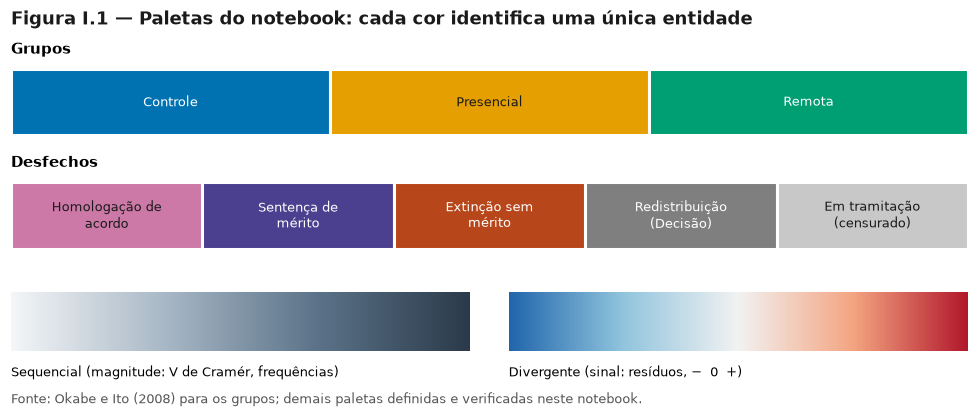

In [4]:
_MACHADO = {
    'protanopia': np.array([[0.152286, 1.052583, -0.204868], [0.114503, 0.786281, 0.099216], [-0.003882, -0.048116, 1.051998]]),
    'deuteranopia': np.array([[0.367322, 0.860646, -0.227968], [0.280085, 0.672501, 0.047413], [-0.011820, 0.042940, 0.968881]]),
}


def _linear(cor):
    c = np.array(mpl.colors.to_rgb(cor))
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)


def _oklab(rgb_linear):
    rgb_linear = np.clip(rgb_linear, 0, 1)
    lms = np.array([[0.4122214708, 0.5363325363, 0.0514459929], [0.2119034982, 0.6806995451, 0.1073969566],
                    [0.0883024619, 0.2817188376, 0.6299787005]]) @ rgb_linear
    return np.array([[0.2104542553, 0.7936177850, -0.0040720468], [1.9779984951, -2.4285922050, 0.4505937099],
                     [0.0259040371, 0.7827717662, -0.8086757660]]) @ np.cbrt(lms)


def delta_e(a, b, simulacao=None):
    """ΔE OKLab (×100) entre duas cores, opcionalmente sob simulação de daltonismo (Machado et al., 2009)."""
    A, B = _linear(a), _linear(b)
    if simulacao:
        A, B = _MACHADO[simulacao] @ A, _MACHADO[simulacao] @ B
    return 100 * float(np.linalg.norm(_oklab(A) - _oklab(B)))


def relatorio_cvd(nome, cores, pares):
    linhas = []
    for a, b in pares:
        d = {'Paleta': nome, 'Par': f'{a} × {b}', 'ΔE normal': delta_e(cores[a], cores[b])}
        for s in _MACHADO:
            d[f'ΔE {s}'] = delta_e(cores[a], cores[b], s)
        linhas.append(d)
    return linhas


_pares_grupo = [(a, b) for i, a in enumerate(ORDEM_GRUPO) for b in ORDEM_GRUPO[i + 1:]]
_pares_desf = list(zip(ORDEM_DESFECHO[:-1], ORDEM_DESFECHO[1:]))           # vizinhos nas barras empilhadas
_cromaticos = ['Homologação', 'Mérito', 'Sem mérito']
_cruzadas = {**{f'grupo {g}': CORES_GRUPO[g] for g in ORDEM_GRUPO}, **{f'desfecho {k}': CORES_DESFECHO[k] for k in _cromaticos}}
_pares_cruz = [(f'grupo {g}', f'desfecho {k}') for g in ORDEM_GRUPO for k in _cromaticos]
cvd = pd.DataFrame(relatorio_cvd('Grupos (todos os pares)', CORES_GRUPO, _pares_grupo)
                   + relatorio_cvd('Desfechos (vizinhos)', CORES_DESFECHO, _pares_desf)
                   + relatorio_cvd('Grupo × desfecho (mesmo gráfico)', _cruzadas, _pares_cruz))
cvd['Pior simulado'] = cvd[['ΔE protanopia', 'ΔE deuteranopia']].min(axis=1)
cvd['Situação'] = np.select([(cvd['Pior simulado'] >= 8) & (cvd['ΔE normal'] >= 15), cvd['Pior simulado'] >= 6],
                            ['passa', 'passa com rótulo/legenda'], 'exige 2º canal (forma, posição)')
resumo_cvd = cvd.groupby('Paleta', sort=False).agg(**{'Pares': ('Par', 'size'), 'Menor ΔE normal': ('ΔE normal', 'min'),
                                                      'Menor ΔE simulado': ('Pior simulado', 'min')})
tabela(resumo_cvd, 'cur_cvd_resumo', 'Distância perceptual mínima entre as cores de cada paleta (ΔE OKLab × 100)',
       secao='1.2.1', casas=1,
       nota='simulação de Machado, Oliveira e Fernandes (2009), severidade 1,0; alvo ≥ 8 sob simulação e ≥ 15 sem simulação. '
            'A linha "grupo × desfecho" é informativa: grupos e desfechos só dividem o mesmo gráfico quando a forma '
            '(linha × marcador) também os distingue.')
_fracos = cvd[cvd['Situação'] != 'passa']
if len(_fracos):
    print('Pares abaixo do alvo (exigem segundo canal):')
    for _, r in _fracos.iterrows():
        print(f"  {r['Par']}: ΔE normal {fmt_br(r['ΔE normal'])}; pior simulado {fmt_br(r['Pior simulado'])} → {r['Situação']}")

# Mapas sequencial e divergente: luminosidade OKLab monotônica
_L = lambda mapa, xs: [_oklab(_linear(mapa(x)))[0] for x in xs]
_seq_L = _L(SEQ, np.linspace(0, 1, 11))
_div_L = _L(DIV, np.linspace(0, 1, 11))
print('Sequencial: luminosidade decrescente (claro → escuro):', all(np.diff(_seq_L) < 0))
print('Divergente: luminosidade cresce até o meio e decresce depois:',
      all(np.diff(_div_L[:6]) > 0) and all(np.diff(_div_L[5:]) < 0))

fig, ax = plt.subplots(3, 1, figsize=(9, 3.4), gridspec_kw={'height_ratios': [1, 1, 0.8]})
for a, (nome, cores_) in zip(ax[:2], [('Grupos', {g: CORES_GRUPO[g] for g in ORDEM_GRUPO}),
                                       ('Desfechos', {ROTULO_DESFECHO[k]: CORES_DESFECHO[k] for k in ORDEM_DESFECHO})]):
    for i, (rot, cor) in enumerate(cores_.items()):
        a.barh(0, 1, left=i, color=cor, edgecolor='white', linewidth=2)
        a.text(i + 0.5, 0, quebra(rot, 14), ha='center', va='center', fontsize=8.5, color=_cor_texto(cor))
    a.set_xlim(0, len(cores_)); a.set_axis_off(); a.set_title(nome, loc='left', fontsize=10)
gradiente = np.linspace(0, 1, 256)[None, :]
ax[2].imshow(np.vstack([gradiente, gradiente]), aspect='auto', cmap=SEQ, extent=(0, 0.48, 0, 1))
ax[2].imshow(np.vstack([gradiente, gradiente]), aspect='auto', cmap=DIV, extent=(0.52, 1, 0, 1))
ax[2].set_xlim(0, 1); ax[2].set_axis_off()
ax[2].text(0, -0.25, 'Sequencial (magnitude: V de Cramér, frequências)', fontsize=8.5, va='top', transform=ax[2].transAxes)
ax[2].text(0.52, -0.25, 'Divergente (sinal: resíduos, −  0  +)', fontsize=8.5, va='top', transform=ax[2].transAxes)
figura(fig, 'cur_paletas', 'Paletas do notebook: cada cor identifica uma única entidade', secao='1.2.1',
       fonte='Fonte: Okabe e Ito (2008) para os grupos; demais paletas definidas e verificadas neste notebook.')

---

## 1.3 Formação do dataset bruto

### 1.3.1 As abas da planilha

O arquivo tem oito abas, mas só uma contém dados por processo. As demais são painéis, tabelas dinâmicas e listas de validação construídas **a partir** da aba `Processos`; servem apenas para conferência (seção 1.14).

In [5]:
livro = openpyxl.load_workbook(BRUTO, data_only=False)   # fórmulas, não valores
PAPEL_ABA = {
    'Processos': 'Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica',
    'Dash1': 'Painel (segmentações/gráficos), sem dados',
    'Dash2': 'Painel (segmentações/gráficos), sem dados',
    'Dash3': 'Painel (segmentações/gráficos), sem dados',
    'Tab_D': 'Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)',
    'Tabelas': 'Resumos com fórmulas (acordos, "eficiência" por rito)',
    'Resumo': 'Questionário de perguntas descritivas (valores vazios no cache)',
    'Lista': 'Listas das validações de dados (valores permitidos nas colunas)',
}
abas = pd.DataFrame([{
    'Aba': ws.title,
    'Visibilidade': 'oculta' if ws.sheet_state != 'visible' else 'visível',
    'Intervalo usado': ws.dimensions,
    'Células preenchidas': sum(c.value is not None for linha in ws.iter_rows() for c in linha),
    'Papel': PAPEL_ABA.get(ws.title, ''),
} for ws in livro.worksheets])
tabela(abas, 'cur_abas', 'Abas da planilha e o papel de cada uma: só a aba Processos tem dados por processo', secao='1.3.1')

ws = livro['Processos']
print('Tabela Excel na aba Processos:', {nome: ref for nome, ref in ws.tables.items()})
print('Colunas ocultas:', [c for c, d in ws.column_dimensions.items() if d.hidden])
print('Linha 1 (acima do cabeçalho):', [ws.cell(1, c).value for c in range(1, 16)])

Aba,Visibilidade,Intervalo usado,Células preenchidas,Papel
Processos,visível,A2:O946,13.317,Dados por processo (tabela Excel TAB_DADOS) — única fonte analítica
Dash1,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Dash2,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Dash3,visível,A1:F5,0,"Painel (segmentações/gráficos), sem dados"
Tab_D,oculta,A1:BG144,351,"Tabelas dinâmicas da pesquisadora (médias por grupo, técnica, status)"
Tabelas,visível,A2:AL49,623,"Resumos com fórmulas (acordos, ""eficiência"" por rito)"
Resumo,visível,A2:C25,25,Questionário de perguntas descritivas (valores vazios no cache)
Lista,oculta,A1:I8,26,Listas das validações de dados (valores permitidos nas colunas)


Tabela Excel na aba Processos: {'TAB_DADOS': 'A2:O946'}
Colunas ocultas: ['J', 'M', 'P']
Linha 1 (acima do cabeçalho): [None, None, None, None, None, None, None, None, None, None, None, None, None, None, None]


### 1.3.2 Leitura da aba `Processos`

A linha 1 está vazia e o cabeçalho está na linha 2 (`header=1`). O índice de `dados_brutos` passa a ser o **número da linha no Excel** (`linha_excel`), o que permite rastrear cada tratamento até a célula de origem. `dados_brutos` não é modificado em nenhum momento.

In [6]:
dados_brutos = pd.read_excel(BRUTO, sheet_name='Processos', header=1, engine='openpyxl')
dados_brutos.index = pd.RangeIndex(3, 3 + len(dados_brutos), name='linha_excel')

print(f'{dados_brutos.shape[0]} linhas × {dados_brutos.shape[1]} colunas (linhas 3 a {dados_brutos.index[-1]} do Excel)')
print('Nomes das colunas (repr, para ver espaços):')
print([c for c in dados_brutos.columns])
print(f'Linhas inteiramente vazias: {dados_brutos.isna().all(axis=1).sum()} | '
      f'números de processo distintos: {dados_brutos["NÚMERO DO PROCESSO"].nunique()}')
tabela(dados_brutos.head(5), 'cur_bruto_amostra', 'As cinco primeiras linhas da aba Processos, como lidas (dados brutos, sem tratamento)',
       secao='1.3.2', indice=True, exportar=False, nota='a primeira coluna (linha_excel) é o número da linha no Excel.')

944 linhas × 15 colunas (linhas 3 a 946 do Excel)
Nomes das colunas (repr, para ver espaços):
['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA', 'DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT', 'DURAÇÃO-PROC', ' DURAÇÃO DO PROCESSO', 'STATUS']
Linhas inteiramente vazias: 0 | números de processo distintos: 938


linha_excel,NÚMERO DO PROCESSO,DT. DISTRIBUIÇÃO,SORTEIO,HÍBRIDA,TEVE ACORDO NA AC?,TÉCNICA,TEVE ACORDO FORA DA AC?,SENTENÇA,DT. SENTENÇA,DURAÇÃO-SENT2,DURAÇÃO-TECN,DURAÇÃO-SORT,DURAÇÃO-PROC,DURAÇÃO DO PROCESSO,STATUS
3,0800001-35.2026.8.20.5004,01/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do feito sem julgamento de mérito,07/01/2026,6,–,6,6,6 dia(s),Encerrado
4,0800024-78.2026.8.20.5004,06/01/2026,Rito Atual Ac Opcional,Não,Não,**,–,–,–,274,–,274,274,274 dia(s),Ativo
5,0808292-43.2025.8.20.5300,06/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito sem Julgamento de Mérito,09/01/2026,3,–,3,3,3 dia(s),Encerrado
6,0800038-62.2026.8.20.5004,07/01/2026,Ac Obrigatória Presencial,Não,Sim,Desconstrução da Verdade,Não,Extinção do Feito com Homologação do Acordo,22/02/2026,46,46,46,46,46 dia(s),Encerrado
7,0800035-10.2026.8.20.5004,07/01/2026,Rito Atual Ac Opcional,Não,Não,**,Não,Extinção do Feito com Julgamento de Mérito,27/02/2026,51,–,51,51,51 dia(s),Encerrado


**Leitura.**

- **Uma única aba tem dados.** A aba `Processos` (tabela Excel `TAB_DADOS`, intervalo A2:O946) é a fonte de tudo o que vem depois. As abas `Dash1` a `Dash3` estão vazias de dados (só segmentações e gráficos); `Tab_D` e `Lista` estão **ocultas** e contêm as tabelas dinâmicas e as listas de validação; `Tabelas` e `Resumo` são resumos calculados.
- **944 linhas, não 943.** A aba tem 944 linhas de dados (linhas 3 a 946 do Excel), com **938 números de processo distintos**: há números repetidos (seção 1.10). O enunciado fala em 943 processos porque uma linha (920) não tem as fórmulas de duração e de status (seção 1.4).
- **15 colunas, não 11.** Nove são digitadas pela unidade (A a I); seis são calculadas por fórmula (J a O), três delas ocultas (J, M e a coluna vazia P). O nome de uma coluna começa com espaço (`' DURAÇÃO DO PROCESSO'`), detalhe que quebra qualquer código que a procure pelo nome "limpo".

---

## 1.4 Colunas digitadas × colunas calculadas: a data de corte

As colunas J a O da planilha **não são dados**: são fórmulas. Ler as fórmulas (e não apenas os valores) é essencial, porque a duração dos processos sem sentença é calculada com `TODAY()`, uma função **volátil**: cada vez que o arquivo é aberto, o tempo dos processos ativos aumenta, sem que nenhuma informação nova tenha sido coletada. A célula mostra a fórmula de cada coluna calculada e conta quantas linhas têm fórmula.

In [7]:
COLUNAS_CALCULADAS = {'J': 'DURAÇÃO-SENT2', 'K': 'DURAÇÃO-TECN', 'L': 'DURAÇÃO-SORT', 'M': 'DURAÇÃO-PROC',
                      'N': 'DURAÇÃO DO PROCESSO', 'O': 'STATUS'}
ultima = 2 + len(dados_brutos)
formulas = []
for letra, nome in COLUNAS_CALCULADAS.items():
    valores = [ws[f'{letra}{r}'].value for r in range(3, ultima + 1)]
    com_formula = [isinstance(v, str) and v.startswith('=') for v in valores]
    formulas.append({'Coluna': letra, 'Nome': nome,
                     'Linhas com fórmula': sum(com_formula),
                     'Usa TODAY()': 'TODAY()' in str(valores[0]),
                     'Oculta': ws.column_dimensions[letra].hidden,
                     'Fórmula (linha 3)': valores[0]})
tabela(pd.DataFrame(formulas), 'cur_formulas', 'Colunas calculadas por fórmula (J a O): a duração dos ativos depende de TODAY()',
       secao='1.4')

sem_formula = [r for r in range(3, ultima + 1) if not str(ws[f'M{r}'].value or '').startswith('=')]
print('Linhas sem fórmula na coluna M:', sem_formula)
print('Conteúdo da linha', sem_formula[0], ':', [ws[f'{c}{sem_formula[0]}'].value for c in 'ABCDEFGHI'])

Coluna,Nome,Linhas com fórmula,Usa TODAY(),Oculta,Fórmula (linha 3)
J,DURAÇÃO-SENT2,943,Sim,Sim,"=IF(TAB_DADOS[[#This Row],[SENTENÇA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
K,DURAÇÃO-TECN,943,Sim,Não,"=IF(TAB_DADOS[[#This Row],[TÉCNICA]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
L,DURAÇÃO-SORT,943,Sim,Não,"=IF(TAB_DADOS[[#This Row],[SORTEIO]]=""**"","""",ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3)))))"
M,DURAÇÃO-PROC,943,Sim,Sim,"=ABS(IF(AND(B3="""",I3=""""),"""",IF(AND(B3<>"""",I3<>""""),(I3-B3),(TODAY()-B3))))"
N,DURAÇÃO DO PROCESSO,943,Não,Não,"=IF(TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]="""","""",TAB_DADOS[[#This Row],[DURAÇÃO-PROC]]&"" dia(s)"")"
O,STATUS,943,Não,Não,"=IF(AND(B3="""",I3=""""),"""",IF(AND(NOT(ISBLANK(B3)),NOT(ISBLANK(I3))),""Encerrado"",""Ativo""))"


Linhas sem fórmula na coluna M: [920]
Conteúdo da linha 920 : ['0813782-27.2026.8.20.5004', datetime.datetime(2026, 7, 29, 0, 0), 'Ac Obrigatória Presencial', None, None, None, None, None, None]


Os **valores em cache** (o que o Excel calculou na última gravação e o que o `pandas` lê) revelam a data em que `TODAY()` foi avaliado: para cada processo ativo, `DT. DISTRIBUIÇÃO + DURAÇÃO-PROC` é essa data. Se ela for única, é a data de corte de fato usada pela pesquisadora.

In [8]:
ativos_bruto = dados_brutos['STATUS'].eq('Ativo')
data_referencia = (dados_brutos.loc[ativos_bruto, 'DT. DISTRIBUIÇÃO']
                   + pd.to_timedelta(dados_brutos.loc[ativos_bruto, 'DURAÇÃO-PROC'], unit='D'))
tabela(data_referencia.dt.strftime('%d/%m/%Y').value_counts().rename_axis('Data implícita de TODAY()').rename('Processos ativos').to_frame(),
       'cur_data_today', 'Data em que TODAY() foi avaliado, reconstituída dos valores em cache', secao='1.4')
assert data_referencia.nunique() == 1 and data_referencia.iloc[0] == DATA_CORTE

props = livro.properties
print(f'Última gravação do arquivo: {props.modified} (por {props.lastModifiedBy}); criado em {props.created:%d/%m/%Y}')
print(f'Sentença mais recente: {dados_brutos["DT. SENTENÇA"].max():%d/%m/%Y} | '
      f'distribuição mais recente: {dados_brutos["DT. DISTRIBUIÇÃO"].max():%d/%m/%Y}')
assert dados_brutos['DT. SENTENÇA'].max() <= DATA_CORTE and dados_brutos['DT. DISTRIBUIÇÃO'].max() <= DATA_CORTE

# As quatro durações são a mesma variável (E6): comparação célula a célula onde não nulas
DURACOES = ['DURAÇÃO-SENT2', 'DURAÇÃO-TECN', 'DURAÇÃO-SORT']
iguais = pd.DataFrame([{
    'Coluna': c,
    'Não nulas': int(dados_brutos[c].notna().sum()),
    'Iguais a DURAÇÃO-PROC': int((dados_brutos[c] == dados_brutos['DURAÇÃO-PROC']).sum()),
} for c in DURACOES])
texto_igual = (dados_brutos[' DURAÇÃO DO PROCESSO'].str.extract(r'(\d+)')[0].astype(float)
               == dados_brutos['DURAÇÃO-PROC']).sum()
tabela(iguais, 'cur_duracoes_iguais', 'As colunas de duração repetem DURAÇÃO-PROC (mesma variável, E6)', secao='1.4')
print(f'" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em {texto_igual} linhas')

Data implícita de TODAY(),Processos ativos
07/10/2026,209


Última gravação do arquivo: 2026-10-07 19:57:29 (por pvccr); criado em 28/01/2026
Sentença mais recente: 06/10/2026 | distribuição mais recente: 03/08/2026


Coluna,Não nulas,Iguais a DURAÇÃO-PROC
DURAÇÃO-SENT2,943,943
DURAÇÃO-TECN,428,428
DURAÇÃO-SORT,943,943


" DURAÇÃO DO PROCESSO" (texto "N dia(s)") igual a DURAÇÃO-PROC em 943 linhas


**Leitura. A data de corte é 07/10/2026, e precisa ser fixada.**

- **Todas as durações vêm de uma fórmula com `TODAY()`.** As 943 linhas com fórmula calculam `ABS(DT. SENTENÇA − DT. DISTRIBUIÇÃO)` quando há sentença e `ABS(TODAY() − DT. DISTRIBUIÇÃO)` quando não há.
- **Os 209 processos ativos apontam para uma única data: 07/10/2026.** É o dia da última gravação do arquivo (07/10/2026, 19h57) e o que está no nome do arquivo. A sentença mais recente é de 06/10/2026 e a última distribuição, de 03/08/2026, coerentes com essa data.
- **Por que fixar.** Se a planilha for aberta e recalculada hoje (12/11/2026), cada processo ativo "ganha" 36 dias sem nenhuma informação nova. O tempo é, por isso, recalculado em Python a partir das datas, com `DATA_CORTE = 07/10/2026`. O acompanhamento real vai de **65 dias** (distribuídos em 03/08) a **279 dias** (distribuídos em 01/01). A "janela de 218 dias" usada no notebook do professor não corresponde aos dados (E7).
- **As quatro colunas de duração são a mesma variável.** `DURAÇÃO-SENT2` e `DURAÇÃO-SORT` coincidem com `DURAÇÃO-PROC` nas 943 linhas; `DURAÇÃO-TECN` coincide nas 428 em que existe (é a mesma duração, apagada onde a técnica é `**`); o texto `"N dia(s)"` repete o número. Elas só serviam de filtro para as tabelas dinâmicas. Por isso a matriz de correlação do notebook do professor dá r = 1 em todos os pares (E6, E16): correlaciona uma variável consigo mesma.
- **O `ABS()` da fórmula esconderia datas trocadas** (sentença anterior à distribuição). A verificação direta nas datas (seção 1.14) mostra que não há nenhum caso.

---

## 1.5 Estrutura do dado bruto: o que o pandas leu

O `dtype` atribuído pelo `pandas` na leitura não é o tipo estatístico da variável. A coluna *tipos Python presentes* mostra o que realmente existe em cada coluna (por exemplo, `str` e `float` juntos indicam texto com células vazias, `NaN`).

In [9]:
def tipos_presentes(serie):
    """Tipos Python efetivamente presentes nas células não nulas, com contagem."""
    contagem = Counter(type(v).__name__ for v in serie.dropna())
    return ', '.join(f'{t} ({n})' for t, n in contagem.most_common())


perfil_bruto = pd.DataFrame({
    'dtype lido': dados_brutos.dtypes.astype(str),
    'tipos Python presentes': dados_brutos.apply(tipos_presentes),
    'não nulos': dados_brutos.notna().sum(),
    'NaN': dados_brutos.isna().sum(),
    'distintos': dados_brutos.nunique(),
    'exemplo (linha 3)': dados_brutos.iloc[0].astype(str).str.slice(0, 45),
})
tabela(perfil_bruto.rename_axis('Coluna bruta'), 'cur_perfil_bruto', 'Perfil das colunas como lidas pelo pandas: dtype, tipos presentes e ausências',
       secao='1.5', formatos={'dtype lido': 'texto'})

Coluna bruta,dtype lido,tipos Python presentes,não nulos,NaN,distintos,exemplo (linha 3)
NÚMERO DO PROCESSO,str,str (944),944,0,938,0800001-35.2026.8.20.5004
DT. DISTRIBUIÇÃO,datetime64[us],Timestamp (944),944,0,190,2026-01-01 00:00:00
SORTEIO,str,str (944),944,0,3,Rito Atual Ac Opcional
HÍBRIDA,str,str (872),872,72,2,Não
TEVE ACORDO NA AC?,str,str (869),869,75,2,Não
TÉCNICA,str,str (867),867,77,7,**
TEVE ACORDO FORA DA AC?,str,str (736),736,208,3,Não
SENTENÇA,str,str (734),734,210,5,Extinção do feito sem julgamento de mérito
DT. SENTENÇA,datetime64[us],Timestamp (734),734,210,179,2026-01-07 00:00:00
DURAÇÃO-SENT2,float64,float (943),943,1,189,6.0


---

## 1.6 Tipologia estatística das variáveis

A escolha de gráficos, medidas e testes depende do **tipo estatístico** de cada variável, não do `dtype`. A tabela classifica as colunas da planilha e indica o tipo `pandas` adequado a cada uma no dataset *tidy*:

- **nominal** → `category` (sem ordem); **ordinal** → `category` ordenada;
- **binária** → `boolean` (o tipo anulável do pandas, que aceita `<NA>` sem virar `object`);
- **quantitativa discreta** (contagem de dias) → `Int64` (inteiro anulável);
- **data** → `datetime64`; **identificador** → `string` (não é medida: não se calcula média de número de processo).

Note-se que o tempo em dias é discreto por registro, mas é tratado como **contínuo** nos modelos de sobrevivência (com empates). As colunas J a O são descartadas: são derivadas por fórmula, redundantes entre si e dependentes de `TODAY()`.

In [10]:
TIPOLOGIA_BRUTA = pd.DataFrame([
    ('NÚMERO DO PROCESSO', 'Identificador', '—', 'string', 'Mantida como `processo` (limpa e validada)'),
    ('DT. DISTRIBUIÇÃO', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Origem do tempo; gera mês, dia da semana, ordem'),
    ('SORTEIO', 'Qualitativa nominal (3 níveis)', 'nominal', 'category', 'Tratamento sorteado → `grupo`'),
    ('HÍBRIDA', 'Qualitativa binária', 'nominal', 'boolean', 'Adesão ao protocolo (pós-sorteio)'),
    ('TEVE ACORDO NA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('TÉCNICA', 'Qualitativa nominal (6 níveis + "**")', 'nominal', 'category', '`**` → AC não realizada (`ac_realizada`)'),
    ('TEVE ACORDO FORA DA AC?', 'Qualitativa binária', 'nominal', 'boolean', 'Desfecho secundário'),
    ('SENTENÇA', 'Qualitativa nominal (4 níveis)', 'nominal', 'category', 'Tipo de desfecho; define o evento'),
    ('DT. SENTENÇA', 'Data', 'intervalar (tempo de calendário)', 'datetime64', 'Fim do tempo quando há desfecho'),
    ('DURAÇÃO-SENT2', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-TECN', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: cópia filtrada de DURAÇÃO-PROC'),
    ('DURAÇÃO-SORT', 'Quantitativa discreta (dias)', 'razão', '—', 'Descartada: fórmula, cópia de DURAÇÃO-PROC'),
    ('DURAÇÃO-PROC', 'Quantitativa discreta (dias)', 'razão', 'Int64', 'Recalculada pelas datas → `tempo` (com censura)'),
    (' DURAÇÃO DO PROCESSO', 'Texto ("N dia(s)")', '—', '—', 'Descartada: DURAÇÃO-PROC em texto'),
    ('STATUS', 'Qualitativa binária', 'nominal', 'boolean', 'Recalculada pela data → `encerrado`'),
], columns=['Coluna bruta', 'Tipo estatístico', 'Escala de medida', 'dtype adequado', 'Decisão'])
TIPOLOGIA_BRUTA.insert(1, 'dtype lido', TIPOLOGIA_BRUTA['Coluna bruta'].map(dados_brutos.dtypes.astype(str)))
tabela(TIPOLOGIA_BRUTA, 'cur_tipologia', 'Tipologia estatística das colunas da planilha e decisão de tratamento', secao='1.6')

Coluna bruta,dtype lido,Tipo estatístico,Escala de medida,dtype adequado,Decisão
NÚMERO DO PROCESSO,str,Identificador,—,string,Mantida como `processo` (limpa e validada)
DT. DISTRIBUIÇÃO,datetime64[us],Data,intervalar (tempo de calendário),datetime64,"Origem do tempo; gera mês, dia da semana, ordem"
SORTEIO,str,Qualitativa nominal (3 níveis),nominal,category,Tratamento sorteado → `grupo`
HÍBRIDA,str,Qualitativa binária,nominal,boolean,Adesão ao protocolo (pós-sorteio)
TEVE ACORDO NA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
TÉCNICA,str,"Qualitativa nominal (6 níveis + ""**"")",nominal,category,`**` → AC não realizada (`ac_realizada`)
TEVE ACORDO FORA DA AC?,str,Qualitativa binária,nominal,boolean,Desfecho secundário
SENTENÇA,str,Qualitativa nominal (4 níveis),nominal,category,Tipo de desfecho; define o evento
DT. SENTENÇA,datetime64[us],Data,intervalar (tempo de calendário),datetime64,Fim do tempo quando há desfecho
DURAÇÃO-SENT2,float64,Quantitativa discreta (dias),razão,—,"Descartada: fórmula, cópia de DURAÇÃO-PROC"


---

## 1.7 Ausências: `NaN`, `**` e células em branco

A planilha tem **três formas** de "não há valor", que não significam a mesma coisa e não podem ser fundidas:

| Forma | Significado | Exemplo |
|---|---|---|
| `NaN` (célula vazia) | **ainda não informado**: o processo não chegou àquela etapa (quase sempre em tramitação) | `SENTENÇA` vazia num processo ativo |
| `**` | **não se aplica**: a etapa não existe para aquele processo (zero estrutural) | `TÉCNICA = **` no Controle, que não tem audiência |
| texto vazio/espaços | erro de digitação | — |

O notebook do professor tratou `**` como categoria nos gráficos de Pareto e, no Controle, leu "Não" como resposta, quando a pergunta não se aplica (E4, E5).

In [11]:
COLUNAS_DIGITADAS = ['NÚMERO DO PROCESSO', 'DT. DISTRIBUIÇÃO', 'SORTEIO', 'HÍBRIDA', 'TEVE ACORDO NA AC?',
                     'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA', 'DT. SENTENÇA']


def resumo_ausencias(df, colunas):
    linhas = []
    for c in colunas:
        s = df[c]
        texto = s.dropna().astype(str)
        linhas.append({'Coluna': c, 'NaN': int(s.isna().sum()), '"**"': int(texto.eq('**').sum()),
                       'Vazio/espaços': int(texto.str.strip().eq('').sum()),
                       'Válidos': int(s.notna().sum() - texto.eq('**').sum() - texto.str.strip().eq('').sum())})
    return pd.DataFrame(linhas).set_index('Coluna')


tabela(resumo_ausencias(dados_brutos, COLUNAS_DIGITADAS), 'cur_ausencias', 'Três formas de ausência por coluna digitada (linhas da planilha)',
       secao='1.7', nota='NaN = não informado; "**" = não se aplica (zero estrutural).')

Coluna,NaN,"""**""",Vazio/espaços,Válidos
NÚMERO DO PROCESSO,0,0,0,944
DT. DISTRIBUIÇÃO,0,0,0,944
SORTEIO,0,0,0,944
HÍBRIDA,72,0,0,872
TEVE ACORDO NA AC?,75,0,0,869
TÉCNICA,77,515,0,352
TEVE ACORDO FORA DA AC?,208,1,0,735
SENTENÇA,210,0,0,734
DT. SENTENÇA,210,0,0,734


### 1.7.1 Padrões de ausência

Se as ausências dependem da **etapa** do processo, elas aparecem em blocos: quem ainda não teve audiência não tem acordo na AC, técnica, acordo fora nem sentença. A tabela codifica, para cinco colunas, `1` = `NaN` e `0` = preenchido, e cruza o padrão com o status e o grupo sorteado.

In [12]:
COLUNAS_PADRAO = ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']
padrao = dados_brutos[COLUNAS_PADRAO].isna().astype(int).astype(str).agg(''.join, axis=1).rename('padrão')
tabela_padrao = pd.concat([
    pd.crosstab(padrao, dados_brutos['STATUS'].fillna('(vazio)')),
    pd.crosstab(padrao, dados_brutos['SORTEIO']),
], axis=1)
tabela_padrao['Total'] = padrao.value_counts()
tabela_padrao['Linhas (se ≤ 3)'] = padrao.groupby(padrao).apply(
    lambda s: ', '.join(map(str, s.index)) if len(s) <= 3 else '')
tabela(tabela_padrao.sort_values('Total', ascending=False).rename_axis('Padrão (1 = NaN)'), 'cur_padroes_ausencia',
       'Padrões de ausência em cinco colunas, por status e grupo sorteado: as lacunas acompanham a etapa do processo',
       secao='1.7.1', formatos={'Padrão (1 = NaN)': 'texto'},
       nota='ordem das posições no padrão: ' + ', '.join(COLUNAS_PADRAO) + '.')
print('Ordem das colunas no padrão:', COLUNAS_PADRAO)

Padrão (1 = NaN),(vazio),Ativo,Encerrado,Ac Obrigatória Presencial,Ac Remota,Rito Atual Ac Opcional,Total,Linhas (se ≤ 3)
00000,0,0,733,240,225,268,733,
00011,0,132,0,50,36,46,132,
11111,1,71,0,24,48,0,72,
01111,0,3,0,1,2,0,3,"268, 369, 832"
00001,0,2,0,0,2,0,2,"566, 607"
00111,0,1,0,0,1,0,1,249
00100,0,0,1,1,0,0,1,373


Ordem das colunas no padrão: ['HÍBRIDA', 'TEVE ACORDO NA AC?', 'TÉCNICA', 'TEVE ACORDO FORA DA AC?', 'SENTENÇA']


O mapa abaixo mostra a mesma informação linha a linha, na ordem de chegada dos processos (eixo vertical). Cinza claro = preenchido; azul-acinzentado claro = `**` (não se aplica); ardósia escura = `NaN` (não informado).

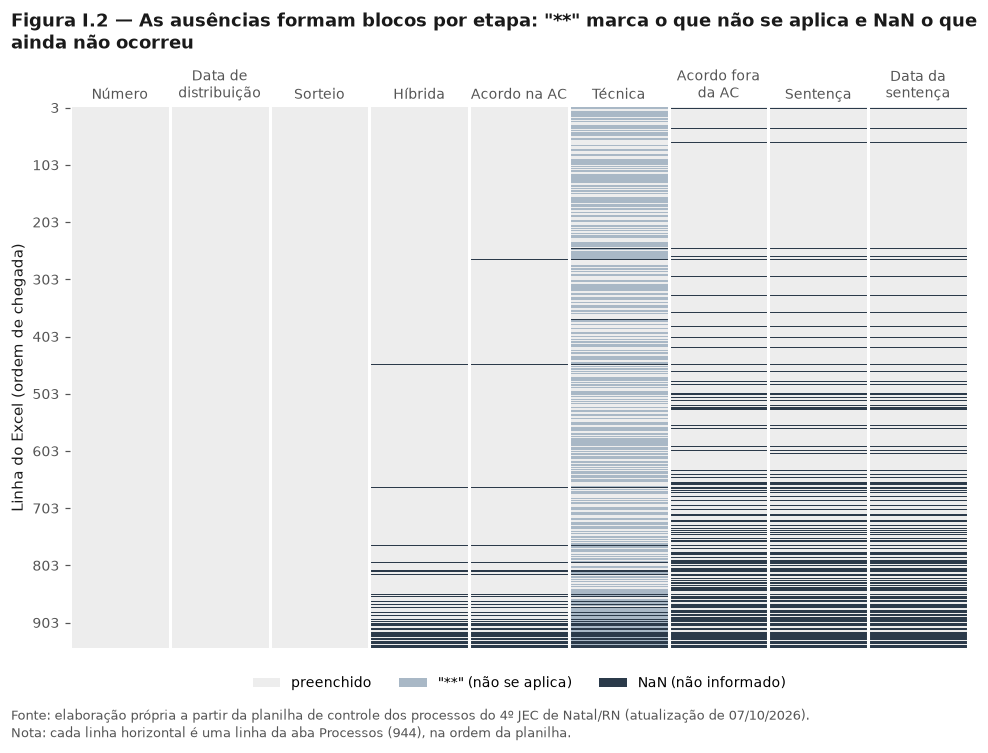

In [13]:
codigo_ausencia = pd.DataFrame({
    c: np.select([dados_brutos[c].isna(), dados_brutos[c].astype(str).eq('**')], [2, 1], 0)
    for c in COLUNAS_DIGITADAS})
CORES_AUSENCIA = ['#EDEDED', '#A9B8C6', '#2B3A4A']   # preenchido, "**", NaN (sem matizes de grupo/desfecho)
fig, ax = plt.subplots(figsize=(9, 6))
mapa = mpl.colors.ListedColormap(CORES_AUSENCIA)
ax.imshow(codigo_ausencia.to_numpy(), aspect='auto', cmap=mapa, interpolation='nearest', vmin=0, vmax=2)
ROTULOS_CURTOS = ['Número', 'Data de distribuição', 'Sorteio', 'Híbrida', 'Acordo na AC', 'Técnica', 'Acordo fora da AC',
                  'Sentença', 'Data da sentença']
ax.set_xticks(range(len(COLUNAS_DIGITADAS)), [quebra(r, 12) for r in ROTULOS_CURTOS])
ax.xaxis.tick_top()
ax.tick_params(axis='x', length=0)
ax.set_yticks(np.arange(0, len(codigo_ausencia), 100), dados_brutos.index[::100])
ax.set_ylabel('Linha do Excel (ordem de chegada)')
ax.grid(False)
for sp_ in ax.spines.values():
    sp_.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(COLUNAS_DIGITADAS)), minor=True)
ax.grid(which='minor', axis='x', color='white', lw=2)
ax.tick_params(which='minor', length=0)
legenda = [mpl.patches.Patch(color=c, label=r) for c, r in
           zip(CORES_AUSENCIA, ['preenchido', '"**" (não se aplica)', 'NaN (não informado)'])]
legenda_abaixo(ax, handles=legenda, ncol=3, dy=-0.03)
figura(fig, 'cur_mapa_ausencias',
       'As ausências formam blocos por etapa: "**" marca o que não se aplica e NaN o que ainda não ocorreu',
       secao='1.7.1', nota='cada linha horizontal é uma linha da aba Processos (944), na ordem da planilha.')

**Leitura. As ausências são estruturais: dependem da etapa em que o processo está.**

- **Não há texto vazio nem espaços soltos**; as ausências são `NaN` (célula vazia) ou o marcador `**`.
- **`**` aparece em duas colunas.** Em `TÉCNICA` (515 linhas) significa que a audiência não foi realizada: todo o Controle e parte dos tratados. Em `ACORDO FORA DA AC?` aparece uma única vez (linha 888), um erro de preenchimento.
- **Os `NaN` formam blocos coerentes com a tramitação:**
  - **733 linhas completas**, todas encerradas;
  - **132 ativos** com audiência já registrada, aguardando o acordo fora e a sentença (padrão `00011`);
  - **72 linhas sem nada após o sorteio** (padrão `11111`): 71 ativos e a linha 920, recém-distribuídos, **todos dos grupos com audiência** (24 Presencial, 48 Remota, 0 Controle). No Controle não há audiência a aguardar, e a unidade já preenche `Não`/`**` na distribuição;
  - **sete linhas com padrões isolados**, listadas na tabela e tratadas nas seções 1.11 e 1.12. A mais relevante é a linha 373: um processo encerrado com a técnica em branco.
- **No mapa, os `NaN` se concentram nas últimas linhas**, as de chegada mais recente. É a assinatura de uma ausência que depende do tempo de acompanhamento, e não de um sorteio ao acaso (não é MCAR).
- **Consequência.** Nenhuma imputação é necessária nem adequada. O desfecho principal (tempo até a sentença) trata a falta de sentença como **censura**. As variáveis de processo (híbrida, técnica, acordo na AC) são analisadas onde se aplicam, com a ausência declarada, e não por exclusão silenciosa de casos incompletos, como fazem os testes do notebook do professor (E5).

---

## 1.8 Cópia de trabalho, nomes das colunas e registro de tratamentos

A partir daqui as transformações acontecem em `trab`, uma cópia de `dados_brutos` com nomes em *snake_case* (minúsculas, sem acento, válidos como identificador Python). As colunas calculadas (J a O) são mantidas na cópia apenas para conferência e descartadas no dataset final.

Cada correção, exclusão ou recodificação é anotada pela função `registrar()` num **log de tratamentos**, com a linha do Excel, o processo, a variável, o valor original, o valor novo, o problema e a justificativa. O código `A`*n* remete ao catálogo de anomalias da auditoria dos dados.

In [14]:
RENOMEAR = {
    'NÚMERO DO PROCESSO': 'numero_bruto', 'DT. DISTRIBUIÇÃO': 'dt_distribuicao', 'SORTEIO': 'sorteio',
    'HÍBRIDA': 'hibrida_bruto', 'TEVE ACORDO NA AC?': 'acordo_ac_bruto', 'TÉCNICA': 'tecnica_bruto',
    'TEVE ACORDO FORA DA AC?': 'acordo_fora_bruto', 'SENTENÇA': 'sentenca_bruto', 'DT. SENTENÇA': 'dt_sentenca',
    'DURAÇÃO-SENT2': 'xl_duracao_sent2', 'DURAÇÃO-TECN': 'xl_duracao_tecn', 'DURAÇÃO-SORT': 'xl_duracao_sort',
    'DURAÇÃO-PROC': 'xl_duracao_proc', ' DURAÇÃO DO PROCESSO': 'xl_duracao_texto', 'STATUS': 'xl_status',
}
trab = dados_brutos.rename(columns=RENOMEAR).copy()
assert set(RENOMEAR) == set(dados_brutos.columns)
assert all(c.isidentifier() and c.isascii() for c in trab.columns)

_registros = []


def registrar(linhas, variavel, valor_novo, problema, tratamento, codigo, valor_original=None):
    """Anota um tratamento para cada linha do Excel informada (valor original lido de dados_brutos)."""
    linhas = [linhas] if np.isscalar(linhas) else list(linhas)
    coluna_bruta = {v: k for k, v in RENOMEAR.items()}.get(variavel)
    for linha in linhas:
        original = valor_original
        if original is None and coluna_bruta is not None:
            original = dados_brutos.at[linha, coluna_bruta]
        _registros.append({'codigo': codigo, 'linha_excel': int(linha),
                           'processo_bruto': dados_brutos.at[linha, 'NÚMERO DO PROCESSO'],
                           'variavel': variavel, 'valor_original': repr(original) if isinstance(original, str) else str(original),
                           'valor_novo': str(valor_novo), 'problema': problema, 'tratamento': tratamento})


def log_tratamentos():
    return pd.DataFrame(_registros)


tabela(pd.DataFrame({'Coluna original': [repr(k) for k in RENOMEAR], 'Nome na cópia de trabalho': list(RENOMEAR.values())}),
       'cur_renomear', 'Nomes das colunas na cópia de trabalho (o repr mostra espaços extras do original)', secao='1.8')

Coluna original,Nome na cópia de trabalho
'NÚMERO DO PROCESSO',numero_bruto
'DT. DISTRIBUIÇÃO',dt_distribuicao
'SORTEIO',sorteio
'HÍBRIDA',hibrida_bruto
'TEVE ACORDO NA AC?',acordo_ac_bruto
'TÉCNICA',tecnica_bruto
'TEVE ACORDO FORA DA AC?',acordo_fora_bruto
'SENTENÇA',sentenca_bruto
'DT. SENTENÇA',dt_sentenca
'DURAÇÃO-SENT2',xl_duracao_sent2


---

## 1.9 Número do processo (CNJ)

O número único segue a Resolução CNJ 65/2008: `NNNNNNN-DD.AAAA.J.TR.OOOO` (sequencial, dígito verificador, ano de ajuizamento, segmento da Justiça, tribunal e órgão de origem). O dígito verificador (DV) é calculado pelo **módulo 97** (ISO 7064): `DD = 98 − (NNNNNNN AAAA J TR OOOO 00 mod 97)`. Validar o DV detecta erros de digitação no número, a chave que permite cruzar a base com o PJe e o DataJud.

A limpeza tem três passos, cada um registrado:

1. remover espaços e quebras de linha nas bordas;
2. remover hífen final digitado por engano;
3. completar o órgão truncado com 3 dígitos, **somente se** o DV confirmar o órgão do estudo (5004 = 4º JEC de Natal).

In [15]:
PADRAO_CNJ = re.compile(r'^(\d{7})-(\d{2})\.(\d{4})\.(\d)\.(\d{2})\.(\d{4})$')


def dv_cnj(sequencial, ano, j, tr, orgao):
    """Dígito verificador CNJ (mod 97, ISO 7064)."""
    return 98 - int(f'{sequencial}{ano}{j}{tr}{orgao}00') % 97


def cnj_valido(numero):
    m = PADRAO_CNJ.fullmatch(str(numero))
    return bool(m) and int(m.group(2)) == dv_cnj(m.group(1), m.group(3), m.group(4), m.group(5), m.group(6))


numero = trab['numero_bruto'].astype('string')
fora = ~numero.map(lambda n: bool(PADRAO_CNJ.fullmatch(n))).astype(bool)
print('Fora do padrão antes da limpeza:', int(fora.sum()), '→ linhas', list(trab.index[fora]))
tabela(numero[fora].map(repr).rename('Valor bruto (repr)').to_frame().rename_axis('Linha do Excel'), 'cur_cnj_fora',
       'Números de processo fora do padrão CNJ antes da limpeza', secao='1.9', formatos={'Linha do Excel': 'texto'})

# Passo 1 — espaços e quebras de linha
passo1 = numero.str.strip()
alterado = trab.index[passo1 != numero]
registrar(alterado, 'numero_bruto', '(sem espaços)', 'Espaço ou quebra de linha no fim do número',
          'strip()', 'A7')

# Passo 2 — hífen final
passo2 = passo1.str.replace(r'\s*-\s*$', '', regex=True)
alterado = trab.index[passo2 != passo1]
registrar(alterado, 'numero_bruto', '(sem hífen final)', 'Hífen digitado após o número', 'Sufixo removido', 'A7')

# Passo 3 — órgão truncado (3 dígitos): candidatos que fecham o DV
truncado = passo2.str.match(r'^\d{7}-\d{2}\.\d{4}\.\d\.\d{2}\.\d{3}$')
candidatos = {}
for linha in trab.index[truncado]:
    seq, dv, ano, j, tr, _ = re.split(r'[-.]', passo2[linha])
    candidatos[linha] = [o for o in range(5000, 5400) if dv_cnj(seq, ano, j, tr, o) == int(dv)]
tabela(pd.DataFrame({'Número truncado': passo2[truncado],
                     'Órgãos 5000–5399 com DV válido': pd.Series(candidatos).map(lambda l: ', '.join(map(str, l)))}
                    ).rename_axis('Linha do Excel'),
       'cur_cnj_truncado', 'Números com órgão truncado: órgãos candidatos que fecham o dígito verificador', secao='1.9',
       formatos={'Linha do Excel': 'texto'})
passo3 = passo2.copy()
for linha, lista in candidatos.items():
    assert 5004 in lista, f'linha {linha}: DV não fecha com 5004'
    passo3[linha] = passo2[linha] + '4'
registrar(list(candidatos), 'numero_bruto', '(órgão 5004)', 'Órgão de origem com 3 dígitos ("500")',
          'Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido', 'A8')

trab['processo'] = passo3
trab['cnj_corrigido'] = trab.index.isin(trab.index[(passo3 != numero.str.strip())])
partes = trab['processo'].str.extract(PADRAO_CNJ)
partes.columns = ['seq', 'dv', 'ano', 'j', 'tr', 'orgao']
trab['dv_valido'] = trab['processo'].map(cnj_valido)
trab['cnj_ano'] = partes['ano'].astype('Int64')
trab['cnj_orgao'] = partes['orgao']
print(f'Após a limpeza: {int(partes["seq"].notna().sum())} no padrão; DV válido em {int(trab["dv_valido"].sum())}; '
      f'J.TR = {sorted((partes["j"] + "." + partes["tr"]).unique())}')
assert trab['dv_valido'].all()

Fora do padrão antes da limpeza: 6 → linhas [55, 377, 443, 453, 692, 771]


Linha do Excel,Valor bruto (repr)
55,'0800780-87.2026.8.20.5004-'
377,'0805750-33.2026.8.20.5004\xa0-'
443,'0806633-77.2026.8.20.500'
453,'0806739-39.2026.8.20.500'
692,'0809702-20.2026.8.20.5004 '
771,'0811548-72.2026.8.20.5004\n'


Linha do Excel,Número truncado,Órgãos 5000–5399 com DV válido
443,0806633-77.2026.8.20.500,"5004, 5101, 5198, 5295, 5392"
453,0806739-39.2026.8.20.500,"5004, 5101, 5198, 5295, 5392"


Após a limpeza: 944 no padrão; DV válido em 944; J.TR = ['8.20']


### 1.9.1 Processos de outro órgão ou de ano anterior

O órgão `5004` é o 4º JEC de Natal e o ano esperado é 2026. Números de outro órgão ou de ano anterior indicam processos **ajuizados em outra unidade e redistribuídos** ao 4º JEC: a "data de distribuição" da planilha é a data de chegada à vara, não a do ajuizamento. Eles são mantidos (entraram no sorteio quando chegaram, e o relógio do estudo começa ali), marcados com `origem_externa` para análise de sensibilidade.

In [16]:
trab['origem_externa'] = trab['cnj_orgao'].ne('5004') | trab['cnj_ano'].lt(2026)
tabela(pd.crosstab([trab['cnj_ano'].astype(str).rename('Ano (CNJ)'), trab['cnj_orgao'].rename('Órgão (CNJ)')],
                   trab['sorteio'], margins=True, margins_name='Total'),
       'cur_cnj_orgao_ano', 'Ano e órgão de origem do número CNJ por grupo sorteado (linhas da planilha)', secao='1.9.1', indice=True)
registrar(trab.index[trab['origem_externa']], 'numero_bruto', 'origem_externa=True',
          'Número de outro órgão ou de ano anterior (processo redistribuído à vara)',
          'Mantido; flag origem_externa para sensibilidade', 'A9', valor_original='(órgão/ano)')
print(f'origem_externa: {int(trab["origem_externa"].sum())} linhas')

origem_externa: 12 linhas


---

## 1.10 Duplicidades e reentradas

A unidade experimental é o **processo**: cada um deve aparecer uma vez, com o grupo do seu sorteio. Depois da limpeza do número, há processos com mais de uma linha. A tabela mostra todos, para que a regra de decisão seja verificável:

In [17]:
duplicados = trab[trab['processo'].duplicated(keep=False)].sort_values(['processo', 'dt_distribuicao'])
tabela(duplicados[['processo', 'dt_distribuicao', 'sorteio', 'tecnica_bruto', 'sentenca_bruto', 'dt_sentenca', 'xl_status']]
       .rename_axis('Linha do Excel').rename(columns={'processo': 'Processo', 'dt_distribuicao': 'Distribuição', 'sorteio': 'Sorteio',
                                                       'tecnica_bruto': 'Técnica', 'sentenca_bruto': 'Sentença',
                                                       'dt_sentenca': 'Data da sentença', 'xl_status': 'STATUS'}),
       'cur_duplicados', 'Números de processo repetidos: reentradas após redistribuição, às vezes sorteadas para outro grupo',
       secao='1.10', formatos={'Linha do Excel': 'texto', 'Processo': 'texto'})
print(f'{duplicados["processo"].nunique()} números repetidos em {len(duplicados)} linhas; '
      f'{trab["processo"].nunique()} processos distintos')

Linha do Excel,Processo,Distribuição,Sorteio,Técnica,Sentença,Data da sentença,STATUS
162,0802424-65.2026.8.20.5004,13/02/2026,Ac Obrigatória Presencial,**,Decisão,18/02/2026,Encerrado
164,0802424-65.2026.8.20.5004,13/02/2026,Ac Obrigatória Presencial,–,–,–,Ativo
290,0804436-52.2026.8.20.5004,18/03/2026,Ac Obrigatória Presencial,**,Decisão,18/03/2026,Encerrado
322,0804436-52.2026.8.20.5004,24/03/2026,Ac Obrigatória Presencial,**,Decisão,09/04/2026,Encerrado
475,0804436-52.2026.8.20.5004,27/04/2026,Rito Atual Ac Opcional,**,Decisão,27/04/2026,Encerrado
591,0808905-44.2026.8.20.5004,20/05/2026,Ac Remota,**,Decisão,21/05/2026,Encerrado
607,0808905-44.2026.8.20.5004,22/05/2026,Ac Remota,**,–,–,Ativo
819,0812314-28.2026.8.20.5004,08/07/2026,Ac Remota,–,–,–,Ativo
822,0812314-28.2026.8.20.5004,08/07/2026,Ac Remota,**,Extinção do Feito com Homologação do Acordo,16/09/2026,Encerrado
851,0812839-10.2026.8.20.5004,15/07/2026,Ac Remota,Padrões Objetivos,–,–,Ativo


5 números repetidos em 11 linhas; 938 processos distintos


Há duas situações diferentes:

- **Duplicata de registro** (A3, A4): a segunda linha é uma cópia vazia ou desatualizada do mesmo processo, no mesmo grupo. Mantê-la criaria um **falso censurado** (por exemplo, a linha 164 ficaria "ativa" por 236 dias, embora o processo tenha sido redistribuído em 5 dias). → excluir a cópia e manter o registro mais antigo/completo.
- **Reentrada após `Decisão`** (A5): o processo saiu por redistribuição, voltou à vara e foi **sorteado de novo**; o `0804436-52` passou de Presencial para Controle. Reentradas violam a unicidade da unidade experimental e contaminam os grupos (E3). → na base primária, por **intenção de tratar**, vale só o **primeiro episódio**, com o grupo do primeiro sorteio. As alternativas (excluir o processo; unir os episódios) ficam para a análise de sensibilidade, a partir do arquivo com todas as linhas.

In [18]:
EXCLUIR_PRIMARIA = {
    164: ('A3', 'Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)'),
    819: ('A3', 'Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho'),
    857: ('A4', 'Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo'),
    322: ('A5', 'Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado'),
    475: ('A5', 'Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo'),
    607: ('A5', 'Reentrada de 0808905-44 um dia após a Decisão; re-sorteado'),
}
# Conferência: toda linha excluída tem o mesmo número que uma linha mantida, e esta é anterior ou igual na data
for linha, (codigo, motivo) in EXCLUIR_PRIMARIA.items():
    mesmos = trab.index[trab['processo'].eq(trab.at[linha, 'processo'])]
    mantidas = [m for m in mesmos if m not in EXCLUIR_PRIMARIA]
    assert len(mantidas) == 1 and trab.at[mantidas[0], 'dt_distribuicao'] <= trab.at[linha, 'dt_distribuicao']
    registrar(linha, 'processo', 'excluída da base primária', motivo,
              f'Excluída; mantida a linha {mantidas[0]} (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)',
              codigo, valor_original=trab.at[linha, 'processo'])

trab['base_primaria'] = ~trab.index.isin(list(EXCLUIR_PRIMARIA))
trab['motivo_exclusao'] = pd.Series({k: f'{v[0]}: {v[1]}' for k, v in EXCLUIR_PRIMARIA.items()},
                                    dtype='string').reindex(trab.index)
trab['duplicado_removido'] = trab['processo'].duplicated(keep=False) & trab['base_primaria']
trab['reentrada'] = trab['processo'].duplicated(keep='first')  # 2º episódio em diante (inclui duplicatas)
assert not trab.loc[trab['base_primaria'], 'processo'].duplicated().any()
print('Base primária:', int(trab['base_primaria'].sum()), 'processos')
tabela(pd.crosstab(trab['sorteio'].rename('Sorteio'), trab['base_primaria'].map({True: 'Mantidas', False: 'Excluídas'}),
                   margins=True, margins_name='Total'),
       'cur_base_primaria', 'Linhas mantidas na base primária e excluídas (duplicata/reentrada), por grupo sorteado', secao='1.10')

Base primária: 938 processos


Sorteio,Excluídas,Mantidas,Total
Ac Obrigatória Presencial,2,314,316
Ac Remota,3,311,314
Rito Atual Ac Opcional,1,313,314
Total,6,938,944


**Leitura.**

- **São 5 números repetidos em 11 linhas**, ou seja, 6 linhas a mais que processos. O notebook do professor contou essas 6 linhas extras como "6 duplicatas" e não as tratou (E3).
- **Três são duplicatas de registro** (linhas 164, 819 e 857): cópias vazias ou desatualizadas do mesmo processo, no mesmo grupo. A linha 164, por exemplo, ficaria "em tramitação" por 236 dias, quando o processo foi redistribuído 5 dias depois de chegar (linha 162).
- **Três são reentradas re-sorteadas** (linhas 322, 475 e 607):
  - o processo `0804436-52` saiu por `Decisão` em 18/03, voltou em 24/03 (Presencial, nova Decisão em 09/04) e voltou de novo em 27/04, quando foi sorteado para o **Controle** (nova Decisão no mesmo dia);
  - o `0808905-44` foi redistribuído em 21/05 e voltou no dia 22/05, sorteado de novo.
- **Lição de desenho.** Um processo que sai e volta não deveria passar por novo sorteio: deveria herdar o grupo original.
- **Base primária: 938 processos** (Controle 313, Presencial 314, Remota 311), cada um com o grupo do primeiro sorteio (intenção de tratar). As 944 linhas ficam preservadas em `ed2_todas_linhas.pkl` para as análises de sensibilidade.

---

## 1.11 Categorias: grafia, partições e recodificações

### 1.11.1 Funções de normalização

Uma variável categórica bem construída é uma **partição** dos casos: exaustiva, disjunta, sem classes vazias e sem sinônimos (a mesma categoria com duas grafias). Três funções garantem isso:

- `limpar_texto` colapsa espaços e quebras de linha e converte texto vazio em `<NA>`;
- `normalizar_chave` gera uma chave de comparação sem acento, em maiúsculas e com espaços simples; duas grafias com a mesma chave são **sinônimos**;
- `para_categoria` aplica um **mapa explícito** (valor original → rótulo) e recusa valores não previstos; `verificar_particao` confere as propriedades com `assert`, de modo que um erro interrompe a execução em vez de passar despercebido.

In [19]:
def limpar_texto(serie):
    """Colapsa espaços/quebras de linha e converte vazio em NA (dtype string)."""
    return serie.astype('string').str.replace(r'\s+', ' ', regex=True).str.strip().replace('', pd.NA)


def normalizar_chave(texto):
    """Chave de comparação: sem acentos, maiúscula, espaços simples (não altera o dado)."""
    if pd.isna(texto):
        return pd.NA
    texto = unicodedata.normalize('NFKD', str(texto))
    texto = ''.join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r'\s+', ' ', texto).strip().upper()


def para_categoria(serie, mapa, ordem, ordenada=False):
    """Aplica um mapa exaustivo (valor original → rótulo) e devolve dtype category."""
    sem_mapa = sorted(set(serie.dropna().unique()) - set(mapa))
    assert not sem_mapa, f'Valores sem mapeamento: {sem_mapa}'
    rotulos = serie.map(mapa)
    assert set(rotulos.dropna()) <= set(ordem), 'Há rótulos fora da lista de categorias'
    return pd.Series(pd.Categorical(rotulos, categories=ordem, ordered=ordenada), index=serie.index, name=serie.name)


resumo_particoes = []


def verificar_particao(nova, nome, ausentes_permitidos=0):
    """Confere se uma variável category é partição: exaustiva, sem vazias e sem sinônimos."""
    contagem = nova.value_counts(sort=False, dropna=True)
    chaves = pd.Series(contagem.index.astype(str)).map(normalizar_chave)
    resultado = {'Variável': nome, 'Categorias': len(contagem), 'Vazias': int((contagem == 0).sum()),
                 'NA': int(nova.isna().sum()), 'Sinônimos': int(chaves.duplicated().sum()),
                 'Soma = n': int(contagem.sum() + nova.isna().sum()) == len(nova)}
    resultado['Partição válida'] = (resultado['Vazias'] == 0 and resultado['Sinônimos'] == 0
                                    and resultado['NA'] <= ausentes_permitidos and resultado['Soma = n'])
    assert resultado['Partição válida'], f'{nome} não é partição: {resultado}'
    resumo_particoes.append(resultado)
    return contagem


COLUNAS_TEXTO = ['sorteio', 'hibrida_bruto', 'acordo_ac_bruto', 'tecnica_bruto', 'acordo_fora_bruto', 'sentenca_bruto']
diagnostico = []
for c in COLUNAS_TEXTO:
    original = trab[c].astype('string')
    limpo = limpar_texto(trab[c])
    chaves = original.dropna().map(normalizar_chave)
    diagnostico.append({'Variável': c, 'Valores alterados pela limpeza': int((original != limpo).sum()),
                        'Grafias distintas': original.nunique(), 'Chaves distintas': chaves.nunique()})
    trab[c] = limpo
tabela(pd.DataFrame(diagnostico), 'cur_grafias', 'Grafias distintas e chaves normalizadas por coluna categórica', secao='1.11.1')

Variável,Valores alterados pela limpeza,Grafias distintas,Chaves distintas
sorteio,0,3,3
hibrida_bruto,0,2,2
acordo_ac_bruto,0,2,2
tecnica_bruto,0,7,7
acordo_fora_bruto,0,3,3
sentenca_bruto,0,5,4


### 1.11.2 Tipo de sentença: uma variante de caixa e o significado de "Decisão"

`SENTENÇA` tem cinco grafias, mas só quatro chaves: `Extinção do feito sem julgamento de mérito` (minúsculas, 11 casos de janeiro) é a mesma categoria que `Extinção do Feito sem Julgamento de Mérito`. A validação de lista do Excel não distingue maiúsculas, por isso a variante passou.

`Decisão` **não é sentença**. Segundo o pesquisador, é a decisão que remete o processo para redistribuição a outro juízo, por prevenção: o processo **sai da vara** e o seu desfecho deixa de ser observado. Contá-la como sentença, como faz o notebook do professor (E10), encurta artificialmente o tempo dos grupos. Aqui ela vira o desfecho `Redistribuição`, tratado como censura na análise principal e como risco competitivo na complementar (Parte IV).

In [20]:
tabela(trab['sentenca_bruto'].value_counts(dropna=False).rename_axis('Grafia').to_frame('Linhas')
       .assign(Chave=lambda t: t.index.map(normalizar_chave)),
       'cur_sentenca_grafias', 'Grafias do tipo de sentença na planilha e chave normalizada', secao='1.11.2')

MAPA_SENTENCA = {
    'Extinção do Feito com Homologação do Acordo': 'Homologação',
    'Extinção do Feito com Julgamento de Mérito': 'Mérito',
    'Extinção do Feito sem Julgamento de Mérito': 'Sem mérito',
    'Extinção do feito sem julgamento de mérito': 'Sem mérito',
    'Decisão': 'Redistribuição',
}
variante = trab['sentenca_bruto'].eq('Extinção do feito sem julgamento de mérito').fillna(False)
registrar(trab.index[variante], 'sentenca_bruto', 'Sem mérito', 'Variante de caixa (minúsculas)',
          'Recodificada para a forma canônica', 'A6')
decisao = trab['sentenca_bruto'].eq('Decisão').fillna(False)
registrar(trab.index[decisao], 'sentenca_bruto', 'Redistribuição',
          '"Decisão" = remessa para redistribuição por prevenção (não é sentença)',
          'Desfecho Redistribuição; evento=0 (censura) e evento_cr=2 (risco competitivo)', 'A-Dec')

desfecho = trab['sentenca_bruto'].map(MAPA_SENTENCA).where(trab['sentenca_bruto'].notna(), 'Ativo')
trab['tipo_desfecho'] = para_categoria(desfecho, {v: v for v in ORDEM_DESFECHO}, ORDEM_DESFECHO)
tabela(pd.crosstab(trab['sentenca_bruto'].fillna('(vazio)').rename('Sentença (planilha)'), trab['tipo_desfecho']),
       'cur_recod_desfecho', 'Recodificação da sentença da planilha no tipo de desfecho', secao='1.11.2')

Grafia,Linhas,Chave
Extinção do Feito com Julgamento de Mérito,341,EXTINCAO DO FEITO COM JULGAMENTO DE MERITO
Extinção do Feito sem Julgamento de Mérito,275,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO
–,210,–
Extinção do Feito com Homologação do Acordo,81,EXTINCAO DO FEITO COM HOMOLOGACAO DO ACORDO
Decisão,26,DECISAO
Extinção do feito sem julgamento de mérito,11,EXTINCAO DO FEITO SEM JULGAMENTO DE MERITO


Sentença (planilha),Homologação,Mérito,Sem mérito,Redistribuição,Ativo
(vazio),0,0,0,0,210
Decisão,0,0,0,26,0
Extinção do Feito com Homologação do Acordo,81,0,0,0,0
Extinção do Feito com Julgamento de Mérito,0,341,0,0,0
Extinção do Feito sem Julgamento de Mérito,0,0,275,0,0
Extinção do feito sem julgamento de mérito,0,0,11,0,0


### 1.11.3 Grupo sorteado

Os rótulos longos da planilha passam a códigos curtos (`Controle`, `Presencial`, `Remota`), com `Controle` como **categoria de referência** (primeira posição). O rótulo descritivo fica em `grupo_rotulo`, para tabelas e legendas.

In [21]:
MAPA_GRUPO = {'Rito Atual Ac Opcional': 'Controle', 'Ac Obrigatória Presencial': 'Presencial', 'Ac Remota': 'Remota'}
trab['grupo'] = para_categoria(trab['sorteio'], MAPA_GRUPO, ORDEM_GRUPO)
trab['grupo_rotulo'] = para_categoria(trab['grupo'].astype('string'), ROTULO_GRUPO, list(ROTULO_GRUPO.values()))
tabela(pd.crosstab(trab['sorteio'].rename('Sorteio (planilha)'), trab['grupo']), 'cur_recod_grupo',
       'Recodificação do grupo sorteado', secao='1.11.3')

Sorteio (planilha),Controle,Presencial,Remota
Ac Obrigatória Presencial,0,316,0
Ac Remota,0,0,314
Rito Atual Ac Opcional,314,0,0


### 1.11.4 Respostas Sim/Não, o `**` em "acordo fora" e a técnica

- **`HÍBRIDA`, `TEVE ACORDO NA AC?`, `TEVE ACORDO FORA DA AC?`** → `boolean` (`Sim` = True, `Não` = False, `NaN` = `<NA>`).
- **`**` em "acordo fora" (linha 888, A10):** processo extinto sem mérito em 8 dias, sem homologação → `False`.
- **`TÉCNICA`:** `**` significa que a AC **não foi realizada** (todo o Controle e parte dos tratados); vira `ac_realizada = False` e `tecnica = <NA>`. `NaN` significa "ainda não informado" (processos ativos sem audiência) → `ac_realizada = <NA>`. Essa separação é a que o notebook do professor não fez (E4).
- **Linha 373 (A11):** processo Presencial **encerrado** sem mérito em 1 dia, com técnica vazia; não houve AC → `**`.
- **Linha 249 (A14):** processo Remota ativo com "acordo na AC = Não" e técnica vazia; mantido `<NA>` (não se imputa).

In [22]:
SIM_NAO = {'Sim': True, 'Não': False}
for bruto, novo in [('hibrida_bruto', 'hibrida'), ('acordo_ac_bruto', 'acordo_ac'), ('acordo_fora_bruto', 'acordo_fora')]:
    valores = trab[bruto]
    if bruto == 'acordo_fora_bruto':
        estrela = valores.eq('**').fillna(False)
        registrar(trab.index[estrela], bruto, False, '"**" em acordo fora da AC (desfecho sem mérito, sem homologação)',
                  'Recodificado para Não (False)', 'A10')
        valores = valores.mask(estrela, 'Não')
    assert set(valores.dropna().unique()) <= set(SIM_NAO), (bruto, valores.unique())
    trab[novo] = valores.map(SIM_NAO).astype('boolean')

tecnica = trab['tecnica_bruto'].copy()
linha_373 = trab.index[tecnica.isna() & trab['tipo_desfecho'].ne('Ativo')]
assert list(linha_373) == [373]
registrar(linha_373, 'tecnica_bruto', '**', 'Técnica vazia em processo encerrado (sem mérito em 1 dia)',
          'Recodificada para "**" (AC não realizada)', 'A11')
tecnica[linha_373] = '**'
registrar(249, 'tecnica_bruto', '<NA>', 'Processo ativo com acordo na AC = Não e técnica vazia',
          'Mantido NA (não imputado)', 'A14')

trab['ac_realizada'] = pd.Series(np.where(tecnica.isna(), pd.NA, tecnica.ne('**')), index=trab.index).astype('boolean')
ORDEM_TECNICA = ['Desconstrução da Verdade', 'Parafraseamento', 'Separação de Pessoas e Problemas',
                 'Padrões Objetivos', 'Teoria do Afago ou do Reforço Positivo',
                 'Análise da Comunicação Verbal e Não-Verbal das Partes']
CURTA_TECNICA = dict(zip(ORDEM_TECNICA, ['Desconstrução', 'Parafraseamento', 'Separação', 'Padrões objetivos',
                                         'Afago', 'Comunicação']))
trab['tecnica'] = para_categoria(tecnica.where(tecnica.ne('**')), {t: t for t in ORDEM_TECNICA}, ORDEM_TECNICA)
trab['tecnica_curta'] = para_categoria(trab['tecnica'].astype('string'), CURTA_TECNICA, list(CURTA_TECNICA.values()))

# Acordo em qualquer momento: lógica de Kleene (True se houve algum; False só se ambos False)
trab['acordo'] = trab['acordo_ac'] | trab['acordo_fora']

_sn = lambda s: s.map({True: 'Sim', False: 'Não'}).astype(object).fillna('<NA>')
tabela(pd.crosstab(trab['tecnica_bruto'].fillna('(NaN)').rename('Técnica (planilha)'),
                   _sn(trab['ac_realizada']).rename('AC realizada'), margins=True, margins_name='Total'),
       'cur_tecnica_ac', 'Técnica registrada × AC realizada: "**" indica que a audiência não ocorreu', secao='1.11.4')
tabela(pd.crosstab([_sn(trab['acordo_ac']).rename('Acordo na AC'), _sn(trab['acordo_fora']).rename('Acordo fora da AC')],
                   trab['tipo_desfecho']),
       'cur_acordos_desfecho', 'Acordo na AC e fora dela × tipo de desfecho', secao='1.11.4', indice=True)

Técnica (planilha),,Não,Sim,Total
(NaN),76,1,0,77
**,0,515,0,515
Análise da Comunicação Verbal e Não-Verbal das Partes,0,0,63,63
Desconstrução da Verdade,0,0,47,47
Padrões Objetivos,0,0,67,67
Parafraseamento,0,0,57,57
Separação de Pessoas e Problemas,0,0,60,60
Teoria do Afago ou do Reforço Positivo,0,0,58,58
Total,76,516,352,944


**Leitura.**

- **Uma só variante de grafia.** Nas seis colunas categóricas, a limpeza de espaços não alterou nenhum valor, e só `SENTENÇA` tem duas grafias para a mesma chave: 11 sentenças de janeiro escritas em minúsculas, unificadas na categoria `Sem mérito` (275 + 11 = **286**). As demais (grupo, híbrida, acordos, técnica) não têm sinônimos.
- **Desfechos nas 944 linhas:** 341 de mérito, 286 sem mérito, 81 homologações de acordo, 26 redistribuições (`Decisão`) e 210 sem desfecho.
- **Técnica e audiência.** 352 linhas têm técnica registrada (AC realizada), 516 têm `**` (as 515 originais mais a linha 373) e 76 seguem `<NA>`, por não haver ainda informação. As seis técnicas aparecem entre 47 (Desconstrução) e 67 (Padrões objetivos) vezes; o "53,85% de padrões objetivos" do resumo expandido não se reproduz nesta versão dos dados.
- **Acordo e sentença são perfeitamente coerentes.** As 81 homologações correspondem exatamente a 17 acordos na AC e 64 fora dela. Não há acordo marcado sem homologação, nem homologação sem acordo, nem acordo nos dois momentos. Por isso `acordo` (qualquer momento) é igual a "sentença homologatória" sempre que é conhecido.
- **`<NA>` nos acordos só ocorre em processos ativos:** 75 sem nenhuma das duas respostas e 133 com "Não" na AC e o acordo fora ainda em aberto. Para um processo em tramitação, "ainda não houve acordo" não é "não houve acordo", e a variável não é preenchida com `False`.

---

## 1.12 Desvios de protocolo e coerência do desenho

O protocolo define o que é possível em cada grupo. Três verificações:

- **Controle sem audiência (A18):** o grupo de rito atual não deveria ter AC, técnica nem acordo na AC. Se isso se confirma, o contraste real do experimento é "**com AC obrigatória × sem AC**".
- **Híbrida na Remota (A12):** por definição do pesquisador, a híbrida é uma AC *presencial* em que uma parte participou à distância (Res. CNJ 481). Uma híbrida no grupo Remota é incongruente.
- **Híbrida sem AC (A13):** marcar "híbrida = Sim" pressupõe que a audiência ocorreu; com técnica `**`, há contradição.

Os casos são **mantidos no grupo sorteado** (análise por intenção de tratar, ITT) e marcados com `desvio_protocolo` para a análise "conforme tratado". A variável `hibrida` é, ela mesma, **pós-sorteio** (decorre do pedido da parte): é adesão parcial ao rito presencial, não um quarto grupo aleatorizado (E11).

In [23]:
coerencia_grupo = pd.DataFrame({
    'AC realizada': trab.groupby('grupo', observed=True)['ac_realizada'].sum(),
    'Técnica registrada': trab.groupby('grupo', observed=True)['tecnica'].count(),
    'Acordo na AC': trab.groupby('grupo', observed=True)['acordo_ac'].sum(),
    'Acordo fora da AC': trab.groupby('grupo', observed=True)['acordo_fora'].sum(),
    'Híbrida = Sim': trab.groupby('grupo', observed=True)['hibrida'].sum(),
    'Linhas': trab.groupby('grupo', observed=True).size(),
})
tabela(coerencia_grupo, 'cur_coerencia', 'Coerência entre o grupo sorteado e o que ocorreu: o Controle não tem AC (zeros estruturais)',
       secao='1.12')
assert coerencia_grupo.loc['Controle', ['AC realizada', 'Técnica registrada', 'Acordo na AC', 'Híbrida = Sim']].eq(0).all()

trab['hibrida_remota'] = (trab['hibrida'].fillna(False) & trab['grupo'].eq('Remota')).astype(bool)
trab['hibrida_sem_ac'] = (trab['hibrida'].fillna(False) & trab['ac_realizada'].eq(False).fillna(False)).astype(bool)
trab['desvio_protocolo'] = trab['hibrida_remota'] | trab['hibrida_sem_ac']
registrar(trab.index[trab['hibrida_remota']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Audiência híbrida no grupo Remota (protocolo prevê híbrida só na presencial)',
          'Mantido no grupo sorteado (ITT); flag hibrida_remota', 'A12')
registrar(trab.index[trab['hibrida_sem_ac']], 'hibrida_bruto', 'desvio_protocolo=True',
          'Híbrida = Sim com técnica "**" (AC não realizada): contraditório',
          'Mantido; flag hibrida_sem_ac; consultar a pesquisadora', 'A13')
tabela(trab.loc[trab['desvio_protocolo'], ['processo', 'grupo', 'hibrida', 'tecnica_bruto', 'tipo_desfecho',
                                           'hibrida_remota', 'hibrida_sem_ac']].rename_axis('Linha do Excel'),
       'cur_desvios', 'Processos com desvio de protocolo (marcados para análise de sensibilidade)', secao='1.12',
       formatos={'Linha do Excel': 'texto', 'processo': 'texto'})

grupo,AC realizada,Técnica registrada,Acordo na AC,Acordo fora da AC,Híbrida = Sim,Linhas
Controle,0,0,0,21,0,314
Presencial,178,178,9,16,28,316
Remota,174,174,8,27,3,314


Linha do Excel,processo,grupo,hibrida,tecnica_bruto,tipo_desfecho,hibrida_remota,hibrida_sem_ac
318,0804822-82.2026.8.20.5004,Remota,Sim,Separação de Pessoas e Problemas,Mérito,Sim,Não
433,0806545-39.2026.8.20.5004,Presencial,Sim,**,Sem mérito,Não,Sim
455,0806829-47.2026.8.20.5004,Presencial,Sim,**,Homologação,Não,Sim
456,0806797-42.2026.8.20.5004,Remota,Sim,Teoria do Afago ou do Reforço Positivo,Ativo,Sim,Não
712,0810564-88.2026.8.20.5004,Presencial,Sim,**,Sem mérito,Não,Sim
832,0812493-59.2026.8.20.5004,Remota,Sim,–,Ativo,Sim,Não


### 1.12.1 As redistribuições (`Decisão`)

Quando ocorrem as redistribuições? Se quase todas acontecem nos primeiros dias, antes de qualquer audiência, o processo saiu do estudo antes de poder receber o tratamento.

In [24]:
redist = trab[trab['tipo_desfecho'].eq('Redistribuição')].copy()
redist['dias'] = (redist['dt_sentenca'] - redist['dt_distribuicao']).dt.days
print(f'{len(redist)} redistribuições (todas as linhas); na base primária: {int(redist["base_primaria"].sum())}')
tabela(redist.groupby('grupo', observed=True)['dias'].describe()[['count', 'min', '50%', 'mean', 'max']]
       .rename(columns={'count': 'n', 'min': 'Mínimo (dias)', '50%': 'Mediana (dias)', 'mean': 'Média (dias)', 'max': 'Máximo (dias)'})
       .rename_axis('Grupo'),
       'cur_redistribuicoes', 'Dias da distribuição até a Decisão de redistribuição, por grupo (todas as linhas)',
       secao='1.12.1', casas=1)
tabela(redist.loc[redist['ac_realizada'].fillna(False), ['processo', 'grupo', 'tecnica', 'dias']]
       .rename(columns={'processo': 'Processo', 'grupo': 'Grupo', 'tecnica': 'Técnica', 'dias': 'Dias até a Decisão'}),
       'cur_redist_com_ac', 'Redistribuições ocorridas depois de uma AC realizada', secao='1.12.1',
       indice=False, formatos={'Processo': 'texto'})

26 redistribuições (todas as linhas); na base primária: 24


Grupo,n,Mínimo (dias),Mediana (dias),Média (dias),Máximo (dias)
Controle,6,0,1,"4,2",20
Presencial,11,0,1,"3,0",16
Remota,9,1,8,"25,4",84


Processo,Grupo,Técnica,Dias até a Decisão
0805907-06.2026.8.20.5004,Remota,Teoria do Afago ou do Reforço Positivo,84
0808552-04.2026.8.20.5004,Remota,Padrões Objetivos,74


**Leitura.**

- **O Controle não teve nenhuma audiência.** São 0 audiências, 0 técnicas, 0 acordos na AC e 0 híbridas em 314 processos. O contraste real do experimento é, portanto, "**AC obrigatória × nenhuma AC**", e não "AC obrigatória × AC opcional". O acordo fora da audiência existe nos três grupos (21 no Controle, 16 na Presencial, 27 na Remota) e é o único desfecho de acordo comparável entre os três.
- **Nem todo tratado teve audiência.** Só 178 dos 316 processos da Presencial (56%) e 174 dos 314 da Remota (55%) têm técnica registrada. Os demais foram extintos antes da audiência (`**`) ou ainda a aguardam (`<NA>`). A análise por intenção de tratar (ITT) compara os **grupos sorteados**, não "quem teve audiência", para não quebrar a aleatorização.
- **Desvios de protocolo em 6 processos, todos mantidos no grupo sorteado e sinalizados:**
  - 3 híbridas no grupo **Remota** (linhas 318, 456 e 832), quando a híbrida, por definição, é uma variação da audiência presencial;
  - 3 híbridas na Presencial com técnica `**` (linhas 433, 455 e 712), o que é contraditório. Uma delas (455) terminou em homologação.
- **A híbrida é adesão parcial, não tratamento.** Ela ocorreu em 28 processos da Presencial, a pedido da parte, e não foi sorteada. Uma comparação "híbrida × presencial" é observacional.
- **As redistribuições são quase sempre imediatas.** A mediana é de 1 dia no Controle e na Presencial e de 8 dias na Remota. Só 2 ocorreram depois da audiência: as linhas 395 (84 dias) e 571 (74 dias), ambas da Remota, que puxam a média desse grupo para 25,4 dias. Em geral, o processo sai da vara antes que o tratamento possa agir, e por isso a `Decisão` é censura ou risco competitivo, nunca sentença (E10).

---

## 1.13 O dataset *tidy*: tempo, evento e variáveis derivadas

### 1.13.1 Tempo e evento

A análise de sobrevivência precisa de dois números por processo:

- **`tempo`** — dias corridos da distribuição até o desfecho (`dt_sentenca`), ou até a **data de corte** (07/10/2026) se não houve desfecho. É recalculado pelas datas; as colunas de duração do Excel não são usadas (A1, A17);
- **`evento`** — `1` se o processo foi **sentenciado** (mérito, sem mérito ou homologação de acordo); `0` se está **censurado**: em tramitação na data de corte ou **redistribuído** (sai da vara no dia da Decisão, sem sentença observada).

Duas codificações complementares:

- **`evento_cr`** (riscos competitivos): `0` = censurado (ativo), `1` = sentença, `2` = redistribuição;
- **`causa`** (desfecho específico): `0` = censurado, `1` = homologação, `2` = mérito, `3` = sem mérito, `4` = redistribuição. Permite estudar, por exemplo, o tempo até a homologação de acordo, que é onde a conciliação atua diretamente.

Há processos com tempo **zero** (desfecho no próprio dia da distribuição). Kaplan-Meier e Cox os aceitam; os modelos paramétricos (AFT) exigem tempo positivo, por isso `tempo_pos` substitui 0 por 0,5 dia (convenção documentada, não imputação; A15).

O **acompanhamento** (`followup`) é o tempo entre a distribuição e a data de corte: o máximo que cada processo poderia ser observado. Como a entrada é escalonada (janeiro a agosto), o acompanhamento varia de 65 a 279 dias, e é por isso que a média simples dos tempos, sem tratar a censura, não é um estimador válido (E7, E14).

In [25]:
CODIGO_CAUSA = {'Ativo': 0, 'Homologação': 1, 'Mérito': 2, 'Sem mérito': 3, 'Redistribuição': 4}
CODIGO_CR = {'Ativo': 0, 'Homologação': 1, 'Mérito': 1, 'Sem mérito': 1, 'Redistribuição': 2}
SENTENCAS = ['Homologação', 'Mérito', 'Sem mérito']

fim = trab['dt_sentenca'].fillna(DATA_CORTE)
trab['tempo'] = (fim - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_pos'] = trab['tempo'].astype('float64').mask(trab['tempo'].eq(0), 0.5)
trab['evento'] = trab['tipo_desfecho'].isin(SENTENCAS).astype('Int64')
trab['evento_cr'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CR).astype('Int64')
trab['causa'] = trab['tipo_desfecho'].astype('string').map(CODIGO_CAUSA).astype('Int64')
trab['encerrado'] = trab['dt_sentenca'].notna().astype('boolean')
trab['followup'] = (DATA_CORTE - trab['dt_distribuicao']).dt.days.astype('Int64')
trab['tempo_zero'] = trab['tempo'].eq(0).astype('boolean')
trab['sem_formula_excel'] = trab['xl_duracao_proc'].isna().astype('boolean')

registrar(trab.index[trab['tipo_desfecho'].eq('Ativo')], 'xl_duracao_proc', 'tempo = 07/10/2026 − distribuição',
          'Duração dos ativos calculada com TODAY() (volátil)', 'Censurado em DATA_CORTE fixa; evento=0', 'A1')
registrar(trab.index[trab['sem_formula_excel']], 'xl_duracao_proc', 'tempo = 70; evento = 0',
          'Linha sem nenhuma fórmula (STATUS vazio)', 'Mantida: ativo censurado em 07/10/2026 (data de distribuição válida)', 'A2')
registrar(trab.index[trab['tempo_zero']], 'tempo', 'tempo=0; tempo_pos=0,5',
          'Desfecho no próprio dia da distribuição', 'Mantido; tempo_pos=0,5 só para modelos paramétricos', 'A15',
          valor_original='0')

# Conferência com a coluna DURAÇÃO-PROC do Excel (valores em cache)
confere = trab['tempo'].astype('float64').eq(trab['xl_duracao_proc'])
print(f'tempo recalculado = DURAÇÃO-PROC do Excel em {int(confere.sum())} de {len(trab)} linhas; '
      f'divergentes: {list(trab.index[~confere])} (sem fórmula no Excel)')

tempo recalculado = DURAÇÃO-PROC do Excel em 943 de 944 linhas; divergentes: [920] (sem fórmula no Excel)


### 1.13.2 Variáveis de calendário e ordem de chegada

Segundo o pesquisador, o sorteio "seguiu rigorosamente a ordem de chegada" dos processos, e as linhas da planilha estão nessa ordem (a data de distribuição nunca decresce de uma linha para a seguinte). Derivam-se:

- **`ordem_chegada`** — posição do processo na sequência de chegada da base primária (1 = primeiro); variável **ordinal**, usada na questão 2.7;
- **`dia_estudo`** — dias desde 01/01/2026 (tempo de calendário da entrada, quantitativo);
- **`mes_distribuicao`** — mês de entrada (ordinal); como a censura depende do mês de entrada, é a covariável natural de estratificação;
- **`ciclo`** — os "dois ciclos" do resumo expandido: 01/01–28/04 e 29/04–03/08/2026;
- **`dia_semana_distribuicao`** e **`sentenca_fim_semana`** — sentenças em sábado ou domingo sugerem que a data registrada pode ser a de **lançamento** no sistema (ou de mutirão), não a da assinatura (A16).

In [26]:
assert trab['dt_distribuicao'].is_monotonic_increasing, 'linhas fora da ordem cronológica'
DIAS = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
MESES = {1: 'jan', 2: 'fev', 3: 'mar', 4: 'abr', 5: 'mai', 6: 'jun', 7: 'jul', 8: 'ago'}

trab['dia_estudo'] = (trab['dt_distribuicao'] - DATA_INICIO).dt.days.astype('Int64')
trab['mes_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.month.map(MESES),
                                          categories=list(MESES.values()), ordered=True)
trab['ciclo'] = pd.Categorical(np.where(trab['dt_distribuicao'] <= pd.Timestamp('2026-04-28'), '1º ciclo', '2º ciclo'),
                               categories=['1º ciclo', '2º ciclo'], ordered=True)
trab['dia_semana_distribuicao'] = pd.Categorical(trab['dt_distribuicao'].dt.dayofweek.map(dict(enumerate(DIAS))),
                                                 categories=DIAS, ordered=True)
trab['sentenca_fim_semana'] = pd.Series(pd.NA, index=trab.index, dtype='boolean')
tem_data = trab['dt_sentenca'].notna()
trab.loc[tem_data, 'sentenca_fim_semana'] = trab.loc[tem_data, 'dt_sentenca'].dt.dayofweek.ge(5)
registrar(trab.index[trab['sentenca_fim_semana'].fillna(False)], 'dt_sentenca', '(mantida)',
          'Sentença datada em sábado ou domingo (possível data de lançamento/lote)',
          'Mantida; flag sentenca_fim_semana; limitação a validar no DataJud', 'A16', valor_original='(fim de semana)')

trab['ordem_chegada'] = pd.Series(pd.NA, index=trab.index, dtype='Int64')
trab.loc[trab['base_primaria'], 'ordem_chegada'] = np.arange(1, int(trab['base_primaria'].sum()) + 1)
print('Sentenças em fim de semana:', int(trab['sentenca_fim_semana'].sum()), 'de', int(tem_data.sum()))
tabela(trab.loc[tem_data].groupby(trab['dt_sentenca'].dt.dayofweek.map(dict(enumerate(DIAS))))
       .size().reindex(DIAS).rename('Sentenças').to_frame().T, 'cur_sentenca_dia_semana',
       'Sentenças por dia da semana da data registrada', secao='1.13.2', indice=False)

Sentenças em fim de semana: 135 de 734


seg,ter,qua,qui,sex,sáb,dom
91,186,149,85,88,70,65


### 1.13.3 Montagem e tipos finais

O dataset final tem uma linha por processo e as colunas na ordem: identificação → calendário → tratamento → processo (audiência, acordo) → desfecho e tempo → *flags* de qualidade. São produzidos dois objetos:

- **`dados_todas`** — as 944 linhas, com `base_primaria` e `motivo_exclusao` (para as análises de sensibilidade);
- **`dados`** — a **base primária** (`base_primaria == True`), usada em todo o restante do notebook.

In [27]:
COLUNAS_TIDY = [
    'processo', 'linha_excel', 'ordem_chegada',
    'dt_distribuicao', 'dia_estudo', 'mes_distribuicao', 'ciclo', 'dia_semana_distribuicao',
    'grupo', 'grupo_rotulo',
    'ac_realizada', 'tecnica', 'tecnica_curta', 'hibrida', 'acordo_ac', 'acordo_fora', 'acordo',
    'tipo_desfecho', 'dt_sentenca', 'encerrado', 'tempo', 'tempo_pos', 'evento', 'evento_cr', 'causa', 'followup',
    'cnj_ano', 'cnj_orgao', 'cnj_corrigido', 'origem_externa', 'duplicado_removido', 'sem_formula_excel',
    'sentenca_fim_semana', 'tempo_zero', 'hibrida_remota', 'hibrida_sem_ac', 'desvio_protocolo',
]
dados_todas = trab.reset_index()[COLUNAS_TIDY + ['base_primaria', 'motivo_exclusao', 'reentrada']].copy()
TIPOS = {
    'processo': 'string', 'linha_excel': 'Int64', 'dt_distribuicao': 'datetime64[ns]',
    'dt_sentenca': 'datetime64[ns]', 'cnj_orgao': 'category',
    'cnj_corrigido': 'boolean', 'origem_externa': 'boolean', 'duplicado_removido': 'boolean',
    'hibrida_remota': 'boolean', 'hibrida_sem_ac': 'boolean', 'desvio_protocolo': 'boolean',
    'base_primaria': 'boolean', 'reentrada': 'boolean', 'motivo_exclusao': 'string',
}
dados_todas = dados_todas.astype(TIPOS)
dados = dados_todas.loc[dados_todas['base_primaria'], COLUNAS_TIDY].reset_index(drop=True)

print(f'dados_todas: {dados_todas.shape} | dados (base primária): {dados.shape}')
tabela(dados.dtypes.astype(str).rename('dtype').rename_axis('Variável').to_frame(), 'cur_dtypes_tidy',
       'Tipos finais das variáveis do dataset tidy', secao='1.13.3', formatos={'dtype': 'texto'})
tabela(dados.head(5), 'cur_tidy_amostra', 'As cinco primeiras linhas do dataset tidy (base primária)', secao='1.13.3',
       exportar=False, indice=False)

dados_todas: (944, 40) | dados (base primária): (938, 37)


Variável,dtype
processo,string
linha_excel,Int64
ordem_chegada,Int64
dt_distribuicao,datetime64[ns]
dia_estudo,Int64
mes_distribuicao,category
ciclo,category
dia_semana_distribuicao,category
grupo,category
grupo_rotulo,category


processo,linha_excel,ordem_chegada,dt_distribuicao,dia_estudo,mes_distribuicao,ciclo,dia_semana_distribuicao,grupo,grupo_rotulo,ac_realizada,tecnica,tecnica_curta,hibrida,acordo_ac,acordo_fora,acordo,tipo_desfecho,dt_sentenca,encerrado,tempo,tempo_pos,evento,evento_cr,causa,followup,cnj_ano,cnj_orgao,cnj_corrigido,origem_externa,duplicado_removido,sem_formula_excel,sentenca_fim_semana,tempo_zero,hibrida_remota,hibrida_sem_ac,desvio_protocolo
0800001-35.2026.8.20.5004,3,1,01/01/2026,0,jan,1º ciclo,qui,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Sem mérito,07/01/2026,Sim,6,6,1,1,3,279,2.026,5004,Não,Não,Não,Não,Não,Não,Não,Não,Não
0800024-78.2026.8.20.5004,4,2,06/01/2026,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,–,–,Ativo,–,Não,274,274,0,0,0,274,2.026,5004,Não,Não,Não,Não,–,Não,Não,Não,Não
0808292-43.2025.8.20.5300,5,3,06/01/2026,5,jan,1º ciclo,ter,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Sem mérito,09/01/2026,Sim,3,3,1,1,3,274,2.025,5300,Não,Sim,Não,Não,Não,Não,Não,Não,Não
0800038-62.2026.8.20.5004,6,4,07/01/2026,6,jan,1º ciclo,qua,Presencial,AC presencial obrigatória,Sim,Desconstrução da Verdade,Desconstrução,Não,Sim,Não,Sim,Homologação,22/02/2026,Sim,46,46,1,1,1,273,2.026,5004,Não,Não,Não,Não,Sim,Não,Não,Não,Não
0800035-10.2026.8.20.5004,7,5,07/01/2026,6,jan,1º ciclo,qua,Controle,"Controle (rito atual, AC opcional)",Não,–,–,Não,Não,Não,Não,Mérito,27/02/2026,Sim,51,51,1,1,2,273,2.026,5004,Não,Não,Não,Não,Não,Não,Não,Não,Não


---

## 1.14 Verificações

### 1.14.1 Asserções de integridade

Cada propriedade que as análises seguintes pressupõem é verificada com `assert`: se alguma falhar, a execução para aqui. Entre elas: unicidade do processo, tempos não negativos e nunca maiores que o acompanhamento, coerência entre `evento`, `evento_cr`, `causa`, `tipo_desfecho` e a data da sentença, e as partições das variáveis categóricas.

In [28]:
n = len(dados)
assert n == 938 and dados['processo'].is_unique
assert dados['grupo'].value_counts().to_dict() == {'Controle': 313, 'Presencial': 314, 'Remota': 311}
assert dados['tempo'].notna().all() and (dados['tempo'] >= 0).all()
assert (dados['tempo'] <= dados['followup']).all() and (dados['followup'] >= 65).all()
assert (dados['dt_sentenca'].dropna() >= dados.loc[dados['dt_sentenca'].notna(), 'dt_distribuicao']).all()
# evento e desfecho
assert (dados['evento'].eq(1) == dados['tipo_desfecho'].isin(SENTENCAS)).all()
assert (dados['evento_cr'].eq(0) == dados['tipo_desfecho'].eq('Ativo')).all()
assert (dados['evento_cr'].eq(2) == dados['tipo_desfecho'].eq('Redistribuição')).all()
assert (dados['encerrado'] == dados['dt_sentenca'].notna()).all()
assert (dados['encerrado'] == dados['evento_cr'].ne(0)).all()
assert (dados.loc[dados['evento_cr'].eq(0), 'tempo'] == dados.loc[dados['evento_cr'].eq(0), 'followup']).all()
assert (dados['causa'].map({0: 'Ativo', 1: 'Homologação', 2: 'Mérito', 3: 'Sem mérito', 4: 'Redistribuição'})
        == dados['tipo_desfecho'].astype(str)).all()
# acordo e audiência
assert (dados['acordo'].fillna(False) == dados['tipo_desfecho'].eq('Homologação')).all()
assert not (dados['acordo_ac'].fillna(False) & dados['acordo_fora'].fillna(False)).any()
assert not dados.loc[dados['grupo'].eq('Controle'), 'ac_realizada'].fillna(False).any()
assert (dados['tecnica'].notna() == dados['ac_realizada'].fillna(False)).all()
assert not (dados['acordo_ac'].fillna(False) & ~dados['ac_realizada'].fillna(False)).any()
# ordem e calendário
assert dados['ordem_chegada'].tolist() == list(range(1, n + 1))
assert dados['dt_distribuicao'].between(DATA_INICIO, FIM_RECRUTAMENTO).all()

for coluna, na in [('grupo', 0), ('grupo_rotulo', 0), ('tipo_desfecho', 0), ('mes_distribuicao', 0),
                   ('ciclo', 0), ('dia_semana_distribuicao', 0), ('tecnica', n), ('tecnica_curta', n)]:
    verificar_particao(dados[coluna], coluna, ausentes_permitidos=na)
tabela(pd.DataFrame(resumo_particoes), 'cur_particoes', 'Verificação das partições: cada variável categórica cobre todos os processos',
       secao='1.14.1')
print('Todas as verificações passaram.')

Variável,Categorias,Vazias,NA,Sinônimos,Soma = n,Partição válida
grupo,3,0,0,0,Sim,Sim
grupo_rotulo,3,0,0,0,Sim,Sim
tipo_desfecho,5,0,0,0,Sim,Sim
mes_distribuicao,8,0,0,0,Sim,Sim
ciclo,2,0,0,0,Sim,Sim
dia_semana_distribuicao,7,0,0,0,Sim,Sim
tecnica,6,0,586,0,Sim,Sim
tecnica_curta,6,0,586,0,Sim,Sim


Todas as verificações passaram.


### 1.14.2 Fluxo dos processos e composição dos desfechos

À maneira de um diagrama CONSORT, a tabela acompanha os processos desde as linhas da planilha até a base primária e a situação na data de corte, por grupo.

In [29]:
def contar(df, grupo):
    sub = df[df['grupo'].eq(grupo)] if grupo != 'Total' else df
    return sub


fluxo = {}
for g in ORDEM_GRUPO + ['Total']:
    todas = contar(dados_todas, g)
    prim = contar(dados, g)
    fluxo[g] = {
        'Linhas na planilha': len(todas),
        'Excluídas (duplicata/reentrada)': int((~todas['base_primaria']).sum()),
        'Base primária': len(prim),
        'Sentença — homologação de acordo': int(prim['causa'].eq(1).sum()),
        'Sentença — mérito': int(prim['causa'].eq(2).sum()),
        'Sentença — sem mérito': int(prim['causa'].eq(3).sum()),
        'Eventos (sentenças)': int(prim['evento'].sum()),
        'Redistribuição (censura / risco competitivo)': int(prim['evento_cr'].eq(2).sum()),
        'Em tramitação em 07/10/2026 (censurado)': int(prim['evento_cr'].eq(0).sum()),
        'Acompanhamento mediano (dias)': fmt_br(float(prim['followup'].median()), 1),
        'origem_externa': int(prim['origem_externa'].sum()),
        'desvio_protocolo': int(prim['desvio_protocolo'].sum()),
    }
fluxo = pd.DataFrame(fluxo).astype(object)
tabela(fluxo.rename_axis('Etapa'), 'cur_fluxo', 'Fluxo dos processos, da planilha à situação em 07/10/2026, por grupo',
       secao='1.14.2', formatos={c: 'texto' for c in fluxo.columns})
assert fluxo.loc['Base primária', 'Total'] == (fluxo.loc['Eventos (sentenças)', 'Total']
                                               + fluxo.loc['Redistribuição (censura / risco competitivo)', 'Total']
                                               + fluxo.loc['Em tramitação em 07/10/2026 (censurado)', 'Total'])

Etapa,Controle,Presencial,Remota,Total
Linhas na planilha,314,316,314,944
Excluídas (duplicata/reentrada),1,2,3,6
Base primária,313,314,311,938
Sentença — homologação de acordo,21,25,35,81
Sentença — mérito,162,96,83,341
Sentença — sem mérito,79,109,98,286
Eventos (sentenças),262,230,216,708
Redistribuição (censura / risco competitivo),5,10,9,24
Em tramitação em 07/10/2026 (censurado),46,74,86,206
Acompanhamento mediano (dias),"170,0","162,0","161,0","164,0"


### 1.14.3 Conferência com os números da pesquisadora

As abas `Tab_D` e `Tabelas` e o resumo expandido trazem contagens que podem ser refeitas com o dataset *tidy*. A conferência usa **todas as 944 linhas** (como a pesquisadora) e mostra, ao lado, o valor na base primária. Diferenças em relação ao resumo expandido refletem a data da versão (o texto usou uma extração anterior, com mais processos ativos).

In [30]:
t = dados_todas
conf = pd.DataFrame([
    ('Processos (linhas com STATUS)', '943 (Tab_D)', int(t['linha_excel'].ne(920).sum()), n),
    ('Encerrados (STATUS)', '734 (Tab_D)', int(t['encerrado'].sum()), int(dados['encerrado'].sum())),
    ('Ativos (STATUS preenchido; a base primária inclui a linha 920)', '209 (Tab_D)',
     int((~t['encerrado'] & ~t['sem_formula_excel']).sum()), int((~dados['encerrado']).sum())),
    ('Acordos (homologações)', '81 (Tabelas)', int(t['acordo'].fillna(False).sum()), int(dados['acordo'].fillna(False).sum())),
    ('Acordos na AC — P / R / O', '9 / 8 / 0 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_ac'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Acordos fora da AC — P / R / O', '16 / 27 / 21 (Tabelas)',
     ' / '.join(str(int(t.loc[t['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle']),
     ' / '.join(str(int(dados.loc[dados['grupo'].eq(g), 'acordo_fora'].sum())) for g in ['Presencial', 'Remota', 'Controle'])),
    ('Sentenciados / ativos (resumo expandido)', '668 / 275 (DOCX)',
     f'{int(t["evento"].sum())} / {int(t["evento_cr"].eq(0).sum())}', f'{int(dados["evento"].sum())} / {int(dados["evento_cr"].eq(0).sum())}'),
], columns=['Indicador', 'Pesquisadora', 'Recalculado (944 linhas)', 'Base primária (938)'])
tabela(conf.astype(str), 'cur_conferencia', 'Conferência com os números divulgados pela pesquisadora', secao='1.14.3')

Indicador,Pesquisadora,Recalculado (944 linhas),Base primária (938)
Processos (linhas com STATUS),943 (Tab_D),943,938
Encerrados (STATUS),734 (Tab_D),734,732
Ativos (STATUS preenchido; a base primária inclui a linha 920),209 (Tab_D),209,206
Acordos (homologações),81 (Tabelas),81,81
Acordos na AC — P / R / O,9 / 8 / 0 (Tabelas),9 / 8 / 0,9 / 8 / 0
Acordos fora da AC — P / R / O,16 / 27 / 21 (Tabelas),16 / 27 / 21,16 / 27 / 21
Sentenciados / ativos (resumo expandido),668 / 275 (DOCX),708 / 210,708 / 206


**Leitura.**

- **Todas as asserções passaram.** Isso garante, entre outros pontos:
  - um processo por linha;
  - nenhum tempo negativo (portanto, o `ABS()` do Excel não escondia nada);
  - nenhum tempo maior que o acompanhamento;
  - acompanhamento mínimo de 65 dias;
  - `evento`, `evento_cr`, `causa`, `tipo_desfecho`, `encerrado` e a data da sentença mutuamente coerentes;
  - nenhuma audiência no Controle.

  As oito variáveis categóricas formam partições válidas.
- **Base primária: 938 processos, com 708 sentenças (eventos), 24 redistribuições e 206 em tramitação em 07/10/2026.**

| Grupo | n | Homologação | Mérito | Sem mérito | Redistribuição | Em tramitação |
|---|---|---|---|---|---|---|
| Controle | 313 | 21 | 162 | 79 | 5 | 46 |
| Presencial | 314 | 25 | 96 | 109 | 10 | 74 |
| Remota | 311 | 35 | 83 | 98 | 9 | 86 |

- **A censura é desigual entre os grupos:** 46 processos em tramitação no Controle, 74 na Presencial e 86 na Remota. O acompanhamento mediano é parecido (170, 162 e 161 dias), mas uma censura desigual invalida a comparação de **médias simples** dos tempos, como as do resumo expandido e do notebook do professor. Exige métodos de sobrevivência (Parte IV).
- **Os perfis de desfecho já sugerem diferenças.** O Controle tem mais sentenças de mérito (162) e os grupos com audiência têm mais extinções sem mérito (109 e 98) e mais homologações (25 e 35). É um retrato descritivo, que a Parte III testa formalmente.
- **Os números da pesquisadora são reproduzidos exatamente** com as 944 linhas: 943 com status, 734 encerrados, 209 ativos, 81 acordos, acordos na AC 9 / 8 / 0 e fora da AC 16 / 27 / 21 (P / R / O). Os valores do resumo expandido (668 sentenciados e 275 ativos) não se reproduzem nesta versão da planilha: o texto usou uma extração anterior, com menos desfechos registrados.

---

## 1.15 Log de tratamentos

O log reúne, linha a linha, todas as intervenções feitas sobre os dados brutos. O resumo por código mostra o alcance de cada tratamento; o log completo é exportado em `dat/processado/ed2_log_tratamentos.csv`.

In [31]:
log = log_tratamentos()
resumo_log = (log.groupby(['codigo', 'problema', 'tratamento'], sort=False)
              .agg(linhas=('linha_excel', 'size'),
                   exemplos=('linha_excel', lambda s: ', '.join(map(str, s.head(6))) + (' …' if len(s) > 6 else '')))
              .reset_index())
tabela(resumo_log, 'cur_log_resumo', 'Resumo do log de tratamentos por anomalia e ação', secao='1.15')
print(f'{len(log)} registros no log, {log["linha_excel"].nunique()} linhas distintas do Excel afetadas')

codigo,problema,tratamento,linhas,exemplos
A7,Espaço ou quebra de linha no fim do número,strip(),2,"692, 771"
A7,Hífen digitado após o número,Sufixo removido,2,"55, 377"
A8,"Órgão de origem com 3 dígitos (""500"")",Completado para 5004: DV confere e é a vara do estudo; flag cnj_corrigido,2,"443, 453"
A9,Número de outro órgão ou de ano anterior (processo redistribuído à vara),Mantido; flag origem_externa para sensibilidade,12,"5, 21, 49, 184, 215, 234 …"
A3,"Duplicata de 162: mesma data e grupo, linha vazia (falso censurado)","Excluída; mantida a linha 162 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,164
A3,"Duplicata de 822: mesma data e grupo, registro desatualizado sem desfecho","Excluída; mantida a linha 822 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,819
A4,"Duplicata de 851 (dia seguinte, mesmo grupo); mantido o registro mais antigo e completo","Excluída; mantida a linha 851 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,857
A5,Reentrada (2º episódio) de 0804436-52 após Decisão; re-sorteado,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,322
A5,Reentrada (3º episódio) de 0804436-52 após Decisão; re-sorteado para outro grupo,"Excluída; mantida a linha 290 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,475
A5,Reentrada de 0808905-44 um dia após a Decisão; re-sorteado,"Excluída; mantida a linha 591 (ITT: 1 processo = 1 unidade, grupo do 1º sorteio)",1,607


455 registros no log, 428 linhas distintas do Excel afetadas


---

## 1.16 Dicionário de variáveis e exportação

### 1.16.1 Dicionário de variáveis

O dicionário descreve cada coluna do dataset *tidy*: significado, tipo estatístico, `dtype`, regra de construção e valores. É exportado junto com os dados e é a referência para as Partes II a VII.

In [32]:
DICIONARIO = [
    ('processo', 'Número CNJ do processo (limpo e validado pelo DV mod 97)', 'Identificador', 'A (NÚMERO DO PROCESSO)'),
    ('linha_excel', 'Linha da aba Processos de origem (rastreabilidade)', 'Identificador', 'posição na planilha'),
    ('ordem_chegada', 'Posição na sequência de chegada (1 = primeiro) na base primária', 'Qualitativa ordinal', 'ordem das linhas'),
    ('dt_distribuicao', 'Data de distribuição ao 4º JEC (início do tempo; = sorteio)', 'Data', 'B'),
    ('dia_estudo', 'Dias desde 01/01/2026 até a distribuição', 'Quantitativa discreta', 'B − 01/01/2026'),
    ('mes_distribuicao', 'Mês da distribuição (jan a ago/2026)', 'Qualitativa ordinal', 'B'),
    ('ciclo', '1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido', 'Qualitativa ordinal', 'B'),
    ('dia_semana_distribuicao', 'Dia da semana da distribuição', 'Qualitativa ordinal', 'B'),
    ('grupo', 'Grupo sorteado: Controle (referência), Presencial, Remota', 'Qualitativa nominal', 'C (SORTEIO)'),
    ('grupo_rotulo', 'Rótulo descritivo do grupo', 'Qualitativa nominal', 'C'),
    ('ac_realizada', 'Audiência de conciliação realizada (técnica registrada); False se "**"; NA se não informado', 'Binária', 'F'),
    ('tecnica', 'Técnica de conciliação sorteada (6 níveis); NA se não houve AC ou não informado', 'Qualitativa nominal', 'F'),
    ('tecnica_curta', 'Rótulo curto da técnica (para gráficos)', 'Qualitativa nominal', 'F'),
    ('hibrida', 'AC presencial com participação remota de uma parte (Res. CNJ 481); pós-sorteio', 'Binária', 'D'),
    ('acordo_ac', 'Acordo obtido na audiência de conciliação', 'Binária', 'E'),
    ('acordo_fora', 'Acordo obtido fora da audiência (petição das partes)', 'Binária', 'G ("**" → False)'),
    ('acordo', 'Acordo em qualquer momento (acordo_ac OU acordo_fora; lógica de Kleene)', 'Binária', 'E, G'),
    ('tipo_desfecho', 'Homologação, Mérito, Sem mérito, Redistribuição (Decisão) ou Ativo', 'Qualitativa nominal', 'H (variantes unificadas)'),
    ('dt_sentenca', 'Data do desfecho (sentença ou Decisão de redistribuição); NaT se ativo', 'Data', 'I'),
    ('encerrado', 'Saiu da vara até 07/10/2026 (sentença ou redistribuição) = STATUS Encerrado', 'Binária', 'I preenchida'),
    ('tempo', 'Dias da distribuição ao desfecho ou, se ativo, até 07/10/2026', 'Quantitativa discreta (tratada como contínua)', 'I − B ou DATA_CORTE − B'),
    ('tempo_pos', 'tempo com 0 substituído por 0,5 dia (só para modelos paramétricos/AFT)', 'Quantitativa contínua', 'tempo'),
    ('evento', '1 = sentença (homologação, mérito, sem mérito); 0 = censurado (ativo ou redistribuído)', 'Binária (0/1)', 'tipo_desfecho'),
    ('evento_cr', '0 = censurado (ativo), 1 = sentença, 2 = redistribuição (risco competitivo)', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('causa', '0 = censurado, 1 = homologação, 2 = mérito, 3 = sem mérito, 4 = redistribuição', 'Qualitativa nominal (código)', 'tipo_desfecho'),
    ('followup', 'Acompanhamento máximo possível: dias de 07/10/2026 − distribuição', 'Quantitativa discreta', 'DATA_CORTE − B'),
    ('cnj_ano', 'Ano de ajuizamento no número CNJ', 'Quantitativa discreta', 'A'),
    ('cnj_orgao', 'Órgão de origem no número CNJ (5004 = 4º JEC de Natal)', 'Qualitativa nominal', 'A'),
    ('cnj_corrigido', 'Número com hífen final ou órgão truncado corrigido', 'Binária', 'A7/A8'),
    ('origem_externa', 'Órgão ≠ 5004 ou ano < 2026 (processo redistribuído à vara)', 'Binária', 'A9'),
    ('duplicado_removido', 'Registro mantido cujo número tinha outra(s) linha(s), excluída(s) da base primária', 'Binária', 'A3–A5'),
    ('sem_formula_excel', 'Linha sem fórmulas no Excel (linha 920)', 'Binária', 'A2'),
    ('sentenca_fim_semana', 'Desfecho datado em sábado ou domingo; NA se ativo', 'Binária', 'A16'),
    ('tempo_zero', 'Desfecho no próprio dia da distribuição', 'Binária', 'A15'),
    ('hibrida_remota', 'Híbrida = Sim no grupo Remota (incongruente com o protocolo)', 'Binária', 'A12'),
    ('hibrida_sem_ac', 'Híbrida = Sim com técnica "**" (AC não realizada)', 'Binária', 'A13'),
    ('desvio_protocolo', 'hibrida_remota OU hibrida_sem_ac', 'Binária', 'A12/A13'),
]
dicionario = pd.DataFrame(DICIONARIO, columns=['variavel', 'descricao', 'tipo_estatistico', 'origem_regra'])
assert dicionario['variavel'].tolist() == list(dados.columns)
dicionario.insert(2, 'dtype', dicionario['variavel'].map(dados.dtypes.astype(str)))
dicionario['nao_nulos'] = dicionario['variavel'].map(dados.notna().sum())


def valores_resumo(serie):
    if isinstance(serie.dtype, pd.CategoricalDtype):
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts(sort=False).items())[:160]
    if isinstance(serie.dtype, pd.BooleanDtype):
        return f'True: {int(serie.sum())} | False: {int((~serie).sum())} | NA: {int(serie.isna().sum())}'
    if pd.api.types.is_datetime64_any_dtype(serie):
        return f'{serie.min():%d/%m/%Y} a {serie.max():%d/%m/%Y}'
    if pd.api.types.is_numeric_dtype(serie) and serie.nunique() <= 5:
        return ' | '.join(f'{k}: {v}' for k, v in serie.value_counts().sort_index().items())
    if pd.api.types.is_numeric_dtype(serie):
        return f'mín {serie.min()} | mediana {serie.median()} | máx {serie.max()}'
    return f'{serie.nunique()} distintos'


dicionario['valores'] = dicionario['variavel'].map(lambda v: valores_resumo(dados[v]))
tabela(dicionario, 'cur_dicionario', 'Dicionário de variáveis do dataset tidy', secao='1.16.1')

variavel,descricao,dtype,tipo_estatistico,origem_regra,nao_nulos,valores
processo,Número CNJ do processo (limpo e validado pelo DV mod 97),string,Identificador,A (NÚMERO DO PROCESSO),938,938 distintos
linha_excel,Linha da aba Processos de origem (rastreabilidade),Int64,Identificador,posição na planilha,938,mín 3 | mediana 473.5 | máx 946
ordem_chegada,Posição na sequência de chegada (1 = primeiro) na base primária,Int64,Qualitativa ordinal,ordem das linhas,938,mín 1 | mediana 469.5 | máx 938
dt_distribuicao,Data de distribuição ao 4º JEC (início do tempo; = sorteio),datetime64[ns],Data,B,938,01/01/2026 a 03/08/2026
dia_estudo,Dias desde 01/01/2026 até a distribuição,Int64,Quantitativa discreta,B − 01/01/2026,938,mín 0 | mediana 115.0 | máx 214
mes_distribuicao,Mês da distribuição (jan a ago/2026),category,Qualitativa ordinal,B,938,jan: 103 | fev: 106 | mar: 151 | abr: 137 | mai: 146 | jun: 132 | jul: 157 | ago: 6
ciclo,"1º ciclo (01/01–28/04) ou 2º ciclo (29/04–03/08/2026), como no resumo expandido",category,Qualitativa ordinal,B,938,1º ciclo: 485 | 2º ciclo: 453
dia_semana_distribuicao,Dia da semana da distribuição,category,Qualitativa ordinal,B,938,seg: 181 | ter: 181 | qua: 181 | qui: 182 | sex: 157 | sáb: 28 | dom: 28
grupo,"Grupo sorteado: Controle (referência), Presencial, Remota",category,Qualitativa nominal,C (SORTEIO),938,Controle: 313 | Presencial: 314 | Remota: 311
grupo_rotulo,Rótulo descritivo do grupo,category,Qualitativa nominal,C,938,"Controle (rito atual, AC opcional): 313 | AC presencial obrigatória: 314 | AC remota obrigatória: 311"


### 1.16.2 Exportação

Os arquivos vão para `dat/processado/`:

| Arquivo | Conteúdo | Uso |
|---|---|---|
| `ed2_tidy.pkl` | base primária (938), com todos os `dtypes` preservados (`category` ordenada, `boolean`, `Int64`, `datetime64`) | **leitura nas Partes II a VII** |
| `ed2_tidy.csv` | a mesma base, `;` como separador e vírgula decimal (UTF-8 com BOM, abre no Excel) | consulta humana |
| `ed2_todas_linhas.pkl` | as 944 linhas, com `base_primaria`, `motivo_exclusao` e `reentrada` | análises de sensibilidade |
| `ed2_log_tratamentos.csv` | log de tratamentos (seção 1.15) | auditoria |
| `dicionario_variaveis.csv` | dicionário (seção 1.16.1) | documentação |

O formato pickle é usado porque o ambiente não tem `pyarrow` (Parquet). A leitura de volta é conferida.

In [33]:
ARQ_TIDY = PROC / 'ed2_tidy.pkl'
dados.to_pickle(ARQ_TIDY)
dados_todas.to_pickle(PROC / 'ed2_todas_linhas.pkl')
dados.to_csv(PROC / 'ed2_tidy.csv', sep=';', decimal=',', index=False, encoding='utf-8-sig', date_format='%Y-%m-%d')
log.to_csv(PROC / 'ed2_log_tratamentos.csv', sep=';', index=False, encoding='utf-8-sig')
dicionario.to_csv(PROC / 'dicionario_variaveis.csv', sep=';', index=False, encoding='utf-8-sig')

pd.testing.assert_frame_equal(pd.read_pickle(ARQ_TIDY), dados)
pd.testing.assert_frame_equal(pd.read_pickle(PROC / 'ed2_todas_linhas.pkl'), dados_todas)
for arquivo in ['ed2_tidy.pkl', 'ed2_tidy.csv', 'ed2_todas_linhas.pkl', 'ed2_log_tratamentos.csv', 'dicionario_variaveis.csv']:
    print(f'{arquivo:28s} {(PROC / arquivo).stat().st_size / 1024:8,.1f} KiB')

ed2_tidy.pkl                    165.1 KiB


ed2_tidy.csv                    233.0 KiB
ed2_todas_linhas.pkl            172.4 KiB
ed2_log_tratamentos.csv          89.3 KiB
dicionario_variaveis.csv          5.7 KiB


**Síntese da Parte I.**

O dataset analítico (`dados`, 938 processos × 37 variáveis) está pronto e documentado. Os tratamentos aplicados, todos registrados no log (455 registros, 428 linhas do Excel afetadas), foram:

| Código | Tratamento | Linhas |
|---|---|---|
| A1 | Censura dos ativos fixada em 07/10/2026; tempo recalculado pelas datas (a fórmula usava `TODAY()`) | 210 |
| A2 | Linha 920 (sem fórmulas, status vazio) mantida como ativa e censurada (70 dias) | 1 |
| A3/A4 | Duplicatas de registro excluídas da base primária | 3 |
| A5 | Reentradas re-sorteadas excluídas da base primária (vale o 1º sorteio) | 3 |
| A6 | Variante de caixa em `SENTENÇA` unificada | 11 |
| A7/A8 | Número CNJ: espaços, hífen final e órgão truncado (5004, confirmado pelo DV) | 6 |
| A9 | Processos de outro órgão ou ano anterior sinalizados (`origem_externa`) | 12 |
| A10 | `**` em "acordo fora" → Não | 1 |
| A11 | Técnica vazia em processo encerrado → `**` (AC não realizada) | 1 |
| A12/A13 | Híbridas incongruentes sinalizadas (`desvio_protocolo`) | 6 |
| A14 | Ausência mantida sem imputação | 1 |
| A15 | Tempo zero mantido; `tempo_pos` = 0,5 dia só para modelos paramétricos | 39 |
| A16 | Sentenças datadas em fim de semana sinalizadas (possível data de lançamento) | 135 |
| Dec. | `Decisão` = redistribuição: censura (`evento = 0`) ou risco competitivo (`evento_cr = 2`) | 26 |

O número CNJ é válido (DV mod 97) em 100% das linhas. A auditoria preliminar apontava 16 processos de origem externa; a contagem refeita aqui é **12**.

**Como as próximas partes devem usar a base.**

- **Desfecho principal:** `tempo` e `evento`, com `grupo` (referência = Controle).
- **Riscos competitivos:** `evento_cr` (redistribuição como causa concorrente) e `causa` (homologação × mérito × sem mérito).
- **Modelos paramétricos:** `tempo_pos`.
- **Estratificação pela data de entrada**, da qual a censura depende: `mes_distribuicao` ou `ciclo`.
- **Questão 2.7:** `ordem_chegada`.
- **Sensibilidade:** excluir `origem_externa` e `desvio_protocolo`, e usar `ed2_todas_linhas.pkl` para as regras alternativas de duplicidade.

**O que a curadoria não resolve.**

- A data de sentença pode refletir lançamentos em lote (135 sentenças em fins de semana).
- O mecanismo exato do sorteio não está documentado.
- As covariáveis previstas no projeto (tipo de ação, valor da causa, número de partes) não foram coletadas.

# PARTE II — ANÁLISE EXPLORATÓRIA: O TEMPO COMO VARIÁVEL-ALVO

A Parte II descreve os dados antes de qualquer inferência sobre o efeito dos ritos. O fio condutor é a **variável-alvo**: o tempo, em dias, da distribuição à sentença. Ela tem uma particularidade que governa tudo o que vem depois: para 230 dos 938 processos (206 ativos e 24 redistribuídos), o tempo até a sentença **não foi observado**; sabe-se apenas que ele é **maior** do que o tempo já decorrido. Por isso, a exploração separa sempre três coisas:

1. o **tempo observado** de cada processo (sentença, redistribuição ou corte em 07/10/2026);
2. o **indicador de evento** (sentença = 1; censura = 0);
3. as estatísticas **condicionais** aos sentenciados, que são legítimas como descrição desse subconjunto, mas enviesadas para tempos curtos como descrição do "tempo de tramitação".

| Seção | Conteúdo | Papel |
|---|---|---|
| 2.1 | A variável-alvo: tempo, evento e censura; por que as médias da pesquisa são enviesadas; entrada escalonada | definir o que se mede |
| 2.2 | Univariada: frequências de todas as categóricas; descritivas, gráficos, *outliers* e tempos zero | conhecer cada variável |
| 2.3 | Normalidade dos tempos dos sentenciados (Shapiro-Wilk, D'Agostino-Pearson, Anderson-Darling, Lilliefors, Jarque-Bera) | justificar métodos não paramétricos |
| 2.4 | Ajuste de distribuições **com censura** (exponencial, Weibull, log-normal, log-logística, gama generalizada, exponencial por partes) | forma do risco; base para os AFT da Parte IV |
| 2.5 | Modelos binomial e multinomial: equilíbrio do sorteio, taxas de acordo, sentenças sem mérito, sorteio das técnicas e sentenças em fim de semana | checar o desenho e as proporções |
| 2.6 | Bivariada: tempo × fatores, tabelas cruzadas, mosaicos, matriz de associação correta e ordem de chegada × tempo | gerar hipóteses para as Partes III a V |
| 2.7 | Síntese exploratória | |

Os testes formais de comparação entre os grupos (qui-quadrado de homogeneidade, Kruskal-Wallis, log-rank etc.) ficam na **Parte III**, e o Kaplan-Meier detalhado, na **Parte IV**. Aqui aparecem apenas os testes que respondem a perguntas **univariadas** (aderência a uma distribuição ou a uma proporção de referência).

In [34]:
if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')

from scipy.special import gammaln
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.stats.multitest import multipletests
from statsmodels.nonparametric.smoothers_lowess import lowess
from statsmodels.graphics.mosaicplot import mosaic
from lifelines import (ExponentialFitter, WeibullFitter, LogNormalFitter, LogLogisticFitter,
                       GeneralizedGammaFitter, PiecewiseExponentialFitter, NelsonAalenFitter)
from lifelines.plotting import qq_plot

# Base de trabalho da Parte II (dados não é alterado)
d2 = dados.copy()
d2['T'] = d2['tempo'].astype(float)          # dias observados (evento ou censura)
d2['E'] = d2['evento'].astype(int)           # 1 = sentença
d2['status'] = np.select([d2['evento_cr'].eq(1), d2['evento_cr'].eq(2)],
                          ['Sentença', 'Redistribuição'], 'Ativo (censurado)')
# ORDEM_STATUS e CORES_STATUS vêm da camada de visualização (seção 1.2)
sent = d2[d2['E'].eq(1)].copy()              # 708 sentenças: amostra CONDICIONAL
print(f'Processos: {len(d2)} | sentenças: {len(sent)} | redistribuições: {(d2.evento_cr == 2).sum()} | '
      f'ativos: {(d2.evento_cr == 0).sum()}')

Processos: 938 | sentenças: 708 | redistribuições: 24 | ativos: 206


## 2.1 A variável-alvo: tempo, evento e censura

### 2.1.1 Definição

Para cada processo *i*, o tempo de interesse é **T*ᵢ*** = dias da distribuição até a sentença (homologatória, de mérito ou sem mérito). O que se observa, porém, é o par (**tᵢ**, **δᵢ**) (COLOSIMO; GIOLO, 2006, p. 6-12; MORETTIN; SINGER, 2021, p. 243-244):

| Situação em 07/10/2026 | n | tᵢ (coluna `tempo`) | δᵢ (`evento`) | O que se sabe de T*ᵢ* |
|---|---|---|---|---|
| Sentenciado | 708 | data da sentença − data da distribuição | 1 | T*ᵢ* = tᵢ |
| Ativo | 206 | 07/10/2026 − data da distribuição | 0 | T*ᵢ* > tᵢ (**censura à direita**) |
| Redistribuído ("Decisão") | 24 | data da decisão − data da distribuição | 0 | nunca terá sentença no 4º JEC (**risco competitivo**; tratado como censura nesta parte e modelado na Parte IV) |

A censura é **administrativa**: o processo não terminou porque o estudo parou de olhar. Como a distribuição vai de 01/01 a 03/08/2026 (**entrada escalonada**), o seguimento máximo possível (`followup` = 07/10/2026 − distribuição) vai de 65 a 279 dias: um processo de julho só pode exibir uma sentença de até ~98 dias.

### 2.1.2 Por que as médias da pesquisa e do notebook do professor são enviesadas

As médias divulgadas são: **78,46 dias** (geral, n = 943) e **77,50 / 80,87 / 77,00** (Presencial / Remota / Rito atual), das abas `Tab_D`/`Resumo` da planilha e do notebook do professor (E7, E14); e **75,2 dias** (geral) e **74,22 / 76,67 / 74,72** (Presencial / Remota / Rito atual) no resumo expandido, que não diz como as calculou. A célula abaixo reconstitui as duas séries a partir das datas, com as 944 linhas brutas (o que a pesquisadora tinha) e com a base primária (938), e compara com outros recortes. Há três estimadores em jogo, e **nenhum estima a duração média real**:

- **média de todos os tempos observados** ("mista"): é o que a fórmula da planilha produz, pois a duração dos ativos é `TODAY() − distribuição`. Mistura durações completas com tempos parciais (limites inferiores) e com redistribuições (que não são sentença); cresce todo dia, mesmo sem nenhuma sentença nova;
- **média dos sentenciados**: exclui justamente os processos mais longos, que ainda não terminaram; muda quando a data de corte muda;
- **média dos sentenciados até uma data anterior**: idem, com ainda menos seguimento.

In [35]:
brutas = pd.read_pickle(PROC / 'ed2_todas_linhas.pkl')


def media_mista(df, corte):
    # Média "da planilha": duração até o desfecho se já houve desfecho até o corte; senão, corte − distribuição
    df = df[df['dt_distribuicao'].le(corte)]
    enc = df['encerrado'].fillna(False).astype(bool) & df['dt_sentenca'].le(corte)
    t = np.where(enc, (df['dt_sentenca'] - df['dt_distribuicao']).dt.days, (corte - df['dt_distribuicao']).dt.days)
    return t.mean(), int(enc.sum()), int((~enc).sum())


CORTE_RESUMO = pd.Timestamp('2026-09-23')   # data em que a média mista reproduz o resumo expandido (ver abaixo)
linhas = []
for g in [None] + ORDEM_GRUPO:
    sub = d2 if g is None else d2[d2['grupo'].eq(g)]
    sub_b = brutas if g is None else brutas[brutas['grupo'].eq(g)]
    linhas.append({
        'Grupo': 'Todos' if g is None else g, 'n (938)': len(sub),
        'Mista, 944 linhas, corte 07/10 (planilha: 78,46)': media_mista(sub_b, DATA_CORTE)[0],
        'Mista, 938, corte 07/10': sub['T'].mean(),
        'Mista, 944 linhas, corte 23/09 (resumo: 75,2)': media_mista(sub_b, CORTE_RESUMO)[0],
        'Só sentenciados até 07/10 (938)': sub.loc[sub['E'].eq(1), 'T'].mean(),
        'Só sentenciados até 03/08 (938)': sub.loc[sub['E'].eq(1) & sub['dt_sentenca'].le(FIM_RECRUTAMENTO), 'T'].mean(),
        'Seguimento máximo mediano (dias)': sub['followup'].median(),
    })
tab_medias = pd.DataFrame(linhas).set_index('Grupo')
tabela(tab_medias, 'exp_medias', 'As "médias" de duração reconstituídas a partir das datas, por grupo e critério (dias)',
       secao='2.1.2', casas=2,
       nota='"mista" = média de todos os tempos observados (sentenças + tempos parciais dos ativos), como na fórmula da '
            'planilha; nenhuma das colunas estima a duração média real, porque todas ignoram ou truncam os censurados.')
print('Divulgado na planilha/notebook do professor: 78,46 | Presencial 77,50 | Remota 80,87 | Rito atual 77,00')
print('Divulgado no resumo expandido:               75,2  | Presencial 74,22 | Remota 76,67 | Rito atual 74,72')
_, n_enc, n_atv = media_mista(brutas, CORTE_RESUMO)
print(f'Com corte em {CORTE_RESUMO:%d/%m/%Y} (944 linhas): {n_enc} encerrados e {n_atv} sem desfecho '
      f'(o resumo fala em 668 sentenciados e 275 ativos)')

Grupo,n (938),"Mista, 944 linhas, corte 07/10 (planilha: 78,46)","Mista, 938, corte 07/10","Mista, 944 linhas, corte 23/09 (resumo: 75,2)",Só sentenciados até 07/10 (938),Só sentenciados até 03/08 (938),Seguimento máximo mediano (dias)
Todos,938,"78,45","78,35","75,15","70,98","55,95",164
Controle,313,"77,00","77,24","74,74","70,96","58,36",170
Presencial,314,"77,48","77,17","74,10","69,83","52,95",162
Remota,311,"80,87","80,65","76,61","72,22","56,52",161


Divulgado na planilha/notebook do professor: 78,46 | Presencial 77,50 | Remota 80,87 | Rito atual 77,00
Divulgado no resumo expandido:               75,2  | Presencial 74,22 | Remota 76,67 | Rito atual 74,72
Com corte em 23/09/2026 (944 linhas): 712 encerrados e 232 sem desfecho (o resumo fala em 668 sentenciados e 275 ativos)


O gráfico mostra o mecanismo do viés. Para cada data de corte hipotética entre março e 07/10/2026, calcula-se a média que a pesquisa teria divulgado pelos dois critérios (só os sentenciados até aquela data; ou a média mista da planilha) e a proporção de processos ainda sem sentença. **Se essas médias estimassem a duração real, seriam estáveis**; elas crescem com o corte porque cada semana a mais de observação revela processos longos que antes estavam ocultos (e, na média mista, porque os ativos "envelhecem").

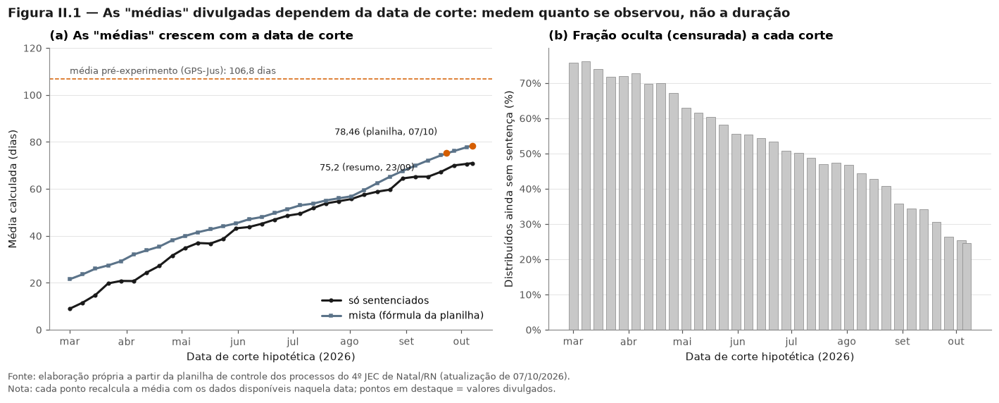

,Data de corte,Média só sentenciados (dias),Média mista (dias),Sentenciados até o corte,Ainda sem sentença
0,01/03/2026,"9,00","21,55",51,"75,8%"
8,26/04/2026,"31,58","38,14",154,"67,2%"
17,28/06/2026,"48,61","51,38",377,"50,8%"
29,20/09/2026,"67,30","74,31",651,"30,6%"
32,07/10/2026,"70,98","78,45",708,"24,5%"


In [36]:
cortes = pd.date_range('2026-03-01', DATA_CORTE, freq='7D').append(pd.DatetimeIndex([DATA_CORTE]))
serie_corte = []
for c in cortes:
    distribuidos = d2['dt_distribuicao'].le(c)
    sentenciados = d2['E'].eq(1) & d2['dt_sentenca'].le(c)
    serie_corte.append({'corte': c, 'media_sentenciados': d2.loc[sentenciados, 'T'].mean(),
                        'media_mista': media_mista(brutas, c)[0], 'n_sent': int(sentenciados.sum()),
                        'pct_sem_sentenca': 1 - sentenciados.sum() / distribuidos.sum()})
serie_corte = pd.DataFrame(serie_corte)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].plot(serie_corte['corte'], serie_corte['media_sentenciados'], color=TINTA, marker='o', ms=3, label='só sentenciados')
ax[0].plot(serie_corte['corte'], serie_corte['media_mista'], color='#5B7389', marker='s', ms=3,
           label='mista (fórmula da planilha)')
ax[0].axhline(106.8, color=DESTAQUE, ls='--', lw=1)
ax[0].text(serie_corte['corte'].iloc[0], 109, 'média pré-experimento (GPS-Jus): 106,8 dias', color=TINTA_2, fontsize=8.5)
for data, valor, rot, desl in [(CORTE_RESUMO, 75.2, '75,2 (resumo, 23/09)', (-118, -16)),
                               (DATA_CORTE, 78.46, '78,46 (planilha, 07/10)', (-128, 10))]:
    ax[0].scatter([data], [valor], color=DESTAQUE, zorder=5, s=40)
    ax[0].annotate(rot, (data, valor), xytext=desl, textcoords='offset points', fontsize=8.5, color=TINTA)
ax[0].set_ylabel('Média calculada (dias)'); ax[0].legend(loc='lower right')
ax[0].set_title('(a) As "médias" crescem com a data de corte')
ax[0].set_ylim(0, 120)
ax[1].bar(serie_corte['corte'], serie_corte['pct_sem_sentenca'], width=5, color=CORES_STATUS['Ativo (censurado)'],
          edgecolor='#8c8c8c', linewidth=0.5)
eixo_pct(ax[1])
ax[1].set_ylabel('Distribuídos ainda sem sentença (%)')
ax[1].set_title('(b) Fração oculta (censurada) a cada corte')
for a in ax:
    eixo_meses(a)
    a.set_xlabel('Data de corte hipotética (2026)')
figura(fig, 'exp_medias_corte', 'As "médias" divulgadas dependem da data de corte: medem quanto se observou, não a duração',
       secao='2.1.2', nota='cada ponto recalcula a média com os dados disponíveis naquela data; pontos em destaque = valores divulgados.')
tab_corte = serie_corte.iloc[[0, 8, 17, 29, -1]].rename(columns={
    'corte': 'Data de corte', 'media_sentenciados': 'Média só sentenciados (dias)', 'media_mista': 'Média mista (dias)',
    'n_sent': 'Sentenciados até o corte', 'pct_sem_sentenca': 'Ainda sem sentença'})
tabela(tab_corte, 'exp_medias_corte_tab', 'Médias e fração censurada em cinco datas de corte', secao='2.1.2',
       formatos={'Ainda sem sentença': 'pct'})

**Leitura. As médias divulgadas foram reconstituídas, e nenhuma mede a duração dos processos.**

- **78,46 é uma média "mista".** Com as 944 linhas e a fórmula da planilha (sentenciados pela data da sentença, ativos até 07/10/2026), obtém-se 78,45 dias no geral e 77,00 / 77,48 / 80,87 em Controle / Presencial / Remota, contra 77,00 / 77,50 / 80,87 divulgados. É a média de durações completas com tempos parciais de 206 processos ainda ativos.
- **75,2 também é uma média mista, só que com corte anterior.** O resumo expandido não explica o cálculo. A mesma fórmula com corte em **23/09/2026** (véspera da data do arquivo do resumo, 24/09) dá 75,15 dias, e 74,10 / 76,61 / 74,74 por grupo, contra 74,22 / 76,67 / 74,72 publicados. As contagens do resumo (668 sentenciados e 275 ativos) não batem com essa data (712 e 232 na planilha atual), o que sugere que parte das sentenças foi lançada depois, com data retroativa. Logo, a "queda de 106,8 para 75,2 dias" compara a média histórica do GPS-Jus com uma média que mistura processos ainda em curso, e não é evidência de aceleração.
- **A média dos sentenciados é ainda menor e instável.** Em 07/10 ela vale 70,98 dias; até 03/08 eram só 499 sentenças, com média de 55,95 dias. No gráfico, as duas médias sobem quase linearmente com a data de corte: de 9,0 dias (só sentenciados, corte em 01/03) para 70,98 (07/10), enquanto a fração ainda sem sentença cai de 76% para 25%. Um estimador que depende tanto do dia em que se olha não mede uma propriedade dos processos; mede o tempo de observação.
- **A diferença entre os grupos também é artefato.** A Remota parece "mais lenta" na média mista (80,87) porque concentra entradas em julho (seção 2.1.3), e tem mais ativos com tempo parcial. A comparação válida é a das curvas de sobrevivência: a mediana do Kaplan-Meier de todos os processos é de **89 dias** (seção 2.4.2), acima de todas as médias divulgadas.

### 2.1.3 Entrada escalonada e seguimento por mês de distribuição

O seguimento possível depende só da data de distribuição. A primeira figura mostra quantos processos de cada grupo entraram por mês (barras verticais agrupadas); a segunda, a situação de cada mês em 07/10/2026 (sentença, redistribuição ou ainda ativo), com o seguimento máximo possível de cada mês escrito acima da barra. **Como ler:** se algum grupo concentrar entradas em meses tardios, ele terá, por construção, mais censura e tempos observados mais curtos, sem que isso diga nada sobre o rito.

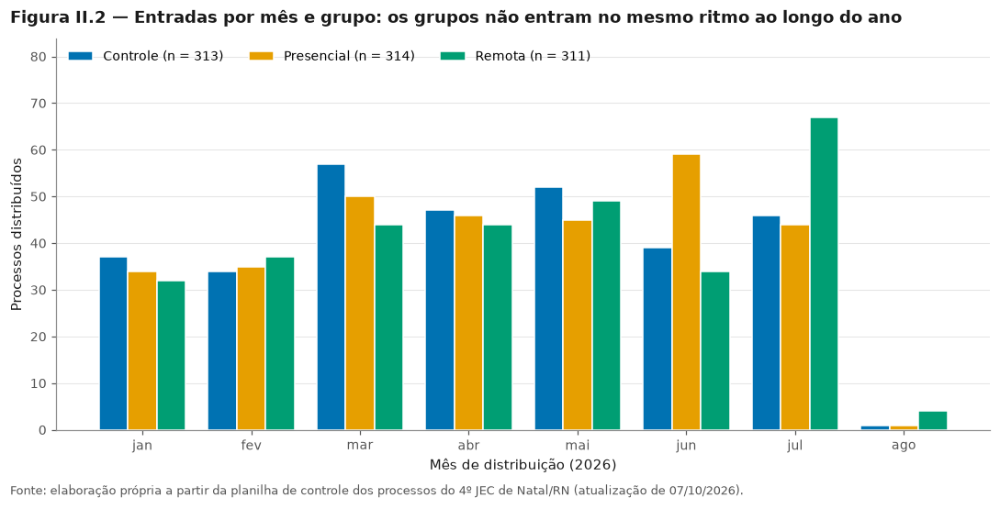

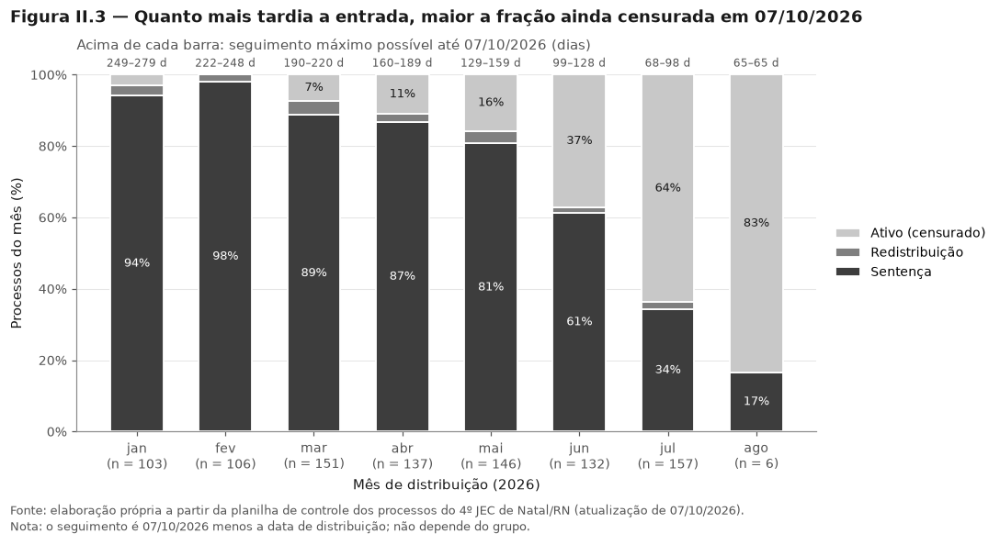

Mês,Controle,Presencial,Remota,Total,Seguimento mín. (dias),Seguimento máx. (dias),% Sentença,% Redistribuição,% Ativo (censurado)
jan,37,34,32,103,249,279,"94,2","2,9","2,9"
fev,34,35,37,106,222,248,"98,1","1,9","0,0"
mar,57,50,44,151,190,220,"88,7","4,0","7,3"
abr,47,46,44,137,160,189,"86,9","2,2","10,9"
mai,52,45,49,146,129,159,"80,8","3,4","15,8"
jun,39,59,34,132,99,128,"61,4","1,5","37,1"
jul,46,44,67,157,68,98,"34,4","1,9","63,7"
ago,1,1,4,6,65,65,"16,7","0,0","83,3"


In [37]:
MESES = list(d2['mes_distribuicao'].cat.categories)
cont_mes = pd.crosstab(d2['mes_distribuicao'], d2['grupo']).reindex(columns=ORDEM_GRUPO)
seg_mes = d2.groupby('mes_distribuicao', observed=True)['followup'].agg(['min', 'max'])
cens_mes = pd.crosstab(d2['mes_distribuicao'], d2['status'], normalize='index').reindex(columns=ORDEM_STATUS)

n_mes = d2['mes_distribuicao'].value_counts().reindex(MESES)
ROT_G = {g: rotulo_grupo(g, com_n=True, base=d2) for g in ORDEM_GRUPO}
fig, ax = plt.subplots(figsize=(10, 4.6))
barras_agrupadas(ax, cont_mes.rename(columns=ROT_G), cores={ROT_G[g]: CORES_GRUPO[g] for g in ORDEM_GRUPO},
                 ylabel='Processos distribuídos', xlabel=ROTULOS['mes_distribuicao'])
ax.legend(loc='upper left', ncol=3)
ax.set_ylim(0, cont_mes.to_numpy().max() * 1.25)
figura(fig, 'exp_entradas_mes', 'Entradas por mês e grupo: os grupos não entram no mesmo ritmo ao longo do ano',
       secao='2.1.3')

fig, ax = plt.subplots(figsize=(10, 4.8))
barras_empilhadas(ax, cens_mes, cores=CORES_STATUS, ns=n_mes.to_numpy(), ylabel='Processos do mês (%)')
for xi, mes in enumerate(MESES):
    ax.text(xi, 1.015, f'{seg_mes.loc[mes, "min"]}–{seg_mes.loc[mes, "max"]} d', ha='center', va='bottom',
            fontsize=8, color=TINTA_2, clip_on=False)
ax.set_xlabel(ROTULOS['mes_distribuicao'])
ax.set_title('Acima de cada barra: seguimento máximo possível até 07/10/2026 (dias)', fontsize=9.5,
             fontweight='normal', color=TINTA_2, pad=18)
figura(fig, 'exp_situacao_mes', 'Quanto mais tardia a entrada, maior a fração ainda censurada em 07/10/2026',
       secao='2.1.3', nota='o seguimento é 07/10/2026 menos a data de distribuição; não depende do grupo.')
tab_seg = pd.concat([cont_mes, n_mes.rename('Total'),
                     seg_mes.rename(columns={'min': 'Seguimento mín. (dias)', 'max': 'Seguimento máx. (dias)'}),
                     (100 * cens_mes).add_prefix('% ')], axis=1).rename_axis('Mês')
tabela(tab_seg, 'exp_seguimento_mes', 'Entradas por grupo, seguimento possível e situação em 07/10/2026, por mês de distribuição',
       secao='2.1.3')

**Leitura. A entrada escalonada faz do mês de distribuição um determinante da censura.**

- O seguimento possível vai de 249 a 279 dias para os processos de janeiro e de só 68 a 98 dias para os de julho. Por isso a fração ainda ativa em 07/10 cresce com o mês: 2,9% (jan.), 0% (fev.), 7,3% (mar.), 10,9% (abr.), 15,8% (mai.), **37,1% (jun.)**, **63,7% (jul.)** e 83,3% dos 6 processos de agosto.
- **Os grupos não entraram no mesmo ritmo.** Em junho, a Presencial recebeu 59 processos, contra 39 do Controle e 34 da Remota; em julho, a **Remota recebeu 67**, contra 46 e 44. Como esses meses têm seguimento curto, a Presencial e, sobretudo, a Remota carregam mais censura por razões de calendário, e não de rito. A aderência mês a mês é testada na seção 2.5.1.
- **Consequência para a análise:** qualquer comparação ingênua entre grupos (médias, proporção de encerrados, χ² de grupo × situação, como no notebook do professor, E19) confunde o rito com o mês de entrada. O mês entra como covariável ou estrato nas Partes IV e V.

### 2.1.4 Trajetórias individuais (gráfico de nadador / diagrama de Lexis simplificado)

Cada linha horizontal é um processo: começa na data de distribuição e termina na sentença (círculo, colorido pelo tipo de desfecho), na redistribuição (losango) ou na data de corte (seta: censurado). Usa-se uma amostra estratificada de 25 processos por grupo (semente fixa), ordenada pela data de distribuição. **Como ler:** as setas se acumulam nos processos de entrada tardia, e a linha vertical de 07/10/2026 é a "parede" que corta as trajetórias; o comprimento de uma seta é um limite inferior, não uma duração.

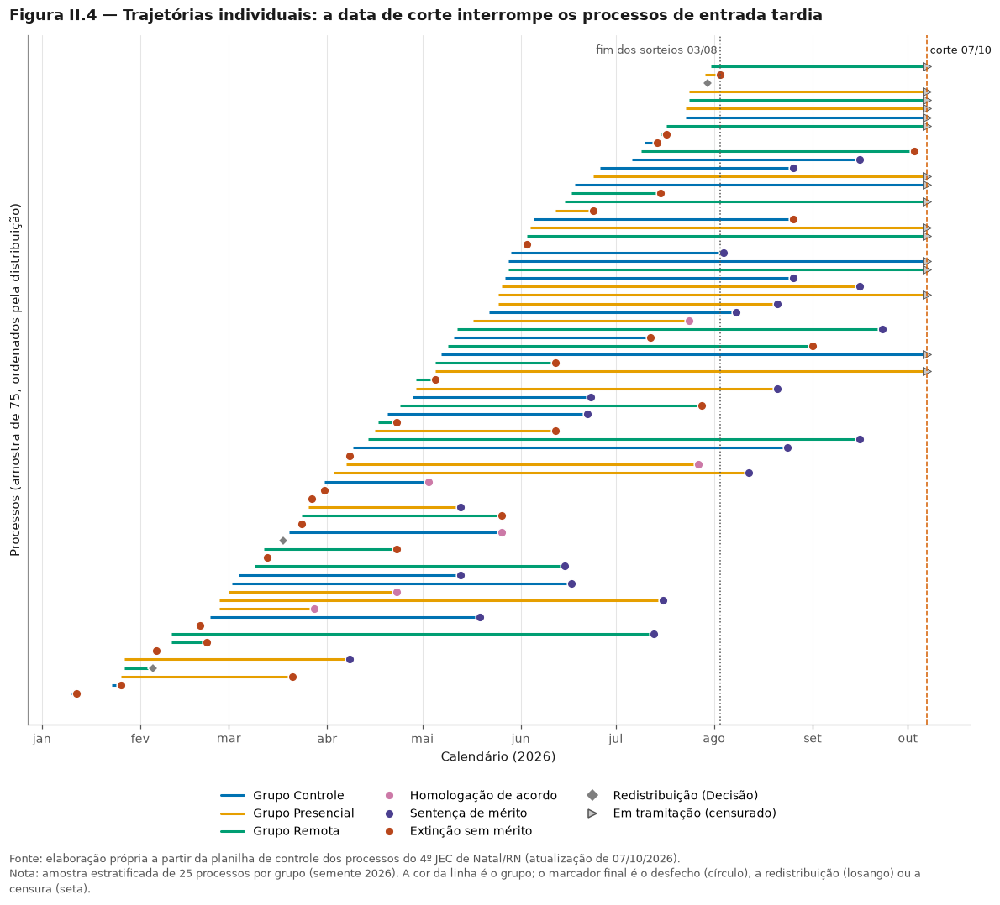

status
Sentença             56
Ativo (censurado)    16
Redistribuição        3


In [38]:
amostra = (d2.groupby('grupo', observed=True).sample(25, random_state=SEMENTE)
              .sort_values('dt_distribuicao').reset_index(drop=True))
fim = amostra['dt_sentenca'].fillna(DATA_CORTE)
fig, ax = plt.subplots(figsize=(11, 9))
for i, r in amostra.iterrows():
    ax.hlines(i, r['dt_distribuicao'], fim[i], color=CORES_GRUPO[r['grupo']], lw=2)
    if r['evento_cr'] == 1:
        ax.plot(fim[i], i, 'o', color=CORES_DESFECHO[r['tipo_desfecho']], ms=7, mec='white', mew=1)
    elif r['evento_cr'] == 2:
        ax.plot(fim[i], i, 'D', color=CORES_DESFECHO['Redistribuição'], ms=6, mec='white', mew=1)
    else:
        ax.plot(fim[i], i, '>', color=CORES_DESFECHO['Ativo'], ms=7, mec=TINTA_2, mew=0.6)
ax.axvline(DATA_CORTE, color=DESTAQUE, ls='--', lw=1)
ax.axvline(FIM_RECRUTAMENTO, color=TINTA_2, ls=':', lw=1)
ax.text(DATA_CORTE, len(amostra) + 0.5, ' corte 07/10', color=TINTA, fontsize=8.5)
ax.text(FIM_RECRUTAMENTO, len(amostra) + 0.5, 'fim dos sorteios 03/08 ', color=TINTA_2, fontsize=8.5, ha='right')
ax.set_yticks([]); ax.set_ylabel('Processos (amostra de 75, ordenados pela distribuição)')
eixo_meses(ax)
ax.grid(axis='x', visible=True); ax.grid(axis='y', visible=False)
ax.set_xlabel('Calendário (2026)')
leg = ([mpl.lines.Line2D([], [], color=CORES_GRUPO[g], lw=2, label=f'Grupo {g}') for g in ORDEM_GRUPO] +
       [mpl.lines.Line2D([], [], marker='o', ls='', color=CORES_DESFECHO[k], mec='white', ms=7, label=ROTULO_DESFECHO[k])
        for k in ['Homologação', 'Mérito', 'Sem mérito']] +
       [mpl.lines.Line2D([], [], marker='D', ls='', color=CORES_DESFECHO['Redistribuição'], label=ROTULO_DESFECHO['Redistribuição']),
        mpl.lines.Line2D([], [], marker='>', ls='', color=CORES_DESFECHO['Ativo'], mec=TINTA_2, label=ROTULO_DESFECHO['Ativo'])])
legenda_abaixo(ax, ncol=3, dy=-0.08, handles=leg)
figura(fig, 'exp_trajetorias', 'Trajetórias individuais: a data de corte interrompe os processos de entrada tardia',
       secao='2.1.4', nota='amostra estratificada de 25 processos por grupo (semente 2026). A cor da linha é o grupo; '
                           'o marcador final é o desfecho (círculo), a redistribuição (losango) ou a censura (seta).')
print(amostra['status'].value_counts().to_string())

**Leitura.** Na amostra de 75 processos (25 por grupo), 56 terminaram em sentença, 3 em redistribuição e 16 seguem ativos. O gráfico deixa visíveis três padrões que as médias escondem:

- **As setas (censurados) se concentram em junho e julho.** Todas encostam na linha de 07/10, e o seu comprimento varia de pouco mais de 60 dias a cerca de 4 meses: são limites inferiores, não durações.
- **Há dois "relógios" nos desfechos.** As extinções sem mérito (círculos vermelho-tijolo) aparecem muitas vezes poucos dias após a distribuição, com segmentos curtíssimos; as sentenças de mérito (roxo-escuro) aparecem de 2 a 7 meses depois. Essa bimodalidade reaparece no histograma (seção 2.2.3) e na forma do risco (seção 2.4.1).
- **Processos distribuídos no mesmo dia podem ter destinos muito diferentes**, o que mostra a variabilidade individual que os testes e modelos precisam acomodar.

## 2.2 Análise univariada

### 2.2.1 Variáveis categóricas: tabelas de frequência

Para cada variável categórica, a tabela traz a frequência absoluta (n), a relativa (%) e a acumulada (% acum.) sobre os 938 processos, e o % sobre os casos válidos (excluídas as ausências). As ausências **não** são categorias de resposta: são mostradas com o motivo (zero estrutural, "não se aplica", ou processo ativo ainda sem a informação), como determinado na Parte I. A % acumulada só tem leitura substantiva nas variáveis ordinais (mês, dia da semana, ciclo); nas nominais, é a base do gráfico de Pareto.

In [39]:
def para_rotulos(serie, rotulo_na):
    # Converte booleanos em Sim/Não e ausências no rótulo explicativo, preservando a ordem das categorias
    if isinstance(serie.dtype, pd.BooleanDtype) or pd.api.types.is_bool_dtype(serie):
        s = serie.map({True: 'Sim', False: 'Não'})
        ordem = ['Sim', 'Não']
    elif isinstance(serie.dtype, pd.CategoricalDtype):
        s = serie.astype(object)
        ordem = list(serie.cat.categories)
    else:
        s = serie.astype(object)
        ordem = sorted(s.dropna().unique())
    s = s.where(serie.notna(), rotulo_na)
    if serie.isna().any():
        ordem = ordem + [rotulo_na]
    return pd.Categorical(s, categories=ordem, ordered=True)


def tabela_freq(serie, rotulo_na='NA'):
    cat = para_rotulos(serie, rotulo_na)
    n = pd.Series(cat).value_counts(sort=False)
    validos = n.drop(rotulo_na, errors='ignore')
    tab = pd.DataFrame({'n': n, '%': 100 * n / n.sum()})
    tab['% acum.'] = tab['%'].cumsum()
    tab['% válido'] = (100 * validos / validos.sum()).reindex(tab.index)
    return tab


VARS_CAT = {   # variável: (título, rótulo das ausências)
    'grupo': ('Grupo sorteado', None),
    'mes_distribuicao': ('Mês de distribuição', None),
    'ciclo': ('Ciclo (resumo expandido)', None),
    'dia_semana_distribuicao': ('Dia da semana da distribuição', None),
    'tipo_desfecho': ('Tipo de desfecho em 07/10/2026', None),
    'ac_realizada': ('AC realizada', 'não informado (ativo)'),
    'tecnica_curta': ('Técnica de conciliação', 'sem AC (não se aplica)'),
    'hibrida': ('AC híbrida', 'não informado'),
    'acordo_ac': ('Acordo na AC', 'não informado'),
    'acordo_fora': ('Acordo fora da AC', 'ativo (indefinido)'),
    'acordo': ('Acordo (qualquer momento)', 'ativo (indefinido)'),
    'origem_externa': ('Origem externa (redistribuído à vara)', None),
    'tempo_zero': ('Desfecho no dia da distribuição', None),
    'sentenca_fim_semana': ('Desfecho datado em fim de semana', 'ativo (sem desfecho)'),
    'desvio_protocolo': ('Desvio de protocolo (híbrida na Remota ou sem AC)', None),
    'cnj_corrigido': ('Número CNJ corrigido', None),
    'duplicado_removido': ('Número com linha duplicada removida', None),
}
tabelas_freq = {VARS_CAT[v][0]: tabela_freq(d2[v], VARS_CAT[v][1] or 'NA') for v in VARS_CAT}
tab_freq = pd.concat(tabelas_freq, names=['Variável', 'Categoria'])
tabela(tab_freq, 'exp_freq', 'Frequências de todas as variáveis categóricas (938 processos)', secao='2.2.1',
       formatos={'n': 'int'}, casas=1,
       nota='% = sobre os 938 processos; % válido = excluídas as ausências, cujo motivo aparece como categoria própria '
            '(não são respostas). A % acumulada só tem leitura substantiva nas variáveis ordinais.')

**Gráficos de barras verticais.** As variáveis do desenho (grupo e calendário) aparecem primeiro; o rótulo de cada barra é a frequência absoluta. Cada variável tem uma só cor (exceto o grupo, que usa as cores fixas dos grupos), porque a altura da barra já mostra a frequência.

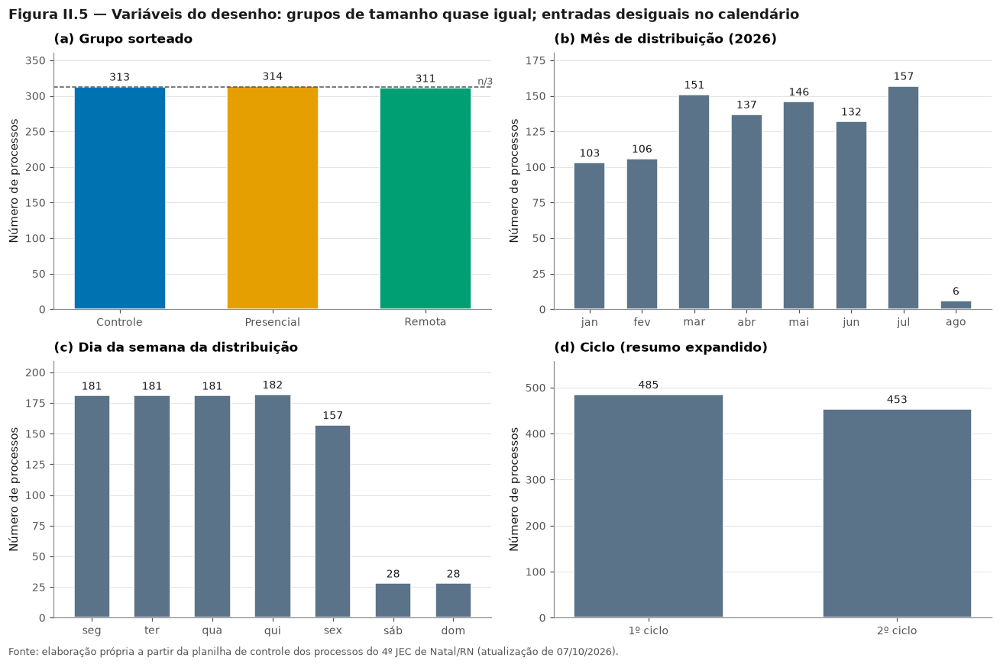

In [40]:
def barras(ax, serie, titulo, rotulo_na='NA', cores=None, quebrar=12):
    tab = tabela_freq(serie, rotulo_na)
    cores_barras = [CORES_DESFECHO['Ativo'] if k == rotulo_na else (cores or {}).get(k, '#5B7389') for k in tab.index]
    barras_verticais(ax, [str(k) for k in tab.index], tab['n'].to_numpy(), cores=cores_barras, quebrar=quebrar,
                     ylabel=ROTULOS['n'])
    ax.set_title(titulo)
    return tab


fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))
barras(ax[0, 0], d2['grupo'], '(a) Grupo sorteado', cores=CORES_GRUPO)
ax[0, 0].axhline(len(d2) / 3, color=TINTA_2, ls='--', lw=1)
ax[0, 0].text(2.32, len(d2) / 3, ' n/3', color=TINTA_2, fontsize=8.5, va='bottom')
barras(ax[0, 1], d2['mes_distribuicao'], '(b) Mês de distribuição (2026)')
barras(ax[1, 0], d2['dia_semana_distribuicao'], '(c) Dia da semana da distribuição')
barras(ax[1, 1], d2['ciclo'], '(d) Ciclo (resumo expandido)', quebrar=10)
figura(fig, 'exp_freq_desenho', 'Variáveis do desenho: grupos de tamanho quase igual; entradas desiguais no calendário',
       secao='2.2.1')

**Leitura. O desenho está equilibrado nos grupos, mas não no calendário.**

- **Grupos:** 313 (33,4%), 314 (33,5%) e 311 (33,2%), praticamente 1/3 cada. É um equilíbrio notável, analisado como evidência sobre o mecanismo do sorteio na seção 2.5.1.
- **Mês:** a distribuição não é uniforme. Janeiro e fevereiro têm cerca de 105 processos (recesso forense até 20/01 e mês curto); março a julho, de 132 a 157; agosto, só 6 (o sorteio terminou em 03/08). A % acumulada mostra que metade dos processos entrou até abril (53,0%) e o 2º ciclo (29/04 a 03/08) tem 453 processos (48,3%), contra 485 no 1º.
- **Dia da semana da distribuição:** segunda a quinta têm de 181 a 182 processos cada, sexta tem 157 e sábado e domingo têm 28 cada (3,0%). A distribuição eletrônica do PJe ocorre também nos fins de semana, de modo que essas datas são legítimas.

**Desfecho e técnica: gráficos de Pareto.** Para as duas variáveis nominais com várias categorias, o Pareto ordena as barras da mais para a menos frequente; a % acumulada é escrita sobre cada barra (em vez de um segundo eixo vertical, que criaria uma escala arbitrária ao lado da contagem). Ele responde a "quais categorias concentram os casos". No tipo de desfecho, "Ativo" é mantido porque é uma situação real em 07/10/2026 (ainda sem desfecho), mas é a censura, não um desfecho.

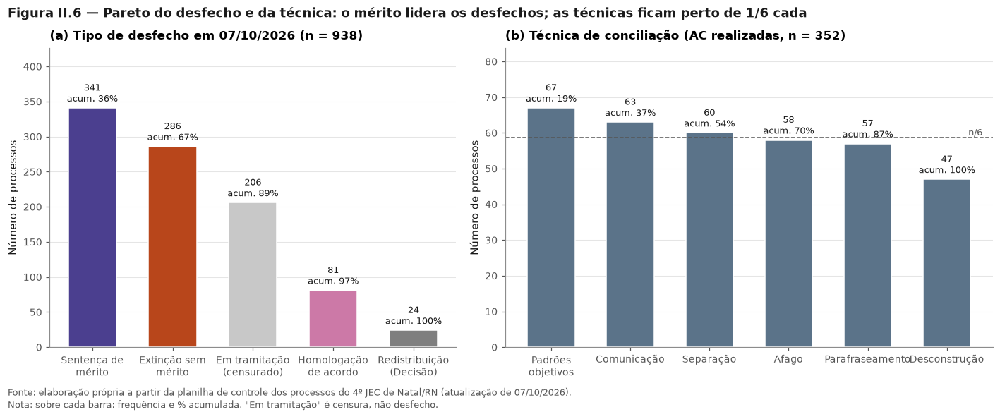

In [41]:
def pareto(ax, serie, titulo, cores=None, rotulos=None, quebrar=14):
    n = serie.value_counts().sort_values(ascending=False)
    acum = n.cumsum() / n.sum()
    nomes = [(rotulos or {}).get(k, k) for k in n.index]
    barras_verticais(ax, nomes, n.to_numpy(), cores=[(cores or {}).get(k, '#5B7389') for k in n.index],
                     rotular=False, quebrar=quebrar, ylabel=ROTULOS['n'])
    for i, (v, a) in enumerate(zip(n.to_numpy(), acum.to_numpy())):
        ax.annotate(f'{fmt_br(v, 0)}\nacum. {pct_br(a, 0)}', (i, v), xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=8.5, color=TINTA)
    ax.set_ylim(0, n.max() * 1.25)
    ax.set_title(titulo)
    return n


fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [5, 6]})
pareto(ax[0], d2['tipo_desfecho'].astype(str), f'(a) Tipo de desfecho em 07/10/2026 (n = {fmt_br(len(d2), 0)})',
       CORES_DESFECHO, ROTULO_DESFECHO, quebrar=13)
n_ac_real = int(d2['tecnica_curta'].notna().sum())
pareto(ax[1], d2['tecnica_curta'].dropna().astype(str), f'(b) Técnica de conciliação (AC realizadas, n = {n_ac_real})',
       quebrar=12)
ax[1].axhline(n_ac_real / 6, color=TINTA_2, ls='--', lw=1)
ax[1].text(5.45, n_ac_real / 6, 'n/6', fontsize=8.5, color=TINTA_2, va='bottom', ha='right')
figura(fig, 'exp_pareto', 'Pareto do desfecho e da técnica: o mérito lidera os desfechos; as técnicas ficam perto de 1/6 cada',
       secao='2.2.1', nota='sobre cada barra: frequência e % acumulada. "Em tramitação" é censura, não desfecho.')

**Leitura.**

- **Desfecho.** O Pareto mostra que mérito (341; 36,4%) e sem mérito (286; 30,5%) somam dois terços dos processos; com os 206 ativos (22,0%), chegam a 88,9%. Homologação de acordo (81; 8,6%) e redistribuição (24; 2,6%) são minoritárias. A taxa de 8,6% de homologações tem como denominador os distribuídos, inclusive os ativos; o índice de conciliação com o denominador correto (sentenças) está na seção 2.5.2.
- **Técnica.** Entre as 352 AC realizadas, as seis técnicas aparecem com frequências próximas, de 47 (Desconstrução; 13,4%) a 67 (Padrões objetivos; 19,0%), todas em torno da linha de 1/6 (58,7 audiências). O Pareto é quase plano: são necessárias cinco das seis técnicas para chegar a 80% dos casos. Não há sinal da hegemonia de "padrões objetivos" com 53,85% afirmada no resumo expandido; o teste está na seção 2.5.3.

**Audiência e acordo; indicadores de qualidade.** Barras verticais 100% empilhadas, uma por variável binária (Sim, Não e ausente). A leitura correta de cada uma depende do denominador: `acordo_ac`, `hibrida` e `tecnica` só têm sentido onde houve AC; `acordo` e `acordo_fora` ficam indefinidos nos ativos (o acordo ainda pode acontecer). Os indicadores da segunda linha são *flags* de curadoria (Parte I), úteis para as análises de sensibilidade.

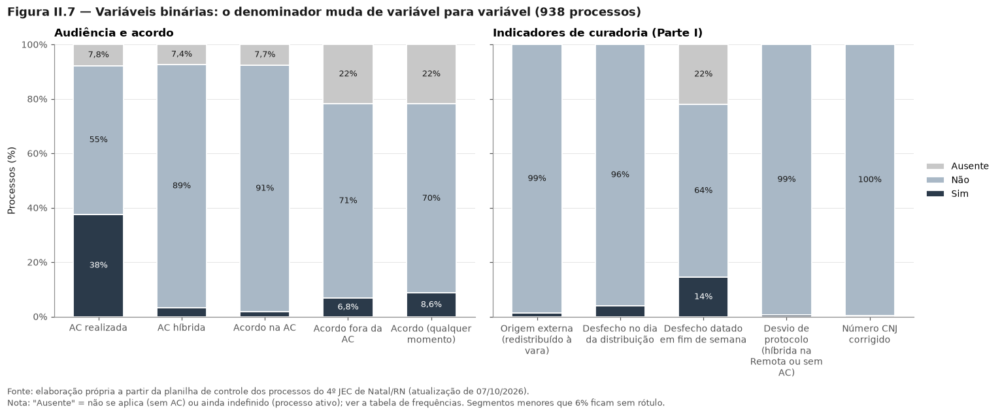

AC realizadas: 352 (Presencial 178, Remota 174); acordo na AC: 17 (4,8% das AC realizadas)
Híbridas: 31, das quais 28 no grupo Presencial
Acordo em qualquer momento: 81 = homologações (81)


In [42]:
PAINEL_BIN = {'Audiência e acordo': ['ac_realizada', 'hibrida', 'acordo_ac', 'acordo_fora', 'acordo'],
              'Indicadores de curadoria (Parte I)': ['origem_externa', 'tempo_zero', 'sentenca_fim_semana',
                                                    'desvio_protocolo', 'cnj_corrigido']}
CORES_BIN = {'Sim': '#2B3A4A', 'Não': '#A9B8C6', 'Ausente': CORES_DESFECHO['Ativo']}
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for a, (bloco_, vars_) in zip(ax, PAINEL_BIN.items()):
    linhas_bin = {}
    for v in vars_:
        cat = pd.Series(para_rotulos(d2[v], 'Ausente'))
        linhas_bin[VARS_CAT[v][0]] = cat.value_counts(normalize=True).reindex(['Sim', 'Não', 'Ausente']).fillna(0)
    barras_empilhadas(a, pd.DataFrame(linhas_bin).T, cores=CORES_BIN, quebrar=16, legenda=False,
                      fmt=lambda v: pct_br(v, 1) if v < 0.1 else pct_br(v, 0))
    a.set_title(bloco_)
ax[1].set_ylabel('')
ax[1].legend(*[x[::-1] for x in ax[1].get_legend_handles_labels()], loc='center left', bbox_to_anchor=(1.01, 0.5))
figura(fig, 'exp_binarias', 'Variáveis binárias: o denominador muda de variável para variável (938 processos)',
       secao='2.2.1', nota='"Ausente" = não se aplica (sem AC) ou ainda indefinido (processo ativo); ver a tabela de frequências. '
                           'Segmentos menores que 6% ficam sem rótulo.')

# Denominadores corretos das taxas de AC e acordo
ac = d2[d2['ac_realizada'].fillna(False).astype(bool)].copy()
print(f'AC realizadas: {len(ac)} (Presencial {(ac.grupo == "Presencial").sum()}, Remota {(ac.grupo == "Remota").sum()}); '
      f'acordo na AC: {int(ac.acordo_ac.sum())} ({pct_br(ac.acordo_ac.mean())} das AC realizadas)')
print(f'Híbridas: {int(d2.hibrida.sum())}, das quais {int((d2.hibrida.fillna(False) & d2.grupo.eq("Presencial")).sum())} no grupo Presencial')
print(f'Acordo em qualquer momento: {int(d2.acordo.sum())} = homologações ({(d2.tipo_desfecho == "Homologação").sum()})')

**Leitura. As taxas só têm sentido com o denominador certo.**

- **AC realizada:** 352 audiências (178 na Presencial e 174 na Remota). Os 513 "Não" incluem os 313 processos do Controle, em que a AC não existe no rito (zero estrutural), e 200 processos tratados em que a AC não ocorreu, em geral porque o processo foi extinto antes (seção 2.5.2). Os 73 sem informação são tratados ativos ainda sem audiência.
- **Acordo na AC:** 17 acordos, isto é, **4,8% das AC realizadas**. Os 1,8% sobre os 938 processos (como no notebook do professor, E30) diluem a taxa com o Controle, que não tem audiência.
- **Acordo fora da AC:** 64, quase quatro vezes os obtidos em audiência; o **acordo em qualquer momento** soma 81, exatamente o número de homologações. Os 205 "ativo (indefinido)" não são "sem acordo": o acordo ainda pode ocorrer.
- **Híbrida:** 31 casos, 28 na Presencial (3,6% dos válidos) e 3 na Remota, estes incongruentes com o protocolo (`desvio_protocolo`, 6 casos ao todo).
- **Indicadores de curadoria:** 12 processos de origem externa (1,3%), 38 desfechos no dia da distribuição (4,1%; seção 2.2.5), 135 desfechos datados em fim de semana (18,4% dos desfechos; seção 2.5.4), 4 números CNJ corrigidos e 5 números com linha duplicada removida. Todos são raros o bastante para análises de sensibilidade sem perda de poder.

### 2.2.2 O tempo: medidas descritivas

As medidas são calculadas em quatro recortes, que **não** são intercambiáveis:

- **Sentenças (n = 708)**: durações completas, mas **condicionais** a ter havido sentença até 07/10/2026. Descrevem os processos já sentenciados, não "o tempo de tramitação" do 4º JEC, porque os processos longos estão sub-representados (ainda ativos).
- **Ativos (n = 206)**: tempo já decorrido até o corte; é um **limite inferior** da duração real.
- **Redistribuições (n = 24)**: tempo até a saída da vara; não é tempo até sentença.
- **Todos os tempos observados (n = 938)**: o que a planilha e o notebook do professor resumiam (E7, E14). Apresentado só para mostrar o que estava sendo calculado; **não estima nenhuma quantidade interpretável**.

Medidas: média, mediana, moda (dia mais frequente), desvio-padrão, variância, coeficiente de variação (CV = DP/média), quantis, intervalo interquartil (IIQ), mínimo, máximo, assimetria e curtose em excesso (estimadores sem viés de Fisher; curtose 0 = normal), MAD (desvio absoluto mediano, escala bruta e reescalada por 1,4826 para comparação com o DP), média aparada a 10% e intervalo de confiança *bootstrap* de 95% da mediana (percentil, 5.000 reamostras, semente fixa).

In [43]:
def descritivas(x, b=5000):
    x = np.asarray(x, dtype=float)
    moda = pd.Series(x).mode()
    q = np.percentile(x, [5, 10, 25, 50, 75, 90, 95])
    boot = stats.bootstrap((x,), np.median, n_resamples=b, confidence_level=0.95, method='percentile',
                           rng=np.random.default_rng(SEMENTE))
    return pd.Series({
        'n': len(x), 'média': x.mean(), 'EP da média': x.std(ddof=1) / np.sqrt(len(x)),
        'mediana': q[3], 'IC95% mediana (inf.)': boot.confidence_interval.low,
        'IC95% mediana (sup.)': boot.confidence_interval.high,
        'moda': moda.iloc[0], 'freq. da moda': int((x == moda.iloc[0]).sum()),
        'desvio-padrão': x.std(ddof=1), 'variância': x.var(ddof=1), 'CV (%)': 100 * x.std(ddof=1) / x.mean(),
        'mínimo': x.min(), 'P5': q[0], 'P10': q[1], 'Q1 (P25)': q[2], 'Q3 (P75)': q[4], 'P90': q[5], 'P95': q[6],
        'máximo': x.max(), 'amplitude': x.max() - x.min(), 'IIQ': q[4] - q[2],
        'assimetria': stats.skew(x, bias=False), 'curtose (excesso)': stats.kurtosis(x, bias=False),
        'MAD': stats.median_abs_deviation(x), 'MAD × 1,4826': stats.median_abs_deviation(x, scale='normal'),
        'média aparada 10%': stats.trim_mean(x, 0.10),
    })


recortes = {'Sentenças (condicional)': sent['T'],
            'Ativos (limite inferior)': d2.loc[d2.evento_cr.eq(0), 'T'],
            'Redistribuições': d2.loc[d2.evento_cr.eq(2), 'T'],
            'Todos os observados (inválido)': d2['T']}
tab_desc = pd.DataFrame({k: descritivas(v) for k, v in recortes.items()})
_fmt_desc = lambda v: fmt_br(v, 0) if float(v).is_integer() else fmt_br(v, 2)
tabela(tab_desc.rename_axis('Medida (dias, salvo indicação)'), 'exp_descritivas',
       'Medidas descritivas do tempo em quatro recortes que não são intercambiáveis', secao='2.2.2',
       formatos={c: _fmt_desc for c in tab_desc.columns},
       nota='as sentenças descrevem só os processos já sentenciados (condicional); os ativos dão limites inferiores; '
            'a coluna "todos os observados" mistura os dois e não estima nenhuma quantidade interpretável.')

"Medida (dias, salvo indicação)",Sentenças (condicional),Ativos (limite inferior),Redistribuições,Todos os observados (inválido)
n,708,206,24,938
média,"70,98","111,50","11,29","78,35"
EP da média,"1,83","2,95","4,69","1,66"
mediana,"73,50",97,1,80
IC95% mediana (inf.),70,92,1,77
IC95% mediana (sup.),78,107,5,83
moda,1,70,1,1
freq. da moda,47,8,8,55
desvio-padrão,"48,73","42,33","22,99","50,94"
variância,"2.375,09","1.792,15","528,74","2.594,94"


### 2.2.3 O tempo: gráficos

Quatro gráficos complementares, todos em escala linear:

- **(a) Histograma** dos tempos observados, empilhado pela situação (sentença, redistribuição, ativo). Classes de 10 dias. Mostra onde estão os censurados (à direita, porque só se tornam censurados os processos que chegaram ao corte sem sentença).
- **(b) Boxplot vertical** por recorte. A caixa vai de Q1 a Q3, a linha é a mediana (valor escrito ao lado, "Md"), o losango é a média; os "bigodes" vão até 1,5 IIQ.
- **(c) Violino** das sentenças por tipo de desfecho: a largura é a densidade estimada (núcleo gaussiano), o que revela bimodalidade que o boxplot esconde.
- **(d) ECDF** (função de distribuição empírica) das sentenças e dos ativos. **Atenção:** a ECDF das sentenças **não** é 1 − KM; ela ignora os censurados e por isso sobe depressa demais (o KM correto está na Parte IV).

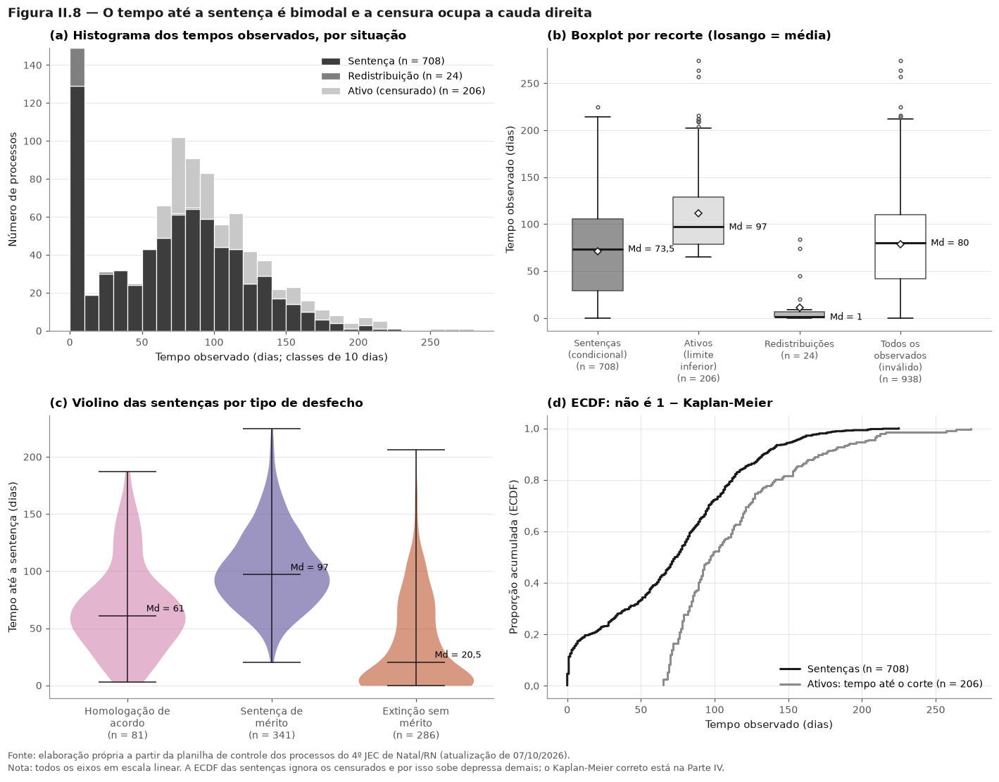

In [44]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9.5))
classes = np.arange(0, 290, 10)
base = np.zeros(len(classes) - 1)
for s in ORDEM_STATUS:
    h, _ = np.histogram(d2.loc[d2.status.eq(s), 'T'], bins=classes)
    ax[0, 0].bar(classes[:-1], h, width=10, align='edge', bottom=base, color=CORES_STATUS[s],
                 edgecolor='white', linewidth=0.8, label=f'{s} (n = {d2.status.eq(s).sum()})')
    base += h
ax[0, 0].set_xlabel('Tempo observado (dias; classes de 10 dias)'); ax[0, 0].set_ylabel(ROTULOS['n'])
ax[0, 0].legend(loc='upper right')
ax[0, 0].set_title('(a) Histograma dos tempos observados, por situação')

COR_RECORTE = {'Sentenças (condicional)': CORES_STATUS['Sentença'], 'Ativos (limite inferior)': CORES_STATUS['Ativo (censurado)'],
               'Redistribuições': CORES_STATUS['Redistribuição'], 'Todos os observados (inválido)': '#FFFFFF'}
dados_box = [recortes[k].to_numpy(float) for k in recortes]
bp = ax[0, 1].boxplot(dados_box, positions=range(4), showmeans=True, widths=0.5, patch_artist=True,
                      medianprops=dict(color=TINTA, lw=2), flierprops=dict(marker='o', ms=3, mfc='none', mec=TINTA_2),
                      meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor=TINTA, ms=5))
for p_, k in zip(bp['boxes'], recortes):
    p_.set_facecolor(mpl.colors.to_rgba(COR_RECORTE[k], 0.55)); p_.set_edgecolor(TINTA_2)
for i, v in enumerate(dados_box):
    ax[0, 1].annotate(f'Md = {fmt_br(np.median(v), 1 if not float(np.median(v)).is_integer() else 0)}',
                      (i + 0.27, np.median(v)), xytext=(3, 0), textcoords='offset points', va='center', fontsize=8.5)
ax[0, 1].set_xticks(range(4), [f'{quebra(k, 13)}\n(n = {len(v)})' for k, v in recortes.items()], fontsize=8.5)
ax[0, 1].set_xlim(-0.5, 3.9)
ax[0, 1].set_ylabel('Tempo observado (dias)'); ax[0, 1].set_title('(b) Boxplot por recorte (losango = média)')
ax[0, 1].grid(axis='x', visible=False)

tipos = ['Homologação', 'Mérito', 'Sem mérito']
vp = ax[1, 0].violinplot([sent.loc[sent.tipo_desfecho.eq(t), 'T'] for t in tipos], positions=range(3),
                         showmedians=True, widths=0.8)
for corpo, t in zip(vp['bodies'], tipos):
    corpo.set_facecolor(CORES_DESFECHO[t]); corpo.set_edgecolor(CORES_DESFECHO[t]); corpo.set_alpha(0.55)
for parte in ('cbars', 'cmins', 'cmaxes', 'cmedians'):
    vp[parte].set_color(TINTA); vp[parte].set_linewidth(1)
for i, t in enumerate(tipos):
    md_t = sent.loc[sent.tipo_desfecho.eq(t), 'T'].median()
    ax[1, 0].annotate(f'Md = {fmt_br(md_t, 0 if float(md_t).is_integer() else 1)}', (i + 0.1, md_t), xytext=(4, 4),
                      textcoords='offset points', fontsize=8.5)
ax[1, 0].set_xticks(range(3), [f'{quebra(ROTULO_DESFECHO[t], 14)}\n(n = {sent.tipo_desfecho.eq(t).sum()})' for t in tipos])
ax[1, 0].set_ylabel(ROTULOS['tempo_sentenca']); ax[1, 0].set_title('(c) Violino das sentenças por tipo de desfecho')
ax[1, 0].grid(axis='x', visible=False)

for nome, serie, cor in [(f'Sentenças (n = {len(sent)})', sent['T'], TINTA),
                         (f'Ativos: tempo até o corte (n = {int(d2.evento_cr.eq(0).sum())})', d2.loc[d2.evento_cr.eq(0), 'T'], '#8C8C8C')]:
    xs = np.sort(serie.to_numpy(float))
    ax[1, 1].step(xs, np.arange(1, len(xs) + 1) / len(xs), where='post', color=cor, label=nome)
ax[1, 1].set_xlabel('Tempo observado (dias)'); ax[1, 1].set_ylabel('Proporção acumulada (ECDF)')
ax[1, 1].legend(loc='lower right'); ax[1, 1].grid(axis='both', visible=True)
ax[1, 1].set_title('(d) ECDF: não é 1 − Kaplan-Meier')
figura(fig, 'exp_tempo_graficos', 'O tempo até a sentença é bimodal e a censura ocupa a cauda direita', secao='2.2.3',
       nota='todos os eixos em escala linear. A ECDF das sentenças ignora os censurados e por isso sobe depressa demais; '
            'o Kaplan-Meier correto está na Parte IV.')

**Leitura. A distribuição dos tempos é bimodal, e a censura ocupa a cauda direita.**

- **(a) Histograma.** Há um primeiro pico na classe de 0 a 10 dias (cerca de 130 sentenças e a maior parte das redistribuições), formado por extinções sem mérito e declinações de competência; um vale entre 10 e 50 dias; e uma segunda moda entre 70 e 100 dias. Os ativos (cinza-claro) começam em 65 dias e dominam as classes acima de 150 dias: a cauda direita da duração real está **escondida** na censura.
- **(b) Boxplots.** A mediana das sentenças (73,5 dias) fica abaixo da dos ativos (97 dias, que ainda vai crescer). A caixa "todos os observados" (mediana 80) parece uma distribuição comportada, mas é uma mistura sem significado. As redistribuições são quase todas imediatas (mediana de 1 dia).
- **(c) Violinos.** Cada tipo de desfecho tem a sua própria distribuição: mérito centrado perto de 100 dias, homologação perto de 60 e sem mérito com massa concentrada junto de zero e uma cauda até 200 dias. A distribuição global é a soma dessas três.
- **(d) ECDF.** A ECDF das sentenças sobe rapidamente até cerca de 20% nos primeiros dias (as extinções imediatas) e atinge 50% por volta de 73 dias. Por ignorar os 230 censurados, ela superestima a velocidade de encerramento: com censura, a mediana é de 89 dias (Kaplan-Meier, seção 2.4.2).

O **QQ-plot normal** das sentenças compara os quantis observados com os de uma normal de mesma média e desvio-padrão. Pontos sobre a reta indicam normalidade; curvatura em "S" indica caudas diferentes da normal; desvios nas pontas indicam assimetria ou truncamento. Os testes formais de normalidade estão na seção 2.3.

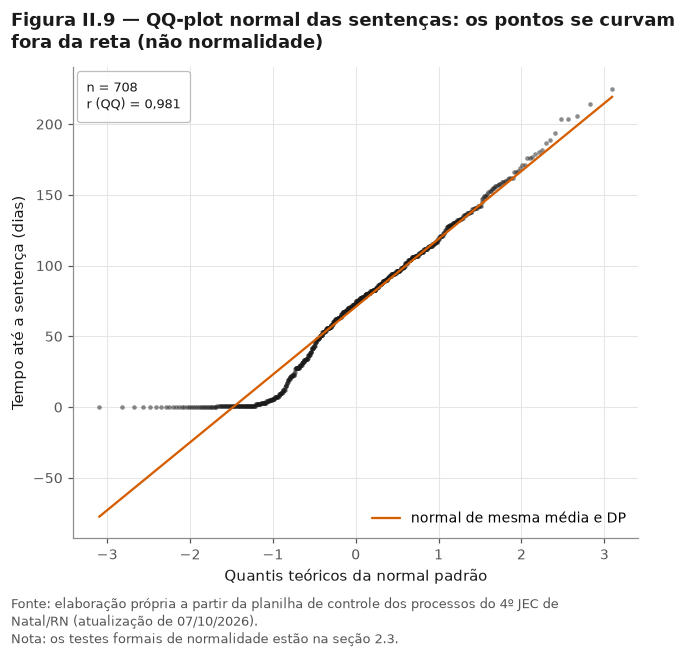

In [45]:
fig, ax = plt.subplots(figsize=(6, 5))
(osm, osr), (incl, inter, r) = stats.probplot(sent['T'], dist='norm')
ax.scatter(osm, osr, s=9, color=TINTA, alpha=0.5, lw=0)
ax.plot(osm, inter + incl * osm, color=DESTAQUE, lw=1.5, label='normal de mesma média e DP')
ax.set_xlabel('Quantis teóricos da normal padrão'); ax.set_ylabel(ROTULOS['tempo_sentenca'])
ax.grid(axis='both', visible=True); ax.legend(loc='lower right')
anotar_teste(ax, f'n = {len(sent)}\nr (QQ) = {fmt_br(r, 3)}', loc='upper left')
figura(fig, 'exp_qq_sentencas', 'QQ-plot normal das sentenças: os pontos se curvam fora da reta (não normalidade)',
       secao='2.2.3', nota='os testes formais de normalidade estão na seção 2.3.')

**Leitura das medidas descritivas (tabela da seção 2.2.2) e do QQ-plot.**

- **Sentenças (n = 708, condicional):** média 70,98 dias (EP 1,83), mediana 73,5 (IC95% *bootstrap* 70,0 a 78,0), moda 1 dia (47 sentenças), desvio-padrão 48,7, CV 68,7%, IIQ 76,25 (Q1 = 29, Q3 = 105,25), P90 = 133, máximo 225. A assimetria (0,21) e a curtose em excesso (−0,56) são próximas de zero, mas isso **não** indica normalidade: a distribuição é bimodal e truncada pela janela de observação, e a cauda direita foi cortada pela censura (exatamente o equívoco de leitura do notebook do professor, E15). O MAD reescalado (54,1) é maior que o desvio-padrão (48,7), sinal de distribuição "achatada" (platicúrtica), e não de caudas pesadas; a média aparada a 10% (68,9) fica perto da média.
- **Ativos (n = 206):** o tempo já decorrido vai de 65 a 274 dias (mediana 97). São limites inferiores: a duração final será maior.
- **Redistribuições (n = 24):** mediana de 1 dia e média de 11,3; quase todas são declinações imediatas.
- **Todos os observados (n = 938):** média 78,35 e mediana 80. Não estimam nada (mistura de durações completas, parciais e de saídas da vara).
- **QQ-plot.** Os pontos formam um "patamar" horizontal na cauda esquerda (os tempos próximos de zero, muito mais frequentes do que uma normal admitiria, e sem valores negativos possíveis) e, no centro e na cauda direita, acompanham a reta com curvatura leve. O desvio é de forma (bimodalidade e limite inferior em zero), e é testado formalmente na seção 2.3.

### 2.2.4 Valores atípicos (regra do IIQ)

Pela regra de Tukey, é atípico o valor fora de [Q1 − 1,5·IIQ; Q3 + 1,5·IIQ]. A regra é aplicada às sentenças (durações completas). **Nenhum valor é removido**: um processo de 220 dias não é erro de medida, é uma duração legítima, e justamente a cauda longa é o que interessa à gestão do acervo. Remover "outliers" de uma variável de tempo encurtaria artificialmente as durações. A conferência de datas (Parte I, seção 1.14) já descartou erros de registro (sentença anterior à distribuição etc.).

In [46]:
q1, q3 = sent['T'].quantile([0.25, 0.75])
iiq = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iiq, q3 + 1.5 * iiq
atipicos = sent[(sent['T'] < lim_inf) | (sent['T'] > lim_sup)]
print(f'Sentenças: Q1 = {fmt_br(q1)}, Q3 = {fmt_br(q3)}, IIQ = {fmt_br(iiq)}; cercas = [{fmt_br(lim_inf)}; {fmt_br(lim_sup)}] dias')
print(f'Atípicos: {len(atipicos)} ({pct_br(len(atipicos) / len(sent))})')
tabela(atipicos[['processo', 'grupo', 'dt_distribuicao', 'dt_sentenca', 'tempo', 'tipo_desfecho', 'mes_distribuicao']]
       .sort_values('tempo', ascending=False).reset_index(drop=True)
       .rename(columns={'processo': 'Processo', 'grupo': 'Grupo', 'dt_distribuicao': 'Distribuição', 'dt_sentenca': 'Sentença',
                        'tempo': 'Tempo (dias)', 'tipo_desfecho': 'Tipo de desfecho', 'mes_distribuicao': 'Mês'}),
       'exp_atipicos', f'Sentenças atípicas pela regra de Tukey (acima de {fmt_br(lim_sup)} dias): duração legítima, não erro',
       secao='2.2.4', nota='nenhum valor é removido da análise.')
# Os mesmos limites aplicados aos tempos dos ativos (só para referência: são limites inferiores)
ativos_acima = d2[d2.evento_cr.eq(0) & (d2['T'] > lim_sup)]
print(f'Ativos com tempo já decorrido acima da cerca superior: {len(ativos_acima)} '
      f'(seriam atípicos certos se sentenciados hoje)')

Sentenças: Q1 = 29,0, Q3 = 105,2, IIQ = 76,2; cercas = [-85,4; 219,6] dias
Atípicos: 1 (0,1%)


Processo,Grupo,Distribuição,Sentença,Tempo (dias),Tipo de desfecho,Mês
0800248-16.2026.8.20.5004,Controle,12/01/2026,25/08/2026,225,Mérito,jan


Ativos com tempo já decorrido acima da cerca superior: 3 (seriam atípicos certos se sentenciados hoje)


**Leitura.** Com Q1 = 29,0 e Q3 = 105,2 dias, as cercas de Tukey são −85,4 e 219,6 dias. Há **um único valor atípico** entre as 708 sentenças: um processo do Controle distribuído em 12/01/2026 e julgado no mérito em 25/08/2026, após 225 dias. Ele é mantido: é uma duração plausível para um processo contencioso, e não um erro de data. Três processos ativos já ultrapassaram a cerca superior; quando forem sentenciados, serão atípicos "certos". Isso mostra que a raridade de atípicos entre os sentenciados é, em parte, produto da censura: os processos longos ainda não terminaram. Remover atípicos numa variável de tempo seria eliminar justamente a informação de maior interesse para a gestão.

### 2.2.5 Tempos zero

Há processos com desfecho **no próprio dia da distribuição** (`tempo` = 0). Eles não são erro: o juízo pode indeferir a inicial, homologar desistência imediata ou declinar a competência no mesmo dia. A tabela mostra que tipo de desfecho são, em que grupo e se a AC chegou a ocorrer. Nos modelos paramétricos (seção 2.4), que exigem T > 0, esses tempos são substituídos por 0,5 dia (`tempo_pos`); nos não paramétricos, o zero é mantido.

In [47]:
zeros = d2[d2['T'].eq(0)]
print(f'Tempos zero: {len(zeros)} ({pct_br(len(zeros) / len(d2))} dos processos; '
      f'{int(zeros.E.sum())} sentenças = {pct_br(zeros.E.sum() / len(sent))} das sentenças)')
tabela(pd.crosstab(zeros['tipo_desfecho'].astype(str).map(ROTULO_DESFECHO), zeros['grupo'], margins=True,
                   margins_name='Total').rename_axis(index='Tipo de desfecho', columns=None),
       'exp_zeros_tipo', 'Processos com desfecho no dia da distribuição, por tipo de desfecho e grupo', secao='2.2.5')
tabela(pd.crosstab(zeros['origem_externa'].map({True: 'Sim', False: 'Não'}),
                   zeros['ac_realizada'].map({True: 'Sim', False: 'Não'}).fillna('não informado'),
                   margins=True, margins_name='Total').rename_axis(index='Origem externa', columns=None)
       .rename(columns=lambda c: c if c == 'Total' else f'AC realizada: {c}'),
       'exp_zeros_origem', 'Tempos zero por origem do processo e realização da AC', secao='2.2.5')
# Até 7 dias: extinções "imediatas"
ate7 = sent[sent['T'].le(7)]
print(f'Sentenças em até 7 dias: {len(ate7)}; tipo: {ate7.tipo_desfecho.astype(str).value_counts().to_dict()}')

Tempos zero: 38 (4,1% dos processos; 33 sentenças = 4,7% das sentenças)


Tipo de desfecho,Controle,Presencial,Remota,Total
Extinção sem mérito,7,13,13,33
Redistribuição (Decisão),1,4,0,5
Total,8,17,13,38


Origem externa,AC realizada: Não,Total
Não,37,37
Sim,1,1
Total,38,38


Sentenças em até 7 dias: 123; tipo: {'Sem mérito': 121, 'Homologação': 2}


**Leitura.** Há **38 processos com desfecho no próprio dia da distribuição** (4,1%): 33 sentenças sem mérito (4,7% das sentenças; 7 no Controle, 13 na Presencial e 13 na Remota) e 5 redistribuições. Em nenhum deles houve AC, e só um tem origem externa. São atos imediatos do juízo, típicos de indeferimento da inicial, desistência ou extinção por incompetência, e não erros de registro. Somando os primeiros 7 dias, são 123 sentenças, 121 delas sem mérito. Esse bloco de extinções precoces explica o pico inicial do histograma e do risco (seção 2.4.1) e tem tamanho parecido nos três grupos (39, 48 e 34 extinções sem mérito até 7 dias; seção 2.5.2). Nos modelos paramétricos, os zeros recebem 0,5 dia; a escolha afeta só o primeiro dia da curva.

## 2.3 Normalidade dos tempos dos sentenciados

**A pergunta certa e a pergunta pedida.** Num problema de sobrevivência, a normalidade da amostra *condicional* dos sentenciados **não** é a questão relevante: os métodos da Parte IV (Kaplan-Meier, log-rank, Cox) não supõem nenhuma distribuição, e os paramétricos (seção 2.4) se escolhem pela verossimilhança com censura. O teste é feito porque o roteiro o pede e porque ele **justifica** o uso de testes não paramétricos (Kruskal-Wallis, Mann-Whitney) quando a Parte III comparar os tempos dos sentenciados. O notebook do professor testou uma subamostra arbitrária de 500 casos e misturou censurados com eventos (E22); aqui se usam todas as 708 sentenças, no total e por grupo.

**Hipóteses** (para cada amostra): H0: os tempos até a sentença vêm de uma distribuição normal; H1: não vêm.

| Teste | O que mede | Gráfico correspondente |
|---|---|---|
| Shapiro-Wilk | correlação entre os dados ordenados e os quantis normais esperados | QQ-plot (1ª figura) |
| Anderson-Darling | distância quadrática ponderada entre ECDF e normal, com mais peso nas caudas | QQ-plot (1ª figura) |
| D'Agostino-Pearson (K²) | combina assimetria e curtose padronizadas | histograma com a normal ajustada (2ª figura) |
| Jarque-Bera | idem, pela assimetria e curtose amostrais (assintótico) | histograma com a normal ajustada (2ª figura) |
| Lilliefors | maior distância vertical entre ECDF e normal com parâmetros estimados (KS corrigido) | ECDF × Φ (3ª figura) |

**Pressupostos:** observações independentes (sorteio individual; ver ressalvas na Parte VI, 2.3); variável contínua: o tempo em dias tem **empates** (muitos processos com o mesmo número de dias), o que, com n grande, já basta para rejeitar a normalidade em testes de ECDF. Com n de 200 a 700, os testes têm poder para detectar desvios pequenos: a decisão deve olhar o gráfico, não só o p-valor. A correção de Holm é aplicada à família de 20 testes (5 testes × 4 amostras).

In [48]:
def testes_normalidade(x):
    x = np.asarray(x, dtype=float)
    sw = stats.shapiro(x)
    dp = stats.normaltest(x)
    ad = stats.anderson(x, 'norm', method=stats.MonteCarloMethod(n_resamples=9999, rng=np.random.default_rng(SEMENTE)))
    li_stat, li_p = lilliefors(x, dist='norm', pvalmethod='approx')
    jb = stats.jarque_bera(x)
    return [('Shapiro-Wilk', 'W', sw.statistic, sw.pvalue),
            ("D'Agostino-Pearson", 'K²', dp.statistic, dp.pvalue),
            ('Anderson-Darling', 'A²', ad.statistic, ad.pvalue),
            ('Lilliefors', 'D', li_stat, li_p),
            ('Jarque-Bera', 'JB', jb.statistic, jb.pvalue)]


AMOSTRAS_NORM = {'Todas as sentenças': sent['T']} | {g: sent.loc[sent.grupo.eq(g), 'T'] for g in ORDEM_GRUPO}
linhas = []
for nome, x in AMOSTRAS_NORM.items():
    for teste, simb, est, p in testes_normalidade(x):
        linhas.append({'Amostra': nome, 'n': len(x), 'Teste': teste, 'Estatística': f'{simb} = {fmt_br(est, 3)}', 'p': p})
tab_norm = pd.DataFrame(linhas)
tab_norm['p (Holm)'] = multipletests(tab_norm['p'], method='holm')[1]
tab_norm['Decisão (5%)'] = np.where(tab_norm['p (Holm)'] < 0.05, 'rejeita H0', 'não rejeita H0')
tabela(tab_norm, 'exp_normalidade', 'Testes de normalidade do tempo até a sentença (H0: distribuição normal)', secao='2.3',
       destaque='p (Holm)', nota='Holm sobre a família de 20 testes (5 testes × 4 amostras); linhas destacadas: H0 rejeitada a 5%.')
print('Anderson-Darling: p-valor por Monte Carlo (9.999 amostras normais com parâmetros estimados; mínimo 0,0001); '
      'Lilliefors: p-valor pela aproximação analítica de Dallal-Wilkinson.')

Amostra,n,Teste,Estatística,p,p (Holm),Decisão (5%)
Todas as sentenças,708,Shapiro-Wilk,"W = 0,960","< 0,001","< 0,001",rejeita H0
Todas as sentenças,708,D'Agostino-Pearson,"K² = 23,178","< 0,001","< 0,001",rejeita H0
Todas as sentenças,708,Anderson-Darling,"A² = 6,423","< 0,001","0,001",rejeita H0
Todas as sentenças,708,Lilliefors,"D = 0,083","< 0,001","< 0,001",rejeita H0
Todas as sentenças,708,Jarque-Bera,"JB = 14,741","< 0,001","0,005",rejeita H0
Controle,262,Shapiro-Wilk,"W = 0,962","< 0,001","< 0,001",rejeita H0
Controle,262,D'Agostino-Pearson,"K² = 6,167","0,046","0,137",não rejeita H0
Controle,262,Anderson-Darling,"A² = 2,125","< 0,001","0,001",rejeita H0
Controle,262,Lilliefors,"D = 0,065","0,010","0,039",rejeita H0
Controle,262,Jarque-Bera,"JB = 6,095","0,047","0,137",não rejeita H0


Anderson-Darling: p-valor por Monte Carlo (9.999 amostras normais com parâmetros estimados; mínimo 0,0001); Lilliefors: p-valor pela aproximação analítica de Dallal-Wilkinson.


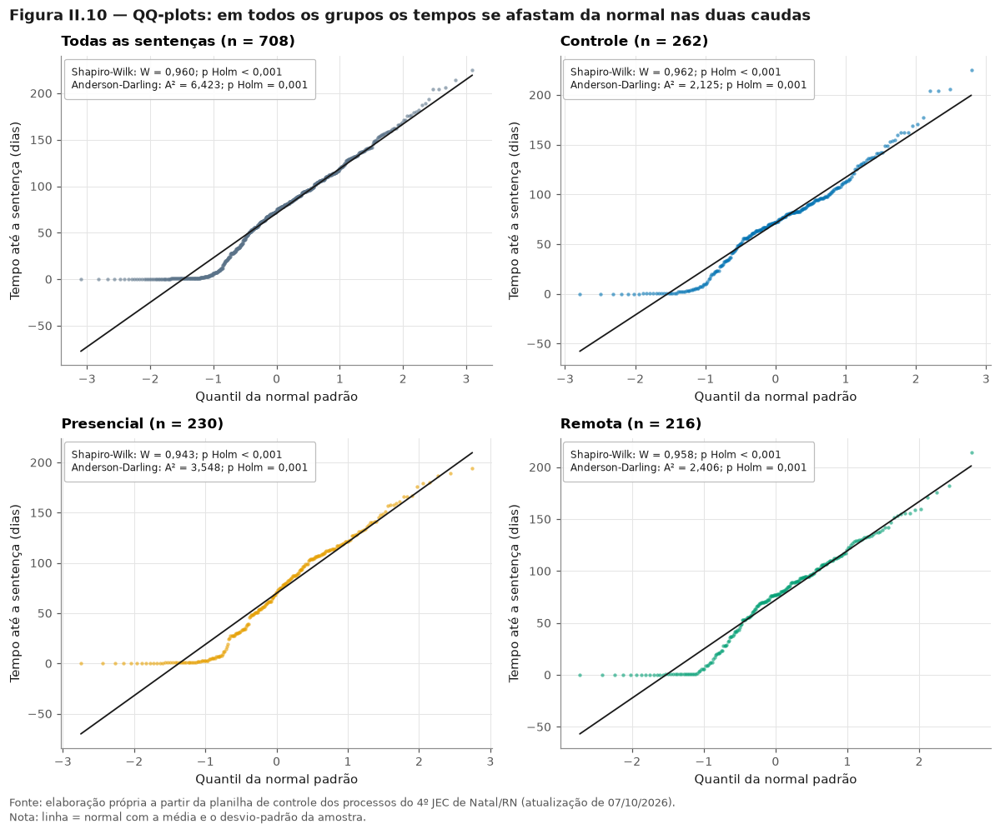

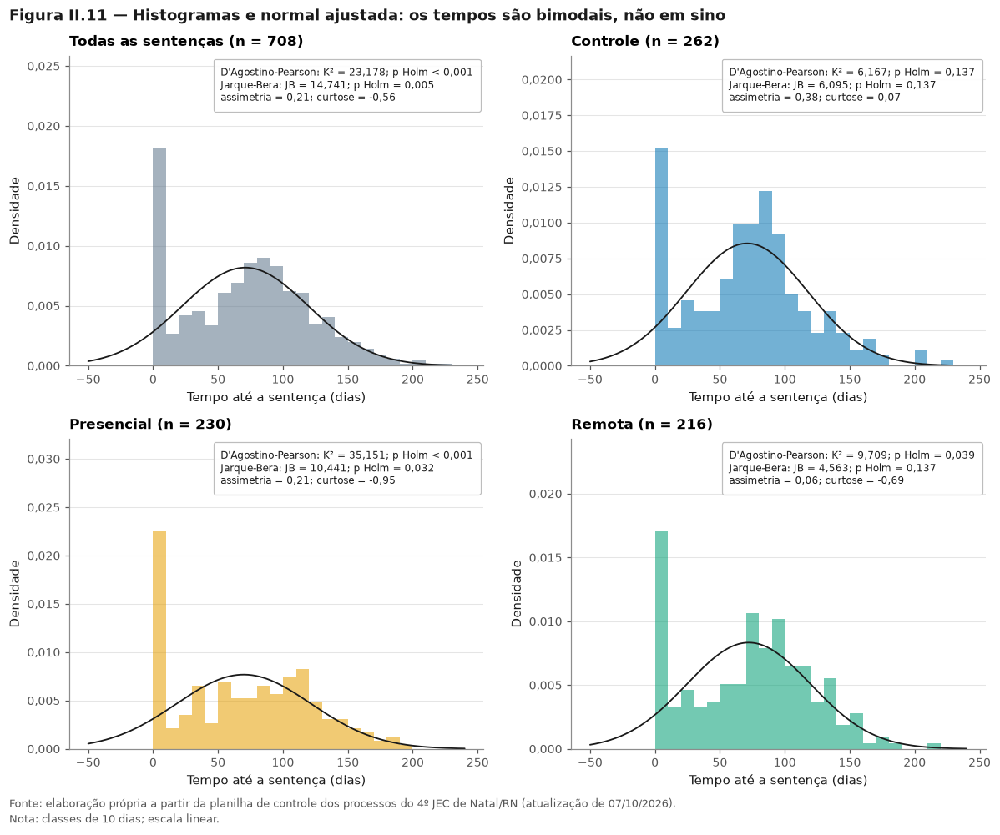

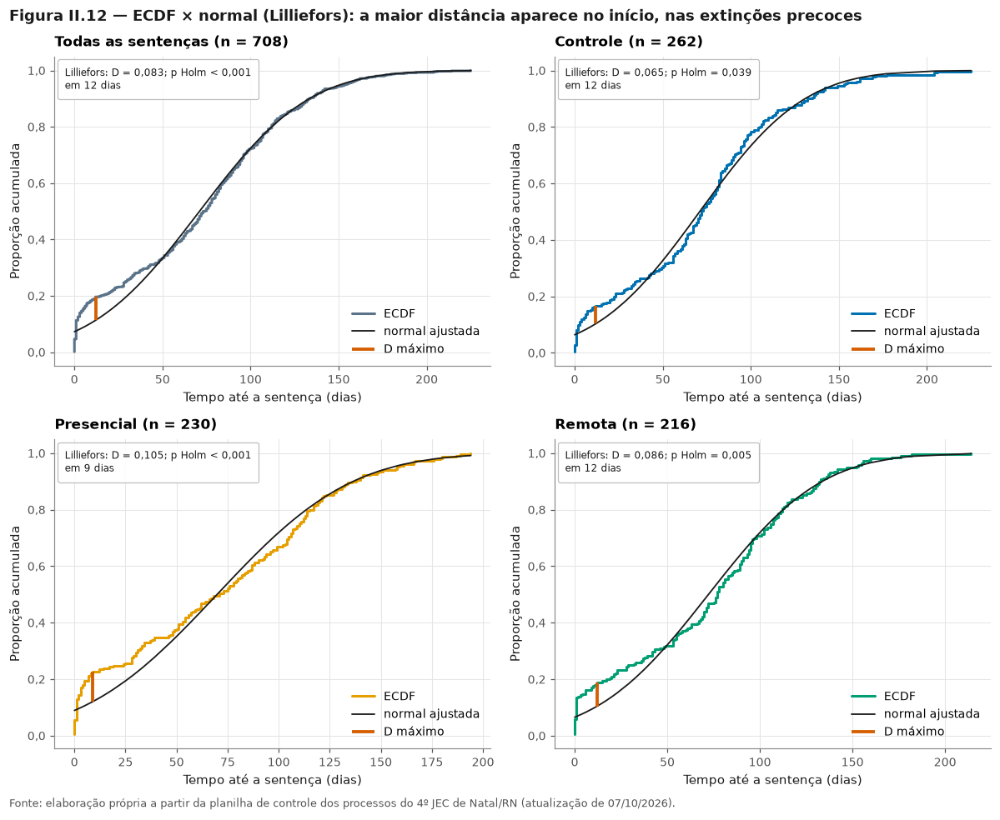

In [49]:
cores_amostra = {'Todas as sentenças': '#5B7389'} | CORES_GRUPO


def p_norm(amostra, teste):
    linha = tab_norm[(tab_norm['Amostra'] == amostra) & (tab_norm['Teste'] == teste)].iloc[0]
    return f"{teste}: {linha['Estatística']}; p Holm {'< 0,001' if linha['p (Holm)'] < 0.001 else '= ' + fmt_p(linha['p (Holm)'])}"


# (1) QQ-plots: Shapiro-Wilk e Anderson-Darling
fig, ax = plt.subplots(2, 2, figsize=(11, 8.5))
for a, (nome, x) in zip(ax.flat, AMOSTRAS_NORM.items()):
    x = x.to_numpy(float); cor = cores_amostra[nome]
    (osm, osr), (incl, inter, r) = stats.probplot(x, dist='norm')
    a.scatter(osm, osr, s=8, color=cor, alpha=0.6, lw=0)
    a.plot(osm, inter + incl * osm, color=TINTA, lw=1.2)
    a.set_title(f'{nome} (n = {len(x)})')
    a.set_xlabel('Quantil da normal padrão'); a.set_ylabel(ROTULOS['tempo_sentenca'])
    a.grid(axis='both', visible=True)
    anotar_teste(a, p_norm(nome, 'Shapiro-Wilk') + '\n' + p_norm(nome, 'Anderson-Darling'), loc='upper left', tamanho=8)
figura(fig, 'exp_norm_qq', 'QQ-plots: em todos os grupos os tempos se afastam da normal nas duas caudas', secao='2.3',
       nota='linha = normal com a média e o desvio-padrão da amostra.')

# (2) Histogramas com a normal ajustada: D'Agostino-Pearson e Jarque-Bera
fig, ax = plt.subplots(2, 2, figsize=(11, 8.5))
for a, (nome, x) in zip(ax.flat, AMOSTRAS_NORM.items()):
    x = x.to_numpy(float); cor = cores_amostra[nome]
    a.hist(x, bins=np.arange(0, 240, 10), density=True, color=cor, alpha=0.55, edgecolor='white')
    grade = np.linspace(-50, 240, 300)
    a.plot(grade, stats.norm.pdf(grade, x.mean(), x.std(ddof=1)), color=TINTA, lw=1.2, label='normal ajustada')
    a.set_title(f'{nome} (n = {len(x)})')
    a.set_xlabel(ROTULOS['tempo_sentenca']); a.set_ylabel('Densidade')
    a.ticklabel_format(axis='y', style='plain')
    anotar_teste(a, p_norm(nome, "D'Agostino-Pearson") + '\n' + p_norm(nome, 'Jarque-Bera')
                 + f'\nassimetria = {fmt_br(stats.skew(x, bias=False), 2)}; curtose = {fmt_br(stats.kurtosis(x, bias=False), 2)}',
                 loc='upper right', tamanho=8)
    a.set_ylim(0, a.get_ylim()[1] * 1.35)
figura(fig, 'exp_norm_hist', 'Histogramas e normal ajustada: os tempos são bimodais, não em sino', secao='2.3',
       nota='classes de 10 dias; escala linear.')

# (3) ECDF × normal: Lilliefors
fig, ax = plt.subplots(2, 2, figsize=(11, 8.5))
for a, (nome, x) in zip(ax.flat, AMOSTRAS_NORM.items()):
    x = x.to_numpy(float); cor = cores_amostra[nome]
    xs = np.sort(x); ecdf = np.arange(1, len(xs) + 1) / len(xs)
    fi = stats.norm.cdf(xs, x.mean(), x.std(ddof=1))
    k = np.argmax(np.abs(ecdf - fi))
    a.step(xs, ecdf, where='post', color=cor, label='ECDF')
    a.plot(xs, fi, color=TINTA, lw=1.2, label='normal ajustada')
    a.vlines(xs[k], min(ecdf[k], fi[k]), max(ecdf[k], fi[k]), color=DESTAQUE, lw=2.5, label='D máximo')
    a.set_title(f'{nome} (n = {len(x)})')
    a.set_xlabel(ROTULOS['tempo_sentenca']); a.set_ylabel('Proporção acumulada')
    a.grid(axis='both', visible=True); a.legend(loc='lower right')
    anotar_teste(a, p_norm(nome, 'Lilliefors') + f'\nem {fmt_br(xs[k], 0)} dias', loc='upper left', tamanho=8)
figura(fig, 'exp_norm_ecdf', 'ECDF × normal (Lilliefors): a maior distância aparece no início, nas extinções precoces',
       secao='2.3')

**Leitura. A normalidade é rejeitada, como se esperava, e a rejeição se deve à forma da distribuição, não a um detalhe.**

- **Total das sentenças (n = 708):** os cinco testes rejeitam H0 após Holm (Shapiro-Wilk W = 0,960; D'Agostino K² = 23,2; Anderson-Darling A² = 6,42; Lilliefors D = 0,083; Jarque-Bera JB = 14,7; todos com p ajustado ≤ 0,005).
- **Por grupo:** de 20 testes, 17 rejeitam. Os únicos que não rejeitam são os baseados em momentos (D'Agostino e Jarque-Bera) no Controle e o Jarque-Bera na Remota. Isso é coerente com os gráficos: a assimetria e a curtose desses grupos estão perto de zero (Controle: 0,38 e 0,07; Remota: 0,06 e −0,69), e os testes de momentos não "veem" a bimodalidade. Shapiro-Wilk, Anderson-Darling e Lilliefors, que comparam a forma inteira, rejeitam em todos os grupos.
- **Gráficos.** Os QQ-plots mostram o mesmo patamar junto de zero em todos os grupos (a massa de extinções precoces); os histogramas mostram o pico em 0 a 10 dias separado da moda principal; e a maior distância entre a ECDF e a normal (Lilliefors) está sempre entre 9 e 12 dias, exatamente na transição entre os dois "relógios".
- **Consequências.** (i) A comparação dos tempos dos sentenciados na Parte III deve usar testes não paramétricos (Kruskal-Wallis, Mann-Whitney), e não ANOVA ou teste t; (ii) mais importante, a pergunta relevante para os dados censurados não é a normalidade, mas a forma da função de sobrevivência e do risco, examinada na seção 2.4; (iii) o teste do notebook do professor em uma subamostra de 500 casos com censurados misturados (E22), com Shapiro-Wilk rejeitando e D'Agostino não, refletia essa mesma diferença entre testes de forma e testes de momentos, e não uma ambiguidade dos dados.

## 2.4 Ajuste de distribuições ao tempo **com censura**

**Por que com censura.** O notebook do professor ajustou Weibull, gama, log-normal e exponencial por máxima verossimilhança aos 943 tempos como se fossem todos completos, descartou os zeros e deixou o parâmetro de locação livre (E25). Com censura, a verossimilhança correta é (COLOSIMO; GIOLO, 2006, cap. 3):

L(θ) = ∏ f(tᵢ; θ)^δᵢ · S(tᵢ; θ)^(1 − δᵢ),

em que os sentenciados contribuem com a densidade e os censurados, com a probabilidade de durar **mais** do que o tempo observado. Usa-se `tempo_pos` (zeros → 0,5 dia) e `evento` (redistribuição como censura; a alternativa de riscos competitivos fica para a Parte IV).

**Modelos** (COLOSIMO; GIOLO, 2006, p. 70-81; MORETTIN; SINGER, 2021, p. 246):

| Modelo | Parâmetros | Forma do risco h(t) |
|---|---|---|
| Exponencial | 1 | constante |
| Weibull | 2 | monótona (crescente se ρ > 1) |
| Log-normal | 2 | sobe e depois desce |
| Log-logística | 2 | monótona decrescente ou sobe e desce |
| Gama generalizada | 3 | contém as anteriores (exceto a log-logística) como casos particulares |
| Exponencial por partes | 7 | constante em cada janela (0-15, 15-30, 30-60, 60-90, 90-120, 120-150, > 150 dias): estimativa quase não paramétrica da forma do risco |

**Seleção:** (i) AIC e BIC (menor é melhor; o BIC penaliza mais os parâmetros); (ii) **teste da razão de verossimilhanças (TRV)** dos modelos encaixados na gama generalizada: TRV = 2[log L(gama gen.) − log L(modelo)] ~ χ² com g.l. = diferença de parâmetros (COLOSIMO; GIOLO, 2006, p. 93-94, 100-101). H0: o modelo mais simples é suficiente; H1: a gama generalizada ajusta melhor. A log-logística não é encaixada e só se compara por AIC; (iii) gráficos (p. 96-99).

In [50]:
T_pos = d2['tempo_pos'].astype(float).to_numpy()
E_ev = d2['E'].to_numpy()
n_obs = len(T_pos)
MODELOS = {'Exponencial': ExponentialFitter(), 'Weibull': WeibullFitter(), 'Log-normal': LogNormalFitter(),
           'Log-logística': LogLogisticFitter(), 'Gama generalizada': GeneralizedGammaFitter(),
           'Exponencial por partes': PiecewiseExponentialFitter(breakpoints=[15, 30, 60, 90, 120, 150])}
ajustes = {nome: f.fit(T_pos, E_ev, label=nome) for nome, f in MODELOS.items()}


def mediana_modelo(f, p=0.5):
    # Tempo t com S(t) = p (raiz numérica; o median_survival_time_ do lifelines falha com o numpy atual)
    from scipy.optimize import brentq
    return brentq(lambda t: float(f.survival_function_at_times(np.array([t])).iloc[0]) - p, 1e-6, 5000)


linhas = []
for nome, f in ajustes.items():
    k = len(f.params_)
    linhas.append({'Modelo': nome, 'parâmetros': k, 'log L': f.log_likelihood_, 'AIC': f.AIC_,
                   'BIC': k * np.log(n_obs) - 2 * f.log_likelihood_,
                   'mediana S(t)=0,5 (dias)': mediana_modelo(f),
                   'S(90) (prob. sem sentença aos 90 d)': float(f.survival_function_at_times(np.array([90.0])).iloc[0])})
tab_ajuste = pd.DataFrame(linhas).set_index('Modelo')
tab_ajuste['ΔAIC'] = tab_ajuste['AIC'] - tab_ajuste['AIC'].min()
tabela(tab_ajuste, 'exp_ajuste', 'Modelos paramétricos ajustados com censura (938 processos): verossimilhança e critérios',
       secao='2.4', formatos={'S(90) (prob. sem sentença aos 90 d)': 3, 'parâmetros': 'int'}, casas=1,
       destaque=lambda t: t['AIC'].eq(t['AIC'].min()).to_numpy(),
       nota='menor AIC/BIC = melhor; linha destacada = menor AIC.')

gg = ajustes['Gama generalizada']
print('Parâmetros da gama generalizada:', gg.params_.round(4).to_dict())
trv = []
for nome, gl in [('Exponencial', 2), ('Weibull', 1), ('Log-normal', 1)]:
    est = 2 * (gg.log_likelihood_ - ajustes[nome].log_likelihood_)
    trv.append({'H0 (modelo encaixado)': nome, 'TRV': est, 'g.l.': gl, 'p': stats.chi2.sf(est, gl)})
tab_trv = pd.DataFrame(trv)
tab_trv['p (Holm)'] = multipletests(tab_trv['p'], method='holm')[1]
tabela(tab_trv, 'exp_trv', 'Teste da razão de verossimilhanças contra a gama generalizada (H0: o modelo encaixado basta)',
       secao='2.4', casas=2, destaque='p (Holm)')

Modelo,parâmetros,log L,AIC,BIC,"mediana S(t)=0,5 (dias)",S(90) (prob. sem sentença aos 90 d),ΔAIC
Exponencial,1,"-3.995,1","7.992,1","7.997,0","72,0","0,420","209,6"
Weibull,2,"-3.995,0","7.993,9","8.003,6","71,6","0,420","211,4"
Log-normal,2,"-4.149,8","8.303,6","8.313,3","62,6","0,421","521,0"
Log-logística,2,"-4.095,3","8.194,7","8.204,4","76,2","0,454","412,1"
Gama generalizada,3,"-3.916,8","7.839,7","7.854,2","75,9","0,434","57,1"
Exponencial por partes,7,"-3.884,3","7.782,5","7.816,4","88,2","0,490","0,0"


Parâmetros da gama generalizada: {'mu_': 4.963, 'ln_sigma_': -0.5932, 'lambda_': 2.451}


H0 (modelo encaixado),TRV,g.l.,p,p (Holm)
Exponencial,"156,46",2,"< 0,001","< 0,001"
Weibull,"156,27",1,"< 0,001","< 0,001"
Log-normal,"465,92",1,"< 0,001","< 0,001"


**Gráficos de adequação.** Cada teste ou critério tem o seu gráfico:

1. **QQ-plots para dados censurados** (`lifelines.plotting.qq_plot`): quantis do modelo contra quantis do KM; pontos sobre a diagonal = bom ajuste. Disponível para os quatro modelos de dois parâmetros ou menos.
2. **Ŝ_KM(t) × Ŝ_modelo(t)** (COLOSIMO; GIOLO, 2006, p. 96-97): para cada tempo de evento, a sobrevivência estimada pelo KM contra a do modelo; o modelo adequado fica perto de y = x. É o gráfico que acompanha o TRV.
3. **Sobreposição das curvas S(t)** paramétricas ao Kaplan-Meier (descendente, com IC de 95%), um painel por modelo, para que cada curva seja comparada sozinha com o KM. É só uma verificação visual: a análise do KM, por grupo, está na Parte IV.

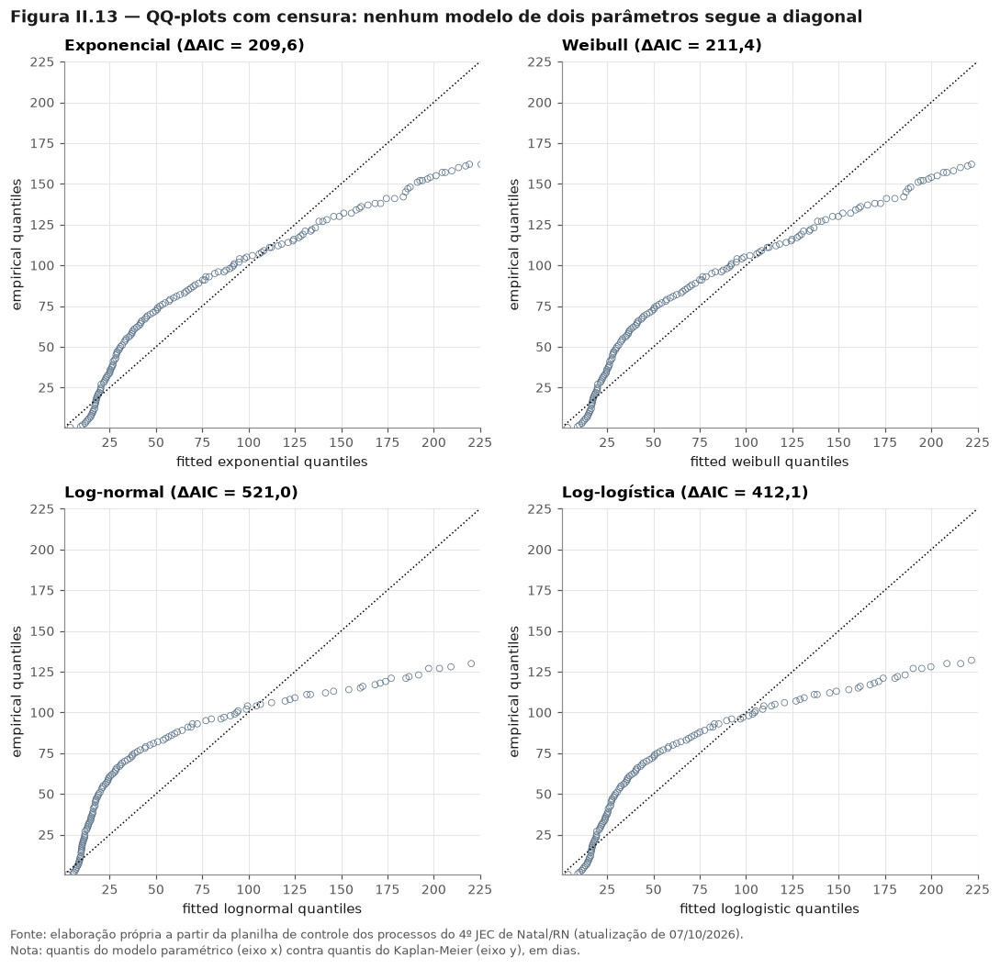

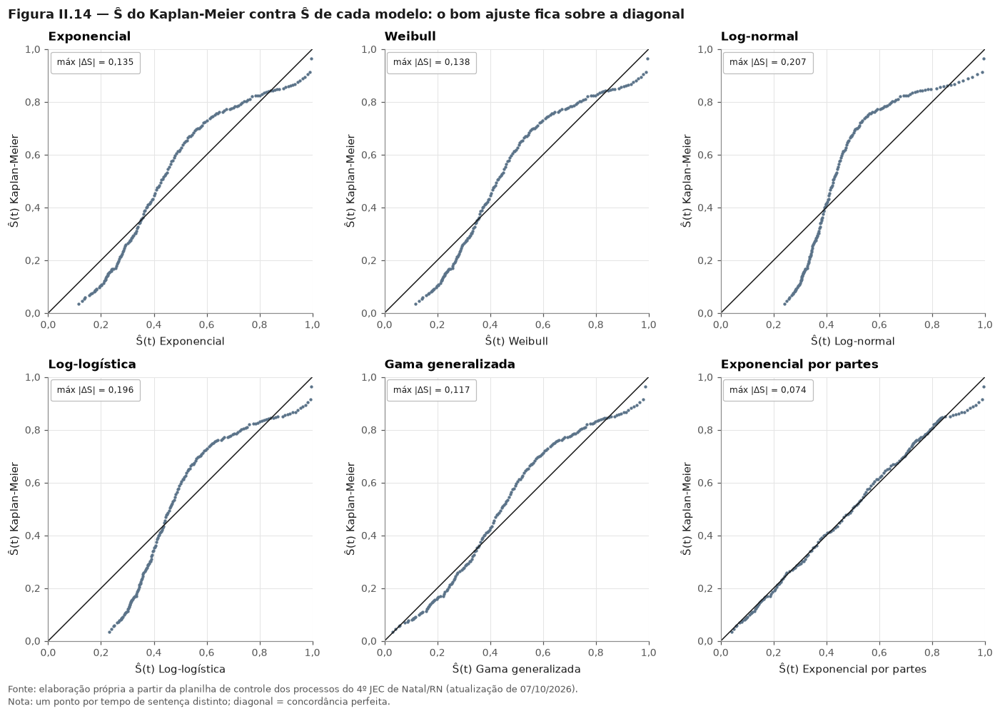

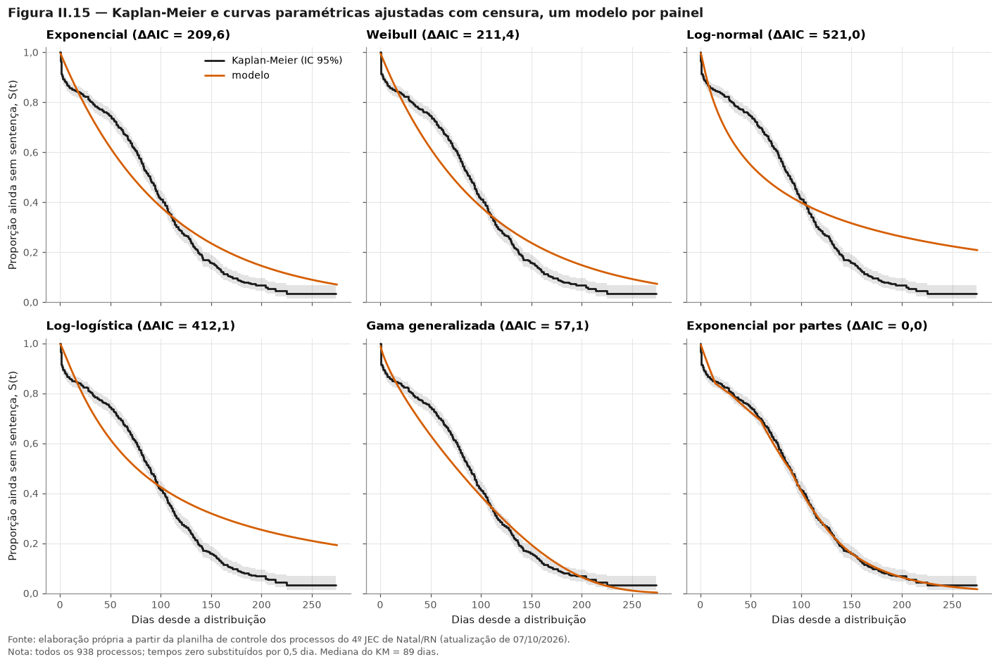

In [51]:
kmf_total = KaplanMeierFitter().fit(T_pos, E_ev, label='Kaplan-Meier')
fig, ax = plt.subplots(2, 2, figsize=(10, 9))
for a, nome in zip(ax.flat, ['Exponencial', 'Weibull', 'Log-normal', 'Log-logística']):
    qq_plot(ajustes[nome], ax=a, scatter_color='#5B7389')
    a.set_title(f'{nome} (ΔAIC = {fmt_br(tab_ajuste.loc[nome, "ΔAIC"], 1)})')
    a.grid(axis='both', visible=True)
    if a.get_legend() is not None:
        a.get_legend().remove()
figura(fig, 'exp_qq_censurado', 'QQ-plots com censura: nenhum modelo de dois parâmetros segue a diagonal', secao='2.4',
       nota='quantis do modelo paramétrico (eixo x) contra quantis do Kaplan-Meier (eixo y), em dias.')

t_ev = np.sort(np.unique(T_pos[E_ev == 1]))
s_km = kmf_total.survival_function_at_times(t_ev).to_numpy()
fig, ax = plt.subplots(2, 3, figsize=(13, 8.5))
for a, (nome, f) in zip(ax.flat, ajustes.items()):
    s_mod = f.survival_function_at_times(t_ev).to_numpy()
    a.scatter(s_mod, s_km, s=8, color='#5B7389', lw=0)
    a.plot([0, 1], [0, 1], color=TINTA, lw=1)
    a.set_xlabel(f'Ŝ(t) {nome}'); a.set_ylabel('Ŝ(t) Kaplan-Meier')
    a.set_xlim(0, 1); a.set_ylim(0, 1); a.set_aspect('equal'); a.grid(axis='both', visible=True)
    a.set_title(nome)
    anotar_teste(a, f'máx |ΔS| = {fmt_br(np.max(np.abs(s_mod - s_km)), 3)}', loc='upper left', tamanho=8)
figura(fig, 'exp_skm_smodelo', 'Ŝ do Kaplan-Meier contra Ŝ de cada modelo: o bom ajuste fica sobre a diagonal', secao='2.4',
       nota='um ponto por tempo de sentença distinto; diagonal = concordância perfeita.')

grade = np.linspace(0.5, 275, 400)
ci_km = kmf_total.confidence_interval_survival_function_
fig, ax = plt.subplots(2, 3, figsize=(13, 8), sharex=True, sharey=True)
for a, (nome, f) in zip(ax.flat, ajustes.items()):
    a.fill_between(ci_km.index, ci_km.iloc[:, 0], ci_km.iloc[:, 1], step='post', color=TINTA, alpha=0.12, lw=0)
    a.step(kmf_total.survival_function_.index, kmf_total.survival_function_.iloc[:, 0], where='post', color=TINTA,
           lw=1.8, label='Kaplan-Meier (IC 95%)')
    a.plot(grade, f.survival_function_at_times(grade), color=DESTAQUE, lw=1.8, label='modelo')
    a.set_title(f'{nome} (ΔAIC = {fmt_br(tab_ajuste.loc[nome, "ΔAIC"], 1)})')
    a.set_ylim(0, 1.02); a.grid(axis='both', visible=True)
for a in ax[1]:
    a.set_xlabel(ROTULOS['dias'])
for a in ax[:, 0]:
    a.set_ylabel(ROTULOS['S'])
ax[0, 0].legend(loc='upper right')
figura(fig, 'exp_km_parametricos', 'Kaplan-Meier e curvas paramétricas ajustadas com censura, um modelo por painel',
       secao='2.4', nota=f'todos os 938 processos; tempos zero substituídos por 0,5 dia. Mediana do KM = '
                         f'{fmt_br(kmf_total.median_survival_time_, 0)} dias.')

**Leitura. Nenhuma distribuição paramétrica usual descreve bem o tempo até a sentença; a forma do risco é não monótona.**

- **Critérios de informação.** A exponencial por partes (7 parâmetros) tem o menor AIC (7.782,5) e o menor BIC (7.816,4). Entre os paramétricos, a gama generalizada é a melhor (AIC 7.839,7; ΔAIC = 57), seguida de longe pela exponencial (7.992,1) e pela Weibull (7.993,9), que são praticamente o mesmo modelo (o parâmetro de forma da Weibull é ≈ 1). A log-logística (8.194,7) e a log-normal (8.303,6) são as piores.
- **TRV.** A gama generalizada rejeita os três modelos encaixados: contra a exponencial, TRV = 156,5 com 2 g.l.; contra a Weibull, 156,3 com 1 g.l.; contra a log-normal, 465,9 com 1 g.l. (todos p < 0,001, também após Holm). O parâmetro λ estimado (2,45) está longe tanto de 1 (Weibull) quanto de 0 (log-normal) (COLOSIMO; GIOLO, 2006, p. 93-94).
- **Gráficos.** Os QQ-plots com censura e os gráficos Ŝ_KM × Ŝ_modelo têm a forma de "S" em todos os modelos de 2 parâmetros: o maior afastamento entre o KM e o modelo é de 0,135 (exponencial), 0,138 (Weibull), 0,196 (log-logística) e 0,207 (log-normal). A gama generalizada reduz para 0,117, e só a exponencial por partes acompanha o KM de perto (0,074). Na sobreposição de curvas, os modelos de 2 parâmetros cruzam o KM: subestimam S(t) entre 20 e 100 dias e a superestimam depois de 120 dias.
- **Medianas implícitas.** A exponencial por partes dá 88,2 dias, próxima da mediana do KM (89); os demais modelos dão de 62,6 (log-normal) a 76,2 (log-logística). Um modelo mal especificado erra, portanto, a quantidade mais importante para a gestão.
- **Consequência.** Os modelos AFT da Parte IV devem ser lidos com cautela e acompanhados de diagnóstico (Cox-Snell); as conclusões principais devem vir de métodos que não impõem forma ao risco (Kaplan-Meier, log-rank, Cox, RMST).

### 2.4.1 Forma da função de risco

A função de risco h(t) é a taxa instantânea de sentença entre os processos ainda sem sentença no dia *t*. Comparam-se: o risco estimado por Nelson-Aalen suavizado (núcleo de 15 dias; não paramétrico), o da exponencial por partes (degraus) e os dos modelos paramétricos, um modelo por painel, sempre contra a mesma curva não paramétrica. **Como ler:** um risco crescente significa que, quanto mais antigo o processo, maior a chance de ser sentenciado no dia seguinte (fila que anda); um pico no início indica extinções precoces; um risco que cai na cauda indica processos "travados".

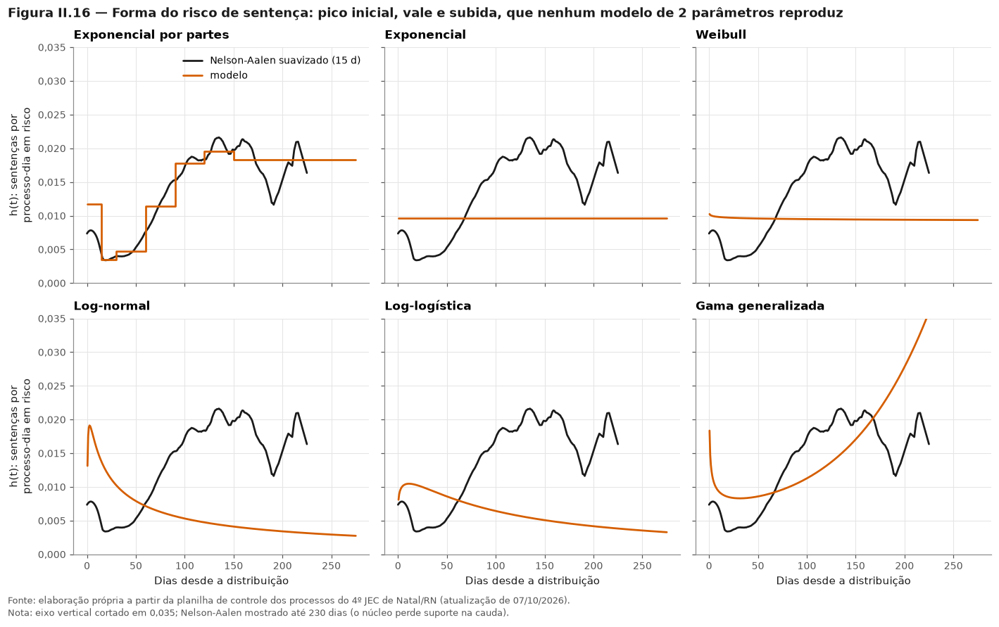

Janela (dias),Risco diário (sentenças/processo-dia),Meia-vida na janela (dias)
0–15,"0,0117","59,3"
15–30,"0,0035","198,6"
30–60,"0,0047","146,1"
60–90,"0,0114","60,6"
90–120,"0,0178","38,9"
120–150,"0,0196","35,4"
150–275,"0,0183","37,9"


In [52]:
naf = NelsonAalenFitter().fit(T_pos, E_ev)
h_suave = naf.smoothed_hazard_(bandwidth=15)
pwe = ajustes['Exponencial por partes']
h_suave = h_suave[h_suave.index <= 230]   # o núcleo perde suporte na cauda (poucos processos em risco)
cortes_pwe = [0] + [float(b) for b in pwe.breakpoints if np.isfinite(b)] + [275]
taxas = 1 / pwe.summary.loc[[p for p in pwe.summary.index if p.startswith('lambda_')], 'coef'].to_numpy()
fig, ax = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True, sharey=True)
paineis_h = ['Exponencial por partes', 'Exponencial', 'Weibull', 'Log-normal', 'Log-logística', 'Gama generalizada']
for a, nome in zip(ax.flat, paineis_h):
    a.plot(h_suave.index, h_suave.iloc[:, 0], color=TINTA, lw=1.8, label='Nelson-Aalen suavizado (15 d)')
    if nome == 'Exponencial por partes':
        a.step(cortes_pwe, list(taxas) + [taxas[-1]], where='post', color=DESTAQUE, lw=1.8, label='modelo')
    else:
        a.plot(grade, ajustes[nome].hazard_at_times(grade), color=DESTAQUE, lw=1.8, label='modelo')
    a.set_title(nome); a.set_ylim(0, 0.035); a.grid(axis='both', visible=True)
for a in ax[1]:
    a.set_xlabel(ROTULOS['dias'])
for a in ax[:, 0]:
    a.set_ylabel('h(t): sentenças por\nprocesso-dia em risco')
ax[0, 0].legend(loc='upper right')
figura(fig, 'exp_risco', 'Forma do risco de sentença: pico inicial, vale e subida, que nenhum modelo de 2 parâmetros reproduz',
       secao='2.4.1', nota='eixo vertical cortado em 0,035; Nelson-Aalen mostrado até 230 dias (o núcleo perde suporte na cauda).')
tab_pwe = pd.DataFrame({'janela (dias)': [f'{a:g}–{b:g}' for a, b in zip(cortes_pwe[:-1], cortes_pwe[1:])],
                        'risco diário': taxas, 'meia-vida na janela (dias)': np.log(2) / taxas})
tabela(tab_pwe.rename(columns={'janela (dias)': 'Janela (dias)', 'risco diário': 'Risco diário (sentenças/processo-dia)',
                               'meia-vida na janela (dias)': 'Meia-vida na janela (dias)'}),
       'exp_pwe', 'Exponencial por partes: risco diário de sentença em cada janela de tempo', secao='2.4.1',
       formatos={'Risco diário (sentenças/processo-dia)': 4, 'Meia-vida na janela (dias)': 1})

**Leitura. O risco de sentença tem três fases.**

1. **0 a 15 dias: pico inicial** (≈ 0,0117 sentença por processo-dia), produzido pelas extinções imediatas sem mérito e pelas redistribuições;
2. **15 a 60 dias: vale** (0,0035 a 0,0047), o período em que o processo "espera" a citação, a contestação ou a pauta da audiência; quase ninguém é sentenciado;
3. **depois de 60 dias: subida e platô** (0,0114 entre 60 e 90 dias; 0,018 a 0,020 após 90 dias), quando os processos chegam à conclusão para sentença. Nesse platô, a meia-vida é de 35 a 39 dias: metade dos processos ainda sem sentença aos 90 dias é sentenciada em pouco mais de um mês.

Essa forma em "banheira invertida e depois subida" não pertence a nenhuma família padrão: a exponencial e a Weibull impõem um risco constante (≈ 0,0097); a log-normal e a log-logística, um risco que cai depois do início (o oposto do observado); e a gama generalizada capta a subida, mas a extrapola sem limite após 150 dias. Juridicamente, o vale entre 15 e 60 dias é o tempo processual mínimo do contraditório (citação, prazo de defesa e, nos tratados, a audiência). É nesse trecho que a AC obrigatória pode alongar o rito, o que se verifica na seção 2.6.1 e na Parte IV. Quando os riscos de dois grupos mudam de ordem ao longo do tempo, o log-rank perde poder, o que justifica testes ponderados e o RMST na Parte IV.

### 2.4.2 Comparação: ajuste ingênuo só com os sentenciados (`scipy.stats`)

Para mostrar o que muda, ajustam-se as mesmas famílias (exponencial, Weibull, gama, log-normal e log-logística, todas com locação fixa em zero, `floc = 0`) **apenas às 708 sentenças**, como se fossem a população. O teste de Kolmogorov-Smirnov (H0: as sentenças seguem a distribuição ajustada) é exibido com a ressalva de que, com parâmetros estimados nos mesmos dados, o p-valor do KS é conservador (é o problema que o Lilliefors corrige para a normal). O ponto principal é a **mediana implícita**: o ajuste só nos sentenciados descreve a distribuição *condicional* e subestima a duração, porque ignora os 230 processos que ainda não terminaram. O ajuste com censura (seção 2.4) é o correto.

Família,log L,AIC,KS D,p (KS),Mediana só sentenças (dias),Mediana com censura (dias),ΔAIC
Exponencial,"-3.726,0","7.454,0","0,183","< 0,001","49,2","72,0","5,1"
Weibull,"-3.725,3","7.454,6","0,175","< 0,001","50,5","71,6","5,7"
Gama,"-3.722,4","7.448,8","0,198","< 0,001","46,7",–,"0,0"
Log-normal,"-3.912,9","7.829,8","0,247","< 0,001","36,6","62,6","380,9"
Log-logística,"-3.876,7","7.757,4","0,175","< 0,001","51,5","76,2","308,6"


Mediana empírica das sentenças: 73,5 dias | mediana do KM (todos, com censura): 89,0 dias


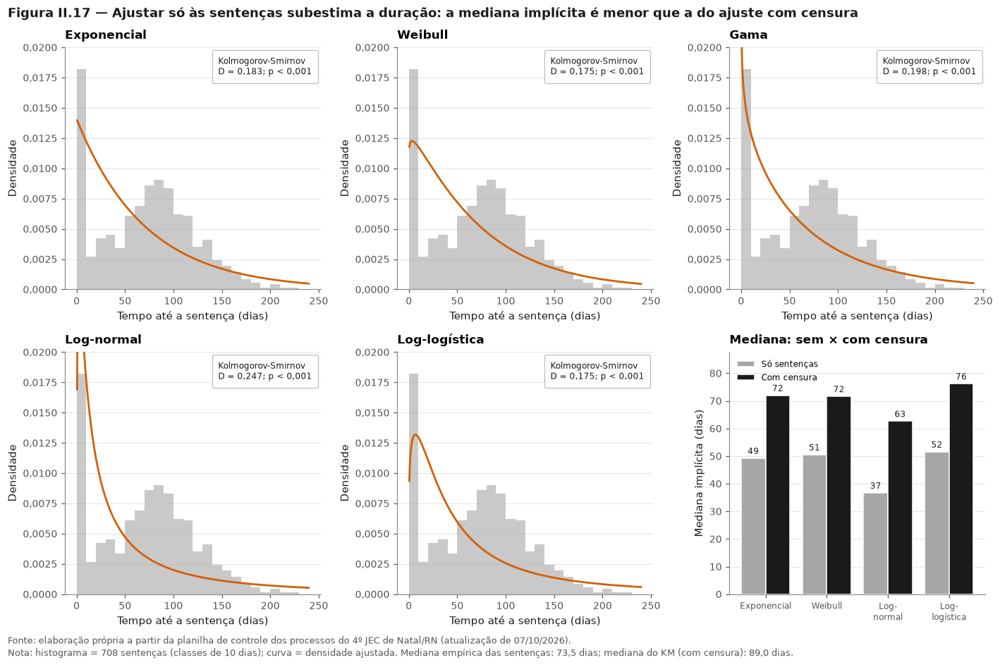

In [53]:
x_sent = sent['tempo_pos'].to_numpy(float)
FAMILIAS = {'Exponencial': stats.expon, 'Weibull': stats.weibull_min, 'Gama': stats.gamma,
            'Log-normal': stats.lognorm, 'Log-logística': stats.fisk}
linhas, dens = [], {}
for nome, dist in FAMILIAS.items():
    par = dist.fit(x_sent, floc=0)
    ll = dist.logpdf(x_sent, *par).sum()
    k = len(par) - 1
    ks = stats.kstest(x_sent, dist.cdf, args=par)
    mediana_cens = mediana_modelo(ajustes[nome]) if nome in ajustes else np.nan
    linhas.append({'Família': nome, 'log L': ll, 'AIC': 2 * k - 2 * ll, 'KS D': ks.statistic, 'KS p': ks.pvalue,
                   'mediana (só sentenças)': dist.median(*par), 'mediana (ajuste com censura)': mediana_cens})
    dens[nome] = (dist, par)
tab_scipy = pd.DataFrame(linhas).set_index('Família')
tab_scipy['ΔAIC'] = tab_scipy['AIC'] - tab_scipy['AIC'].min()
tabela(tab_scipy.rename(columns={'KS p': 'p (KS)', 'mediana (só sentenças)': 'Mediana só sentenças (dias)',
                                 'mediana (ajuste com censura)': 'Mediana com censura (dias)'}),
       'exp_ajuste_ingenuo', 'Ajuste ingênuo só às 708 sentenças (sem censura) e mediana implícita', secao='2.4.2',
       formatos={'KS D': 3}, casas=1, nota='o p do KS com parâmetros estimados nos mesmos dados é conservador.')
print(f'Mediana empírica das sentenças: {fmt_br(np.median(x_sent))} dias | '
      f'mediana do KM (todos, com censura): {fmt_br(kmf_total.median_survival_time_)} dias')

fig, ax = plt.subplots(2, 3, figsize=(13, 8))
grade2 = np.linspace(0.5, 240, 400)
for a, (nome, (dist, par)) in zip(ax.flat, dens.items()):
    a.hist(x_sent, bins=np.arange(0, 240, 10), density=True, color=CINZA, alpha=0.6, edgecolor='white')
    a.plot(grade2, dist.pdf(grade2, *par), lw=1.8, color=DESTAQUE)
    a.set_ylim(0, 0.02); a.set_title(nome)
    a.set_xlabel(ROTULOS['tempo_sentenca']); a.set_ylabel('Densidade')
    anotar_teste(a, texto_teste('Kolmogorov-Smirnov', f'D = {fmt_br(tab_scipy.loc[nome, "KS D"], 3)}',
                                tab_scipy.loc[nome, 'KS p']), loc='upper right', tamanho=8)
med = tab_scipy[['mediana (só sentenças)', 'mediana (ajuste com censura)']].rename(
    columns={'mediana (só sentenças)': 'Só sentenças', 'mediana (ajuste com censura)': 'Com censura'})
barras_agrupadas(ax[1, 2], med.dropna(), cores={'Só sentenças': CINZA, 'Com censura': TINTA}, rotular=True,
                 fmt=lambda v: fmt_br(v, 0), quebrar=9, ylabel='Mediana implícita (dias)')
ax[1, 2].set_title('Mediana: sem × com censura')
ax[1, 2].legend(loc='upper left', fontsize=8)
ax[1, 2].tick_params(axis='x', labelsize=8)
figura(fig, 'exp_ajuste_ingenuo', 'Ajustar só às sentenças subestima a duração: a mediana implícita é menor que a do ajuste com censura',
       secao='2.4.2', nota=f'histograma = 708 sentenças (classes de 10 dias); curva = densidade ajustada. Mediana empírica das '
                         f'sentenças: {fmt_br(np.median(x_sent))} dias; mediana do KM (com censura): '
                         f'{fmt_br(kmf_total.median_survival_time_)} dias.')

**Leitura. Ajustar só os sentenciados produz distribuições "mais rápidas" do que a realidade.**

- Entre os ajustes ingênuos, a gama tem o menor AIC (7.448,8), com a exponencial e a Weibull a menos de 6 pontos; a log-normal e a log-logística ficam muito atrás. Mas **todas** são rejeitadas pelo KS (p < 0,001; D de 0,175 a 0,247), mesmo sendo esse p-valor conservador: nenhuma família unimodal acomoda o pico em zero e a moda em 80 a 100 dias.
- **O viés de seleção aparece nas medianas.** As medianas implícitas dos ajustes só com sentenças vão de 36,6 (log-normal) a 51,5 dias (log-logística); com censura, as mesmas famílias dão de 62,6 a 76,2 dias, e a mediana do KM é de 89 dias. Desprezar os 230 processos não sentenciados subestima a mediana em 15 a 50 dias.
- É por isso que o ajuste do notebook do professor (E25), feito como se todos os tempos fossem completos e sem os zeros, não serve para descrever a duração: ele descreve, no máximo, a distribuição condicional dos processos que já terminaram.

## 2.5 Modelos binomial e multinomial: o desenho e as proporções

Esta seção usa o modelo **binomial** (uma proporção) e o **multinomial** (várias categorias com probabilidades fixadas) para responder a perguntas univariadas sobre o desenho e sobre as taxas. Em cada caso: a hipótese, o teste, o IC e o gráfico. Os ICs de proporção são o **exato de Clopper-Pearson** (conservador, cobertura ≥ 95%) e o **de Wilson** (cobertura mais próxima de 95%, recomendado para proporções pequenas); o IC de Wald (p ± 1,96·EP) é evitado porque falha justamente nas taxas de acordo, próximas de zero.

### 2.5.1 (a) O sorteio produziu grupos equilibrados demais?

**Pergunta.** Se cada processo fosse sorteado de forma independente com probabilidade 1/3 para cada grupo (**aleatorização simples**), os tamanhos dos grupos seguiriam uma multinomial(n; 1/3, 1/3, 1/3). Divisões como **316/314/314** (as 944 linhas brutas) ou **313/314/311** (a base primária de 938) são compatíveis com isso?

- **Teste usual (cauda direita):** qui-quadrado de aderência, H0: p = (1/3, 1/3, 1/3); H1: algum grupo tem probabilidade diferente. Responde "os grupos são desiguais demais?".
- **Teste de "bom demais" (cauda esquerda):** P(X² ≤ X²_obs | H0), calculada **exatamente**, somando a probabilidade multinomial de todas as divisões (a, b, c) com a + b + c = n tão ou mais equilibradas que a observada. Um valor muito pequeno significa que, sob aleatorização simples, uma divisão tão equilibrada seria improvável, o que é evidência de **aleatorização restrita** (em blocos, urna sem reposição ou alternância), compatível com a informação de que o sorteio "seguiu rigorosamente a ordem de chegada" (questão 2.7).

A aleatorização restrita não é um defeito: é prática recomendada para equilibrar os grupos. Mas ela precisa ser documentada, porque (i) muda a análise da sequência (teste de corridas, Parte III) e (ii) se os blocos forem pequenos e conhecidos, o próximo grupo fica previsível.

In [54]:
def multinomial_exato(contagens, p=None):
    # Probabilidades exatas, sob multinomial(n; p), de X² <= X²_obs (cauda esquerda) e X² >= X²_obs (direita); k = 3
    contagens = np.asarray(contagens); n = int(contagens.sum())
    p = np.full(3, 1 / 3) if p is None else np.asarray(p)
    esp = n * p
    x2_obs = ((contagens - esp) ** 2 / esp).sum()
    esq = dir_ = 0.0
    for a in range(n + 1):
        b = np.arange(n - a + 1); c = n - a - b
        x2 = (a - esp[0]) ** 2 / esp[0] + (b - esp[1]) ** 2 / esp[1] + (c - esp[2]) ** 2 / esp[2]
        lp = (gammaln(n + 1) - gammaln(a + 1) - gammaln(b + 1) - gammaln(c + 1)
              + a * np.log(p[0]) + b * np.log(p[1]) + c * np.log(p[2]))
        pr = np.exp(lp)
        esq += pr[x2 <= x2_obs + 1e-9].sum()
        dir_ += pr[x2 >= x2_obs - 1e-9].sum()
    return x2_obs, esq, dir_


divisoes = {'944 linhas brutas': brutas['grupo'].value_counts().reindex(ORDEM_GRUPO).to_numpy(),
            '938 processos (base primária)': d2['grupo'].value_counts().reindex(ORDEM_GRUPO).to_numpy()}
linhas = []
for nome, cont in divisoes.items():
    x2, esq, dir_ = multinomial_exato(cont)
    linhas.append({'Base': nome, 'Controle': cont[0], 'Presencial': cont[1], 'Remota': cont[2],
                   'esperado (n/3)': cont.sum() / 3, 'X²': x2, 'p qui-quadrado (dir.)': stats.chi2.sf(x2, 2),
                   'p exato (dir.)': dir_, 'P(divisão tão equilibrada) exata (esq.)': esq,
                   'amplitude máx − mín': cont.max() - cont.min()})
tab_equilibrio = pd.DataFrame(linhas).set_index('Base')
tabela(tab_equilibrio, 'exp_equilibrio', 'Tamanhos dos grupos contra a aleatorização simples (multinomial 1/3, 1/3, 1/3)',
       secao='2.5.1', casas=2,
       formatos={'X²': 4, 'P(divisão tão equilibrada) exata (esq.)': lambda v: fmt_p(v, 4)},
       nota='cauda direita: os grupos são desiguais demais? Cauda esquerda: uma divisão tão equilibrada seria provável '
            'sob sorteio simples?')

# Monte Carlo: distribuição da amplitude (máx − mín) sob aleatorização simples
sim = RNG.multinomial(len(d2), [1 / 3] * 3, size=200_000)
amp_sim = sim.max(axis=1) - sim.min(axis=1)
x2_sim = ((sim - len(d2) / 3) ** 2 / (len(d2) / 3)).sum(axis=1)
amp_obs = tab_equilibrio.loc['938 processos (base primária)', 'amplitude máx − mín']
print(f'Monte Carlo (200.000 sorteios simples de 938): P(amplitude ≤ {amp_obs}) = {fmt_br((amp_sim <= amp_obs).mean(), 4)}; '
      f'amplitude mediana = {np.median(amp_sim):.0f} processos; P90 = {np.percentile(amp_sim, 90):.0f}')

Base,Controle,Presencial,Remota,esperado (n/3),X²,p qui-quadrado (dir.),p exato (dir.),P(divisão tão equilibrada) exata (esq.),amplitude máx − mín
944 linhas brutas,314,316,314,"314,67","0,0085","0,996","0,997","0,0052",2
938 processos (base primária),313,314,311,"312,67","0,0149","0,993","0,995","0,0105",3


Monte Carlo (200.000 sorteios simples de 938): P(amplitude ≤ 3) = 0,0106; amplitude mediana = 28 processos; P90 = 51


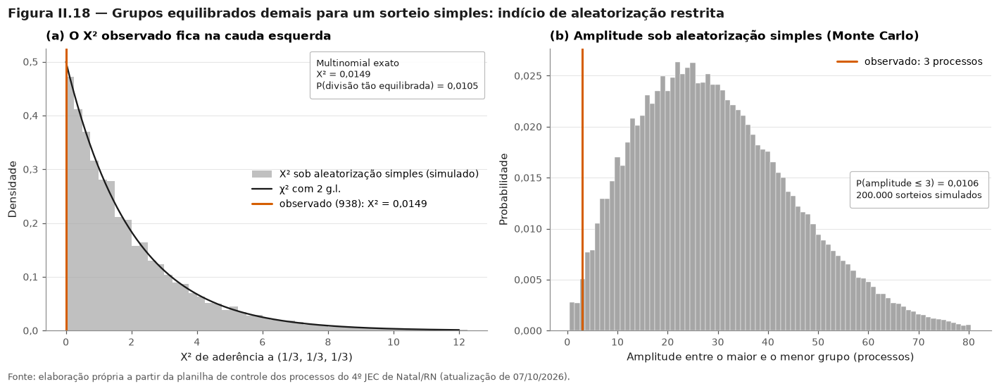

In [55]:
def p_igual(p):
    return 'p < 0,001' if p < 0.001 else f'p = {fmt_p(p)}'


fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
x2_938 = tab_equilibrio.loc['938 processos (base primária)', 'X²']
p_esq = tab_equilibrio.loc['938 processos (base primária)', 'P(divisão tão equilibrada) exata (esq.)']
ax[0].hist(x2_sim, bins=np.arange(0, 12.5, 0.25), density=True, color=CINZA, alpha=0.7, edgecolor='white',
           label='X² sob aleatorização simples (simulado)')
g = np.linspace(0.001, 12, 300)
ax[0].plot(g, stats.chi2.pdf(g, 2), color=TINTA, lw=1.5, label='χ² com 2 g.l.')
ax[0].axvline(x2_938, color=DESTAQUE, lw=2, label=f'observado (938): X² = {fmt_br(x2_938, 4)}')
ax[0].set_xlabel('X² de aderência a (1/3, 1/3, 1/3)'); ax[0].set_ylabel('Densidade'); ax[0].legend(loc='center right')
ax[0].set_title('(a) O X² observado fica na cauda esquerda')
anotar_teste(ax[0], texto_teste('Multinomial exato', f'X² = {fmt_br(x2_938, 4)}',
                                extra=f'P(divisão tão equilibrada) = {fmt_p(p_esq, 4)}'), loc='upper right')
v, c = np.unique(amp_sim, return_counts=True)
m = v <= 80
ax[1].bar(v[m], c[m] / len(amp_sim), width=1, color=CINZA, edgecolor='white', linewidth=0.3)
ax[1].axvline(amp_obs, color=DESTAQUE, lw=2, label=f'observado: {amp_obs} processos')
ax[1].set_xlabel('Amplitude entre o maior e o menor grupo (processos)'); ax[1].set_ylabel('Probabilidade')
ax[1].set_title('(b) Amplitude sob aleatorização simples (Monte Carlo)'); ax[1].legend(loc='upper right')
anotar_teste(ax[1], f'P(amplitude ≤ {amp_obs}) = {fmt_br((amp_sim <= amp_obs).mean(), 4)}\n200.000 sorteios simulados',
             loc='center right')
figura(fig, 'exp_equilibrio', 'Grupos equilibrados demais para um sorteio simples: indício de aleatorização restrita',
       secao='2.5.1')

**O equilíbrio ao longo da sequência.** Se o equilíbrio vier de blocos pequenos, a diferença entre o número acumulado de processos de cada grupo e k/3 (após os k primeiros processos) fica sempre pequena; numa aleatorização simples, ela oscila como um passeio aleatório (da ordem de √k); numa **urna sem reposição** com totais fixados (permutação aleatória de uma lista equilibrada), ela oscila no meio e volta a zero no fim. Calcula-se D = máx_k máx_g |N_g(k) − k/3| e compara-se com 5.000 simulações de cada mecanismo. Em paralelo, o teste de aderência a 1/3 é aplicado **mês a mês** (p exato multinomial, cauda direita, com Holm para 8 meses): blocos pequenos produziriam equilíbrio também dentro dos meses.

D observado = 20,0 processos
Aleatorização simples: D mediano = 21,7; P(D ≤ D_obs) = 0,4156
Urna sem reposição (totais fixos): D mediano = 14,7; P(D ≤ D_obs) = 0,9000


Mês,Controle,Presencial,Remota,n,X²,p exato,p (Holm)
jan,37,34,32,103,"0,37","0,846","1,000"
fev,34,35,37,106,"0,13","0,955","1,000"
mar,57,50,44,151,"1,68","0,441","1,000"
abr,47,46,44,137,"0,10","0,965","1,000"
mai,52,45,49,146,"0,51","0,789","1,000"
jun,39,59,34,132,"7,95","0,018","0,146"
jul,46,44,67,157,"6,20","0,044","0,311"
ago,1,1,4,6,"3,00","0,383","1,000"


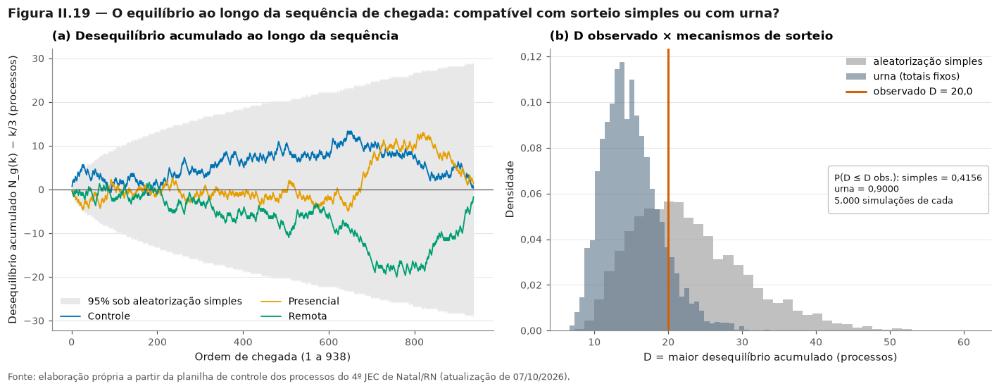

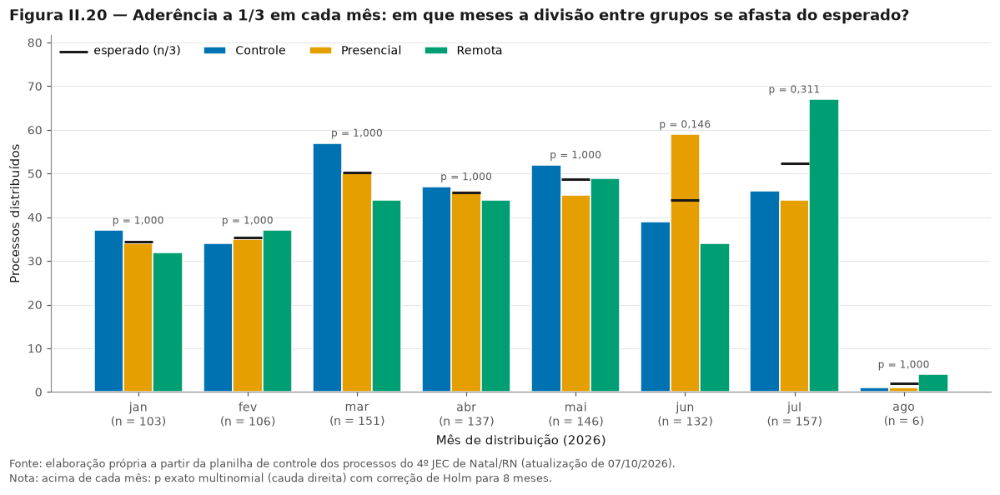

In [56]:
seq = d2.sort_values('ordem_chegada')['grupo'].astype(str).to_numpy()
ind = np.stack([(seq == g) for g in ORDEM_GRUPO], axis=1).astype(float)
k = np.arange(1, len(seq) + 1)[:, None]
desvio_obs = ind.cumsum(axis=0) - k / 3
D_obs = np.abs(desvio_obs).max()

n_sim = 5000
rng_seq = np.random.default_rng(SEMENTE)
sim_simples = rng_seq.integers(0, 3, size=(n_sim, len(seq)))
sim_urna = np.array([rng_seq.permutation(np.repeat([0, 1, 2], [313, 314, 311])) for _ in range(n_sim)])
def estat_D(sims):
    out = np.empty(len(sims))
    for g in range(3):
        dev = np.abs(np.cumsum(sims == g, axis=1) - np.arange(1, sims.shape[1] + 1) / 3).max(axis=1)
        out = dev if g == 0 else np.maximum(out, dev)
    return out
D_simples, D_urna = estat_D(sim_simples), estat_D(sim_urna)
print(f'D observado = {fmt_br(D_obs, 1)} processos')
print(f'Aleatorização simples: D mediano = {fmt_br(np.median(D_simples), 1)}; P(D ≤ D_obs) = {fmt_br((D_simples <= D_obs).mean(), 4)}')
print(f'Urna sem reposição (totais fixos): D mediano = {fmt_br(np.median(D_urna), 1)}; P(D ≤ D_obs) = {fmt_br((D_urna <= D_obs).mean(), 4)}')

linhas = []
for mes in MESES:
    cont = cont_mes.loc[mes].to_numpy()
    x2, _, p_dir = multinomial_exato(cont)
    linhas.append({'Mês': mes, 'Controle': cont[0], 'Presencial': cont[1], 'Remota': cont[2], 'n': cont.sum(),
                   'X²': x2, 'p exato': p_dir})
tab_mes_gof = pd.DataFrame(linhas).set_index('Mês')
tab_mes_gof['p (Holm)'] = multipletests(tab_mes_gof['p exato'], method='holm')[1]
tabela(tab_mes_gof, 'exp_aderencia_mes', 'Aderência a 1/3 dentro de cada mês (multinomial exato, cauda direita)',
       secao='2.5.1', casas=2, destaque='p (Holm)', nota='Holm sobre os 8 meses; linhas destacadas: p < 0,05.')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
env = np.percentile(np.abs(np.cumsum(sim_simples == 0, axis=1) - np.arange(1, len(seq) + 1) / 3), 95, axis=0)
ax[0].fill_between(k[:, 0], -env, env, color='#E8E8E8', lw=0, label='95% sob aleatorização simples')
for j, g in enumerate(ORDEM_GRUPO):
    ax[0].plot(k[:, 0], desvio_obs[:, j], color=CORES_GRUPO[g], lw=1.2, label=g)
ax[0].axhline(0, color=TINTA_2, lw=0.8)
ax[0].set_xlabel(ROTULOS['ordem_chegada']); ax[0].set_ylabel('Desequilíbrio acumulado N_g(k) − k/3 (processos)')
ax[0].legend(loc='lower left', ncol=2)
ax[0].set_title('(a) Desequilíbrio acumulado ao longo da sequência')
ax[1].hist(D_simples, bins=40, color=CINZA, density=True, alpha=0.7, label='aleatorização simples')
ax[1].hist(D_urna, bins=40, color='#5B7389', density=True, alpha=0.6, label='urna (totais fixos)')
ax[1].axvline(D_obs, color=DESTAQUE, lw=2, label=f'observado D = {fmt_br(D_obs, 1)}')
ax[1].set_xlabel('D = maior desequilíbrio acumulado (processos)'); ax[1].set_ylabel('Densidade'); ax[1].legend(loc='upper right')
ax[1].set_title('(b) D observado × mecanismos de sorteio')
anotar_teste(ax[1], f'P(D ≤ D obs.): simples = {fmt_br((D_simples <= D_obs).mean(), 4)}\n'
                    f'urna = {fmt_br((D_urna <= D_obs).mean(), 4)}\n5.000 simulações de cada', loc='center right')
figura(fig, 'exp_sequencia', 'O equilíbrio ao longo da sequência de chegada: compatível com sorteio simples ou com urna?',
       secao='2.5.1')

fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(MESES)); w = 0.27
for j, g in enumerate(ORDEM_GRUPO):
    ax.bar(x + (j - 1) * w, tab_mes_gof[g], width=w, color=CORES_GRUPO[g], label=g, edgecolor='white', linewidth=1)
ax.scatter(x, tab_mes_gof['n'] / 3, marker='_', s=500, color=TINTA, linewidths=2, label='esperado (n/3)', zorder=5)
for xi, mes in zip(x, MESES):
    ax.text(xi, tab_mes_gof.loc[mes, ORDEM_GRUPO].max() + 1.5, p_igual(tab_mes_gof.loc[mes, 'p (Holm)']),
            ha='center', fontsize=8, color=TINTA_2)
ax.set_ylim(0, tab_mes_gof[ORDEM_GRUPO].to_numpy().max() * 1.22)
ax.set_xticks(x, [f'{m_}\n(n = {int(tab_mes_gof.loc[m_, "n"])})' for m_ in MESES])
ax.set_xlabel(ROTULOS['mes_distribuicao']); ax.set_ylabel('Processos distribuídos')
ax.grid(axis='x', visible=False); ax.legend(loc='upper left', ncol=4)
figura(fig, 'exp_aderencia_mes', 'Aderência a 1/3 em cada mês: em que meses a divisão entre grupos se afasta do esperado?',
       secao='2.5.1', nota='acima de cada mês: p exato multinomial (cauda direita) com correção de Holm para 8 meses.')

**Leitura. A divisão dos grupos é equilibrada demais para um sorteio simples, mas a sequência não tem a regularidade de blocos pequenos.**

- **Cauda direita (o teste usual):** X² = 0,0085 (944 linhas) e 0,0149 (938) com p ≈ 0,99: nenhum sinal de desequilíbrio.
- **Cauda esquerda ("bom demais"):** sob aleatorização simples, a probabilidade exata de uma divisão tão equilibrada quanto 314/316/314 é de **0,52%**, e quanto 313/314/311, de **1,05%**. Por Monte Carlo, a diferença entre o maior e o menor grupo seria ≤ 3 processos em só 1,06% dos sorteios; a diferença típica seria de 28 processos (P90 = 51). Isso é evidência de **aleatorização restrita**: algum mecanismo garantiu totais iguais.
- **Mas não blocos pequenos.** O desequilíbrio acumulado ao longo da ordem de chegada chega a D = 20 processos. Esse valor é típico tanto da aleatorização simples (mediana 21,7; P(D ≤ 20) = 0,42) quanto de uma urna com totais fixos (mediana 14,7; P(D ≤ 20) = 0,90). Com blocos de 3 ou 6, D nunca passaria de 2 a 4. O gráfico mostra a Remota acumulando um déficit de quase 20 processos até a posição 800 e **recuperando-o de uma vez no fim** (julho: 67 Remotas contra 46 e 44).
- **Mês a mês:** a aderência a 1/3 só é marginal em junho (Presencial 59; p exato = 0,018) e julho (Remota 67; p = 0,044), e nenhuma resiste à correção de Holm (0,146 e 0,311).
- **Leitura conjunta.** O padrão é compatível com um sorteio sem reposição a partir de totais preestabelecidos (por exemplo, uma lista equilibrada embaralhada no sorteio.com.br) ou com uma compensação deliberada no fim do período. As duas hipóteses preservam a validade da comparação, mas precisam ser **documentadas**: a segunda tornaria a alocação de julho parcialmente previsível. Como julho também é o mês de seguimento mais curto, a concentração de Remotas nele reforça a necessidade de ajustar pelo mês (Partes IV e V). O teste de corridas da sequência é feito na Parte III.

### 2.5.2 (b) Taxas de acordo: modelo binomial com referência externa

**Referência documentada.** O resumo expandido informa que o índice de conciliação do 4º JEC no GPS-Jus "sempre oscilou em torno de 13 a 14%, estando atualmente no patamar de **13,3%**", antes do experimento, e que o índice nacional dos JECs era **17,22%** em dez./2025. O índice de conciliação do CNJ é **sentenças homologatórias de acordo ÷ total de sentenças**; portanto, a comparação legítima usa o mesmo denominador: homologações entre as sentenças proferidas (não entre os processos distribuídos, como no resumo expandido, que dava 8,06%).

**Testes** (binomial exato bilateral, um por linha):

1. **Homologações / sentenças**, no total e por grupo. H0: p = 0,133 (patamar histórico da unidade); H1: p ≠ 0,133. Pergunta: o índice de conciliação durante o experimento difere do patamar histórico? Ressalva: só as sentenças até 07/10 entram; como os acordos tendem a encerrar processos mais cedo, o índice pode cair à medida que as sentenças de mérito dos ativos forem proferidas.
2. **Acordos na AC / AC realizadas**, por grupo de tratamento. H0: p = 0,133; H1: p ≠ 0,133. Pergunta: a audiência, sozinha, alcança o patamar histórico de conciliação da unidade? É uma comparação de ordem de grandeza (os denominadores são diferentes: audiências × sentenças), mas é a pergunta que o desenho do experimento implicitamente faz.

Holm dentro de cada família (4 e 3 testes). A comparação **entre** grupos (Fisher, qui-quadrado) é da Parte III.

Proporção,k,n,p̂,H0: p,IC95% Clopper-Pearson,IC95% Wilson,p,p (Holm)
Homologações/sentenças — Todos,81,708,"11,4%","13,3%","9,2% a 14,0%","9,3% a 14,0%","0,150","0,451"
Homologações/sentenças — Controle,21,262,"8,0%","13,3%","5,0% a 12,0%","5,3% a 11,9%","0,011","0,042"
Homologações/sentenças — Presencial,25,230,"10,9%","13,3%","7,2% a 15,6%","7,5% a 15,6%","0,331","0,456"
Homologações/sentenças — Remota,35,216,"16,2%","13,3%","11,6% a 21,8%","11,9% a 21,7%","0,228","0,456"
Acordo na AC/AC realizadas — P + R,17,352,"4,8%","13,3%","2,8% a 7,6%","3,0% a 7,6%","< 0,001","< 0,001"
Acordo na AC/AC realizadas — Presencial,9,178,"5,1%","13,3%","2,3% a 9,4%","2,7% a 9,3%","< 0,001","< 0,001"
Acordo na AC/AC realizadas — Remota,8,174,"4,6%","13,3%","2,0% a 8,9%","2,3% a 8,8%","< 0,001","< 0,001"


Para comparação: acordos/processos distribuídos (denominador do resumo expandido) = 81/938 = 8,6% (inclui ativos no denominador)


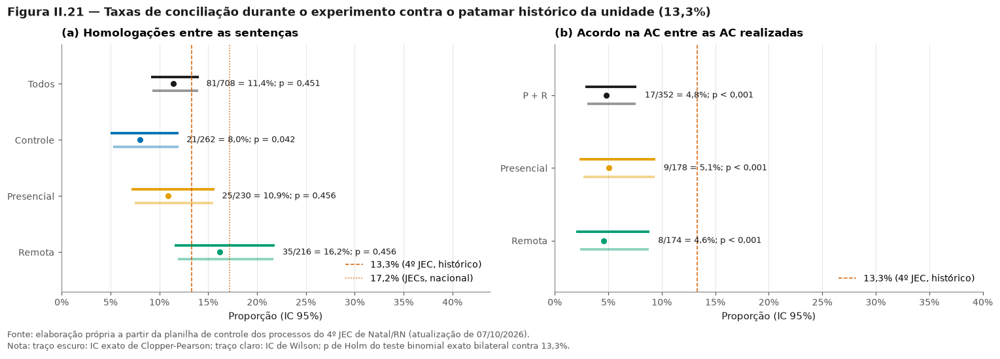

In [57]:
P0_UNIDADE, P0_NACIONAL = 0.133, 0.1722

def linha_binomial(rotulo, k, n, p0):
    bt = stats.binomtest(int(k), int(n), p0)
    cp = bt.proportion_ci(confidence_level=0.95, method='exact')
    wi = bt.proportion_ci(confidence_level=0.95, method='wilson')
    return {'Proporção': rotulo, 'k': int(k), 'n': int(n), 'p̂': k / n, 'H0: p': p0,
            'IC95% Clopper-Pearson': (cp.low, cp.high), 'IC95% Wilson': (wi.low, wi.high), 'p': bt.pvalue}

fam1 = []
for g in [None] + ORDEM_GRUPO:
    s = sent if g is None else sent[sent.grupo.eq(g)]
    fam1.append(linha_binomial(f'Homologações/sentenças — {"Todos" if g is None else g}',
                               s.tipo_desfecho.eq('Homologação').sum(), len(s), P0_UNIDADE))
fam2 = []
for g in [None, 'Presencial', 'Remota']:
    s = ac if g is None else ac[ac.grupo.eq(g)]
    fam2.append(linha_binomial(f'Acordo na AC/AC realizadas — {"P + R" if g is None else g}',
                               s.acordo_ac.sum(), len(s), P0_UNIDADE))
tab_bin = []
for fam in (fam1, fam2):
    t = pd.DataFrame(fam)
    t['p (Holm)'] = multipletests(t['p'], method='holm')[1]
    tab_bin.append(t)
tab_bin = pd.concat(tab_bin, ignore_index=True)

def fmt_ic(ic):
    return f'{pct_br(ic[0])} a {pct_br(ic[1])}'

def tabela_binomial(t, id_, titulo, secao, nota=None):
    saida = t.assign(**{'IC95% Clopper-Pearson': t['IC95% Clopper-Pearson'].map(fmt_ic),
                        'IC95% Wilson': t['IC95% Wilson'].map(fmt_ic)})
    tabela(saida, id_, titulo, secao=secao, formatos={'p̂': 'pct', 'H0: p': 'pct'}, destaque='p (Holm)', nota=nota)


tabela_binomial(tab_bin, 'exp_binom_acordo', 'Taxas de conciliação contra o patamar histórico de 13,3% (binomial exato)', '2.5.2',
                nota='Holm dentro de cada família (4 e 3 testes); linhas destacadas: p de Holm < 0,05.')
print(f'Para comparação: acordos/processos distribuídos (denominador do resumo expandido) = '
      f'{int(d2.acordo.sum())}/{len(d2)} = {pct_br(d2.acordo.sum() / len(d2))} (inclui ativos no denominador)')

def p_txt(p):
    return 'referência' if pd.isna(p) else ('p < 0,001' if p < 0.001 else f'p = {p_br(p)}')


def forest(ax, tab, refs, titulo, cores):
    y = np.arange(len(tab))[::-1]
    xmax = max(0.3, tab['IC95% Clopper-Pearson'].map(lambda c: c[1]).max() + 0.12) + 0.1
    for yi, (_, r), c in zip(y, tab.iterrows(), cores):
        ax.hlines(yi + 0.12, *r['IC95% Clopper-Pearson'], color=c, lw=2.5)
        ax.hlines(yi - 0.12, *r['IC95% Wilson'], color=c, lw=2.5, alpha=0.45)
        ax.plot(r['p̂'], yi, 'o', color=c, ms=7, mec='white', mew=1)
        ax.text(r['IC95% Clopper-Pearson'][1] + 0.008, yi, f"{r['k']}/{r['n']} = {pct_br(r['p̂'])}; {p_txt(r['p (Holm)'])}",
                va='center', fontsize=8.5, color=TINTA)
    for valor, rot, ls in refs:
        ax.axvline(valor, color=DESTAQUE, ls=ls, lw=1, label=rot)
    ax.legend(loc='lower right')
    ax.set_yticks(y, [s.split('— ')[-1] for s in tab['Proporção']])
    ax.set_ylim(-0.7, len(tab) - 0.3)
    ax.set_xlim(0, xmax)
    eixo_pct(ax, 'x')
    ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
    ax.set_title(titulo)

cores_fam1 = [TINTA] + [CORES_GRUPO[g] for g in ORDEM_GRUPO]
cores_fam2 = [TINTA, CORES_GRUPO['Presencial'], CORES_GRUPO['Remota']]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
forest(ax[0], tab_bin.iloc[:4], [(P0_UNIDADE, '13,3% (4º JEC, histórico)', '--'), (P0_NACIONAL, '17,2% (JECs, nacional)', ':')],
       '(a) Homologações entre as sentenças', cores_fam1)
forest(ax[1], tab_bin.iloc[4:], [(P0_UNIDADE, '13,3% (4º JEC, histórico)', '--')],
       '(b) Acordo na AC entre as AC realizadas', cores_fam2)
ax[0].set_xlabel('Proporção (IC 95%)'); ax[1].set_xlabel('Proporção (IC 95%)')
figura(fig, 'exp_binom_acordo', 'Taxas de conciliação durante o experimento contra o patamar histórico da unidade (13,3%)',
       secao='2.5.2', nota='traço escuro: IC exato de Clopper-Pearson; traço claro: IC de Wilson; p de Holm do teste binomial '
                           'exato bilateral contra 13,3%.')

**Leitura. O índice de conciliação durante o experimento não difere do patamar histórico; a audiência, sozinha, fica muito abaixo dele.**

- **Índice de conciliação (homologações ÷ sentenças).** No total, 81 de 708 sentenças, ou **11,4%** (IC95% de Clopper-Pearson: 9,2% a 14,0%), compatível com os 13,3% históricos da unidade (p = 0,150; Holm 0,451). Por grupo: Controle **8,0%** (5,0% a 12,0%), abaixo do patamar (p = 0,011; Holm 0,042); Presencial 10,9% (7,2% a 15,6%) e Remota **16,2%** (11,6% a 21,8%), ambas compatíveis com 13,3% (Holm 0,456). Nenhum grupo atinge com segurança o índice nacional dos JECs (17,2%). O IC de Wilson é praticamente igual ao exato em todos os casos.
- **Acordo na AC (acordos ÷ AC realizadas):** 17 de 352, ou **4,8%** (2,8% a 7,6%); Presencial 5,1% (9/178) e Remota 4,6% (8/174), todos muito abaixo de 13,3% (p < 0,001). A comparação de denominadores (audiências × sentenças) é imperfeita, mas a ordem de grandeza é inequívoca: **a audiência inaugural produz cerca de um acordo a cada 20 sessões**.
- **Leitura jurídica.** O que distingue a Remota é o acordo **fora** da audiência (27 dos 35), e não a AC. A hipótese do projeto ("a audiência obrigatória aumenta os índices de conciliação") tem, por ora, apoio fraco e indireto: os grupos tratados têm índice nominalmente maior que o Controle, mas a diferença entre grupos é testada na Parte III, e, como os acordos encerram os processos mais cedo, o índice entre as sentenças já proferidas tende a cair quando as sentenças de mérito dos ativos chegarem. A taxa de 8,06% do resumo expandido (acordos ÷ distribuídos) mistura essa questão com a censura.

**Sentenças sem mérito.** O Controle tem proporcionalmente mais sentenças de mérito e menos extinções sem mérito que os grupos com AC obrigatória. A hipótese jurídica é a do **art. 51, I, da Lei 9.099/1995**: o processo é extinto sem resolução do mérito quando o autor deixa de comparecer a qualquer das audiências. Com a AC obrigatória, surge uma oportunidade de extinção que o rito atual (sem audiência inaugural) não oferece.

**Teste** (binomial exato bilateral): tomando a proporção de sentenças sem mérito do Controle como **referência fixa** (o rito atual), H0: p_grupo = p_Controle; H1: p_grupo ≠ p_Controle, para Presencial e Remota (Holm, 2 testes). Ao fixar a taxa do Controle, ignora-se a sua incerteza; o teste de duas amostras (Fisher/qui-quadrado), que a considera, está na Parte III. A tabela seguinte descreve, nos grupos tratados, a relação entre a extinção sem mérito e a realização da AC.

Proporção,k,n,p̂,H0: p,IC95% Clopper-Pearson,IC95% Wilson,p,p (Holm)
Sem mérito/sentenças — Controle (referência),79,262,"30,2%","30,2%","24,7% a 36,1%","24,9% a 36,0%",–,–
Sem mérito/sentenças — Presencial,109,230,"47,4%","30,2%","40,8% a 54,1%","41,0% a 53,8%","< 0,001","< 0,001"
Sem mérito/sentenças — Remota,98,216,"45,4%","30,2%","38,6% a 52,3%","38,9% a 52,0%","< 0,001","< 0,001"


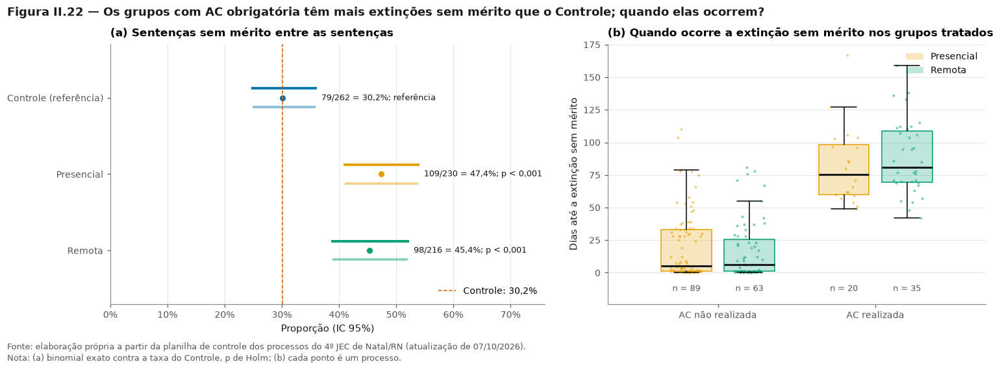

In [58]:
p_ctrl = sent[sent.grupo.eq('Controle')].tipo_desfecho.eq('Sem mérito').mean()
linhas = [linha_binomial(f'Sem mérito/sentenças — Controle (referência)',
                         sent[sent.grupo.eq('Controle')].tipo_desfecho.eq('Sem mérito').sum(),
                         sent.grupo.eq('Controle').sum(), p_ctrl)]
for g in ['Presencial', 'Remota']:
    s = sent[sent.grupo.eq(g)]
    linhas.append(linha_binomial(f'Sem mérito/sentenças — {g}', s.tipo_desfecho.eq('Sem mérito').sum(), len(s), p_ctrl))
tab_sm = pd.DataFrame(linhas)
tab_sm['p (Holm)'] = np.r_[np.nan, multipletests(tab_sm['p'].iloc[1:], method='holm')[1]]
tab_sm.loc[0, 'p'] = np.nan
tabela_binomial(tab_sm, 'exp_binom_semmerito', 'Sentenças sem mérito nos grupos com AC contra a taxa do Controle (binomial exato)',
                '2.5.2', nota='a taxa do Controle é tomada como referência fixa (sem teste na sua linha); Holm para 2 testes.')

trat = sent[sent.grupo.isin(['Presencial', 'Remota'])].copy()
trat['AC'] = trat['ac_realizada'].map({True: 'AC realizada', False: 'AC não realizada'}).fillna('não informado')
tab_sm_ac = pd.crosstab([trat['grupo'].astype(str), trat['AC']], trat['tipo_desfecho'].astype(str))
tab_sm_ac = tab_sm_ac.reindex(columns=['Homologação', 'Mérito', 'Sem mérito'])
tab_sm_ac['mediana dias (sem mérito)'] = trat[trat.tipo_desfecho.eq('Sem mérito')].groupby(['grupo', 'AC'], observed=True)['T'].median()
tabela(tab_sm_ac.rename_axis(index=['Grupo', 'AC'], columns=None)
       .rename(columns={'mediana dias (sem mérito)': 'Mediana do tempo até a extinção sem mérito (dias)'}),
       'exp_semmerito_ac', 'Tipo de sentença nos grupos tratados, segundo a realização da AC', secao='2.5.2', casas=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1.15, 1]})
forest(ax[0], tab_sm, [(p_ctrl, f'Controle: {pct_br(p_ctrl)}', '--')], '(a) Sentenças sem mérito entre as sentenças',
       [CORES_GRUPO[g] for g in ORDEM_GRUPO])
ax[0].set_xlabel('Proporção (IC 95%)')
rng_sm = np.random.default_rng(SEMENTE)
for g, desloc in [('Presencial', -0.2), ('Remota', 0.2)]:
    s = trat[trat.grupo.eq(g) & trat.tipo_desfecho.eq('Sem mérito')]
    for i, rot in enumerate(['AC não realizada', 'AC realizada']):
        v = s.loc[s.AC.eq(rot), 'T'].to_numpy(float)
        if len(v) == 0:
            continue
        bpx = ax[1].boxplot([v], positions=[i + desloc], widths=0.32, patch_artist=True, showfliers=False,
                            medianprops=dict(color=TINTA, lw=2))
        bpx['boxes'][0].set_facecolor(mpl.colors.to_rgba(CORES_GRUPO[g], 0.25)); bpx['boxes'][0].set_edgecolor(CORES_GRUPO[g])
        ax[1].scatter(i + desloc + rng_sm.uniform(-0.1, 0.1, len(v)), v, s=7, color=CORES_GRUPO[g], alpha=0.5, lw=0)
        ax[1].text(i + desloc, -14, f'n = {len(v)}', ha='center', fontsize=8.5, color=TINTA_2)
ax[1].set_xticks([0, 1], ['AC não realizada', 'AC realizada']); ax[1].set_ylim(-24, None)
ax[1].set_ylabel('Dias até a extinção sem mérito'); ax[1].grid(axis='x', visible=False)
ax[1].legend(handles=[mpl.patches.Patch(facecolor=mpl.colors.to_rgba(CORES_GRUPO[g], 0.25), edgecolor=CORES_GRUPO[g], label=g)
                      for g in ['Presencial', 'Remota']], loc='upper right')
ax[1].set_title('(b) Quando ocorre a extinção sem mérito nos grupos tratados')
figura(fig, 'exp_binom_semmerito', 'Os grupos com AC obrigatória têm mais extinções sem mérito que o Controle; quando elas ocorrem?',
       secao='2.5.2', nota='(a) binomial exato contra a taxa do Controle, p de Holm; (b) cada ponto é um processo.')

**Leitura. Os grupos com AC obrigatória têm uma fração muito maior de sentenças sem mérito, e o excesso está nas extinções tardias (após 30 dias), não nas precoces.**

- **Proporções.** Sem mérito: Controle **30,2%** das sentenças (79/262; IC95% 24,7% a 36,1%); Presencial **47,4%** (109/230; 40,8% a 54,1%); Remota **45,4%** (98/216; 38,6% a 52,3%). Contra a taxa do Controle tomada como referência, as duas diferenças são muito significativas (p < 0,001 após Holm), e os ICs dos tratados nem tocam o do Controle. São 15 a 17 pontos percentuais a mais: o maior efeito observado em toda a exploração.
- **Quando ocorrem.** Nos tratados, a maioria das extinções sem mérito acontece **sem que a AC tenha ocorrido**: 89 na Presencial e 63 na Remota, com mediana de **5 e 6 dias**. Nos processos com AC realizada, as extinções sem mérito são 20 e 35, com mediana de 75,5 e 81 dias, compatíveis com a extinção na própria audiência ou depois dela.
- **Onde está o excesso.** Por faixa de tempo, as extinções sem mérito são: até 7 dias, 39 (Controle), 48 (Presencial) e 34 (Remota); de 8 a 30 dias, 14, 16 e 16; após 30 dias, **26, 45 e 48**. O bloco precoce existe nos três grupos e quase não difere; a diferença entre os grupos está nas extinções tardias, que coincidem com a fase da audiência.
- **Leitura jurídica.** A hipótese do art. 51, I, da Lei 9.099/1995 (ausência do autor à audiência) explica bem o excesso tardio (os 55 casos com AC realizada e as extinções após 30 dias). As extinções com 5 a 6 dias de distribuição ocorrem **antes** de qualquer audiência, mas aparecem em volume semelhante no Controle, portanto não são efeito da AC obrigatória: são atos iniciais do juízo (indeferimento, desistência, incompetência) comuns aos três ritos. Isso altera a composição dos desfechos e, com ela, o tempo médio (seção 2.6.1). O motivo de cada extinção precisa ser conferido no PJe; o teste de duas amostras está na Parte III, e a análise por tipo de desfecho (riscos competitivos), na Parte IV.

### 2.5.3 (c) O sorteio das técnicas de conciliação

**Pergunta.** O protocolo previa o sorteio da técnica em cada audiência. O resumo expandido lista **5** técnicas e afirma que "padrões objetivos" foi a mais usada, com **53,85%**; o professor anotou: "53,85%??? o esperado era 1/5 = 20,0%". O projeto, os apêndices e a planilha têm **6** técnicas (a sexta é "análise da comunicação verbal e não-verbal das partes"). Logo, sob sorteio uniforme, o esperado é **1/6 ≈ 16,7%** para cada uma.

**Testes:**

1. Qui-quadrado de aderência e p exato multinomial por Monte Carlo (200.000 sorteios, estatística X²). H0: as 6 técnicas têm probabilidade 1/6; H1: alguma difere. No total das AC realizadas e em cada grupo (Holm, 3 testes).
2. Binomial exato para "padrões objetivos": H0: p = 1/6 e H0: p = 0,5385 (o valor do resumo expandido).
3. Uma versão com 5 técnicas (1/5), excluída "comunicação verbal e não-verbal", para mostrar o que acontece com o valor esperado do professor.

In [59]:
TECNICAS = list(d2['tecnica_curta'].cat.categories)
def gof_uniforme(cont, n_mc=200_000, semente=SEMENTE):
    cont = np.asarray(cont); n = cont.sum(); kcat = len(cont); esp = n / kcat
    x2 = ((cont - esp) ** 2 / esp).sum()
    sim = np.random.default_rng(semente).multinomial(n, [1 / kcat] * kcat, size=n_mc)
    x2_sim = ((sim - esp) ** 2 / esp).sum(axis=1)
    return x2, stats.chi2.sf(x2, kcat - 1), (x2_sim >= x2 - 1e-9).mean()

linhas = []
for rot, s in [('AC realizadas (P + R)', ac), ('Presencial', ac[ac.grupo.eq('Presencial')]), ('Remota', ac[ac.grupo.eq('Remota')])]:
    cont = s['tecnica_curta'].value_counts().reindex(TECNICAS).to_numpy()
    x2, p_chi, p_mc = gof_uniforme(cont)
    linhas.append({'Amostra': rot, 'n': cont.sum(), **dict(zip(TECNICAS, cont)), 'X² (5 g.l.)': x2,
                   'p qui-quadrado': p_chi, 'p exato (Monte Carlo)': p_mc})
tab_tec = pd.DataFrame(linhas).set_index('Amostra')
tab_tec['p MC (Holm)'] = multipletests(tab_tec['p exato (Monte Carlo)'], method='holm')[1]
tabela(tab_tec, 'exp_tecnicas', 'Sorteio das técnicas: aderência à distribuição uniforme (1/6 para cada técnica)',
       secao='2.5.3', casas=2, destaque='p MC (Holm)', nota='p exato por Monte Carlo (200.000 sorteios); Holm para 3 testes.')

cont5 = ac.loc[ac.tecnica_curta.ne('Comunicação'), 'tecnica_curta'].value_counts().reindex([t for t in TECNICAS if t != 'Comunicação'])
x2_5, p5, p5_mc = gof_uniforme(cont5.to_numpy())
print(f'Versão com 5 técnicas (sem "Comunicação", n = {cont5.sum()}): X² = {fmt_br(x2_5, 2)} (4 g.l.), p = {p_br(p5)}, p MC = {p_br(p5_mc)}')

k_po, n_ac = int(ac.tecnica_curta.eq('Padrões objetivos').sum()), len(ac)
for p0, rot in [(1 / 6, '1/6'), (1 / 5, '1/5'), (0.5385, '53,85%')]:
    bt = stats.binomtest(k_po, n_ac, p0)
    ci = bt.proportion_ci(method='wilson')
    print(f'Padrões objetivos: {k_po}/{n_ac} = {pct_br(k_po / n_ac)} (Wilson {pct_br(ci.low)} a {pct_br(ci.high)}); '
          f'H0: p = {rot} → p = {p_br(bt.pvalue)}')

Amostra,n,Desconstrução,Parafraseamento,Separação,Padrões objetivos,Afago,Comunicação,X² (5 g.l.),p qui-quadrado,p exato (Monte Carlo),p MC (Holm)
AC realizadas (P + R),352,47,57,60,67,58,63,"3,91","0,563","0,566","1,000"
Presencial,178,25,28,30,32,25,38,"4,09","0,537","0,542","1,000"
Remota,174,22,29,30,35,33,25,"4,07","0,540","0,545","1,000"


Versão com 5 técnicas (sem "Comunicação", n = 289): X² = 3,58 (4 g.l.), p = 0,466, p MC = 0,472
Padrões objetivos: 67/352 = 19,0% (Wilson 15,3% a 23,5%); H0: p = 1/6 → p = 0,225
Padrões objetivos: 67/352 = 19,0% (Wilson 15,3% a 23,5%); H0: p = 1/5 → p = 0,690
Padrões objetivos: 67/352 = 19,0% (Wilson 15,3% a 23,5%); H0: p = 53,85% → p = < 0,001


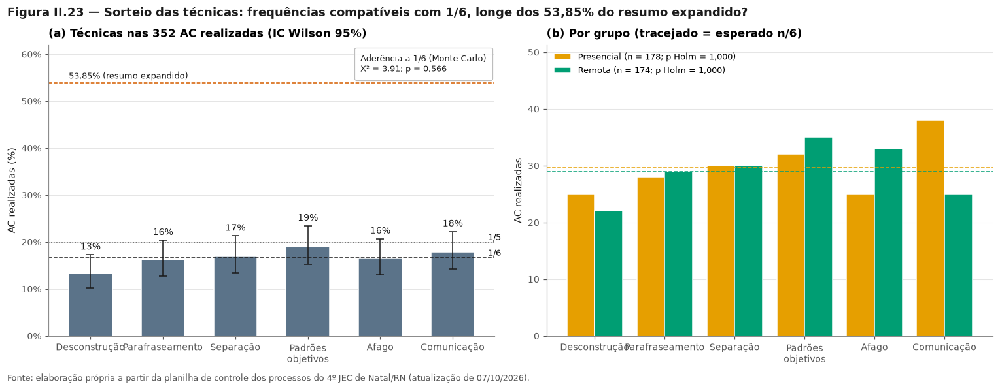

In [60]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
cont_tot = ac['tecnica_curta'].value_counts().reindex(TECNICAS)
ic = [stats.binomtest(int(c), n_ac).proportion_ci(method='wilson') for c in cont_tot]
barras_verticais(ax[0], TECNICAS, (cont_tot / n_ac).to_numpy(), cores='#5B7389', quebrar=11,
                 erro=([c.low for c in ic], [c.high for c in ic]), fmt=lambda v: pct_br(v, 0), ymax=0.62,
                 ylabel='AC realizadas (%)')
eixo_pct(ax[0])
ax[0].axhline(1 / 6, color=TINTA, ls='--', lw=1); ax[0].text(5.45, 1 / 6, ' 1/6', fontsize=8.5, va='bottom')
ax[0].axhline(1 / 5, color=TINTA_2, ls=':', lw=1); ax[0].text(5.45, 1 / 5, ' 1/5', fontsize=8.5, va='bottom')
ax[0].axhline(0.5385, color=DESTAQUE, ls='--', lw=1)
ax[0].text(-0.3, 0.548, '53,85% (resumo expandido)', color=TINTA, fontsize=8.5)
ax[0].set_title(f'(a) Técnicas nas {n_ac} AC realizadas (IC Wilson 95%)')
anotar_teste(ax[0], texto_teste('Aderência a 1/6 (Monte Carlo)', f'X² = {fmt_br(tab_tec.iloc[0]["X² (5 g.l.)"], 2)}',
                                tab_tec.iloc[0]['p exato (Monte Carlo)']), loc='upper right')
cont_g = pd.DataFrame({g: ac.loc[ac.grupo.eq(g), 'tecnica_curta'].value_counts().reindex(TECNICAS) for g in ['Presencial', 'Remota']})
rot_g = {g: f'{g} (n = {int(cont_g[g].sum())}; p Holm {"< 0,001" if tab_tec.loc[g, "p MC (Holm)"] < 0.001 else "= " + fmt_p(tab_tec.loc[g, "p MC (Holm)"])})'
         for g in cont_g}
barras_agrupadas(ax[1], cont_g.rename(columns=rot_g), cores={rot_g[g]: CORES_GRUPO[g] for g in rot_g}, quebrar=11,
                 ylabel='AC realizadas')
for g in cont_g:
    ax[1].axhline(cont_g[g].sum() / 6, color=CORES_GRUPO[g], ls='--', lw=1)
ax[1].set_ylim(0, cont_g.to_numpy().max() * 1.35)
ax[1].legend(loc='upper left', fontsize=8.5)
ax[1].set_title('(b) Por grupo (tracejado = esperado n/6)')
figura(fig, 'exp_tecnicas', 'Sorteio das técnicas: frequências compatíveis com 1/6, longe dos 53,85% do resumo expandido?',
       secao='2.5.3')

**Leitura. O sorteio das técnicas é compatível com um sorteio uniforme entre seis técnicas; o "53,85%" do resumo expandido não se confirma.**

- **Aderência a 1/6:** nas 352 AC realizadas, X² = 3,91 com 5 g.l., p = 0,563 (Monte Carlo 0,567). Por grupo: Presencial p = 0,54 e Remota p = 0,55 (Holm = 1,0). As frequências vão de 47 a 67, dentro da variação esperada.
- **"Padrões objetivos":** 67/352 = **19,0%** (IC de Wilson 15,3% a 23,5%), compatível com 1/6 (p = 0,225) e também com 1/5 (p = 0,690), mas incompatível com 53,85% (p < 0,001). O valor do resumo não pode ser reproduzido com nenhum recorte da planilha atual: pode ter vindo de uma tabela dinâmica com outro denominador ou de uma versão anterior dos dados.
- **5 ou 6 técnicas?** A planilha registra seis técnicas, inclusive "Análise da comunicação verbal e não-verbal" (63 audiências; 17,9%). A anotação do professor ("o esperado era 1/5 = 20,0%") parte da lista de cinco técnicas do resumo expandido; o protocolo efetivamente executado usou seis, e o esperado é 1/6 ≈ 16,7%. Excluída a sexta técnica, o teste com 5 categorias também não rejeita (p = 0,466). O texto do resumo deve ser corrigido para seis técnicas.
- **Consequência.** Como o sorteio parece ter funcionado, a comparação de técnicas dentro das AC é um experimento aninhado legítimo; mas com 17 acordos distribuídos em seis técnicas (de 0 a 6 por técnica) o poder é muito baixo (Parte V).

### 2.5.4 (d) Sentenças datadas em fim de semana

**Pergunta.** Se os atos fossem praticados só em dias úteis, nenhuma sentença teria data de sábado ou domingo. A planilha tem desfechos datados em fins de semana (`sentenca_fim_semana`, anomalia A16). Duas referências:

- **"só dias úteis"** (p₀ = 0): basta um caso para refutar; não há teste a fazer, só a contagem;
- **"datas uniformes nos 7 dias"** (p₀ = 2/7 ≈ 28,6%): o que se esperaria se a data da sentença fosse indiferente ao dia da semana (por exemplo, assinatura eletrônica remota no PJe, que funciona todos os dias).

**Teste:** binomial exato bilateral, H0: p = 2/7; H1: p ≠ 2/7, no total dos desfechos e por tipo de desfecho (Holm, 4 tipos). Complemento: a distribuição dos desfechos pelos 7 dias (qui-quadrado de aderência à uniforme). A leitura jurídica: a data registrada é a da **assinatura eletrônica** do ato; sentenças em fim de semana indicam trabalho do magistrado fora do expediente (comum em gabinetes com acervo controlado), não erro de registro, mas a coluna deve ser conferida no PJe.

Proporção,k,n,p̂,H0: p,IC95% Clopper-Pearson,IC95% Wilson,p,p (Holm)
Fim de semana — todos os desfechos,135,732,"18,4%","28,6%","15,7% a 21,4%","15,8% a 21,4%","< 0,001","< 0,001"
Fim de semana — Homologação,9,81,"11,1%","28,6%","5,2% a 20,0%","6,0% a 19,8%","< 0,001","< 0,001"
Fim de semana — Mérito,90,341,"26,4%","28,6%","21,8% a 31,4%","22,0% a 31,3%","0,402","0,402"
Fim de semana — Sem mérito,36,286,"12,6%","28,6%","9,0% a 17,0%","9,2% a 16,9%","< 0,001","< 0,001"
Fim de semana — Redistribuição,0,24,"0,0%","28,6%","0,0% a 14,2%","0,0% a 13,8%","< 0,001","< 0,001"


Desfechos por dia da semana: {'seg': 90, 'ter': 186, 'qua': 149, 'qui': 84, 'sex': 88, 'sáb': 70, 'dom': 65}; aderência à uniforme nos 7 dias: X² = 117,4 (6 g.l.), p = < 0,001


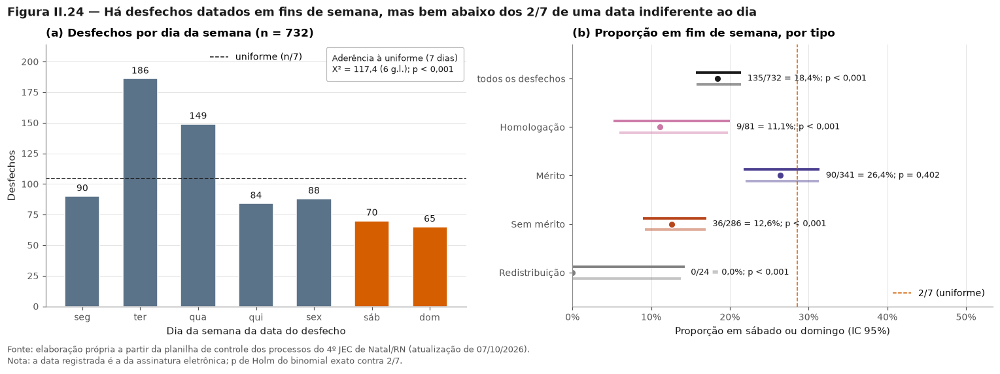

In [61]:
desf = d2[d2['encerrado']].copy()
desf['dia_sem'] = desf['dt_sentenca'].dt.dayofweek
DIAS = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
linhas = [linha_binomial('Fim de semana — todos os desfechos', desf.dia_sem.ge(5).sum(), len(desf), 2 / 7)]
for t in ['Homologação', 'Mérito', 'Sem mérito', 'Redistribuição']:
    s = desf[desf.tipo_desfecho.eq(t)]
    linhas.append(linha_binomial(f'Fim de semana — {t}', s.dia_sem.ge(5).sum(), len(s), 2 / 7))
tab_fds = pd.DataFrame(linhas)
tab_fds['p (Holm)'] = np.r_[tab_fds['p'].iloc[0], multipletests(tab_fds['p'].iloc[1:], method='holm')[1]]
tabela_binomial(tab_fds, 'exp_fimsemana', 'Desfechos datados em fim de semana contra a proporção uniforme de 2/7 (binomial exato)',
                '2.5.4', nota='Holm para os 4 tipos de desfecho; a primeira linha (todos) não entra na família.')
cont_dia = desf['dia_sem'].value_counts().reindex(range(7), fill_value=0)
x2_dia = stats.chisquare(cont_dia)
print(f'Desfechos por dia da semana: {dict(zip(DIAS, cont_dia.tolist()))}; '
      f'aderência à uniforme nos 7 dias: X² = {fmt_br(x2_dia.statistic, 1)} (6 g.l.), p = {p_br(x2_dia.pvalue)}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
barras_verticais(ax[0], DIAS, cont_dia.to_numpy(), cores=['#5B7389'] * 5 + [DESTAQUE] * 2, ylabel='Desfechos')
ax[0].axhline(len(desf) / 7, color=TINTA, ls='--', lw=1, label='uniforme (n/7)')
ax[0].legend(loc='upper center')
ax[0].set_xlabel('Dia da semana da data do desfecho')
ax[0].set_title(f'(a) Desfechos por dia da semana (n = {len(desf)})')
anotar_teste(ax[0], texto_teste('Aderência à uniforme (7 dias)', f'X² = {fmt_br(x2_dia.statistic, 1)} (6 g.l.)',
                                x2_dia.pvalue), loc='upper right')
forest(ax[1], tab_fds, [(2 / 7, '2/7 (uniforme)', '--')], '(b) Proporção em fim de semana, por tipo',
       [TINTA, CORES_DESFECHO['Homologação'], CORES_DESFECHO['Mérito'], CORES_DESFECHO['Sem mérito'],
        CORES_DESFECHO['Redistribuição']])
ax[1].set_xlabel('Proporção em sábado ou domingo (IC 95%)')
figura(fig, 'exp_fimsemana', 'Há desfechos datados em fins de semana, mas bem abaixo dos 2/7 de uma data indiferente ao dia',
       secao='2.5.4', nota='a data registrada é a da assinatura eletrônica; p de Holm do binomial exato contra 2/7.')

**Leitura.**

- **Há desfechos em fins de semana: 135 de 732 (18,4%; IC95% 15,7% a 21,4%).** Se a regra fosse "só dias úteis", qualquer caso a refutaria. A proporção é, porém, menor que a de uma data indiferente ao dia da semana (2/7 = 28,6%; p < 0,001).
- **Depende do tipo de ato.** As sentenças de **mérito** são assinadas em fins de semana na proporção de uma data uniforme (26,4%; p = 0,402): o magistrado redige e assina os julgamentos também aos sábados e domingos. Homologações (11,1%), extinções sem mérito (12,6%) e redistribuições (0 de 24) concentram-se nos dias úteis (p < 0,001 após Holm), o que é coerente com atos de rotina preparados pela secretaria.
- **Dias da semana:** a distribuição dos desfechos está longe da uniforme (X² = 117,4; 6 g.l.; p < 0,001), com um pico na terça-feira (186) e menos atos na segunda (90).
- **Leitura jurídica.** A data registrada é a da **assinatura eletrônica** no PJe, que funciona todos os dias. As sentenças de fim de semana não indicam erro de registro; indicam o ritmo de trabalho do gabinete e confirmam que o momento da sentença está sob controle direto do juiz-pesquisador, limitação de validade interna já apontada (ausência de cegamento). Uma conferência por amostragem no PJe é recomendável.

## 2.6 Análise bivariada

Esta seção é **descritiva**: mostra como o tempo e as categóricas se associam, com medidas de tamanho de efeito, mas sem testes de hipótese (Parte III) nem modelos (Partes IV e V). Duas cautelas atravessam toda a seção:

1. **Toda comparação de tempos entre sentenciados é condicional.** Um grupo com mais processos ativos tem, entre os sentenciados, uma seleção mais "rápida". A comparação correta é a das curvas de sobrevivência (Parte IV).
2. **Variáveis pós-sorteio** (AC realizada, híbrida, técnica, acordo, tipo de desfecho) não são causas exógenas do tempo: elas acontecem durante o processo e, em parte, *definem* o seu fim.

### 2.6.1 Tempo até a sentença × fatores (sentenciados)

Boxplots verticais com o n de cada caixa e a mediana escrita ao lado ("Md"); cada ponto é um processo. A primeira figura traz os fatores do desenho (grupo, tipo de desfecho, mês) e a segunda, as variáveis pós-sorteio (acordo, híbrida, técnica). Para cada fator, a tabela traz n, mediana, IIQ e média, e a razão de correlação **η²** = SQ entre / SQ total (a fração da variância dos tempos dos sentenciados "explicada" pelo fator; tamanho de efeito descritivo, sem teste).

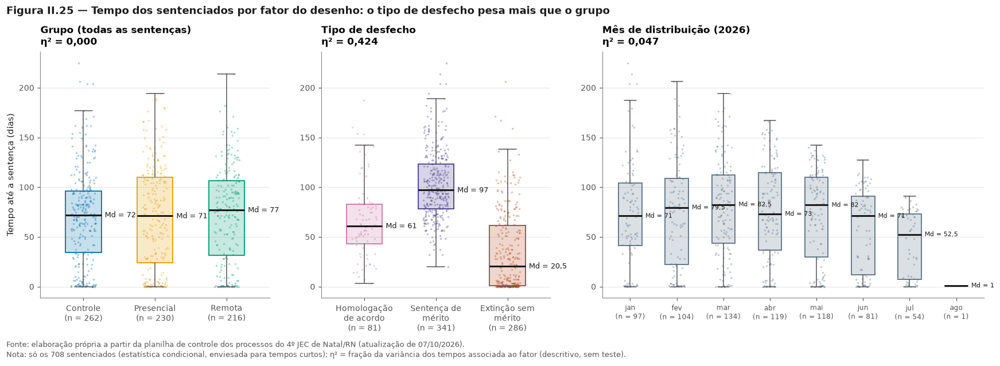

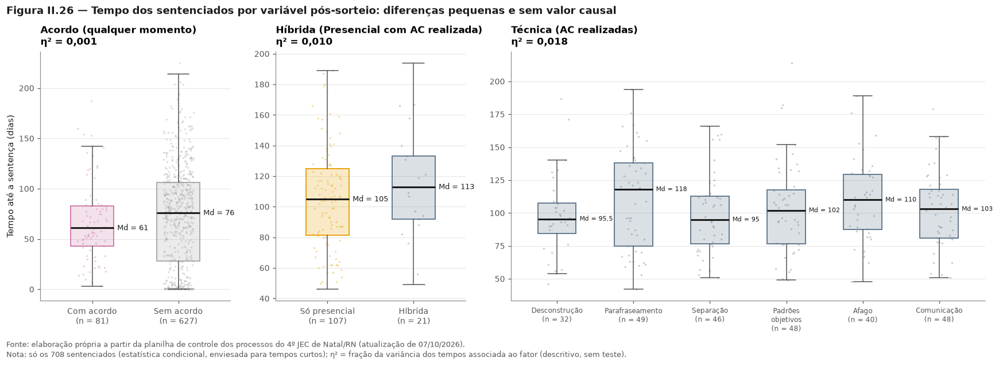

In [62]:
def eta2(y, g):
    y = pd.Series(np.asarray(y, float)); g = pd.Series(np.asarray(g, object))
    ok = g.notna() & y.notna(); y, g = y[ok], g[ok]
    sqt = ((y - y.mean()) ** 2).sum()
    sqe = y.groupby(g).apply(lambda v: len(v) * (v.mean() - y.mean()) ** 2).sum()
    return sqe / sqt


sent['acordo_txt'] = sent['acordo'].map({True: 'Com acordo', False: 'Sem acordo'})
sent['hibrida_txt'] = sent['hibrida'].map({True: 'Híbrida', False: 'Só presencial'})
FATORES = {   # fator: (coluna, subconjunto, ordem dos níveis, cores, título)
    'Grupo': ('grupo', sent, ORDEM_GRUPO, CORES_GRUPO, 'Grupo (todas as sentenças)'),
    'Tipo de desfecho': ('tipo_desfecho', sent, ['Homologação', 'Mérito', 'Sem mérito'], CORES_DESFECHO, 'Tipo de desfecho'),
    'Mês de distribuição': ('mes_distribuicao', sent, MESES, {m: '#5B7389' for m in MESES}, 'Mês de distribuição (2026)'),
    'Acordo': ('acordo_txt', sent, ['Com acordo', 'Sem acordo'], {'Com acordo': CORES_DESFECHO['Homologação'], 'Sem acordo': CINZA},
               'Acordo (qualquer momento)'),
    'Híbrida': ('hibrida_txt', sent[sent.grupo.eq('Presencial') & sent.ac_realizada.fillna(False).astype(bool)],
                ['Só presencial', 'Híbrida'], {'Só presencial': CORES_GRUPO['Presencial'], 'Híbrida': '#5B7389'},
                'Híbrida (Presencial com AC realizada)'),
    'Técnica': ('tecnica_curta', sent[sent.ac_realizada.fillna(False).astype(bool)], TECNICAS,
                {t: '#5B7389' for t in TECNICAS}, 'Técnica (AC realizadas)'),
}
resumo_fatores, eta_fatores = [], {}
for bloco_fat, nomes_fat, titulo_fig, id_fig in [
        ('desenho', ['Grupo', 'Tipo de desfecho', 'Mês de distribuição'],
         'Tempo dos sentenciados por fator do desenho: o tipo de desfecho pesa mais que o grupo', 'exp_tempo_fatores_desenho'),
        ('pós-sorteio', ['Acordo', 'Híbrida', 'Técnica'],
         'Tempo dos sentenciados por variável pós-sorteio: diferenças pequenas e sem valor causal', 'exp_tempo_fatores_pos')]:
    fig, ax = plt.subplots(1, 3, figsize=(16, 5.2), gridspec_kw={'width_ratios': [3, 3, 5] if bloco_fat == 'desenho' else [2, 2, 5]})
    for a, nome in zip(ax, nomes_fat):
        col, df, niveis, cores, titulo = FATORES[nome]
        df_ = df.assign(_nivel=df[col].astype(object))
        rot_niveis = {t: ROTULO_DESFECHO[t] for t in niveis} if nome == 'Tipo de desfecho' else {}
        grupos = boxplot_grupos(a, df_, 'T', grupo='_nivel', ordem=niveis, cores=cores, ylabel=ROTULOS['tempo_sentenca'],
                                quebrar=10 if len(niveis) > 4 else 14, tam_ponto=5)
        if rot_niveis:
            a.set_xticks(range(len(niveis)), [f'{quebra(rot_niveis[t], 12)}\n(n = {len(gv)})' for t, gv in zip(niveis, grupos)])
        if len(niveis) > 4:
            a.tick_params(axis='x', labelsize=8)
            for txt in a.texts:
                txt.set_fontsize(7.5)
        eta_fatores[nome] = eta2(df['T'], df[col].astype(object))
        a.set_title(f'{titulo}\nη² = {fmt_br(eta_fatores[nome], 3)}')
        for nv, gv in zip(niveis, grupos):
            resumo_fatores.append({'Fator': nome, 'Nível': nv, 'n': len(gv), 'mediana': np.median(gv) if len(gv) else np.nan,
                                   'Q1': np.percentile(gv, 25) if len(gv) else np.nan, 'Q3': np.percentile(gv, 75) if len(gv) else np.nan,
                                   'média': gv.mean() if len(gv) else np.nan})
    for a in ax[1:]:
        a.set_ylabel('')
    figura(fig, id_fig, titulo_fig, secao='2.6.1',
           nota='só os 708 sentenciados (estatística condicional, enviesada para tempos curtos); η² = fração da variância '
                'dos tempos associada ao fator (descritivo, sem teste).')
tabela(pd.DataFrame(resumo_fatores).set_index(['Fator', 'Nível'])
       .rename(columns={'mediana': 'Mediana (dias)', 'Q1': 'Q1 (dias)', 'Q3': 'Q3 (dias)', 'média': 'Média (dias)'}),
       'exp_tempo_fatores', 'Tempo até a sentença por fator (sentenciados): n, mediana, quartis e média', secao='2.6.1', casas=1)

**Tempo × tipo de desfecho dentro de cada grupo.** Como o tipo de desfecho é o principal determinante do tempo, a tabela cruza grupo e tipo: medianas e n de cada célula. Se as medianas por tipo forem parecidas entre os grupos, a diferença global entre grupos vem da **composição** dos desfechos (mais extinções rápidas aqui, mais mérito ali), e não de um rito "mais rápido" para o mesmo tipo de processo.

In [63]:
tab_gt = sent.groupby(['grupo', 'tipo_desfecho'], observed=True)['T'].agg(['count', 'median', 'mean']).unstack('tipo_desfecho')
tab_gt = tab_gt.loc[:, (slice(None), ['Homologação', 'Mérito', 'Sem mérito'])]
tabela(tab_gt.rename(columns={'count': 'n', 'median': 'Mediana (dias)', 'mean': 'Média (dias)'}, level=0)
       .rename_axis(index='Grupo', columns=[None, None]),
       'exp_tempo_grupo_tipo', 'Tempo até a sentença por grupo e tipo de desfecho (sentenciados)', secao='2.6.1', casas=1)

**Leitura. Entre os sentenciados, o grupo quase não explica o tempo; o tipo de desfecho explica muito, e ele difere entre os grupos.**

- **Grupo:** medianas de 72 (Controle), 71 (Presencial) e 77 dias (Remota); η² = 0,000. Comparar os tempos dos sentenciados por grupo não mostra diferença, mas essa comparação é condicional e enviesada (os tratados têm mais ativos ainda sem sentença).
- **Tipo de desfecho:** η² = 0,424. Mérito tem mediana de 97 dias; homologação, 61; sem mérito, 20,5.
- **Dentro de cada tipo, os tratados são mais lentos.** A mediana das sentenças de mérito é de **83 dias no Controle**, contra **112,5 na Presencial** e **106 na Remota** (médias 91,1 / 114,4 / 110,1); a das extinções sem mérito é de 9, 24 e 28,5 dias. Nas homologações, as medianas são próximas (61, 57 e 62). Como os tratados têm muito mais extinções sem mérito (sobretudo após 30 dias; seção 2.5.2), a mistura dos tipos "compensa" o atraso dos julgamentos de mérito, e as medianas globais ficam iguais. É um caso típico de **efeito de composição** (paradoxo de Simpson), e o tempo "a mais" de 25 a 30 dias no mérito é compatível com a etapa adicional da audiência.
- **Mês:** η² = 0,047; as medianas caem nos meses tardios (jul.: 52,5 dias), por puro efeito de censura (só os rápidos já terminaram).
- **Acordo:** os processos com acordo terminam em 61 dias (mediana), contra 76 sem acordo; η² = 0,001, porque o grupo "sem acordo" mistura extinções imediatas e méritos longos.
- **Híbrida** (Presencial com AC): 113 contra 105 dias (n = 21 e 107; η² = 0,010). **Técnica** (AC realizadas): medianas de 95 a 118 dias, η² = 0,018. Ambas são variáveis pós-sorteio com poucos casos: diferenças descritivas, sem valor causal.

### 2.6.2 Proporção acumulada de sentenças por grupo no calendário

Para cada data do calendário, a fração de cada grupo já sentenciada (sentenças acumuladas ÷ tamanho do grupo) e, em tracejado, a fração já distribuída. É uma visão de **gestão** do acervo (quanto do trabalho de cada rito já foi concluído), não uma curva de sobrevivência: mistura processos de idades diferentes e depende do ritmo de entrada de cada grupo (por exemplo, a concentração de Remotas em julho).

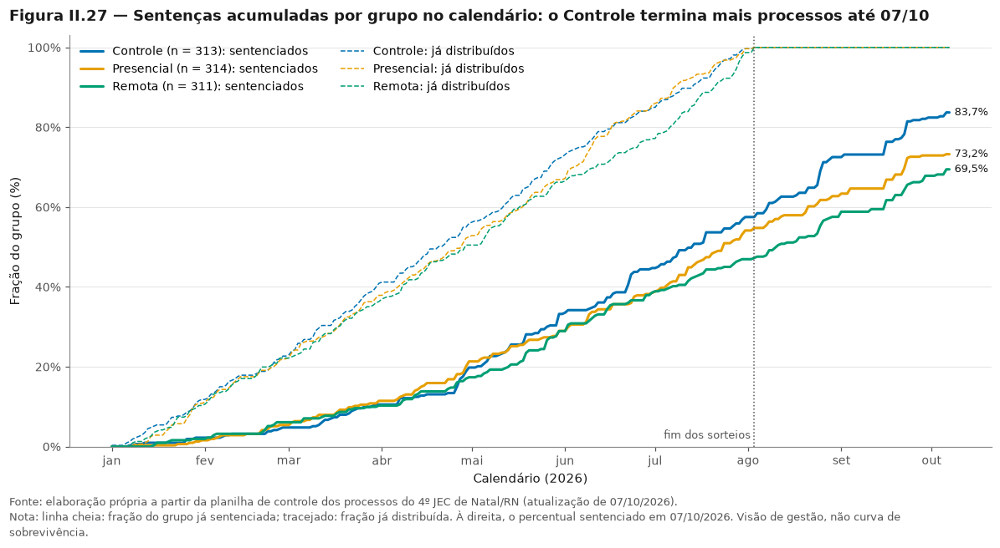

In [64]:
dias_cal = pd.date_range(DATA_INICIO, DATA_CORTE, freq='D')
fig, ax = plt.subplots(figsize=(11, 5.2))
for g in ORDEM_GRUPO:
    s = d2[d2.grupo.eq(g)]
    n_g = len(s)
    sent_ac = np.searchsorted(np.sort(s.loc[s.E.eq(1), 'dt_sentenca'].to_numpy()), dias_cal.to_numpy(), side='right') / n_g
    dist_ac = np.searchsorted(np.sort(s['dt_distribuicao'].to_numpy()), dias_cal.to_numpy(), side='right') / n_g
    ax.plot(dias_cal, sent_ac, color=CORES_GRUPO[g], lw=2, label=f'{g} (n = {n_g}): sentenciados')
    ax.plot(dias_cal, dist_ac, color=CORES_GRUPO[g], lw=1, ls='--', label=f'{g}: já distribuídos')
    ax.annotate(pct_br(sent_ac[-1]), (dias_cal[-1], sent_ac[-1]), xytext=(4, 0), textcoords='offset points',
                va='center', fontsize=8.5, color=TINTA)
ax.axvline(FIM_RECRUTAMENTO, color=TINTA_2, ls=':', lw=1)
ax.text(FIM_RECRUTAMENTO, 0.02, 'fim dos sorteios ', ha='right', fontsize=8.5, color=TINTA_2)
ax.set_ylabel('Fração do grupo (%)'); ax.set_xlabel('Calendário (2026)')
eixo_pct(ax); eixo_meses(ax); ax.set_ylim(0, 1.03)
handles, labels = ax.get_legend_handles_labels()
ordem_leg = [0, 2, 4, 1, 3, 5]
ax.legend([handles[i] for i in ordem_leg], [labels[i] for i in ordem_leg], loc='upper left', ncol=2)
figura(fig, 'exp_calendario', 'Sentenças acumuladas por grupo no calendário: o Controle termina mais processos até 07/10',
       secao='2.6.2', nota='linha cheia: fração do grupo já sentenciada; tracejado: fração já distribuída. À direita, '
                           'o percentual sentenciado em 07/10/2026. Visão de gestão, não curva de sobrevivência.')

**Leitura.** Em 07/10/2026, o Controle tinha 83,7% dos seus processos sentenciados (262/313), contra 73,2% da Presencial (230/314) e 69,5% da Remota (216/311). As curvas de sentenças acumuladas andam juntas até maio e se separam a partir de junho, com o Controle à frente. Parte dessa distância é calendário: as linhas tracejadas mostram que a Remota recebeu mais processos no fim (julho), que ainda não tiveram tempo de terminar. Outra parte pode ser efeito do rito (a etapa da audiência). Separar as duas coisas exige comparar processos **da mesma idade**, que é o que fazem o Kaplan-Meier e o Cox com o mês como covariável (Parte IV). A proporção de encerrados por grupo em uma data fixa, usada no notebook do professor (χ² de grupo × situação, E19), não faz essa separação.

### 2.6.3 Tabelas cruzadas e gráficos de mosaico

Para cada par, três versões: contagens, % na linha (distribuição do desfecho *dentro* de cada grupo: a leitura de interesse quando o grupo é a "causa") e % na coluna (de onde vêm os casos de cada categoria). O **mosaico** representa a tabela por áreas: a largura de cada coluna é proporcional ao tamanho do grupo e a altura de cada retângulo, à % na linha; se não houvesse associação, os retângulos se alinhariam em faixas horizontais. A significância e os resíduos ajustados são da Parte III.

- **grupo × tipo de desfecho** (938; inclui Ativo e Redistribuição como situações em 07/10);
- **grupo × acordo** (acordo em qualquer momento; os ativos ficam numa categoria própria, "indefinido");
- **grupo × mês de distribuição** (o calendário do sorteio);
- **técnica × acordo na AC** (352 AC realizadas).

In [65]:
def cruzada(linha, coluna, titulo, id_):
    ct = pd.crosstab(linha, coluna)
    lin = 100 * ct.div(ct.sum(axis=1), axis=0)
    col = 100 * ct.div(ct.sum(axis=0), axis=1)
    saida = pd.concat({'n': ct, '% na linha': lin, '% na coluna': col}, axis=1)
    saida.index = saida.index.astype(object)
    saida.columns = pd.MultiIndex.from_tuples([(a, str(b)) for a, b in saida.columns])
    tabela(saida.rename_axis(index=ct.index.name), id_, titulo, secao='2.6.3', casas=1,
           nota='% na linha: distribuição da coluna dentro de cada categoria da linha; % na coluna: de onde vêm os casos de cada coluna.')
    return ct

d2['acordo_cat'] = d2['acordo'].map({True: 'Com acordo', False: 'Sem acordo'}).fillna('Indefinido (ativo)')
ac['acordo_ac_txt'] = ac['acordo_ac'].map({True: 'Acordo na AC', False: 'Sem acordo na AC'})
ct_desf = cruzada(d2['grupo'].rename('Grupo'), d2['tipo_desfecho'], 'Grupo × tipo de desfecho (938 processos)', 'exp_ct_desfecho')
ct_acordo = cruzada(d2['grupo'].rename('Grupo'), d2['acordo_cat'], 'Grupo × acordo em qualquer momento', 'exp_ct_acordo')
ct_mes = cruzada(d2['grupo'].rename('Grupo'), d2['mes_distribuicao'], 'Grupo × mês de distribuição', 'exp_ct_mes')
ct_tec = cruzada(ac['tecnica_curta'].cat.remove_unused_categories().rename('Técnica'), ac['acordo_ac_txt'],
                 'Técnica × acordo na AC (AC realizadas)', 'exp_ct_tecnica')

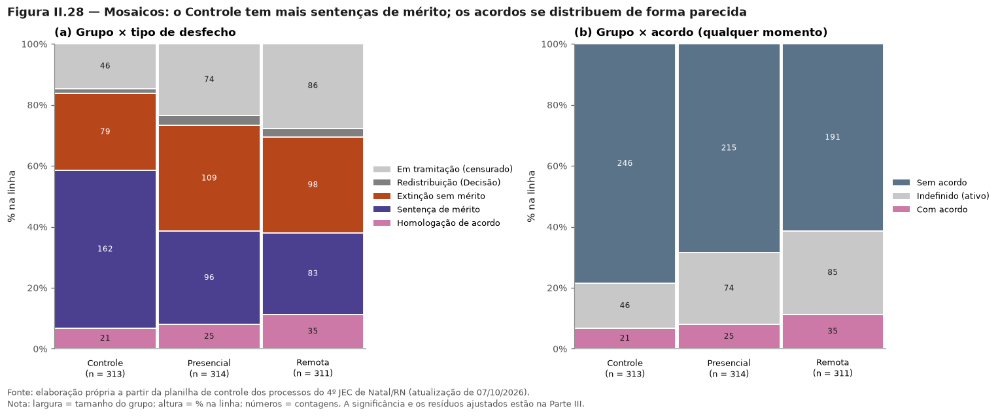

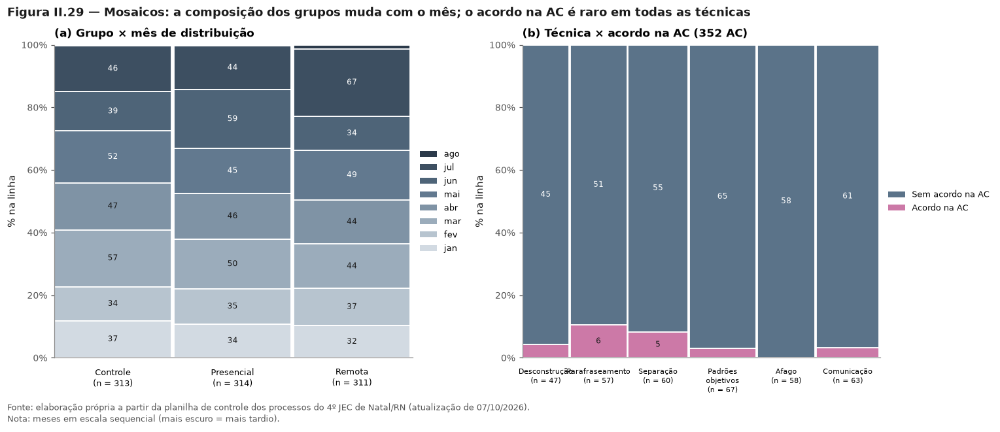

In [66]:
def mosaico(ax, ct, cores_col, titulo, rotulos_col=None, quebrar=12):
    # Mosaico manual: largura = tamanho da linha; altura = % na linha
    tot = ct.to_numpy().sum()
    x0 = 0
    for lin in ct.index:
        larg = ct.loc[lin].sum() / tot
        y0 = 0
        for colu in ct.columns:
            h = ct.loc[lin, colu] / ct.loc[lin].sum()
            ax.add_patch(mpl.patches.Rectangle((x0, y0), larg * 0.98, h, facecolor=cores_col[colu], edgecolor='white', lw=1.2))
            if h > 0.05 and larg > 0.06:
                ax.text(x0 + larg * 0.49, y0 + h / 2, fmt_br(ct.loc[lin, colu], 0), ha='center', va='center', fontsize=8,
                        color=_cor_texto(cores_col[colu]))
            y0 += h
        ax.text(x0 + larg * 0.49, -0.03, f'{quebra(str(lin), quebrar)}\n(n = {int(ct.loc[lin].sum())})', ha='center',
                va='top', fontsize=8.5)
        x0 += larg
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xticks([]); ax.grid(False)
    eixo_pct(ax)
    ax.set_ylabel('% na linha')
    ax.legend(handles=[mpl.patches.Patch(color=cores_col[c], label=(rotulos_col or {}).get(c, str(c))) for c in ct.columns][::-1],
              loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8.5)
    ax.set_title(titulo)

cores_mes = dict(zip(MESES, [mpl.colors.to_hex(SEQ(v)) for v in np.linspace(0.15, 1, len(MESES))]))
cores_acordo = {'Com acordo': CORES_DESFECHO['Homologação'], 'Sem acordo': '#5B7389', 'Indefinido (ativo)': CORES_DESFECHO['Ativo']}
fig, ax = plt.subplots(1, 2, figsize=(14, 5.2))
mosaico(ax[0], ct_desf, CORES_DESFECHO, '(a) Grupo × tipo de desfecho', ROTULO_DESFECHO)
mosaico(ax[1], ct_acordo, cores_acordo, '(b) Grupo × acordo (qualquer momento)')
figura(fig, 'exp_mosaico_desfecho', 'Mosaicos: o Controle tem mais sentenças de mérito; os acordos se distribuem de forma parecida',
       secao='2.6.3', nota='largura = tamanho do grupo; altura = % na linha; números = contagens. A significância e os '
                           'resíduos ajustados estão na Parte III.')
fig, ax = plt.subplots(1, 2, figsize=(14, 5.4))
mosaico(ax[0], ct_mes, cores_mes, '(a) Grupo × mês de distribuição')
mosaico(ax[1], ct_tec, {'Acordo na AC': CORES_DESFECHO['Homologação'], 'Sem acordo na AC': '#5B7389'},
        f'(b) Técnica × acordo na AC ({int(ct_tec.to_numpy().sum())} AC)', quebrar=9)
for t in ax[1].texts:
    if '(n =' in t.get_text():
        t.set_fontsize(7.5)
figura(fig, 'exp_mosaico_mes_tecnica', 'Mosaicos: a composição dos grupos muda com o mês; o acordo na AC é raro em todas as técnicas',
       secao='2.6.3', nota='meses em escala sequencial (mais escuro = mais tardio).')

**Leitura (as associações são testadas na Parte III).**

- **Grupo × tipo de desfecho.** Na % na linha, o Controle tem 51,8% de sentenças de mérito, contra 30,6% (Presencial) e 26,7% (Remota); e menos extinções sem mérito (25,2% contra 34,7% e 31,5%). Os ativos são 14,7%, 23,6% e 27,7%. Na % na coluna, 47,5% de todas as sentenças de mérito vêm do Controle, e 43,2% das homologações vêm da Remota. No mosaico, as faixas não se alinham: a estrutura de desfechos muda com o rito.
- **Grupo × acordo.** Com acordo: 6,7% (Controle), 8,0% (Presencial) e 11,3% (Remota) dos processos; a categoria "indefinido" (ativos) cresce na mesma ordem, o que torna qualquer comparação de taxas de acordo sobre os distribuídos sensível à censura.
- **Grupo × mês.** A composição é parecida de janeiro a maio (cada grupo entre 29% e 38% de cada mês). As exceções são junho, com 44,7% de Presencial, e julho, com 42,7% de Remota (seção 2.5.1).
- **Técnica × acordo na AC.** As taxas de acordo vão de 0% (Afago, 0/58) a 10,5% (Parafraseamento, 6/57) e 8,3% (Separação, 5/60). As demais ficam entre 3,0% e 4,3%. Com 17 acordos no total, as diferenças são frágeis (células com 0 a 6 eventos).

### 2.6.4 Matriz de associação: a substituta correta da matriz de correlações do professor

**O problema da matriz original (questão 2.7; E6, E16).** O notebook do professor calculou uma matriz de correlação de Spearman entre as colunas `DURAÇÃO-SENT2`, `DURAÇÃO-SORT`, `DURAÇÃO-PROC` e `DURAÇÃO-TECN`. As três primeiras são **a mesma fórmula** repetida, e a quarta é a mesma duração apagada onde não houve técnica: a matriz dá r = 1 em todos os pares por construção (tautologia), não por achado empírico. Além disso, as demais variáveis do banco são **nominais** (grupo, desfecho, técnica, acordo, híbrida), e o coeficiente de Pearson ou Spearman sobre códigos numéricos de categorias não tem sentido. A célula abaixo reproduz o resultado tautológico a partir dos dados brutos.

**A matriz correta** usa, para cada par, a medida adequada aos níveis de mensuração:

| Par | Medida | Faixa |
|---|---|---|
| nominal × nominal | **V de Cramér com correção de viés** (Bergsma, 2013): corrige a inflação do V em tabelas grandes com n moderado | 0 a 1 |
| tempo (sentenciados) × nominal | **razão de correlação η** = √(SQ entre / SQ total) | 0 a 1 |
| ordinal × tempo | **Spearman ρ** e **Kendall τ_b** (seção 2.6.5) | −1 a 1 |

Cada par usa os casos com as duas variáveis definidas (exclusão aos pares). **Associações estruturais** (por exemplo, grupo × AC realizada: o Controle nunca tem AC) aparecem fortes por definição, e não são achados.

In [67]:
if 'dados_brutos' in globals():
    _brutos = dados_brutos
else:
    _brutos = pd.read_excel(BRUTO, sheet_name='Processos', header=1, engine='openpyxl')
cols_dur = ['DURAÇÃO-SENT2', 'DURAÇÃO-SORT', 'DURAÇÃO-PROC', 'DURAÇÃO-TECN']
matriz_prof = _brutos[cols_dur].apply(pd.to_numeric, errors='coerce').corr(method='spearman')
tabela(matriz_prof.rename_axis('Coluna'), 'exp_matriz_professor',
       'Matriz do notebook do professor (Spearman entre as quatro colunas de duração): tautológica', secao='2.6.4', casas=4)
print('Linhas em que as colunas coincidem com DURAÇÃO-PROC:',
      {c: int((_brutos[c] == _brutos['DURAÇÃO-PROC']).sum()) for c in cols_dur}, '| não nulas:',
      {c: int(_brutos[c].notna().sum()) for c in cols_dur})

Coluna,DURAÇÃO-SENT2,DURAÇÃO-SORT,DURAÇÃO-PROC,DURAÇÃO-TECN
DURAÇÃO-SENT2,1,1,1,1
DURAÇÃO-SORT,1,1,1,1
DURAÇÃO-PROC,1,1,1,1
DURAÇÃO-TECN,1,1,1,1


Linhas em que as colunas coincidem com DURAÇÃO-PROC: {'DURAÇÃO-SENT2': 943, 'DURAÇÃO-SORT': 943, 'DURAÇÃO-PROC': 943, 'DURAÇÃO-TECN': 428} | não nulas: {'DURAÇÃO-SENT2': 943, 'DURAÇÃO-SORT': 943, 'DURAÇÃO-PROC': 943, 'DURAÇÃO-TECN': 428}


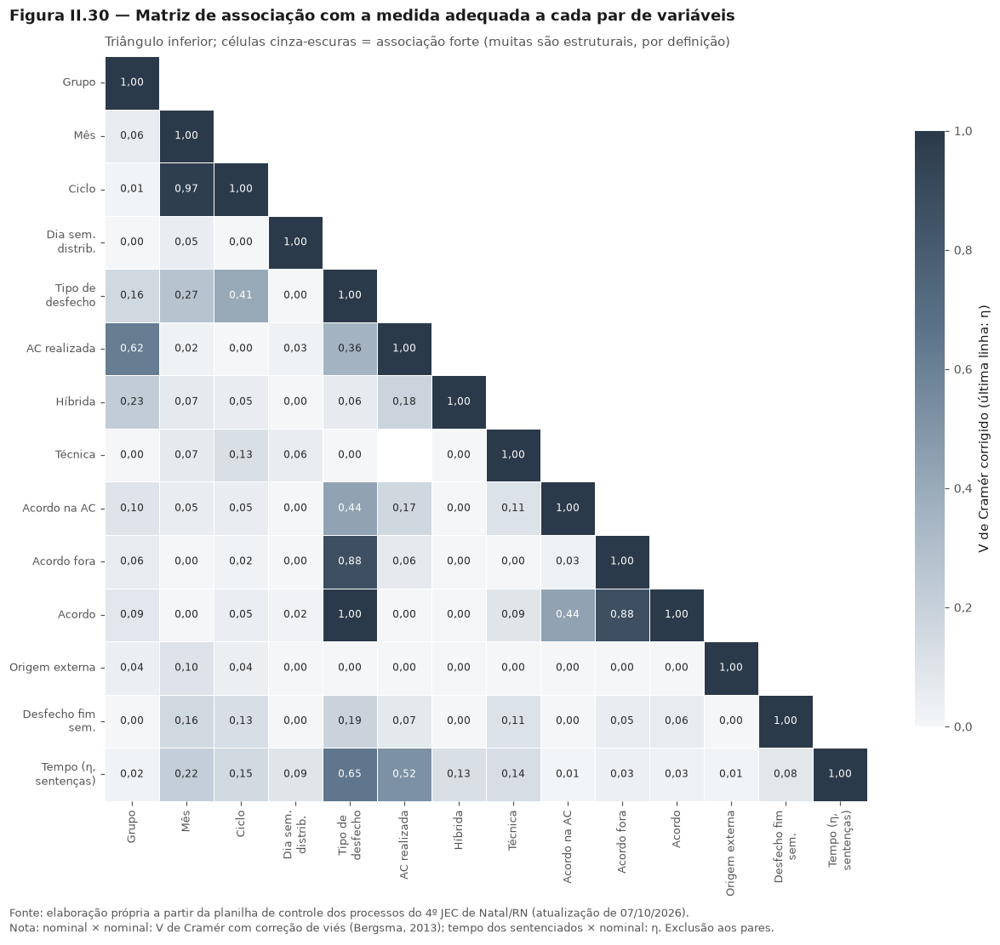

Variável 1,Variável 2,Associação (V ou η)
Acordo,Tipo de desfecho,"0,998"
Ciclo,Mês,"0,973"
Acordo,Acordo fora,"0,877"
Acordo fora,Tipo de desfecho,"0,875"
"Tempo (η, sentenças)",Tipo de desfecho,"0,651"
AC realizada,Grupo,"0,624"
"Tempo (η, sentenças)",AC realizada,"0,523"
Acordo,Acordo na AC,"0,436"
Acordo na AC,Tipo de desfecho,"0,435"
Tipo de desfecho,Ciclo,"0,408"


In [68]:
def cramer_v_corrigido(x, y):
    ok = x.notna() & y.notna()
    ct = pd.crosstab(x[ok].astype(str), y[ok].astype(str))
    if ct.shape[0] < 2 or ct.shape[1] < 2:
        return np.nan
    n = ct.to_numpy().sum()
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    phi2 = chi2 / n
    r, c = ct.shape
    phi2c = max(0, phi2 - (c - 1) * (r - 1) / (n - 1))
    rc, cc = r - (r - 1) ** 2 / (n - 1), c - (c - 1) ** 2 / (n - 1)
    return np.sqrt(phi2c / min(rc - 1, cc - 1)) if min(rc, cc) > 1 else np.nan

VARS_ASSOC = {'grupo': 'Grupo', 'mes_distribuicao': 'Mês', 'ciclo': 'Ciclo', 'dia_semana_distribuicao': 'Dia sem. distrib.',
              'tipo_desfecho': 'Tipo de desfecho', 'ac_realizada': 'AC realizada', 'hibrida': 'Híbrida',
              'tecnica_curta': 'Técnica', 'acordo_ac': 'Acordo na AC', 'acordo_fora': 'Acordo fora',
              'acordo': 'Acordo', 'origem_externa': 'Origem externa', 'sentenca_fim_semana': 'Desfecho fim sem.'}
nomes = list(VARS_ASSOC.values())
mat_v = pd.DataFrame(np.nan, index=nomes + ['Tempo (η, sentenças)'], columns=nomes + ['Tempo (η, sentenças)'])
for i, (vi, ni) in enumerate(VARS_ASSOC.items()):
    for vj, nj in list(VARS_ASSOC.items())[i:]:
        val = 1.0 if vi == vj else cramer_v_corrigido(d2[vi].astype(object), d2[vj].astype(object))
        mat_v.loc[ni, nj] = mat_v.loc[nj, ni] = val
    eta = np.sqrt(eta2(sent['T'], sent[vi].astype(object))) if sent[vi].astype(object).nunique() > 1 else np.nan
    mat_v.loc[ni, 'Tempo (η, sentenças)'] = mat_v.loc['Tempo (η, sentenças)', ni] = eta
mat_v.loc['Tempo (η, sentenças)', 'Tempo (η, sentenças)'] = 1.0

fig, ax = plt.subplots(figsize=(11.5, 9.5))
mascara = np.triu(np.ones_like(mat_v, dtype=bool), k=1)
anot = mat_v.astype(float).map(lambda v: '' if pd.isna(v) else fmt_br(v, 2))
rot_mat = [quebra(c, 14) for c in mat_v.index]
sns.heatmap(mat_v.astype(float), mask=mascara, annot=anot.to_numpy(), fmt='', cmap=SEQ, vmin=0, vmax=1, ax=ax,
            cbar_kws={'label': 'V de Cramér corrigido (última linha: η)', 'shrink': 0.8}, annot_kws={'fontsize': 8},
            linewidths=0.6, linecolor='white', xticklabels=rot_mat, yticklabels=rot_mat)
ax.tick_params(axis='x', labelsize=8.5, rotation=90); ax.tick_params(axis='y', labelsize=8.5, rotation=0)
ax.set_title('Triângulo inferior; células cinza-escuras = associação forte (muitas são estruturais, por definição)',
             fontsize=9.5, fontweight='normal', color=TINTA_2)
figura(fig, 'exp_matriz_associacao', 'Matriz de associação com a medida adequada a cada par de variáveis', secao='2.6.4',
       nota='nominal × nominal: V de Cramér com correção de viés (Bergsma, 2013); tempo dos sentenciados × nominal: η. '
            'Exclusão aos pares.')
pares = (mat_v.where(~mascara & ~np.eye(len(mat_v), dtype=bool)).stack().sort_values(ascending=False))
tabela(pares.head(15).rename('Associação (V ou η)').rename_axis(['Variável 1', 'Variável 2']).reset_index(),
       'exp_pares_associacao', 'As 15 associações mais fortes entre pares de variáveis', secao='2.6.4', casas=3)

**Leitura. A matriz do professor era tautológica; a matriz correta separa associações estruturais de associações empíricas.**

- **Reprodução do erro (E6, E16).** As quatro colunas de duração da planilha coincidem em todas as linhas em que existem (943, 943, 943 e 428), e a matriz de Spearman entre elas dá 1,0 em todas as células: é a mesma variável, não uma correlação. Por isso a resposta à questão 2.7 é **não**: a matriz inicial não é adequada.
- **Associações estruturais (fortes por definição):** acordo × tipo de desfecho (V = 1,00: acordo ⇔ homologação); ciclo × mês (0,97); acordo × acordo fora (0,88); grupo × AC realizada (0,62: o Controle não tem AC); grupo × híbrida (0,23). A célula técnica × AC realizada fica vazia porque a técnica só existe quando há AC. Nenhuma delas é achado.
- **Associações empíricas relevantes:**
  - **grupo × tipo de desfecho, V = 0,16** (fraca a moderada): o efeito do rito sobre a composição dos desfechos (seções 2.5.2 e 2.6.3);
  - **tipo de desfecho × ciclo (0,41) e × mês (0,27):** efeito da censura (os meses tardios ainda não têm sentenças de mérito);
  - **tempo × tipo de desfecho, η = 0,65**, e **tempo × AC realizada, η = 0,52:** a etapa processual define o tempo;
  - **tempo × mês, η = 0,22:** censura de novo;
  - **tempo × grupo, η = 0,02:** desprezível entre os sentenciados (mas ver o efeito de composição na seção 2.6.1);
  - **grupo × mês, V = 0,06:** fraca, mas com as concentrações de junho e julho vistas acima;
  - **desfecho em fim de semana × tipo, V = 0,19** (seção 2.5.4).
- **Leitura geral.** As variáveis pós-sorteio (AC, acordo, tipo de desfecho) estão fortemente associadas ao tempo, e o grupo se associa ao tempo **através** delas. Isso orienta a modelagem: o efeito total do rito se estima sem essas variáveis (Parte IV); os mecanismos, com riscos competitivos e análises restritas às AC.

### 2.6.5 Ordem de chegada × tempo (questão 2.7)

**É possível investigar?** Sim: a ordem de chegada é uma variável **ordinal** (1 = primeiro distribuído), equivalente à data de distribuição, e o tempo é quantitativo; o par admite **Spearman ρ** e **Kendall τ_b** (robustos a não normalidade e a empates), nunca Pearson sobre os códigos. **Mas a censura cria uma correlação negativa espúria**: os processos que chegaram tarde têm seguimento curto (65 dias para os de agosto), então só podem aparecer como sentenciados se forem rápidos, e, se ativos, o seu tempo observado é pequeno. O tempo observado é limitado por cima pela "diagonal" `followup` = 07/10/2026 − distribuição.

Três versões, para separar o artefato do efeito:

1. **Todos os tempos observados** (mistura sentenças e censuras): inválida, mostrada para expor o artefato;
2. **Só os sentenciados**: condicional, enviesada pelo mesmo mecanismo;
3. **Tempo truncado em 65 dias**, min(tempo, 65), para os 938: como **todos** os processos têm pelo menos 65 dias de seguimento, essa variável é observada sem censura para todos (o redistribuído antes de 65 dias conta pelo seu tempo); é a comparação **justa** dentro de uma janela comum.

Na primeira figura, a curva LOWESS (regressão local, fração de 0,3) mostra a tendência e a cor distingue sentenças de censurados; a linha em destaque é o teto imposto pelo seguimento. Na segunda, a versão 3 é resumida como a proporção de processos sentenciados em até 65 dias, por mês de distribuição e grupo, com o ρ de Spearman de cada grupo na legenda. O teste formal (Cox com a ordem ou o mês como covariável) fica para as Partes IV e V.

Versão,n,Spearman ρ,p (ρ),Kendall τ_b,p (τ)
Todos os tempos observados (inválido),938,"-0,041","0,211","-0,050","0,024"
Só sentenciados (condicional),708,"-0,118","0,002","-0,082","0,001"
"min(tempo, 65) — todos, janela comum",938,"0,138","< 0,001","0,105","< 0,001"
Seguimento máximo (followup) — referência,938,"-1,000","< 0,001","-0,997","< 0,001"
"min(tempo, 65) — Controle",313,"0,034","0,555","0,027","0,529"
"min(tempo, 65) — Presencial",314,"0,155","0,006","0,118","0,005"
"min(tempo, 65) — Remota",311,"0,216","< 0,001","0,165","< 0,001"


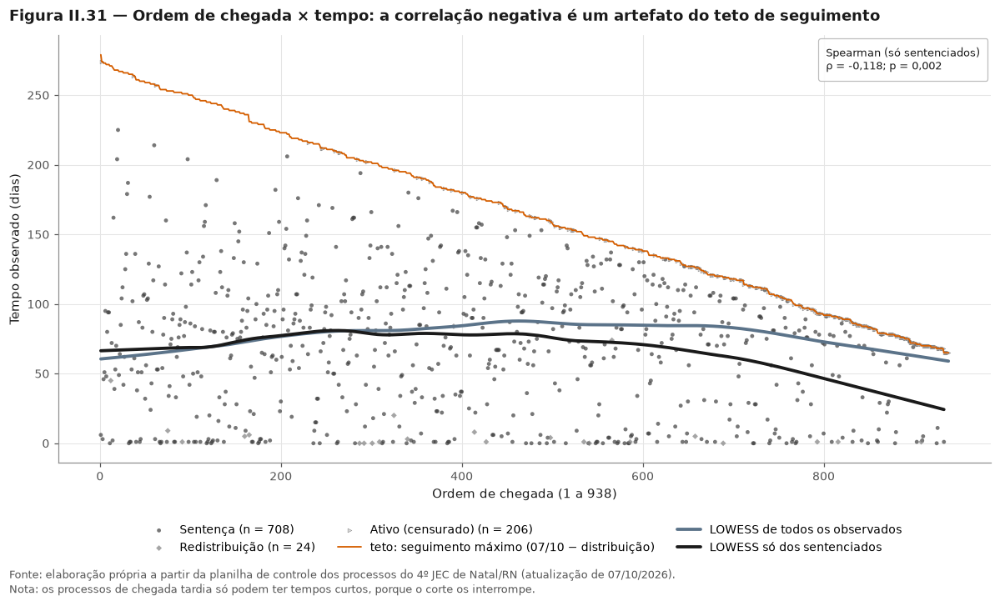

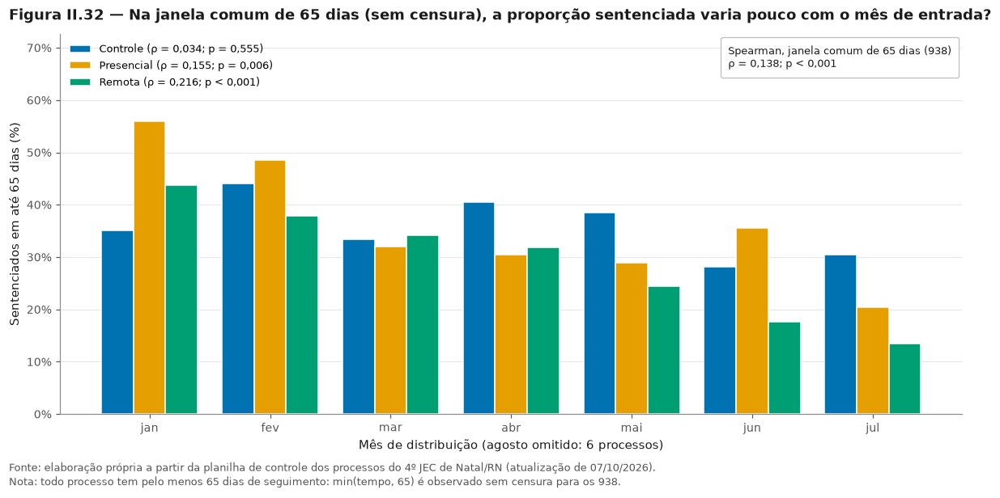

In [69]:
ordem = d2['ordem_chegada'].astype(float)
d2['T65'] = np.minimum(d2['T'], 65)
versoes = {'Todos os tempos observados (inválido)': (ordem, d2['T']),
           'Só sentenciados (condicional)': (sent['ordem_chegada'].astype(float), sent['T']),
           'min(tempo, 65) — todos, janela comum': (ordem, d2['T65']),
           'Seguimento máximo (followup) — referência': (ordem, d2['followup'].astype(float))}
linhas = []
for nome, (xo, yt) in versoes.items():
    rho = stats.spearmanr(xo, yt); tau = stats.kendalltau(xo, yt)
    linhas.append({'Versão': nome, 'n': len(xo), 'Spearman ρ': rho.statistic, 'p (ρ)': rho.pvalue,
                   'Kendall τ_b': tau.statistic, 'p (τ)': tau.pvalue})
for g in ORDEM_GRUPO:
    m = d2.grupo.eq(g)
    rho = stats.spearmanr(ordem[m], d2.loc[m, 'T65']); tau = stats.kendalltau(ordem[m], d2.loc[m, 'T65'])
    linhas.append({'Versão': f'min(tempo, 65) — {g}', 'n': int(m.sum()), 'Spearman ρ': rho.statistic,
                   'p (ρ)': rho.pvalue, 'Kendall τ_b': tau.statistic, 'p (τ)': tau.pvalue})
tab_ordem = pd.DataFrame(linhas).set_index('Versão')
tabela(tab_ordem, 'exp_ordem_tempo', 'Ordem de chegada × tempo: correlações de postos em quatro versões do tempo', secao='2.6.5',
       casas=3, nota='só a versão min(tempo, 65) é observada sem censura para todos; as demais carregam o artefato da censura.')

fig, ax = plt.subplots(figsize=(11, 6))
for s, mk in [('Sentença', 'o'), ('Redistribuição', 'D'), ('Ativo (censurado)', '>')]:
    m = d2.status.eq(s)
    ax.scatter(ordem[m], d2.loc[m, 'T'], s=10, color=CORES_STATUS[s], marker=mk, alpha=0.7,
               edgecolors=TINTA_2 if s == 'Ativo (censurado)' else 'none', linewidths=0.3, label=f'{s} (n = {int(m.sum())})')
ax.plot(ordem.sort_values(), d2.loc[ordem.sort_values().index, 'followup'], color=DESTAQUE, lw=1.2,
        label='teto: seguimento máximo (07/10 − distribuição)')
for nome, (xo, yt), cor in [('LOWESS de todos os observados', versoes['Todos os tempos observados (inválido)'], '#5B7389'),
                            ('LOWESS só dos sentenciados', versoes['Só sentenciados (condicional)'], TINTA)]:
    lw_ = lowess(yt.to_numpy(float), xo.to_numpy(float), frac=0.3)
    ax.plot(lw_[:, 0], lw_[:, 1], color=cor, lw=2.5, label=nome)
ax.set_xlabel(ROTULOS['ordem_chegada']); ax.set_ylabel('Tempo observado (dias)')
ax.grid(axis='both', visible=True)
legenda_abaixo(ax, ncol=3, dy=-0.12)
anotar_teste(ax, texto_teste('Spearman (só sentenciados)', f'ρ = {fmt_br(tab_ordem.iloc[1]["Spearman ρ"], 3)}',
                             tab_ordem.iloc[1]['p (ρ)']), loc='upper right')
figura(fig, 'exp_ordem_dispersao', 'Ordem de chegada × tempo: a correlação negativa é um artefato do teto de seguimento',
       secao='2.6.5', nota='os processos de chegada tardia só podem ter tempos curtos, porque o corte os interrompe.')

d2['sent65'] = d2['T'].le(65) & d2['E'].eq(1)
prop65 = d2.groupby(['mes_distribuicao', 'grupo'], observed=True)['sent65'].mean().unstack().reindex(columns=ORDEM_GRUPO)
prop65 = prop65.drop(index='ago')   # 6 processos
fig, ax = plt.subplots(figsize=(11, 5))
rot65 = {g: f'{g} (ρ = {fmt_br(tab_ordem.loc[f"min(tempo, 65) — {g}", "Spearman ρ"], 3)}; '
            f'{p_igual(tab_ordem.loc[f"min(tempo, 65) — {g}", "p (ρ)"])})' for g in ORDEM_GRUPO}
barras_agrupadas(ax, prop65.rename(columns=rot65), cores={rot65[g]: CORES_GRUPO[g] for g in ORDEM_GRUPO},
                 xlabel='Mês de distribuição (agosto omitido: 6 processos)', ylabel='Sentenciados em até 65 dias (%)')
eixo_pct(ax); ax.set_ylim(0, max(0.7, prop65.to_numpy().max() * 1.3))
ax.legend(loc='upper left', ncol=1, fontsize=8.5)
anotar_teste(ax, texto_teste('Spearman, janela comum de 65 dias (938)', f'ρ = {fmt_br(tab_ordem.iloc[2]["Spearman ρ"], 3)}',
                             tab_ordem.iloc[2]['p (ρ)']), loc='upper right')
figura(fig, 'exp_janela65', 'Na janela comum de 65 dias (sem censura), a proporção sentenciada varia pouco com o mês de entrada?',
       secao='2.6.5', nota='todo processo tem pelo menos 65 dias de seguimento: min(tempo, 65) é observado sem censura para os 938.')

**Leitura (questão 2.7). A correlação negativa entre ordem de chegada e tempo é artefato; na janela comum, ela se inverte.**

- **Versões ingênuas.** Com todos os tempos observados, ρ = −0,041 (p = 0,211; τ_b = −0,050, p = 0,024). Só com os sentenciados, ρ = **−0,118** (p = 0,002; τ_b = −0,082). O sinal negativo é o esperado pelo mecanismo da censura: no gráfico da esquerda, os pontos ficam sob o "teto" do seguimento máximo (ρ = −1 entre ordem e seguimento, por construção), e a curva LOWESS dos sentenciados cai depois da posição 600, porque os processos de junho e julho só aparecem como sentenciados se forem rápidos.
- **Versão justa: min(tempo, 65).** Como todos os processos têm pelo menos 65 dias de seguimento, essa variável é observada para todos, sem censura. O sinal se **inverte**: ρ = **+0,138** (p < 0,001; τ_b = +0,105). Os processos que chegaram depois demoraram mais nos primeiros 65 dias: 38,1% dos do 1º ciclo foram sentenciados nesse prazo, contra 26,5% dos do 2º ciclo.
- **E isso só nos tratados.** No Controle, ρ = 0,034 (p = 0,555); na Presencial, ρ = 0,155 (p = 0,006); na Remota, ρ = 0,216 (p < 0,001). O gráfico da direita mostra a fração sentenciada em até 65 dias caindo de janeiro (44% na Remota, 56% na Presencial) para julho (13% e 20%), enquanto o Controle oscila entre 28% e 44% sem tendência. A leitura mais provável é o **congestionamento da pauta de audiências**: à medida que o experimento avançou, a fila de AC (presenciais até 22/10 e remotas até 24/11) alongou o início dos processos tratados, o que não aconteceu no rito sem audiência.
- **Resposta à questão 2.7.** É possível investigar a relação entre a ordem de chegada e a duração, com Spearman ou Kendall (a ordem é ordinal), mas não sobre `duracao_proc` bruta, que mistura censurados; é preciso uma janela comum (como aqui) ou um modelo de sobrevivência com a ordem ou o mês como covariável (Partes IV e V). O resultado aponta uma **interação entre rito e calendário**, relevante para a validade interna: o efeito da AC obrigatória sobre o tempo parece ter crescido ao longo do experimento.

## 2.7 Síntese exploratória

A tabela reúne os achados da Parte II, a medida que os sustenta e o encaminhamento para as partes seguintes.

In [70]:
melhor_aic = tab_ajuste['AIC'].idxmin()
melhor_param = tab_ajuste.drop(index='Exponencial por partes')['AIC'].idxmin()
sintese = pd.DataFrame([
    ('Variável-alvo', f'{len(sent)} sentenças, {(d2.evento_cr == 0).sum()} ativos e {(d2.evento_cr == 2).sum()} redistribuições; seguimento de 65 a 279 dias',
     'Tempo censurado: análise de sobrevivência (Parte IV)'),
    ('Médias da pesquisa', f'78,46 e 75,2 reproduzidas como médias "mistas" (sentenças + ativos) com corte em 07/10 '
     f'({fmt_br(tab_medias.loc["Todos", "Mista, 944 linhas, corte 07/10 (planilha: 78,46)"], 2)}) e 23/09 '
     f'({fmt_br(tab_medias.loc["Todos", "Mista, 944 linhas, corte 23/09 (resumo: 75,2)"], 2)}); só sentenciados = {fmt_br(sent["T"].mean(), 2)}; '
     f'mediana do KM = {fmt_br(kmf_total.median_survival_time_)}',
     'Nenhuma estima a duração; substituir por mediana do KM e RMST (Parte IV)'),
    ('Distribuição das sentenças', f'mediana {fmt_br(tab_desc.loc["mediana", "Sentenças (condicional)"])} d '
     f'(IC95% {fmt_br(tab_desc.loc["IC95% mediana (inf.)", "Sentenças (condicional)"])}–{fmt_br(tab_desc.loc["IC95% mediana (sup.)", "Sentenças (condicional)"])}); '
     f'assimetria {fmt_br(tab_desc.loc["assimetria", "Sentenças (condicional)"], 2)}; curtose {fmt_br(tab_desc.loc["curtose (excesso)", "Sentenças (condicional)"], 2)}',
     'Bimodal (extinções precoces × mérito)'),
    ('Normalidade', f'{(tab_norm["Decisão (5%)"] == "rejeita H0").sum()} de {len(tab_norm)} testes rejeitam H0 (Holm)',
     'Testes não paramétricos na Parte III'),
    ('Ajuste com censura', f'menor AIC: {melhor_aic}; melhor paramétrico: {melhor_param}',
     'Risco não monótono (pico inicial, vale, subida): nenhum AFT padrão ajusta bem; preferir Cox, KM e RMST'),
    ('Sorteio dos grupos', f'313/314/311: P(divisão tão equilibrada) = {fmt_br(tab_equilibrio.iloc[1]["P(divisão tão equilibrada) exata (esq.)"], 4)}',
     'Aleatorização com totais equilibrados (não blocos pequenos): documentar; corridas na Parte III'),
    ('Índice de conciliação', f'{tab_bin.iloc[0]["k"]}/{tab_bin.iloc[0]["n"]} = {pct_br(tab_bin.iloc[0]["p̂"])} das sentenças '
     f'({p_txt(tab_bin.iloc[0]["p"])} contra 13,3%)', 'Comparação entre grupos na Parte III; riscos competitivos na Parte IV'),
    ('Sem mérito', f'Controle {pct_br(tab_sm.iloc[0]["p̂"])} × Presencial {pct_br(tab_sm.iloc[1]["p̂"])} × Remota {pct_br(tab_sm.iloc[2]["p̂"])} das sentenças',
     'Excesso concentrado em extinções precoces sem AC; testar na Parte III e conferir motivos no PJe'),
    ('Acordo na AC', f'{int(ac.acordo_ac.sum())}/{len(ac)} = {pct_br(ac.acordo_ac.mean())} das AC realizadas',
     'Logit restrito às AC na Parte V'),
    ('Técnicas', f'Padrões objetivos = {pct_br(k_po / n_ac)} (não 53,85%); aderência a 1/6: p = {p_br(tab_tec.iloc[0]["p exato (Monte Carlo)"])}',
     'Sorteio das técnicas compatível com uniforme'),
    ('Fim de semana', f'{pct_br(tab_fds.iloc[0]["p̂"])} dos desfechos ({p_txt(tab_fds.iloc[0]["p"])} contra 2/7)',
     'Data = assinatura eletrônica; conferir no PJe'),
    ('Ordem × tempo', f'ρ sentenciados = {fmt_br(tab_ordem.iloc[1]["Spearman ρ"], 3)}; ρ na janela de 65 d = {fmt_br(tab_ordem.iloc[2]["Spearman ρ"], 3)}',
     'Cox com mês/ordem (Partes IV e V)'),
], columns=['Tema', 'Resultado', 'Encaminhamento'])
tabela(sintese, 'exp_sintese', 'Síntese da Parte II: achados, medidas e encaminhamentos', secao='2.7')

Tema,Resultado,Encaminhamento
Variável-alvo,"708 sentenças, 206 ativos e 24 redistribuições; seguimento de 65 a 279 dias",Tempo censurado: análise de sobrevivência (Parte IV)
Médias da pesquisa,"78,46 e 75,2 reproduzidas como médias ""mistas"" (sentenças + ativos) com corte em 07/10 (78,45) e 23/09 (75,15); só sentenciados = 70,98; mediana do KM = 89,0",Nenhuma estima a duração; substituir por mediana do KM e RMST (Parte IV)
Distribuição das sentenças,"mediana 73,5 d (IC95% 70,0–78,0); assimetria 0,21; curtose -0,56",Bimodal (extinções precoces × mérito)
Normalidade,17 de 20 testes rejeitam H0 (Holm),Testes não paramétricos na Parte III
Ajuste com censura,menor AIC: Exponencial por partes; melhor paramétrico: Gama generalizada,"Risco não monótono (pico inicial, vale, subida): nenhum AFT padrão ajusta bem; preferir Cox, KM e RMST"
Sorteio dos grupos,"313/314/311: P(divisão tão equilibrada) = 0,0105",Aleatorização com totais equilibrados (não blocos pequenos): documentar; corridas na Parte III
Índice de conciliação,"81/708 = 11,4% das sentenças (p = 0,150 contra 13,3%)",Comparação entre grupos na Parte III; riscos competitivos na Parte IV
Sem mérito,"Controle 30,2% × Presencial 47,4% × Remota 45,4% das sentenças",Excesso concentrado em extinções precoces sem AC; testar na Parte III e conferir motivos no PJe
Acordo na AC,"17/352 = 4,8% das AC realizadas",Logit restrito às AC na Parte V
Técnicas,"Padrões objetivos = 19,0% (não 53,85%); aderência a 1/6: p = 0,566",Sorteio das técnicas compatível com uniforme


**Síntese da Parte II.**

1. **A variável-alvo é censurada.** São 708 sentenças, 206 ativos e 24 redistribuições, com seguimento de 65 a 279 dias que depende do mês de entrada. Todas as médias divulgadas (78,46 e 75,2) foram reconstituídas como médias "mistas" de durações completas e tempos parciais, e crescem com a data de corte; a mediana com censura (Kaplan-Meier) é de 89 dias.
2. **A distribuição é bimodal** (extinções imediatas × julgamentos de mérito por volta de 100 dias), não normal (17 de 20 testes rejeitam após Holm) e com risco não monótono: pico inicial, vale entre 15 e 60 dias e platô depois de 90. Nenhuma distribuição paramétrica usual se ajusta bem; a gama generalizada é a melhor delas e a exponencial por partes, a melhor de todas. Isso favorece métodos não paramétricos e semiparamétricos.
3. **O sorteio dos grupos** produziu totais equilibrados demais para uma aleatorização simples (P = 1,05%), sem a regularidade de blocos pequenos, e com concentrações em junho (Presencial) e julho (Remota). Isso deve ser documentado, e o mês deve entrar nos modelos. **O sorteio das técnicas** é compatível com o uniforme entre seis técnicas; o "53,85%" do resumo expandido não se confirma.
4. **Proporções.** O índice de conciliação (homologações ÷ sentenças) é de 11,4%, compatível com o histórico de 13,3%; o acordo na AC é de 4,8% das audiências. Os tratados têm 15 a 17 pontos percentuais a mais de extinções sem mérito, concentradas nos primeiros dias e sem audiência.
5. **Relações bivariadas.** Entre os sentenciados, o grupo não explica o tempo (η² = 0,000), mas, dentro de cada tipo de desfecho, os tratados são mais lentos (mérito: 83 dias no Controle, contra 106 a 112,5 nos tratados). Na janela comum de 65 dias, os tratados ficaram mais lentos ao longo do calendário, e o Controle não.

**Hipóteses levadas às Partes III a V:** (i) a AC obrigatória alonga o tempo até a sentença de mérito e muda a composição dos desfechos; (ii) o efeito cresce com o calendário (pauta); (iii) o efeito sobre o acordo, se existe, vem dos acordos fora da audiência. As três exigem comparar processos da mesma idade, com censura, o que só a análise de sobrevivência faz.

# PARTE III — TESTES DE HIPÓTESES

A Parte III aplica os **testes de significância contra a hipótese nula (TSHN)** clássicos às perguntas que eles conseguem responder neste desenho, e critica os que o notebook do professor aplicou. Três regras atravessam a parte:

1. **Só se testa o que faz sentido substantivamente.** Cada teste nasce de uma pergunta jurídica ou de desenho (o rito muda o *tipo* de desfecho? a AC remota produz mais acordos que a presencial? o sorteio foi aleatório?). Testes que só "confirmam" uma propriedade da construção dos dados são descartados e explicados (seção 3.1).
2. **O tempo até a sentença é censurado.** Comparações de duração com testes clássicos (Kruskal-Wallis, Mann-Whitney, ANOVA) são feitas **apenas entre processos encerrados**, como estatística *condicional* e enviesada para tempos curtos; a comparação correta dos tempos é a da Parte IV (Kaplan-Meier, log-rank, Cox). Sempre que possível, usa-se uma **janela comum de 65 dias**: como todo processo tem pelo menos 65 dias de acompanhamento (distribuídos até 03/08/2026, corte em 07/10/2026), o que acontece **até o 65º dia** é observado sem censura para os 938 processos.
3. **Todo teste tem hipóteses explícitas, pressupostos verificados, tamanho de efeito com intervalo de confiança, correção de multiplicidade (Holm) dentro de cada família e o seu próprio gráfico.** A seção 3.7 reúne todos os valores-p da parte.

## 3.1 Plano de testes

### 3.1.1 Ferramentas comuns

A célula abaixo define as funções reutilizadas na parte:

- **`tst_registra`** guarda cada teste (seção, família, H₀, estatística, p, efeito) num registro único, usado na seção 3.7;
- **resíduos padronizados ajustados** de Haberman, r = (O − E)/√[E(1 − linha/n)(1 − coluna/n)], que seguem aproximadamente N(0, 1) sob H₀: |r| > 2 aponta a célula que se afasta da independência (AGRESTI, 2007);
- **V de Cramér** com IC 95% por *bootstrap* percentil (2.000 reamostragens dos processos);
- **intervalo de Wilson** para proporções e **intervalo de Newcombe** (método híbrido de escores) para a diferença de duas proporções, ambos adequados a proporções pequenas como as de acordo (NEWCOMBE, 1998);
- **teste de permutação de Monte Carlo** para tabelas r × c esparsas: mantém as margens fixas e embaralha os rótulos, com duas estatísticas — o qui-quadrado e a probabilidade hipergeométrica da tabela (esta última é a versão Monte Carlo do teste exato de Fisher-Freeman-Halton);
- **delta de Cliff** (igual à correlação bisserial de postos de Mann-Whitney), com IC por *bootstrap*.

In [71]:
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint, confint_proportions_2indep
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from scipy.stats.contingency import odds_ratio
from scipy.special import gammaln

if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')

t3 = dados.copy()
t3['tempo_f'] = t3['tempo'].astype(float)
t3['grupo'] = t3['grupo'].cat.set_categories(ORDEM_GRUPO)
PARES_GRUPO = [('Presencial', 'Controle'), ('Remota', 'Controle'), ('Presencial', 'Remota')]
TST_REGISTRO = []


def tst_registra(secao, familia, teste, h0, estatistica, p, efeito=''):
    """Guarda um teste no registro da Parte III (seção 3.7)."""
    TST_REGISTRO.append({'Seção': secao, 'Família': familia, 'Teste': teste, 'H0': h0,
                         'Estatística': estatistica, 'p': float(p), 'Efeito (IC 95%)': efeito})


def tst_holm(pvalores):
    return multipletests(np.asarray(pvalores, dtype=float), method='holm')[1]


def tst_residuos(tab):
    """Resíduos padronizados ajustados de Haberman."""
    O = np.asarray(tab, dtype=float)
    n = O.sum()
    lin, col = O.sum(axis=1, keepdims=True), O.sum(axis=0, keepdims=True)
    E = lin @ col / n
    return pd.DataFrame((O - E) / np.sqrt(E * (1 - lin / n) * (1 - col / n)), index=tab.index, columns=tab.columns)


def tst_cramer(tab):
    O = np.asarray(tab, dtype=float)
    O = O[O.sum(axis=1) > 0][:, O.sum(axis=0) > 0]
    chi2 = stats.chi2_contingency(O, correction=False)[0]
    return np.sqrt(chi2 / (O.sum() * (min(O.shape) - 1)))


def tst_cramer_ic(x, y, B=2000, semente=SEMENTE):
    """V de Cramér e IC 95% bootstrap percentil (reamostra os processos)."""
    x = pd.Categorical(x); y = pd.Categorical(y)
    cx, cy = x.codes, y.codes
    kx, ky = len(x.categories), len(y.categories)
    obs = tst_cramer(np.bincount(cx * ky + cy, minlength=kx * ky).reshape(kx, ky))
    rng = np.random.default_rng(semente)
    n = len(cx)
    boot = np.empty(B)
    for b in range(B):
        i = rng.integers(0, n, n)
        boot[b] = tst_cramer(np.bincount(cx[i] * ky + cy[i], minlength=kx * ky).reshape(kx, ky))
    return obs, np.percentile(boot, 2.5), np.percentile(boot, 97.5)


def tst_wilson(x, n):
    return proportion_confint(x, n, method='wilson')


def tst_newcombe(x1, n1, x2, n2):
    """Diferença p1 − p2 com IC 95% de Newcombe (híbrido de escores)."""
    lo, hi = confint_proportions_2indep(x1, n1, x2, n2, method='newcomb', compare='diff')
    return x1 / n1 - x2 / n2, lo, hi


def tst_fisher(tab2):
    """Fisher exato bilateral + razão de chances (amostral) e IC 95% condicional exato."""
    tab2 = np.asarray(tab2, dtype=int)
    p = stats.fisher_exact(tab2)[1]
    orc = odds_ratio(tab2, kind='conditional')
    ic = orc.confidence_interval(0.95)
    a, b, c, d = tab2.ravel()
    or_amostral = (a * d) / (b * c) if b * c > 0 else np.inf
    return p, or_amostral, orc.statistic, ic.low, ic.high


def tst_perm_rxc(x, y, B=10000, semente=SEMENTE):
    """Permutação de Monte Carlo com margens fixas: p do qui-quadrado e p de Fisher-Freeman-Halton."""
    x = pd.Categorical(x); y = pd.Categorical(y)
    cx, cy = x.codes.copy(), y.codes.copy()
    kx, ky = len(x.categories), len(y.categories)
    tab = lambda a, b: np.bincount(a * ky + b, minlength=kx * ky).reshape(kx, ky)
    O = tab(cx, cy)
    E = O.sum(axis=1, keepdims=True) @ O.sum(axis=0, keepdims=True) / O.sum()
    chi_obs = ((O - E) ** 2 / E).sum()
    lp_obs = -gammaln(O + 1).sum()                       # log P(tabela) + constante (margens fixas)
    rng = np.random.default_rng(semente)
    chi_b, lp_b = np.empty(B), np.empty(B)
    for b in range(B):
        Ob = tab(cx, rng.permutation(cy))
        chi_b[b] = ((Ob - E) ** 2 / E).sum()
        lp_b[b] = -gammaln(Ob + 1).sum()
    p_chi = (1 + (chi_b >= chi_obs - 1e-9).sum()) / (B + 1)
    p_ffh = (1 + (lp_b <= lp_obs + 1e-9).sum()) / (B + 1)
    return chi_obs, p_chi, p_ffh, chi_b


def tst_cliff(x, y, B=2000, semente=SEMENTE):
    """Delta de Cliff d = P(X > Y) − P(X < Y) = 2U/(n1 n2) − 1, com IC bootstrap."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    f = lambda a, b: 2 * stats.mannwhitneyu(a, b).statistic / (len(a) * len(b)) - 1
    rng = np.random.default_rng(semente)
    boot = [f(rng.choice(x, len(x)), rng.choice(y, len(y))) for _ in range(B)]
    return f(x, y), np.percentile(boot, 2.5), np.percentile(boot, 97.5)


def tst_eq(p):
    """'< 0,001' ou '= 0,034' (para escrever 'p < 0,001' / 'p = 0,034')."""
    return p_br(p) if p < 0.001 else '= ' + p_br(p)


def tst_ic_txt(v, lo, hi, casas=2):
    return f'{fmt_br(v, casas)} [{fmt_br(lo, casas)}; {fmt_br(hi, casas)}]'


def tst_tabela_p(df, id, titulo, secao, colunas_p=('p', 'p Holm'), casas=3, destaque='auto', nota=None, formatos=None):
    """Tabela da Parte III via tabela(): valores-p em pt-BR ('< 0,001'), linhas significativas destacadas."""
    fmts = {c: 'p' for c in colunas_p if c in df}
    fmts.update(formatos or {})
    if destaque == 'auto':
        destaque = next((c for c in ('p Holm global', 'p Holm', 'p') if c in df), None)
    tabela(df, id, titulo, secao=secao, casas=casas, formatos=fmts, destaque=destaque, nota=nota)


def tst_tab(df, nome_indice=None, rotulos_col=None):
    """Prepara uma tabela cruzada para exibição: sem nome nas colunas, índice nomeado, rótulos legíveis."""
    saida = df.copy()
    if rotulos_col:
        saida = saida.rename(columns=rotulos_col)
    saida.columns = [str(c) for c in saida.columns]
    if nome_indice is not None:
        saida = saida.rename_axis(nome_indice)
    return saida


def tst_heatmap_res(ax, res, titulo='Resíduos padronizados ajustados', limite=None, quebrar=12, rotulos_col=None):
    """Mapa de calor dos resíduos ajustados: paleta divergente centrada em 0, limites simétricos, valores pt-BR."""
    res = res.copy()
    if rotulos_col:
        res = res.rename(columns=rotulos_col)
    lim = limite or max(4.0, float(np.ceil(np.nanmax(np.abs(res.to_numpy(dtype=float))))))
    anot = res.apply(lambda col: col.map(lambda v: fmt_br(v, 1)))
    sns.heatmap(res.astype(float), annot=anot.to_numpy(), fmt='', cmap=DIV, center=0, vmin=-lim, vmax=lim, ax=ax,
                linewidths=1, linecolor='white', annot_kws={'fontsize': 9},
                cbar_kws={'label': 'Resíduo ajustado (|r| > 2: célula notável)'})
    ax.set_xticks(np.arange(res.shape[1]) + 0.5, [quebra(str(c), quebrar) for c in res.columns], rotation=0)
    ax.set_yticks(np.arange(res.shape[0]) + 0.5, [quebra(str(i), quebrar) for i in res.index], rotation=0)
    ax.tick_params(length=0)
    ax.grid(False)
    ax.set_title(titulo); ax.set_xlabel(''); ax.set_ylabel('')
    cb = ax.collections[0].colorbar
    cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_br(v, 0)))


def tst_barras_wilson(ax, categorias, xs, ns, cores=None, ylabel='', quebrar=14, ymax=None, rotulo_n=True):
    """Barras verticais de proporção (%) com IC 95% de Wilson e rótulo 'p% (x/n)' acima do IC."""
    xs, ns = np.asarray(xs, dtype=float), np.asarray(ns, dtype=float)
    prop = xs / ns
    lo, hi = tst_wilson(xs, ns)
    barras_verticais(ax, categorias, 100 * prop, cores=cores, erro=(100 * np.asarray(lo), 100 * np.asarray(hi)),
                     rotular=False, quebrar=quebrar, ylabel=ylabel)
    for i, (p_, h, x_, n_) in enumerate(zip(prop, hi, xs, ns)):
        texto = f'{fmt_br(100 * p_, 1)}%' + (f'\n({fmt_br(x_, 0)}/{fmt_br(n_, 0)})' if rotulo_n else '')
        ax.annotate(texto, (i, 100 * h), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom',
                    fontsize=8.5, color=TINTA)
    topo = 100 * np.nanmax(hi)
    ax.set_ylim(0, ymax if ymax is not None else topo * 1.35 + 1)
    eixo_pct(ax, escala=1)


def tst_agrupadas_pct(ax, perc, base, ylabel, rotulos_idx=None, ymax=None, quebrar=14):
    """Barras agrupadas de % (linhas de `perc` = categorias no eixo x; colunas = grupos, com n na legenda)."""
    nomes = {g: rotulo_grupo(g, com_n=True, base=base) for g in perc.columns}
    tab = perc.rename(columns=nomes)
    if rotulos_idx:
        tab = tab.rename(index=rotulos_idx)
    barras_agrupadas(ax, tab, cores={nomes[g]: CORES_GRUPO[g] for g in perc.columns}, rotular=True,
                     fmt=lambda v: fmt_br(v, 0) + '%', ylabel=ylabel, quebrar=quebrar)
    if ymax is not None:
        ax.set_ylim(0, ymax)
    eixo_pct(ax, escala=1)


COR_NEUTRA = '#5B7389'   # séries que não são grupos nem desfechos (comparações, técnicas, versões de teste)


print('Funções da Parte III carregadas; base com', len(t3), 'processos.')

Funções da Parte III carregadas; base com 938 processos.


### 3.1.2 Hipóteses que fazem sentido — e as que não fazem

O desenho é um ensaio aleatorizado com três braços independentes (questões 2.2 e 2.3): os testes são, portanto, **para amostras independentes** (qui-quadrado, Fisher, Kruskal-Wallis, Mann-Whitney), nunca pareados (McNemar, Wilcoxon, Friedman). As hipóteses abaixo foram escolhidas **antes** de olhar os valores-p, a partir da pergunta de pesquisa e do achado descritivo da Parte I (mais mérito no Controle, mais extinções sem mérito nos braços com AC).

| # | Pergunta substantiva | H₀ | Teste | Seção |
|---|---|---|---|---|
| H1 | O rito altera o **tipo de desfecho** (homologação, mérito, sem mérito)? | tipo de desfecho independente do grupo | χ² de independência, resíduos ajustados, V de Cramér; pares 2 × 3 com Holm | 3.2 |
| H2 | A AC obrigatória **aumenta as extinções sem mérito** (ausência do autor, art. 51, I, Lei 9.099/1995) e **reduz o mérito**? | mesma proporção de sem mérito (e de mérito) nos três grupos | χ² 3 × 2 + Fisher par a par com OR e IC, Holm | 3.2 |
| H3 | O rito altera a **redistribuição** (Decisão)? | proporção de redistribuições igual | permutação / Fisher-Freeman-Halton | 3.2 |
| H4 | A **modalidade** (presencial × remota) altera o **acordo na AC**? | p(acordo na AC) igual, entre AC realizadas | Fisher exato, OR, diferença com IC de Newcombe | 3.3 |
| H5 | O rito altera o **acordo em qualquer momento** (na AC ou fora)? | p(acordo) igual nos três grupos | χ² + Fisher par a par com Holm, em janela comum | 3.3 |
| H6 | O rito altera o **acordo fora da AC**? | p(acordo fora) igual | χ² + Fisher par a par | 3.3 |
| H7 | A AC **híbrida** e a **técnica** de conciliação alteram o acordo na AC? | acordo independente da híbrida / técnica | Fisher; permutação (Fisher-Freeman-Halton Monte Carlo) | 3.3 |
| H8 | Entre os **sentenciados**, o tempo difere entre os grupos? (condicional) | mesma distribuição do tempo | Kruskal-Wallis + Dunn (Holm); Mann-Whitney + Cliff; mediana de Mood; ANOVA/Welch só didático | 3.4 |
| H9 | O **sorteio** seguiu um padrão aleatório na ordem de chegada? | sequência de grupos aleatória | Wald-Wolfowitz (corridas), permutação | 3.5 |
| H10 | A **ordem de chegada** se associa ao tempo? (questão 2.7) | ρ = 0 | Spearman e Kendall, com e sem censura | 3.5 |
| H11 | A composição dos grupos é a mesma em todos os **meses**? | grupo independente do mês | χ² de independência | 3.5 |
| H12 | O efeito do grupo sobre o acordo resiste ao **ajuste pelo mês**? | OR comum = 1 | Cochran-Mantel-Haenszel + Breslow-Day | 3.6 |

**Testes que não serão feitos, e por quê:**

- **Mann-Whitney Encerrado × Ativo** (notebook do professor, E18): é tautológico. Um processo ativo tem, por construção, pelo menos o seu tempo de acompanhamento (≥ 65 dias); o teste mede o calendário de distribuição, não um efeito.
- **Teste z de uma proporção com p₀ = 0,5** de encerrados (E23): nenhum fundamento jurídico ou de gestão sustenta 50%, e a proporção de encerrados depende só da data de corte.
- **Testes com zeros estruturais**, como Controle × acordo na AC ou Controle × técnica (E20): o Controle não tem AC; "0 acordos na AC" não é um resultado, é a definição do grupo. As comparações de acordo na AC são feitas **só entre Presencial e Remota**, entre AC realizadas.
- **Correlação entre as quatro colunas de duração** (E16): são a mesma variável (r = 1).
- **Testes de grupo × status (encerrado/ativo) sem horizonte fixo** (E19): o status depende do mês de entrada. São substituídos pela comparação em janela comum de 65 dias.
- **Testes pareados** (Wilcoxon, McNemar, Friedman): não há pareamento; cada processo pertence a um só grupo.
- **Testes de tendência entre grupos** (Jonckheere-Terpstra, Cochran-Armitage sobre o grupo): o grupo é nominal; não há ordem *a priori* Controle < Presencial < Remota. Fariam sentido para o **mês** (seção 3.6).

### 3.1.3 Estratégia de multiplicidade e de tamanho de efeito

- **Famílias.** Cada pergunta (H1 … H12) é uma família; dentro dela, os valores-p das comparações par a par são ajustados por **Holm** (1979), que controla a taxa de erro por família (FWER) sem a perda de poder do Bonferroni simples. O teste global de cada família funciona como "porteiro": os pares só são lidos se o global rejeita, mas são exibidos sempre.
- **Visão de conjunto.** A seção 3.7 reúne todos os valores-p da parte e aplica Holm global (FWER) e **Benjamini-Hochberg** (1995, controle da taxa de falsas descobertas, FDR), para mostrar quais conclusões sobrevivem a qualquer critério.
- **Tamanho de efeito.** Valor-p não mede importância. Cada teste vem com uma medida de efeito e o seu IC 95%: V de Cramér (tabelas), razão de chances (OR) e diferença de proporções (2 × 2), ε² (Kruskal-Wallis), delta de Cliff (Mann-Whitney), ρ de Spearman e τ de Kendall (correlações).

### 3.1.4 Paramétrico ou não paramétrico?

A Parte II mostra que o tempo até a sentença **não é normal** em nenhum grupo (assimetria, massa em zero, tempos discretos em dias, cauda direita cortada pela censura). Com essa forma, a média é instável e os testes F/t perdem a garantia de nível em amostras desequilibradas e heterocedásticas. A escolha segue Siegel e Castellan (2006), para quem os testes baseados em postos são os indicados quando a escala é no máximo ordinal ou a forma da população é desconhecida/não normal; Barbetta et al. (2020) e Becker (2015) apresentam o mesmo critério de escolha entre o teste paramétrico e o seu equivalente não paramétrico (questão 2.11).

| Pergunta | Paramétrico (pressupõe normalidade/variâncias) | Não paramétrico (escolhido) | Por quê |
|---|---|---|---|
| Tempo, 3 grupos (encerrados) | ANOVA de um fator / Welch | **Kruskal-Wallis** + Dunn (Holm) | não normalidade; ANOVA/Welch só como contraste didático |
| Tempo, 2 grupos | t de Student / Welch | **Mann-Whitney** + delta de Cliff | idem |
| Mediana comum | — | **teste da mediana de Mood** | robusto a diferenças de forma, menos poder |
| Proporções, tabelas r × c | teste z de proporções | **χ²** (esperadas ≥ 5) ou **Fisher / permutação** (esparsas) | contagens pequenas (17 acordos na AC) |
| Associação ordinal | Pearson | **Spearman, Kendall** | ordem de chegada é ordinal (E13, E16) |
| Aleatoriedade de sequência | — | **corridas de Wald-Wolfowitz** | sequência nominal |
| Tempo com censura | regressão / AFT paramétrico | **log-rank, Cox** (Parte IV) | únicos que usam os ativos corretamente |

**Síntese do plano.** São doze perguntas (H1 a H12), cada uma com uma razão jurídica ou de desenho para existir. Três escolhas organizam o restante da parte:

- **O desfecho principal da pesquisa (tempo até a sentença) não é testado aqui com testes clássicos de forma conclusiva.** Ele é censurado em 22% dos processos, e a resposta válida está na Parte IV. Na seção 3.4, os testes clássicos de tempo aparecem só para mostrar o que eles dizem e o que deixam de dizer.
- **O que os testes clássicos respondem bem neste desenho** são perguntas sobre **proporções e tipos de desfecho** (H1 a H7), sobre a **aleatorização** (H9, H11) e sobre a **associação com a ordem de chegada** (H10), desde que a censura seja neutralizada pela janela comum de 65 dias.
- **Os testes descartados** (Encerrado × Ativo, z com p₀ = 0,5, Controle × acordo na AC, correlação entre cópias da mesma variável) eram os que davam ao notebook do professor os valores-p mais "impressionantes". São justamente os que não informam nada sobre o rito.

---

## 3.2 Tipo de desfecho × grupo (H1, H2, H3)

### 3.2.1 Tabela de contingência entre os sentenciados

A base são os **708 processos com sentença** (homologação, mérito ou sem mérito). Ficam de fora os 206 ativos (ainda sem desfecho) e as 24 redistribuições, que não são sentença (E10, E21) e são testadas à parte (3.2.4).

- **H₀:** o tipo de sentença é independente do grupo. **H₁:** a distribuição dos tipos difere entre os grupos.
- **Pressuposto do χ²:** todas as frequências esperadas ≥ 5 (regra de Cochran). A tabela das esperadas é exibida.
- **Leitura do gráfico:** à esquerda, a composição percentual de cada grupo; à direita, os resíduos ajustados (vermelho = mais casos do que o esperado sob independência; azul = menos; |r| > 2 é notável).
- **Cautela:** é uma comparação **entre os já sentenciados**. Se um rito encerra mais cedo um tipo de desfecho, a composição entre os sentenciados muda com a data de corte; por isso a seção 3.2.5 repete a análise numa janela de 65 dias observada para todos.

Grupo,Homologação de acordo,Sentença de mérito,Extinção sem mérito,Total
Controle,21,162,79,262
Presencial,25,96,109,230
Remota,35,83,98,216


Grupo,Homologação de acordo,Sentença de mérito,Extinção sem mérito
Controle,"8,0","61,8","30,2"
Presencial,"10,9","41,7","47,4"
Remota,"16,2","38,4","45,4"


Grupo,Homologação de acordo,Sentença de mérito,Extinção sem mérito
Controle,"30,0","126,2","105,8"
Presencial,"26,3","110,8","92,9"
Remota,"24,7","104,0","87,3"


Qui-quadrado = 34,34, gl = 4, p < 0,001 | V de Cramér = 0,156 [0,114; 0,212]


Grupo,Homologação de acordo,Sentença de mérito,Extinção sem mérito
Controle,"-2,19","5,58","-4,26"
Presencial,"-0,33","-2,37","2,63"
Remota,"2,64","-3,44","1,79"


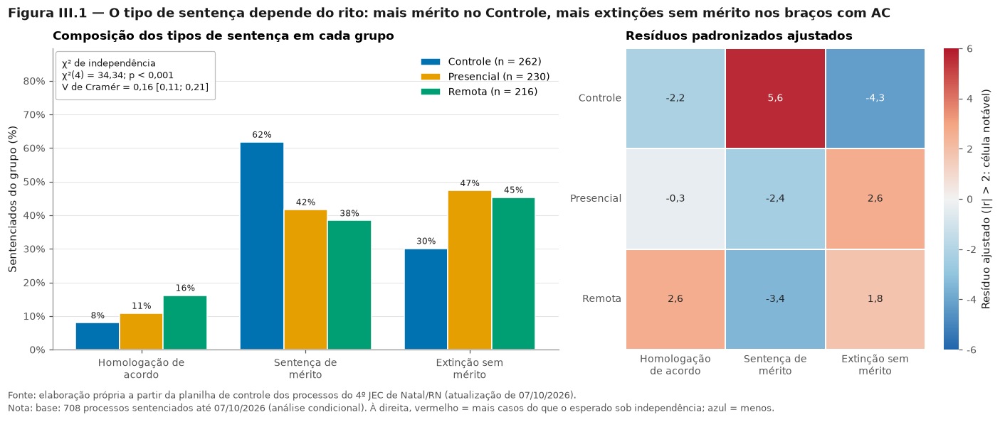

In [72]:
t3_sent = t3[t3['evento'] == 1].copy()
t3_sent['tipo'] = t3_sent['tipo_desfecho'].cat.remove_unused_categories()
t3_tab_tipo = pd.crosstab(t3_sent['grupo'], t3_sent['tipo'])
chi2, p_tipo, gl, esperadas = stats.chi2_contingency(t3_tab_tipo, correction=False)
v_tipo, v_lo, v_hi = tst_cramer_ic(t3_sent['grupo'], t3_sent['tipo'])
res_tipo = tst_residuos(t3_tab_tipo)
perc = 100 * t3_tab_tipo.div(t3_tab_tipo.sum(axis=1), axis=0)

tabela(tst_tab(t3_tab_tipo.assign(Total=t3_tab_tipo.sum(axis=1)), 'Grupo', ROTULO_DESFECHO), 'tst_tipo_obs',
       'Tipo de sentença por grupo: frequências observadas (processos sentenciados)', secao='3.2.1')
tabela(tst_tab(perc, 'Grupo', ROTULO_DESFECHO), 'tst_tipo_pct',
       'Tipo de sentença por grupo: percentual dos sentenciados de cada grupo (%)', secao='3.2.1', casas=1,
       nota='cada linha soma 100%.')
tabela(tst_tab(pd.DataFrame(esperadas, index=t3_tab_tipo.index, columns=t3_tab_tipo.columns), 'Grupo', ROTULO_DESFECHO),
       'tst_tipo_esp', 'Frequências esperadas sob independência (pressuposto do χ²: todas ≥ 5)', secao='3.2.1', casas=1,
       nota=f'menor esperada = {fmt_br(esperadas.min(), 1)}.')
print(f'Qui-quadrado = {fmt_br(chi2, 2)}, gl = {gl}, p {tst_eq(p_tipo)} | V de Cramér = {tst_ic_txt(v_tipo, v_lo, v_hi, 3)}')
tabela(tst_tab(res_tipo, 'Grupo', ROTULO_DESFECHO), 'tst_tipo_res',
       'Resíduos padronizados ajustados (tipo de sentença × grupo)', secao='3.2.1',
       gradiente={'mapa': DIV, 'vmin': -6, 'vmax': 6, 'colunas': [ROTULO_DESFECHO[str(c)] for c in res_tipo.columns]}, nota='|r| > 2 indica célula que se afasta da independência.')
tst_registra('3.2', 'H1 tipo × grupo', 'χ² tipo de sentença × grupo (sentenciados)', 'independência',
             f'χ²({gl}) = {fmt_br(chi2, 2)}', p_tipo, f'V = {tst_ic_txt(v_tipo, v_lo, v_hi, 3)}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1.35, 1]})
tst_agrupadas_pct(ax[0], perc.T, t3_sent, 'Sentenciados do grupo (%)', rotulos_idx=ROTULO_DESFECHO,
                  ymax=perc.to_numpy().max() * 1.45)
ax[0].set_title('Composição dos tipos de sentença em cada grupo')
ax[0].legend(loc='upper right')
anotar_teste(ax[0], texto_teste('χ² de independência', f'χ²({gl}) = {fmt_br(chi2, 2)}', p_tipo,
                                f'V de Cramér = {tst_ic_txt(v_tipo, v_lo, v_hi, 2)}'), loc='upper left')
tst_heatmap_res(ax[1], res_tipo, limite=6, rotulos_col=ROTULO_DESFECHO)
figura(fig, 'tst_tipo_grupo',
       'O tipo de sentença depende do rito: mais mérito no Controle, mais extinções sem mérito nos braços com AC',
       secao='3.2.1', nota='base: 708 processos sentenciados até 07/10/2026 (análise condicional). À direita, vermelho = '
                           'mais casos do que o esperado sob independência; azul = menos.')

### 3.2.2 Comparações par a par (2 × 3) com Holm

O χ² global diz que *alguma* diferença existe; as tabelas 2 × 3 dizem **entre quais grupos**. São três comparações, ajustadas por Holm. A comparação Presencial × Remota responde se a modalidade da AC importa para o tipo de desfecho.

Comparação,n,χ²,gl,p,V de Cramér,p Holm
Presencial × Controle,492,"20,022",2,"< 0,001","0,202","< 0,001"
Remota × Controle,478,"26,835",2,"< 0,001","0,237","< 0,001"
Presencial × Remota,446,"2,759",2,"0,252","0,079","0,252"


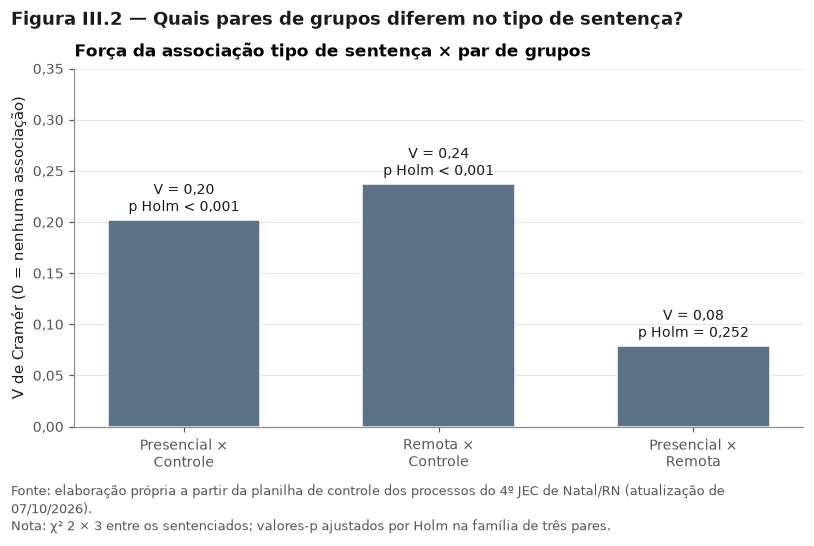

In [73]:
linhas = []
for a, b in PARES_GRUPO:
    sub = t3_sent[t3_sent['grupo'].isin([a, b])]
    tab = pd.crosstab(sub['grupo'].astype(str), sub['tipo'])
    c2, p, g, _ = stats.chi2_contingency(tab, correction=False)
    linhas.append({'Comparação': f'{a} × {b}', 'n': len(sub), 'χ²': c2, 'gl': g, 'p': p, 'V de Cramér': tst_cramer(tab)})
t3_pares_tipo = pd.DataFrame(linhas)
t3_pares_tipo['p Holm'] = tst_holm(t3_pares_tipo['p'])
tst_tabela_p(t3_pares_tipo, 'tst_tipo_pares', 'Tipo de sentença: comparações par a par (tabelas 2 × 3), com Holm',
             '3.2.2', casas=3)
for _, r in t3_pares_tipo.iterrows():
    tst_registra('3.2', 'H1 pares', f'χ² 2×3 {r["Comparação"]}', 'mesma distribuição de tipos',
                 f'χ²({r["gl"]}) = {fmt_br(r["χ²"], 2)}', r['p'], f'V = {fmt_br(r["V de Cramér"], 3)}')

fig, ax = plt.subplots(figsize=(7.5, 4.2))
barras_verticais(ax, t3_pares_tipo['Comparação'], t3_pares_tipo['V de Cramér'], cores=COR_NEUTRA, rotular=False,
                 ylabel='V de Cramér (0 = nenhuma associação)', ymax=max(0.35, t3_pares_tipo['V de Cramér'].max() * 1.45))
for i, (v, p) in enumerate(zip(t3_pares_tipo['V de Cramér'], t3_pares_tipo['p Holm'])):
    ax.annotate(f'V = {fmt_br(v, 2)}\np Holm {tst_eq(p)}', (i, v), xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=9, color=TINTA)
ax.set_title('Força da associação tipo de sentença × par de grupos')
figura(fig, 'tst_tipo_pares', 'Quais pares de grupos diferem no tipo de sentença?', secao='3.2.2',
       nota='χ² 2 × 3 entre os sentenciados; valores-p ajustados por Holm na família de três pares.')

### 3.2.3 Hipótese-chave: a AC obrigatória troca mérito por extinção sem mérito?

A Lei 9.099/1995 (art. 51, I) extingue o processo, sem resolução de mérito, quando o **autor deixa de comparecer a qualquer das audiências**. Num rito com AC inaugural obrigatória, cada ausência do autor vira extinção; no rito atual (Controle), sem audiência inaugural, o processo segue para contestação e julgamento. A hipótese substantiva, formulada antes do teste, é: **mais "sem mérito" e menos "mérito" nos braços com AC**.

Para cada tipo de sentença, testa-se o desfecho binário (o tipo × os demais) entre os grupos:

- **H₀:** a proporção do tipo é a mesma nos três grupos (χ² 3 × 2); depois, par a par, **Fisher exato** com **razão de chances (OR)** e IC 95% condicional exato, e a **diferença de proporções** com IC de Newcombe. Os nove pares formam uma família ajustada por Holm.
- **Leitura do gráfico:** proporção de cada tipo por grupo, com IC de Wilson.
- A homologação (acordo) aparece aqui por completude; ela é idêntica a "acordo em qualquer momento" entre os sentenciados e é discutida, numa janela sem censura, na seção 3.3.

Tipo,χ²,gl,p,mín. esperada,V,p Holm
Extinção sem mérito,"18,312",2,"< 0,001","87,3","0,161","< 0,001"
Sentença de mérito,"31,612",2,"< 0,001","104,0","0,211","< 0,001"
Homologação de acordo,"7,945",2,"0,019","24,7","0,106","0,019"


Tipo,Comparação,x/n (1º),x/n (2º),OR,OR IC inf,OR IC sup,Dif. (p.p.),Dif. IC inf,Dif. IC sup,p,p Holm
Extinção sem mérito,Presencial × Controle,109/230,79/262,"2,09","1,42","3,07","17,2","8,6","25,5","< 0,001","< 0,001"
Extinção sem mérito,Remota × Controle,98/216,79/262,"1,92","1,30","2,85","15,2","6,5","23,7","< 0,001","0,005"
Extinção sem mérito,Presencial × Remota,109/230,98/216,"1,08","0,73","1,60","2,0","-7,2","11,2","0,704","0,999"
Sentença de mérito,Presencial × Controle,96/230,162/262,"0,44","0,30","0,65","-20,1","-28,5","-11,3","< 0,001","< 0,001"
Sentença de mérito,Remota × Controle,83/216,162/262,"0,39","0,26","0,57","-23,4","-31,8","-14,5","< 0,001","< 0,001"
Sentença de mérito,Presencial × Remota,96/230,83/216,"1,15","0,77","1,71","3,3","-5,8","12,3","0,500","0,999"
Homologação de acordo,Presencial × Controle,25/230,21/262,"1,40","0,73","2,71","2,9","-2,3","8,3","0,283","0,848"
Homologação de acordo,Remota × Controle,35/216,21/262,"2,22","1,21","4,15","8,2","2,4","14,3","0,007","0,033"
Homologação de acordo,Presencial × Remota,25/230,35/216,"0,63","0,35","1,13","-5,3","-11,8","1,0","0,126","0,505"


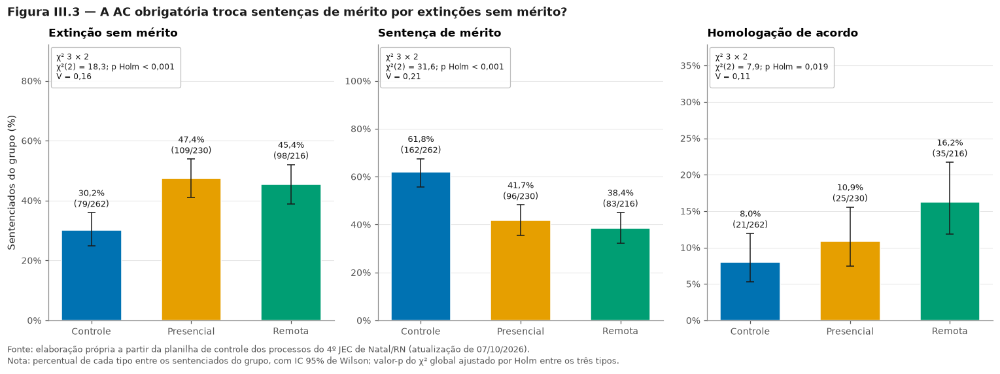

In [74]:
linhas_glob, linhas_par = [], []
for tipo in ['Sem mérito', 'Mérito', 'Homologação']:
    y = (t3_sent['tipo'] == tipo)
    tab = pd.crosstab(t3_sent['grupo'], y)
    c2, p, g, e = stats.chi2_contingency(tab, correction=False)
    linhas_glob.append({'Tipo': tipo, 'χ²': c2, 'gl': g, 'p': p, 'mín. esperada': e.min(), 'V': tst_cramer(tab)})
    for a, b in PARES_GRUPO:
        xa, na = int(y[t3_sent['grupo'] == a].sum()), int((t3_sent['grupo'] == a).sum())
        xb, nb = int(y[t3_sent['grupo'] == b].sum()), int((t3_sent['grupo'] == b).sum())
        pf, orm, orc, olo, ohi = tst_fisher([[xa, na - xa], [xb, nb - xb]])
        dif, dlo, dhi = tst_newcombe(xa, na, xb, nb)
        linhas_par.append({'Tipo': tipo, 'Comparação': f'{a} × {b}', f'% {a[:4]}.': 100 * xa / na,
                           'x/n (1º)': f'{xa}/{na}', 'x/n (2º)': f'{xb}/{nb}', 'OR': orm, 'OR IC inf': olo,
                           'OR IC sup': ohi, 'Dif. (p.p.)': 100 * dif, 'Dif. IC inf': 100 * dlo,
                           'Dif. IC sup': 100 * dhi, 'p': pf})
t3_glob_bin = pd.DataFrame(linhas_glob); t3_glob_bin['p Holm'] = tst_holm(t3_glob_bin['p'])
t3_par_bin = pd.DataFrame(linhas_par).drop(columns=[c for c in pd.DataFrame(linhas_par) if c.startswith('% ')])
t3_par_bin['p Holm'] = tst_holm(t3_par_bin['p'])
tst_tabela_p(t3_glob_bin.assign(Tipo=t3_glob_bin['Tipo'].map(ROTULO_DESFECHO)), 'tst_tipobin_global',
             'Cada tipo de sentença × grupo: testes globais 3 × 2 (Holm entre os três tipos)', '3.2.3', casas=3,
             formatos={'mín. esperada': 1})
tst_tabela_p(t3_par_bin.assign(Tipo=t3_par_bin['Tipo'].map(ROTULO_DESFECHO)), 'tst_tipobin_pares',
             'Cada tipo de sentença: pares de grupos (Fisher exato, OR e diferença em pontos percentuais)', '3.2.3',
             casas=2, formatos={'Dif. (p.p.)': 1, 'Dif. IC inf': 1, 'Dif. IC sup': 1},
             nota='OR amostral com IC 95% condicional exato; diferença 1º − 2º com IC 95% de Newcombe; Holm na família de nove pares.')
for _, r in t3_glob_bin.iterrows():
    tst_registra('3.2', 'H2 tipos binários', f'χ² 3×2 {r["Tipo"]} × grupo', 'proporção igual nos 3 grupos',
                 f'χ²(2) = {fmt_br(r["χ²"], 2)}', r['p'], f'V = {fmt_br(r["V"], 3)}')
for _, r in t3_par_bin.iterrows():
    tst_registra('3.2', 'H2 pares (Fisher)', f'Fisher {r["Tipo"]}: {r["Comparação"]}', 'OR = 1', f'OR = {fmt_br(r["OR"], 2)}',
                 r['p'], f'dif. = {tst_ic_txt(r["Dif. (p.p.)"], r["Dif. IC inf"], r["Dif. IC sup"], 1)} p.p.')

fig, ax = plt.subplots(1, 3, figsize=(14, 4.6))
for k, tipo in enumerate(['Sem mérito', 'Mérito', 'Homologação']):
    xs = [int((t3_sent.loc[t3_sent['grupo'] == g, 'tipo'] == tipo).sum()) for g in ORDEM_GRUPO]
    ns = [int((t3_sent['grupo'] == g).sum()) for g in ORDEM_GRUPO]
    tst_barras_wilson(ax[k], ORDEM_GRUPO, xs, ns, ylabel='Sentenciados do grupo (%)' if k == 0 else '')
    r = t3_glob_bin.loc[t3_glob_bin['Tipo'] == tipo].iloc[0]
    anotar_teste(ax[k], texto_teste('χ² 3 × 2', f'χ²(2) = {fmt_br(r["χ²"], 1)}', r['p Holm'], f'V = {fmt_br(r["V"], 2)}')
                 .replace('p ', 'p Holm ', 1), loc='upper left', tamanho=8)
    ax[k].set_title(ROTULO_DESFECHO[tipo])
    ax[k].set_ylim(0, ax[k].get_ylim()[1] * 1.25)
figura(fig, 'tst_tipobin', 'A AC obrigatória troca sentenças de mérito por extinções sem mérito?', secao='3.2.3',
       nota='percentual de cada tipo entre os sentenciados do grupo, com IC 95% de Wilson; valor-p do χ² global ajustado por Holm entre os três tipos.')

**Mecanismo (descritivo, não é teste).** Nos braços com AC, cruza-se o tipo de sentença com a realização da AC. `ac_realizada` é uma variável **pós-sorteio** — ser ou não realizada depende do comportamento das partes —, por isso a tabela não estima efeito causal: apenas mostra *onde* estão as extinções sem mérito. Uma AC "não realizada" pode ser ausência do autor (art. 51, I) ou extinção anterior à data da audiência (desistência, indeferimento da inicial).

Grupo,Audiência,Homologação de acordo,Sentença de mérito,Extinção sem mérito,Total
Presencial,AC não realizada,11,2,89,102
Presencial,AC realizada,14,94,20,128
Remota,AC não realizada,16,2,63,81
Remota,AC realizada,19,81,35,135


Grupo,Audiência,Homologação de acordo,Sentença de mérito,Extinção sem mérito
Presencial,AC não realizada,"10,8","2,0","87,3"
Presencial,AC realizada,"10,9","73,4","15,6"
Remota,AC não realizada,"19,8","2,5","77,8"
Remota,AC realizada,"14,1","60,0","25,9"


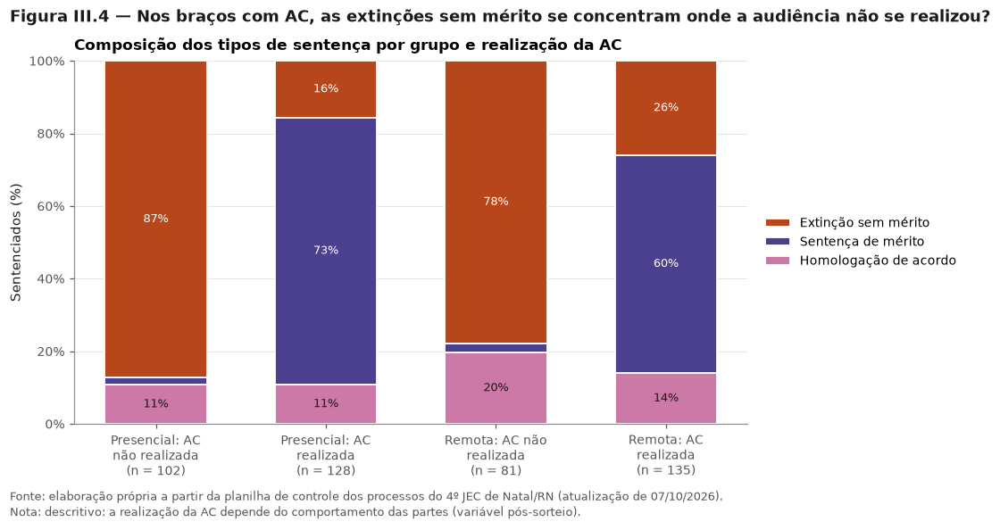

In [75]:
trat = t3_sent[t3_sent['grupo'] != 'Controle'].copy()
trat['AC'] = trat['ac_realizada'].map({True: 'AC realizada', False: 'AC não realizada'}).fillna('não informado')
t3_mec = pd.crosstab([trat['grupo'].astype(str), trat['AC']], trat['tipo'])
_mec = t3_mec.assign(Total=t3_mec.sum(axis=1)).rename(columns=ROTULO_DESFECHO).reset_index()
_mec.columns = ['Grupo', 'Audiência'] + [str(c) for c in _mec.columns[2:]]
tabela(_mec, 'tst_mecanismo_n', 'Braços com AC: tipo de sentença conforme a AC foi ou não realizada (frequências)', secao='3.2.3',
       nota='ac_realizada é pós-sorteio: a tabela é descritiva, não estima efeito causal.')
_mecp = (100 * t3_mec.div(t3_mec.sum(axis=1), axis=0)).rename(columns=ROTULO_DESFECHO).reset_index()
_mecp.columns = ['Grupo', 'Audiência'] + [str(c) for c in _mecp.columns[2:]]
tabela(_mecp, 'tst_mecanismo_pct', 'Braços com AC: tipo de sentença conforme a AC foi ou não realizada (% da linha)',
       secao='3.2.3', casas=1)

perc = t3_mec.div(t3_mec.sum(axis=1), axis=0)
ns_mec = t3_mec.sum(axis=1).to_numpy()
perc.index = [f'{g}: {a}' for g, a in perc.index]
fig, ax = plt.subplots(figsize=(10, 4.8))
barras_empilhadas(ax, perc, cores=CORES_DESFECHO, ns=ns_mec, rotulos_serie=ROTULO_DESFECHO, quebrar=16,
                  ylabel='Sentenciados (%)')
ax.set_title('Composição dos tipos de sentença por grupo e realização da AC')
figura(fig, 'tst_mecanismo', 'Nos braços com AC, as extinções sem mérito se concentram onde a audiência não se realizou?',
       secao='3.2.3', nota='descritivo: a realização da AC depende do comportamento das partes (variável pós-sorteio).')

### 3.2.4 Redistribuição (Decisão) × grupo

A redistribuição (remessa a outro juízo por prevenção ou incompetência) não é sentença, mas pode depender do rito: uma AC obrigatória dá mais uma oportunidade de alguém perceber a prevenção. A base são os **938 processos** (a redistribuição costuma ocorrer nos primeiros dias, de modo que a censura pouco a afeta).

- **H₀:** a proporção de redistribuições é igual nos três grupos. Com 24 eventos, as esperadas ficam em torno de 8, e o χ² assintótico é conferido pela **permutação de Monte Carlo** (10.000 reamostragens).

Grupo,Não redistribuído,Redistribuído,Redistribuído (%)
Controle,308,5,"1,6"
Presencial,304,10,"3,2"
Remota,302,9,"2,9"


Esperadas mínimas = 8,0 | χ²(2) = 1,79, p assintótico = 0,408, p permutação (χ²) = 0,423, p Fisher-Freeman-Halton MC = 0,393 | V = 0,044


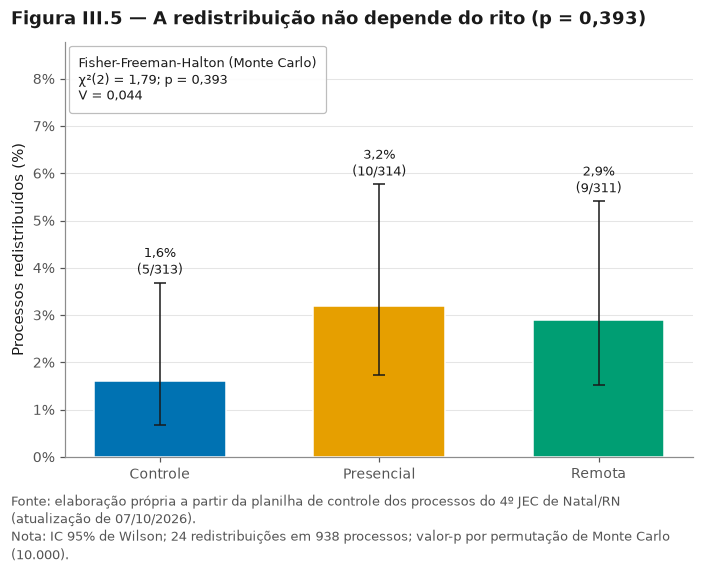

In [76]:
y_red = (t3['tipo_desfecho'] == 'Redistribuição')
tab_red = pd.crosstab(t3['grupo'], y_red)
c2_red, p_red, _, e_red = stats.chi2_contingency(tab_red, correction=False)
_, p_red_mc, p_red_ffh, _ = tst_perm_rxc(t3['grupo'], y_red)
_tr = tab_red.rename(columns={False: 'Não redistribuído', True: 'Redistribuído'})
tabela(tst_tab(_tr.assign(**{'Redistribuído (%)': 100 * _tr['Redistribuído'] / _tr.sum(axis=1)}), 'Grupo'),
       'tst_redist', 'Redistribuição (Decisão) por grupo (938 processos)', secao='3.2.4', casas=1)
print(f'Esperadas mínimas = {fmt_br(e_red.min(), 1)} | χ²(2) = {fmt_br(c2_red, 2)}, p assintótico {tst_eq(p_red)}, '
      f'p permutação (χ²) {tst_eq(p_red_mc)}, p Fisher-Freeman-Halton MC {tst_eq(p_red_ffh)} | V = {fmt_br(tst_cramer(tab_red), 3)}')
tst_registra('3.2', 'H3 redistribuição', 'Redistribuição × grupo (FFH Monte Carlo)', 'proporção igual',
             f'χ²(2) = {fmt_br(c2_red, 2)}', p_red_ffh, f'V = {fmt_br(tst_cramer(tab_red), 3)}')

fig, ax = plt.subplots(figsize=(6.5, 4.3))
tst_barras_wilson(ax, ORDEM_GRUPO, [int(tab_red.loc[g, True]) for g in ORDEM_GRUPO],
                  [int(tab_red.loc[g].sum()) for g in ORDEM_GRUPO], ylabel='Processos redistribuídos (%)')
anotar_teste(ax, texto_teste('Fisher-Freeman-Halton (Monte Carlo)', f'χ²(2) = {fmt_br(c2_red, 2)}', p_red_ffh,
                             f'V = {fmt_br(tst_cramer(tab_red), 3)}'), loc='upper left')
figura(fig, 'tst_redist', f'A redistribuição não depende do rito (p {tst_eq(p_red_ffh)})', secao='3.2.4',
       nota='IC 95% de Wilson; 24 redistribuições em 938 processos; valor-p por permutação de Monte Carlo (10.000).')

### 3.2.5 Sensibilidade sem censura: desfecho até o 65º dia

Todo processo tem no mínimo 65 dias de acompanhamento. Logo, a variável "**como o processo estava no 65º dia**" (homologação, mérito, sem mérito, redistribuído ou ainda sem desfecho) é observada **para os 938**, sem censura e sem condicionar a quem já encerrou. É a forma correta de usar um χ² de "status" (o notebook do professor usou o status na data de corte, que mistura seguimentos de 65 a 279 dias — E19).

- **H₀:** a situação no 65º dia é independente do grupo.

Grupo,Homologação de acordo,Sentença de mérito,Extinção sem mérito,Redistribuição (Decisão),Sem desfecho até o 65º dia,Total
Controle,11,35,65,5,197,313
Presencial,14,5,90,10,195,314
Remota,19,2,64,7,219,311


Esperada mínima = 7,3 | χ²(8) = 59,19, p < 0,001 | V = 0,178 [0,145; 0,228]


Grupo,Homologação de acordo,Sentença de mérito,Extinção sem mérito,Redistribuição (Decisão),Sem desfecho até o 65º dia
Controle,"-1,21","7,03","-1,32","-1,07","-1,00"
Presencial,"-0,24","-3,03","2,73","1,20","-1,38"
Remota,"1,45","-4,00","-1,41","-0,13","2,39"


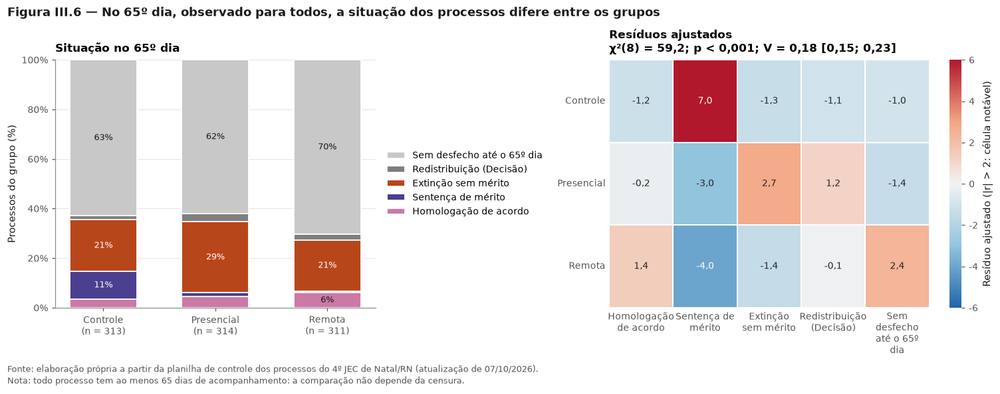

In [77]:
t3['sit65'] = np.where(t3['tempo_f'] <= 65, t3['tipo_desfecho'].astype(str), 'Sem desfecho até 65 d')
t3['sit65'] = np.where((t3['sit65'] == 'Ativo'), 'Sem desfecho até 65 d', t3['sit65'])
ORDEM_SIT65 = ['Homologação', 'Mérito', 'Sem mérito', 'Redistribuição', 'Sem desfecho até 65 d']
tab65 = pd.crosstab(t3['grupo'], t3['sit65'])[ORDEM_SIT65]
c2_65, p_65, gl_65, e_65 = stats.chi2_contingency(tab65, correction=False)
v65, v65lo, v65hi = tst_cramer_ic(t3['grupo'], t3['sit65'])
ROT65 = {**ROTULO_DESFECHO, 'Sem desfecho até 65 d': 'Sem desfecho até o 65º dia'}
tabela(tst_tab(tab65.assign(Total=tab65.sum(axis=1)), 'Grupo', ROT65), 'tst_sit65_obs',
       'Situação de cada processo no 65º dia, por grupo (938 processos, sem censura)', secao='3.2.5')
print(f'Esperada mínima = {fmt_br(e_65.min(), 1)} | χ²({gl_65}) = {fmt_br(c2_65, 2)}, p {tst_eq(p_65)} | V = {tst_ic_txt(v65, v65lo, v65hi, 3)}')
_res65 = tst_residuos(tab65)
tabela(tst_tab(_res65, 'Grupo', ROT65), 'tst_sit65_res', 'Resíduos ajustados: situação no 65º dia × grupo', secao='3.2.5',
       gradiente={'mapa': DIV, 'vmin': -6, 'vmax': 6, 'colunas': [ROT65[c] for c in ORDEM_SIT65]})
tst_registra('3.2', 'H1 tipo × grupo', 'χ² situação no 65º dia × grupo (938, sem censura)', 'independência',
             f'χ²({gl_65}) = {fmt_br(c2_65, 2)}', p_65, f'V = {tst_ic_txt(v65, v65lo, v65hi, 3)}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1, 1.25]})
perc = tab65.div(tab65.sum(axis=1), axis=0)
cores65 = {**CORES_DESFECHO, 'Sem desfecho até 65 d': CORES_DESFECHO['Ativo']}
barras_empilhadas(ax[0], perc, cores=cores65, ns=tab65.sum(axis=1).to_numpy(), rotulos_serie=ROT65,
                  ylabel='Processos do grupo (%)')
ax[0].set_title('Situação no 65º dia')
tst_heatmap_res(ax[1], _res65, limite=6, rotulos_col=ROT65, quebrar=11,
                titulo='Resíduos ajustados\n' + f'χ²({gl_65}) = {fmt_br(c2_65, 1)}; p {tst_eq(p_65)}; V = {tst_ic_txt(v65, v65lo, v65hi, 2)}')
figura(fig, 'tst_sit65', 'No 65º dia, observado para todos, a situação dos processos difere entre os grupos', secao='3.2.5',
       nota='todo processo tem ao menos 65 dias de acompanhamento: a comparação não depende da censura.')

**Leitura. O rito muda o tipo de sentença, e a mudança tem uma explicação jurídica clara.**

- **Há associação entre tipo de sentença e grupo** (χ²(4) = 34,34; p < 0,001; esperadas ≥ 24,7). O efeito é **pequeno a moderado**: V de Cramér = 0,16 (IC 95% 0,11 a 0,21).
- **A diferença está entre o Controle e os braços com AC, e não entre as duas modalidades:**
  - Presencial × Controle: V = 0,20, p Holm < 0,001;
  - Remota × Controle: V = 0,24, p Holm < 0,001;
  - Presencial × Remota: V = 0,08, p = 0,252.

  Para o tipo de desfecho, **"ter AC obrigatória" importa; a modalidade, não**.
- **A hipótese do art. 51, I, da Lei 9.099/1995 é confirmada nos dados.** Entre os sentenciados:
  - **sem mérito:** 30,2% no Controle, contra 47,4% no Presencial e 45,4% na Remota. Presencial × Controle: OR = 2,09 (IC 1,42 a 3,07), diferença de +17,2 p.p. (IC de Newcombe 8,6 a 25,5). Remota × Controle: OR = 1,92 (1,30 a 2,85), +15,2 p.p. (6,5 a 23,7). Ambos com p Holm ≤ 0,005;
  - **mérito:** 61,8% no Controle, contra 41,7% e 38,4%. OR de 0,44 e 0,39, diferenças de −20 e −23 p.p., p Holm < 0,001;
  - os resíduos ajustados apontam as mesmas células: Controle × mérito = +5,6; Controle × sem mérito = −4,3.
- **O mecanismo aparece na tabela descritiva.** Nos braços com AC, quando a audiência **não** foi realizada, 87% (Presencial) e 78% (Remota) das sentenças são **sem mérito**. Quando foi realizada, predominam as de mérito (73% e 60%). A leitura compatível é que a AC obrigatória cria um ponto de "filtragem": o autor que não comparece tem o processo extinto (art. 51, I). Como `ac_realizada` é pós-sorteio, essa tabela mostra **onde** estão as extinções, não prova a causa; parte das AC "não realizadas" pode ser de processos extintos antes da data da audiência.
- **Homologação (acordo).** O global é significativo dentro da família (p Holm = 0,019), e o único par que se sustenta é **Remota × Controle**: 16,2% contra 8,0%, OR = 2,22 (1,21 a 4,15), p Holm = 0,033. Esse par não sobrevive ao Holm global (seção 3.7) e é discutido em horizonte fixo na seção 3.3.
- **A redistribuição não depende do rito**: 5, 10 e 9 casos; Fisher-Freeman-Halton por Monte Carlo, p = 0,393.
- **A conclusão não é um artefato de "quem já encerrou".** Na janela de 65 dias, observada para os 938 processos, a associação persiste e é até mais forte: χ²(8) = 59,19, p < 0,001, V = 0,18 (0,15 a 0,23).
  - **Mérito até o 65º dia:** 35 processos no Controle, contra 5 no Presencial e 2 na Remota (resíduo +7,0). Sem AC inaugural, o Controle consegue julgar o mérito cedo, provavelmente por julgamento antecipado após a contestação.
  - **Sem mérito precoce** se concentra no Presencial (resíduo +2,7).
  - **"Sem desfecho até 65 dias"** se concentra na Remota (+2,4).
- **Leitura jurídica.** A AC obrigatória não se limita a "acrescentar acordos": ela **troca julgamentos de mérito por extinções sem mérito**. Para a política judiciária, isso tem custo. Uma extinção por ausência não resolve o conflito, e o autor pode repropor a ação (art. 51, § 1º). O indicador "processos baixados" melhora sem que a resposta ao jurisdicionado melhore na mesma proporção.

---

## 3.3 Acordo (H4 a H7)

### 3.3.1 Acordo na AC: presencial × remota (H4)

Só há acordo na AC onde houve AC. A comparação válida é **Presencial × Remota entre as AC realizadas** (o χ² do professor incluía o Controle, com zero estrutural — E20).

- **H₀:** p(acordo na AC | AC presencial) = p(acordo na AC | AC remota). **H₁:** bilateral.
- **Teste:** exato de Fisher (17 acordos ao todo: esperadas abaixo de 10, fora do alcance seguro do χ²). Efeitos: OR (IC condicional exato) e diferença de proporções (IC de Newcombe).
- **Poder:** com ~175 audiências por braço, calcula-se a menor diferença detectável com 80% de poder a partir da taxa observada — para dizer se um "não significativo" é informativo.

Grupo,Acordo na AC,Sem acordo,Acordo (%)
Presencial,9,169,"5,1"
Remota,8,166,"4,6"


Presencial 5,1% × Remota 4,6% | Fisher p = 1,000
OR = 1,11 (condicional 1,10; IC 95% exato 0,37 a 3,38)
Diferença = 0,5 p.p. (IC 95% Newcombe -4,4 a 5,3 p.p.)
Com taxa-base de 4,8% e esses n, só uma diferença ≥ 8,4 p.p. teria 80% de poder (α = 5%).


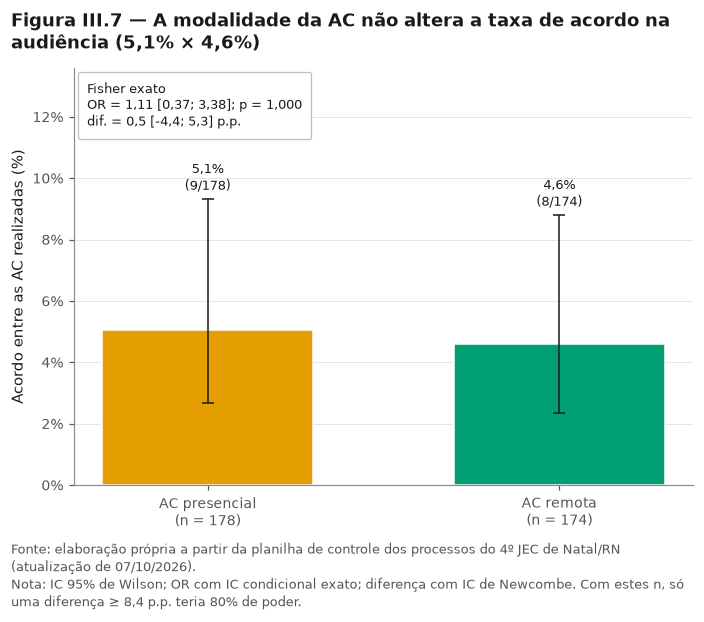

In [78]:
t3_ac = t3[t3['ac_realizada'].fillna(False).astype(bool) & (t3['grupo'] != 'Controle')].copy()
t3_ac['grupo'] = t3_ac['grupo'].cat.remove_unused_categories()
tab_acac = pd.crosstab(t3_ac['grupo'], t3_ac['acordo_ac'].fillna(False).astype(bool)).reindex(columns=[True, False], fill_value=0)
xp, xr = int(tab_acac.loc['Presencial', True]), int(tab_acac.loc['Remota', True])
np_, nr = int(tab_acac.loc['Presencial'].sum()), int(tab_acac.loc['Remota'].sum())
p_acac, or_acac, orc_acac, or_lo, or_hi = tst_fisher(tab_acac.values)
dif_acac, dlo_acac, dhi_acac = tst_newcombe(xp, np_, xr, nr)
_t = tab_acac.rename(columns={True: 'Acordo na AC', False: 'Sem acordo'})
tabela(tst_tab(_t.assign(**{'Acordo (%)': 100 * _t['Acordo na AC'] / _t.sum(axis=1)}), 'Grupo'), 'tst_acordo_ac',
       'Acordo na audiência de conciliação, entre as AC realizadas: Presencial × Remota', secao='3.3.1', casas=1)
print(f'Presencial {fmt_br(100 * xp / np_, 1)}% × Remota {fmt_br(100 * xr / nr, 1)}% | Fisher p {tst_eq(p_acac)}')
print(f'OR = {fmt_br(or_acac, 2)} (condicional {fmt_br(orc_acac, 2)}; IC 95% exato {fmt_br(or_lo, 2)} a {fmt_br(or_hi, 2)})')
print(f'Diferença = {fmt_br(100 * dif_acac, 1)} p.p. (IC 95% Newcombe {fmt_br(100 * dlo_acac, 1)} a {fmt_br(100 * dhi_acac, 1)} p.p.)')
p_base = (xp + xr) / (np_ + nr)
for alvo in np.arange(0.005, 0.30, 0.001):
    poder = NormalIndPower().power(proportion_effectsize(p_base + alvo, p_base), nobs1=np_, ratio=nr / np_, alpha=0.05)
    if poder >= 0.8:
        break
print(f'Com taxa-base de {pct_br(p_base)} e esses n, só uma diferença ≥ {fmt_br(100 * alvo, 1)} p.p. teria 80% de poder (α = 5%).')
tst_registra('3.3', 'H4 acordo AC modalidade', 'Fisher acordo na AC: Presencial × Remota', 'OR = 1', f'OR = {fmt_br(or_acac, 2)}',
             p_acac, f'dif. = {tst_ic_txt(100 * dif_acac, 100 * dlo_acac, 100 * dhi_acac, 1)} p.p.')

fig, ax = plt.subplots(figsize=(6.5, 4.5))
tst_barras_wilson(ax, ['Presencial', 'Remota'], [xp, xr], [np_, nr], ylabel='Acordo entre as AC realizadas (%)')
ax.set_xticks([0, 1], [f'AC presencial\n(n = {np_})', f'AC remota\n(n = {nr})'])
anotar_teste(ax, texto_teste('Fisher exato', f'OR = {fmt_br(or_acac, 2)} [{fmt_br(or_lo, 2)}; {fmt_br(or_hi, 2)}]', p_acac,
                             f'dif. = {tst_ic_txt(100 * dif_acac, 100 * dlo_acac, 100 * dhi_acac, 1)} p.p.'), loc='upper left')
figura(fig, 'tst_acordo_ac', f'A modalidade da AC não altera a taxa de acordo na audiência '
       f'({fmt_br(100 * xp / np_, 1)}% × {fmt_br(100 * xr / nr, 1)}%)', secao='3.3.1',
       nota=f'IC 95% de Wilson; OR com IC condicional exato; diferença com IC de Newcombe. Com estes n, só uma diferença '
            f'≥ {fmt_br(100 * alvo, 1)} p.p. teria 80% de poder.')

### 3.3.2 Acordo em qualquer momento (H5)

"Acordo" (na AC ou fora dela) existe nos três grupos, inclusive no Controle (por petição). Entre os sentenciados, acordo é exatamente a **homologação**, já testada em 3.2.3; aquela comparação, porém, é condicional a quem encerrou. Aqui o acordo é medido **em horizonte fixo**, sem censura:

- **Janela de 65 dias:** homologação até o 65º dia, para os 938 processos (todos acompanhados por ≥ 65 dias);
- **Janela de 120 dias:** homologação até o 120º dia, só entre os processos com ≥ 120 dias de acompanhamento (distribuídos até 09/06/2026).

**H₀:** a proporção de acordos até o horizonte é igual nos três grupos. χ² 3 × 2 (ou permutação, se esparso) e Fisher par a par com Holm.

Horizonte 65 dias (n = 938): acordos {'Controle': 11, 'Presencial': 14, 'Remota': 19} | esperada mín. 14,6 | χ²(2) = 2,41, p = 0,300, p permutação = 0,300


Horizonte 120 dias (n = 688): acordos {'Controle': 12, 'Presencial': 22, 'Remota': 27} | esperada mín. 19,2 | χ²(2) = 8,00, p = 0,018, p permutação = 0,018


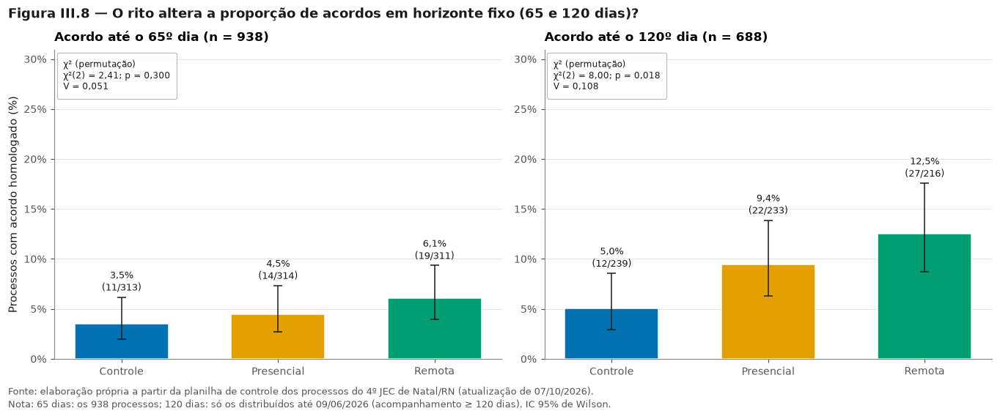

Horizonte (dias),Comparação,1º,2º,OR,OR IC,Dif. p.p. [IC Newcombe],p,p Holm
65,Presencial × Controle,14/314,11/313,"1,28","0,53 a 3,17","0,9 [-2,3; 4,2]","0,684","0,753"
65,Remota × Controle,19/311,11/313,"1,79","0,79 a 4,23","2,6 [-0,8; 6,2]","0,139","0,416"
65,Presencial × Remota,14/314,19/311,"0,72","0,33 a 1,54","-1,7 [-5,3; 2,0]","0,377","0,753"
120,Presencial × Controle,22/233,12/239,"1,97","0,91 a 4,48","4,4 [-0,3; 9,3]","0,075","0,150"
120,Remota × Controle,27/216,12/239,"2,70","1,28 a 6,01","7,5 [2,3; 13,0]","0,007","0,020"
120,Presencial × Remota,22/233,27/216,"0,73","0,38 a 1,38","-3,1 [-9,0; 2,8]","0,364","0,364"


In [79]:
linhas = []
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
for k, h in enumerate([65, 120]):
    base_h = t3[t3['followup'] >= h]
    y = (base_h['tipo_desfecho'] == 'Homologação') & (base_h['tempo_f'] <= h)
    tab = pd.crosstab(base_h['grupo'], y)
    c2, p, _, e = stats.chi2_contingency(tab, correction=False)
    _, p_mc, _, _ = tst_perm_rxc(base_h['grupo'], y)
    print(f'Horizonte {h} dias (n = {len(base_h)}): acordos {tab[True].to_dict()} | esperada mín. {fmt_br(e.min(), 1)} | '
          f'χ²(2) = {fmt_br(c2, 2)}, p {tst_eq(p)}, p permutação {tst_eq(p_mc)}')
    tst_registra('3.3', 'H5 acordo total', f'χ² acordo até {h} d × grupo', 'proporção igual', f'χ²(2) = {fmt_br(c2, 2)}', p_mc,
                 f'V = {fmt_br(tst_cramer(tab), 3)}')
    for a, b in PARES_GRUPO:
        xa, na = int(y[base_h['grupo'] == a].sum()), int((base_h['grupo'] == a).sum())
        xb, nb = int(y[base_h['grupo'] == b].sum()), int((base_h['grupo'] == b).sum())
        pf, orm, _, olo, ohi = tst_fisher([[xa, na - xa], [xb, nb - xb]])
        dif, dlo, dhi = tst_newcombe(xa, na, xb, nb)
        linhas.append({'Horizonte': h, 'Comparação': f'{a} × {b}', '1º': f'{xa}/{na}', '2º': f'{xb}/{nb}', 'OR': orm,
                       'OR IC': f'{fmt_br(olo, 2)} a {fmt_br(ohi, 2)}', 'Dif. p.p. [IC Newcombe]':
                       tst_ic_txt(100 * dif, 100 * dlo, 100 * dhi, 1), 'p': pf})
    xs = [int(tab.loc[g, True]) if True in tab else 0 for g in ORDEM_GRUPO]
    ns = [int(tab.loc[g].sum()) for g in ORDEM_GRUPO]
    tst_barras_wilson(ax[k], ORDEM_GRUPO, xs, ns, ylabel='Processos com acordo homologado (%)' if k == 0 else '')
    ax[k].set_title(f'Acordo até o {h}º dia (n = {fmt_br(len(base_h), 0)})')
    ax[k].set_ylim(0, ax[k].get_ylim()[1] * 1.25)
    anotar_teste(ax[k], texto_teste('χ² (permutação)', f'χ²(2) = {fmt_br(c2, 2)}', p_mc, f'V = {fmt_br(tst_cramer(tab), 3)}'),
                 loc='upper left', tamanho=8)
ymax = max(a.get_ylim()[1] for a in ax)
for a in ax:
    a.set_ylim(0, ymax)
figura(fig, 'tst_acordo_horizonte', 'O rito altera a proporção de acordos em horizonte fixo (65 e 120 dias)?', secao='3.3.2',
       nota='65 dias: os 938 processos; 120 dias: só os distribuídos até 09/06/2026 (acompanhamento ≥ 120 dias). IC 95% de Wilson.')
t3_acordo_pares = pd.DataFrame(linhas)
t3_acordo_pares['p Holm'] = np.concatenate([tst_holm(t3_acordo_pares.loc[t3_acordo_pares['Horizonte'] == h, 'p']) for h in [65, 120]])
tst_tabela_p(t3_acordo_pares.rename(columns={'Horizonte': 'Horizonte (dias)'}), 'tst_acordo_horizonte_pares',
             'Acordo em horizonte fixo: pares de grupos (Fisher exato), Holm dentro de cada horizonte', '3.3.2', casas=2)
for _, r in t3_acordo_pares.iterrows():
    tst_registra('3.3', 'H5 pares', f'Fisher acordo até {r["Horizonte"]} d: {r["Comparação"]}', 'OR = 1',
                 f'OR = {fmt_br(r["OR"], 2)}', r['p'], f'dif. = {r["Dif. p.p. [IC Newcombe]"]} p.p.')

### 3.3.3 Acordo fora da AC × grupo (H6)

Acordo por petição das partes, fora da audiência. A base são os 733 processos com a informação registrada (os ativos ainda não a têm). Atenção à leitura: no Controle esse é o **único** caminho de acordo; nos braços com AC, é o acordo que veio **depois** de uma AC sem acordo, ou sem AC realizada.

- **H₀:** a proporção de acordo fora da AC é igual nos três grupos.

Grupo,Acordo fora,Sem acordo fora,Acordo fora (%)
Controle,21,246,"7,9"
Presencial,16,224,"6,7"
Remota,27,199,"11,9"


Esperada mín. = 19,7 | χ²(2) = 4,47, p = 0,107 | V = 0,078


Comparação,OR,OR IC,Dif. p.p. [IC],p,p Holm
Presencial × Controle,"0,84","0,40 a 1,73","-1,2 [-5,8; 3,5]","0,733","0,733"
Remota × Controle,"1,59","0,84 a 3,05","4,1 [-1,2; 9,6]","0,131","0,262"
Presencial × Remota,"0,53","0,26 a 1,05","-5,3 [-10,8; 0,0]","0,055","0,166"


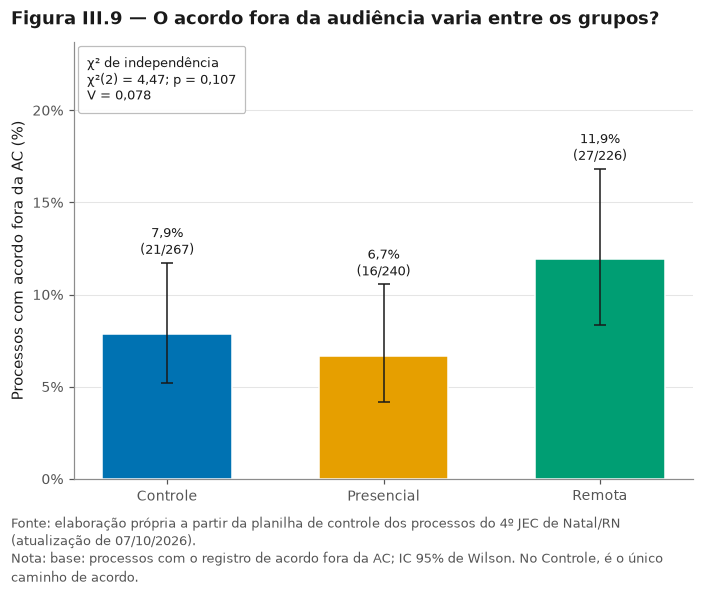

In [80]:
base_f = t3[t3['acordo_fora'].notna()]
y_f = base_f['acordo_fora'].astype(bool)
tab_f = pd.crosstab(base_f['grupo'], y_f)
c2_f, p_f, _, e_f = stats.chi2_contingency(tab_f, correction=False)
_t = tab_f.rename(columns={True: 'Acordo fora', False: 'Sem acordo fora'})[['Acordo fora', 'Sem acordo fora']]
tabela(tst_tab(_t.assign(**{'Acordo fora (%)': 100 * _t['Acordo fora'] / _t.sum(axis=1)}), 'Grupo'), 'tst_acordo_fora',
       'Acordo fora da audiência por grupo (processos com o registro)', secao='3.3.3', casas=1)
print(f'Esperada mín. = {fmt_br(e_f.min(), 1)} | χ²(2) = {fmt_br(c2_f, 2)}, p {tst_eq(p_f)} | V = {fmt_br(tst_cramer(tab_f), 3)}')
tst_registra('3.3', 'H6 acordo fora', 'χ² acordo fora da AC × grupo', 'proporção igual', f'χ²(2) = {fmt_br(c2_f, 2)}', p_f,
             f'V = {fmt_br(tst_cramer(tab_f), 3)}')
linhas = []
for a, b in PARES_GRUPO:
    xa, na = int(tab_f.loc[a, True]), int(tab_f.loc[a].sum()); xb, nb = int(tab_f.loc[b, True]), int(tab_f.loc[b].sum())
    pf, orm, _, olo, ohi = tst_fisher([[xa, na - xa], [xb, nb - xb]])
    dif, dlo, dhi = tst_newcombe(xa, na, xb, nb)
    linhas.append({'Comparação': f'{a} × {b}', 'OR': orm, 'OR IC': f'{fmt_br(olo, 2)} a {fmt_br(ohi, 2)}',
                   'Dif. p.p. [IC]': tst_ic_txt(100 * dif, 100 * dlo, 100 * dhi, 1), 'p': pf})
t3_fora_pares = pd.DataFrame(linhas); t3_fora_pares['p Holm'] = tst_holm(t3_fora_pares['p'])
tst_tabela_p(t3_fora_pares, 'tst_acordo_fora_pares', 'Acordo fora da AC: pares de grupos (Fisher exato), com Holm', '3.3.3', casas=2)
for _, r in t3_fora_pares.iterrows():
    tst_registra('3.3', 'H6 pares', f'Fisher acordo fora: {r["Comparação"]}', 'OR = 1', f'OR = {fmt_br(r["OR"], 2)}', r['p'],
                 f'dif. = {r["Dif. p.p. [IC]"]} p.p.')

fig, ax = plt.subplots(figsize=(6.5, 4.5))
tst_barras_wilson(ax, ORDEM_GRUPO, [int(tab_f.loc[g, True]) for g in ORDEM_GRUPO], [int(tab_f.loc[g].sum()) for g in ORDEM_GRUPO],
                  ylabel='Processos com acordo fora da AC (%)')
anotar_teste(ax, texto_teste('χ² de independência', f'χ²(2) = {fmt_br(c2_f, 2)}', p_f, f'V = {fmt_br(tst_cramer(tab_f), 3)}'),
             loc='upper left')
figura(fig, 'tst_acordo_fora', 'O acordo fora da audiência varia entre os grupos?', secao='3.3.3',
       nota='base: processos com o registro de acordo fora da AC; IC 95% de Wilson. No Controle, é o único caminho de acordo.')

### 3.3.4 AC híbrida e técnica de conciliação (H7)

**Híbrida.** Dentro do braço Presencial, uma AC é "híbrida" quando uma das partes pediu para participar por vídeo (Res. CNJ 481). É uma característica **pós-sorteio** (escolha da parte), portanto a comparação é observacional. **H₀:** p(acordo na AC) igual entre AC híbridas e totalmente presenciais (Fisher exato).

**Técnica.** A técnica foi sorteada entre as AC realizadas (Presencial e Remota). São 6 técnicas e 17 acordos: tabela 6 × 2 muito esparsa (esperadas < 3 em todas as células "acordo"). O χ² assintótico não vale; usa-se a **permutação de Monte Carlo** com margens fixas, com a estatística χ² e com a probabilidade da tabela (Fisher-Freeman-Halton). **H₀:** a probabilidade de acordo na AC é a mesma para as seis técnicas. Com tão poucos eventos, o poder é baixíssimo: um "não significativo" aqui **não** mostra que as técnicas são equivalentes.

Formato da AC,Acordo na AC,Sem acordo,Acordo (%)
Híbrida,1,23,"4,2"
Presencial pura,8,146,"5,2"


Fisher p = 1,000 | OR = 0,79 (IC exato 0,02 a 6,41)


Técnica de conciliação,Acordo,Sem acordo,Acordo (%),Acordos esperados sob H₀
Desconstrução,2,45,"4,3","2,3"
Parafraseamento,6,51,"10,5","2,8"
Separação,5,55,"8,3","2,9"
Padrões objetivos,2,65,"3,0","3,2"
Afago,0,58,"0,0","2,8"
Comunicação,2,61,"3,2","3,0"


χ² = 9,48; p permutação (χ²) = 0,088; p Fisher-Freeman-Halton MC = 0,080 (20.000 permutações)
p assintótico (só para comparar, inválido aqui) = 0,092


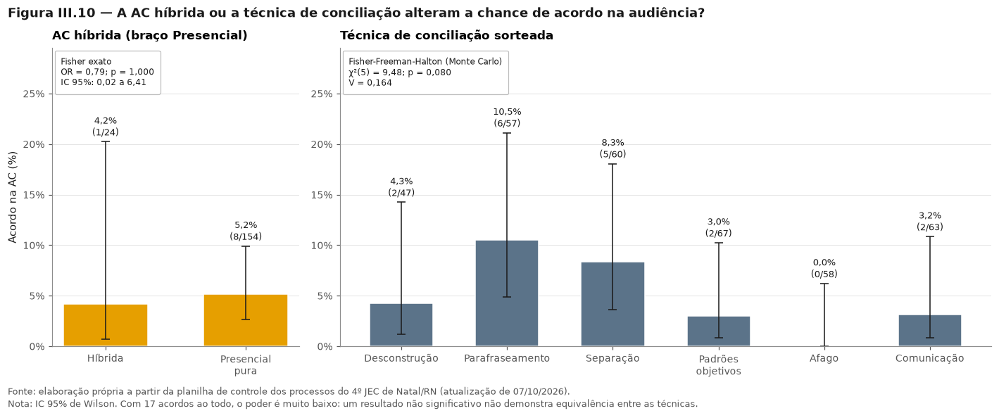

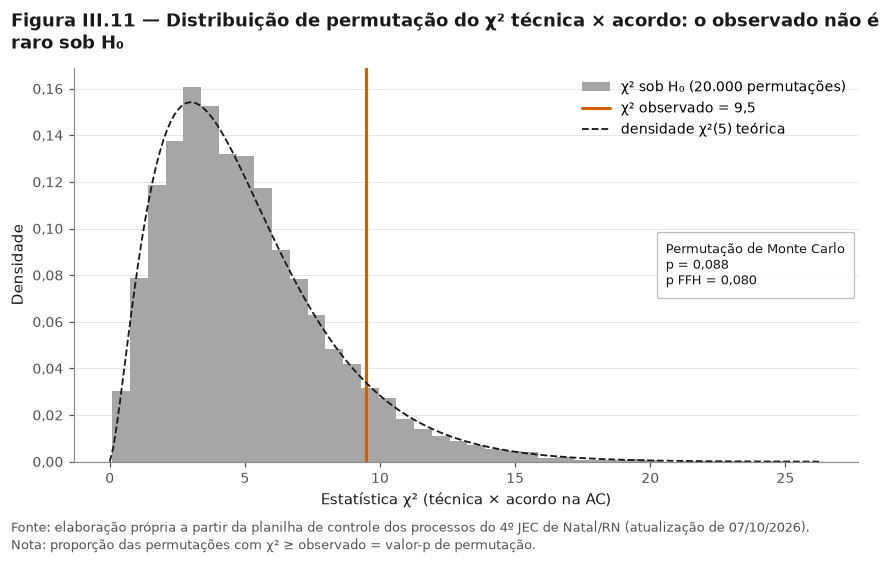

In [81]:
pres = t3_ac[t3_ac['grupo'] == 'Presencial']
pres = pres[pres['hibrida'].notna()]
tab_h = pd.crosstab(pres['hibrida'].astype(bool), pres['acordo_ac'].fillna(False).astype(bool)).reindex(index=[True, False], columns=[True, False], fill_value=0)
p_h, or_h, _, orh_lo, orh_hi = tst_fisher(tab_h.values)
_t = tab_h.rename(index={True: 'Híbrida', False: 'Presencial pura'}, columns={True: 'Acordo na AC', False: 'Sem acordo'})
tabela(tst_tab(_t.assign(**{'Acordo (%)': 100 * _t['Acordo na AC'] / _t.sum(axis=1)}), 'Formato da AC'), 'tst_hibrida',
       'Braço Presencial: acordo na AC híbrida × totalmente presencial (AC realizadas)', secao='3.3.4', casas=1)
print(f'Fisher p {tst_eq(p_h)} | OR = {fmt_br(or_h, 2)} (IC exato {fmt_br(orh_lo, 2)} a {fmt_br(orh_hi, 2)})')
tst_registra('3.3', 'H7 híbrida/técnica', 'Fisher híbrida × acordo na AC (Presencial)', 'OR = 1', f'OR = {fmt_br(or_h, 2)}', p_h,
             f'OR IC {fmt_br(orh_lo, 2)} a {fmt_br(orh_hi, 2)}')

tec = t3_ac[t3_ac['tecnica_curta'].notna()].copy()
tec['tecnica_curta'] = tec['tecnica_curta'].cat.remove_unused_categories()
y_tec = tec['acordo_ac'].fillna(False).astype(bool)
tab_tec = pd.crosstab(tec['tecnica_curta'], y_tec)
chi_tec, p_tec_chi, p_tec_ffh, chi_null = tst_perm_rxc(tec['tecnica_curta'], y_tec, B=20000)
e_tec = stats.contingency.expected_freq(tab_tec.values)
_t = tab_tec.rename(columns={True: 'Acordo', False: 'Sem acordo'})[['Acordo', 'Sem acordo']]
tabela(tst_tab(_t.assign(**{'Acordo (%)': 100 * tab_tec[True] / tab_tec.sum(axis=1),
                            'Acordos esperados sob H₀': e_tec[:, 1]}), 'Técnica de conciliação'), 'tst_tecnica',
       'Acordo na AC por técnica de conciliação sorteada (AC realizadas, Presencial e Remota)', secao='3.3.4', casas=1,
       nota='todas as esperadas da coluna "acordo" são menores que 5: o χ² assintótico não vale; usa-se permutação.')
print(f'χ² = {fmt_br(chi_tec, 2)}; p permutação (χ²) {tst_eq(p_tec_chi)}; p Fisher-Freeman-Halton MC {tst_eq(p_tec_ffh)} '
      f'(20.000 permutações)')
print(f'p assintótico (só para comparar, inválido aqui) {tst_eq(stats.chi2.sf(chi_tec, (tab_tec.shape[0] - 1)))}')
tst_registra('3.3', 'H7 híbrida/técnica', 'Técnica × acordo na AC (FFH Monte Carlo)', 'acordo independente da técnica',
             f'χ²(5) = {fmt_br(chi_tec, 2)}', p_tec_ffh, f'V = {fmt_br(tst_cramer(tab_tec), 3)}')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [0.55, 1.45]})
tst_barras_wilson(ax[0], ['Híbrida', 'Presencial pura'], [int(tab_h.loc[True, True]), int(tab_h.loc[False, True])],
                  [int(tab_h.loc[True].sum()), int(tab_h.loc[False].sum())], cores=CORES_GRUPO['Presencial'],
                  ylabel='Acordo na AC (%)', quebrar=10)
ax[0].set_title('AC híbrida (braço Presencial)')
anotar_teste(ax[0], texto_teste('Fisher exato', f'OR = {fmt_br(or_h, 2)}', p_h, f'IC 95%: {fmt_br(orh_lo, 2)} a {fmt_br(orh_hi, 2)}'),
             loc='upper left', tamanho=8)
tst_barras_wilson(ax[1], list(tab_tec.index), tab_tec[True].to_numpy(), tab_tec.sum(axis=1).to_numpy(), cores=COR_NEUTRA,
                  ylabel='', quebrar=13)
ax[1].set_title('Técnica de conciliação sorteada')
anotar_teste(ax[1], texto_teste('Fisher-Freeman-Halton (Monte Carlo)', f'χ²(5) = {fmt_br(chi_tec, 2)}', p_tec_ffh,
                                f'V = {fmt_br(tst_cramer(tab_tec), 3)}'), loc='upper left', tamanho=8)
ymax = max(a.get_ylim()[1] for a in ax)
for a in ax:
    a.set_ylim(0, ymax)
figura(fig, 'tst_hibrida_tecnica', 'A AC híbrida ou a técnica de conciliação alteram a chance de acordo na audiência?',
       secao='3.3.4', nota='IC 95% de Wilson. Com 17 acordos ao todo, o poder é muito baixo: um resultado não significativo não '
                           'demonstra equivalência entre as técnicas.')

fig, ax = plt.subplots(figsize=(8, 4.3))
ax.hist(chi_null, bins=40, color=CINZA, edgecolor='white', density=True, label='χ² sob H₀ (20.000 permutações)')
ax.axvline(chi_tec, color=DESTAQUE, lw=2, label=f'χ² observado = {fmt_br(chi_tec, 1)}')
xs = np.linspace(0, chi_null.max(), 200)
ax.plot(xs, stats.chi2.pdf(xs, 5), color=TINTA, lw=1.2, ls='--', label='densidade χ²(5) teórica')
ax.set_xlabel('Estatística χ² (técnica × acordo na AC)'); ax.set_ylabel('Densidade')
ax.legend(loc='upper right')
anotar_teste(ax, texto_teste('Permutação de Monte Carlo', None, p_tec_chi, f'p FFH {tst_eq(p_tec_ffh)}'), loc='center right')
figura(fig, 'tst_tecnica_permutacao', 'Distribuição de permutação do χ² técnica × acordo: o observado não é raro sob H₀',
       secao='3.3.4', nota='proporção das permutações com χ² ≥ observado = valor-p de permutação.')

**Leitura. A AC obrigatória não produziu mais acordos *na audiência*. O excedente de acordos da Remota veio de fora dela e só aparece com seguimento maior.**

- **Acordo na AC, presencial × remota (H4).** Foram 9/178 (5,1%) contra 8/174 (4,6%). Fisher p = 1,000; OR = 1,11 (IC exato 0,37 a 3,38); diferença de +0,5 p.p. (IC de Newcombe −4,4 a +5,3).
  - O resultado é **compatível com igualdade**, mas o IC é largo. Com uma taxa-base de 4,8% e cerca de 175 audiências por braço, só uma diferença de **≥ 8,4 p.p.** teria 80% de poder.
  - Ou seja, o estudo **exclui grandes diferenças** entre as modalidades, mas não exclui diferenças de alguns pontos percentuais.
  - Em qualquer modalidade, a taxa de acordo na AC (~5%) é baixa. É coerente com o diagnóstico Ipea/CNJ de baixa efetividade das audiências de conciliação nos JECs.
- **Acordo em qualquer momento (H5), em horizonte fixo:**
  - **até 65 dias** (938 processos): 3,5% no Controle, 4,5% no Presencial e 6,1% na Remota; χ² p = 0,300. Nenhum par difere;
  - **até 120 dias** (688 com seguimento ≥ 120 d): 5,0%, 9,4% e 12,5%; χ²(2) = 8,00, p = 0,018. O par **Remota × Controle** difere: OR = 2,70 (1,28 a 6,01), +7,5 p.p. (2,3 a 13,0), p Holm = 0,020. Presencial × Controle fica no limite (+4,4 p.p., IC −0,3 a 9,3; p Holm = 0,150).
  - Esse sinal é o mesmo da homologação entre os sentenciados (seção 3.2.3). **Não sobrevive à correção global de Holm** sobre os 55 testes da parte, só à de Benjamini-Hochberg (seção 3.7). É um achado **sugestivo**, a confirmar com a função de incidência acumulada do acordo (Parte IV).
- **De onde vem o excedente da Remota?** Não vem da AC, já que Presencial e Remota têm a mesma taxa na audiência. O acordo **fora** da AC é de 7,9% no Controle, 6,7% no Presencial e 11,9% na Remota (χ² p = 0,107; nenhum par significativo após Holm). A hipótese plausível, a testar com dados de movimentação, é que a AC remota sem acordo ainda aproxima as partes (contato, proposta registrada), e o acordo se fecha depois, por petição.
- **AC híbrida (H7):** 1/24 contra 8/154; Fisher p = 1,000, OR = 0,79 (0,02 a 6,41). Com 24 híbridas e 9 acordos, o teste é **não informativo**: o IC vai de "quase nunca" a "seis vezes mais". A híbrida também é escolha da parte (pós-sorteio).
- **Técnica (H7).** As taxas vão de 0/58 (Afago) a 6/57 (Parafraseamento).
  - O χ² observado é 9,48. A permutação de Monte Carlo dá p = 0,088 (estatística χ²), e o Fisher-Freeman-Halton por Monte Carlo dá **p = 0,080**. O p assintótico (0,092) é parecido, mas não é confiável aqui: todas as esperadas da coluna "acordo" estão entre 2,3 e 3,2.
  - **Não há evidência de que a técnica importe**, e com 17 acordos distribuídos por seis técnicas o teste tem poder muito baixo. A pergunta exigiria centenas de audiências por técnica.
  - O histograma de permutação mostra que, neste caso, a distribuição de referência fica próxima de um χ²(5). A permutação confirma o resultado, mas não o altera.

---

## 3.4 Tempo entre os sentenciados: testes clássicos e por que não bastam (H8)

### 3.4.1 Kruskal-Wallis, ε² e Dunn

**Atenção — análise condicional.** Aqui só entram os **708 processos sentenciados**. É a distribuição do tempo *dado que a sentença saiu até 07/10/2026*: os processos lentos que ainda estão ativos ficam de fora, e ficam mais de fora nos grupos com mais ativos (Presencial e Remota). O resultado descreve os encerrados, **não** estima o efeito do rito sobre o tempo (isso é feito na Parte IV, com Kaplan-Meier e log-rank).

- **H₀ (Kruskal-Wallis):** as três distribuições do tempo são iguais (nenhum grupo é estocasticamente maior). H₁: ao menos um grupo tende a valores maiores. O KW só se lê como "medianas iguais" se as formas forem iguais (E17).
- **Efeito:** ε² = H/(n − 1) (TOMCZAK; TOMCZAK, 2014); referência grosseira: 0,01 pequeno, 0,08 médio, 0,26 grande.
- **Post-hoc:** teste de Dunn (1964) com ajuste de Holm, que usa os postos conjuntos do KW (o notebook do professor usava Mann-Whitney sem correção).

Grupo,n,Q1 (dias),Mediana (dias),Q3 (dias),Média (dias)
Controle,262,"34,2",72,"96,0","71,0"
Presencial,230,"24,2",71,"110,0","69,8"
Remota,216,"31,2",77,"106,2","72,2"


Kruskal-Wallis: H = 0,33, gl = 2, p = 0,847 | ε² = 0,0005


Grupo,Controle,Presencial,Remota
Controle,"1,000","1,000","1,000"
Presencial,"1,000","1,000","1,000"
Remota,"1,000","1,000","1,000"


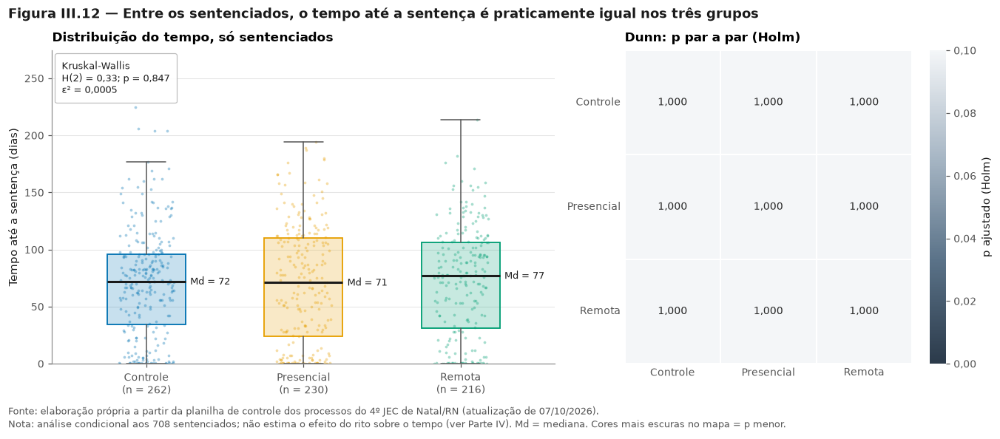

In [82]:
t3_enc = t3_sent.copy()
amostras = [t3_enc.loc[t3_enc['grupo'] == g, 'tempo_f'].values for g in ORDEM_GRUPO]
H_kw, p_kw = stats.kruskal(*amostras)
eps2 = H_kw / (len(t3_enc) - 1)
desc = t3_enc.groupby('grupo', observed=True)['tempo_f'].describe()[['count', '25%', '50%', '75%', 'mean']]
tabela(desc.rename(columns={'count': 'n', '25%': 'Q1 (dias)', '50%': 'Mediana (dias)', '75%': 'Q3 (dias)',
                            'mean': 'Média (dias)'}).rename_axis('Grupo'), 'tst_tempo_desc',
       'Tempo até a sentença entre os sentenciados, por grupo (estatística condicional)', secao='3.4.1', casas=1,
       nota='só os 708 sentenciados: os processos ainda ativos (mais longos) ficam de fora, de modo desigual entre os grupos.')
print(f'Kruskal-Wallis: H = {fmt_br(H_kw, 2)}, gl = 2, p {tst_eq(p_kw)} | ε² = {fmt_br(eps2, 4)}')
dunn = sp.posthoc_dunn(t3_enc, val_col='tempo_f', group_col='grupo', p_adjust='holm').loc[ORDEM_GRUPO, ORDEM_GRUPO]
tst_tabela_p(dunn.rename_axis('Grupo'), 'tst_dunn', 'Teste de Dunn: valores-p par a par ajustados por Holm (tempo, sentenciados)',
             '3.4.1', colunas_p=tuple(ORDEM_GRUPO), destaque=None)
tst_registra('3.4', 'H8 tempo (condicional)', 'Kruskal-Wallis tempo × grupo (sentenciados)', 'distribuições iguais',
             f'H(2) = {fmt_br(H_kw, 2)}', p_kw, f'ε² = {fmt_br(eps2, 4)}')

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={'width_ratios': [1.4, 1]})
boxplot_grupos(ax[0], t3_enc, 'tempo_f', ylabel=ROTULOS['tempo_sentenca'])
ax[0].set_title('Distribuição do tempo, só sentenciados')
ax[0].set_ylim(0, t3_enc['tempo_f'].max() * 1.22)
anotar_teste(ax[0], texto_teste('Kruskal-Wallis', f'H(2) = {fmt_br(H_kw, 2)}', p_kw, f'ε² = {fmt_br(eps2, 4)}'), loc='upper left')
anot = dunn.apply(lambda c: c.map(fmt_p)).to_numpy()
sns.heatmap(dunn.astype(float), annot=anot, fmt='', cmap=SEQ.reversed(), vmin=0, vmax=0.1, ax=ax[1], linewidths=1,
            linecolor='white', cbar_kws={'label': 'p ajustado (Holm)'}, annot_kws={'fontsize': 9})
ax[1].collections[0].colorbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_br(v, 2)))
ax[1].tick_params(length=0); ax[1].grid(False); ax[1].set_xlabel(''); ax[1].set_ylabel('')
ax[1].set_yticklabels(ax[1].get_yticklabels(), rotation=0)
ax[1].set_title('Dunn: p par a par (Holm)')
figura(fig, 'tst_tempo_kw', 'Entre os sentenciados, o tempo até a sentença é praticamente igual nos três grupos',
       secao='3.4.1', nota='análise condicional aos 708 sentenciados; não estima o efeito do rito sobre o tempo (ver Parte IV). '
                           'Md = mediana. Cores mais escuras no mapa = p menor.')

### 3.4.2 Mann-Whitney par a par com delta de Cliff

O mesmo contraste em pares, com o **delta de Cliff** d = P(X > Y) − P(X < Y), que vai de −1 a 1 e coincide com a correlação bisserial de postos. Referência de Romano et al. (2006): |d| < 0,147 desprezível, < 0,33 pequeno, < 0,474 médio. **H₀:** P(X > Y) = P(X < Y). Holm na família de três pares.

Comparação,n1,n2,U,p,delta de Cliff,IC inf,IC sup,p Holm
Presencial × Controle,230,262,"29.838,000","0,853","-0,010","-0,110","0,092","1,000"
Remota × Controle,216,262,"29.104,500","0,591","0,029","-0,074","0,133","1,000"
Presencial × Remota,230,216,"24.228,000","0,653","-0,025","-0,128","0,083","1,000"


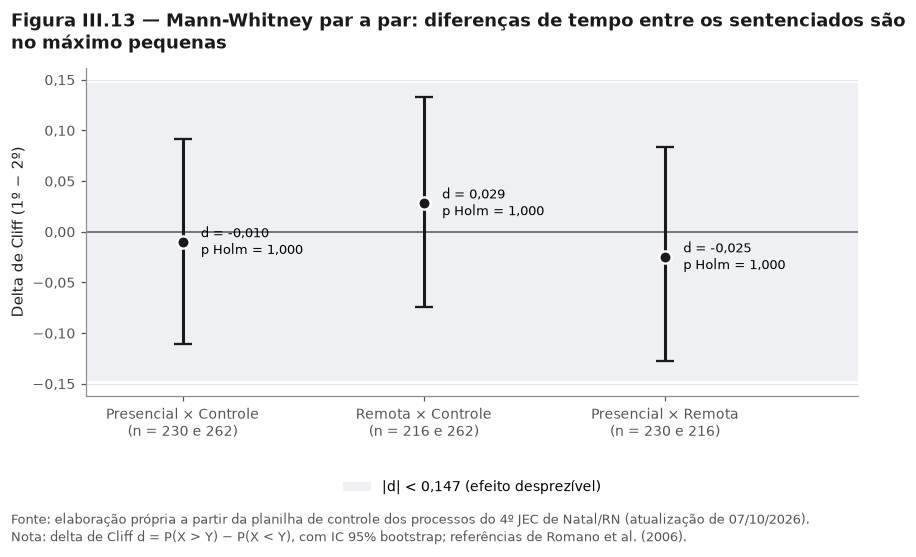

In [83]:
linhas = []
for a, b in PARES_GRUPO:
    xa = t3_enc.loc[t3_enc['grupo'] == a, 'tempo_f']; xb = t3_enc.loc[t3_enc['grupo'] == b, 'tempo_f']
    U, p = stats.mannwhitneyu(xa, xb, alternative='two-sided')
    d, dlo, dhi = tst_cliff(xa, xb)
    linhas.append({'Comparação': f'{a} × {b}', 'n1': len(xa), 'n2': len(xb), 'U': U, 'p': p,
                   'delta de Cliff': d, 'IC inf': dlo, 'IC sup': dhi})
t3_mw = pd.DataFrame(linhas); t3_mw['p Holm'] = tst_holm(t3_mw['p'])
tst_tabela_p(t3_mw, 'tst_mw', 'Mann-Whitney par a par com delta de Cliff (IC 95% bootstrap), tempo entre os sentenciados',
             '3.4.2', casas=3)
for _, r in t3_mw.iterrows():
    tst_registra('3.4', 'H8 pares MW', f'Mann-Whitney {r["Comparação"]} (sentenciados)', 'P(X>Y) = P(X<Y)',
                 f'U = {fmt_br(r["U"], 0)}', r['p'], f'Cliff d = {tst_ic_txt(r["delta de Cliff"], r["IC inf"], r["IC sup"], 3)}')

fig, ax = plt.subplots(figsize=(8, 4.3))
ax.axhspan(-0.147, 0.147, color='#EEF0F3', label='|d| < 0,147 (efeito desprezível)')
ax.axhline(0, color=TINTA_2, lw=1)
for i, r in t3_mw.iterrows():
    ax.errorbar(i, r['delta de Cliff'], yerr=[[r['delta de Cliff'] - r['IC inf']], [r['IC sup'] - r['delta de Cliff']]],
                fmt='o', color=TINTA, capsize=6, ms=8, mec='white', mew=1.5)
    ax.annotate(f'd = {fmt_br(r["delta de Cliff"], 3)}\np Holm {tst_eq(r["p Holm"])}', (i, r['delta de Cliff']),
                xytext=(12, 0), textcoords='offset points', fontsize=8.5, va='center')
ax.set_xticks(range(3), [f'{c}\n(n = {a} e {b})' for c, a, b in zip(t3_mw['Comparação'], t3_mw['n1'], t3_mw['n2'])])
ax.set_xlim(-0.4, 2.8)
ax.set_ylabel('Delta de Cliff (1º − 2º)')
ax.grid(axis='x', visible=False)
legenda_abaixo(ax, ncol=1, dy=-0.22)
desprezivel = bool((t3_mw[['IC inf', 'IC sup']].abs().max(axis=1) < 0.33).all())
figura(fig, 'tst_mw', 'Mann-Whitney par a par: diferenças de tempo entre os sentenciados são '
       + ('no máximo pequenas' if desprezivel else 'relevantes em algum par'), secao='3.4.2',
       nota='delta de Cliff d = P(X > Y) − P(X < Y), com IC 95% bootstrap; referências de Romano et al. (2006).')

### 3.4.3 Teste da mediana de Mood

Teste mais simples e robusto (só usa "acima/abaixo da mediana geral"), com menos poder que o KW. **H₀:** os três grupos têm a mesma mediana populacional. É uma tabela 3 × 2 testada por χ².

Tempo vs. mediana geral (74 dias),Controle,Presencial,Remota
> mediana,127,112,115
≤ mediana,135,118,101


Mediana geral = 74 dias | χ²(2) = 1,31, p = 0,520


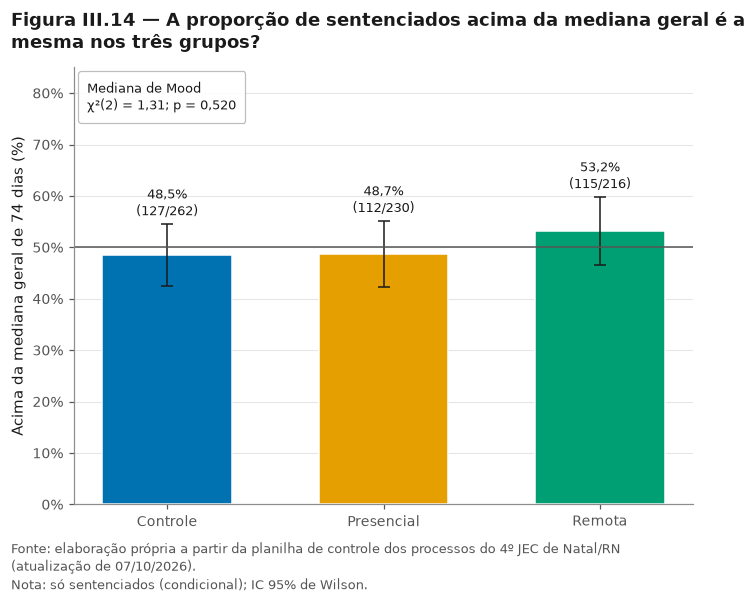

In [84]:
stat_m, p_m, med_m, tab_m = stats.median_test(*amostras, ties='below')
tab_m = pd.DataFrame(tab_m, index=['> mediana', '≤ mediana'], columns=ORDEM_GRUPO)
tabela(tab_m.rename_axis(f'Tempo vs. mediana geral ({fmt_br(med_m, 0)} dias)'), 'tst_mood',
       'Teste da mediana de Mood: sentenciados acima e abaixo da mediana geral, por grupo', secao='3.4.3')
print(f'Mediana geral = {fmt_br(med_m, 0)} dias | χ²(2) = {fmt_br(stat_m, 2)}, p {tst_eq(p_m)}')
tst_registra('3.4', 'H8 tempo (condicional)', 'Mediana de Mood (sentenciados)', 'medianas iguais', f'χ²(2) = {fmt_br(stat_m, 2)}', p_m, '')

fig, ax = plt.subplots(figsize=(6.5, 4.5))
tst_barras_wilson(ax, ORDEM_GRUPO, [int(tab_m.loc['> mediana', g]) for g in ORDEM_GRUPO],
                  [int(tab_m[g].sum()) for g in ORDEM_GRUPO], ylabel=f'Acima da mediana geral de {fmt_br(med_m, 0)} dias (%)',
                  ymax=85)
ax.axhline(50, color=TINTA_2, lw=1)
ax.annotate('50% (H₀)', (2.45, 50), xytext=(0, 3), textcoords='offset points', ha='right', fontsize=8.5, color=TINTA_2)
anotar_teste(ax, texto_teste('Mediana de Mood', f'χ²(2) = {fmt_br(stat_m, 2)}', p_m), loc='upper left')
figura(fig, 'tst_mood', 'A proporção de sentenciados acima da mediana geral é a mesma nos três grupos?', secao='3.4.3',
       nota='só sentenciados (condicional); IC 95% de Wilson.')

### 3.4.4 ANOVA e Welch: contraste didático

A ANOVA de um fator pressupõe normalidade dos resíduos e variâncias iguais; a ANOVA de Welch dispensa a igualdade de variâncias. Os pressupostos são verificados com **Levene** (centrado na média) e **Brown-Forsythe** (centrado na mediana, robusto) para a homogeneidade, e **Shapiro-Wilk** nos resíduos por grupo. O objetivo é **didático**: mostrar que, com n grande, a conclusão coincide com a do KW, mas que o teste paramétrico está formalmente fora das suas condições — e que nenhum dos dois resolve a censura.

Teste,H₀,Estatística,p
ANOVA de um fator,médias iguais,"0,133","0,875"
ANOVA de Welch,médias iguais (variâncias livres),"0,128","0,880"
Levene (média),variâncias iguais,"5,333","0,005"
Brown-Forsythe (mediana),variâncias iguais,"5,290","0,005"
"Shapiro-Wilk, resíduos Controle",resíduos normais,"0,962","< 0,001"
"Shapiro-Wilk, resíduos Presencial",resíduos normais,"0,943","< 0,001"
"Shapiro-Wilk, resíduos Remota",resíduos normais,"0,958","< 0,001"


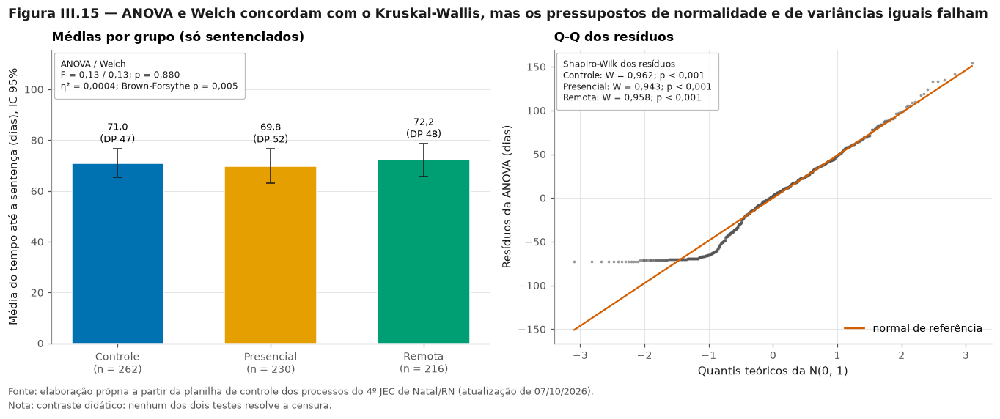

In [85]:
F_a, p_a = stats.f_oneway(*amostras)
welch = anova_oneway(t3_enc['tempo_f'].values, t3_enc['grupo'].astype(str).values, use_var='unequal')
lev, p_lev = stats.levene(*amostras, center='mean')
bf, p_bf = stats.levene(*amostras, center='median')
residuos = np.concatenate([a - a.mean() for a in amostras])
sw = {g: stats.shapiro(a - a.mean()) for g, a in zip(ORDEM_GRUPO, amostras)}
eta2 = F_a * 2 / (F_a * 2 + len(t3_enc) - 3)
_pres = pd.DataFrame([
    {'Teste': 'ANOVA de um fator', 'H₀': 'médias iguais', 'Estatística': F_a, 'p': p_a},
    {'Teste': 'ANOVA de Welch', 'H₀': 'médias iguais (variâncias livres)', 'Estatística': welch.statistic, 'p': welch.pvalue},
    {'Teste': 'Levene (média)', 'H₀': 'variâncias iguais', 'Estatística': lev, 'p': p_lev},
    {'Teste': 'Brown-Forsythe (mediana)', 'H₀': 'variâncias iguais', 'Estatística': bf, 'p': p_bf},
] + [{'Teste': f'Shapiro-Wilk, resíduos {g}', 'H₀': 'resíduos normais', 'Estatística': r.statistic, 'p': r.pvalue}
     for g, r in sw.items()])
tst_tabela_p(_pres, 'tst_anova', 'ANOVA e Welch (contraste didático) e verificação dos pressupostos', '3.4.4', casas=3,
             destaque='p', nota=f'η² = {fmt_br(eta2, 4)}. Linhas destacadas: p < 0,05 (pressuposto violado nos testes de variância e normalidade).')
tst_registra('3.4', 'H8 didático', 'ANOVA de Welch (sentenciados; didático)', 'médias iguais', f'F = {fmt_br(welch.statistic, 3)}',
             welch.pvalue, f'η² = {fmt_br(eta2, 4)}')

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6))
medias = [a.mean() for a in amostras]
ep = [a.std(ddof=1) / np.sqrt(len(a)) for a in amostras]
barras_verticais(ax[0], ORDEM_GRUPO, medias, erro=([m - 1.96 * e for m, e in zip(medias, ep)], [m + 1.96 * e for m, e in zip(medias, ep)]),
                 rotular=False, ns=[len(a) for a in amostras], ylabel='Média do tempo até a sentença (dias), IC 95%')
for i, (m, e, a) in enumerate(zip(medias, ep, amostras)):
    ax[0].annotate(f'{fmt_br(m, 1)}\n(DP {fmt_br(a.std(ddof=1), 0)})', (i, m + 1.96 * e), xytext=(0, 3),
                   textcoords='offset points', ha='center', va='bottom', fontsize=8.5)
ax[0].set_ylim(0, max(medias) * 1.6)
ax[0].set_title('Médias por grupo (só sentenciados)')
anotar_teste(ax[0], texto_teste('ANOVA / Welch', f'F = {fmt_br(F_a, 2)} / {fmt_br(welch.statistic, 2)}', welch.pvalue,
                                f'η² = {fmt_br(eta2, 4)}; Brown-Forsythe p {tst_eq(p_bf)}'), loc='upper left', tamanho=8)
(osm, osr), _ = stats.probplot(residuos, dist='norm')
ax[1].scatter(osm, osr, s=6, color=TINTA_2, alpha=0.6, lw=0)
ax[1].plot(osm, osm * residuos.std(ddof=1), color=DESTAQUE, lw=1.5, label='normal de referência')
ax[1].set_xlabel('Quantis teóricos da N(0, 1)'); ax[1].set_ylabel('Resíduos da ANOVA (dias)')
ax[1].set_title('Q-Q dos resíduos'); ax[1].grid(axis='both', visible=True)
ax[1].legend(loc='lower right')
anotar_teste(ax[1], '\n'.join(['Shapiro-Wilk dos resíduos'] + [f'{g}: W = {fmt_br(r.statistic, 3)}; p {tst_eq(r.pvalue)}'
                                                               for g, r in sw.items()]), loc='upper left', tamanho=8)
figura(fig, 'tst_anova', 'ANOVA e Welch concordam com o Kruskal-Wallis, mas os pressupostos de normalidade e de variâncias iguais falham',
       secao='3.4.4', nota='contraste didático: nenhum dos dois testes resolve a censura.')

### 3.4.5 Estratificado pelo tipo de sentença: o efeito de composição

Os tipos de sentença têm tempos muito diferentes (uma extinção sem mérito por ausência à AC sai rápido; um julgamento de mérito exige contestação e instrução). Como os grupos diferem na **composição** de tipos (seção 3.2), uma diferença no tempo "total" pode vir só da mistura. Testa-se, por isso, o tempo × grupo **dentro de cada tipo** (KW, Holm na família de três estratos).

Ressalva: estratificar por uma variável **pós-sorteio** (o tipo de desfecho é consequência do rito) quebra a comparabilidade garantida pelo sorteio; a análise é descritiva do mecanismo, não estimativa causal.

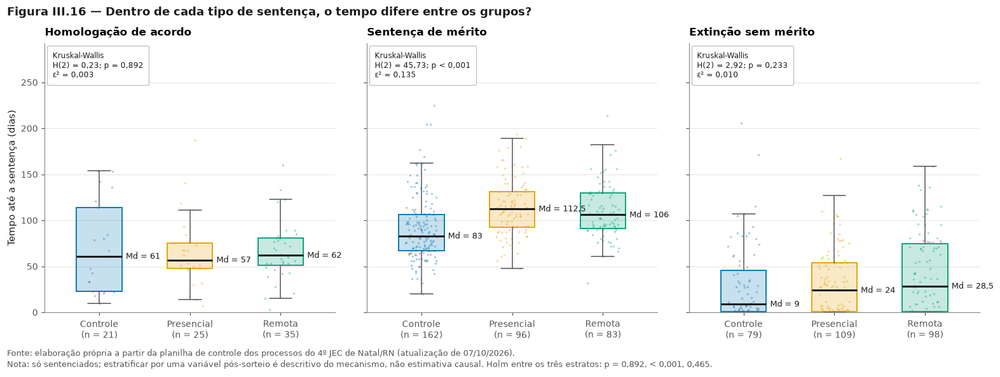

Tipo,n,Mediana Controle (dias),Mediana Presencial (dias),Mediana Remota (dias),H,p,ε²,p Holm
Homologação de acordo,81,"61,0","57,0","62,0","0,228","0,892","0,003","0,892"
Sentença de mérito,341,"83,0","112,5","106,0","45,732","< 0,001","0,135","< 0,001"
Extinção sem mérito,286,"9,0","24,0","28,5","2,918","0,233","0,010","0,465"


Mediana do tempo por tipo (todos os grupos): {'Homologação': '61', 'Mérito': '97', 'Sem mérito': '20'}


In [86]:
linhas = []
fig, ax = plt.subplots(1, 3, figsize=(14.5, 4.8), sharey=True)
for k, tipo in enumerate(['Homologação', 'Mérito', 'Sem mérito']):
    sub = t3_enc[t3_enc['tipo'] == tipo]
    a = [sub.loc[sub['grupo'] == g, 'tempo_f'].values for g in ORDEM_GRUPO]
    H, p = stats.kruskal(*a)
    linhas.append({'Tipo': tipo, 'n': len(sub), **{f'Md {g}': np.median(x) for g, x in zip(ORDEM_GRUPO, a)},
                   'H': H, 'p': p, 'ε²': H / (len(sub) - 1)})
    boxplot_grupos(ax[k], sub, 'tempo_f', ylabel=ROTULOS['tempo_sentenca'] if k == 0 else None, tam_ponto=5)
    ax[k].set_title(ROTULO_DESFECHO[tipo])
    anotar_teste(ax[k], texto_teste('Kruskal-Wallis', f'H(2) = {fmt_br(H, 2)}', p, f'ε² = {fmt_br(H / (len(sub) - 1), 3)}'),
                 loc='upper left', tamanho=8)
ax[0].set_ylim(0, t3_enc['tempo_f'].max() * 1.3)
t3_estrato = pd.DataFrame(linhas); t3_estrato['p Holm'] = tst_holm(t3_estrato['p'])
figura(fig, 'tst_tempo_por_tipo', 'Dentro de cada tipo de sentença, o tempo difere entre os grupos?', secao='3.4.5',
       nota='só sentenciados; estratificar por uma variável pós-sorteio é descritivo do mecanismo, não estimativa causal. '
            f'Holm entre os três estratos: p = {", ".join(fmt_p(v) for v in t3_estrato["p Holm"])}.')
tst_tabela_p(t3_estrato.assign(Tipo=t3_estrato['Tipo'].map(ROTULO_DESFECHO))
             .rename(columns={f'Md {g}': f'Mediana {g} (dias)' for g in ORDEM_GRUPO}),
             'tst_tempo_por_tipo', 'Tempo até a sentença × grupo dentro de cada tipo de sentença (Kruskal-Wallis, Holm)',
             '3.4.5', casas=3, formatos={f'Mediana {g} (dias)': 1 for g in ORDEM_GRUPO})
for _, r in t3_estrato.iterrows():
    tst_registra('3.4', 'H8 por tipo', f'Kruskal-Wallis tempo × grupo, só {r["Tipo"]}', 'distribuições iguais',
                 f'H(2) = {fmt_br(r["H"], 2)}', r['p'], f'ε² = {fmt_br(r["ε²"], 4)}')
mediana_tipo = t3_enc.groupby('tipo', observed=True)['tempo_f'].median()
print('Mediana do tempo por tipo (todos os grupos):', {k: fmt_br(v, 0) for k, v in mediana_tipo.items()})

### 3.4.6 O Kruskal-Wallis do professor (p ≈ 0,48) e como ele muda

O notebook do professor aplicou o KW a **todos** os processos, tratando o tempo dos ativos (censurado no corte) como tempo completo e a "Decisão" como sentença (E10, E14, E17), e concluiu "sem diferença" (H = 1,48; p = 0,478). Abaixo, o mesmo teste em quatro versões:

1. **Professor (reproduzido na base de 938):** todos os tempos, censurados como se completos;
2. **Só sentenciados (708):** condicional, seção 3.4.1;
3. **Janela de 65 dias (914, sem redistribuídos):** tempo truncado em 65, min(T, 65). Como todos são acompanhados por ≥ 65 dias, o tempo truncado é **observado** para todos: é a única versão do KW livre de censura (equivale a comparar a área sob a curva de sobrevivência até 65 dias, a ideia do RMST da Parte IV);
4. **Sentença até 65 dias (indicador):** χ² da proporção sentenciada até o 65º dia.

E também o **Mann-Whitney com × sem acordo na AC** do professor (E24), refeito só entre as AC realizadas que já têm sentença.

Versão,n,H / χ²,p,Medida,Controle,Presencial,Remota
"1. Professor: todos, censura ignorada",938,"1,16","0,559",mediana (dias),"77,0","83,5","81,0"
2. Só sentenciados (condicional),708,"0,33","0,847",mediana (dias),"72,0","71,0","77,0"
3. Tempo truncado em 65 d (sem censura),914,"4,00","0,135","média de min(T, 65) (dias)","51,8","49,9","53,1"
4. Sentença até 65 d (χ² 3×2),914,"5,54","0,063",% sentenciado até 65 d,"36,0","35,9","28,1"


% sentenciados até 65 dias: {'Controle': '36,0%', 'Presencial': '35,9%', 'Remota': '28,1%'}
% de ativos (censurados) por grupo: {'Controle': '14,7%', 'Presencial': '23,6%', 'Remota': '27,7%'}
Mediana do tempo dos ATIVOS por grupo (seguimento, não duração): {'Controle': '112', 'Presencial': '100', 'Remota': '89'}


E24 refeito (AC realizadas e sentenciadas): com acordo n = 17, Md = 63 | sem acordo n = 246, Md = 104 | U = 816, p < 0,001, Cliff d = -0,610 [-0,850; -0,315]


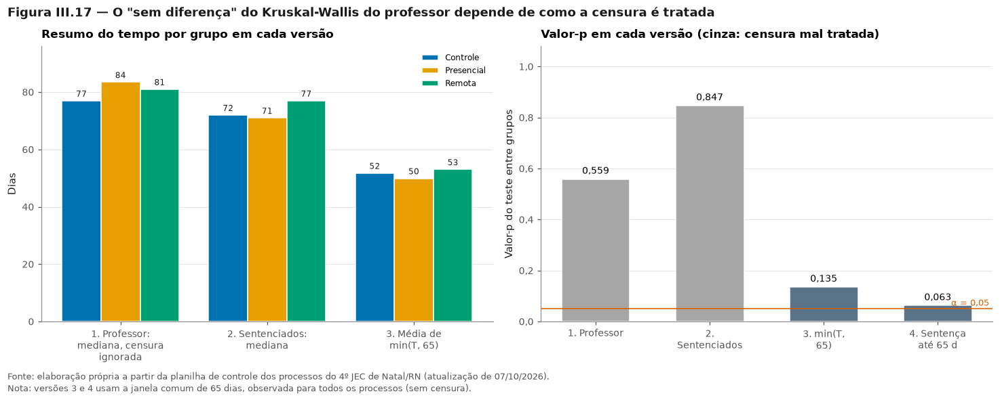

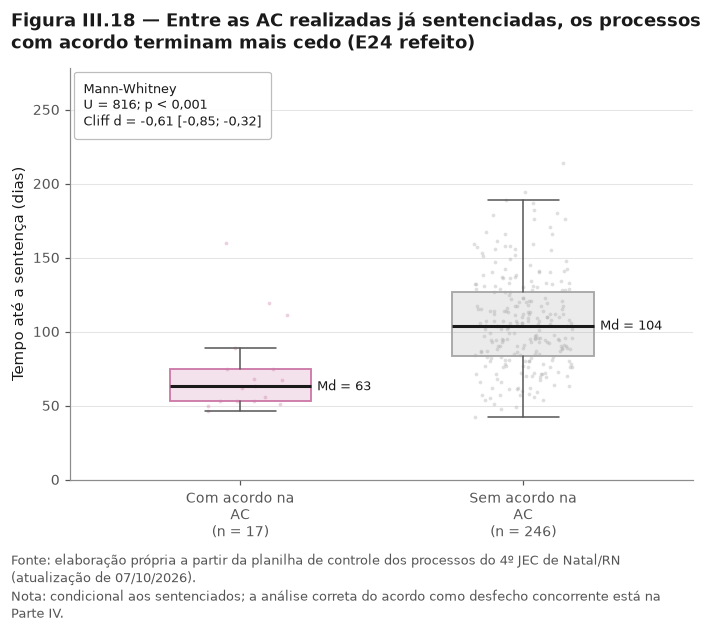

In [87]:
def kw_grupos(df, col):
    a = [df.loc[df['grupo'] == g, col].values for g in ORDEM_GRUPO]
    H, p = stats.kruskal(*a)
    resumo = [np.mean(x) for x in a] if col == 'tempo65' else [np.median(x) for x in a]
    return H, p, resumo, len(df)

t3['tempo65'] = t3['tempo_f'].clip(upper=65)
nao_red = t3[t3['tipo_desfecho'] != 'Redistribuição']
versoes = {
    '1. Professor: todos, censura ignorada': kw_grupos(t3, 'tempo_f'),
    '2. Só sentenciados (condicional)': kw_grupos(t3_enc, 'tempo_f'),
    '3. Tempo truncado em 65 d (sem censura)': kw_grupos(nao_red, 'tempo65'),
}
y65 = (nao_red['evento'] == 1) & (nao_red['tempo_f'] <= 65)
tab_s65 = pd.crosstab(nao_red['grupo'], y65)
c2_s65, p_s65, _, _ = stats.chi2_contingency(tab_s65, correction=False)
MEDIDA = ['mediana (dias)', 'mediana (dias)', 'média de min(T, 65) (dias)']
linhas = [{'Versão': k, 'n': v[3], 'H / χ²': v[0], 'p': v[1], 'Medida': med, **{g: m for g, m in zip(ORDEM_GRUPO, v[2])}}
          for (k, v), med in zip(versoes.items(), MEDIDA)]
linhas.append({'Versão': '4. Sentença até 65 d (χ² 3×2)', 'n': len(nao_red), 'H / χ²': c2_s65, 'p': p_s65,
               'Medida': '% sentenciado até 65 d', **{g: 100 * tab_s65.loc[g, True] / tab_s65.loc[g].sum() for g in ORDEM_GRUPO}})
t3_versoes = pd.DataFrame(linhas)
tst_tabela_p(t3_versoes, 'tst_kw_versoes', 'O Kruskal-Wallis do professor em quatro versões: o resultado depende do tratamento da censura',
             '3.4.6', casas=2, formatos={g: 1 for g in ORDEM_GRUPO}, destaque='p')
print('% sentenciados até 65 dias:', {g: pct_br(tab_s65.loc[g, True] / tab_s65.loc[g].sum()) for g in ORDEM_GRUPO})
print('% de ativos (censurados) por grupo:', {g: pct_br((t3.loc[t3['grupo'] == g, 'tipo_desfecho'] == 'Ativo').mean()) for g in ORDEM_GRUPO})
print('Mediana do tempo dos ATIVOS por grupo (seguimento, não duração):',
      {g: fmt_br(t3.loc[(t3['grupo'] == g) & (t3['tipo_desfecho'] == 'Ativo'), 'tempo_f'].median(), 0) for g in ORDEM_GRUPO})
tst_registra('3.4', 'H8 sem censura', 'Kruskal-Wallis min(T, 65) × grupo', 'distribuições iguais',
             f'H(2) = {fmt_br(versoes["3. Tempo truncado em 65 d (sem censura)"][0], 2)}', versoes['3. Tempo truncado em 65 d (sem censura)'][1], '')
tst_registra('3.4', 'H8 sem censura', 'χ² sentença até 65 d × grupo', 'proporção igual', f'χ²(2) = {fmt_br(c2_s65, 2)}', p_s65,
             f'V = {fmt_br(tst_cramer(tab_s65), 3)}')

# E24: Mann-Whitney com × sem acordo na AC, refeito entre AC realizadas já sentenciadas
acs = t3_ac[t3_ac['evento'] == 1]
com, sem = acs.loc[acs['acordo_ac'] == True, 'tempo_f'], acs.loc[acs['acordo_ac'] == False, 'tempo_f']
U24, p24 = stats.mannwhitneyu(com, sem)
d24, d24lo, d24hi = tst_cliff(com, sem)
print(f'E24 refeito (AC realizadas e sentenciadas): com acordo n = {len(com)}, Md = {fmt_br(com.median(), 0)} | '
      f'sem acordo n = {len(sem)}, Md = {fmt_br(sem.median(), 0)} | U = {fmt_br(U24, 0)}, p {tst_eq(p24)}, '
      f'Cliff d = {tst_ic_txt(d24, d24lo, d24hi, 3)}')
tst_registra('3.4', 'H8 acordo', 'Mann-Whitney tempo com × sem acordo na AC (AC realizadas, sentenciados)', 'P(X>Y) = P(X<Y)',
             f'U = {fmt_br(U24, 0)}', p24, f'Cliff d = {tst_ic_txt(d24, d24lo, d24hi, 3)}')

ROT_VERSAO = ['1. Professor:\nmediana, censura\nignorada', '2. Sentenciados:\nmediana', '3. Média de\nmin(T, 65)']
fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.8))
_tv = t3_versoes.iloc[:3][ORDEM_GRUPO].copy()
_tv.index = ROT_VERSAO
barras_agrupadas(ax[0], _tv, cores=CORES_GRUPO, rotular=True, fmt=lambda v: fmt_br(v, 0), ylabel='Dias', quebrar=40)
ax[0].set_title('Resumo do tempo por grupo em cada versão')
ax[0].legend(loc='upper right', fontsize=8)
pv = t3_versoes['p'].to_numpy()
cores_v = [CINZA, CINZA, COR_NEUTRA, COR_NEUTRA]
barras_verticais(ax[1], ['1. Professor', '2. Sentenciados', '3. min(T, 65)', '4. Sentença até 65 d'], pv, cores=cores_v,
                 rotular=False, ylabel='Valor-p do teste entre grupos', ymax=1.08, quebrar=12)
for i, p_ in enumerate(pv):
    ax[1].annotate(fmt_p(p_), (i, p_), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9)
ax[1].axhline(0.05, color=DESTAQUE, lw=1)
ax[1].annotate('α = 0,05', (3.45, 0.05), xytext=(0, 3), textcoords='offset points', ha='right', fontsize=8.5, color=DESTAQUE)
ax[1].set_title('Valor-p em cada versão (cinza: censura mal tratada)')
figura(fig, 'tst_kw_versoes', 'O "sem diferença" do Kruskal-Wallis do professor depende de como a censura é tratada',
       secao='3.4.6', nota='versões 3 e 4 usam a janela comum de 65 dias, observada para todos os processos (sem censura).')

_e24 = acs[acs['acordo_ac'].notna()].assign(Acordo=np.where(acs['acordo_ac'] == True, 'Com acordo na AC', 'Sem acordo na AC'))
fig, ax = plt.subplots(figsize=(6.5, 4.6))
boxplot_grupos(ax, _e24, 'tempo_f', grupo='Acordo', ordem=['Com acordo na AC', 'Sem acordo na AC'],
               cores={'Com acordo na AC': CORES_DESFECHO['Homologação'], 'Sem acordo na AC': CINZA},
               ylabel=ROTULOS['tempo_sentenca'])
ax.set_ylim(0, _e24['tempo_f'].max() * 1.3)
anotar_teste(ax, texto_teste('Mann-Whitney', f'U = {fmt_br(U24, 0)}', p24, f'Cliff d = {tst_ic_txt(d24, d24lo, d24hi, 2)}'),
             loc='upper left')
figura(fig, 'tst_e24', 'Entre as AC realizadas já sentenciadas, os processos com acordo terminam mais cedo (E24 refeito)',
       secao='3.4.6', nota='condicional aos sentenciados; a análise correta do acordo como desfecho concorrente está na Parte IV.')

**Leitura. Entre os sentenciados, os três grupos "levam o mesmo tempo". Esse resultado esconde dois efeitos opostos e é enviesado pela censura.**

- **Testes clássicos, só entre os sentenciados (708):**
  - **Kruskal-Wallis:** H = 0,33, p = 0,847, ε² = 0,0005, praticamente zero. Medianas: Controle 72, Presencial 71 e Remota 77 dias. O Dunn com Holm dá p = 1 em todos os pares;
  - **Mann-Whitney:** todos os deltas de Cliff estão entre −0,03 e +0,03, com ICs dentro de ±0,13 (efeito desprezível);
  - **mediana de Mood:** p = 0,520.
- **ANOVA e Welch (didático).** F = 0,13, p = 0,875; Welch p = 0,880. A conclusão é a mesma, mas os pressupostos falham:
  - **homocedasticidade:** Levene p = 0,005 e Brown-Forsythe p = 0,005 rejeitam a igualdade de variâncias. O Presencial é o mais disperso (P75 = 110 dias);
  - **normalidade:** Shapiro-Wilk rejeita nos resíduos dos três grupos (p < 0,001), e o Q-Q mostra caudas curtas, cortadas pela censura, e massa perto de zero.

  Com n ≈ 230 por grupo, o F é robusto o bastante para não errar a conclusão, mas não há razão para preferi-lo ao KW.
- **O efeito de composição.** Estratificando pelo tipo de sentença:
  - **mérito:** os braços com AC são **muito mais lentos**. Medianas: Controle 83, Presencial 112,5 e Remota 106 dias. KW H = 45,7, p Holm < 0,001, ε² = 0,13 (efeito médio). A AC inaugural acrescenta uma etapa antes da contestação, e o julgamento de mérito chega cerca de um mês depois;
  - **sem mérito:** as extinções saem cedo nos três grupos (medianas 9, 24 e 28,5 dias; p Holm = 0,465);
  - **homologação:** 61, 57 e 62 dias (p = 0,892).

  Os braços com AC têm **mais** extinções rápidas (sem mérito, mediana geral de 20 dias) e **menos** julgamentos de mérito (mediana geral de 97 dias). No agregado, a lentidão do mérito é compensada pela rapidez das extinções. O "nenhuma diferença" do agregado é um **paradoxo de composição**, não ausência de efeito. Ressalva: o tipo de sentença é pós-sorteio, então a estratificação descreve o mecanismo, mas não estima o efeito causal.
- **Por que o KW do professor dá p ≈ 0,5, e como isso muda (E14, E17).** Na base primária, a reprodução dá H = 1,16, p = 0,559 (no original, p = 0,478, com 944 linhas, duplicatas e "Decisão" como sentença). O teste mistura dois tipos de número:
  - durações reais dos encerrados;
  - **tempos de seguimento** dos ativos, que são 14,7% do Controle, 23,6% do Presencial e 27,7% da Remota. Os ativos não têm duração, e sim um piso: estão em tramitação há pelo menos 112, 100 e 89 dias (medianas).

  O grupo com mais ativos tem mais tempos "cortados", e o teste compara grandezas diferentes. Retirar os ativos (versão 2) não resolve: a comparação passa a ser entre os que encerraram rápido o bastante, e o p sobe para 0,847.
- **Versões sem censura.** Com a janela comum de 65 dias, observada para todos:
  - média de min(T, 65): 51,8, 49,9 e 53,1 dias (KW p = 0,135);
  - sentença até o 65º dia: 36,0%, 35,9% e 28,1% (χ² p = 0,063).

  A Remota já aparece mais lenta, embora sem significância nesse horizonte curto. Usando todo o seguimento com Kaplan-Meier e log-rank (Parte IV), a revisão do notebook do professor encontrou medianas de Controle 80, Presencial 93 e Remota 94 dias (log-rank p ≈ 0,03). **A conclusão muda** de "o rito não importa" (KW ingênuo) para "a AC obrigatória alonga a tramitação", e só um método que respeita a censura consegue mostrar isso.
- **E24 refeito.** Entre as AC realizadas já sentenciadas, os 17 processos com acordo na AC terminaram em 63 dias (mediana), contra 104 dias dos sem acordo (U = 816, p < 0,001, delta de Cliff = −0,61, IC −0,85 a −0,32). O efeito é grande, mas em boa parte é **definicional**: o acordo encerra o processo com a homologação, e quem não fez acordo segue para contestação e julgamento. A pergunta correta ("o acordo na AC antecipa o fim?") é de riscos competitivos (Parte IV).

---

## 3.5 Ordem de chegada (questão 2.7; H9 a H11)

### 3.5.1 O sorteio foi aleatório? Teste de corridas de Wald-Wolfowitz

Segundo o pesquisador, o sorteio seguiu a ordem de chegada. Se a alocação foi de fato aleatória, a sequência de grupos na ordem de chegada não deve ter **padrões**: nem corridas longas demais (blocos de um mesmo grupo), nem alternância regular demais (rodízio Controle → Presencial → Remota). O **número de corridas** R (sequências maximais de um mesmo grupo) mede isso.

- **H₀:** a sequência é uma permutação aleatória dos 938 rótulos. **H₁:** bilateral (R pequeno = agrupamento; R grande = alternância).
- **Três categorias:** a distribuição de R sob H₀ é obtida por **permutação** (10.000 embaralhamentos da sequência); também se compara a **maior corrida** observada.
- **Por grupo:** cada grupo × os demais (sequência binária), com a aproximação normal de Wald-Wolfowitz e Holm.

Corridas observadas R = 626 | esperado sob H0 = 626,3 | permutação: média 626,2, DP 14,3 | p bilateral = 1,000
Maior corrida = 8 | P(maior corrida ≥ 8 sob H0) = 0,239


Grupo,n,Corridas,Esperado,z,p,p Holm
Controle,313,424,"418,11","0,43","0,665","0,906"
Presencial,314,429,"418,77","0,75","0,453","0,906"
Remota,311,400,"416,77","-1,24","0,216","0,649"


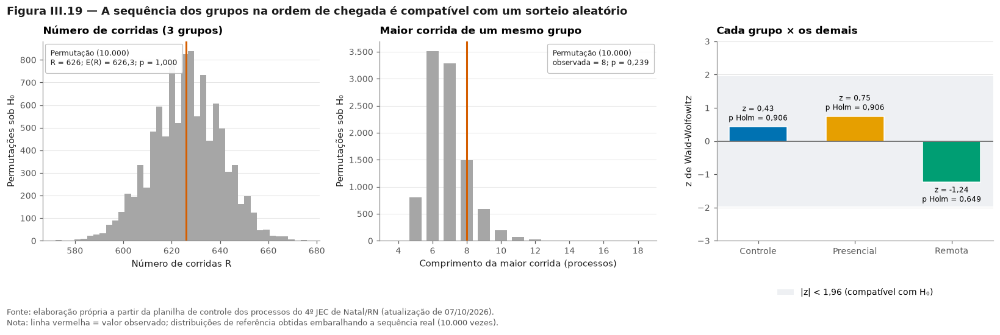

In [88]:
seq = t3.sort_values('ordem_chegada')['grupo'].astype(str).values
def n_corridas(s):
    return 1 + int((s[1:] != s[:-1]).sum())
def maior_corrida(s):
    m = c = 1
    for i in range(1, len(s)):
        c = c + 1 if s[i] == s[i - 1] else 1
        m = max(m, c)
    return m
R_obs, L_obs = n_corridas(seq), maior_corrida(seq)
n = len(seq); cont = pd.Series(seq).value_counts()
E_R = 1 + (n - 1) - (cont * (cont - 1)).sum() / n
rng = np.random.default_rng(SEMENTE)
R_null, L_null = np.empty(10000), np.empty(10000)
for b in range(10000):
    s = rng.permutation(seq)
    R_null[b], L_null[b] = n_corridas(s), maior_corrida(s)
p_R = min(1, 2 * min((R_null <= R_obs).mean(), (R_null >= R_obs).mean()))
p_L = (L_null >= L_obs).mean()
print(f'Corridas observadas R = {R_obs} | esperado sob H0 = {fmt_br(E_R, 1)} | permutação: média {fmt_br(R_null.mean(), 1)}, '
      f'DP {fmt_br(R_null.std(), 1)} | p bilateral {tst_eq(p_R)}')
print(f'Maior corrida = {L_obs} | P(maior corrida ≥ {L_obs} sob H0) {tst_eq(p_L)}')
tst_registra('3.5', 'H9 sorteio', 'Corridas (3 grupos, permutação)', 'sequência aleatória', f'R = {R_obs} (E = {fmt_br(E_R, 1)})', p_R, '')

linhas = []
for g in ORDEM_GRUPO:
    b = (seq == g)
    n1, n2 = b.sum(), (~b).sum()
    R = n_corridas(b)
    mu = 2 * n1 * n2 / n + 1
    var = 2 * n1 * n2 * (2 * n1 * n2 - n) / (n ** 2 * (n - 1))
    z = (R - mu) / np.sqrt(var)
    linhas.append({'Grupo': g, 'n': n1, 'Corridas': R, 'Esperado': mu, 'z': z, 'p': 2 * stats.norm.sf(abs(z))})
t3_runs = pd.DataFrame(linhas); t3_runs['p Holm'] = tst_holm(t3_runs['p'])
tst_tabela_p(t3_runs, 'tst_corridas', 'Teste de corridas de Wald-Wolfowitz: cada grupo × os demais na ordem de chegada',
             '3.5.1', casas=2)
for _, r in t3_runs.iterrows():
    tst_registra('3.5', 'H9 sorteio por grupo', f'Corridas {r["Grupo"]} × demais (Wald-Wolfowitz)', 'sequência aleatória',
                 f'z = {fmt_br(r["z"], 2)}', r['p'], '')

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
ax[0].hist(R_null, bins=40, color=CINZA, edgecolor='white')
ax[0].axvline(R_obs, color=DESTAQUE, lw=2)
ax[0].set_title('Número de corridas (3 grupos)'); ax[0].set_xlabel('Número de corridas R'); ax[0].set_ylabel('Permutações sob H₀')
anotar_teste(ax[0], texto_teste('Permutação (10.000)', f'R = {R_obs}; E(R) = {fmt_br(E_R, 1)}', p_R), loc='upper left', tamanho=8)
comp, freq = np.unique(L_null, return_counts=True)
ax[1].bar(comp, freq, color=CINZA, width=0.7)
ax[1].axvline(L_obs, color=DESTAQUE, lw=2)
ax[1].set_title('Maior corrida de um mesmo grupo'); ax[1].set_xlabel('Comprimento da maior corrida (processos)')
ax[1].set_ylabel('Permutações sob H₀'); ax[1].grid(axis='x', visible=False)
anotar_teste(ax[1], texto_teste('Permutação (10.000)', f'observada = {L_obs}', p_L), loc='upper right', tamanho=8)
ax[2].axhspan(-1.96, 1.96, color='#EEF0F3', label='|z| < 1,96 (compatível com H₀)')
barras_verticais(ax[2], ORDEM_GRUPO, t3_runs['z'], rotular=False, ylabel='z de Wald-Wolfowitz', ymax=3)
ax[2].set_ylim(-3, 3); ax[2].axhline(0, color=TINTA_2, lw=1)
for i, (z_, p_) in enumerate(zip(t3_runs['z'], t3_runs['p Holm'])):
    ax[2].annotate(f'z = {fmt_br(z_, 2)}\np Holm {tst_eq(p_)}', (i, z_), xytext=(0, 4 if z_ >= 0 else -4), textcoords='offset points',
                   ha='center', va='bottom' if z_ >= 0 else 'top', fontsize=8)
ax[2].set_title('Cada grupo × os demais'); legenda_abaixo(ax[2], ncol=1, dy=-0.2)
figura(fig, 'tst_corridas', 'A sequência dos grupos na ordem de chegada é compatível com um sorteio aleatório',
       secao='3.5.1', nota='linha vermelha = valor observado; distribuições de referência obtidas embaralhando a sequência real (10.000 vezes).')

### 3.5.2 Ordem de chegada × tempo: Spearman, Kendall e o artefato da censura (H10)

A ordem de chegada é **ordinal**; o tempo, quantitativo com censura. Pearson não cabe (E13, E16); Spearman (ρ) e Kendall (τ-b, que trata empates) medem associação monótona. **H₀:** ρ = 0 (τ = 0).

O problema é a censura: um processo distribuído em agosto só pode aparecer "encerrado" se tiver sido rápido (no máximo 65 dias), enquanto um de janeiro pode ter encerrado em até 279 dias. Entre os encerrados, a ordem de chegada **tem de** se correlacionar negativamente com o tempo, mesmo que o ritmo da vara não tenha mudado. Quatro versões:

1. **Todos (938)**, tempo censurado como se completo;
2. **Só sentenciados (708)**: o artefato;
3. **Janela comum de 65 dias**: min(T, 65), observado para todos (censura administrativa em 65 dias para todos) — a versão válida;
4. **Simulação sob H₀:** tempos gerados independentemente da ordem e censurados com o acompanhamento real de cada processo; mostra que o artefato aparece mesmo quando não existe associação verdadeira.

Versão,ρ Spearman,p (ρ),τ Kendall,p (τ),n
"1. Todos, censura ignorada","-0,041","0,211","-0,050","0,024",938
2. Só sentenciados,"-0,118","0,002","-0,082","0,001",708
"3. min(T, 65), sem redistribuídos","0,140","< 0,001","0,107","< 0,001",914


Versão,ρ médio sob H₀,"Percentil 2,5","Percentil 97,5",ρ observado
todos (censura ignorada),"-0,188","-0,246","-0,130","-0,041"
só encerrados,"-0,280","-0,343","-0,212","-0,118"
"min(T, 65)","-0,001","-0,066","0,067","0,140"


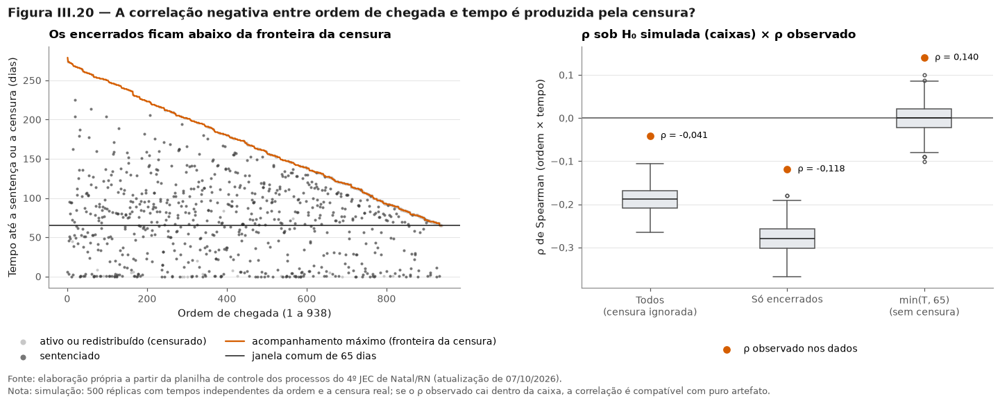

In [89]:
def corr_ord(df, col):
    rho, p_rho = stats.spearmanr(df['ordem_chegada'].astype(float), df[col])
    tau, p_tau = stats.kendalltau(df['ordem_chegada'].astype(float), df[col])
    return rho, p_rho, tau, p_tau, len(df)

t3_corr = pd.DataFrame([
    dict(zip(['Versão', 'ρ Spearman', 'p (ρ)', 'τ Kendall', 'p (τ)', 'n'], ['1. Todos, censura ignorada', *corr_ord(t3, 'tempo_f')])),
    dict(zip(['Versão', 'ρ Spearman', 'p (ρ)', 'τ Kendall', 'p (τ)', 'n'], ['2. Só sentenciados', *corr_ord(t3_enc, 'tempo_f')])),
    dict(zip(['Versão', 'ρ Spearman', 'p (ρ)', 'τ Kendall', 'p (τ)', 'n'], ['3. min(T, 65), sem redistribuídos', *corr_ord(nao_red, 'tempo65')])),
])
tst_tabela_p(t3_corr, 'tst_ordem_tempo', 'Ordem de chegada × tempo: Spearman e Kendall em três versões', '3.5.2', casas=3,
             colunas_p=('p (ρ)', 'p (τ)'), destaque='p (ρ)')
for _, r in t3_corr.iterrows():
    tst_registra('3.5', 'H10 ordem × tempo', f'Spearman ordem × tempo: {r["Versão"]}', 'ρ = 0', f'ρ = {fmt_br(r["ρ Spearman"], 3)}', r['p (ρ)'],
                 f'τ = {fmt_br(r["τ Kendall"], 3)}')

# Simulação: tempos independentes da ordem, censurados pelo acompanhamento real de cada processo
rng = np.random.default_rng(SEMENTE)
fu = t3['followup'].astype(float).values; ordem = t3['ordem_chegada'].astype(float).values
sim = {'todos (censura ignorada)': [], 'só encerrados': [], 'min(T, 65)': []}
for _ in range(500):
    T = rng.weibull(1.6, len(fu)) * 115            # forma e escala próximas às dos dados; sem relação com a ordem
    obs = np.minimum(T, fu); enc = T <= fu
    sim['todos (censura ignorada)'].append(stats.spearmanr(ordem, obs)[0])
    sim['só encerrados'].append(stats.spearmanr(ordem[enc], obs[enc])[0])
    sim['min(T, 65)'].append(stats.spearmanr(ordem, np.minimum(T, 65))[0])
sim = pd.DataFrame(sim)
tabela(pd.DataFrame({'Versão': sim.columns, 'ρ médio sob H₀': sim.mean().to_numpy(),
                     'Percentil 2,5': sim.quantile(.025).to_numpy(), 'Percentil 97,5': sim.quantile(.975).to_numpy(),
                     'ρ observado': t3_corr['ρ Spearman'].to_numpy()}),
       'tst_ordem_simulacao', 'Simulação sob H₀ (500 réplicas): o ρ que a censura produz sem nenhuma associação real',
       secao='3.5.2', casas=3, nota='tempos Weibull independentes da ordem, censurados pelo acompanhamento real de cada processo.')

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.8))
ev = t3['evento'] == 1
ax[0].scatter(t3.loc[~ev, 'ordem_chegada'], t3.loc[~ev, 'tempo_f'], color=CORES_STATUS['Ativo (censurado)'], s=7, lw=0,
              label='ativo ou redistribuído (censurado)')
ax[0].scatter(t3.loc[ev, 'ordem_chegada'], t3.loc[ev, 'tempo_f'], color=CORES_STATUS['Sentença'], s=7, lw=0, alpha=0.7,
              label='sentenciado')
srt = t3.sort_values('ordem_chegada')
ax[0].plot(srt['ordem_chegada'], srt['followup'], color=DESTAQUE, lw=1.5, label='acompanhamento máximo (fronteira da censura)')
ax[0].axhline(65, color=TINTA, lw=1, label='janela comum de 65 dias')
ax[0].set_xlabel(ROTULOS['ordem_chegada']); ax[0].set_ylabel(ROTULOS['tempo'])
ax[0].set_title('Os encerrados ficam abaixo da fronteira da censura')
legenda_abaixo(ax[0], ncol=2, dy=-0.17, markerscale=2)
pos = np.arange(3)
bp = ax[1].boxplot([sim[c] for c in sim], positions=pos, widths=0.4, patch_artist=True,
                   boxprops=dict(facecolor='#E6E9ED', edgecolor=TINTA_2), medianprops=dict(color=TINTA),
                   whiskerprops=dict(color=TINTA_2), capprops=dict(color=TINTA_2), flierprops=dict(ms=3, mec=TINTA_2))
obs_rho = [t3_corr['ρ Spearman'].iloc[0], t3_corr['ρ Spearman'].iloc[1], t3_corr['ρ Spearman'].iloc[2]]
ax[1].scatter(pos, obs_rho, color=DESTAQUE, zorder=3, s=50, label='ρ observado nos dados')
for x_, r_ in zip(pos, obs_rho):
    ax[1].annotate(f'ρ = {fmt_br(r_, 3)}', (x_, r_), xytext=(10, 0), textcoords='offset points', va='center', fontsize=8.5)
ax[1].axhline(0, color=TINTA_2, lw=1)
ax[1].set_xticks(pos, ['Todos\n(censura ignorada)', 'Só encerrados', 'min(T, 65)\n(sem censura)'])
ax[1].set_ylabel('ρ de Spearman (ordem × tempo)'); ax[1].set_title('ρ sob H₀ simulada (caixas) × ρ observado')
legenda_abaixo(ax[1], ncol=1, dy=-0.2)
figura(fig, 'tst_ordem_tempo', 'A correlação negativa entre ordem de chegada e tempo é produzida pela censura?',
       secao='3.5.2', nota='simulação: 500 réplicas com tempos independentes da ordem e a censura real; '
                           'se o ρ observado cai dentro da caixa, a correlação é compatível com puro artefato.')

### 3.5.3 Grupo × mês de distribuição (H11)

Mesmo com sorteio aleatório, a composição mensal pode oscilar. Se oscilar além do acaso, o mês (que determina o acompanhamento e a sazonalidade da pauta) vira **confundidor** potencial. Agosto (6 processos, até 03/08) é unido a julho.

- **H₀:** a distribuição dos grupos é a mesma em todos os meses (χ² de independência 7 × 3).

Mês de distribuição,Controle,Presencial,Remota,Total
jan,37,34,32,103
fev,34,35,37,106
mar,57,50,44,151
abr,47,46,44,137
mai,52,45,49,146
jun,39,59,34,132
jul–ago,47,45,71,163


Esperada mín. = 34,2 | χ²(12) = 18,45, p = 0,103 | V = 0,099 [0,083; 0,168]


Mês de distribuição,Controle,Presencial,Remota
jan,"0,58","-0,11","-0,48"
fev,"-0,30","-0,11","0,41"
mar,"1,25","-0,10","-1,14"
abr,"0,25","0,03","-0,28"
mai,"0,63","-0,74","0,11"
jun,"-1,00","2,95","-1,95"
jul–ago,"-1,35","-1,75","3,10"


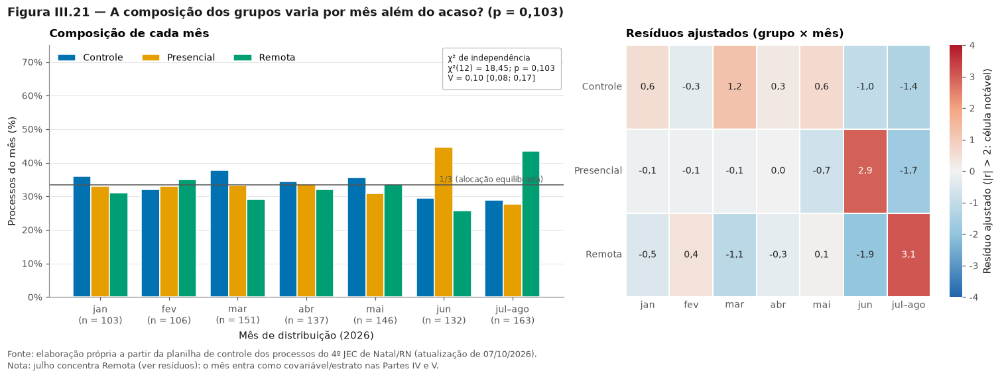

In [90]:
mes = t3['mes_distribuicao'].astype(str).replace({'jul': 'jul–ago', 'ago': 'jul–ago'})
ordem_mes = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul–ago']
t3['mes7'] = pd.Categorical(mes, categories=ordem_mes, ordered=True)
tab_mes = pd.crosstab(t3['mes7'], t3['grupo'])
c2_mes, p_mes, gl_mes, e_mes = stats.chi2_contingency(tab_mes, correction=False)
v_mes, vm_lo, vm_hi = tst_cramer_ic(t3['mes7'], t3['grupo'])
tabela(tst_tab(tab_mes.assign(Total=tab_mes.sum(axis=1)), 'Mês de distribuição'), 'tst_grupo_mes',
       'Processos por mês de distribuição e grupo', secao='3.5.3', nota='agosto (6 processos, até 03/08) foi unido a julho.')
print(f'Esperada mín. = {fmt_br(e_mes.min(), 1)} | χ²({gl_mes}) = {fmt_br(c2_mes, 2)}, p {tst_eq(p_mes)} | V = {tst_ic_txt(v_mes, vm_lo, vm_hi, 3)}')
res_mes = tst_residuos(tab_mes)
tabela(tst_tab(res_mes, 'Mês de distribuição'), 'tst_grupo_mes_res', 'Resíduos ajustados: grupo × mês de distribuição',
       secao='3.5.3', gradiente={'mapa': DIV, 'vmin': -4, 'vmax': 4, 'colunas': ORDEM_GRUPO})
tst_registra('3.5', 'H11 grupo × mês', 'χ² grupo × mês de distribuição', 'independência', f'χ²({gl_mes}) = {fmt_br(c2_mes, 2)}', p_mes,
             f'V = {tst_ic_txt(v_mes, vm_lo, vm_hi, 3)}')

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1.35, 1]})
perc = 100 * tab_mes.div(tab_mes.sum(axis=1), axis=0)
perc.index = [f'{m}\n(n = {int(tab_mes.loc[m].sum())})' for m in perc.index]
barras_agrupadas(ax[0], perc[ORDEM_GRUPO], cores=CORES_GRUPO, ylabel='Processos do mês (%)', xlabel=ROTULOS['mes_distribuicao'])
ax[0].set_ylim(0, 75); eixo_pct(ax[0], escala=1)
ax[0].axhline(100 / 3, color=TINTA_2, lw=1)
ax[0].annotate('1/3 (alocação equilibrada)', (6.45, 100 / 3), xytext=(0, 3), textcoords='offset points', ha='right',
               fontsize=8, color=TINTA_2)
ax[0].legend(loc='upper left', ncol=3)
ax[0].set_title('Composição de cada mês')
anotar_teste(ax[0], texto_teste('χ² de independência', f'χ²({gl_mes}) = {fmt_br(c2_mes, 2)}', p_mes,
                                f'V = {tst_ic_txt(v_mes, vm_lo, vm_hi, 2)}'), loc='upper right', tamanho=8)
tst_heatmap_res(ax[1], res_mes.T, limite=4, titulo='Resíduos ajustados (grupo × mês)')
figura(fig, 'tst_grupo_mes', f'A composição dos grupos varia por mês além do acaso? (p {tst_eq(p_mes)})', secao='3.5.3',
       nota='julho concentra Remota (ver resíduos): o mês entra como covariável/estrato nas Partes IV e V.')

**Leitura. O sorteio parece aleatório, a vara ficou mais lenta ao longo do ano e a correlação "ingênua" entre a ordem de chegada e o tempo é dominada pela censura.**

- **Aleatoriedade do sorteio (H9).**
  - **Número de corridas:** foram observadas R = 626 corridas, contra 626,3 esperadas sob H₀ (DP de permutação de 14,3; p = 1,000). Não há nem agrupamento nem rodízio regular.
  - **Maior corrida:** tem 8 processos seguidos, comprimento comum sob o acaso (P ≥ 8 = 0,239).
  - **Por grupo:** z = 0,43, 0,75 e −1,24, todos não significativos.

  A sequência é **compatível com sorteio aleatório**, o que reforça a classificação como ECA (questão 2.2). O teste não prova o mecanismo: uma lista pseudoaleatória bem feita e um sorteio físico dariam o mesmo resultado, e a ocultação da alocação continua sem documentação.
- **Composição mensal (H11).** χ²(12) = 18,45, p = 0,103, V = 0,10. No conjunto, o desequilíbrio não excede o acaso, mas os resíduos mostram dois meses atípicos: **junho**, com excesso de Presencial (+2,95), e **julho-agosto**, com excesso de Remota (+3,10; 71 de 163 processos). Como julho é o mês com menos seguimento e mais ativos, a Remota recebe uma parcela maior de processos com pouco seguimento. Por isso o mês entra como estrato e covariável (seção 3.6 e Partes IV e V).
- **Ordem de chegada × tempo (H10, questão 2.7):**
  - **todos (938), censura ignorada:** ρ = −0,04 (p = 0,211), τ = −0,05 (p = 0,024). Spearman e Kendall discordam quanto à significância, um sinal de que a associação é fraca e frágil;
  - **só sentenciados:** ρ = −0,12 (p = 0,002). Este é o "achado" que uma análise ingênua reportaria: "os processos mais recentes são mais rápidos";
  - **janela comum de 65 dias**, sem censura: ρ = **+0,14** (p < 0,001; τ = +0,11). **O sinal se inverte**: os processos que chegaram depois demoram **mais**. A proporção sentenciada até o 65º dia cai de 46% (janeiro) para 21% (julho), o que é compatível com acúmulo de acervo ao longo do experimento (cada processo dos braços com AC exige uma pauta de audiência) ou com sazonalidade de pauta.
- **A simulação explica a inversão.** Em 500 réplicas, os tempos foram gerados **sem nenhuma relação** com a ordem e censurados com o acompanhamento real de cada processo. Sob essa H₀:
  - **só encerrados:** ρ médio = −0,28 (faixa de 95%: −0,34 a −0,21);
  - **todos, com a censura ignorada:** ρ médio = −0,19;
  - **janela de 65 dias:** ρ médio = 0,00.

  A censura sozinha "fabrica" uma correlação negativa forte. Os ρ observados (−0,12 e −0,04) ficam **acima** dessa faixa, ou seja, a associação verdadeira é positiva e parcialmente mascarada pela censura. A magnitude do artefato depende da distribuição simulada (Weibull de forma 1,6), mas o sinal não depende.
- **Resposta à questão 2.7.** Sim, é possível investigar a correlação entre a ordem de chegada e o tempo, com Spearman ou Kendall (a ordem é ordinal; nunca Pearson), **desde que** a censura seja tratada: janela comum de seguimento, como aqui, ou a ordem/data como covariável num modelo de Cox (Parte IV). Sem esse cuidado, a correlação mede o calendário de distribuição e não o ritmo da vara.

---

## 3.6 Os testes do notebook do professor × as decisões deste notebook (questão 2.11)

### 3.6.1 Reprodução dos testes problemáticos

Para que a comparação seja concreta, os testes do notebook do professor que dependem da base são reproduzidos na base primária (938). Os números diferem um pouco dos originais (944 linhas, com duplicatas, linha vazia e "Decisão" como sentença), mas a conclusão de cada um é a mesma. **Esses testes não entram no registro da seção 3.7**: são exibidos para crítica, não como achados.

Teste reproduzido,p
χ² grupo × status (E19),"< 0,001"
χ² grupo × acordo na AC com Controle (E20),"0,013"
χ² sentença (com Decisão) × grupo (E21),"< 0,001"
Mann-Whitney Encerrado × Ativo (E18),"< 0,001"
"z de proporção p0 = 0,5 (E23)","< 0,001"
"Mann-Whitney com × sem acordo na AC, todos (E24)","0,448"
"Kruskal-Wallis todos, censura ignorada (E17)","0,559"


Esperadas da coluna "acordo na AC" no χ² com o Controle (E20): ['5,7', '5,7', '5,6']
Encerrados: 732/938 = 78,0% (z = 17,2)


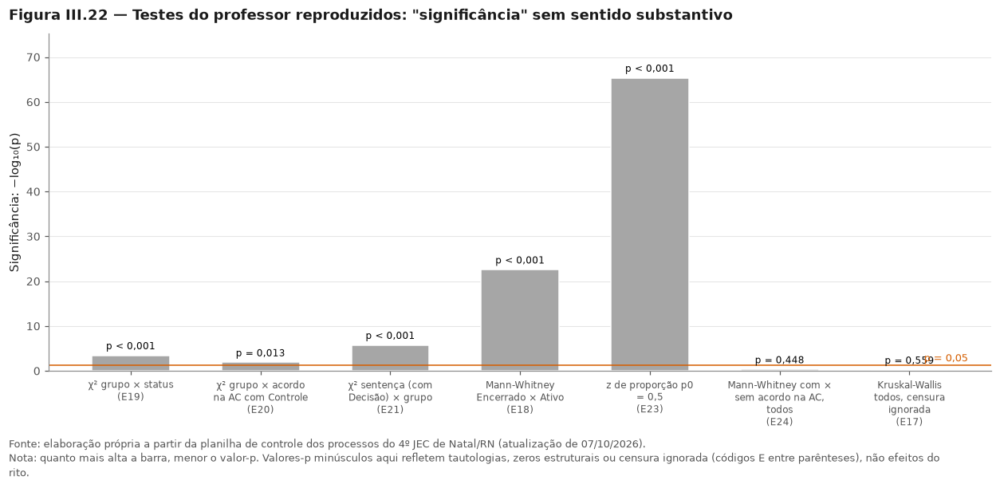

In [91]:
rep = {}
tab = pd.crosstab(t3['grupo'], t3['encerrado'].astype(bool)); rep['χ² grupo × status (E19)'] = stats.chi2_contingency(tab, correction=False)[1]
tab = pd.crosstab(t3['grupo'], t3['acordo_ac'].fillna(False).astype(bool)); rep['χ² grupo × acordo na AC com Controle (E20)'] = stats.chi2_contingency(tab, correction=False)[1]
e20 = stats.chi2_contingency(tab, correction=False)[3]
enc_all = t3[t3['encerrado'].astype(bool)]
tab = pd.crosstab(enc_all['tipo_desfecho'].cat.remove_unused_categories(), enc_all['grupo']); rep['χ² sentença (com Decisão) × grupo (E21)'] = stats.chi2_contingency(tab, correction=False)[1]
ativos = t3.loc[t3['tipo_desfecho'] == 'Ativo', 'tempo_f']; encs = enc_all['tempo_f']
rep['Mann-Whitney Encerrado × Ativo (E18)'] = stats.mannwhitneyu(encs, ativos)[1]
x_enc = int(t3['encerrado'].sum())
z = (x_enc / len(t3) - 0.5) / np.sqrt(0.25 / len(t3)); rep['z de proporção p0 = 0,5 (E23)'] = 2 * stats.norm.sf(abs(z))
com_all = t3.loc[t3['acordo_ac'] == True, 'tempo_f']; sem_all = t3.loc[t3['acordo_ac'] != True, 'tempo_f']
rep['Mann-Whitney com × sem acordo na AC, todos (E24)'] = stats.mannwhitneyu(com_all, sem_all)[1]
rep['Kruskal-Wallis todos, censura ignorada (E17)'] = versoes['1. Professor: todos, censura ignorada'][1]
t3_rep = pd.DataFrame({'Teste reproduzido': rep.keys(), 'p': rep.values()})
tst_tabela_p(t3_rep, 'tst_professor', 'Testes do notebook do professor reproduzidos na base primária (crítica, não achados)',
             '3.6.1', destaque=None)
print('Esperadas da coluna "acordo na AC" no χ² com o Controle (E20):', [fmt_br(v, 1) for v in e20[:, 1]])
print(f'Encerrados: {x_enc}/{len(t3)} = {pct_br(x_enc / len(t3))} (z = {fmt_br(z, 1)})')

fig, ax = plt.subplots(figsize=(11.5, 4.8))
lp = -np.log10(np.clip(t3_rep['p'].to_numpy(dtype=float), 1e-300, 1))
rot = [t.replace(' (E', '\n(E') for t in t3_rep['Teste reproduzido']]
barras_verticais(ax, rot, lp, cores=CINZA, rotular=False, quebrar=18, ylabel='Significância: −log₁₀(p)', ymax=lp.max() * 1.15)
for i, (v, p_) in enumerate(zip(lp, t3_rep['p'])):
    ax.annotate(f'p {tst_eq(p_)}', (i, v), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8)
ax.axhline(-np.log10(0.05), color=DESTAQUE, lw=1)
ax.annotate('p = 0,05', (len(lp) - 0.55, -np.log10(0.05)), xytext=(0, 3), textcoords='offset points', ha='right',
            fontsize=8.5, color=DESTAQUE)
ax.tick_params(axis='x', labelsize=8)
figura(fig, 'tst_professor', 'Testes do professor reproduzidos: "significância" sem sentido substantivo', secao='3.6.1',
       nota='quanto mais alta a barra, menor o valor-p. Valores-p minúsculos aqui refletem tautologias, zeros estruturais ou '
            'censura ignorada (códigos E entre parênteses), não efeitos do rito.')

### 3.6.2 Quadro de decisão

| Cél. | Teste do professor | Resultado original | Problema (código) | Decisão aqui | Onde |
|---|---|---|---|---|---|
| 28 | Kruskal-Wallis da duração × grupo, todos | H = 1,48; p = 0,478 | censurados como completos; "Decisão" como sentença; H₀ como "medianas" (E14, E17) | **Substituído** por log-rank/Cox; KW só condicional aos sentenciados ou em min(T, 65) | 3.4; Parte IV |
| 28 | Mann-Whitney post-hoc sem correção | (não executado: p > 0,05) | sem ajuste de multiplicidade (E17, E27) | **Substituído** por Dunn com Holm; MW com delta de Cliff | 3.4 |
| 29 | Mann-Whitney Encerrado × Ativo | p = 3,2 × 10⁻²⁴ | tautológico (E18) | **Removido** | 3.1 |
| 32 | χ² grupo × status | p = 0,00015 | status depende do mês de entrada (E19) | **Substituído** pela situação no 65º dia e por KM | 3.2.5; Parte IV |
| 33 | χ² grupo × acordo na AC | p = 0,0074 | zero estrutural no Controle; esperadas ~5 (E20) | **Substituído** por Fisher Presencial × Remota entre AC realizadas | 3.3.1 |
| 34 | χ² tipo de sentença × grupo | p = 2,0 × 10⁻⁶ | inclui Decisão; sem resíduos nem V; % no sentido errado (E21) | **Adequado na ideia, refeito**: sem Decisão, resíduos, V com IC, pares com Holm | 3.2 |
| 37–38 | Matriz de Spearman das 4 durações; OLS das dispersões | r = 1; R² = 1 | mesma variável (E6, E16) | **Removido**; Spearman/Kendall ordem × tempo com controle da censura | 3.5.2 |
| 40 | Shapiro-Wilk e D'Agostino (subamostra de 500) | p = 2,6 × 10⁻⁸ / 0,213 | subamostra arbitrária, variável censurada, decisão *a posteriori* (E22) | **Refeito** por grupo na Parte II; aqui, nos resíduos da ANOVA didática | Parte II; 3.4.4 |
| 42 | z de proporção (p₀ = 0,5) | z = 17,1 | hipótese sem sentido (E23) | **Removido** | 3.1 |
| 42 | Mann-Whitney com × sem acordo na AC | p = 0,456 | "sem acordo" inclui o Controle e os ativos (E24) | **Refeito** entre AC realizadas e sentenciadas (condicional); correto: riscos competitivos | 3.4.6; Parte IV |
| 44 | Ajuste MLE de distribuições | Weibull melhor AIC | censura ignorada; `loc` livre; zeros descartados (E25) | **Substituído** por ajuste com censura | Partes II e IV |
| 46 | OLS duração ~ grupo; Logit evento ~ grupo | p = 0,588; p < 0,001 | censura; evento depende do seguimento (E26) | **Substituído** por Cox/AFT e logit em horizonte fixo | Partes IV e V |
| 48 | KM + log-rank | não executou | import errado (E1) | **Feito** | Parte IV |
| — | correção de multiplicidade, tamanhos de efeito | ausentes | E27 | **Holm/BH**, V, OR, ε², delta de Cliff, ρ, τ | 3.7 |

### 3.6.3 Outros testes que poderiam ser aplicados (Siegel e Castellan, 2006; Barbetta et al., 2020; Becker, 2015)

| Teste | Para quê, neste caso | Situação |
|---|---|---|
| **Cochran-Mantel-Haenszel** (+ Breslow-Day) | acordo × grupo ajustado pelo mês (estratos) | **implementado abaixo** |
| **Permutação / Monte Carlo** | tabelas esparsas (técnica, redistribuição), sequência do sorteio | implementado (3.2.4, 3.3, 3.5.1) |
| **Exato de Fisher / Fisher-Freeman-Halton** | acordo na AC (17 eventos) | implementado (3.3) |
| **Jonckheere-Terpstra** | tendência ordenada do tempo (condicional) ao longo dos **meses** | possível; não se aplica ao grupo (nominal) |
| **Cochran-Armitage** | tendência da proporção de acordo/sem mérito ao longo dos meses (curva de aprendizado do rito) | possível, mas exige horizonte fixo por causa do seguimento decrescente |
| **Kolmogorov-Smirnov para 2 amostras** | diferença de forma (não só de posição) das distribuições do tempo | possível; mesmo problema de censura |
| **Brunner-Munzel** | alternativa ao Mann-Whitney sem supor formas iguais | possível |
| **Log-rank, Wilcoxon-Gehan, Peto, Fleming-Harrington; Gray** | tempos censurados; riscos competitivos | Parte IV |
| **McNemar, Wilcoxon pareado, Friedman, Cochran Q** | amostras dependentes | **não se aplicam** (grupos independentes, questão 2.3) |

### 3.6.4 Cochran-Mantel-Haenszel: acordo × grupo estratificado por mês (H12)

O mês de distribuição está associado à composição dos grupos (3.5.3) e ao acompanhamento. O CMH combina as tabelas 2 × 2 de cada mês num **OR comum** de Mantel-Haenszel e testa **H₀: OR comum = 1**; o teste de **Breslow-Day** (Tarone) verifica se o OR é homogêneo entre os meses. O desfecho é o acordo homologado entre os processos com o registro de acordo (733); cada braço com AC é comparado ao Controle. O gráfico mostra o OR de cada mês (com correção de Haldane, +0,5, só para desenhar meses com zero) e o OR combinado.

Comparação,OR bruto,p bruto (Fisher),OR MH,OR MH IC,CMH χ²,p,Breslow-Day p,p Holm
Presencial × Controle,"1,36","0,355","1,34","0,73 a 2,47","0,87","0,351","0,405","0,351"
Remota × Controle,"2,15","0,010","2,17","1,22 a 3,86","7,23","0,007","0,385","0,014"


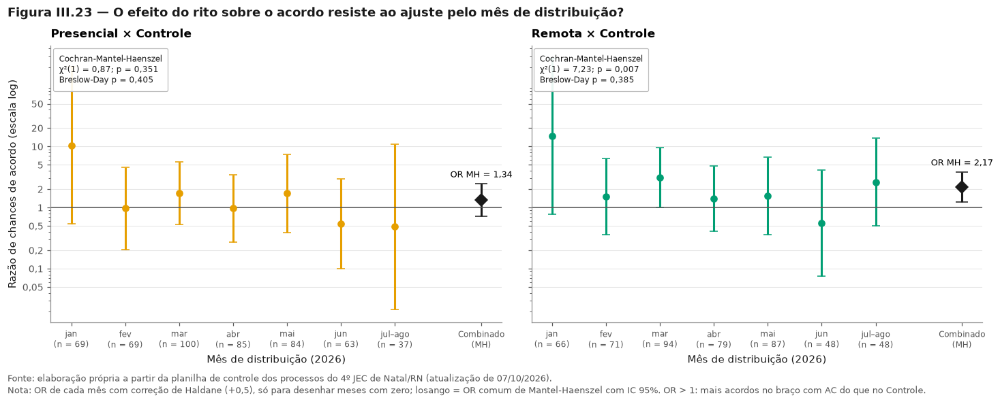

In [92]:
base_cmh = t3[t3['acordo'].notna()].copy()
linhas, forest = [], {}
for g in ['Presencial', 'Remota']:
    sub = base_cmh[base_cmh['grupo'].isin([g, 'Controle'])]
    tabelas, ors = [], []
    for m in ordem_mes:
        sm_ = sub[sub['mes7'] == m]
        t = np.array([[((sm_['grupo'] == g) & sm_['acordo'].astype(bool)).sum(), ((sm_['grupo'] == g) & ~sm_['acordo'].astype(bool)).sum()],
                      [((sm_['grupo'] == 'Controle') & sm_['acordo'].astype(bool)).sum(), ((sm_['grupo'] == 'Controle') & ~sm_['acordo'].astype(bool)).sum()]])
        tabelas.append(t)
        a, b, c, d = t.ravel() + 0.5
        lor, se = np.log(a * d / (b * c)), np.sqrt(1 / a + 1 / b + 1 / c + 1 / d)
        ors.append((m, np.exp(lor), np.exp(lor - 1.96 * se), np.exp(lor + 1.96 * se), int(t.sum())))
    st = StratifiedTable(tabelas)
    teste = st.test_null_odds(correction=False)
    bd = st.test_equal_odds(adjust=True)
    lo, hi = st.oddsratio_pooled_confint()
    bruto = np.sum(tabelas, axis=0)
    p_bruto, or_bruto, _, _, _ = tst_fisher(bruto)
    linhas.append({'Comparação': f'{g} × Controle', 'OR bruto': or_bruto, 'p bruto (Fisher)': p_bruto,
                   'OR MH': st.oddsratio_pooled, 'OR MH IC': f'{fmt_br(lo, 2)} a {fmt_br(hi, 2)}',
                   'CMH χ²': teste.statistic, 'p': teste.pvalue, 'Breslow-Day p': bd.pvalue})
    forest[g] = (ors, st.oddsratio_pooled, lo, hi)
t3_cmh = pd.DataFrame(linhas); t3_cmh['p Holm'] = tst_holm(t3_cmh['p'])
tst_tabela_p(t3_cmh, 'tst_cmh', 'Cochran-Mantel-Haenszel: acordo × grupo estratificado pelo mês de distribuição', '3.6.4', casas=2,
             colunas_p=('p', 'p Holm', 'p bruto (Fisher)', 'Breslow-Day p'),
             nota='OR MH = razão de chances comum de Mantel-Haenszel; Breslow-Day (Tarone) testa a homogeneidade do OR entre os meses.')
for _, r in t3_cmh.iterrows():
    tst_registra('3.6', 'H12 CMH', f'CMH acordo × grupo por mês: {r["Comparação"]}', 'OR comum = 1', f'χ²(1) = {fmt_br(r["CMH χ²"], 2)}',
                 r['p'], f'OR MH = {fmt_br(r["OR MH"], 2)} [{r["OR MH IC"].replace(" a ", "; ")}]')

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.8), sharey=True)
for k, g in enumerate(['Presencial', 'Remota']):
    ors, orp, lo, hi = forest[g]
    for i, (m, o, l, h, nn) in enumerate(ors):
        ax[k].errorbar(i, o, yerr=[[o - l], [h - o]], fmt='o', color=CORES_GRUPO[g], capsize=4, ms=6)
    ax[k].errorbar(len(ors) + 0.6, orp, yerr=[[orp - lo], [hi - orp]], fmt='D', color=TINTA, capsize=6, ms=8)
    ax[k].annotate(f'OR MH = {fmt_br(orp, 2)}', (len(ors) + 0.6, hi), xytext=(0, 4), textcoords='offset points',
                   ha='center', va='bottom', fontsize=8.5)
    ax[k].axhline(1, color=TINTA_2, lw=1)
    ax[k].set_yscale('log')
    ax[k].yaxis.set_major_locator(mpl.ticker.FixedLocator([0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50]))
    ax[k].yaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_br(v, 2 if v < 0.1 else (1 if v < 1 else 0))))
    ax[k].yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax[k].set_xticks(list(range(len(ors))) + [len(ors) + 0.6],
                     [f'{o[0]}\n(n = {o[4]})' for o in ors] + ['Combinado\n(MH)'], fontsize=8)
    ax[k].set_xlabel(ROTULOS['mes_distribuicao'])
    ax[k].grid(axis='x', visible=False)
    ax[k].set_title(f'{g} × Controle')
    r = t3_cmh.loc[k]
    anotar_teste(ax[k], texto_teste('Cochran-Mantel-Haenszel', f'χ²(1) = {fmt_br(r["CMH χ²"], 2)}', r['p'],
                                    f'Breslow-Day p {tst_eq(r["Breslow-Day p"])}'), loc='upper left', tamanho=8)
ax[0].set_ylabel('Razão de chances de acordo (escala log)')
figura(fig, 'tst_cmh', 'O efeito do rito sobre o acordo resiste ao ajuste pelo mês de distribuição?', secao='3.6.4',
       nota='OR de cada mês com correção de Haldane (+0,5), só para desenhar meses com zero; losango = OR comum de Mantel-Haenszel '
            'com IC 95%. OR > 1: mais acordos no braço com AC do que no Controle.')

**Leitura (questão 2.11).**

- **Os testes reproduzidos dão valores-p "fortes" justamente onde a hipótese é vazia:**
  - **Encerrado × Ativo:** p < 0,001, e é tautológico;
  - **z com p₀ = 0,5:** z = 17,2, e 78,0% de encerrados não é comparável a nada;
  - **grupo × status:** p < 0,001, mas o status depende do mês de entrada;
  - **grupo × acordo na AC com o Controle:** p = 0,013. O "efeito" é o zero estrutural do Controle, e as esperadas da coluna "acordo" são 5,6 a 5,7, no limite de Cochran.
- **Testes sobre perguntas reais têm valores-p fracos e precisam de método adequado.** É o caso do KW (p = 0,559) e do Mann-Whitney com × sem acordo (p = 0,448). A significância estatística do notebook do professor está, portanto, **invertida em relação à relevância substantiva**.
- **Dos 14 testes do notebook:**
  - **um é adequado na ideia:** χ² tipo de sentença × grupo, refeito aqui sem a "Decisão", com resíduos e V;
  - **quatro devem ser removidos:** Encerrado × Ativo, z com p₀ = 0,5, matriz de correlação e dispersões tautológicas;
  - **os demais devem ser substituídos** por métodos que respeitem a censura (Parte IV), o zero estrutural (Fisher entre os braços com AC) ou a multiplicidade (Dunn/Holm).
- **CMH estratificado por mês (H12).** O acordo foi comparado entre os processos com o registro de acordo (733).
  - **Remota × Controle:** OR bruto = 2,15 e OR de Mantel-Haenszel = **2,17 (IC 95% 1,22 a 3,86)**, χ²(1) = 7,23, p = 0,007 (p Holm = 0,014 na família). Breslow-Day p = 0,385: o OR é homogêneo entre os meses.
  - **Presencial × Controle:** OR MH = 1,34 (0,73 a 2,47), p = 0,351.
  - **Leitura.** O ajuste pelo mês **não altera** a razão de chances. A concentração de Remota em julho não explica o seu excedente de acordos, ou seja, o mês não confunde essa associação. A ressalva continua: a base é condicional a ter o acordo registrado (encerrados), e o desfecho correto é a incidência acumulada do acordo (Parte IV).
- **Outros testes aplicáveis.** CMH, permutação e exatos foram implementados aqui. Jonckheere-Terpstra e Cochran-Armitage servem para hipóteses de **tendência no mês** (por exemplo, a queda da proporção sentenciada até 65 dias, de 46% para 21%), não para o grupo, que é nominal. Brunner-Munzel e Kolmogorov-Smirnov ampliariam a comparação de distribuições, mas herdam o problema da censura. Testes pareados não se aplicam (questão 2.3).

---

## 3.7 Multiplicidade: todos os valores-p da Parte III

Cada família já foi corrigida por Holm nas seções anteriores. Aqui, **todos** os testes registrados são reunidos e corrigidos de uma vez:

- **Holm global** controla a probabilidade de ao menos um falso positivo entre todos os testes da parte (FWER), o critério mais exigente;
- **Benjamini-Hochberg** controla a proporção esperada de falsos positivos entre os testes declarados significativos (FDR), o critério usual em análises exploratórias com muitos testes.

Uma conclusão que sobrevive ao Holm global não depende da quantidade de testes feitos. Leitura do gráfico: cada barra é um teste; a altura é −log₁₀ do p ajustado (barras acima da linha tracejada são significativas a 5% após a correção).

55 testes registrados | significativos: brutos 19, Holm global 13, BH 17


Seção,Família,Teste,H0,Estatística,p,Efeito (IC 95%),p Holm global,p BH (FDR),"Holm < 0,05","BH < 0,05"
3.2,H1 tipo × grupo,χ² tipo de sentença × grupo (sentenciados),independência,"χ²(4) = 34,34","< 0,001","V = 0,156 [0,114; 0,212]","< 0,001","< 0,001",sim,sim
3.2,H1 pares,χ² 2×3 Presencial × Controle,mesma distribuição de tipos,"χ²(2) = 20,02","< 0,001","V = 0,202","0,002","< 0,001",sim,sim
3.2,H1 pares,χ² 2×3 Remota × Controle,mesma distribuição de tipos,"χ²(2) = 26,83","< 0,001","V = 0,237","< 0,001","< 0,001",sim,sim
3.2,H1 pares,χ² 2×3 Presencial × Remota,mesma distribuição de tipos,"χ²(2) = 2,76","0,252","V = 0,079","1,000","0,420",,
3.2,H2 tipos binários,χ² 3×2 Sem mérito × grupo,proporção igual nos 3 grupos,"χ²(2) = 18,31","< 0,001","V = 0,161","0,005","< 0,001",sim,sim
3.2,H2 tipos binários,χ² 3×2 Mérito × grupo,proporção igual nos 3 grupos,"χ²(2) = 31,61","< 0,001","V = 0,211","< 0,001","< 0,001",sim,sim
3.2,H2 tipos binários,χ² 3×2 Homologação × grupo,proporção igual nos 3 grupos,"χ²(2) = 7,94","0,019","V = 0,106","0,697","0,055",,
3.2,H2 pares (Fisher),Fisher Sem mérito: Presencial × Controle,OR = 1,"OR = 2,09","< 0,001","dif. = 17,2 [8,6; 25,5] p.p.","0,004","< 0,001",sim,sim
3.2,H2 pares (Fisher),Fisher Sem mérito: Remota × Controle,OR = 1,"OR = 1,92","< 0,001","dif. = 15,2 [6,5; 23,7] p.p.","0,036","0,004",sim,sim
3.2,H2 pares (Fisher),Fisher Sem mérito: Presencial × Remota,OR = 1,"OR = 1,08","0,704","dif. = 2,0 [-7,2; 11,2] p.p.","1,000","0,824",,


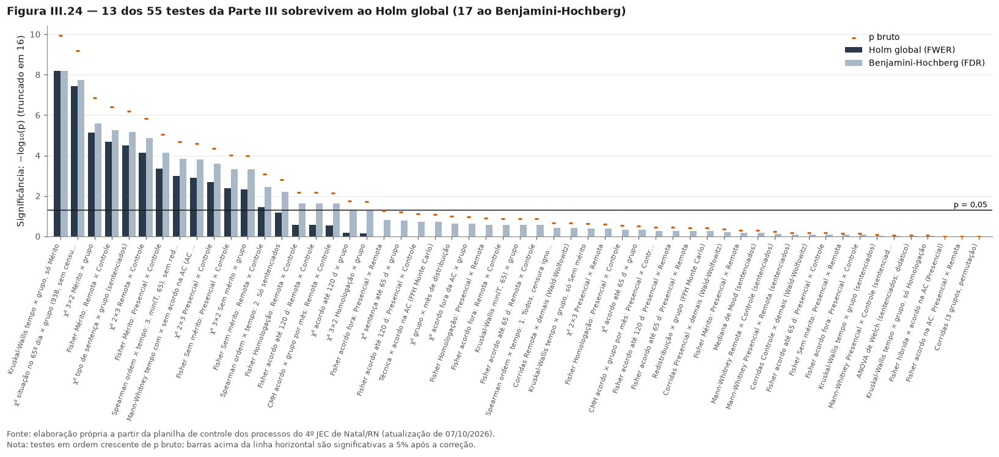

In [93]:
t3_reg = pd.DataFrame(TST_REGISTRO)
t3_reg['p Holm global'] = multipletests(t3_reg['p'], method='holm')[1]
t3_reg['p BH (FDR)'] = multipletests(t3_reg['p'], method='fdr_bh')[1]
t3_reg['Holm < 0,05'] = np.where(t3_reg['p Holm global'] < 0.05, 'sim', '')
t3_reg['BH < 0,05'] = np.where(t3_reg['p BH (FDR)'] < 0.05, 'sim', '')
n_holm, n_bh = int((t3_reg['p Holm global'] < 0.05).sum()), int((t3_reg['p BH (FDR)'] < 0.05).sum())
print(f'{len(t3_reg)} testes registrados | significativos: brutos {int((t3_reg["p"] < 0.05).sum())}, '
      f'Holm global {n_holm}, BH {n_bh}')
tst_tabela_p(t3_reg, 'tst_registro', 'Todos os testes da Parte III: valores-p brutos, Holm global (FWER) e Benjamini-Hochberg (FDR)',
             '3.7', colunas_p=('p', 'p Holm global', 'p BH (FDR)'), destaque='p Holm global',
             nota='linhas destacadas: significativas a 5% após o Holm global.')
t3_reg.to_csv(PROC / 'ed2_parte3_testes.csv', sep=';', decimal=',', index=False, encoding='utf-8-sig')

ordem_plot = t3_reg.sort_values('p').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(15, 6.2))
xx = np.arange(len(ordem_plot)); w = 0.4
lp = lambda s: -np.log10(np.clip(s, 1e-16, 1))
ax.bar(xx - w / 2, lp(ordem_plot['p Holm global']), w, color='#2B3A4A', label='Holm global (FWER)')
ax.bar(xx + w / 2, lp(ordem_plot['p BH (FDR)']), w, color='#A9B8C6', label='Benjamini-Hochberg (FDR)')
ax.scatter(xx, lp(ordem_plot['p']), color=DESTAQUE, s=14, zorder=3, label='p bruto', marker='_', lw=2)
ax.axhline(-np.log10(0.05), color=TINTA, lw=1)
ax.annotate('p = 0,05', (len(xx) - 0.5, -np.log10(0.05)), xytext=(0, 3), textcoords='offset points', ha='right', fontsize=8.5)
ax.set_xticks(xx, [t if len(t) <= 48 else t[:46] + '…' for t in ordem_plot['Teste']], rotation=70, ha='right', fontsize=7)
ax.set_xlim(-0.8, len(xx) - 0.2)
ax.grid(axis='x', visible=False)
ax.set_ylabel('Significância: −log₁₀(p) (truncado em 16)')
ax.legend(loc='upper right')
figura(fig, 'tst_multiplicidade', f'{n_holm} dos {len(t3_reg)} testes da Parte III sobrevivem ao Holm global ({n_bh} ao Benjamini-Hochberg)',
       secao='3.7', nota='testes em ordem crescente de p bruto; barras acima da linha horizontal são significativas a 5% após a correção.')

**Leitura. O que sobrevive a qualquer critério.**

- **Volume de testes.** A parte registrou **55 testes**. São significativos a 5%: **19** sem correção, **17** com Benjamini-Hochberg (FDR) e **13** com Holm global (FWER).
- **Sobrevivem ao Holm global, que é o critério mais exigente:**
  - **H1/H2 (tipo de desfecho).** Associação tipo × grupo (sentenciados e janela de 65 dias); pares Presencial × Controle e Remota × Controle; mais sem mérito e menos mérito nos dois braços com AC. **É o achado mais robusto da Parte III.**
  - **H8 por tipo.** Julgamentos de mérito mais lentos nos braços com AC (KW no estrato mérito).
  - **H10.** Correlação positiva entre ordem de chegada e tempo na janela sem censura (ρ = +0,14): a vara ficou mais lenta ao longo do ano.
  - **E24 refeito.** O acordo na AC encerra o processo mais cedo, o que é em boa parte definicional.
- **Sobrevivem só ao BH (FDR), como evidência sugestiva a confirmar:**
  - mais **acordo** na Remota que no Controle: homologação entre sentenciados, acordo até 120 dias e CMH por mês, com OR entre 2,2 e 2,7 de forma consistente;
  - a correlação negativa ordem × tempo entre os sentenciados, que é o artefato da censura (seção 3.5.2) e, por isso, não deve ser lida como achado.
- **Não rejeitados, com IC que informa o tamanho máximo plausível:**
  - acordo na AC presencial × remota: diferença de +0,5 p.p. (IC −4,4 a +5,3);
  - técnica e híbrida: sem poder;
  - redistribuição;
  - aleatoriedade do sorteio, compatível com H₀;
  - tempo agregado entre os sentenciados: delta de Cliff ≈ 0, um paradoxo de composição.
- **Leitura para a questão 2.11.** Sem correção de multiplicidade e sem tamanho de efeito (E27), o notebook do professor não tinha como separar esses três níveis de evidência. Com 55 testes a 5%, cerca de três "significâncias" seriam esperadas só pelo acaso. Por isso, o achado de acordo da Remota, isolado, não autorizaria uma recomendação de política judiciária. Já a troca de mérito por extinção sem mérito autoriza.

---

# PARTE IV — ANÁLISE DE SOBREVIVÊNCIA

Esta é a parte central do estudo. A pergunta de pesquisa 2 — *a audiência de conciliação (AC) obrigatória, presencial ou remota, altera o tempo até a sentença em relação ao rito atual?* — é uma pergunta sobre **tempo até um evento** observado de forma incompleta: em 07/10/2026, 206 processos ainda não tinham sentença. A análise de sobrevivência é o conjunto de métodos construído exatamente para esse tipo de dado (COLOSIMO; GIOLO, 2006, cap. 1; MORETTIN; SINGER, 2021, cap. 7). O notebook do professor anunciava o Kaplan-Meier como "imprescindível", mas ele nunca era executado por um erro de importação (E1), e todas as comparações de tempo eram feitas com testes que ignoram a censura (E14, E17, E26).

**Roteiro.**

| Seção | Conteúdo | Pergunta respondida |
|---|---|---|
| 4.1 | Conceitos e estrutura dos dados | O que é censura aqui, e ela é "inofensiva"? |
| 4.2 | Kaplan-Meier, Nelson-Aalen, risco suavizado | Como evolui a proporção de processos ainda sem sentença? |
| 4.3 | Testes de comparação de curvas e RMST | As curvas dos três grupos diferem? Onde (no início, no fim)? |
| 4.4 | Diagnóstico de riscos proporcionais | Uma única razão de riscos resume a diferença? |
| 4.5 | Modelos de Cox | Qual o efeito do grupo, ajustado pelo calendário? Ele muda com o tempo? |
| 4.6 | Modelos paramétricos AFT | Em quanto a AC obrigatória alonga ou encurta o tempo (razão de tempos)? |
| 4.7 | Riscos competitivos | O rito muda **o tipo** de sentença (acordo, mérito, sem mérito)? |
| 4.8 | Subconjunto com AC realizada | Presencial × remota, técnica e híbrida entre quem teve audiência |
| 4.9 | Análises de sensibilidade | As conclusões resistem a decisões de curadoria? |
| 4.10 | Síntese | Resposta à pergunta de pesquisa |

**Convenção de sinal (vale para toda a Parte IV).** O "evento" é a **sentença**, que aqui é algo desejável: encerra o conflito. Por isso:

- S(t) = P(processo **ainda sem sentença** após t dias): curva mais alta = rito **mais lento**;
- razão de riscos (HR) > 1 = sentença **mais rápida** que no Controle; **HR < 1 = sentença mais lenta**;
- razão de tempos (AFT) > 1 = tempo **mais longo** que no Controle.

## 4.1 Conceitos e estrutura dos dados

### 4.1.1 Tempo, evento, censura e função de risco

**O par (T, δ).** Para cada processo i observa-se o tempo T_i = min(X_i, C_i), em dias desde a distribuição, e o indicador δ_i = 1 se X_i ≤ C_i (a sentença foi observada) ou δ_i = 0 caso contrário. X_i é o tempo até a sentença e C_i é o tempo até a censura (COLOSIMO; GIOLO, 2006, p. 6-12; MORETTIN; SINGER, 2021, p. 243-244). No dataset *tidy*, T é a coluna `tempo` e δ é a coluna `evento`.

**Censura à direita.** Sabe-se apenas que X_i > C_i: o processo ainda estava em curso na data de corte. Colosimo e Giolo (2006, p. 8-11) distinguem três mecanismos:

- **tipo I**: o estudo termina numa data fixa, e todos os não sentenciados são censurados nela;
- **tipo II**: o estudo termina quando se observa um número pré-fixado de eventos;
- **aleatória**: cada unidade tem o seu próprio tempo de censura, por exemplo porque **entrou no estudo em datas diferentes**.

Aqui a censura é **administrativa, do tipo I em calendário** (todos os ativos são censurados em 07/10/2026), mas como a distribuição se estendeu de 01/01 a 03/08/2026 (**entrada escalonada**), na escala do tempo de processo cada unidade tem um tempo potencial de censura diferente: C_i = 07/10/2026 − data de distribuição, de 65 a 279 dias (coluna `followup`). É o caso da figura 1.1 de Colosimo e Giolo (2006, p. 9): na escala do processo, a censura comporta-se como **aleatória**.

**Funções básicas** (COLOSIMO; GIOLO, 2006, p. 18-25):

- função de sobrevivência S(t) = P(X > t): proporção ainda sem sentença após t dias;
- função de risco (*hazard*) h(t) = lim P(t ≤ X < t + Δt | X ≥ t)/Δt: "taxa instantânea de sentenças" entre os processos que ainda estão pendentes no dia t. Não é uma probabilidade, e sim uma taxa por dia;
- risco acumulado Λ(t) = ∫₀ᵗ h(u) du, com S(t) = exp{−Λ(t)}.

**A hipótese de censura não informativa (independente).** Todos os estimadores e testes desta parte supõem que, condicionalmente às covariáveis, o fato de um processo estar censurado não informa sobre o seu tempo restante. Ela é **plausível para a censura administrativa** deste estudo: um processo está ativo em 07/10 porque foi distribuído tarde (data fixada pelo calendário) e não porque seja mais ou menos "difícil". Há duas ressalvas:

1. **Tendência de calendário.** O tempo potencial de censura depende do mês de distribuição. Se o ritmo da vara mudou ao longo de 2026 (férias, pauta de audiências, curva de aprendizado do novo rito), a censura fica associada ao prognóstico pelo calendário. A solução é **condicionar no mês** (estrato ou covariável), como fazem as seções 4.3.4 e 4.5.
2. **Redistribuição não é censura.** Os 24 processos "Decisão" foram remetidos a outro juízo e **nunca** terão sentença no 4º JEC: o evento passou a ser impossível, o que é bem diferente de "ainda não ocorreu". Isso é um **risco competitivo** (PUTTER; FIOCCO; GESKUS, 2007). Tratá-los como censura supõe que eles teriam o mesmo risco de sentença dos que ficaram, e o 1 − KM então superestima a probabilidade acumulada de sentença. Na análise principal (seções 4.2 a 4.6) a redistribuição é censurada em T (é o padrão da literatura para a pergunta "taxa de sentença enquanto o processo está no juízo"); a seção 4.7 a trata como risco competitivo e mostra que, com só 24 casos e quase todos em 0 a 8 dias, o viés é pequeno.

### 4.1.2 Preparação da base de sobrevivência

A célula abaixo cria as colunas numéricas que o `lifelines` e o `statsmodels` exigem (as colunas `Int64`/`boolean` da base *tidy* são convertidas para `float`/`int`) e as variáveis indicadoras do modelo:

- `Presencial`, `Remota`: indicadoras de grupo (referência = Controle);
- `mes`: mês de distribuição, com **agosto unido a julho** (agosto tem só 6 processos e seguimento de 65 dias; um estrato com 1 processo por grupo não teria informação);
- `origem_ext`: processo recebido de outro órgão (12 casos; A9).

Também são definidas funções auxiliares usadas em toda a Parte IV: um Kaplan-Meier/Aalen-Johansen vetorizado na grade de dias inteiros (para *bootstrap* e testes de permutação rápidos), a tabela de razões de risco e o gráfico de floresta. As figuras e tabelas usam a camada de visualização da seção 1.2 (`figura`, `tabela`, `plot_km`).

> **Nota técnica.** A função `lifelines.plotting.add_at_risk_counts` falha com o pandas 3.0.5 deste ambiente (`TypeError: only 0-dimensional arrays...`). A tabela de número em risco sob as curvas de Kaplan-Meier é, por isso, desenhada pela função `plot_km` da seção 1.2, que reproduz a mesma convenção do `lifelines` (em risco em t = processos com T ≥ t).

In [94]:
from lifelines import NelsonAalenFitter, CoxTimeVaryingFitter, WeibullAFTFitter, LogNormalAFTFitter, LogLogisticAFTFitter
from lifelines.statistics import survival_difference_at_fixed_point_in_time_test, proportional_hazard_test
from lifelines.utils import median_survival_times, restricted_mean_survival_time
from statsmodels.duration.survfunc import survdiff, CumIncidenceRight
from statsmodels.stats.multitest import multipletests
from statsmodels.nonparametric.smoothers_lowess import lowess
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')

MESES_SOB = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul-ago']
COLS_MES = ['mes_fev', 'mes_mar', 'mes_abr', 'mes_mai', 'mes_jun', 'mes_julago']
CAUSAS = {1: 'Homologação', 2: 'Mérito', 3: 'Sem mérito', 4: 'Redistribuição'}
ROTULO_TERMO = {'Presencial': 'AC presencial × Controle', 'Remota': 'AC remota × Controle',
                'origem_ext': 'Origem externa × 4º JEC',
                **{c: f'{m} × jan' for c, m in zip(COLS_MES, MESES_SOB[1:])}}
H_MAX = 280            # grade de dias inteiros 0..H_MAX (tempo máximo observado = 274)
TEMPOS_TAB = [0, 30, 60, 90, 120, 150, 180, 210, 240, 270]


def preparar_sob(df):
    """Base de sobrevivência com colunas numéricas e indicadoras (ver 4.1.2)."""
    s = df.copy()
    s['grupo'] = pd.Categorical(s['grupo'].astype(str), categories=ORDEM_GRUPO)
    s['T'] = s['tempo'].astype(float)
    s['T_pos'] = s['tempo_pos'].astype(float)
    s['E'] = s['evento'].astype(int)
    s['CR'] = s['evento_cr'].astype(int)
    s['K'] = s['causa'].astype(int)
    s['FU'] = s['followup'].astype(float)
    s['Presencial'] = (s['grupo'] == 'Presencial').astype(int)
    s['Remota'] = (s['grupo'] == 'Remota').astype(int)
    mes = s['mes_distribuicao'].astype(str).replace({'jul': 'jul-ago', 'ago': 'jul-ago'})
    s['mes'] = pd.Categorical(mes, categories=MESES_SOB)
    for c, m in zip(COLS_MES, MESES_SOB[1:]):
        s[c] = (s['mes'] == m).astype(int)
    s['mes_cod'] = s['mes'].cat.codes.astype(int)
    s['origem_ext'] = s['origem_externa'].astype(int)
    s['ordem'] = s['ordem_chegada'].astype(float)
    return s


sob = preparar_sob(dados)


# ---------------------------------------------------------------- estimadores vetorizados (grade diária)
def aj_grade(T, K, causas=(1,), H=H_MAX):
    """Kaplan-Meier global S(t) e incidências acumuladas de Aalen-Johansen F_k(t) em t = 0..H.
    T: tempos inteiros; K: código do desfecho (0 = censura). Com uma só causa (K = evento), 1 − S = F."""
    T = np.asarray(T, dtype=int)
    K = np.asarray(K, dtype=int)
    n_sai = np.bincount(T, minlength=H + 1)[:H + 1]
    risco = len(T) - np.concatenate([[0], np.cumsum(n_sai)[:-1]])          # n(t) = #{T >= t}
    d = {k: np.bincount(T[K == k], minlength=H + 1)[:H + 1] for k in causas}
    d_tot = np.sum([d[k] for k in causas], axis=0)
    with np.errstate(divide='ignore', invalid='ignore'):
        haz = np.where(risco > 0, d_tot / risco, 0.0)
        S = np.cumprod(1 - haz)
        S_ant = np.concatenate([[1.0], S[:-1]])
        cif = {k: np.cumsum(S_ant * np.where(risco > 0, d[k] / risco, 0.0)) for k in causas}
    return S, cif


def rmst_grade(T, E, tau):
    """RMST = ∫_0^tau S(t) dt para S em degraus nos dias inteiros."""
    S, _ = aj_grade(T, E)
    return S[:tau].sum()


def km_greenwood(T, E, t0):
    """Ŝ(t0) de Kaplan-Meier e erro-padrão de Greenwood (COLOSIMO; GIOLO, 2006, eq. 2.7)."""
    T = np.asarray(T, float); E = np.asarray(E, int)
    tempos = np.unique(T[(E == 1) & (T <= t0)])
    S, soma = 1.0, 0.0
    for t in tempos:
        n = (T >= t).sum(); d = ((T == t) & (E == 1)).sum()
        S *= 1 - d / n
        soma += d / (n * (n - d)) if n > d else 0.0
    return S, S * np.sqrt(soma)


def quantil_tempo(serie, p):
    """Primeiro t com S(t) <= p (inf se não atingido) — a convenção do lifelines."""
    abaixo = serie[serie <= p]
    return float(abaixo.index[0]) if len(abaixo) else np.inf


# ---------------------------------------------------------------- gráficos e tabelas
def tabela_hr(modelo, termos=None, rotulo='HR'):
    """Razões de risco (ou de tempos) com IC 95% e p-valor de Wald, a partir de um fitter do lifelines."""
    s = modelo.summary.copy()
    if isinstance(s.index, pd.MultiIndex):
        s = s.loc[s.index.get_level_values(0)[0]]
    if termos is not None:
        s = s.loc[[t for t in termos if t in s.index]]
    return pd.DataFrame({rotulo: s['exp(coef)'].values, 'IC 95% inf.': s['exp(coef) lower 95%'].values,
                         'IC 95% sup.': s['exp(coef) upper 95%'].values, 'p (Wald)': s['p'].values},
                        index=[ROTULO_TERMO.get(t, t) for t in s.index])


def floresta(ax, tab, rotulo='HR', cores=None, titulo='', col_p='p (Wald)', cor_de=None, xlabel=None, ticks=None,
             marcadores=None):
    """Gráfico de floresta (escala log) para uma tabela no formato de tabela_hr.

    Cada linha traz, à direita do IC, a estimativa (IC 95%) e o valor-p de Wald. `cor_de` = função nome -> cor
    (padrão: `cores[nome]`); `marcadores` = função nome -> marcador."""
    y = np.arange(len(tab))[::-1]
    for yi, (nome, r) in zip(y, tab.iterrows()):
        cor = cor_de(nome) if cor_de else (cores or {}).get(nome, TINTA)
        mk = marcadores(nome) if marcadores else 'o'
        ax.errorbar(r[rotulo], yi, xerr=[[r[rotulo] - r['IC 95% inf.']], [r['IC 95% sup.'] - r[rotulo]]],
                    fmt=mk, color=cor, capsize=3, ms=6)
        txt = f"{fmt_br(r[rotulo], 2)} [{fmt_br(r['IC 95% inf.'], 2)}; {fmt_br(r['IC 95% sup.'], 2)}]"
        if col_p and col_p in r.index:
            txt += f"; p {'< 0,001' if r[col_p] < 0.001 else '= ' + fmt_p(r[col_p])}"
        ax.annotate(txt, (r['IC 95% sup.'], yi), xytext=(6, 0), textcoords='offset points', va='center',
                    fontsize=8.5, color=TINTA_2, bbox=CAIXA_TXT)
    ax.axvline(1, color=TINTA_2, ls='--', lw=1)
    ax.set_xscale('log')
    ax.set_yticks(y, tab.index)
    ax.set_ylim(-0.6, len(tab) - 0.4)
    ax.grid(axis='y', visible=False)
    ax.grid(axis='x', visible=True)
    ax.set_xlabel(xlabel or rotulo + ' vs. Controle (IC 95%; escala log)')
    if titulo:
        ax.set_title(titulo)
    if ticks is not None:
        ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: fmt_br(v, 2)))
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())


def sob_tabela(df, id, titulo, secao, casas=3, colunas_p=(), destaque='auto', formatos=None, nota=None, **kw):
    """tabela() da Parte IV: colunas de valor-p em pt-BR e linhas com p < 0,05 em destaque."""
    fmts = {c: 'p' for c in colunas_p if c in df.columns}
    fmts.update(formatos or {})
    if destaque == 'auto':
        destaque = next((c for c in ('p (Holm, 7 testes)', 'p (Holm, 6 testes)', 'p (Holm, 4 testes)', 'p (Holm)',
                                     'p (Wald)', 'p') if c in df.columns), None)
    tabela(df, id, titulo, secao=secao, casas=casas, formatos=fmts, destaque=destaque, nota=nota, **kw)


def p_txt(p):
    """'p < 0,001' ou 'p = 0,034' (para rótulos dentro dos gráficos)."""
    return 'p < 0,001' if p < 0.001 else f'p = {fmt_p(p)}'


CAIXA_TXT = dict(boxstyle='square,pad=0.15', fc='white', ec='none', alpha=0.85)   # fundo de rótulos sobre linhas
COR_TERMO = {'AC presencial × Controle': CORES_GRUPO['Presencial'], 'AC remota × Controle': CORES_GRUPO['Remota']}
GRUPO_TERMO = {'AC presencial × Controle': 'Presencial', 'AC remota × Controle': 'Remota'}
LEG_GRUPO = lambda ordem=ORDEM_GRUPO, longo=False: [Line2D([], [], color=CORES_GRUPO[g], lw=2.2,
                                                           label=ROTULO_GRUPO[g] if longo else g) for g in ordem]

print(f'Base de sobrevivência: {len(sob)} processos | sentenças (δ = 1): {sob.E.sum()} | '
      f'censurados: {(sob.E == 0).sum()} (ativos {(sob.CR == 0).sum()} + redistribuídos {(sob.CR == 2).sum()})')
print('Conferência do estimador vetorizado contra o lifelines (Ŝ em 30/90/180 dias, Controle):')
_c = sob[sob.grupo == 'Controle']
_S, _ = aj_grade(_c['T'], _c['E'])
_k = KaplanMeierFitter().fit(_c['T'], _c['E'])
print('  grade  :', np.round(_S[[30, 90, 180]], 4), '\n  lifelines:', np.round(_k.survival_function_at_times([30, 90, 180]).values, 4))

Base de sobrevivência: 938 processos | sentenças (δ = 1): 708 | censurados: 230 (ativos 206 + redistribuídos 24)
Conferência do estimador vetorizado contra o lifelines (Ŝ em 30/90/180 dias, Controle):
  grade  : [0.8064 0.3964 0.0694] 
  lifelines: [0.8064 0.3964 0.0694]


### 4.1.3 Entrada escalonada e censura administrativa: o diagrama de seguimento

O gráfico abaixo mostra 45 processos sorteados (15 por grupo) em duas escalas. À esquerda, na **escala de calendário**, cada linha vai da distribuição ao desfecho: todas as censuras (círculos vazios) ocorrem na mesma data, 07/10/2026 (censura tipo I). À direita, na **escala do processo** (dias desde a distribuição), todas as linhas começam em zero e as censuras se espalham entre 65 e 279 dias: os processos distribuídos mais tarde têm seguimento mais curto. É por isso que um "tempo médio" calculado tratando os ativos como encerrados (E14) é viesado para baixo, e que o mês de distribuição precisa entrar nos modelos.

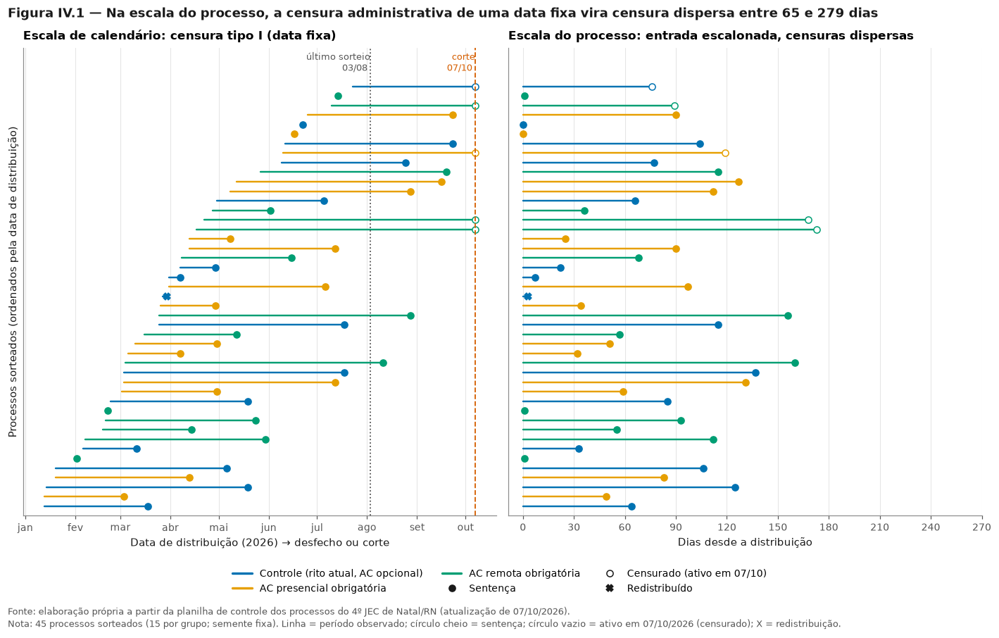

In [95]:
_rng = np.random.default_rng(SEMENTE + 4)
amostra = (pd.concat([sob[sob.grupo == g].iloc[_rng.choice((sob.grupo == g).sum(), 15, replace=False)] for g in ORDEM_GRUPO])
           .sort_values('dt_distribuicao').reset_index(drop=True))
fim = amostra['dt_sentenca'].where(amostra['CR'] > 0, DATA_CORTE)
MARCA = {0: dict(marker='o', mfc='white'), 1: dict(marker='o'), 2: dict(marker='X')}

fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
for i, r in amostra.iterrows():
    cor = CORES_GRUPO[r['grupo']]
    axes[0].plot([r['dt_distribuicao'], fim[i]], [i, i], color=cor, lw=1.6)
    axes[0].plot(fim[i], i, color=cor, ms=6, ls='', **MARCA[r['CR']])
    axes[1].plot([0, r['T']], [i, i], color=cor, lw=1.6)
    axes[1].plot(r['T'], i, color=cor, ms=6, ls='', **MARCA[r['CR']])
axes[0].axvline(DATA_CORTE, color=DESTAQUE, ls='--', lw=1.2); axes[0].axvline(FIM_RECRUTAMENTO, color=TINTA_2, ls=':', lw=1.2)
axes[0].text(DATA_CORTE, len(amostra) + 0.3, 'corte\n07/10 ', fontsize=8.5, color=DESTAQUE, ha='right', va='bottom')
axes[0].text(FIM_RECRUTAMENTO, len(amostra) + 0.3, 'último sorteio\n03/08 ', fontsize=8.5, color=TINTA_2, ha='right', va='bottom')
axes[0].set_ylim(-1, len(amostra) + 3)
axes[0].set_title('Escala de calendário: censura tipo I (data fixa)')
eixo_meses(axes[0])
axes[0].set_xlabel(ROTULOS['dt_distribuicao'] + ' → desfecho ou corte')
axes[1].set_title('Escala do processo: entrada escalonada, censuras dispersas')
axes[1].set_xlabel(ROTULOS['dias'])
axes[1].set_xticks(np.arange(0, 281, 30))
axes[0].set_yticks([]); axes[0].set_ylabel('Processos sorteados (ordenados pela data de distribuição)')
for ax in axes:
    ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
leg = LEG_GRUPO(longo=True) + [
    Line2D([], [], color=TINTA, marker='o', ls='', label='Sentença'),
    Line2D([], [], color=TINTA, marker='o', mfc='white', ls='', label='Censurado (ativo em 07/10)'),
    Line2D([], [], color=TINTA, marker='X', ls='', label='Redistribuído')]
fig.legend(handles=leg, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 0.0))
figura(fig, 'sob_diagrama_seguimento',
       'Na escala do processo, a censura administrativa de uma data fixa vira censura dispersa entre 65 e 279 dias',
       secao='4.1.3', nota='45 processos sorteados (15 por grupo; semente fixa). Linha = período observado; '
                           'círculo cheio = sentença; círculo vazio = ativo em 07/10/2026 (censurado); X = redistribuição.')

### 4.1.4 Estrutura dos dados por grupo

A tabela resume, por grupo, o que cada processo contribui: sentença (evento), censura administrativa (ativo) ou redistribuição. O **seguimento potencial** é o tempo máximo que cada processo poderia ter sido observado (07/10/2026 − distribuição). O seguimento mediano pelo **KM reverso** (KM com a censura como "evento") é a forma usual de resumir o acompanhamento em estudos com censura. Como todas as censuras aqui são administrativas, ele deve ficar próximo da mediana do seguimento potencial dos que ainda estavam em risco.

O gráfico de barras mostra a **proporção censurada por mês de distribuição e grupo**. Ela cresce fortemente com o mês: é a assinatura da entrada escalonada. Se um grupo tivesse mais processos nos meses tardios (julho concentra Remota: 67 × 44 × 46), ele teria mais censura por puro calendário, o que é mais um motivo para o ajuste por mês.

Medida,Controle,Presencial,Remota,Total
n,313,314,311,938
Sentenças (δ = 1),262,230,216,708
Ativos (censura adm.),46,74,86,206
Redistribuídos,5,10,9,24
% censurado,"16,3%","26,8%","30,5%","24,5%"
Seguimento potencial mediano (d),170,162,161,164
Seguimento potencial mín.–máx.,65–279,65–273,65–273,65–279
"Seguimento mediano, KM reverso (d)",167,140,147,154


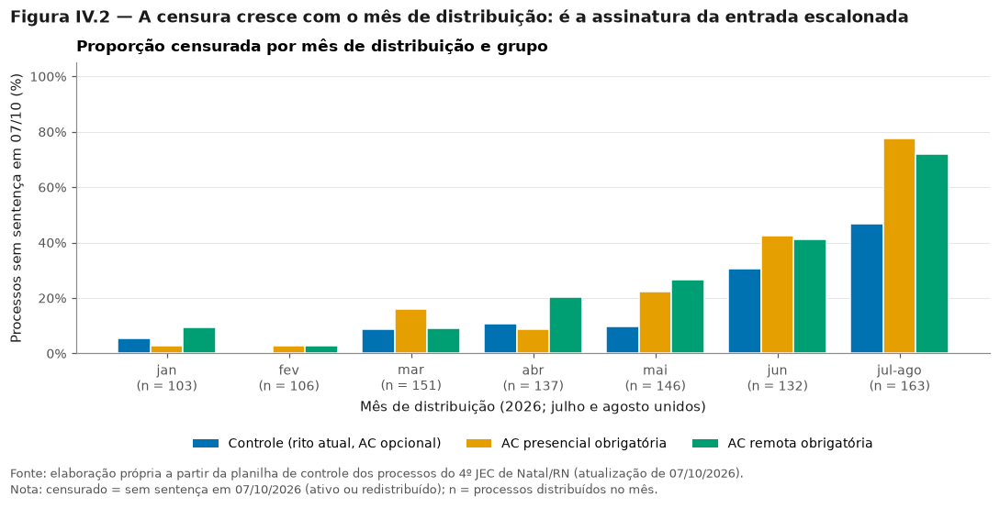

In [96]:
def resumo_estrutura(s):
    kmr = KaplanMeierFitter().fit(s['T'], 1 - s['E'])        # KM reverso (censura como "evento")
    return pd.Series({'n': len(s), 'Sentenças (δ = 1)': int(s['E'].sum()),
                      'Ativos (censura adm.)': int((s['CR'] == 0).sum()),
                      'Redistribuídos': int((s['CR'] == 2).sum()),
                      '% censurado': pct_br(1 - s['E'].mean()),
                      'Seguimento potencial mediano (d)': fmt_br(s['FU'].median(), 0),
                      'Seguimento potencial mín.–máx.': f"{int(s['FU'].min())}–{int(s['FU'].max())}",
                      'Seguimento mediano, KM reverso (d)': fmt_br(kmr.median_survival_time_, 0)})

estrutura = pd.concat({g: resumo_estrutura(sob[sob.grupo == g]) for g in ORDEM_GRUPO} | {'Total': resumo_estrutura(sob)}, axis=1)
tabela(estrutura.rename_axis('Medida'), 'sob_estrutura', 'Contribuição de cada processo à análise: sentença, censura ou redistribuição',
       secao='4.1.4', nota='seguimento potencial = 07/10/2026 − data de distribuição; KM reverso = Kaplan-Meier com a censura '
                           'como "evento".')

cens_mes = (sob.assign(cens=1 - sob['E']).groupby(['mes', 'grupo'], observed=True)['cens'].mean().unstack() * 100)
n_mes = sob.groupby('mes', observed=True).size()
_cm = cens_mes.copy()
_cm.columns = [str(c) for c in _cm.columns]
_cm.index = [f'{m}\n(n = {fmt_br(n_mes[m], 0)})' for m in _cm.index]
fig, ax = plt.subplots(figsize=(10, 4.6))
barras_agrupadas(ax, _cm, cores=CORES_GRUPO, rotular=False, quebrar=20,
                 ylabel='Processos sem sentença em 07/10 (%)', xlabel='Mês de distribuição (2026; julho e agosto unidos)',
                 legenda=False)
eixo_pct(ax, escala=1)
ax.set_ylim(0, 105)
ax.set_title('Proporção censurada por mês de distribuição e grupo')
legenda_abaixo(ax, ncol=3, dy=-0.25, handles=[Patch(color=CORES_GRUPO[g], label=ROTULO_GRUPO[g]) for g in ORDEM_GRUPO])
figura(fig, 'sob_censura_mes', 'A censura cresce com o mês de distribuição: é a assinatura da entrada escalonada',
       secao='4.1.4', nota='censurado = sem sentença em 07/10/2026 (ativo ou redistribuído); n = processos distribuídos no mês.')

### 4.1.5 Tabela de vida: número em risco, eventos e censuras por intervalo

A tabela de vida (atuarial) por intervalos de 30 dias é a forma mais transparente de ver de onde vem a informação: **n em risco** no início do intervalo, **sentenças** e **censuras** dentro dele. Note que, a partir de ~180 dias, o número em risco cai rapidamente, e a censura passa a dominar: as estimativas da cauda direita (> 180 dias) são imprecisas, o que orienta a escolha do horizonte τ do RMST (seção 4.3.6).

In [97]:
def tabela_vida(s, cortes=TEMPOS_TAB):
    linhas = []
    for a, b in zip(cortes, cortes[1:] + [np.inf]):
        no_int = (s['T'] >= a) & (s['T'] < b)
        linhas.append({'intervalo (d)': f'[{a}, {b})' if np.isfinite(b) else f'≥ {a}',
                       'em risco': int((s['T'] >= a).sum()),
                       'sentenças': int((no_int & (s['E'] == 1)).sum()),
                       'censuras': int((no_int & (s['E'] == 0)).sum())})
    return pd.DataFrame(linhas).set_index('intervalo (d)')

vida = pd.concat({g: tabela_vida(sob[sob.grupo == g]) for g in ORDEM_GRUPO}, axis=1)
tabela(vida.rename_axis('Intervalo (dias)'), 'sob_tabela_vida', 'Tabela de vida por grupo: em risco no início, sentenças e censuras '
       'em cada intervalo de 30 dias', secao='4.1.5', indice=True,
       nota='em risco = processos com T ≥ início do intervalo; censuras = ativos em 07/10/2026 ou redistribuídos.')

**Interpretação (estrutura dos dados).**

- **A censura é desigual entre os grupos:** 16,3% no Controle, 26,8% na AC presencial e 30,5% na AC remota. Os três grupos têm seguimento potencial quase igual (mediana de 170, 162 e 161 dias; mínimo de 65 dias em todos), então a diferença **não** vem do calendário de entrada. Ela vem do próprio desfecho: mais processos com AC ainda aguardavam sentença em 07/10. Isso já antecipa que os ritos com AC são mais lentos, e mostra por que comparar médias só dos encerrados (E14) favorece artificialmente os grupos com AC: os processos lentos deles estão justamente entre os censurados.
- O seguimento mediano pelo KM reverso (167, 140 e 147 dias) é menor nos grupos com AC pelo mesmo motivo. Os processos que continuam ativos são os distribuídos mais tarde.
- **A censura cresce com o mês de distribuição** em todos os grupos (gráfico de barras): é a assinatura da entrada escalonada. Em julho e agosto, a maior parte ainda está ativa. A análise precisa, portanto, condicionar no mês (seções 4.3.4 e 4.5).
- **A informação se esgota depois de ~180 dias.** A tabela de vida mostra 9 a 10 processos em risco por grupo aos 180 dias e 1 a 5 aos 210 dias. Estimativas além de 180 dias são frágeis, e por isso τ = 180 dias é o horizonte máximo do RMST.
- **Plausibilidade da censura não informativa.** Todos os 206 censurados estão ativos na data de corte, e o tempo potencial de censura é fixado pela data de distribuição, não pelo andamento do processo. A hipótese é razoável, **desde que o mês entre no modelo**, porque a seção 4.5.4 mostra uma tendência de calendário (processos mais recentes tramitam mais devagar). As 24 redistribuições (5, 10 e 9 por grupo) são outro mecanismo e são tratadas na seção 4.7.

---

## 4.2 Estimação não paramétrica: Kaplan-Meier e Nelson-Aalen

### 4.2.1 O estimador de Kaplan-Meier

O estimador de Kaplan-Meier (KAPLAN; MEIER, 1958) é o produto, sobre os tempos de evento t_j < t, das probabilidades condicionais de "sobreviver" (continuar sem sentença) a cada t_j:

Ŝ(t) = ∏_{j: t_j ≤ t} (1 − d_j / n_j),

em que d_j é o número de sentenças no dia t_j e n_j é o número em risco (ainda pendentes e não censurados) imediatamente antes de t_j (COLOSIMO; GIOLO, 2006, eq. 2.6, p. 37; MORETTIN; SINGER, 2021, p. 247-248). Cada censurado contribui para os denominadores enquanto está em observação, e depois sai do risco: é assim que o KM usa a informação parcial que a média ingênua desperdiça.

- **Variância de Greenwood:** Var[Ŝ(t)] = Ŝ(t)² Σ d_j/[n_j(n_j − d_j)] (eq. 2.7, p. 41).
- **IC 95% log-log** ("Greenwood exponencial"): o IC simples Ŝ ± 1,96·EP pode sair de [0, 1] nos extremos; a transformação Û = log[−log Ŝ(t)] produz [Ŝ(t)]^{exp(±1,96·√Var Û)}, sempre dentro de [0, 1] (eq. 2.8, p. 41-42). É o padrão do `lifelines`.
- **Propriedades:** não viciado em amostras grandes, consistente, assintoticamente normal e estimador de máxima verossimilhança não paramétrico (p. 40).

Como pedido, a curva é sempre a **descendente** S(t). As marcas verticais (|) são as censuras; a tabela sob o gráfico dá o número em risco.

Mediana global: 89 dias (IC 95%: 83–94)


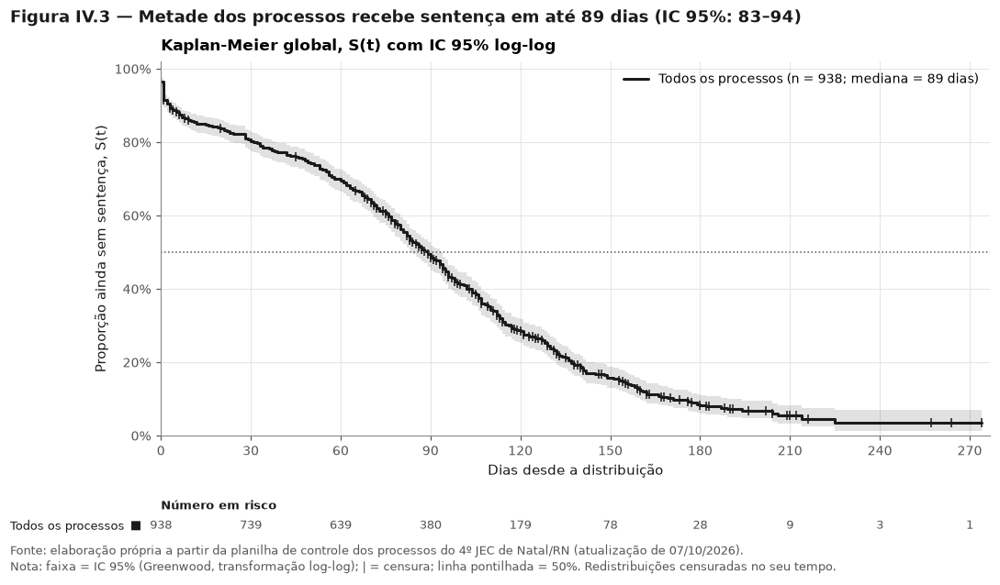

In [98]:
km_total = KaplanMeierFitter(label='Todos os processos').fit(sob['T'], sob['E'])
med_ic = median_survival_times(km_total.confidence_interval_)
print(f'Mediana global: {fmt_br(km_total.median_survival_time_, 0)} dias '
      f'(IC 95%: {fmt_br(med_ic.iloc[0, 0], 0)}–{fmt_br(med_ic.iloc[0, 1], 0)})')

fig, ax = plt.subplots(figsize=(10, 5.2))
plot_km(ax, sob, tempo='T', evento='E', grupo=None, passo=30, rotulos={'Todos': 'Todos os processos'})
ax.axhline(0.5, color=TINTA_2, ls=':', lw=1)
eixo_pct(ax)
ax.set_title('Kaplan-Meier global, S(t) com IC 95% log-log')
figura(fig, 'sob_km_global',
       f'Metade dos processos recebe sentença em até {fmt_br(km_total.median_survival_time_, 0)} dias '
       f'(IC 95%: {fmt_br(med_ic.iloc[0, 0], 0)}–{fmt_br(med_ic.iloc[0, 1], 0)})',
       secao='4.2.1', nota='faixa = IC 95% (Greenwood, transformação log-log); | = censura; linha pontilhada = 50%. '
                           'Redistribuições censuradas no seu tempo.')

### 4.2.2 Kaplan-Meier por grupo

As três curvas com IC 95% (faixas) e marcas de censura. Leitura: a curva mais **alta** em um dado t é a do grupo com mais processos **ainda pendentes** nesse dia, ou seja, o rito mais lento até ali. A distância vertical entre as curvas em t é a diferença na proporção já sentenciada; a distância horizontal na altura 50% é a diferença de medianas.

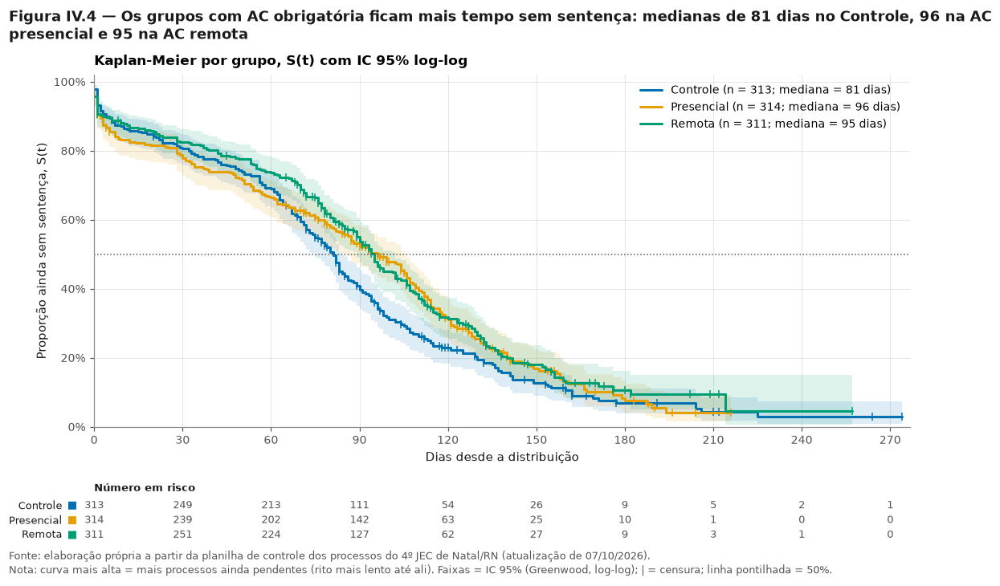

In [99]:
km_g = {g: KaplanMeierFitter(label=ROTULO_GRUPO[g]).fit(sob.loc[sob.grupo == g, 'T'], sob.loc[sob.grupo == g, 'E'])
        for g in ORDEM_GRUPO}
fig, ax = plt.subplots(figsize=(10.5, 5.8))
plot_km(ax, sob, tempo='T', evento='E', grupo='grupo', passo=30)
ax.axhline(0.5, color=TINTA_2, ls=':', lw=1)
eixo_pct(ax)
ax.set_title('Kaplan-Meier por grupo, S(t) com IC 95% log-log')
_md = {g: km_g[g].median_survival_time_ for g in ORDEM_GRUPO}
figura(fig, 'sob_km_grupos',
       f'Os grupos com AC obrigatória ficam mais tempo sem sentença: medianas de {fmt_br(_md["Controle"], 0)} dias no Controle, '
       f'{fmt_br(_md["Presencial"], 0)} na AC presencial e {fmt_br(_md["Remota"], 0)} na AC remota',
       secao='4.2.2', nota='curva mais alta = mais processos ainda pendentes (rito mais lento até ali). Faixas = IC 95% '
                           '(Greenwood, log-log); | = censura; linha pontilhada = 50%.')

### 4.2.3 Mediana e quartis com IC 95%

A mediana é t̂₀,₅ = inf{t: Ŝ(t) ≤ 0,5} (MORETTIN; SINGER, 2021, p. 248). Os quartis seguem a mesma regra: o **1º quartil** (Q1) é o dia em que 25% dos processos já tiveram sentença (Ŝ ≤ 0,75) e o **3º quartil** (Q3), o dia em que 75% já tiveram (Ŝ ≤ 0,25). A variância da mediana depende da densidade f(t), desconhecida; o IC é obtido **invertendo as bandas** de confiança de Ŝ (o tempo em que cada limite do IC cruza o nível p), procedimento próximo ao de Brookmeyer e Crowley (1982) descrito por Colosimo e Giolo (2006, p. 49-50). É o que faz `median_survival_times(kmf.confidence_interval_)`.

O **tempo médio** ∫S(t)dt não é estimável: com censura na cauda, a média fica subestimada e "deve ser interpretada com cautela ou evitada" (COLOSIMO; GIOLO, 2006, p. 50). O substituto é o RMST (seção 4.3.6).

In [100]:
def quantis_km(kmf):
    ic = kmf.confidence_interval_
    linha = {}
    for nome, p in [('Q1 (25% sentenciados)', 0.75), ('Mediana', 0.5), ('Q3 (75% sentenciados)', 0.25)]:
        est = quantil_tempo(kmf.survival_function_.iloc[:, 0], p)
        inf = quantil_tempo(ic.iloc[:, 0], p)       # limite inferior de S cruza antes
        sup = quantil_tempo(ic.iloc[:, 1], p)
        linha[nome] = f'{fmt_br(est, 0)} ({fmt_br(inf, 0)}–{fmt_br(sup, 0) if np.isfinite(sup) else "∞"})'
    return pd.Series(linha)

quartis = pd.DataFrame({ROTULO_GRUPO[g]: quantis_km(km_g[g]) for g in ORDEM_GRUPO} | {'Todos': quantis_km(km_total)}).T
tabela(quartis.rename_axis('Grupo'), 'sob_quartis', 'Dias até a sentença: quartis de Kaplan-Meier, estimativa (IC 95%)',
       secao='4.2.3', formatos={c: 'texto' for c in quartis.columns},
       nota='IC por inversão das bandas log-log de Ŝ(t); ∞ = o limite do IC não cruza o nível dentro do seguimento.')
MEDIANAS = {g: km_g[g].median_survival_time_ for g in ORDEM_GRUPO}

Grupo,Q1 (25% sentenciados),Mediana,Q3 (75% sentenciados)
"Controle (rito atual, AC opcional)",48 (33–57),81 (75–84),114 (104–130)
AC presencial obrigatória,37 (28–53),96 (85–106),131 (121–141)
AC remota obrigatória,55 (42–70),95 (89–102),132 (123–142)
Todos,48 (38–55),89 (83–94),129 (121–133)


### 4.2.4 Ŝ(t) em horizontes fixos de gestão

Para o gestor, a pergunta natural é "que fração dos processos ainda está sem sentença depois de 1, 2, 3, 4 e 6 meses?". A tabela traz Ŝ(t) com IC 95% log-log em 30, 60, 90, 120 e 180 dias; o gráfico mostra as mesmas estimativas em barras verticais com o IC. Os testes formais de diferença nesses pontos estão na seção 4.3.5.

Horizonte,Controle,Presencial,Remota
30 dias,"80,6% (75,8%–84,6%) [n=249]","77,9% (72,8%–82,1%) [n=239]","82,5% (77,8%–86,3%) [n=251]"
60 dias,"68,9% (63,4%–73,8%) [n=213]","66,3% (60,7%–71,3%) [n=202]","73,6% (68,3%–78,2%) [n=224]"
90 dias,"39,6% (34,0%–45,2%) [n=111]","52,3% (46,5%–57,9%) [n=142]","53,7% (47,6%–59,3%) [n=127]"
120 dias,"23,0% (18,3%–28,1%) [n=54]","31,0% (25,4%–36,9%) [n=63]","31,3% (25,4%–37,3%) [n=62]"
180 dias,"6,9% (3,9%–11,1%) [n=9]","7,5% (4,0%–12,6%) [n=10]","10,7% (6,4%–16,2%) [n=9]"


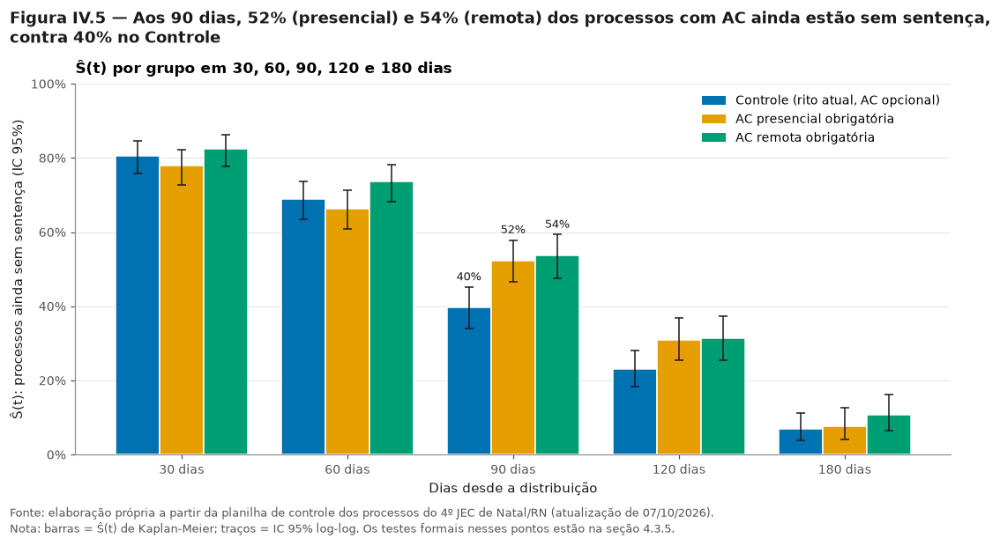

In [101]:
HORIZONTES = [30, 60, 90, 120, 180]
linhas = []
for g in ORDEM_GRUPO:
    k = km_g[g]
    S = k.survival_function_at_times(HORIZONTES).values
    ic = k.confidence_interval_
    for t, s_t in zip(HORIZONTES, S):
        li = ic.iloc[:, 0][ic.index <= t].iloc[-1]; ls = ic.iloc[:, 1][ic.index <= t].iloc[-1]
        linhas.append({'grupo': g, 't': t, 'S': s_t, 'inf': li, 'sup': ls, 'em risco': int((sob.loc[sob.grupo == g, 'T'] >= t).sum())})
s_horiz = pd.DataFrame(linhas)
tab = s_horiz.assign(txt=lambda d: [f'{pct_br(a)} ({pct_br(b)}–{pct_br(c)}) [n={n}]' for a, b, c, n in zip(d.S, d['inf'], d['sup'], d['em risco'])]
                     ).pivot(index='t', columns='grupo', values='txt')[ORDEM_GRUPO]
tab.index = [f'{t} dias' for t in tab.index]
tab.columns = [str(c) for c in tab.columns]
tabela(tab.rename_axis('Horizonte'), 'sob_S_horizontes', 'Proporção ainda sem sentença, Ŝ(t), em horizontes fixos: '
       'estimativa (IC 95%) [n em risco]', secao='4.2.4', formatos={c: 'texto' for c in tab.columns},
       nota='IC 95% log-log (Greenwood).')

_sh = s_horiz.pivot(index='t', columns='grupo', values='S')[ORDEM_GRUPO]
_sh.index = [f'{t} dias' for t in _sh.index]
_sh.columns = [str(c) for c in _sh.columns]
_erro = {g: (s_horiz.loc[s_horiz.grupo == g, 'inf'].to_numpy(), s_horiz.loc[s_horiz.grupo == g, 'sup'].to_numpy())
         for g in ORDEM_GRUPO}
fig, ax = plt.subplots(figsize=(10, 4.8))
barras_agrupadas(ax, _sh, cores=CORES_GRUPO, erro=_erro, legenda=False, ylabel='Ŝ(t): processos ainda sem sentença (IC 95%)',
                 xlabel='Dias desde a distribuição')
eixo_pct(ax); ax.set_ylim(0, 1)
for j, g in enumerate(ORDEM_GRUPO):         # rótulo só no horizonte de 90 dias (onde as curvas mais se separam)
    v = _sh.loc['90 dias', g]; hi = _erro[g][1][HORIZONTES.index(90)]
    ax.annotate(pct_br(v, 0), (HORIZONTES.index(90) + (j - 1) * 0.8 / 3, hi), xytext=(0, 3), textcoords='offset points',
                ha='center', va='bottom', fontsize=8.5, color=TINTA)
ax.set_title('Ŝ(t) por grupo em 30, 60, 90, 120 e 180 dias')
ax.legend(handles=[Patch(color=CORES_GRUPO[g], label=ROTULO_GRUPO[g]) for g in ORDEM_GRUPO], loc='upper right')
figura(fig, 'sob_S_horizontes', f'Aos 90 dias, {pct_br(_sh.loc["90 dias", "Presencial"], 0)} (presencial) e '
       f'{pct_br(_sh.loc["90 dias", "Remota"], 0)} (remota) dos processos com AC ainda estão sem sentença, '
       f'contra {pct_br(_sh.loc["90 dias", "Controle"], 0)} no Controle',
       secao='4.2.4', nota='barras = Ŝ(t) de Kaplan-Meier; traços = IC 95% log-log. Os testes formais nesses pontos estão na seção 4.3.5.')

### 4.2.5 Nelson-Aalen e risco suavizado

O estimador de **Nelson-Aalen** do risco acumulado é Λ̃(t) = Σ_{t_j ≤ t} d_j/n_j, com variância de Aalen Σ d_j/n_j² (COLOSIMO; GIOLO, 2006, eq. 2.9-2.10, p. 43-44). Ele dá S̃(t) = exp{−Λ̃(t)} ≥ Ŝ(t) e serve sobretudo para ver a **forma do risco**: Λ(t) reto indica risco constante; côncavo, risco decrescente; convexo, crescente (p. 45; p. 96-99).

A **taxa de sentença por dia** h(t) é a derivada de Λ(t). Estima-se por suavização por núcleo (Ramlau-Hansen) dos incrementos d_j/n_j, com núcleo de Epanechnikov e banda de 20 dias (`NelsonAalenFitter.smoothed_hazard_`). A banda é uma escolha de compromisso: menor deixa a curva ruidosa, maior apaga a estrutura. A curva é cortada em 180 dias: depois disso há menos de 10 processos em risco por grupo, e a estimativa vira ruído. É a figura que mostra **quando** cada rito sentencia mais.

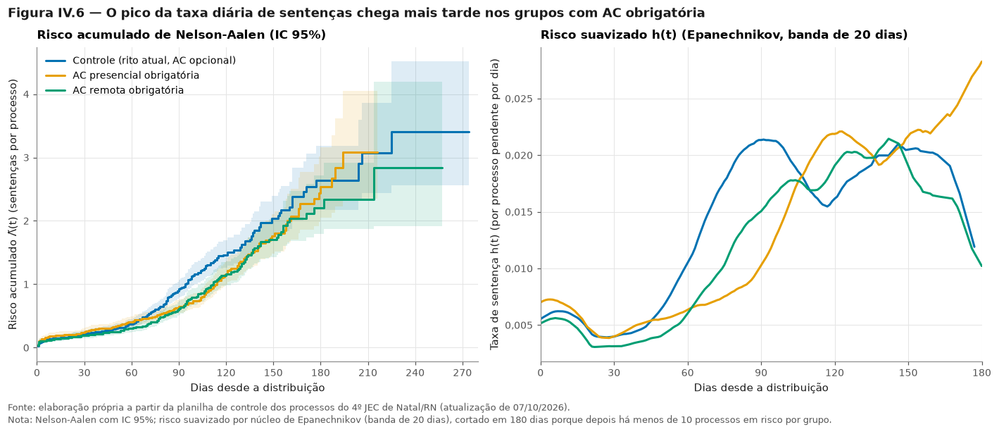

In [102]:
na_g = {g: NelsonAalenFitter(label=ROTULO_GRUPO[g]).fit(sob.loc[sob.grupo == g, 'T'], sob.loc[sob.grupo == g, 'E'])
        for g in ORDEM_GRUPO}
BANDA = 20
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for g in ORDEM_GRUPO:
    ch = na_g[g].cumulative_hazard_.iloc[:, 0]
    ci = na_g[g].confidence_interval_
    axes[0].step(ch.index, ch.values, where='post', color=CORES_GRUPO[g], lw=2, label=ROTULO_GRUPO[g])
    axes[0].fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step='post', color=CORES_GRUPO[g], alpha=0.13, lw=0)
    hz = na_g[g].smoothed_hazard_(bandwidth=BANDA)
    hz = hz[hz.index <= 180]
    axes[1].plot(hz.index, hz.iloc[:, 0], color=CORES_GRUPO[g], lw=2, label=ROTULO_GRUPO[g])
axes[0].set_xlim(0, 280); axes[0].set_xticks(np.arange(0, 281, 30))
axes[0].set_xlabel(ROTULOS['dias']); axes[0].set_ylabel('Risco acumulado Λ̃(t) (sentenças por processo)')
axes[0].set_title('Risco acumulado de Nelson-Aalen (IC 95%)')
axes[0].legend(loc='upper left')
axes[1].set_xlim(0, 180); axes[1].set_xticks(np.arange(0, 181, 30))
axes[1].set_xlabel(ROTULOS['dias']); axes[1].set_ylabel('Taxa de sentença h(t) (por processo pendente por dia)')
axes[1].set_title(f'Risco suavizado h(t) (Epanechnikov, banda de {BANDA} dias)')
for ax in axes:
    ax.grid(axis='both', visible=True)
figura(fig, 'sob_nelson_aalen_risco', 'O pico da taxa diária de sentenças chega mais tarde nos grupos com AC obrigatória',
       secao='4.2.5', nota=f'Nelson-Aalen com IC 95%; risco suavizado por núcleo de Epanechnikov (banda de {BANDA} dias), '
                           'cortado em 180 dias porque depois há menos de 10 processos em risco por grupo.')

**Interpretação (Kaplan-Meier e risco).**

- **Mediana global:** 89 dias (IC 95%: 83–94). Metade dos processos do 4º JEC recebeu sentença em cerca de três meses.
- **Medianas por grupo:**

  | Grupo | Mediana (IC 95%) |
  |---|---|
  | Controle | 81 dias (75–84) |
  | AC presencial | 96 dias (85–106) |
  | AC remota | 95 dias (89–102) |

  Os intervalos do Controle não se sobrepõem aos da AC remota e só tocam os da presencial. A **AC obrigatória atrasou a mediana em cerca de 15 dias**. O notebook do professor, com o Kruskal-Wallis sobre tempos censurados (E17), concluía "sem diferença".
- **O formato das curvas importa mais que as medianas.** Até cerca de 60 dias, as três curvas praticamente coincidem: Ŝ(30) = 80,6%, 77,9% e 82,5%; Ŝ(60) = 68,9%, 66,3% e 73,6%. A separação acontece **entre 60 e 120 dias**:
  - aos 90 dias, 39,6% dos processos do Controle ainda estão sem sentença, contra 52,3% na AC presencial e 53,7% na remota;
  - aos 120 dias, 23,0% contra 31,0% e 31,3%;
  - aos 180 dias as curvas voltam a se aproximar (6,9%, 7,5% e 10,7%), com ICs largos.
- **Quartis.** O 1º quartil da AC presencial é o *menor* (37 dias, contra 48 no Controle): uma parte dos processos presenciais termina **mais cedo**, e a seção 4.7 mostra que são extinções sem mérito. O 3º quartil é 17 a 18 dias maior nos grupos com AC (131–132 contra 114).
- **Risco suavizado.** A taxa diária de sentenças do Controle atinge o pico por volta de 90 dias (≈ 0,021 sentença por processo pendente por dia). Nos grupos com AC, o pico é **deslocado para 120–150 dias**. É o retrato de um rito com uma etapa a mais: o julgamento de mérito espera a audiência, e a "onda" de sentenças chega mais tarde. Nos primeiros 30 dias, a AC presencial tem taxa um pouco maior que a dos outros grupos.

---

## 4.3 Comparação das curvas de sobrevivência

**Hipóteses (para toda a família de testes de k amostras):**

- H₀: S_Controle(t) = S_Presencial(t) = S_Remota(t) para todo t (equivalentemente, mesmas funções de risco);
- H₁: ao menos uma curva difere em algum t.

**Por que testar.** O desenho é um experimento com sorteio: diferenças sistemáticas entre as curvas, além do acaso, são atribuíveis ao rito. Os grupos são **independentes** (processos distintos, alocação aleatória; questão 2.3), o que justifica testes de k amostras independentes. **Pré-especificação:** o teste principal é o **log-rank** de 3 grupos (2 g.l.); os testes ponderados, os pares, o estratificado, os pontos fixos e o RMST são análises de apoio, cada uma respondendo a uma pergunta mais específica.

### 4.3.1 Teste log-rank

O log-rank compara, em cada tempo de evento t_j, o número observado de sentenças em cada grupo com o esperado sob H₀ (w_gj = n_gj d_j/n_j) e soma as diferenças ao longo do tempo. Com r = 3 grupos, a estatística T = v′V⁻¹v tem distribuição χ² com r − 1 = 2 g.l. (COLOSIMO; GIOLO, 2006, eq. 2.12-2.13, p. 56-59; MORETTIN; SINGER, 2021, p. 253). Ele coincide com o teste escore do modelo de Cox com o grupo como covariável (COLOSIMO; GIOLO, 2006, p. 56) e é o **mais poderoso quando os riscos são proporcionais** (p. 55).

**Pressupostos:** censura não informativa (4.1.1) e independência entre processos. **Gráfico do teste:** barras de sentenças **observadas (O)** e **esperadas sob H₀ (E)** por grupo; O < E significa que o grupo sentenciou menos (foi mais lento) do que sentenciaria se não houvesse diferença.

Log-rank (3 grupos): χ² = 7,52, g.l. = 2, p = 0,023


Grupo,Observadas (O),Esperadas sob H₀ (E),O/E
Controle,262,"229,21","1,14"
Presencial,230,"239,10","0,96"
Remota,216,"239,69","0,90"


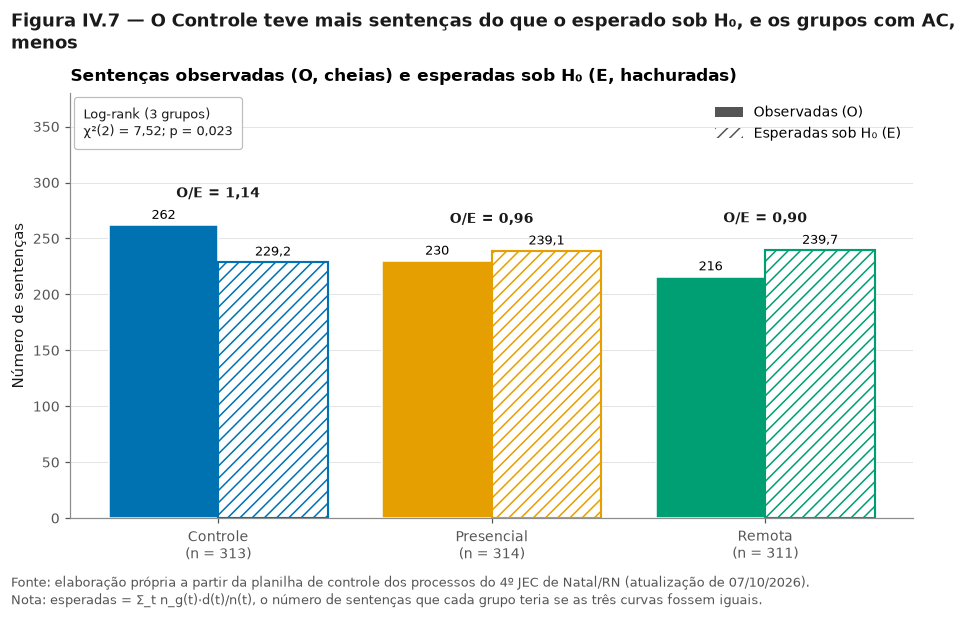

In [103]:
def obs_esperados(T, E, G, grupos=ORDEM_GRUPO):
    """Sentenças observadas e esperadas sob H0 (log-rank) por grupo."""
    T = np.asarray(T, float); E = np.asarray(E, int); G = np.asarray(G)
    tempos = np.unique(T[E == 1])
    n_tot = np.array([(T >= t).sum() for t in tempos]); d_tot = np.array([((T == t) & (E == 1)).sum() for t in tempos])
    res = {}
    for g in grupos:
        Tg = T[G == g]
        n_g = np.array([(Tg >= t).sum() for t in tempos])
        res[g] = {'Observadas (O)': int(E[G == g].sum()), 'Esperadas sob H₀ (E)': float((n_g * d_tot / n_tot).sum())}
    out = pd.DataFrame(res).T
    out['O/E'] = out.iloc[:, 0] / out.iloc[:, 1]
    return out

lr_global = multivariate_logrank_test(sob['T'], sob['grupo'].astype(str), sob['E'])
oe = obs_esperados(sob['T'], sob['E'], sob['grupo'].astype(str))
print(f"Log-rank (3 grupos): χ² = {fmt_br(lr_global.test_statistic, 2)}, g.l. = {lr_global.degrees_of_freedom}, p = {p_br(lr_global.p_value)}")
sob_tabela(oe.rename_axis('Grupo'), 'sob_logrank_oe', 'Log-rank de 3 grupos: sentenças observadas e esperadas sob H₀',
           secao='4.3.1', casas=2, destaque=None, formatos={'Observadas (O)': 'int'},
           nota=f'log-rank: χ² = {fmt_br(lr_global.test_statistic, 2)} ({lr_global.degrees_of_freedom} g.l.); '
                f'{p_txt(lr_global.p_value)}. O/E < 1 = menos sentenças que o esperado (grupo mais lento).')

fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(3)
ax.bar(x - 0.2, oe['Observadas (O)'], 0.4, color=[CORES_GRUPO[g] for g in ORDEM_GRUPO], edgecolor='white', lw=1)
ax.bar(x + 0.2, oe['Esperadas sob H₀ (E)'], 0.4, color='white', edgecolor=[CORES_GRUPO[g] for g in ORDEM_GRUPO],
       hatch='///', lw=1.4)
for xi, (o, e) in zip(x, oe.iloc[:, :2].values):
    ax.annotate(fmt_br(o, 0), (xi - 0.2, o), xytext=(0, 2), textcoords='offset points', ha='center', va='bottom', fontsize=8.5)
    ax.annotate(fmt_br(e, 1), (xi + 0.2, e), xytext=(0, 2), textcoords='offset points', ha='center', va='bottom', fontsize=8.5)
    ax.annotate(f'O/E = {fmt_br(o / e, 2)}', (xi, max(o, e)), xytext=(0, 16), textcoords='offset points', ha='center',
                va='bottom', fontsize=9, fontweight='bold', color=TINTA)
ax.set_xticks(x, [rotulo_grupo(g, com_n=True, base=sob, quebrar=True) for g in ORDEM_GRUPO])
ax.grid(axis='x', visible=False)
ax.set_ylabel('Número de sentenças'); ax.set_ylim(0, oe.iloc[:, :2].to_numpy().max() * 1.45)
ax.set_title('Sentenças observadas (O, cheias) e esperadas sob H₀ (E, hachuradas)')
ax.legend(handles=[Patch(facecolor=TINTA_2, label='Observadas (O)'),
                   Patch(facecolor='white', edgecolor=TINTA_2, hatch='///', label='Esperadas sob H₀ (E)')],
          loc='upper right')
anotar_teste(ax, texto_teste('Log-rank (3 grupos)', f'χ²({lr_global.degrees_of_freedom}) = {fmt_br(lr_global.test_statistic, 2)}',
                             lr_global.p_value), loc='upper left')
figura(fig, 'sob_logrank_oe', 'O Controle teve mais sentenças do que o esperado sob H₀, e os grupos com AC, menos',
       secao='4.3.1', nota='esperadas = Σ_t n_g(t)·d(t)/n(t), o número de sentenças que cada grupo teria se as três curvas fossem iguais.')

### 4.3.2 A família ponderada: Wilcoxon, Tarone-Ware, Peto-Prentice e Fleming-Harrington

Todos os testes da família têm a forma S = [Σ u_j (d_gj − w_gj)]² / Σ u_j² V_gj, e diferem apenas no **peso u_j** dado a cada tempo de evento (COLOSIMO; GIOLO, 2006, eq. 2.14-2.15, p. 61-63):

| Teste | Peso u_j | Onde tem mais poder |
|---|---|---|
| Log-rank | 1 | diferenças constantes (riscos proporcionais) |
| Wilcoxon / Gehan-Breslow | n_j | diferenças **precoces**; mas depende do padrão de censura |
| Tarone-Ware | √n_j | meio-termo |
| Peto-Prentice | S̃(t_{j−1})·n_j/(n_j + 1), com S̃(t) = ∏(1 − d_j/(n_j + 1)) | precoces, sem depender da censura |
| Fleming-Harrington (p, q) | Ŝ(t_{j−1})^p [1 − Ŝ(t_{j−1})]^q | (1, 0) precoce; (0, 1) **tardia**; (1, 1) intermediária |

**Por que fazer todos.** Se o efeito do rito muda ao longo do tempo (por exemplo, a AC obrigatória acelera extinções e acordos no início e atrasa os julgamentos de mérito depois), as diferenças de sinais opostos se cancelam no log-rank e o teste perde poder (p. 62-63). Comparar testes com pesos precoces e tardios mostra **onde** está a diferença. Como a censura aqui varia entre grupos e meses, Colosimo e Giolo recomendam preferir Peto ou FH ao Gehan (p. 63). Os testes são **sensibilidade** do teste principal, não uma família para escolher o menor p.

**Implementação.** A estatística de k amostras é calculada por uma função própria (`teste_k_ponderado`, fórmulas de Colosimo e Giolo), porque a opção `weightings='fleming-harrington'` do `lifelines` 0.30 falha com o pandas 3. A coluna "χ² lifelines" confere a implementação nos testes em que o `lifelines` funciona; a pequena diferença no Peto-Prentice vem da definição do peso (o `lifelines` usa S̃ no próprio t_j, e aqui se usa S̃(t_{j−1}), como no livro).

**Gráfico do teste:** à esquerda, os pesos relativos u(t)/max u(t) ao longo do tempo (onde cada teste "olha"); à direita, as estatísticas χ²₂ com o valor crítico de 5%.

Teste,χ² (2 g.l.),p,χ² lifelines (conferência),"p (Holm, 7 testes)"
Log-rank,"7,52","0,023","7,52","0,120"
Wilcoxon (Gehan-Breslow),"6,40","0,041","6,40","0,136"
Tarone-Ware,"7,82","0,020","7,82","0,120"
Peto-Prentice,"6,77","0,034","6,96","0,136"
"Fleming-Harrington (1, 0)","6,77","0,034",–,"0,136"
"Fleming-Harrington (0, 1)","4,91","0,086",–,"0,136"
"Fleming-Harrington (1, 1)","13,80","0,001",–,"0,007"


Fleming-Harrington: o lifelines 0.30 falha com o pandas 3 (ValueError de alinhamento); usa-se a implementação própria, conferida contra o lifelines nos quatro testes em que ele funciona.


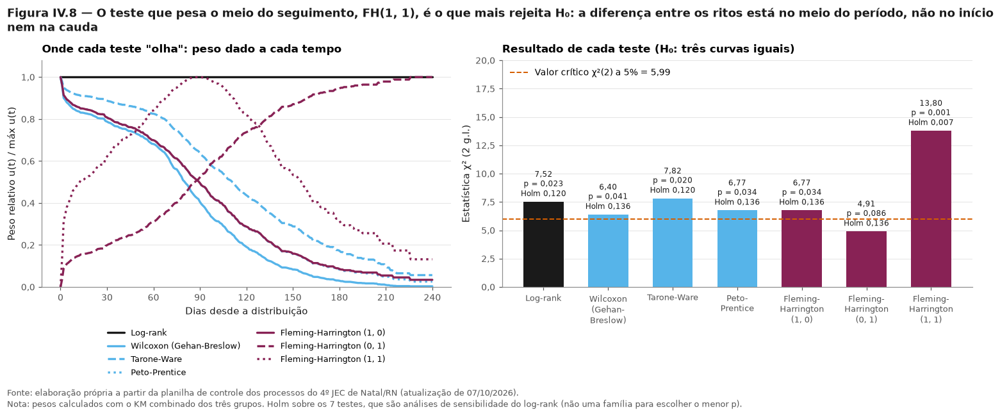

In [104]:
def teste_k_ponderado(T, E, G, peso='logrank', p=0, q=0, grupos=ORDEM_GRUPO):
    """Teste de k amostras da família ponderada (COLOSIMO; GIOLO, 2006, eq. 2.13-2.15): χ² = Z'V⁻¹Z, k − 1 g.l."""
    T = np.asarray(T, float); E = np.asarray(E, int); G = np.asarray(G)
    tj = np.unique(T[E == 1])
    n = np.array([(T >= t).sum() for t in tj]); d = np.array([((T == t) & (E == 1)).sum() for t in tj])
    S_km = np.cumprod(1 - d / n); S_km_ant = np.concatenate([[1.0], S_km[:-1]])
    S_peto_ant = np.concatenate([[1.0], np.cumprod(1 - d / (n + 1))[:-1]])
    u = {'logrank': np.ones_like(n, float), 'wilcoxon': n.astype(float), 'tarone-ware': np.sqrt(n),
         'peto': S_peto_ant * n / (n + 1), 'fh': S_km_ant ** p * (1 - S_km_ant) ** q}[peso]
    ng = np.array([[(T[G == g] >= t).sum() for t in tj] for g in grupos[:-1]])
    dg = np.array([[((T[G == g] == t) & (E[G == g] == 1)).sum() for t in tj] for g in grupos[:-1]])
    Z = (u * (dg - ng * d / n)).sum(axis=1)
    fator = np.where(n > 1, d * (n - d) / np.maximum(n - 1, 1), 0.0) * u ** 2
    V = np.empty((len(grupos) - 1,) * 2)
    for a in range(len(grupos) - 1):
        for b in range(len(grupos) - 1):
            V[a, b] = (fator * (ng[a] / n) * ((a == b) - ng[b] / n)).sum()
    chi = float(Z @ np.linalg.solve(V, Z))
    return chi, stats.chi2.sf(chi, len(grupos) - 1)

PONDERACOES = [('Log-rank', ('logrank', {}), {}), ('Wilcoxon (Gehan-Breslow)', ('wilcoxon', {}), {'weightings': 'wilcoxon'}),
               ('Tarone-Ware', ('tarone-ware', {}), {'weightings': 'tarone-ware'}), ('Peto-Prentice', ('peto', {}), {'weightings': 'peto'}),
               ('Fleming-Harrington (1, 0)', ('fh', {'p': 1, 'q': 0}), None),
               ('Fleming-Harrington (0, 1)', ('fh', {'p': 0, 'q': 1}), None),
               ('Fleming-Harrington (1, 1)', ('fh', {'p': 1, 'q': 1}), None)]
res_pond = []
Gs = sob['grupo'].astype(str)
for nome, (peso, kwp), kw_ll in PONDERACOES:
    chi, pv = teste_k_ponderado(sob['T'], sob['E'], Gs, peso, **kwp)
    chi_ll = multivariate_logrank_test(sob['T'], Gs, sob['E'], **kw_ll).test_statistic if kw_ll is not None else np.nan
    res_pond.append({'Teste': nome, 'χ² (2 g.l.)': chi, 'p': pv, 'χ² lifelines (conferência)': chi_ll})
res_pond = pd.DataFrame(res_pond).set_index('Teste')
res_pond['p (Holm, 7 testes)'] = multipletests(res_pond['p'], method='holm')[1]
sob_tabela(res_pond, 'sob_testes_ponderados', 'Família ponderada de testes de k amostras (3 grupos, 2 g.l.)', secao='4.3.2',
           casas=2, colunas_p=('p', 'p (Holm, 7 testes)'),
           nota='implementação própria (COLOSIMO; GIOLO, 2006, eq. 2.13-2.15); "χ² lifelines" confere os quatro testes em que o '
                'lifelines 0.30 funciona com o pandas 3 (– = não disponível). Destaque: p de Holm < 0,05.')
print('Fleming-Harrington: o lifelines 0.30 falha com o pandas 3 (ValueError de alinhamento); usa-se a implementação própria,'
      ' conferida contra o lifelines nos quatro testes em que ele funciona.')

# pesos ao longo do tempo (KM combinado)
S_comb, _ = aj_grade(sob['T'], sob['E'])
tt = np.arange(0, 241)
n_t = np.array([(sob['T'] >= t).sum() for t in tt]); S_ant = np.concatenate([[1.0], S_comb[:-1]])[tt]
pesos = {'Log-rank': np.ones_like(tt, float), 'Wilcoxon (Gehan-Breslow)': n_t, 'Tarone-Ware': np.sqrt(n_t),
         'Peto-Prentice': S_ant * n_t / (n_t + 1), 'Fleming-Harrington (1, 0)': S_ant,
         'Fleming-Harrington (0, 1)': 1 - S_ant, 'Fleming-Harrington (1, 1)': S_ant * (1 - S_ant)}
# cor = família do peso (Gehan/Tarone/Peto: azul-céu; Fleming-Harrington: vinho), estilo = variante; sem cores de grupo
ESTILO_TESTE = {'Log-rank': (TINTA, '-'), 'Wilcoxon (Gehan-Breslow)': ('#56B4E9', '-'), 'Tarone-Ware': ('#56B4E9', '--'),
                'Peto-Prentice': ('#56B4E9', ':'), 'Fleming-Harrington (1, 0)': ('#882255', '-'),
                'Fleming-Harrington (0, 1)': ('#882255', '--'), 'Fleming-Harrington (1, 1)': ('#882255', ':')}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1, 1.15]})
for nome, u in pesos.items():
    cor, ls = ESTILO_TESTE[nome]
    axes[0].plot(tt, u / u.max(), color=cor, ls=ls, lw=2.2, label=nome)
axes[0].set_xlabel(ROTULOS['dias']); axes[0].set_ylabel('Peso relativo u(t) / máx u(t)')
axes[0].set_xticks(np.arange(0, 241, 30)); axes[0].set_ylim(0, 1.08)
axes[0].set_title('Onde cada teste "olha": peso dado a cada tempo')
legenda_abaixo(axes[0], ncol=2, dy=-0.15, fontsize=8.5)
nomes = list(res_pond.index)
xb = np.arange(len(nomes))
cores_b = [ESTILO_TESTE[n][0] for n in nomes]
axes[1].bar(xb, res_pond['χ² (2 g.l.)'], color=cores_b, width=0.62, edgecolor='white')
crit = stats.chi2.ppf(0.95, 2)
axes[1].axhline(crit, color=DESTAQUE, ls='--', lw=1.3, label=f'Valor crítico χ²(2) a 5% = {fmt_br(crit, 2)}')
axes[1].legend(loc='upper left')
for xi, (c, p, ph) in zip(xb, res_pond[['χ² (2 g.l.)', 'p', 'p (Holm, 7 testes)']].values):
    axes[1].annotate(f'{fmt_br(c, 2)}\n{p_txt(p)}\nHolm {fmt_p(ph)}', (xi, c), xytext=(0, 3), textcoords='offset points',
                     ha='center', va='bottom', fontsize=8, color=TINTA)
axes[1].set_xticks(xb, [quebra(n.replace('Fleming-Harrington', 'Fleming-\nHarrington'), 12) for n in nomes], fontsize=8.5)
axes[1].grid(axis='x', visible=False)
axes[1].set_ylim(0, res_pond['χ² (2 g.l.)'].max() * 1.45)
axes[1].set_ylabel('Estatística χ² (2 g.l.)'); axes[1].set_title('Resultado de cada teste (H₀: três curvas iguais)')
figura(fig, 'sob_testes_ponderados', 'O teste que pesa o meio do seguimento, FH(1, 1), é o que mais rejeita H₀: '
       'a diferença entre os ritos está no meio do período, não no início nem na cauda',
       secao='4.3.2', nota='pesos calculados com o KM combinado dos três grupos. Holm sobre os 7 testes, que são análises de '
                           'sensibilidade do log-rank (não uma família para escolher o menor p).')

### 4.3.3 Comparações par a par (Holm e Bonferroni)

Rejeitado (ou não) o teste global, interessa saber **quais pares** diferem: Presencial × Controle e Remota × Controle respondem à pergunta do efeito da AC obrigatória; Presencial × Remota, à pergunta da modalidade. São 3 testes log-rank de 2 grupos (1 g.l. cada). Colosimo e Giolo (2006, p. 59-61) usam Bonferroni (α/3 = 0,017); aqui reporta-se também **Holm**, que controla a mesma taxa de erro da família e é uniformemente mais poderoso. O gráfico mostra −log₁₀(p) de cada par, com as linhas de corte de 5% (sem correção) e de Bonferroni.

**Teste de tendência: não se aplica.** O teste de tendência do log-rank (Cox com escore ordinal) pressupõe uma **ordenação a priori** dos grupos (dose crescente, por exemplo). Controle, AC presencial e AC remota são categorias **nominais**: não há razão substantiva para supor que a remota esteja "entre" o controle e a presencial, ou além dela. Um teste de tendência aqui dependeria de uma ordenação arbitrária e não responderia a nenhuma pergunta do estudo. (Um teste de tendência faz sentido para o **mês** de distribuição, que é ordinal; isso é avaliado pelos resíduos martingal na seção 4.5.4.)

Par,χ² (1 g.l.),p,p (Bonferroni),p (Holm)
Presencial × Controle,"3,50","0,061","0,184","0,123"
Remota × Controle,"7,15","0,008","0,023","0,023"
Remota × Presencial,"0,41","0,519","1,000","0,519"


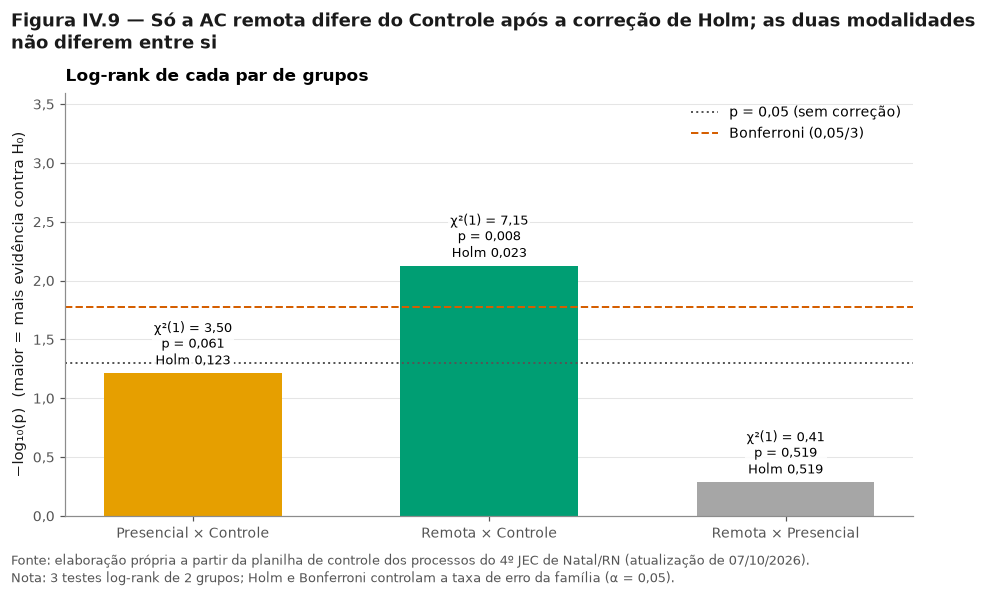

In [105]:
PARES = [('Controle', 'Presencial'), ('Controle', 'Remota'), ('Presencial', 'Remota')]
res_par = []
for a, b in PARES:
    sa, sb = sob[sob.grupo == a], sob[sob.grupo == b]
    r = logrank_test(sa['T'], sb['T'], sa['E'], sb['E'])
    res_par.append({'Par': f'{b} × {a}', 'χ² (1 g.l.)': r.test_statistic, 'p': r.p_value})
res_par = pd.DataFrame(res_par).set_index('Par')
res_par['p (Bonferroni)'] = multipletests(res_par['p'], method='bonferroni')[1]
res_par['p (Holm)'] = multipletests(res_par['p'], method='holm')[1]
sob_tabela(res_par, 'sob_logrank_pares', 'Log-rank par a par (2 grupos, 1 g.l.), com correção de Bonferroni e de Holm',
           secao='4.3.3', casas=2, colunas_p=('p', 'p (Bonferroni)', 'p (Holm)'), nota='destaque: p de Holm < 0,05.')

fig, ax = plt.subplots(figsize=(8.5, 4.6))
cores_par = [CORES_GRUPO['Presencial'], CORES_GRUPO['Remota'], CINZA]
xp = np.arange(len(res_par))
ax.bar(xp, -np.log10(res_par['p']), color=cores_par, width=0.6, edgecolor='white')
ax.axhline(-np.log10(0.05), color=TINTA_2, ls=':', lw=1.3, label='p = 0,05 (sem correção)')
ax.axhline(-np.log10(0.05 / 3), color=DESTAQUE, ls='--', lw=1.3, label='Bonferroni (0,05/3)')
for i, (c, p, ph) in enumerate(res_par[['χ² (1 g.l.)', 'p', 'p (Holm)']].values):
    ax.annotate(f'χ²(1) = {fmt_br(c, 2)}\n{p_txt(p)}\nHolm {fmt_p(ph)}', (i, -np.log10(p)), xytext=(0, 3),
                textcoords='offset points', ha='center', va='bottom', fontsize=8.5, bbox=CAIXA_TXT)
ax.set_xticks(xp, res_par.index); ax.grid(axis='x', visible=False)
ax.set_ylabel('−log₁₀(p)  (maior = mais evidência contra H₀)'); ax.set_title('Log-rank de cada par de grupos')
ax.legend(loc='upper right')
ax.set_ylim(0, max(-np.log10(res_par['p'])) * 1.55 + 0.3)
figura(fig, 'sob_logrank_pares', 'Só a AC remota difere do Controle após a correção de Holm; as duas modalidades não diferem entre si',
       secao='4.3.3', nota='3 testes log-rank de 2 grupos; Holm e Bonferroni controlam a taxa de erro da família (α = 0,05).')

### 4.3.4 Log-rank estratificado pelo mês de distribuição

O log-rank estratificado calcula O − E e a variância **dentro de cada mês** e só depois soma os estratos. Assim, compara cada grupo apenas com processos distribuídos no mesmo mês, com o mesmo seguimento potencial e o mesmo "momento" da vara. Isso neutraliza (i) a diferença de composição mensal dos grupos (julho com mais Remota) e (ii) qualquer tendência de calendário. Se o resultado estratificado for parecido com o não estratificado, o calendário não confunde a comparação — o esperado num experimento sorteado. O `lifelines` não oferece estratificação; usa-se `statsmodels.duration.survfunc.survdiff(..., strata=mês)`.

**Gráfico do teste:** Kaplan-Meier por grupo **dentro de cada mês** (os estratos que o teste combina).

Teste,χ² não estratificado,p não estratificado,χ² estratificado por mês,p estratificado por mês
Log-rank,"7,52","0,023","6,21","0,045"
Gehan-Breslow,"6,40","0,041","8,16","0,017"
Tarone-Ware,"7,82","0,020","8,09","0,018"


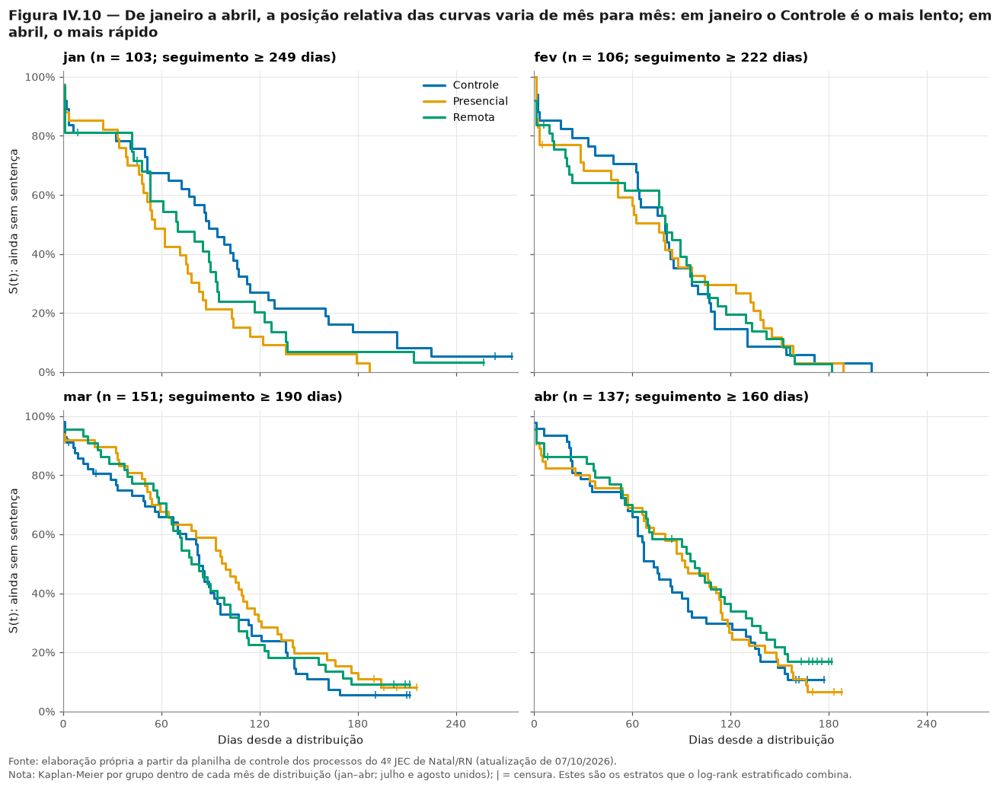

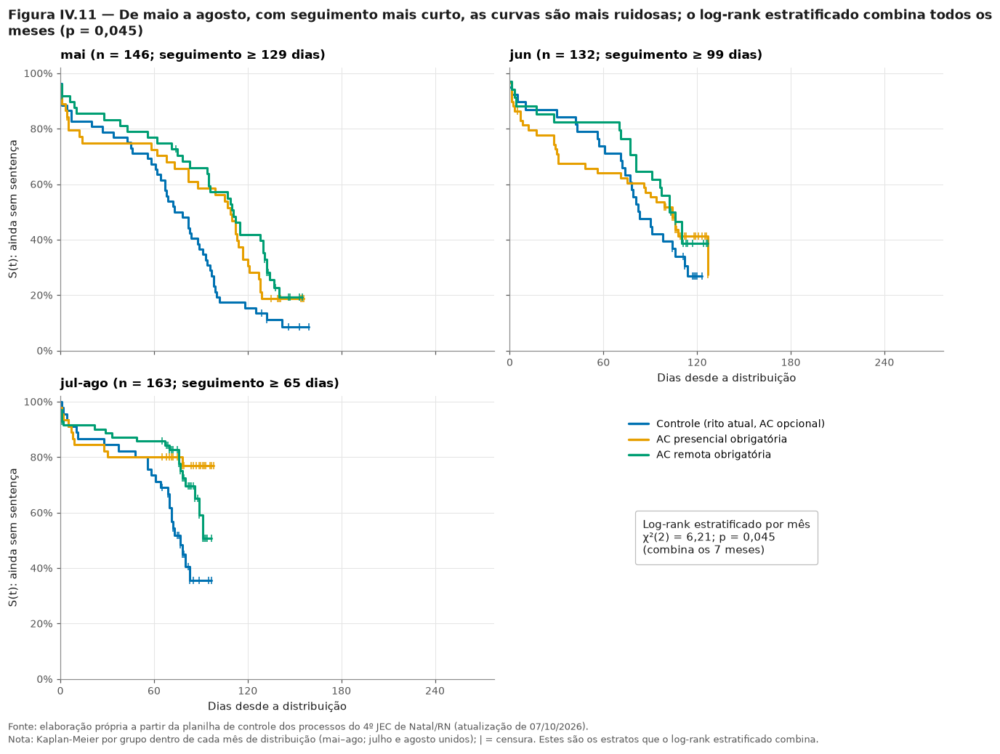

In [106]:
g_num = sob['grupo'].cat.codes.values
estr = []
for nome, kw in [('Log-rank', {}), ('Gehan-Breslow', {'weight_type': 'gb'}), ('Tarone-Ware', {'weight_type': 'tw'})]:
    chi_ne, p_ne = survdiff(sob['T'].values, sob['E'].values, g_num, **kw)
    chi_e, p_e = survdiff(sob['T'].values, sob['E'].values, g_num, strata=sob['mes_cod'].values, **kw)
    estr.append({'Teste': nome, 'χ² não estratificado': chi_ne, 'p não estratificado': p_ne,
                 'χ² estratificado por mês': chi_e, 'p estratificado por mês': p_e})
estr = pd.DataFrame(estr).set_index('Teste')
sob_tabela(estr, 'sob_logrank_estratificado', 'Testes de 3 grupos sem e com estratificação pelo mês de distribuição (2 g.l.)',
           secao='4.3.4', casas=2, colunas_p=('p não estratificado', 'p estratificado por mês'),
           destaque='p estratificado por mês', nota='statsmodels.duration.survfunc.survdiff; estratos = 7 meses (julho e agosto unidos).')
LR_ESTRAT_P = estr.loc['Log-rank', 'p estratificado por mês']
_ch_e = estr.loc['Log-rank', 'χ² estratificado por mês']

for parte, meses in [(1, MESES_SOB[:4]), (2, MESES_SOB[4:])]:
    fig, axes = plt.subplots(2, 2, figsize=(12, 8.6), sharex=True, sharey=True)
    for ax, m in zip(axes.flat, meses):
        sm_ = sob[sob.mes == m]
        plot_km(ax, sm_, tempo='T', evento='E', grupo='grupo', ic=False, tabela_risco=False, legenda=False,
                passo=60, tmax=275, xlabel=ROTULOS['dias'], ylabel='S(t): ainda sem sentença')
        eixo_pct(ax)
        ax.set_title(f'{m} (n = {len(sm_)}; seguimento ≥ {int(sm_.FU.min())} dias)')
        ax.label_outer()
    if len(meses) < 4:
        for ax in axes.flat[len(meses):]:
            ax.axis('off')
        axes.flat[-1].legend(handles=LEG_GRUPO(longo=True), loc='upper center', bbox_to_anchor=(0.5, 0.95))
        anotar_teste(axes.flat[-1], texto_teste('Log-rank estratificado por mês', f'χ²(2) = {fmt_br(_ch_e, 2)}', LR_ESTRAT_P,
                                                 extra='(combina os 7 meses)'), loc='center', tamanho=9.5)
        axes.flat[1].tick_params(labelbottom=True); axes.flat[1].set_xlabel(ROTULOS['dias'])
    else:
        axes.flat[0].legend(handles=LEG_GRUPO(), loc='upper right')
    titulo_mes = ('De janeiro a abril, a posição relativa das curvas varia de mês para mês: em janeiro o Controle é o mais '
                  'lento; em abril, o mais rápido' if parte == 1 else
                  f'De maio a agosto, com seguimento mais curto, as curvas são mais ruidosas; o log-rank estratificado '
                  f'combina todos os meses ({p_txt(LR_ESTRAT_P)})')
    figura(fig, f'sob_km_por_mes_{parte}', titulo_mes, secao='4.3.4',
           nota=f'Kaplan-Meier por grupo dentro de cada mês de distribuição ({"jan–abr" if parte == 1 else "mai–ago"}; '
                'julho e agosto unidos); | = censura. Estes são os estratos que o log-rank estratificado combina.')

### 4.3.5 Testes em pontos fixos do tempo (60, 90 e 120 dias)

Em vez de comparar as curvas inteiras, compara-se Ŝ(t₀) entre dois grupos num horizonte fixo. H₀: S_A(t₀) = S_B(t₀). A estatística é a diferença padronizada pelas variâncias de Greenwood (qui-quadrado com 1 g.l.; `survival_difference_at_fixed_point_in_time_test`). É um teste **sem hipótese de riscos proporcionais**, com leitura direta para gestão ("aos 90 dias, X% a mais dos processos ainda estão sem sentença"). Os horizontes de 60, 90 e 120 dias cobrem o período em que a AC já ocorreu e em que a maioria das sentenças acontece, e todos os processos da base têm seguimento potencial ≥ 65 dias (os de 90 e 120 dias perdem os distribuídos mais tarde, o que o KM corrige). São 6 testes (2 contrastes com o Controle × 3 horizontes), corrigidos por Holm.

**Gráfico do teste:** diferença Ŝ_tratado(t₀) − Ŝ_Controle(t₀) com IC 95% (Greenwood): valores **positivos** = mais processos pendentes no grupo com AC (mais lento).

t₀ (dias),Contraste,Ŝ grupo,Ŝ Controle,Diferença,IC 95% inf.,IC 95% sup.,χ² (1 g.l.),p,"p (Holm, 6 testes)"
60,Presencial − Controle,"66,3%","68,9%","-0,026","-0,1","0,0","0,47","0,491","0,491"
60,Remota − Controle,"73,6%","68,9%","0,047","-0,0","0,1","1,62","0,203","0,405"
90,Presencial − Controle,"52,3%","39,6%","0,127","0,0","0,2","9,54","0,002","0,010"
90,Remota − Controle,"53,7%","39,6%","0,140","0,1","0,2","11,16","< 0,001","0,005"
120,Presencial − Controle,"31,0%","23,0%","0,080","0,0","0,2","4,22","0,040","0,149"
120,Remota − Controle,"31,3%","23,0%","0,082","0,0","0,2","4,34","0,037","0,149"


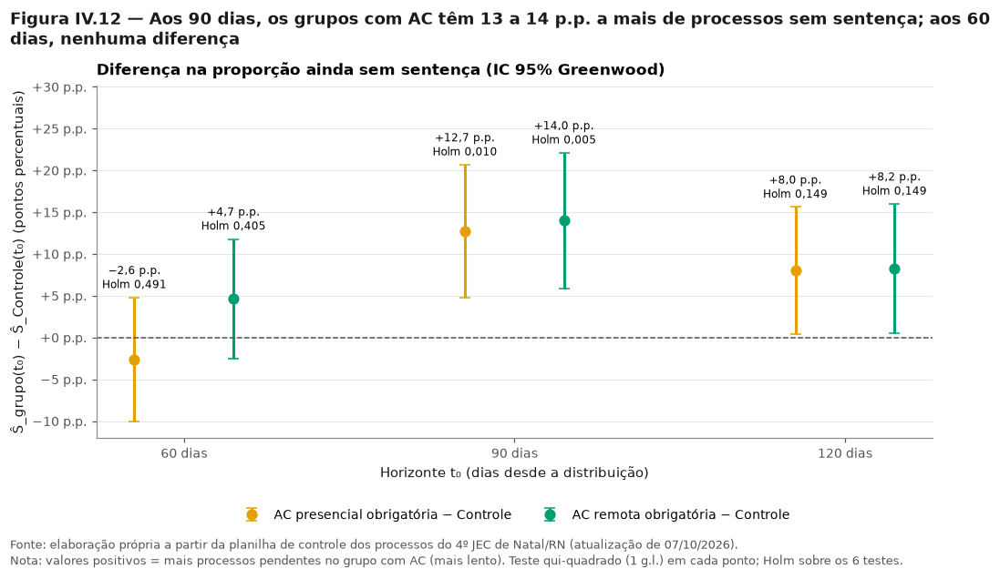

In [107]:
res_fix = []
for t0 in [60, 90, 120]:
    for g in ['Presencial', 'Remota']:
        r = survival_difference_at_fixed_point_in_time_test(t0, km_g[g], km_g['Controle'])
        sg, eg = km_greenwood(sob.loc[sob.grupo == g, 'T'], sob.loc[sob.grupo == g, 'E'], t0)
        sc, ec = km_greenwood(sob.loc[sob.grupo == 'Controle', 'T'], sob.loc[sob.grupo == 'Controle', 'E'], t0)
        dif, ep = sg - sc, np.sqrt(eg ** 2 + ec ** 2)
        res_fix.append({'t₀ (dias)': t0, 'Contraste': f'{g} − Controle', 'Ŝ grupo': sg, 'Ŝ Controle': sc,
                        'Diferença': dif, 'IC 95% inf.': dif - 1.96 * ep, 'IC 95% sup.': dif + 1.96 * ep,
                        'χ² (1 g.l.)': r.test_statistic, 'p': r.p_value})
res_fix = pd.DataFrame(res_fix)
res_fix['p (Holm, 6 testes)'] = multipletests(res_fix['p'], method='holm')[1]
sob_tabela(res_fix, 'sob_pontos_fixos', 'Diferença na proporção ainda sem sentença em 60, 90 e 120 dias (grupo com AC − Controle)',
           secao='4.3.5', casas=3, colunas_p=('p', 'p (Holm, 6 testes)'),
           formatos={'t₀ (dias)': 'int', 'Ŝ grupo': 'pct', 'Ŝ Controle': 'pct', 'χ² (1 g.l.)': 2},
           nota='diferença e IC 95% na escala de proporção (0,127 = 12,7 p.p.), com EP de Greenwood; χ² de '
                'survival_difference_at_fixed_point_in_time_test. Destaque: p de Holm < 0,05.')

fig, ax = plt.subplots(figsize=(9.5, 5))
for j, g in enumerate(['Presencial', 'Remota']):
    d = res_fix[res_fix.Contraste.str.startswith(g)]
    xs = np.arange(3) + (j - 0.5) * 0.3
    ax.errorbar(xs, d['Diferença'], yerr=[d['Diferença'] - d['IC 95% inf.'], d['IC 95% sup.'] - d['Diferença']],
                fmt='o', ms=7, color=CORES_GRUPO[g], capsize=4, label=f'{ROTULO_GRUPO[g]} − Controle')
    for xi, (v, dif, ph) in zip(xs, d[['IC 95% sup.', 'Diferença', 'p (Holm, 6 testes)']].values):
        ax.annotate(f'{100 * dif:+.1f} p.p.'.replace('.', ',', 1).replace('-', '−') + f'\nHolm {fmt_p(ph)}',
                    (xi, v), xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=8)
ax.axhline(0, color=TINTA_2, ls='--', lw=1); ax.set_xticks(range(3), ['60 dias', '90 dias', '120 dias'])
ax.grid(axis='x', visible=False)
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{100 * v:+.0f} p.p.'.replace('-', '−')))
ax.set_ylim(min(-0.08, res_fix['IC 95% inf.'].min() - 0.02), res_fix['IC 95% sup.'].max() + 0.08)
ax.set_xlabel('Horizonte t₀ (dias desde a distribuição)')
ax.set_ylabel('Ŝ_grupo(t₀) − Ŝ_Controle(t₀) (pontos percentuais)')
ax.set_title('Diferença na proporção ainda sem sentença (IC 95% Greenwood)')
legenda_abaixo(ax, ncol=2, dy=-0.17)
figura(fig, 'sob_pontos_fixos', 'Aos 90 dias, os grupos com AC têm 13 a 14 p.p. a mais de processos sem sentença; aos 60 dias, nenhuma diferença',
       secao='4.3.5', nota='valores positivos = mais processos pendentes no grupo com AC (mais lento). Teste qui-quadrado (1 g.l.) '
                           'em cada ponto; Holm sobre os 6 testes.')

### 4.3.6 Tempo médio restrito (RMST)

O **RMST** até o horizonte τ é a área sob a curva de Kaplan-Meier, μ_τ = ∫₀^τ S(t) dt (MORETTIN; SINGER, 2021, p. 248; ROYSTON; PARMAR, 2013). Leitura: "em média, nos primeiros τ dias após a distribuição, o processo permaneceu μ_τ dias sem sentença". A **diferença de RMST** entre grupos é uma medida de efeito em **dias**, que não exige riscos proporcionais e capta diferenças de qualquer forma (inclusive curvas que se cruzam). É o substituto correto do "tempo médio" que o notebook do professor calculava ignorando a censura (E14, E30).

**Escolha de τ.** O τ deve ser no máximo o menor dos seguimentos máximos dos grupos (273 dias), e com gente suficiente em risco para que Ŝ(t) seja estável até ele. Usam-se **τ = 150 dias** (cerca de 5 meses; > 30% de cada grupo ainda em observação) e **τ = 180 dias** (6 meses, o horizonte de gestão mais longo com informação razoável; ver a tabela de vida em 4.1.5). τ = 90 dias é mostrado como horizonte curto.

**Inferência.** O RMST é calculado com `restricted_mean_survival_time` do `lifelines` (conferido contra a soma da curva na grade diária). O IC de cada RMST **e** das diferenças vem de *bootstrap* (a opção `return_variance=True` do `lifelines` devolve a variância de min(T, τ) na população, e não a variância do estimador, e não serve para IC). As **diferenças** têm IC por *bootstrap* não paramétrico (2.000 reamostras **dentro de cada grupo**, preservando os tamanhos sorteados; IC percentil) e p-valor pela aproximação normal com o erro-padrão bootstrap. H₀: μ_τ,grupo = μ_τ,Controle.

**Gráficos do teste:** no primeiro, a área entre as curvas de cada grupo com AC e a do Controle é a diferença de RMST até 180 dias (com o resultado do teste anotado); no segundo, as diferenças com IC bootstrap para os três horizontes.

Conferência: RMST(180) Controle — lifelines 82,140 | grade diária 82,140


τ (dias),Grupo,RMST (dias),EP (bootstrap),IC 95% inf.,IC 95% sup.
90,Controle,"65,0","1,77","61,5","68,4"
90,Presencial,"64,9","1,96","61,0","68,7"
90,Remota,"69,2","1,75","65,9","72,6"
150,Controle,"79,3","2,76","73,8","84,7"
150,Presencial,"84,9","3,10","78,8","90,8"
150,Remota,"88,9","2,88","83,4","94,8"
180,Controle,"82,1","3,10","76,0","88,0"
180,Presencial,"88,6","3,40","82,0","95,3"
180,Remota,"92,9","3,24","86,9","99,4"


τ (dias),Contraste,Diferença (dias),IC 95% inf. (bootstrap),IC 95% sup. (bootstrap),"p (normal, EP bootstrap)"
90,Presencial − Controle,"-0,12","-5,0","5,3","0,965"
90,Remota − Controle,"4,21","-0,7","9,1","0,089"
90,Remota − Presencial,"4,32","-0,8","9,9","0,101"
150,Presencial − Controle,"5,64","-2,9","13,6","0,179"
150,Remota − Controle,"9,59","2,2","17,8","0,016"
150,Remota − Presencial,"3,95","-3,9","12,7","0,349"
180,Presencial − Controle,"6,46","-2,1","15,8","0,161"
180,Remota − Controle,"10,73","1,9","19,5","0,016"
180,Remota − Presencial,"4,26","-4,7","13,4","0,367"


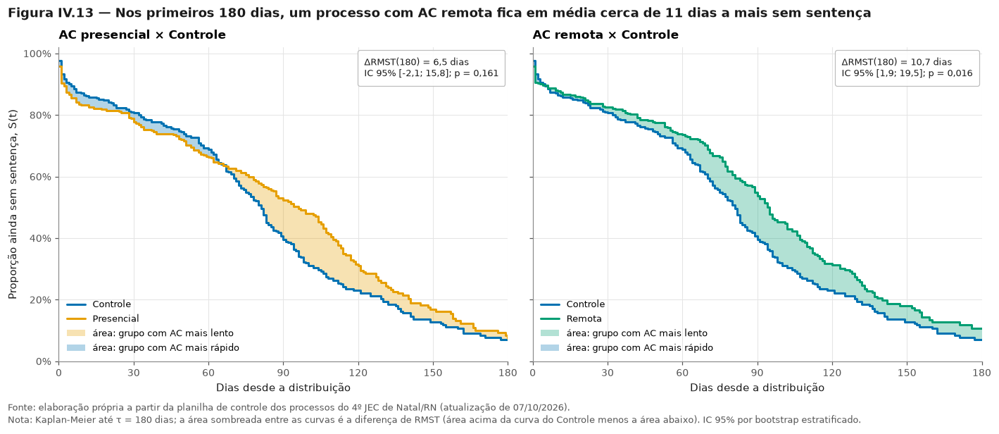

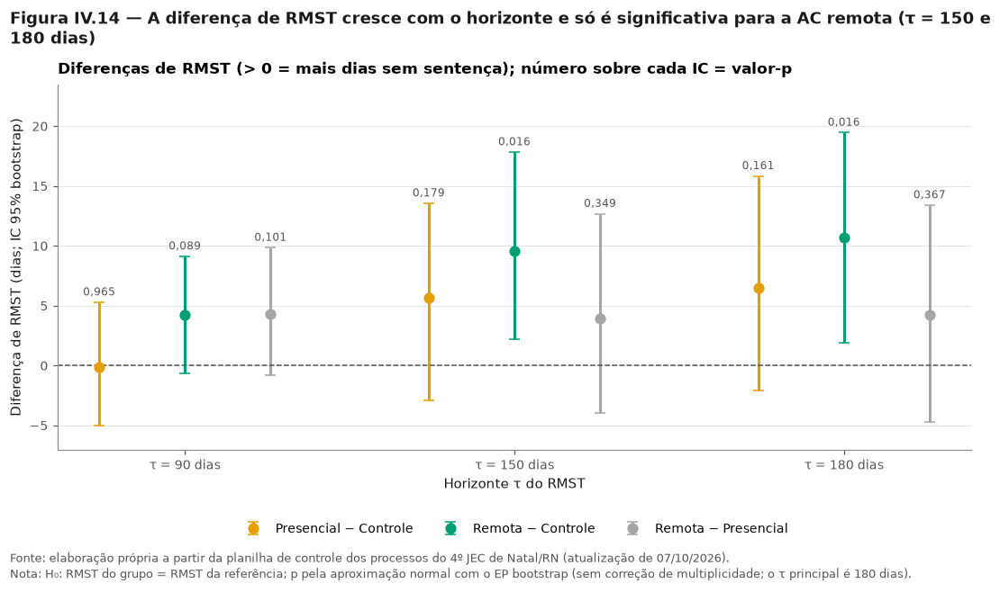

In [108]:
TAUS = [90, 150, 180]
B_BOOT = 2000
rng_boot = np.random.default_rng(SEMENTE + 41)
idx_g = {g: np.where(sob.grupo == g)[0] for g in ORDEM_GRUPO}
T_arr, E_arr = sob['T'].values.astype(int), sob['E'].values.astype(int)

linhas_rmst, dif_rmst, boot_rmst = [], [], {}
for tau in TAUS:
    # bootstrap estratificado por grupo
    bs = {g: np.empty(B_BOOT) for g in ORDEM_GRUPO}
    for b in range(B_BOOT):
        for g in ORDEM_GRUPO:
            ii = rng_boot.choice(idx_g[g], len(idx_g[g]), replace=True)
            bs[g][b] = rmst_grade(T_arr[ii], E_arr[ii], tau)
    boot_rmst[tau] = bs
    for g in ORDEM_GRUPO:
        m = restricted_mean_survival_time(km_g[g], t=tau)
        linhas_rmst.append({'τ (dias)': tau, 'Grupo': g, 'RMST (dias)': m, 'EP (bootstrap)': bs[g].std(ddof=1),
                            'IC 95% inf.': np.percentile(bs[g], 2.5), 'IC 95% sup.': np.percentile(bs[g], 97.5)})
    for a, b_ in [('Controle', 'Presencial'), ('Controle', 'Remota'), ('Presencial', 'Remota')]:
        est = rmst_grade(T_arr[idx_g[b_]], E_arr[idx_g[b_]], tau) - rmst_grade(T_arr[idx_g[a]], E_arr[idx_g[a]], tau)
        dist = bs[b_] - bs[a]; ep = dist.std(ddof=1)
        dif_rmst.append({'τ (dias)': tau, 'Contraste': f'{b_} − {a}', 'Diferença (dias)': est,
                         'IC 95% inf. (bootstrap)': np.percentile(dist, 2.5), 'IC 95% sup. (bootstrap)': np.percentile(dist, 97.5),
                         'p (normal, EP bootstrap)': 2 * stats.norm.sf(abs(est / ep))})
rmst_tab = pd.DataFrame(linhas_rmst)
dif_rmst = pd.DataFrame(dif_rmst)
print('Conferência: RMST(180) Controle — lifelines', fmt_br(rmst_tab.query('`τ (dias)` == 180 and Grupo == "Controle"')['RMST (dias)'].iloc[0], 3),
      '| grade diária', fmt_br(rmst_grade(T_arr[idx_g["Controle"]], E_arr[idx_g["Controle"]], 180), 3))
tabela(rmst_tab, 'sob_rmst_grupos', 'RMST por grupo e horizonte τ: dias, em média, sem sentença nos primeiros τ dias',
       secao='4.3.6', casas=1, formatos={'τ (dias)': 'int', 'EP (bootstrap)': 2},
       nota=f'RMST = área sob o Kaplan-Meier até τ (lifelines); EP e IC 95% percentil por bootstrap estratificado por grupo '
            f'({fmt_br(B_BOOT, 0)} reamostras).')
sob_tabela(dif_rmst, 'sob_rmst_diferencas', 'Diferenças de RMST entre grupos (dias; > 0 = mais dias sem sentença no 1º grupo)',
           secao='4.3.6', casas=2, colunas_p=('p (normal, EP bootstrap)',), formatos={'τ (dias)': 'int'},
           nota='IC 95% percentil por bootstrap; p pela aproximação normal com o EP bootstrap. Destaque: p < 0,05.')

# (a) a área entre as curvas é a diferença de RMST até 180 dias
tau = 180
tg = np.arange(0, tau + 1)
Sc, _ = aj_grade(T_arr[idx_g['Controle']], E_arr[idx_g['Controle']])
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, g in zip(axes, ['Presencial', 'Remota']):
    Sg, _ = aj_grade(T_arr[idx_g[g]], E_arr[idx_g[g]])
    ax.step(tg, Sc[tg], where='post', color=CORES_GRUPO['Controle'], lw=2, label='Controle')
    ax.step(tg, Sg[tg], where='post', color=CORES_GRUPO[g], lw=2, label=g)
    ax.fill_between(tg, Sc[tg], Sg[tg], step='post', where=Sg[tg] >= Sc[tg], color=CORES_GRUPO[g], alpha=0.3, lw=0,
                    label='área: grupo com AC mais lento')
    ax.fill_between(tg, Sc[tg], Sg[tg], step='post', where=Sg[tg] < Sc[tg], color=CORES_GRUPO['Controle'], alpha=0.3, lw=0,
                    label='área: grupo com AC mais rápido')
    d = dif_rmst.query('`τ (dias)` == @tau and Contraste == @g + " − Controle"').iloc[0]
    ax.set_title(f'AC {g.lower()} × Controle')
    ax.set_xlabel(ROTULOS['dias']); ax.set_xlim(0, tau); ax.set_xticks(np.arange(0, tau + 1, 30))
    ax.set_ylim(0, 1.02); eixo_pct(ax); ax.grid(axis='both', visible=True)
    ax.legend(loc='lower left', fontsize=8.5)
    anotar_teste(ax, texto_teste(f'ΔRMST({tau}) = {fmt_br(d["Diferença (dias)"], 1)} dias',
                                 f'IC 95% [{fmt_br(d["IC 95% inf. (bootstrap)"], 1)}; {fmt_br(d["IC 95% sup. (bootstrap)"], 1)}]',
                                 d['p (normal, EP bootstrap)']), loc='upper right')
axes[0].set_ylabel(ROTULOS['S'])
figura(fig, 'sob_rmst_areas', 'Nos primeiros 180 dias, um processo com AC remota fica em média cerca de 11 dias a mais sem sentença',
       secao='4.3.6', nota='Kaplan-Meier até τ = 180 dias; a área sombreada entre as curvas é a diferença de RMST (área '
                           'acima da curva do Controle menos a área abaixo). IC 95% por bootstrap estratificado.')

# (b) diferenças de RMST com IC bootstrap nos três horizontes
fig, ax = plt.subplots(figsize=(10, 5.2))
CONTRASTES_RMST = ['Presencial − Controle', 'Remota − Controle', 'Remota − Presencial']
for j, c in enumerate(CONTRASTES_RMST):
    d = dif_rmst[dif_rmst.Contraste == c]
    cor = [CORES_GRUPO['Presencial'], CORES_GRUPO['Remota'], CINZA][j]
    xs = np.arange(len(TAUS)) + (j - 1) * 0.26
    ax.errorbar(xs, d['Diferença (dias)'], yerr=[d['Diferença (dias)'] - d['IC 95% inf. (bootstrap)'],
                d['IC 95% sup. (bootstrap)'] - d['Diferença (dias)']], fmt='o', ms=7, color=cor, capsize=4, label=c)
    for xi, (hi, pv) in zip(xs, d[['IC 95% sup. (bootstrap)', 'p (normal, EP bootstrap)']].values):
        ax.annotate(fmt_p(pv), (xi, hi), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom',
                    fontsize=8, color=TINTA_2)
ax.axhline(0, color=TINTA_2, ls='--', lw=1)
ax.set_xticks(range(len(TAUS)), [f'τ = {t} dias' for t in TAUS]); ax.grid(axis='x', visible=False)
ax.set_xlabel('Horizonte τ do RMST')
ax.set_ylabel('Diferença de RMST (dias; IC 95% bootstrap)')
ax.set_title('Diferenças de RMST (> 0 = mais dias sem sentença); número sobre cada IC = valor-p')
ax.set_ylim(dif_rmst['IC 95% inf. (bootstrap)'].min() - 2, dif_rmst['IC 95% sup. (bootstrap)'].max() + 4)
legenda_abaixo(ax, ncol=3, dy=-0.17)
figura(fig, 'sob_rmst', 'A diferença de RMST cresce com o horizonte e só é significativa para a AC remota (τ = 150 e 180 dias)',
       secao='4.3.6', nota='H₀: RMST do grupo = RMST da referência; p pela aproximação normal com o EP bootstrap (sem correção '
                           'de multiplicidade; o τ principal é 180 dias).')

**Interpretação (comparação das curvas).**

**Teste principal.** Log-rank de 3 grupos: χ²₂ = 7,52, **p = 0,023**. Rejeita-se H₀ de curvas iguais a 5%. O gráfico O/E mostra a direção: o Controle teve 14% **mais** sentenças do que o esperado sob H₀ (O/E = 1,14), e os grupos com AC tiveram menos (0,96 presencial; 0,90 remota).

**Família ponderada (sensibilidade).**

| Teste | Peso | χ²₂ | p |
|---|---|---|---|
| Wilcoxon | início | 6,40 | 0,041 |
| Tarone-Ware | meio-termo | 7,82 | 0,020 |
| Peto-Prentice | início | 6,77 | 0,034 |
| FH(0,1) | final | 4,91 | 0,086 |
| **FH(1,1)** | **meio do seguimento** | **13,80** | **0,001** (Holm 0,007) |

O teste mais forte é o que dá mais peso ao **meio** do seguimento. Isso confirma o que o KM mostra: a diferença está concentrada na faixa de 60 a 120 dias, e não no início nem na cauda. O log-rank, que pesa tudo igualmente, perde parte do poder porque nos extremos as curvas quase coincidem.

**Pares (Holm).**

- **Remota × Controle: p = 0,008 (Holm 0,023)**, significativo;
- Presencial × Controle: p = 0,061 (Holm 0,123), não significativo isoladamente, mas na mesma direção;
- Remota × Presencial: p = 0,519. Não há evidência de diferença entre as modalidades.

**Estratificado por mês.** O log-rank estratificado dá χ²₂ = 6,21, **p = 0,045**; o Gehan-Breslow e o Tarone-Ware estratificados dão p = 0,017 e 0,018. O resultado sobrevive à comparação dentro de cada mês: não é artefato da composição mensal (por exemplo, julho com mais Remota).

**Pontos fixos (Holm sobre 6 testes).**

- Aos 60 dias não há diferença (p ≥ 0,2).
- **Aos 90 dias**, a proporção ainda sem sentença é **12,7 p.p. maior** na AC presencial (IC 95%: 4,7 a 20,7; p Holm = 0,010) e **14,0 p.p. maior** na remota (5,9 a 22,1; p Holm = 0,005).
- Aos 120 dias a diferença cai para cerca de 8 p.p. (p = 0,040 e 0,037 sem correção; 0,149 com Holm).

**RMST.** O efeito médio em dias é modesto.

| τ | RMST Controle | Remota − Controle | Presencial − Controle |
|---|---|---|---|
| 180 d | 82,1 dias | **+10,7 dias** (IC bootstrap 1,9 a 19,5; p = 0,016) | +6,5 dias (−2,1 a 15,8; p = 0,16) |
| 150 d | — | +9,6 dias (p = 0,016) | — |
| 90 d | — | +4,2 dias (ns) | −0,1 dia |

A τ = 90 dias, o atraso dos grupos com AC no fim do intervalo é compensado pelos processos presenciais que terminam mais cedo. Em linguagem de gestão: **nos primeiros seis meses, um processo do rito com AC remota passou, em média, cerca de 11 dias a mais sem sentença** do que no rito atual. Na presencial, cerca de 6 dias a mais, sem significância.

---

## 4.4 Diagnóstico da hipótese de riscos proporcionais

O modelo de Cox (seção 4.5) resume o efeito do grupo numa única razão de riscos, **constante no tempo**: λ(t | x) = λ₀(t) exp(x′β). Antes de interpretar esse número, verifica-se se a hipótese é razoável. Se não for, o HR estimado é uma média ponderada de efeitos que mudam ao longo do tempo, e pode até esconder efeitos de sinais opostos.

### 4.4.1 Método gráfico: log[−log Ŝ(t)] × log t

Sob riscos proporcionais, S_g(t) = S₀(t)^{exp(β_g)}, logo log[−log S_g(t)] = log[−log S₀(t)] + β_g: as curvas dos grupos devem ser **paralelas** (distância vertical constante = β_g). Curvas que se cruzam ou convergem indicam violação (COLOSIMO; GIOLO, 2006, p. 167). Se, além de paralelas, forem retas, o modelo de Weibull é indicado (p. 96-99). O método é subjetivo, por isso é complementado pelo teste formal.

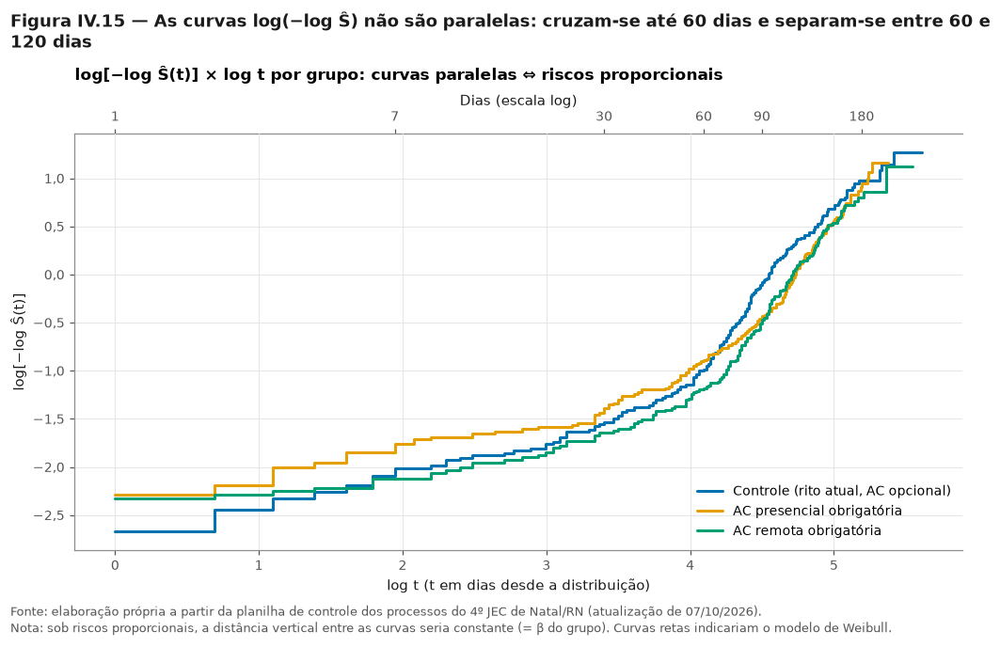

In [109]:
fig, ax = plt.subplots(figsize=(9.5, 5.4))
for g in ORDEM_GRUPO:
    sf_ = km_g[g].survival_function_.iloc[:, 0]
    sf_ = sf_[(sf_ > 0) & (sf_ < 1) & (sf_.index > 0)]
    ax.step(np.log(sf_.index), np.log(-np.log(sf_.values)), where='post', color=CORES_GRUPO[g], lw=2, label=ROTULO_GRUPO[g])
ax.set_xlabel('log t (t em dias desde a distribuição)'); ax.set_ylabel('log[−log Ŝ(t)]')
ax.grid(axis='both', visible=True)
sec = ax.secondary_xaxis('top', functions=(np.exp, np.log)); sec.set_xticks([1, 7, 30, 60, 90, 180])
sec.set_xlabel('Dias (escala log)')
sec.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: fmt_br(v, 0)))
ax.set_title('log[−log Ŝ(t)] × log t por grupo: curvas paralelas ⇔ riscos proporcionais', pad=10)
ax.legend(loc='lower right')
figura(fig, 'sob_loglog', 'As curvas log(−log Ŝ) não são paralelas: cruzam-se até 60 dias e separam-se entre 60 e 120 dias',
       secao='4.4.1', nota='sob riscos proporcionais, a distância vertical entre as curvas seria constante (= β do grupo). '
                           'Curvas retas indicariam o modelo de Weibull.')

### 4.4.2 Resíduos de Schoenfeld e teste de Grambsch-Therneau

Os **resíduos de Schoenfeld** comparam, em cada sentença, a covariável do processo sentenciado com a média ponderada das covariáveis dos que estavam em risco. Grambsch e Therneau (1994) mostraram que os resíduos **padronizados** s*_k somados a β̂ estimam β(t): se o efeito é constante, o gráfico de s*_k + β̂ contra uma função do tempo g(t) é **horizontal** (COLOSIMO; GIOLO, 2006, eq. 5.10, p. 167-169). O **teste** correspondente verifica a correlação entre os resíduos e g(t), por covariável (χ²₁) e globalmente (p. 169-170). As escolhas usuais de g(t) são t, log t, posto (*rank*) e 1 − KM ("na prática há pouca diferença"; o padrão do R é km, p. 170). O teste é aplicado ao modelo de Cox com grupo + mês (o modelo ajustado da seção 4.5), com as transformações posto, km e identidade (log t não é usado porque há sentenças no dia 0, e log 0 não existe).

- H₀: β_q(t) = β_q (efeito constante; riscos proporcionais);
- H₁: β_q(t) varia monotonicamente com g(t).

**Gráfico do teste:** s*_k + β̂ contra o posto do tempo e contra o tempo em dias, com suavização *lowess*; a linha tracejada é o β̂ constante do Cox. O eixo vertical está na escala do log-HR: **acima de 0 = sentença mais rápida que no Controle naquele momento; abaixo = mais lenta**.

g(t),Termo,χ² (1 g.l.),p
posto,AC presencial × Controle,"0,48","0,488"
posto,AC remota × Controle,"0,00","0,980"
1 − KM,AC presencial × Controle,"0,09","0,764"
1 − KM,AC remota × Controle,"0,04","0,841"
t (identidade),AC presencial × Controle,"0,27","0,600"
t (identidade),AC remota × Controle,"0,00","0,979"


Termo,χ² (1 g.l.),p
fev × jan,"2,08","0,149"
mar × jan,"1,53","0,215"
abr × jan,"1,14","0,286"
mai × jan,"2,98","0,084"
jun × jan,"0,74","0,389"
jul-ago × jan,"2,40","0,121"


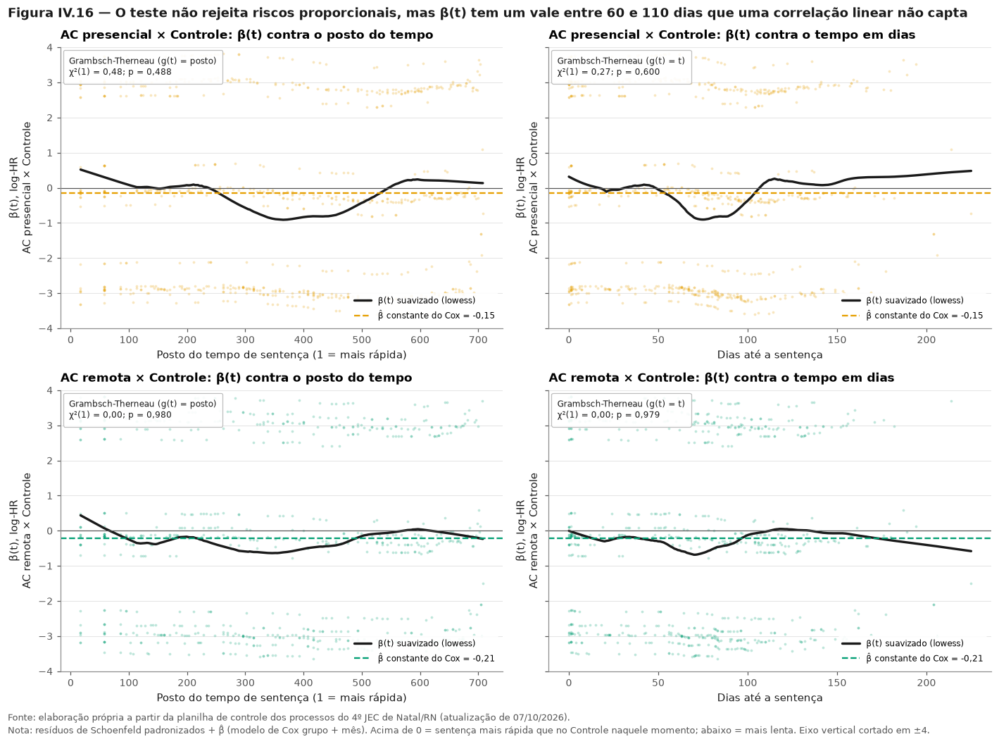

In [110]:
X_BASE = ['Presencial', 'Remota']
X_AJ = X_BASE + COLS_MES + ['origem_ext']
cox_ph = CoxPHFitter().fit(sob[['T', 'E'] + X_BASE + COLS_MES], 'T', 'E')
res_ph = []
for tr in ['rank', 'km', 'identity']:
    r = proportional_hazard_test(cox_ph, sob[['T', 'E'] + X_BASE + COLS_MES], time_transform=tr)
    sm_ = r.summary
    for termo in X_BASE:
        res_ph.append({'g(t)': tr, 'Termo': ROTULO_TERMO[termo], 'χ² (1 g.l.)': sm_.loc[termo, 'test_statistic'], 'p': sm_.loc[termo, 'p']})
res_ph = pd.DataFrame(res_ph)
NOME_GT = {'rank': 'posto', 'km': '1 − KM', 'identity': 't (identidade)'}
sob_tabela(res_ph.assign(**{'g(t)': res_ph['g(t)'].map(NOME_GT)}), 'sob_schoenfeld_grupo',
           'Teste de Grambsch-Therneau (resíduos de Schoenfeld) para os termos de grupo, por transformação do tempo',
           secao='4.4.2', casas=2, colunas_p=('p',), nota='modelo de Cox grupo + mês; H₀: efeito constante no tempo (riscos proporcionais).')
_r = proportional_hazard_test(cox_ph, sob[['T', 'E'] + X_BASE + COLS_MES], time_transform='rank').summary
sob_tabela(_r.loc[COLS_MES, ['test_statistic', 'p']].rename(index=ROTULO_TERMO, columns={'test_statistic': 'χ² (1 g.l.)'})
           .rename_axis('Termo'), 'sob_schoenfeld_meses',
           'Teste de Grambsch-Therneau para os termos de mês (transformação posto)', secao='4.4.2', casas=2, colunas_p=('p',))

sch = cox_ph.compute_residuals(sob[['T', 'E'] + X_BASE + COLS_MES], kind='scaled_schoenfeld')
t_ev = sob.loc[sch.index, 'T'].values
ordem_t = stats.rankdata(t_ev)
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey='row')
for i, termo in enumerate(X_BASE):
    beta = cox_ph.params_[termo]
    yv = sch[termo].values + beta
    for j, (xv, nome) in enumerate([(ordem_t, 'Posto do tempo de sentença (1 = mais rápida)'), (t_ev, 'Dias até a sentença')]):
        ax = axes[i, j]
        ax.scatter(xv, yv, s=6, color=CORES_GRUPO[termo], alpha=0.25, lw=0)
        lw = lowess(yv, xv, frac=0.3)
        ax.plot(lw[:, 0], lw[:, 1], color=TINTA, lw=2.2, label='β(t) suavizado (lowess)')
        ax.axhline(beta, color=CORES_GRUPO[termo], ls='--', lw=1.5, label=f'β̂ constante do Cox = {fmt_br(beta, 2)}')
        ax.axhline(0, color=TINTA_2, lw=0.8)
        ax.set_ylim(-4, 4); ax.set_xlabel(nome); ax.set_ylabel(f'β(t), log-HR\n{ROTULO_TERMO[termo]}')
        tr = 'rank' if j == 0 else 'identity'
        linha = res_ph[(res_ph['g(t)'] == tr) & (res_ph.Termo == ROTULO_TERMO[termo])].iloc[0]
        ax.set_title(f'{ROTULO_TERMO[termo]}: β(t) contra {"o posto do tempo" if j == 0 else "o tempo em dias"}')
        ax.legend(fontsize=8, loc='lower right', framealpha=0.9, frameon=True)
        anotar_teste(ax, texto_teste(f'Grambsch-Therneau (g(t) = {'posto' if tr == 'rank' else 't'})',
                                     f'χ²(1) = {fmt_br(linha["χ² (1 g.l.)"], 2)}', linha['p']), loc='upper left', tamanho=8)
figura(fig, 'sob_schoenfeld', 'O teste não rejeita riscos proporcionais, mas β(t) tem um vale entre 60 e 110 dias que '
       'uma correlação linear não capta', secao='4.4.2',
       nota='resíduos de Schoenfeld padronizados + β̂ (modelo de Cox grupo + mês). Acima de 0 = sentença mais rápida que no '
            'Controle naquele momento; abaixo = mais lenta. Eixo vertical cortado em ±4.')

**Interpretação (riscos proporcionais).**

- **Gráfico log(−log Ŝ).** As curvas **não são paralelas**:
  - nos primeiros ~30 dias, a AC presencial está *acima* das demais (mais sentenças precoces);
  - entre 30 e 60 dias as curvas se cruzam;
  - entre ~60 e 120 dias o Controle se afasta para cima (mais sentenças);
  - depois de ~150 dias as curvas voltam a se juntar.

  Esse é um padrão de efeito que **muda de sinal e de intensidade com o tempo**.
- **Teste de Grambsch-Therneau.** Não rejeita a proporcionalidade para nenhum termo: p = 0,49, 0,76 e 0,60 para a presencial (posto, km, t) e 0,98, 0,84 e 0,98 para a remota. Os meses também não violam a hipótese (p entre 0,08 e 0,39).
- **Por que o teste não detecta o que o gráfico mostra.** O teste mede a **correlação linear** entre os resíduos e g(t), ou seja, uma tendência *monótona* de β(t). A suavização *lowess* dos resíduos de Schoenfeld mostra outra forma: β(t) perto de zero no início, um **vale** entre ~60 e ~110 dias (β(t) ≈ −0,9, isto é, HR ≈ 0,4 na presencial) e retorno a zero depois. Um desvio em "U" tem correlação quase nula com o tempo, e o teste perde poder. Colosimo e Giolo (2006, p. 167-170) recomendam ler o gráfico junto com o teste.
- **Consequência.** O HR único do Cox (seção 4.5.1) é uma **média** de um efeito que se concentra numa janela. Por isso a seção 4.5.2 estima o efeito por janela de tempo, e o RMST e os pontos fixos (4.3), que não supõem proporcionalidade, são relatados ao lado do HR.

---

## 4.5 Modelos de Cox

O modelo de riscos proporcionais de Cox (COX, 1972) é λ(t | x) = λ₀(t) exp(x′β), com λ₀(t) não especificado. β é estimado pela verossimilhança parcial L(β) = ∏ [exp(x_i′β) / Σ_{j ∈ R(t_i)} exp(x_j′β)]^{δ_i} (COLOSIMO; GIOLO, 2006, eq. 5.6, p. 161). Como o tempo é medido em dias, há muitos **empates** (vários processos sentenciados no mesmo dia); usa-se a aproximação de **Efron** (1977), melhor que a de Breslow quando os empates são numerosos (p. 161-162), que é o padrão do `CoxPHFitter`.

**Interpretação.** exp(β_g) é a razão de riscos (HR) do grupo g em relação ao Controle (referência), constante no tempo (p. 162-164). Na linguagem do processo: HR = 0,80 significa que, a cada dia, um processo do grupo com AC que ainda está pendente tem 20% **menos** "chance instantânea" de receber sentença do que um processo do Controle também pendente, ou seja, **tramita mais devagar**.

**Modelos ajustados.**

| Modelo | Covariáveis | Para quê |
|---|---|---|
| (a) | grupo | efeito total do rito (o sorteio dispensa ajuste para não haver viés) |
| (b) | grupo + mês de distribuição + origem externa | precisão e controle do calendário (composição mensal, seguimento) |
| (b′) | grupo + origem externa, **estratificado por mês** | risco basal próprio de cada mês, sem supor efeito proporcional do mês |
| (c) | grupo × janela de tempo + mês + origem | efeito do rito **variando no tempo** (se os riscos não forem proporcionais) |

O **dia da semana** da distribuição não entra: não há mecanismo plausível pelo qual ele altere a duração (é apenas o dia do protocolo) e, com 7 níveis, só gastaria graus de liberdade. Os **acordos** (`acordo_ac`, `acordo_fora`) **não** entram como covariáveis: ocorrem durante o processo e definem o tipo de desfecho; usá-los como covariável fixa criaria viés de tempo imortal (seção 4.7 os trata como desfecho).

### 4.5.1 Modelos (a), (b) e (b′)

Termo,HR,IC 95% inf.,IC 95% sup.,p (Wald)
AC presencial × Controle,"0,839","0,7","1,0","0,053"
AC remota × Controle,"0,787","0,7","0,9","0,009"


Termo,HR,IC 95% inf.,IC 95% sup.,p (Wald)
AC presencial × Controle,"0,867","0,7","1,0","0,117"
AC remota × Controle,"0,809","0,7","1,0","0,022"
fev × jan,"1,134","0,9","1,5","0,379"
mar × jan,"0,825","0,6","1,1","0,154"
abr × jan,"0,806","0,6","1,1","0,120"
mai × jan,"0,832","0,6","1,1","0,192"
jun × jan,"0,703","0,5","1,0","0,023"
jul-ago × jan,"0,575","0,4","0,8","0,002"
Origem externa × 4º JEC,"0,776","0,4","1,5","0,455"


Termo,HR,IC 95% inf.,IC 95% sup.,p (Wald)
AC presencial × Controle,"0,856","0,7","1,0","0,091"
AC remota × Controle,"0,801","0,7","1,0","0,017"
Origem externa × 4º JEC,"0,847","0,4","1,6","0,624"


Modelo,log-verossimilhança parcial,TRV vs. nulo (χ²),g.l.,p (TRV),AIC parcial,Concordância (C de Harrell)
(a) grupo,"-4.232,6","7,36",2,"0,025","8.469,2","0,529"
(b) grupo + mês + origem,"-4.221,3","29,92",9,"< 0,001","8.460,7","0,564"
"(b′) grupo + origem, estrato = mês","-2.924,5","6,29",3,"0,098","5.855,1","0,531"


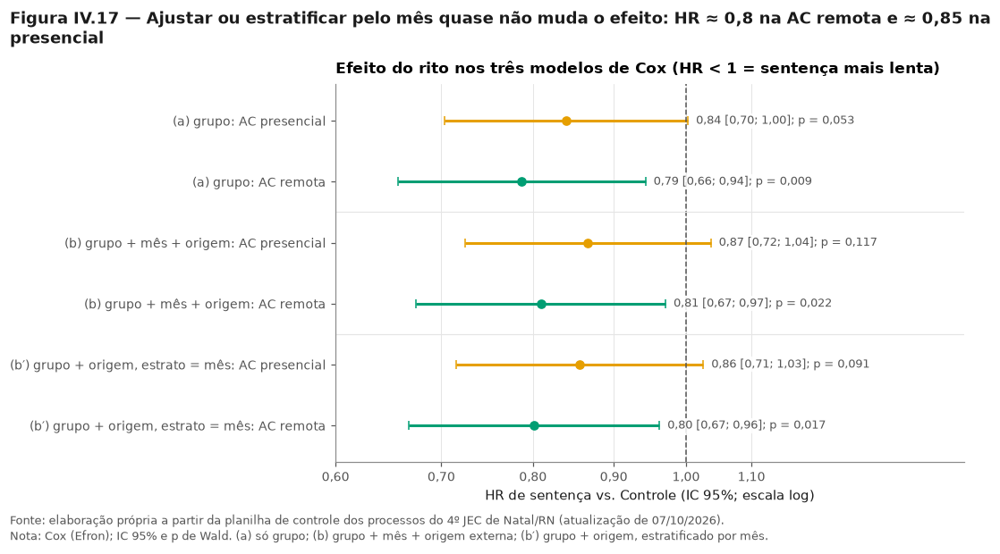

In [111]:
cox_a = CoxPHFitter().fit(sob[['T', 'E'] + X_BASE], 'T', 'E')
cox_b = CoxPHFitter().fit(sob[['T', 'E'] + X_AJ], 'T', 'E')
cox_bs = CoxPHFitter().fit(sob[['T', 'E', 'mes_cod'] + X_BASE + ['origem_ext']], 'T', 'E', strata=['mes_cod'])
MODELOS_COX = {'(a) grupo': cox_a, '(b) grupo + mês + origem': cox_b, "(b′) grupo + origem, estrato = mês": cox_bs}

for (nome, m), id_ in zip(MODELOS_COX.items(), ['sob_cox_a', 'sob_cox_b', 'sob_cox_bs']):
    sob_tabela(tabela_hr(m).rename_axis('Termo'), id_, f'Modelo de Cox {nome}: razões de risco de sentença (Efron)',
               secao='4.5.1', casas=3, colunas_p=('p (Wald)',),
               nota='HR < 1 = sentença mais lenta que na referência; IC 95% e p de Wald. Destaque: p < 0,05.')

def resumo_ajuste(m):
    lr = m.log_likelihood_ratio_test()
    return pd.Series({'log-verossimilhança parcial': m.log_likelihood_, 'TRV vs. nulo (χ²)': lr.test_statistic,
                      'g.l.': lr.degrees_freedom, 'p (TRV)': lr.p_value,
                      'AIC parcial': m.AIC_partial_, 'Concordância (C de Harrell)': m.concordance_index_})
ajuste_cox = pd.DataFrame({n: resumo_ajuste(m) for n, m in MODELOS_COX.items()}).T
sob_tabela(ajuste_cox.rename_axis('Modelo'), 'sob_cox_ajuste', 'Ajuste dos modelos de Cox: verossimilhança, TRV contra o nulo, '
           'AIC parcial e concordância', secao='4.5.1', casas=3, colunas_p=('p (TRV)',), destaque=None,
           formatos={'g.l.': 'int', 'log-verossimilhança parcial': 1, 'AIC parcial': 1, 'TRV vs. nulo (χ²)': 2},
           nota='o AIC parcial do modelo estratificado (b′) não é comparável ao dos outros (verossimilhança por estrato).')

_flor = pd.concat({nome: tabela_hr(m, X_BASE) for nome, m in MODELOS_COX.items()})
_flor.index = [f'{nome}: {termo.replace(" × Controle", "")}' for nome, termo in _flor.index]
fig, ax = plt.subplots(figsize=(10, 4.8))
floresta(ax, _flor, cor_de=lambda n: CORES_GRUPO['Presencial'] if 'presencial' in n else CORES_GRUPO['Remota'],
         xlabel='HR de sentença vs. Controle (IC 95%; escala log)', ticks=[0.6, 0.7, 0.8, 0.9, 1, 1.1])
ax.set_xlim(0.6, 1.5)
for yi in (1.5, 3.5):
    ax.axhline(yi, color=GRADE, lw=0.8)
ax.set_title('Efeito do rito nos três modelos de Cox (HR < 1 = sentença mais lenta)')
figura(fig, 'sob_cox_floresta', 'Ajustar ou estratificar pelo mês quase não muda o efeito: HR ≈ 0,8 na AC remota e ≈ 0,85 na presencial',
       secao='4.5.1', nota='Cox (Efron); IC 95% e p de Wald. (a) só grupo; (b) grupo + mês + origem externa; '
                           '(b′) grupo + origem, estratificado por mês.')
HR_B = tabela_hr(cox_b, X_BASE)

**Curvas de sobrevivência ajustadas.** Para mostrar o que o modelo (b) implica em escala de tempo, calcula-se a curva **padronizada** de cada grupo: atribui-se o grupo g a todos os 938 processos (mantidos o mês e a origem de cada um), prevê-se Ŝ(t | x) = Ŝ₀(t)^{exp(x′β̂)} (COLOSIMO; GIOLO, 2006, p. 164-165) e tira-se a média. É a curva que se observaria se toda a amostra tivesse sido alocada ao grupo g. As curvas de KM aparecem tracejadas para comparação: se o Cox é adequado, as duas devem estar próximas.

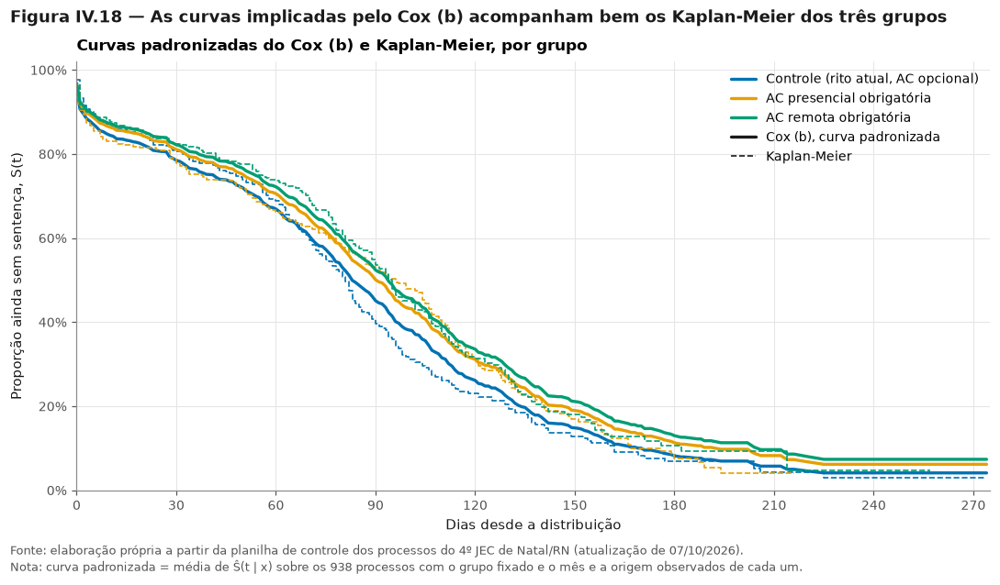

In [112]:
grade_t = np.arange(0, 275)
fig, ax = plt.subplots(figsize=(10, 5.2))
for g in ORDEM_GRUPO:
    x_g = sob[X_AJ].copy(); x_g['Presencial'] = int(g == 'Presencial'); x_g['Remota'] = int(g == 'Remota')
    S_pad = cox_b.predict_survival_function(x_g, times=grade_t).mean(axis=1)
    ax.plot(grade_t, S_pad, color=CORES_GRUPO[g], lw=2.2)
    sf_ = km_g[g].survival_function_.iloc[:, 0]
    ax.step(sf_.index, sf_.values, where='post', color=CORES_GRUPO[g], ls='--', lw=1.1)
ax.set_xlim(0, 275); ax.set_xticks(np.arange(0, 271, 30)); ax.set_ylim(0, 1.02); eixo_pct(ax)
ax.grid(axis='both', visible=True)
ax.set_xlabel(ROTULOS['dias']); ax.set_ylabel(ROTULOS['S'])
ax.set_title('Curvas padronizadas do Cox (b) e Kaplan-Meier, por grupo')
ax.legend(handles=LEG_GRUPO(longo=True) + [Line2D([], [], color=TINTA, lw=2.2, label='Cox (b), curva padronizada'),
                                           Line2D([], [], color=TINTA, lw=1.1, ls='--', label='Kaplan-Meier')],
          loc='upper right')
figura(fig, 'sob_cox_curvas', 'As curvas implicadas pelo Cox (b) acompanham bem os Kaplan-Meier dos três grupos',
       secao='4.5.1', nota='curva padronizada = média de Ŝ(t | x) sobre os 938 processos com o grupo fixado e o mês e a origem '
                           'observados de cada um.')

### 4.5.2 Efeito do rito variando no tempo: modelo (c) com janelas

Se os resíduos de Schoenfeld (4.4.2) mostram que o efeito do grupo muda com o tempo, um único HR é um resumo enganoso. A solução recomendada é permitir um coeficiente por **janela de tempo** (COLOSIMO; GIOLO, 2006, p. 170-172; MORETTIN; SINGER, 2021, p. 256, nota 2): cada processo é dividido em episódios (0, 30], (30, 90] e (90, ∞) dias, e o grupo entra interagido com a janela. Os cortes têm justificativa substantiva:

- **até 30 dias**: fase anterior à AC na maioria dos casos (citação, intimação e pauta); concentra as extinções imediatas e as redistribuições;
- **30 a 90 dias**: período em que as audiências obrigatórias ocorrem e em que se dão a ausência do autor (extinção, art. 51, I, da Lei 9.099/1995) e os acordos;
- **após 90 dias**: fase de instrução e julgamento de mérito.

O modelo é ajustado em formato de **processo de contagem** (início, fim] com o `CoxTimeVaryingFitter` (Efron). Como o `lifelines` exige início < fim, os tempos são deslocados em +0,5 dia (só a ordem dos tempos importa na verossimilhança parcial, logo o deslocamento não altera nada). A primeira célula confere que o modelo sem interação reproduz exatamente o Cox (b). O TRV compara (c) com (b): H₀: o HR de cada grupo é o mesmo nas três janelas (4 g.l.).

Conferência: HR Presencial, Cox (b) = 0,8666 | contagem sem interação = 0,8666
TRV (c) × (b): χ² = 11,04, 4 g.l., p = 0,026  |  AIC parcial (b) = 8.460,7; (c) = 8.457,6


Janela de tempo,Controle,Presencial,Remota
0–30 d,60,68,54
30–90 d,122,75,80
> 90 d,80,87,82


Termo,HR,IC 95% inf.,IC 95% sup.,p (Wald)
"AC presencial × Controle, 0–30 d","1,191","0,8","1,7","0,324"
"AC presencial × Controle, 30–90 d","0,616","0,5","0,8","< 0,001"
"AC presencial × Controle, > 90 d","1,010","0,7","1,4","0,947"
"AC remota × Controle, 0–30 d","0,934","0,6","1,4","0,718"
"AC remota × Controle, 30–90 d","0,634","0,5","0,8","0,002"
"AC remota × Controle, > 90 d","0,982","0,7","1,3","0,907"


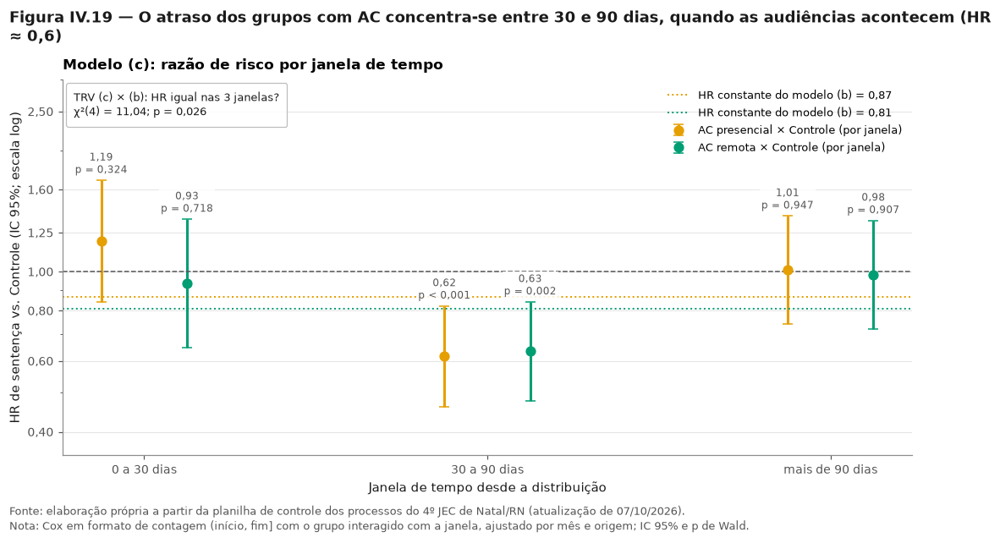

In [113]:
CORTES = [30, 90]
JANELAS = ['0–30 d', '30–90 d', '> 90 d']

def dividir_episodios(df, cortes=CORTES, desloc=0.5):
    """Formato de contagem (start, stop] com uma linha por processo e janela de tempo."""
    lim = [0.0] + [c + desloc for c in cortes] + [np.inf]
    partes = []
    for j in range(len(lim) - 1):
        a, b = lim[j], lim[j + 1]
        T = df['T'] + desloc
        sub = df[T > a].copy()
        Ts = sub['T'] + desloc
        sub['start'] = a; sub['stop'] = np.minimum(Ts, b)
        sub['ev'] = ((sub['E'] == 1) & (Ts <= b)).astype(int)
        sub['janela'] = j
        partes.append(sub)
    ep = pd.concat(partes).reset_index().rename(columns={'index': 'id'})
    for j in range(len(lim) - 1):
        for g in X_BASE:
            ep[f'{g}_j{j}'] = ep[g] * (ep['janela'] == j)
    return ep

ep = dividir_episodios(sob)
COLS_INT = [f'{g}_j{j}' for g in X_BASE for j in range(3)]
ctv_b = CoxTimeVaryingFitter().fit(ep[['id', 'start', 'stop', 'ev'] + X_AJ], id_col='id', event_col='ev', start_col='start', stop_col='stop')
ctv_c = CoxTimeVaryingFitter().fit(ep[['id', 'start', 'stop', 'ev'] + COLS_INT + COLS_MES + ['origem_ext']],
                                   id_col='id', event_col='ev', start_col='start', stop_col='stop')
print(f'Conferência: HR Presencial, Cox (b) = {fmt_br(np.exp(cox_b.params_["Presencial"]), 4)} | '
      f'contagem sem interação = {fmt_br(np.exp(ctv_b.params_["Presencial"]), 4)}')
trv_c = 2 * (ctv_c.log_likelihood_ - ctv_b.log_likelihood_)
P_TRV_C = stats.chi2.sf(trv_c, 4)
print(f'TRV (c) × (b): χ² = {fmt_br(trv_c, 2)}, 4 g.l., p = {p_br(P_TRV_C)}  |  '
      f'AIC parcial (b) = {fmt_br(-2 * ctv_b.log_likelihood_ + 2 * len(ctv_b.params_), 1)}; (c) = {fmt_br(-2 * ctv_c.log_likelihood_ + 2 * len(ctv_c.params_), 1)}')

hr_c = ctv_c.summary.loc[COLS_INT]
HR_C = pd.DataFrame({'HR': hr_c['exp(coef)'], 'IC 95% inf.': hr_c['exp(coef) lower 95%'], 'IC 95% sup.': hr_c['exp(coef) upper 95%'],
                     'p (Wald)': hr_c['p']})
HR_C.index = [f'{ROTULO_TERMO[g]}, {JANELAS[j]}' for g in X_BASE for j in range(3)]
eventos_jan = ep.groupby(['janela', 'grupo'], observed=True)['ev'].sum().unstack()
eventos_jan.index = JANELAS
_ej = eventos_jan.copy(); _ej.columns = [str(c) for c in _ej.columns]
tabela(_ej.rename_axis('Janela de tempo'), 'sob_cox_janelas_eventos', 'Sentenças em cada janela de tempo, por grupo',
       secao='4.5.2', formatos={c: 'int' for c in _ej.columns})
sob_tabela(HR_C.rename_axis('Termo'), 'sob_cox_janelas', 'Modelo (c): razão de risco de sentença por janela de tempo (Cox em '
           'formato de contagem, ajustado por mês e origem)', secao='4.5.2', casas=3, colunas_p=('p (Wald)',),
           nota=f'TRV (c) × (b): χ² = {fmt_br(trv_c, 2)}, 4 g.l., {p_txt(P_TRV_C)}. Destaque: p < 0,05.')

fig, ax = plt.subplots(figsize=(10, 5))
for i, g in enumerate(X_BASE):
    d = HR_C.iloc[3 * i:3 * i + 3]
    xs = np.arange(3) + (i - 0.5) * 0.25
    ax.errorbar(xs, d['HR'], yerr=[d['HR'] - d['IC 95% inf.'], d['IC 95% sup.'] - d['HR']], fmt='o', ms=7,
                color=CORES_GRUPO[g], capsize=4, label=f'{ROTULO_TERMO[g]} (por janela)')
    for xi, (hr, hi, pv) in zip(xs, d[['HR', 'IC 95% sup.', 'p (Wald)']].values):
        ax.annotate(f'{fmt_br(hr, 2)}\n{p_txt(pv)}', (xi, hi), xytext=(0, 3), textcoords='offset points', ha='center',
                    va='bottom', fontsize=8, color=TINTA_2, bbox=CAIXA_TXT)
    ax.axhline(np.exp(cox_b.params_[g]), color=CORES_GRUPO[g], ls=':', lw=1.3,
               label=f'HR constante do modelo (b) = {fmt_br(np.exp(cox_b.params_[g]), 2)}')
ax.axhline(1, color=TINTA_2, ls='--', lw=1); ax.set_yscale('log')
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: fmt_br(v, 2))); ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_yticks([0.4, 0.6, 0.8, 1, 1.25, 1.6, 2.5]); ax.set_ylim(0.35, 3)
ax.set_xticks(range(3), ['0 a 30 dias', '30 a 90 dias', 'mais de 90 dias']); ax.grid(axis='x', visible=False)
ax.set_xlabel('Janela de tempo desde a distribuição')
ax.set_ylabel('HR de sentença vs. Controle (IC 95%; escala log)')
ax.set_title('Modelo (c): razão de risco por janela de tempo')
ax.legend(loc='upper right', fontsize=8.5)
anotar_teste(ax, texto_teste('TRV (c) × (b): HR igual nas 3 janelas?', f'χ²(4) = {fmt_br(trv_c, 2)}', P_TRV_C), loc='upper left')
figura(fig, 'sob_cox_janelas', 'O atraso dos grupos com AC concentra-se entre 30 e 90 dias, quando as audiências acontecem (HR ≈ 0,6)',
       secao='4.5.2', nota='Cox em formato de contagem (início, fim] com o grupo interagido com a janela, ajustado por mês e '
                           'origem; IC 95% e p de Wald.')

### 4.5.3 Adequação global: resíduos de Cox-Snell

Os resíduos de Cox-Snell são ê_i = Λ̂₀(t_i) exp(x_i′β̂) (risco acumulado estimado de cada processo no seu próprio tempo). Se o modelo está bem ajustado, eles se comportam como uma amostra censurada de uma exponencial padrão, e o risco acumulado de Nelson-Aalen **dos próprios resíduos** fica sobre a reta de inclinação 1 (COLOSIMO; GIOLO, 2006, p. 166; eq. 4.11, p. 124). Esse resíduo avalia o ajuste global; **não** serve para testar riscos proporcionais (p. 166). Calcula-se como ê_i = δ_i − m̂_i, sendo m̂_i o resíduo martingal.

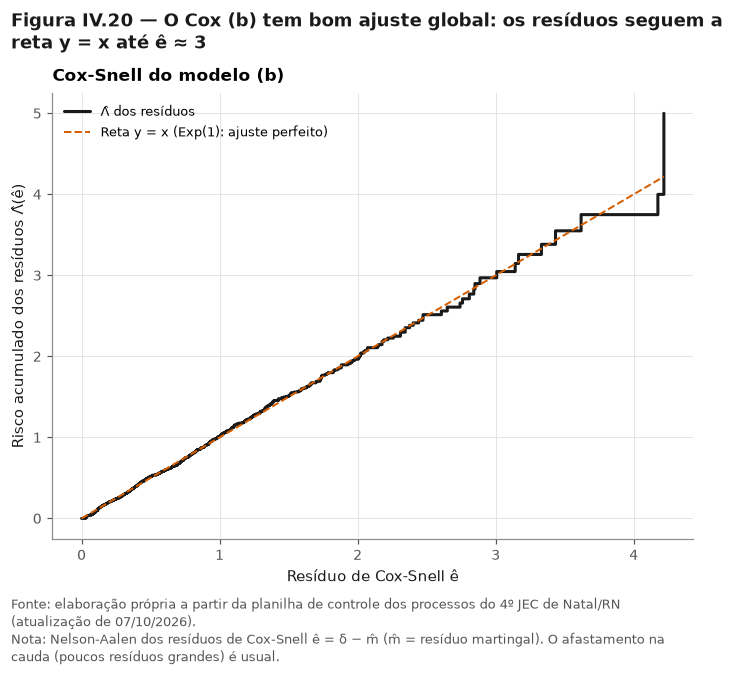

In [114]:
def cox_snell_plot(ax, ei, delta, titulo, cor=TINTA):
    na = NelsonAalenFitter().fit(ei, delta)
    ax.step(na.cumulative_hazard_.index, na.cumulative_hazard_.iloc[:, 0], where='post', color=cor, lw=2, label='Λ̂ dos resíduos')
    lim = float(np.nanmax(na.cumulative_hazard_.index[np.isfinite(na.cumulative_hazard_.iloc[:, 0])]))
    ax.plot([0, lim], [0, lim], color=DESTAQUE, ls='--', lw=1.3, label='Reta y = x (Exp(1): ajuste perfeito)')
    ax.set_xlabel('Resíduo de Cox-Snell ê'); ax.set_ylabel('Risco acumulado dos resíduos Λ̂(ê)')
    ax.set_title(titulo); ax.legend(fontsize=8.5, loc='upper left'); ax.grid(axis='both', visible=True)

mart_b = cox_b.compute_residuals(sob[['T', 'E'] + X_AJ], kind='martingale')
cs_b = sob.loc[mart_b.index, 'E'] - mart_b['martingale']
fig, ax = plt.subplots(figsize=(6.5, 5))
cox_snell_plot(ax, cs_b.values, sob.loc[mart_b.index, 'E'].values, 'Cox-Snell do modelo (b)')
figura(fig, 'sob_cox_snell', 'O Cox (b) tem bom ajuste global: os resíduos seguem a reta y = x até ê ≈ 3',
       secao='4.5.3', nota='Nelson-Aalen dos resíduos de Cox-Snell ê = δ − m̂ (m̂ = resíduo martingal). '
                           'O afastamento na cauda (poucos resíduos grandes) é usual.')

### 4.5.4 Resíduos martingal (forma funcional), deviance (atípicos) e dfbeta (influência)

- **Martingal** m̂_i = δ_i − ê_i: diferença entre o número observado de eventos do processo (0 ou 1) e o esperado pelo modelo. Contra uma covariável **não incluída**, a curva suavizada sugere a sua forma funcional (COLOSIMO; GIOLO, 2006, p. 172-173). Aqui, contra a **ordem de chegada** (1 a 938), ajustando um modelo só com o grupo: uma curva plana indica que não há tendência de calendário residual; uma curva inclinada indica que processos mais antigos/recentes têm mais/menos sentenças que o esperado, justificando o mês no modelo. É também o teste de tendência do calendário mencionado em 4.3.3.
- **Deviance** d̂_i = sinal(m̂_i)·√{−2[m̂_i + δ_i log(δ_i − m̂_i)]}: versão simétrica do martingal; valores com |d̂| > 2,5 apontam processos mal ajustados (eq. 5.11, p. 172-173).
- **dfbeta** Δβ̂_(i): variação no coeficiente do grupo quando o processo i é retirado (p. 173). Mede influência; destacam-se os processos com |Δβ̂| > 2/√n.

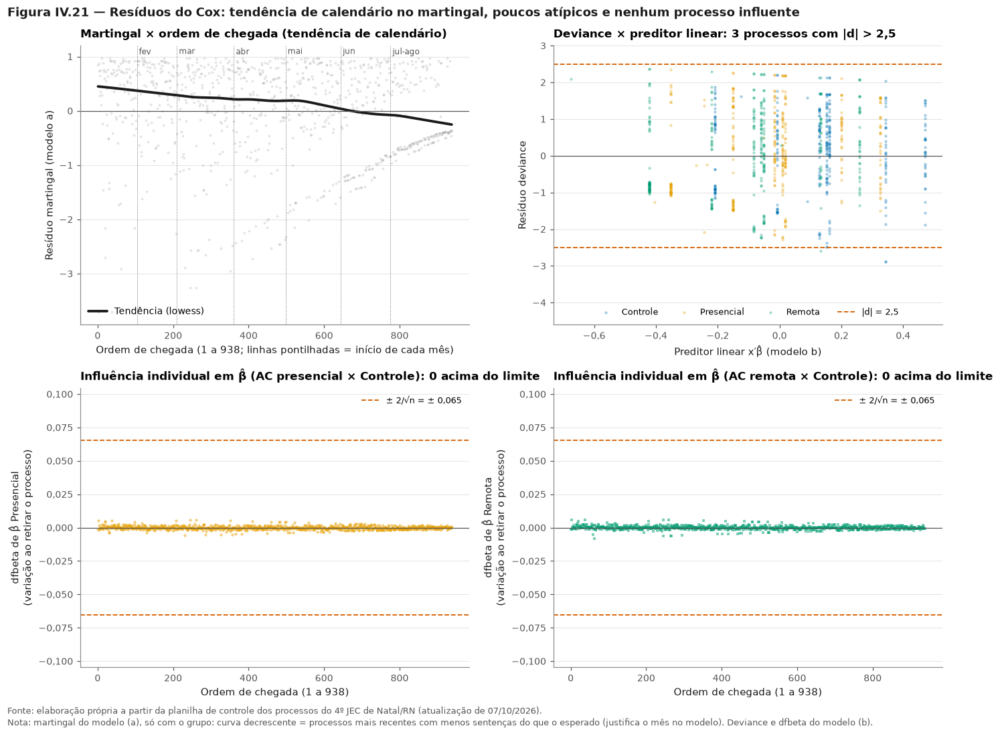

Deviance |d| > 2,5: 3 processos | |dfbeta| > 2/√n (= 0,065): Presencial 0, Remota 0
Maior |dfbeta| (Presencial): 0,0056 — frente a β̂ = -0,143 (EP 0,091)


Processo,Grupo,Mês,Desfecho,Tempo (dias),Sentença (δ),dfbeta Presencial,dfbeta Remota
0800987-86.2026.8.20.5004,Remota,jan,Ativo,257,0,"-0,0014","-0,0082"
0804047-67.2026.8.20.5004,Remota,mar,Ativo,209,0,"0,0000","-0,0061"
0804094-41.2026.8.20.5004,Remota,mar,Ativo,209,0,"0,0000","-0,0061"
0803708-11.2026.8.20.5004,Remota,mar,Ativo,212,0,"0,0000","-0,0061"
0800545-23.2026.8.20.5004,Controle,jan,Ativo,264,0,"0,0052","0,0058"


In [115]:
mart_a = cox_a.compute_residuals(sob[['T', 'E'] + X_BASE], kind='martingale')['martingale']
dev_b = cox_b.compute_residuals(sob[['T', 'E'] + X_AJ], kind='deviance')['deviance']
dfb_b = cox_b.compute_residuals(sob[['T', 'E'] + X_AJ], kind='delta_beta')
lp_b = cox_b.predict_log_partial_hazard(sob[X_AJ])

lim_dfb = 2 / np.sqrt(len(sob))
fig, axes = plt.subplots(2, 2, figsize=(13, 9.4))
ax = axes[0, 0]
ordem_m = sob.loc[mart_a.index, 'ordem'].values
ax.scatter(ordem_m, mart_a.values, s=6, alpha=0.3, color=CINZA, lw=0)
lw = lowess(mart_a.values, ordem_m, frac=0.3); ax.plot(lw[:, 0], lw[:, 1], color=TINTA, lw=2.5, label='Tendência (lowess)')
ax.axhline(0, color=TINTA_2, lw=0.8)
for m in MESES_SOB[1:]:
    x0 = sob.loc[sob.mes == m, 'ordem'].min()
    ax.axvline(x0, color=TINTA_2, lw=0.6, ls=':')
    ax.annotate(m, (x0, 1), xycoords=('data', 'axes fraction'), xytext=(2, -2), textcoords='offset points',
                fontsize=8, color=TINTA_2, va='top')
ax.set_xlabel('Ordem de chegada (1 a 938; linhas pontilhadas = início de cada mês)'); ax.set_ylabel('Resíduo martingal (modelo a)')
ax.set_title('Martingal × ordem de chegada (tendência de calendário)'); ax.legend(loc='lower left')

ax = axes[0, 1]
for g in ORDEM_GRUPO:
    ii = sob.loc[dev_b.index, 'grupo'] == g
    ax.scatter(lp_b.loc[dev_b.index][ii.values], dev_b.values[ii.values], s=8, alpha=0.35, color=CORES_GRUPO[g], lw=0, label=g)
ax.axhline(2.5, color=DESTAQUE, ls='--', lw=1.2, label='|d| = 2,5'); ax.axhline(-2.5, color=DESTAQUE, ls='--', lw=1.2)
ax.axhline(0, color=TINTA_2, lw=0.8)
ax.set_xlabel("Preditor linear x′β̂ (modelo b)"); ax.set_ylabel('Resíduo deviance')
ax.set_title(f'Deviance × preditor linear: {(dev_b.abs() > 2.5).sum()} processos com |d| > 2,5')
ax.set_ylim(-4.6, 3.0); ax.legend(loc='lower center', fontsize=8.5, ncol=4)

for ax, termo, mk in [(axes[1, 0], 'Presencial', 'o'), (axes[1, 1], 'Remota', 's')]:
    ax.scatter(sob.loc[dfb_b.index, 'ordem'], dfb_b[termo], s=8, alpha=0.5, marker=mk, color=CORES_GRUPO[termo], lw=0)
    ax.axhline(lim_dfb, color=DESTAQUE, ls='--', lw=1.2, label=f'± 2/√n = ± {fmt_br(lim_dfb, 3)}')
    ax.axhline(-lim_dfb, color=DESTAQUE, ls='--', lw=1.2)
    ax.axhline(0, color=TINTA_2, lw=0.8)
    ax.set_xlabel(ROTULOS['ordem_chegada'])
    ax.set_ylabel(f'dfbeta de β̂ {termo}\n(variação ao retirar o processo)')
    ax.set_title(f'Influência individual em β̂ ({ROTULO_TERMO[termo]}): '
                 f'{(dfb_b[termo].abs() > lim_dfb).sum()} acima do limite')
    ax.set_ylim(-lim_dfb * 1.6, lim_dfb * 1.6)
    ax.legend(loc='upper right', fontsize=8.5)
figura(fig, 'sob_cox_residuos', 'Resíduos do Cox: tendência de calendário no martingal, poucos atípicos e nenhum processo influente',
       secao='4.5.4', nota='martingal do modelo (a), só com o grupo: curva decrescente = processos mais recentes com menos sentenças '
                           'do que o esperado (justifica o mês no modelo). Deviance e dfbeta do modelo (b).')

print(f'Deviance |d| > 2,5: {(dev_b.abs() > 2.5).sum()} processos | |dfbeta| > 2/√n (= {fmt_br(lim_dfb, 3)}): '
      f'Presencial {(dfb_b["Presencial"].abs() > lim_dfb).sum()}, Remota {(dfb_b["Remota"].abs() > lim_dfb).sum()}')
print(f'Maior |dfbeta| (Presencial): {fmt_br(dfb_b["Presencial"].abs().max(), 4)} — frente a β̂ = {fmt_br(cox_b.params_["Presencial"], 3)} '
      f'(EP {fmt_br(cox_b.standard_errors_["Presencial"], 3)})')
top = dfb_b[X_BASE].abs().max(axis=1).sort_values(ascending=False).head(5).index
_top = (sob.loc[top, ['processo', 'grupo', 'mes', 'tipo_desfecho', 'T', 'E']]
        .assign(dfbeta_Presencial=dfb_b.loc[top, 'Presencial'], dfbeta_Remota=dfb_b.loc[top, 'Remota'])
        .rename(columns={'processo': 'Processo', 'grupo': 'Grupo', 'mes': 'Mês', 'tipo_desfecho': 'Desfecho',
                         'T': 'Tempo (dias)', 'E': 'Sentença (δ)', 'dfbeta_Presencial': 'dfbeta Presencial',
                         'dfbeta_Remota': 'dfbeta Remota'})
        .reset_index(drop=True))
tabela(_top, 'sob_cox_influentes', 'Os cinco processos de maior influência (|dfbeta|) nos coeficientes do grupo, modelo (b)',
       secao='4.5.4', formatos={'dfbeta Presencial': 4, 'dfbeta Remota': 4, 'Tempo (dias)': 'int', 'Sentença (δ)': 'int'},
       nota=f'limite de referência 2/√n = {fmt_br(lim_dfb, 3)}; processos acima dele: '
            f'{int((dfb_b[X_BASE].abs() > lim_dfb).any(axis=1).sum())}.')

**Interpretação (modelos de Cox).**

**Efeito do rito (HR < 1 = sentença mais lenta).**

| Modelo | AC presencial × Controle | AC remota × Controle |
|---|---|---|
| (a) só grupo | HR = 0,84 (IC 95%: 0,70–1,00; p = 0,053) | **HR = 0,79 (0,66–0,94; p = 0,009)** |
| (b) + mês + origem | 0,87 (0,72–1,04; p = 0,117) | **0,81 (0,68–0,97; p = 0,022)** |
| (b′) estratificado por mês | 0,86 (p = 0,091) | **0,80 (p = 0,017)** |

O ajuste pelo calendário quase não altera os HRs, o que é o esperado num experimento sorteado: o mês melhora a precisão, mas não confunde o efeito. Em linguagem jurídica: **a cada dia, um processo pendente no rito com AC remota tem cerca de 19% menos "chance" de ser sentenciado** do que um processo pendente no rito atual. Na AC presencial, a redução é de cerca de 13%, compatível com zero.

**Calendário.** Os processos distribuídos em junho (HR = 0,70; p = 0,023) e em julho–agosto (HR = 0,58; p = 0,002) tramitam mais devagar que os de janeiro. Possíveis razões: o acúmulo de pauta ao longo do ano e o recesso/férias de julho. O resíduo martingal contra a ordem de chegada (modelo só com grupo) tem tendência decrescente, o que confirma essa tendência de calendário e justifica o mês no modelo. É o "teste de tendência" que faz sentido aqui (o do grupo não faz; ver 4.3.3). A origem externa não tem efeito detectável (HR = 0,78; p = 0,46; só 12 processos).

**Ajuste e discriminação.**

- O TRV do modelo (b) contra o nulo é χ²₉ = 29,9 (p < 0,001); o AIC parcial cai de 8.469,2 em (a) para 8.460,7 em (b).
- A concordância é baixa (C = 0,53 a 0,56). O grupo e o mês **explicam pouco da variação individual** do tempo: o rito desloca a distribuição, mas a duração de cada processo depende sobretudo de fatores não medidos (complexidade, comportamento das partes, pauta).
- O Cox-Snell do modelo (b) fica sobre a reta y = x até ê ≈ 3, o que indica bom ajuste global.
- Há 3 resíduos deviance além de ±2,5, e nenhum processo tem |dfbeta| acima de 2/√n (o maior é 0,006, frente a um β̂ de −0,14 e EP de 0,09). **Nenhum processo isolado sustenta o resultado.**
- As curvas padronizadas do Cox acompanham bem os KMs.

**Efeito por janela de tempo, modelo (c).** O efeito do rito **não é constante**. O TRV contra o modelo (b) dá χ²₄ = 11,04 (p = 0,026), e o AIC parcial cai de 8.460,7 para 8.457,6.

| Janela | AC presencial × Controle | AC remota × Controle |
|---|---|---|
| 0–30 dias | 1,19 (0,84–1,69) | 0,93 (0,65–1,35) |
| **30–90 dias** | **0,62 (0,46–0,82; p < 0,001)** | **0,63 (0,48–0,84; p = 0,002)** |
| > 90 dias | 1,01 (0,74–1,38) | 0,98 (0,72–1,34) |

Entre 30 e 90 dias, o Controle produziu 122 sentenças, contra 75 e 80 nos grupos com AC. Leitura: **no período em que as audiências obrigatórias acontecem, os processos dos grupos com AC são sentenciados a uma taxa cerca de 37% menor**. Antes disso, a taxa é igual (ou ligeiramente maior na presencial). Depois de 90 dias, a taxa volta a ser a mesma do Controle, mas os grupos com AC **não recuperam** o atraso acumulado. O efeito da AC obrigatória é, portanto, uma **etapa adicional que retarda as sentenças por cerca de dois meses**, e não uma lentidão uniforme.

---

## 4.6 Modelos paramétricos de tempo de vida acelerado (AFT)

O modelo AFT escreve o **logaritmo do tempo** como uma regressão: log T = α + x′β + σν, isto é, T = exp(x′β)·T₀. As covariáveis **esticam ou encolhem** a escala do tempo, e exp(β) é a **razão de tempos** (TR): TR = 1,20 significa que os quantis do tempo até a sentença (inclusive a mediana) são 20% **maiores** no grupo (COLOSIMO; GIOLO, 2006, eq. 4.10, p. 122; interpretação na seção 4.4, p. 127-129; MORETTIN; SINGER, 2021, p. 254-255). É a apresentação mais intuitiva para gestores, e não depende da hipótese de riscos proporcionais, mas sim de uma **forma distribucional** para ν.

A escolha da distribuição **marginal** do tempo foi feita na Parte II; aqui ajustam-se as três famílias candidatas **condicionalmente** a grupo + mês:

- **Weibull**: risco monótono; é o único modelo que é ao mesmo tempo AFT e de riscos proporcionais (COLOSIMO; GIOLO, 2006, p. 198);
- **log-normal** e **log-logística**: risco que sobe e depois desce (p. 75-79).

Usa-se `tempo_pos` (os 38 tempos zero viram 0,5 dia, pois log 0 não existe). A comparação é pelo **AIC** (modelos não encaixados; p. 100-101), e a adequação pelos **resíduos de Cox-Snell** ê_i = −log Ŝ(t_i | x_i) (seção 4.3, p. 123-125). A mediana prevista por grupo é **padronizada** (média das curvas previstas sobre a distribuição observada dos meses), como em 4.5.1.

Modelo,Termo,Razão de tempos,IC 95% inf.,IC 95% sup.,p (Wald)
Weibull,AC presencial × Controle,"1,112","0,9","1,3","0,258"
Weibull,AC remota × Controle,"1,205","1,0","1,5","0,051"
Log-normal,AC presencial × Controle,"1,013","0,8","1,4","0,934"
Log-normal,AC remota × Controle,"1,218","0,9","1,6","0,198"
Log-logística,AC presencial × Controle,"1,102","0,9","1,4","0,436"
Log-logística,AC remota × Controle,"1,247","1,0","1,6","0,074"


Modelo,log-verossimilhança,nº parâmetros,AIC,ΔAIC
Weibull,"-3.969,0",10,"7.958,0","0,0"
Log-normal,"-4.126,5",10,"8.273,0","315,0"
Log-logística,"-4.075,1",10,"8.170,2","212,2"


Modelo,Controle,Presencial,Remota
Weibull,68,75,82
Log-normal,61,62,74
Log-logística,72,79,89
Kaplan-Meier (não paramétrico),81,96,95


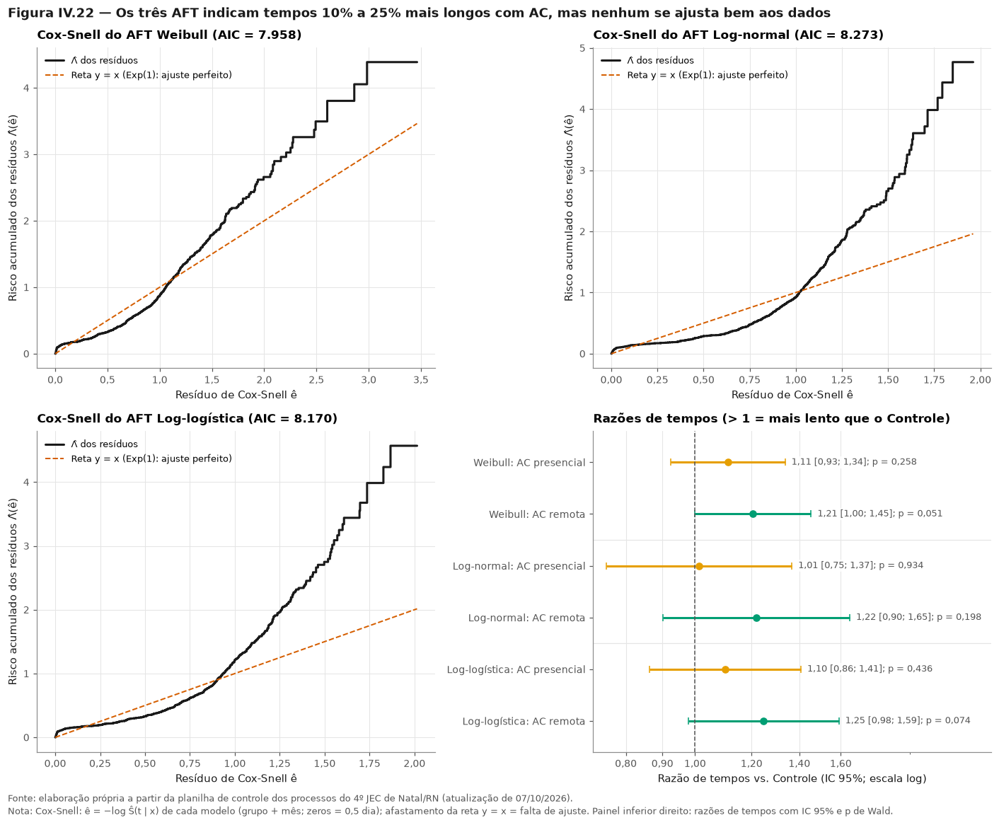

In [116]:
X_AFT = X_BASE + COLS_MES
base_aft = sob[['T_pos', 'E'] + X_AFT]
AFTS = {'Weibull': WeibullAFTFitter(), 'Log-normal': LogNormalAFTFitter(), 'Log-logística': LogLogisticAFTFitter()}
for m in AFTS.values():
    m.fit(base_aft, 'T_pos', 'E')

tr_linhas, aic = [], {}
for nome, m in AFTS.items():
    t = tabela_hr(m, X_BASE, rotulo='Razão de tempos')
    t.insert(0, 'Modelo', nome)
    tr_linhas.append(t)
    aic[nome] = {'log-verossimilhança': m.log_likelihood_, 'nº parâmetros': len(m.params_), 'AIC': m.AIC_}
aic = pd.DataFrame(aic).T
aic['ΔAIC'] = aic['AIC'] - aic['AIC'].min()
TR_AFT = pd.concat(tr_linhas)
sob_tabela(TR_AFT.rename_axis('Termo').reset_index()[['Modelo', 'Termo', 'Razão de tempos', 'IC 95% inf.', 'IC 95% sup.', 'p (Wald)']],
           'sob_aft_tr', 'Razões de tempos dos grupos com AC vs. Controle nos três modelos AFT (ajustados por mês)',
           secao='4.6', casas=3, colunas_p=('p (Wald)',),
           nota='razão de tempos > 1 = tempo até a sentença mais longo que no Controle; IC 95% e p de Wald. Destaque: p < 0,05.')
sob_tabela(aic.rename_axis('Modelo'), 'sob_aft_aic', 'Comparação dos modelos AFT pelo AIC', secao='4.6', casas=1, destaque=None,
           formatos={'nº parâmetros': 'int'}, nota='ΔAIC = AIC − menor AIC; modelos não encaixados.')
MELHOR_AFT = aic['AIC'].idxmin()

# mediana padronizada por grupo
med_aft = {}
grade_aft = np.arange(1, 400)
for nome, m in AFTS.items():
    med_aft[nome] = {}
    for g in ORDEM_GRUPO:
        x_g = sob[X_AFT].copy(); x_g['Presencial'] = int(g == 'Presencial'); x_g['Remota'] = int(g == 'Remota')
        S_pad = m.predict_survival_function(x_g, times=grade_aft).mean(axis=1)
        med_aft[nome][g] = float(S_pad.index[np.argmax(S_pad.values <= 0.5)])
med_aft = pd.DataFrame(med_aft).T
med_aft.loc['Kaplan-Meier (não paramétrico)'] = [MEDIANAS[g] for g in ORDEM_GRUPO]
_ma = med_aft.copy(); _ma.columns = [str(c) for c in _ma.columns]
tabela(_ma.rename_axis('Modelo'), 'sob_aft_medianas', 'Mediana prevista do tempo até a sentença (dias), padronizada pela '
       'distribuição dos meses, comparada à do Kaplan-Meier', secao='4.6', casas=0)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
T_u = np.unique(sob['T_pos'])
for ax, (nome, m) in zip(axes.flat[:3], AFTS.items()):
    ch = m.predict_cumulative_hazard(base_aft[X_AFT], times=T_u)       # (tempos × processos)
    pos = np.searchsorted(T_u, sob['T_pos'].values)
    ei = ch.values[pos, np.arange(len(sob))]
    cox_snell_plot(ax, ei, sob['E'].values, f'Cox-Snell do AFT {nome} (AIC = {fmt_br(m.AIC_, 0)})')
ax = axes.flat[3]
_tr = TR_AFT.copy()
_tr.index = [f'{n}: {t.replace(" × Controle", "")}' for n, t in zip(_tr['Modelo'], _tr.index)]
floresta(ax, _tr, rotulo='Razão de tempos', cor_de=lambda n: CORES_GRUPO['Presencial'] if 'presencial' in n else CORES_GRUPO['Remota'],
         xlabel='Razão de tempos vs. Controle (IC 95%; escala log)', ticks=[0.8, 0.9, 1, 1.2, 1.4, 1.6])
ax.set_xlim(0.72, 2.6)
for yi in (1.5, 3.5):
    ax.axhline(yi, color=GRADE, lw=0.8)
ax.set_title('Razões de tempos (> 1 = mais lento que o Controle)')
figura(fig, 'sob_aft', 'Os três AFT indicam tempos 10% a 25% mais longos com AC, mas nenhum se ajusta bem aos dados',
       secao='4.6', nota='Cox-Snell: ê = −log Ŝ(t | x) de cada modelo (grupo + mês; zeros = 0,5 dia); afastamento da reta y = x = '
                         'falta de ajuste. Painel inferior direito: razões de tempos com IC 95% e p de Wald.')

**Interpretação (AFT).**

- **Razões de tempos (TR > 1 = mais lento):**

  | Modelo | AC presencial × Controle | AC remota × Controle |
  |---|---|---|
  | Weibull | 1,11 (0,93–1,34; p = 0,26) | 1,21 (1,00–1,45; p = 0,051) |
  | Log-normal | 1,01 (0,75–1,37) | 1,22 (0,90–1,65; p = 0,20) |
  | Log-logística | 1,10 (0,86–1,41) | 1,25 (0,98–1,59; p = 0,074) |

  A direção é a mesma do Cox e do RMST: a AC remota **alonga o tempo em cerca de 20%**, e a presencial em cerca de 10%. O resultado da log-normal coincide com o da Parte V (TR da remota ≈ 1,2, não significativo).
- **O ajuste dos três modelos é ruim.** A Weibull tem o menor AIC (7.958, contra 8.170 da log-logística e 8.273 da log-normal), mas os gráficos de Cox-Snell se afastam claramente da reta y = x nos três modelos.
- **As medianas previstas mostram o problema.** A Weibull prevê 68, 75 e 82 dias, contra 81, 96 e 95 do KM; a log-normal, 61, 62 e 74. A razão é estrutural: a distribuição do tempo é uma **mistura** de extinções muito precoces (dezenas de processos em 0 a 10 dias; os tempos zero viram 0,5 dia) com julgamentos de mérito concentrados entre 80 e 130 dias. Nenhuma família unimodal de 2 parâmetros acomoda as duas massas.
- **Conclusão.** As razões de tempos servem como **resumo descritivo da direção e da ordem de grandeza** do efeito ("cerca de +10% a +20%"), mas os seus ICs e p-valores dependem de um modelo mal especificado. As medidas não paramétricas (KM, RMST) e semiparamétricas (Cox) são as preferíveis, e a seção 4.7 modela explicitamente os tipos de desfecho que formam a mistura.

---

## 4.7 Riscos competitivos

Até aqui, o evento foi "sentença de qualquer tipo". Mas uma sentença homologatória de acordo, um julgamento de mérito e uma extinção sem resolução do mérito são **resultados jurídicos muito diferentes**, produzidos por mecanismos diferentes. Se a AC obrigatória acelera certos desfechos e atrasa outros, a comparação do tempo total pode esconder **mecanismos opostos**. A ferramenta adequada é a de **riscos competitivos**: cada processo termina por exatamente uma de várias causas, e a ocorrência de uma impede as demais (PUTTER; FIOCCO; GESKUS, 2007; AUSTIN; LEE; FINE, 2016). Os livros-texto da disciplina não tratam do tema (COLOSIMO; GIOLO, 2006 cobrem censura, truncamento e fragilidade, mas não a incidência acumulada).

**Duas quantidades, duas perguntas.**

1. **Risco causa-específico** h_k(t): taxa instantânea de desfechos do tipo k entre os processos **ainda pendentes**. Estimado pelo Cox causa-específico (as outras causas são censuradas). Pergunta **etiológica**: "o rito acelera a ocorrência de acordos entre os processos em curso?".
2. **Função de incidência acumulada (FIA)** F_k(t) = P(T ≤ t, causa = k): proporção de **todos** os processos que terminou pela causa k até t. Estimada por **Aalen-Johansen** (AALEN; JOHANSEN, 1978): F̂_k(t) = Σ_{t_j ≤ t} Ŝ(t_{j−1}) d_kj/n_j, em que Ŝ é o KM de "qualquer desfecho". As FIA somadas mais Ŝ(t) dão 1. A regressão correspondente é a de **Fine e Gray** (1999). Pergunta **prognóstica/gestão**: "que fração dos processos do rito X termina em acordo até 90 dias?".

**Por que não usar 1 − KM censurando as outras causas.** O 1 − KM de uma causa trata quem saiu por outra causa como se ainda pudesse sofrer aquela causa no futuro: estima uma probabilidade num mundo hipotético sem os demais desfechos e, por isso, **superestima** a incidência real.

### 4.7.1 Redistribuição como risco competitivo da sentença

Primeiro, o caso simples com duas causas: **sentença** (708) e **redistribuição** (24). Compara-se a FIA de sentença (Aalen-Johansen, redistribuição como competidora) com o 1 − KM da análise principal (redistribuição censurada). A diferença entre as duas curvas é o **viés de censurar a redistribuição**.

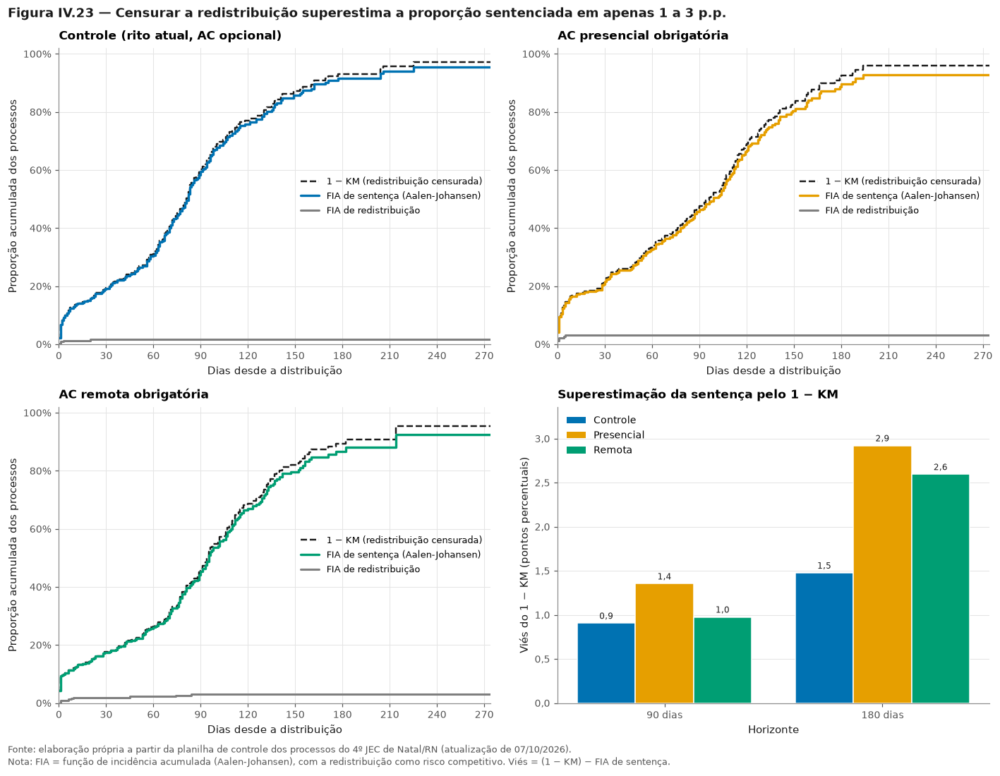

Grupo,t (dias),1 − KM,FIA sentença (AJ),FIA redistribuição,Viés (p.p.)
Controle,90,"60,4%","59,5%","1,6%","0,91"
Controle,180,"93,1%","91,6%","1,6%","1,48"
Presencial,90,"47,7%","46,3%","3,2%","1,35"
Presencial,180,"92,5%","89,5%","3,2%","2,92"
Remota,90,"46,3%","45,4%","3,0%","0,98"
Remota,180,"89,3%","86,7%","3,0%","2,60"


In [117]:
def cif_statsmodels(T, K):
    """FIA de Aalen-Johansen com EP (statsmodels, sem jitter). Retorna dict causa -> DataFrame(t, F, inf, sup)."""
    ci = CumIncidenceRight(np.asarray(T, float), np.asarray(K, int))
    out = {}
    for j, k in enumerate(sorted(set(np.asarray(K, int)) - {0})):
        F = ci.cinc[j]; se = ci.cinc_se[j]
        out[k] = pd.DataFrame({'t': ci.times, 'F': F, 'inf': np.clip(F - 1.96 * se, 0, 1), 'sup': np.clip(F + 1.96 * se, 0, 1)})
    return out

def F_em(df_cif, t):
    d = df_cif[df_cif.t <= t]
    return d.iloc[-1] if len(d) else pd.Series({'t': t, 'F': 0.0, 'inf': 0.0, 'sup': 0.0})

fig, axes = plt.subplots(2, 2, figsize=(13, 9.4))
vies = []
for ax, g in zip(axes.flat[:3], ORDEM_GRUPO):
    s = sob[sob.grupo == g]
    S_g, cif_g = aj_grade(s['T'], s['CR'], causas=(1, 2))
    Skm, _ = aj_grade(s['T'], s['E'])
    tg = np.arange(0, 275)
    ax.step(tg, 1 - Skm[tg], where='post', color=TINTA, ls='--', lw=1.6, label='1 − KM (redistribuição censurada)')
    ax.step(tg, cif_g[1][tg], where='post', color=CORES_GRUPO[g], lw=2.2, label='FIA de sentença (Aalen-Johansen)')
    ax.step(tg, cif_g[2][tg], where='post', color=CORES_DESFECHO['Redistribuição'], lw=2, label='FIA de redistribuição')
    ax.set_title(ROTULO_GRUPO[g]); ax.set_xlabel(ROTULOS['dias']); ax.set_xlim(0, 274); ax.set_xticks(np.arange(0, 271, 30))
    ax.set_ylim(0, 1.02); eixo_pct(ax); ax.set_ylabel('Proporção acumulada dos processos')
    ax.grid(axis='both', visible=True)
    ax.legend(fontsize=8.5, loc='center right')
    for t in [90, 180]:
        vies.append({'Grupo': g, 't (dias)': t, '1 − KM': 1 - Skm[t], 'FIA sentença (AJ)': cif_g[1][t],
                     'FIA redistribuição': cif_g[2][t], 'Viés (p.p.)': 100 * ((1 - Skm[t]) - cif_g[1][t])})
VIES_CR = pd.DataFrame(vies)
ax = axes.flat[3]
_vb = VIES_CR.pivot(index='t (dias)', columns='Grupo', values='Viés (p.p.)')[ORDEM_GRUPO]
_vb.index = [f'{t} dias' for t in _vb.index]
barras_agrupadas(ax, _vb, cores=CORES_GRUPO, rotular=True, fmt=lambda v: fmt_br(v, 1), legenda=False,
                 ylabel='Viés do 1 − KM (pontos percentuais)', xlabel='Horizonte')
ax.set_title('Superestimação da sentença pelo 1 − KM')
ax.legend(handles=[Patch(color=CORES_GRUPO[g], label=g) for g in ORDEM_GRUPO], loc='upper left')
figura(fig, 'sob_cr_redistribuicao', 'Censurar a redistribuição superestima a proporção sentenciada em apenas 1 a 3 p.p.',
       secao='4.7.1', nota='FIA = função de incidência acumulada (Aalen-Johansen), com a redistribuição como risco competitivo. '
                           'Viés = (1 − KM) − FIA de sentença.')
sob_tabela(VIES_CR, 'sob_cr_vies', 'Proporção sentenciada aos 90 e 180 dias: 1 − KM × FIA de Aalen-Johansen', secao='4.7.1',
           casas=3, destaque=None, formatos={'t (dias)': 'int', '1 − KM': 'pct', 'FIA sentença (AJ)': 'pct',
                                             'FIA redistribuição': 'pct', 'Viés (p.p.)': 2})

### 4.7.2 O tipo de sentença como desfecho competitivo: FIA por grupo

Agora a análise substantiva principal: quatro causas de saída — **homologação de acordo** (1), **julgamento de mérito** (2), **extinção sem mérito** (3) e **redistribuição** (4) —, mais a censura administrativa. A figura empilhada mostra, para cada grupo, como a massa de processos se distribui ao longo do tempo: a faixa de cada cor é a FIA da causa, e o que sobra no topo (cinza) é Ŝ(t), a proporção ainda pendente. A segunda figura sobrepõe os três grupos em cada causa, com IC 95% (erro-padrão do `statsmodels.CumIncidenceRight`, sem o *jitter* que o `AalenJohansenFitter` do `lifelines` introduz nos empates).

**Hipótese a investigar** (seção 3 e E21): a AC obrigatória **acelera** as extinções sem mérito — a ausência do autor à audiência de conciliação extingue o processo (art. 51, I, da Lei 9.099/1995) — e os acordos, mas **atrasa** os julgamentos de mérito, que passam a esperar a audiência antes da contestação e da conclusão para sentença. Se for assim, a comparação do tempo total mistura um efeito que encurta com outro que alonga.

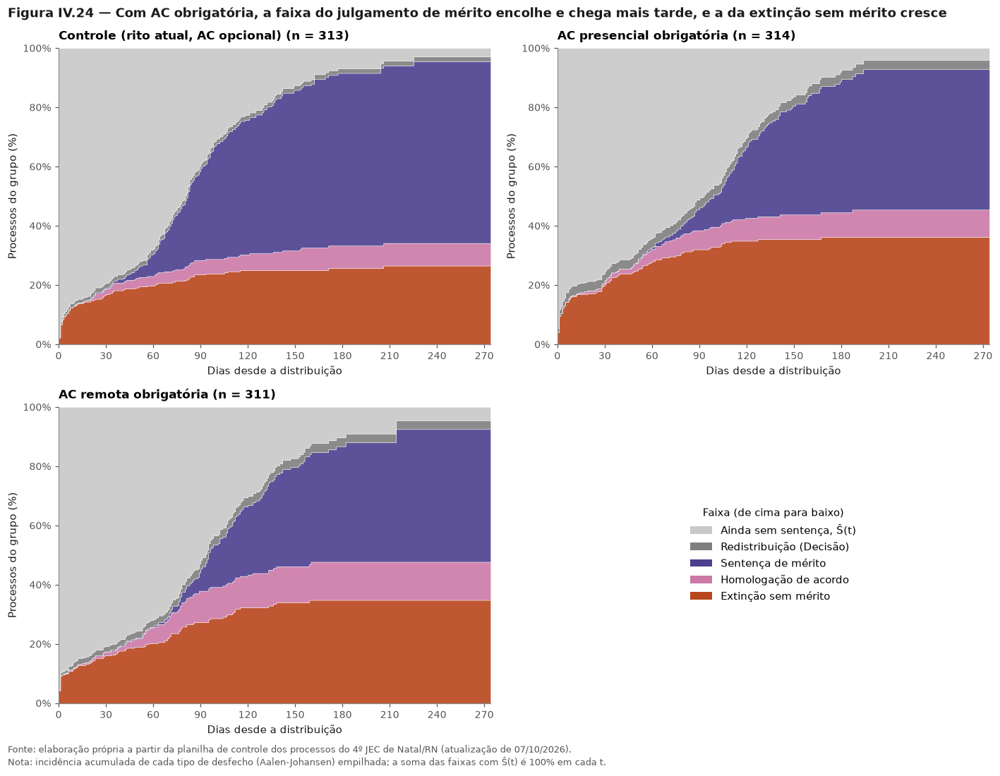

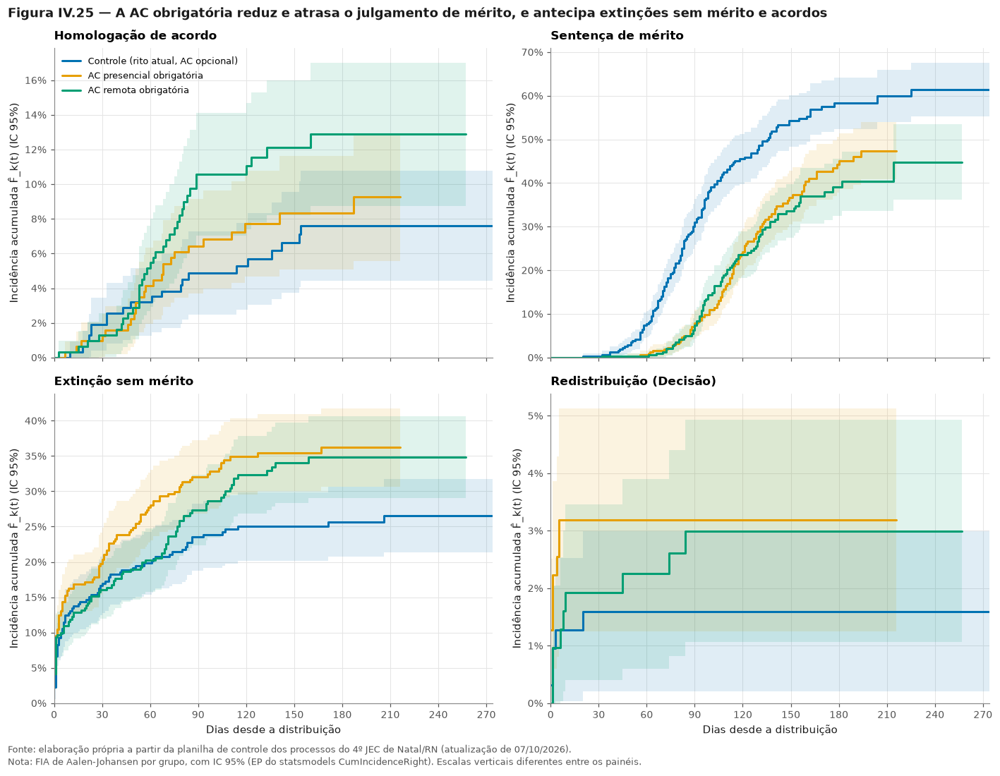

Desfecho,t (dias),Controle,Presencial,Remota
Homologação,30,"1,9% (0,4%–3,4%)","1,3% (0,0%–2,5%)","1,3% (0,0%–2,5%)"
Homologação,60,"3,2% (1,2%–5,1%)","4,1% (1,9%–6,3%)","5,5% (2,9%–8,0%)"
Homologação,90,"4,9% (2,5%–7,3%)","6,4% (3,7%–9,2%)","10,6% (7,0%–14,1%)"
Homologação,120,"5,3% (2,7%–7,8%)","7,7% (4,7%–10,8%)","11,1% (7,4%–14,7%)"
Homologação,180,"7,6% (4,4%–10,8%)","8,4% (5,1%–11,6%)","12,9% (8,8%–17,0%)"
Mérito,30,"0,3% (0,0%–0,9%)","0,0% (0,0%–0,0%)","0,0% (0,0%–0,0%)"
Mérito,60,"7,7% (4,7%–10,6%)","0,6% (0,0%–1,5%)","0,3% (0,0%–1,0%)"
Mérito,90,"31,1% (25,8%–36,3%)","7,8% (4,8%–10,9%)","7,5% (4,3%–10,6%)"
Mérito,120,"45,5% (39,8%–51,2%)","24,2% (19,0%–29,5%)","23,5% (18,2%–28,9%)"
Mérito,180,"58,3% (52,3%–64,2%)","45,0% (38,6%–51,4%)","39,0% (32,4%–45,6%)"


In [118]:
CAUSAS_SENT = (1, 2, 3, 4)
cif_sm = {g: cif_statsmodels(sob.loc[sob.grupo == g, 'T'], sob.loc[sob.grupo == g, 'K']) for g in ORDEM_GRUPO}
tg = np.arange(0, 275)
ORDEM_PILHA = [3, 1, 2, 4]         # sem mérito (precoce), homologação, mérito, redistribuição
fig, axes = plt.subplots(2, 2, figsize=(13, 9.4))
for ax, g in zip(axes.flat[:3], ORDEM_GRUPO):
    s = sob[sob.grupo == g]
    S_g, cif_g = aj_grade(s['T'], s['K'], causas=CAUSAS_SENT)
    camadas = [cif_g[k][tg] for k in ORDEM_PILHA] + [S_g[tg]]
    ax.stackplot(tg, *camadas, step='post', colors=[CORES_DESFECHO[CAUSAS[k]] for k in ORDEM_PILHA] + [CORES_DESFECHO['Ativo']],
                 alpha=0.9, edgecolor='white', lw=0.3)
    ax.set_title(f'{ROTULO_GRUPO[g]} (n = {len(s)})'); ax.set_xlabel(ROTULOS['dias']); ax.set_xlim(0, 274); ax.set_ylim(0, 1)
    ax.set_xticks(np.arange(0, 271, 30)); eixo_pct(ax); ax.set_ylabel('Processos do grupo (%)')
    ax.grid(visible=False)
axes.flat[3].axis('off')
axes.flat[3].legend(handles=[Patch(color=CORES_DESFECHO['Ativo'], label='Ainda sem sentença, Ŝ(t)')] +
                    [Patch(color=CORES_DESFECHO[CAUSAS[k]], label=ROTULO_DESFECHO[CAUSAS[k]]) for k in ORDEM_PILHA[::-1]],
                    loc='center', title='Faixa (de cima para baixo)', fontsize=10, title_fontsize=10)
figura(fig, 'sob_cif_empilhada', 'Com AC obrigatória, a faixa do julgamento de mérito encolhe e chega mais tarde, e a da extinção '
       'sem mérito cresce', secao='4.7.2', nota='incidência acumulada de cada tipo de desfecho (Aalen-Johansen) empilhada; '
                                                'a soma das faixas com Ŝ(t) é 100% em cada t.')

fig, axes = plt.subplots(2, 2, figsize=(13, 9.4), sharex=True)
for ax, k in zip(axes.flat, CAUSAS_SENT):
    for g in ORDEM_GRUPO:
        d = cif_sm[g][k]
        ax.step(d.t, d.F, where='post', color=CORES_GRUPO[g], lw=2, label=ROTULO_GRUPO[g])
        ax.fill_between(d.t, d['inf'], d['sup'], step='post', color=CORES_GRUPO[g], alpha=0.12, lw=0)
    ax.set_title(f'{ROTULO_DESFECHO[CAUSAS[k]]}'); ax.set_xlim(0, 274); ax.set_xticks(np.arange(0, 271, 30))
    ax.set_ylim(0, None); eixo_pct(ax); ax.grid(axis='both', visible=True)
    ax.set_ylabel('Incidência acumulada F̂_k(t) (IC 95%)')
for ax in axes[1]:
    ax.set_xlabel(ROTULOS['dias'])
axes[0, 0].legend(loc='upper left', fontsize=8.5)
figura(fig, 'sob_cif_causas', 'A AC obrigatória reduz e atrasa o julgamento de mérito, e antecipa extinções sem mérito e acordos',
       secao='4.7.2', nota='FIA de Aalen-Johansen por grupo, com IC 95% (EP do statsmodels CumIncidenceRight). Escalas verticais '
                           'diferentes entre os painéis.')

linhas = []
for k in CAUSAS_SENT:
    for t in [30, 60, 90, 120, 180]:
        linha = {'Desfecho': CAUSAS[k], 't (dias)': t}
        for g in ORDEM_GRUPO:
            r = F_em(cif_sm[g][k], t)
            linha[g] = f"{pct_br(r['F'])} ({pct_br(r['inf'])}–{pct_br(r['sup'])})"
        linhas.append(linha)
CIF_TAB = pd.DataFrame(linhas).set_index(['Desfecho', 't (dias)'])
tabela(CIF_TAB.reset_index(), 'sob_cif_tabela', 'Incidência acumulada de cada tipo de desfecho por grupo, F̂_k(t) (IC 95%)',
       secao='4.7.2', formatos={'t (dias)': 'int', **{g: 'texto' for g in ORDEM_GRUPO}},
       nota='Aalen-Johansen (statsmodels CumIncidenceRight); IC 95% pela aproximação normal, truncado em [0, 1].')

### 4.7.3 Teste de igualdade das FIA entre grupos (tipo Gray, por permutação)

O teste de Gray (1988) compara as FIA de uma causa entre k grupos. Ele não existe no `lifelines` nem no `statsmodels` (e os pacotes `pycmprsk`/`pycrr` não estão instalados). Implementa-se um **teste de permutação** com a mesma hipótese nula:

- H₀: F_k,Controle(t) = F_k,Presencial(t) = F_k,Remota(t) para todo t ≤ τ;
- estatística: D_k = Σ_g n_g ∫₀^τ [F̂_k,g(t) − F̂_k(t)]² dt, a distância quadrática integrada entre a FIA de cada grupo e a FIA combinada, com τ = 180 dias;
- distribuição sob H₀: 2.000 permutações dos rótulos de grupo **dentro de cada mês de distribuição**. A permutação estratificada respeita o desenho (o sorteio foi feito ao longo do calendário) e preserva a estrutura de censura de cada mês, que é o que torna a censura comparável entre os rótulos permutados. Sob H₀ de nenhum efeito do rito, os rótulos são permutáveis dentro do mês: o p-valor é exato (a menos do erro de Monte Carlo).

São 4 testes (um por causa), corrigidos por Holm. **Gráfico do teste:** distribuição de permutação de D_k com o valor observado.

Desfecho,D observado,p (permutação),"p (Holm, 4 testes)"
Homologação,"53,33","0,055","0,110"
Mérito,"1.007,95","< 0,001","0,002"
Sem mérito,"228,64","0,020","0,061"
Redistribuição,"8,30","0,359","0,359"


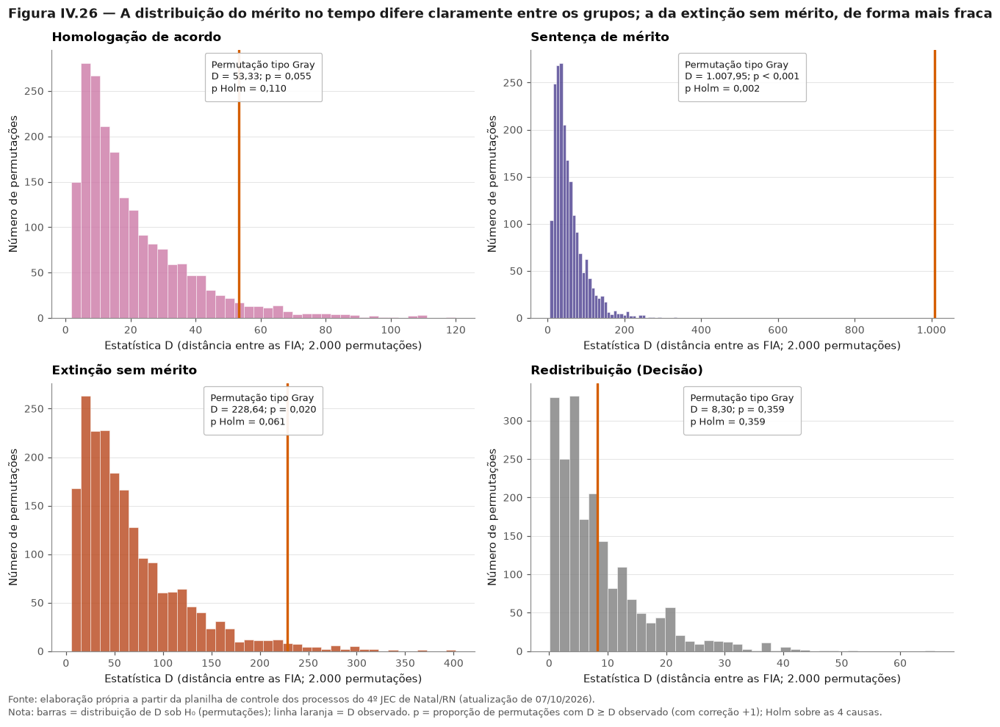

In [119]:
def estat_gray_perm(T, K, G, k, tau=180, grupos=(0, 1, 2)):
    _, cif_all = aj_grade(T, K, causas=CAUSAS_SENT)
    Fbar = cif_all[k][:tau]
    D = 0.0
    for g in grupos:
        m = G == g
        _, cg = aj_grade(T[m], K[m], causas=CAUSAS_SENT)
        D += m.sum() * np.sum((cg[k][:tau] - Fbar) ** 2)
    return D

B_PERM = 2000
rng_perm = np.random.default_rng(SEMENTE + 47)
T_i, K_i, G_i, M_i = sob['T'].values.astype(int), sob['K'].values.astype(int), sob['grupo'].cat.codes.values, sob['mes_cod'].values
obs_D = {k: estat_gray_perm(T_i, K_i, G_i, k) for k in CAUSAS_SENT}
perm_D = {k: np.empty(B_PERM) for k in CAUSAS_SENT}
idx_mes = [np.where(M_i == m)[0] for m in np.unique(M_i)]
for b in range(B_PERM):
    Gp = G_i.copy()
    for ii in idx_mes:
        Gp[ii] = rng_perm.permutation(G_i[ii])
    for k in CAUSAS_SENT:
        perm_D[k][b] = estat_gray_perm(T_i, K_i, Gp, k)
gray = pd.DataFrame({'Desfecho': [CAUSAS[k] for k in CAUSAS_SENT],
                     'D observado': [obs_D[k] for k in CAUSAS_SENT],
                     'p (permutação)': [(1 + (perm_D[k] >= obs_D[k]).sum()) / (B_PERM + 1) for k in CAUSAS_SENT]}).set_index('Desfecho')
gray['p (Holm, 4 testes)'] = multipletests(gray['p (permutação)'], method='holm')[1]
sob_tabela(gray, 'sob_gray_permutacao', 'Teste de igualdade das FIA entre os três grupos (tipo Gray, por permutação no mês)',
           secao='4.7.3', casas=2, colunas_p=('p (permutação)', 'p (Holm, 4 testes)'),
           nota=f'D = Σ_g n_g ∫₀^180 [F̂_k,g(t) − F̂_k(t)]² dt; {fmt_br(B_PERM, 0)} permutações dos rótulos de grupo dentro do mês. '
                'Destaque: p de Holm < 0,05.')

fig, axes = plt.subplots(2, 2, figsize=(12, 8.4))
for ax, k in zip(axes.flat, CAUSAS_SENT):
    ax.hist(perm_D[k], bins=40, color=CORES_DESFECHO[CAUSAS[k]], alpha=0.8, edgecolor='white', lw=0.4)
    ax.axvline(obs_D[k], color=DESTAQUE, lw=2.2)
    ax.set_title(ROTULO_DESFECHO[CAUSAS[k]])
    ax.set_xlabel(f'Estatística D (distância entre as FIA; {fmt_br(B_PERM, 0)} permutações)')
    ax.set_ylabel('Número de permutações')
    ax.grid(axis='x', visible=False)
    r = gray.loc[CAUSAS[k]]
    lado = 'upper right' if obs_D[k] < np.percentile(perm_D[k], 60) else 'upper center'
    anotar_teste(ax, texto_teste('Permutação tipo Gray', f'D = {fmt_br(r["D observado"], 2)}', r['p (permutação)'],
                                 f'p Holm = {fmt_p(r["p (Holm, 4 testes)"])}'), loc=lado)
figura(fig, 'sob_gray_permutacao', 'A distribuição do mérito no tempo difere claramente entre os grupos; a da extinção sem mérito, '
       'de forma mais fraca', secao='4.7.3', nota='barras = distribuição de D sob H₀ (permutações); linha laranja = D observado. p = proporção de permutações '
                                     'com D ≥ D observado (com correção +1); Holm sobre as 4 causas.')

### 4.7.4 Cox causa-específico por tipo de desfecho

Para cada causa k, ajusta-se um Cox (grupo + mês, Efron) em que o evento é "desfecho do tipo k" e os desfechos de outros tipos são **censurados** no seu tempo. O HR causa-específico responde: entre os processos ainda pendentes no dia t, quanto maior (HR > 1) ou menor (HR < 1) é a taxa diária de desfechos do tipo k no grupo com AC em relação ao Controle? Censurar as outras causas é correto para o risco causa-específico (não para a FIA): o risco causa-específico é definido justamente entre os que ainda estão em risco de todas as causas.

In [120]:
X_CS = X_BASE + COLS_MES
cs_tabs, cs_modelos = [], {}
for k in CAUSAS_SENT:
    base_k = sob[['T'] + X_CS].assign(Ek=(sob['K'] == k).astype(int))
    m = CoxPHFitter().fit(base_k, 'T', 'Ek')
    cs_modelos[k] = m
    t = tabela_hr(m, X_BASE); t.insert(0, 'Desfecho', CAUSAS[k]); t.insert(1, 'eventos', int(base_k['Ek'].sum()))
    cs_tabs.append(t)
HR_CS = pd.concat(cs_tabs)
sob_tabela(HR_CS.rename_axis('Termo').reset_index()[['Desfecho', 'eventos', 'Termo', 'HR', 'IC 95% inf.', 'IC 95% sup.', 'p (Wald)']]
           .rename(columns={'eventos': 'Eventos'}), 'sob_cox_causa_especifica',
           'Cox causa-específico por tipo de desfecho: razão de risco dos grupos com AC vs. Controle (ajustado por mês)',
           secao='4.7.4', casas=3, colunas_p=('p (Wald)',), formatos={'Eventos': 'int'},
           nota='desfechos de outros tipos censurados no seu tempo; HR > 1 = desfecho mais frequente por dia entre os pendentes. '
                'Destaque: p < 0,05.')

Desfecho,Eventos,Termo,HR,IC 95% inf.,IC 95% sup.,p (Wald)
Homologação,81,AC presencial × Controle,"1,235","0,7","2,2","0,478"
Homologação,81,AC remota × Controle,"1,710","1,0","2,9","0,053"
Mérito,341,AC presencial × Controle,"0,547","0,4","0,7","< 0,001"
Mérito,341,AC remota × Controle,"0,474","0,4","0,6","< 0,001"
Sem mérito,286,AC presencial × Controle,"1,400","1,0","1,9","0,023"
Sem mérito,286,AC remota × Controle,"1,259","0,9","1,7","0,130"
Redistribuição,24,AC presencial × Controle,"2,157","0,7","6,3","0,161"
Redistribuição,24,AC remota × Controle,"1,889","0,6","5,7","0,256"


### 4.7.5 Modelo de Fine-Gray (subdistribuição) implementado à mão

O modelo de **Fine e Gray (1999)** modela diretamente a FIA: o risco da **subdistribuição** λ̄_k(t) = −d log[1 − F_k(t)]/dt segue um modelo de riscos proporcionais, λ̄_k(t | x) = λ̄_k0(t) exp(x′γ). O exp(γ) (sHR) > 1 indica **maior incidência acumulada** da causa k (mais processos terminando por k até cada t). A diferença em relação ao Cox causa-específico está no **conjunto de risco**: no Fine-Gray, quem saiu por **outra causa** continua no conjunto de risco da causa k (com peso), porque não pode mais ter a causa k "a tempo".

O modelo não está no `lifelines` nem no `statsmodels`. Duas implementações equivalentes:

1. **Censura completamente conhecida** (FINE; GRAY, 1999, seção 3). Aqui toda censura é administrativa, e o tempo potencial de censura de **todos** os processos é conhecido (C_i = `followup` = 07/10/2026 − distribuição). Nesse caso, o estimador de Fine-Gray é exato e simples: quem teve desfecho competitivo permanece no conjunto de risco **até o seu C_i**, com peso 1. Basta um Cox com o tempo do competidor substituído por C_i e o evento k = 0. Erros-padrão robustos (sanduíche), como recomendam os autores.
2. **Ponderação IPCW** (GESKUS, 2011), a forma geral usada pelo `survival::finegray()` do R. Quem tem desfecho competitivo em T_i é mantido em risco depois de T_i em episódios (início, fim] entre os tempos de censura observados, com peso w_i(t) = Ĝ(t)/Ĝ(T_i), sendo Ĝ o KM da distribuição de censura (censura como "evento"). Cox ponderado em formato de contagem, com variância robusta agrupada por processo (`cluster_col`).

As duas devem dar resultados muito próximos; a versão 2 é aplicada, como conferência, aos dois desfechos centrais (mérito e sem mérito), porque o ajuste ponderado com variância agrupada sobre ~30 mil episódios é lento. A versão 1 é a principal, porque usa a informação exata do desenho. Covariáveis: grupo + mês (como no Cox causa-específico).

In [121]:
def fine_gray_censura_conhecida(df, k, X):
    """Fine-Gray com tempos potenciais de censura conhecidos (followup)."""
    b = df[['T', 'K', 'FU'] + X].copy()
    compet = (b['K'] != k) & (b['K'] != 0)
    b['T_fg'] = np.where(compet, b['FU'], b['T'])
    b['E_fg'] = (b['K'] == k).astype(int)
    return CoxPHFitter().fit(b[['T_fg', 'E_fg'] + X], 'T_fg', 'E_fg', robust=True)


def fine_gray_ipcw(df, k, X):
    """Fine-Gray por IPCW (Geskus, 2011), como survival::finegray. Tempos deslocados +1 dia (start < stop)."""
    b = df[['T', 'K'] + X].copy().reset_index(drop=True)
    b['id'] = np.arange(len(b))
    T1 = b['T'].values + 1.0
    kmG = KaplanMeierFitter().fit(T1, (b['K'] == 0).astype(int))     # censura como "evento"
    G = kmG.survival_function_.iloc[:, 0]
    G_t, G_v = G.index.values, G.values
    G_em = lambda t: G_v[np.searchsorted(G_t, t, side='right') - 1]
    cortes = np.unique(T1[b['K'] == 0])
    linhas = [pd.DataFrame({'id': b['id'], 'start': 0.0, 'stop': T1, 'ev': (b['K'] == k).astype(int).values, 'w': 1.0})]
    comp = b.index[(b['K'] != k) & (b['K'] != 0)]
    ext = []
    for i in comp:
        Ti = T1[i]; Gi = G_em(Ti)
        cs = cortes[cortes > Ti]
        inicios = np.concatenate([[Ti], cs[:-1]]) if len(cs) else np.array([])
        for a_, b_ in zip(inicios, cs):
            ext.append((i, a_, b_, 0, G_em(a_) / Gi))
    linhas.append(pd.DataFrame(ext, columns=['id', 'start', 'stop', 'ev', 'w']))
    long = pd.concat(linhas, ignore_index=True).merge(b[['id'] + X], on='id')
    long = long[long['w'] > 0]
    m = CoxPHFitter().fit(long[['start', 'stop', 'ev', 'w', 'id'] + X], 'stop', 'ev', entry_col='start',
                          weights_col='w', cluster_col='id', robust=True)
    return m, len(long)


fg_tabs, FG_MODELOS = [], {}
for k in CAUSAS_SENT:
    m1 = fine_gray_censura_conhecida(sob, k, X_CS)
    FG_MODELOS[k] = m1
    versoes = [('censura conhecida', m1)]
    if k in (2, 3):          # conferência IPCW só para os dois desfechos centrais (cada ajuste leva ~1–2 min)
        m2, n_long = fine_gray_ipcw(sob, k, X_CS)
        versoes.append((f'IPCW ({n_long:,} episódios)'.replace(',', '.'), m2))
    for nome, m in versoes:
        t = tabela_hr(m, X_BASE, rotulo='sHR'); t.insert(0, 'Desfecho', CAUSAS[k]); t.insert(1, 'Implementação', nome)
        fg_tabs.append(t)
SHR_FG = pd.concat(fg_tabs)
sob_tabela(SHR_FG.rename_axis('Termo').reset_index()[['Desfecho', 'Implementação', 'Termo', 'sHR', 'IC 95% inf.', 'IC 95% sup.', 'p (Wald)']],
           'sob_fine_gray', 'Modelo de Fine-Gray por tipo de desfecho: razão de riscos da subdistribuição (sHR) vs. Controle',
           secao='4.7.5', casas=3, colunas_p=('p (Wald)',),
           nota='sHR > 1 = maior incidência acumulada do desfecho; EP robusto (sanduíche). Ajustado por mês. Destaque: p < 0,05.')

Desfecho,Implementação,Termo,sHR,IC 95% inf.,IC 95% sup.,p (Wald)
Homologação,censura conhecida,AC presencial × Controle,"1,250","0,7","2,3","0,457"
Homologação,censura conhecida,AC remota × Controle,"1,868","1,1","3,2","0,026"
Mérito,censura conhecida,AC presencial × Controle,"0,463","0,4","0,6","< 0,001"
Mérito,censura conhecida,AC remota × Controle,"0,416","0,3","0,5","< 0,001"
Mérito,IPCW (33.989 episódios),AC presencial × Controle,"0,483","0,3","0,7","< 0,001"
Mérito,IPCW (33.989 episódios),AC remota × Controle,"0,428","0,3","0,6","< 0,001"
Sem mérito,censura conhecida,AC presencial × Controle,"1,457","1,1","2,0","0,011"
Sem mérito,censura conhecida,AC remota × Controle,"1,318","1,0","1,8","0,070"
Sem mérito,IPCW (30.497 episódios),AC presencial × Controle,"1,466","1,0","2,2","0,052"
Sem mérito,IPCW (30.497 episódios),AC remota × Controle,"1,325","0,9","2,0","0,162"


**Gráfico dos dois modelos.** Para cada tipo de desfecho, o HR causa-específico (Cox) e o sHR de Fine-Gray (censura conhecida) dos dois grupos com AC em relação ao Controle. Quando os dois apontam na mesma direção, o rito muda tanto a **velocidade** daquele desfecho entre os pendentes quanto a **fração** de processos que termina por ele.

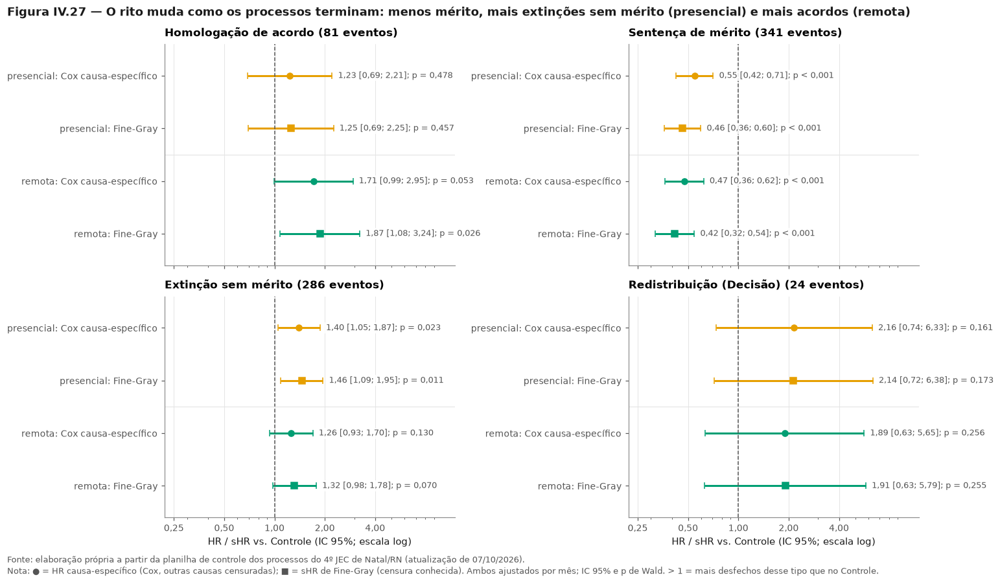

In [122]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.6), sharex=True)
for ax, k in zip(axes.flat, CAUSAS_SENT):
    cs = HR_CS[HR_CS.Desfecho == CAUSAS[k]].rename(columns={'HR': 'v'})
    fg = SHR_FG[(SHR_FG.Desfecho == CAUSAS[k]) & (SHR_FG['Implementação'] == 'censura conhecida')].rename(columns={'sHR': 'v'})
    linhas_f, cores_f, mks_f = [], {}, {}
    for termo in cs.index:
        for tab_, nome, mk in [(cs, 'Cox causa-específico', 'o'), (fg, 'Fine-Gray', 's')]:
            rot = f"{termo.split(' ×')[0].replace('AC ', '')}: {nome}"
            linhas_f.append(tab_.loc[termo, ['v', 'IC 95% inf.', 'IC 95% sup.', 'p (Wald)']].rename(rot))
            cores_f[rot] = COR_TERMO[termo]; mks_f[rot] = mk
    floresta(ax, pd.DataFrame(linhas_f), rotulo='v', cor_de=cores_f.get, marcadores=mks_f.get,
             xlabel='HR / sHR vs. Controle (IC 95%; escala log)', ticks=[0.25, 0.5, 1, 2, 4])
    ax.axhline(1.5, color=GRADE, lw=0.8)
    ax.set_xlim(0.22, 12)
    ax.set_title(f'{ROTULO_DESFECHO[CAUSAS[k]]} ({int(cs["eventos"].iloc[0])} eventos)')
for ax in axes[0]:
    ax.set_xlabel('')
figura(fig, 'sob_cr_floresta', 'O rito muda como os processos terminam: menos mérito, mais extinções sem mérito (presencial) '
       'e mais acordos (remota)', secao='4.7.5',
       nota='● = HR causa-específico (Cox, outras causas censuradas); ■ = sHR de Fine-Gray (censura conhecida). Ambos ajustados '
            'por mês; IC 95% e p de Wald. > 1 = mais desfechos desse tipo que no Controle.')

**Interpretação (riscos competitivos).**

**(a) Redistribuição.** O 1 − KM que censura a redistribuição superestima a proporção sentenciada em 0,9 a 1,4 p.p. aos 90 dias e em 1,5 a 2,9 p.p. aos 180 dias. O viés é maior nos grupos com AC, que têm o dobro de redistribuições (3,2% na presencial e 3,0% na remota, contra 1,6% no Controle, todas nos primeiros dias). É pequeno e não altera nenhuma conclusão, mas tem sentido conhecido.

**(b) Tipo de sentença: aqui está o mecanismo.** As FIAs aos 90 dias:

| Desfecho | Controle | AC presencial | AC remota |
|---|---|---|---|
| Mérito | 31,1% | 7,8% | 7,5% |
| Sem mérito | 23,5% | 32,0% | 27,3% |
| Homologação | 4,9% | 6,4% | 10,6% |

- **Julgamento de mérito: fortemente atrasado e reduzido pela AC.** Aos 120 dias, 45,5% dos processos do Controle já tinham sentença de mérito, contra 24,2% e 23,5%; aos 180 dias, 58,3% contra 45,0% e 39,0%.
  - Teste tipo Gray (permutação no mês): **p < 0,001** (Holm 0,002).
  - Cox causa-específico: **HR = 0,55 (0,42–0,71)** na presencial e **0,47 (0,36–0,62)** na remota. Entre os processos pendentes, a taxa de julgamento de mérito cai à metade.
  - Fine-Gray: sHR = 0,46 (0,36–0,60) e 0,42 (0,32–0,55). A versão IPCW dá 0,48 e 0,43, o que confirma a implementação.
- **Extinção sem mérito: acelerada e aumentada pela AC, sobretudo a presencial.** Aos 60 dias, 28,0% na presencial contra 19,8% no Controle; aos 180 dias, 36,2% e 34,8% contra 25,7%.
  - Cox causa-específico: presencial **HR = 1,40 (1,05–1,87; p = 0,023)**; remota 1,26 (0,94–1,70; p = 0,13).
  - Fine-Gray: presencial **sHR = 1,46 (1,09–1,95; p = 0,011)**; remota 1,32 (p = 0,07).
  - Teste de permutação: p = 0,020 (Holm 0,061).

  É o padrão previsto pela hipótese da **extinção por ausência do autor à audiência** (art. 51, I, da Lei 9.099/1995): no Controle não há audiência a que faltar.
- **Acordo homologado: aumentado na AC remota.** Aos 90 dias, 10,6% contra 4,9% no Controle e 6,4% na presencial; aos 180 dias, 12,9% contra 7,6%.
  - Fine-Gray da remota: **sHR = 1,87 (1,08–3,24; p = 0,026)**; Cox causa-específico 1,71 (p = 0,053).
  - Teste de permutação: p = 0,055.
  - A AC presencial não difere do Controle (sHR = 1,25; p = 0,46).
  - Com 81 acordos no total, a evidência é moderada, coerente com a razão de chances de acordo de 2,15 (remota × Controle) da Parte V.

**A hipótese se confirma: o tempo total esconde mecanismos opostos.** A AC obrigatória **acelera** dois tipos de encerramento — extinções (presencial) e acordos (remota) —, mas **atrasa fortemente** o julgamento de mérito, que passa a esperar a audiência. Como o mérito é o desfecho mais frequente (341 de 708 sentenças), o efeito líquido sobre o tempo total é de atraso (HR ≈ 0,8 a 0,87). Juridicamente, o rito com AC muda **como** os processos terminam, e não só **quando**:

- menos decisões de mérito;
- mais extinções sem resolução do conflito, que deixam o autor sem solução e podem gerar reajuizamento;
- e, na modalidade remota, mais acordos.

Uma avaliação do rito que olhe só a duração perde a parte mais importante do efeito.

---

## 4.8 Subconjunto com AC realizada: modalidade, técnica e audiência híbrida

**Atenção ao que esta análise pode e não pode dizer.** A AC só ocorre nos grupos com AC obrigatória (no Controle não houve nenhuma: zero estrutural), e mesmo neles só para os processos que **chegaram vivos** até a audiência. Restringir a análise a quem teve AC é **condicionar numa variável posterior ao sorteio**:

- quem teve AC "sobreviveu" (sem sentença, sem redistribuição, sem extinção precoce) até a data da audiência. O tempo entre a distribuição e a AC é **tempo imortal** para esse subconjunto: um processo não pode ter sentença antes de entrar nele. Comparar com processos sem AC daria uma vantagem artificial de sobrevivência a quem teve AC;
- a realização da AC pode depender de características do processo (partes presentes, interesse em conciliar), que diferem entre presencial e remota. A comparação Presencial × Remota dentro do subconjunto **não é mais protegida pelo sorteio**: é observacional.

A solução canônica é a **análise de *landmark***: escolher um tempo L, manter apenas quem ainda está em risco em L e classificar pela situação em L. Ela exige a **data da AC**, que a planilha não registra; o tempo é medido desde a distribuição. Por isso, as comparações abaixo restringem-se a processos que tiveram AC (todos passaram pelo tempo imortal) e se leem como **descritivas/associativas**. A técnica de conciliação, essa sim, foi **sorteada** entre as audiências realizadas: a comparação entre técnicas é a mais próxima de um contraste causal neste subconjunto (com a ressalva de que a técnica só "existe" para quem teve AC).

### 4.8.1 Presencial × Remota entre os processos com AC realizada

Processos com AC realizada: 352 (Presencial 178, Remota 174); sentenças 263


Grupo,Homologação de acordo,Sentença de mérito,Extinção sem mérito,Redistribuição (Decisão),Em tramitação (censurado),Total
Presencial,14,94,20,0,50,178
Remota,19,81,35,2,37,174


Termo,HR,IC 95% inf.,IC 95% sup.,p (Wald)
AC remota × AC presencial (com AC realizada),"1,126","0,9","1,4","0,340"


Log-rank Presencial × Remota (com AC): χ² = 1,41, p = 0,234
Medianas (dias): Presencial 115; Remota 107


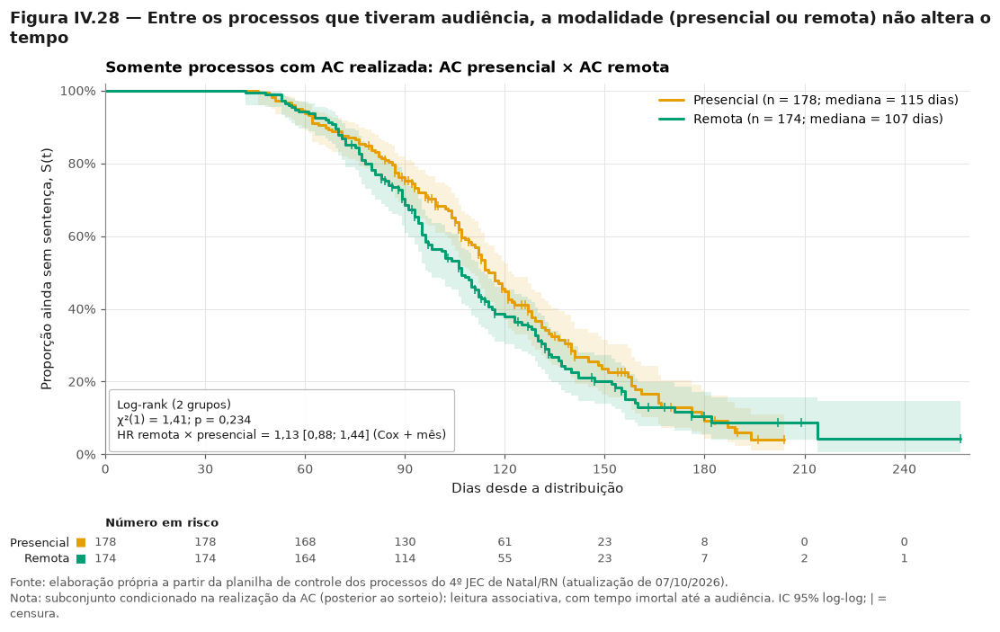

In [123]:
ac = sob[(sob.grupo != 'Controle') & (sob['ac_realizada'] == True)].copy()
ac['grupo2'] = ac['grupo'].astype(str)
print(f'Processos com AC realizada: {len(ac)} (Presencial {(ac.grupo2 == "Presencial").sum()}, Remota {(ac.grupo2 == "Remota").sum()}); '
      f'sentenças {ac.E.sum()}')
_ct = pd.crosstab(ac['grupo2'], ac['tipo_desfecho'].astype(str))
_ct = _ct[[c for c in ORDEM_DESFECHO if c in _ct.columns]].rename(columns=ROTULO_DESFECHO)
_ct.columns.name = None
tabela(_ct.assign(Total=_ct.sum(axis=1)).rename_axis('Grupo'), 'sob_ac_desfechos',
       'Processos com AC realizada: tipo de desfecho por modalidade (frequências)', secao='4.8.1',
       formatos={c: 'int' for c in list(_ct.columns) + ['Total']})
km_ac = {g: KaplanMeierFitter(label=ROTULO_GRUPO[g]).fit(ac.loc[ac.grupo2 == g, 'T'], ac.loc[ac.grupo2 == g, 'E']) for g in ['Presencial', 'Remota']}
lr_ac = logrank_test(ac.loc[ac.grupo2 == 'Presencial', 'T'], ac.loc[ac.grupo2 == 'Remota', 'T'],
                     ac.loc[ac.grupo2 == 'Presencial', 'E'], ac.loc[ac.grupo2 == 'Remota', 'E'])
cox_ac = CoxPHFitter().fit(ac[['T', 'E', 'Remota'] + COLS_MES], 'T', 'E')
hr_ac = tabela_hr(cox_ac, ['Remota']); hr_ac.index = ['AC remota × AC presencial (com AC realizada)']
sob_tabela(hr_ac.rename_axis('Termo'), 'sob_ac_cox', 'Cox entre os processos com AC realizada: AC remota × AC presencial '
           '(ajustado por mês)', secao='4.8.1', casas=3, colunas_p=('p (Wald)',),
           nota='comparação observacional (condiciona na realização da AC, posterior ao sorteio).')
print(f"Log-rank Presencial × Remota (com AC): χ² = {fmt_br(lr_ac.test_statistic, 2)}, p = {p_br(lr_ac.p_value)}")
print('Medianas (dias): ' + '; '.join(f'{g} {fmt_br(km_ac[g].median_survival_time_, 0)}' for g in km_ac))

fig, ax = plt.subplots(figsize=(10, 5.4))
plot_km(ax, ac, tempo='T', evento='E', grupo='grupo2', ordem=['Presencial', 'Remota'], passo=30)
eixo_pct(ax)
ax.set_title('Somente processos com AC realizada: AC presencial × AC remota')
_h = hr_ac.iloc[0]
anotar_teste(ax, texto_teste('Log-rank (2 grupos)', f'χ²(1) = {fmt_br(lr_ac.test_statistic, 2)}', lr_ac.p_value,
                             f'HR remota × presencial = {fmt_br(_h["HR"], 2)} [{fmt_br(_h["IC 95% inf."], 2)}; '
                             f'{fmt_br(_h["IC 95% sup."], 2)}] (Cox + mês)'), loc='lower left')
figura(fig, 'sob_ac_modalidade', 'Entre os processos que tiveram audiência, a modalidade (presencial ou remota) não altera o tempo',
       secao='4.8.1', nota='subconjunto condicionado na realização da AC (posterior ao sorteio): leitura associativa, com tempo '
                           'imortal até a audiência. IC 95% log-log; | = censura.')

### 4.8.2 Técnica de conciliação e audiência híbrida

**Técnica.** Seis técnicas sorteadas entre as audiências. H₀: o tempo até a sentença não depende da técnica. Teste: log-rank de 6 grupos (5 g.l.) e Cox com a técnica (referência = Padrões objetivos, a mais frequente) ajustado por modalidade e mês. Com ~47 a 67 processos por técnica, o poder para diferenças moderadas é baixo: um resultado não significativo **não** demonstra equivalência.

**Híbrida.** Audiência pautada como presencial em que uma parte participou remotamente (Res. CNJ 481/2022). É uma decisão posterior ao sorteio, tomada a pedido da parte: comparar híbridas com presenciais puras é observacional (o pedido pode estar associado ao perfil da parte). Restringe-se ao grupo Presencial com AC realizada.

Log-rank entre as 6 técnicas: χ² = 1,55, 5 g.l., p = 0,908


Técnica (vs. referência),HR,IC 95% inf.,IC 95% sup.,p (Wald)
Comunicação × Padrões objetivos,"1,197","0,8","1,8","0,393"
Separação × Padrões objetivos,"1,275","0,8","1,9","0,246"
Afago × Padrões objetivos,"1,041","0,7","1,6","0,852"
Parafraseamento × Padrões objetivos,"1,063","0,7","1,6","0,768"
Desconstrução × Padrões objetivos,"1,097","0,7","1,7","0,690"


Presencial com AC: híbridas 24, presenciais puras 154 | log-rank p = 0,907


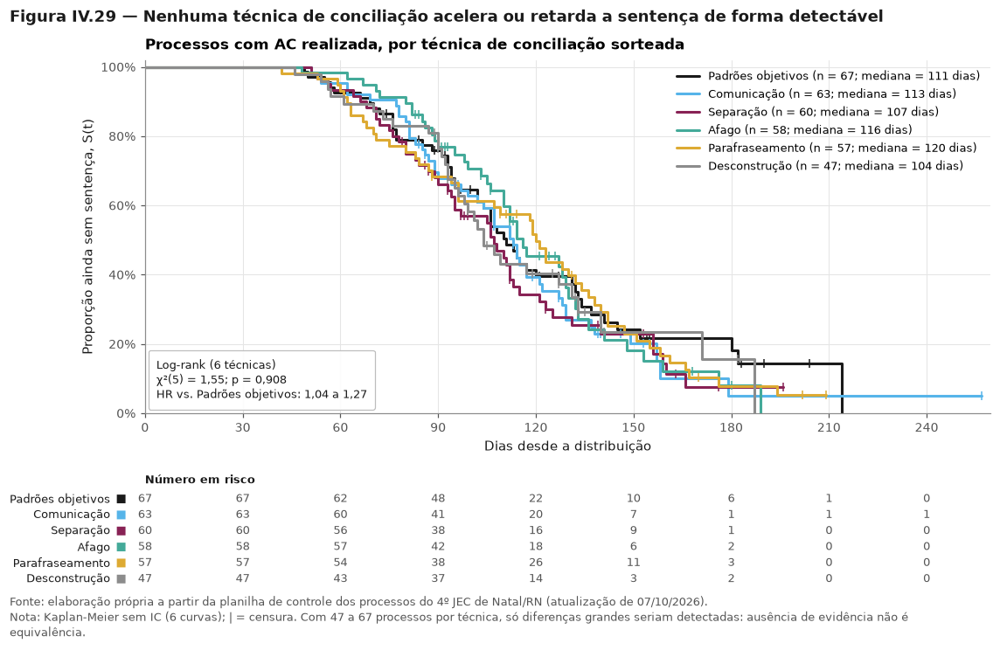

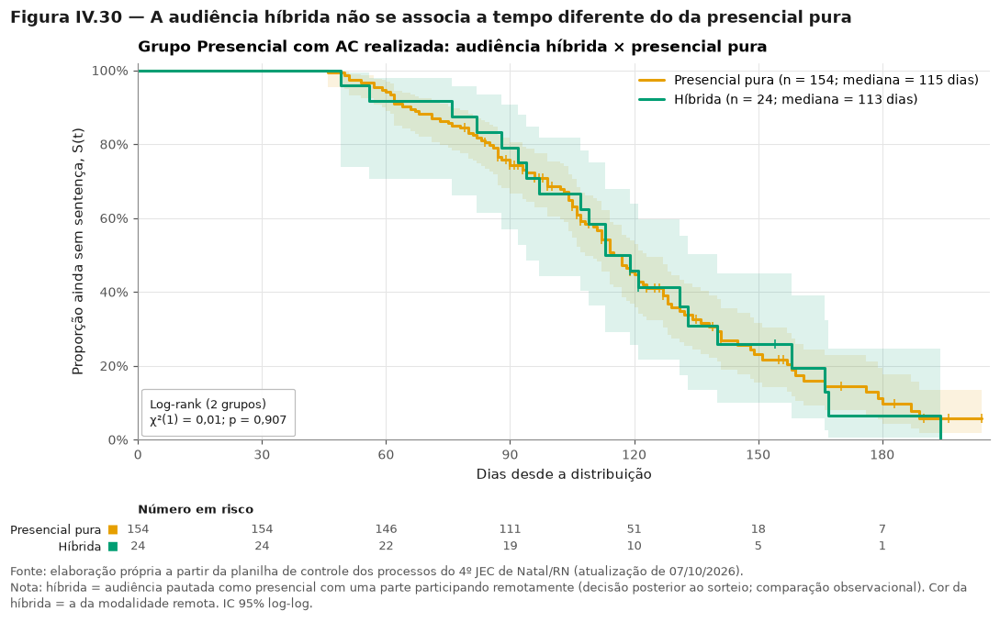

In [124]:
ac['tec'] = ac['tecnica_curta'].astype(str)
ORDEM_TEC = ac['tec'].value_counts().index.tolist()
lr_tec = multivariate_logrank_test(ac['T'], ac['tec'], ac['E'])
for t in ORDEM_TEC[1:]:
    ac[f'tec_{t}'] = (ac['tec'] == t).astype(int)
cols_tec = [f'tec_{t}' for t in ORDEM_TEC[1:]]
cox_tec = CoxPHFitter().fit(ac[['T', 'E', 'Remota'] + COLS_MES + cols_tec], 'T', 'E')
hr_tec = tabela_hr(cox_tec, cols_tec); hr_tec.index = [f'{t} × {ORDEM_TEC[0]}' for t in ORDEM_TEC[1:]]
print(f'Log-rank entre as 6 técnicas: χ² = {fmt_br(lr_tec.test_statistic, 2)}, {lr_tec.degrees_of_freedom} g.l., p = {p_br(lr_tec.p_value)}')
sob_tabela(hr_tec.rename_axis('Técnica (vs. referência)'), 'sob_ac_tecnica_cox',
           f'Cox da técnica de conciliação (referência = {ORDEM_TEC[0]}), ajustado por modalidade e mês', secao='4.8.2',
           casas=3, colunas_p=('p (Wald)',),
           nota=f'log-rank entre as 6 técnicas: χ² = {fmt_br(lr_tec.test_statistic, 2)} ({lr_tec.degrees_of_freedom} g.l.); '
                f'{p_txt(lr_tec.p_value)}.')

pres_ac = ac[ac.grupo2 == 'Presencial'].copy()
pres_ac['hib'] = pres_ac['hibrida'].fillna(False).astype(int)
lr_hib = logrank_test(pres_ac.loc[pres_ac.hib == 1, 'T'], pres_ac.loc[pres_ac.hib == 0, 'T'],
                      pres_ac.loc[pres_ac.hib == 1, 'E'], pres_ac.loc[pres_ac.hib == 0, 'E'])
print(f'Presencial com AC: híbridas {pres_ac.hib.sum()}, presenciais puras {(pres_ac.hib == 0).sum()} | '
      f'log-rank p = {p_br(lr_hib.p_value)}')

# técnicas: paleta própria (nenhuma cor de grupo, de desfecho ou de destaque)
CORES_TEC = dict(zip(ORDEM_TEC, ['#1a1a1a', '#56B4E9', '#882255', '#44AA99', '#DDAA33', '#8C8C8C']))
fig, ax = plt.subplots(figsize=(10.5, 6))
plot_km(ax, ac, tempo='T', evento='E', grupo='tec', ordem=ORDEM_TEC, cores=CORES_TEC, ic=False, passo=30, legenda=False)
eixo_pct(ax)
ax.legend(loc='upper right', fontsize=8.5)
ax.set_title('Processos com AC realizada, por técnica de conciliação sorteada')
anotar_teste(ax, texto_teste(f'Log-rank ({len(ORDEM_TEC)} técnicas)',
                             f'χ²({lr_tec.degrees_of_freedom}) = {fmt_br(lr_tec.test_statistic, 2)}', lr_tec.p_value,
                             f'HR vs. {ORDEM_TEC[0]}: {fmt_br(hr_tec["HR"].min(), 2)} a {fmt_br(hr_tec["HR"].max(), 2)}'),
             loc='lower left')
figura(fig, 'sob_ac_tecnica', 'Nenhuma técnica de conciliação acelera ou retarda a sentença de forma detectável',
       secao='4.8.2', nota='Kaplan-Meier sem IC (6 curvas); | = censura. Com 47 a 67 processos por técnica, só diferenças grandes '
                           'seriam detectadas: ausência de evidência não é equivalência.')

pres_ac['hib_txt'] = np.where(pres_ac['hib'] == 1, 'Híbrida', 'Presencial pura')
fig, ax = plt.subplots(figsize=(10, 5.4))
plot_km(ax, pres_ac, tempo='T', evento='E', grupo='hib_txt', ordem=['Presencial pura', 'Híbrida'],
        cores={'Presencial pura': CORES_GRUPO['Presencial'], 'Híbrida': CORES_GRUPO['Remota']}, passo=30)
eixo_pct(ax)
ax.set_title('Grupo Presencial com AC realizada: audiência híbrida × presencial pura')
anotar_teste(ax, texto_teste('Log-rank (2 grupos)', f'χ²(1) = {fmt_br(lr_hib.test_statistic, 2)}', lr_hib.p_value),
             loc='lower left')
figura(fig, 'sob_ac_hibrida', 'A audiência híbrida não se associa a tempo diferente do da presencial pura',
       secao='4.8.2', nota='híbrida = audiência pautada como presencial com uma parte participando remotamente (decisão posterior '
                           'ao sorteio; comparação observacional). Cor da híbrida = a da modalidade remota. IC 95% log-log.')

**Interpretação (subconjunto com AC realizada).**

- **Tamanho e composição.** 352 processos tiveram AC realizada (178 presenciais e 174 remotos). Os perfis de desfecho diferem: a remota tem mais extinções sem mérito (35 contra 20) e mais acordos (19 contra 14), e a presencial tem mais mérito (94 contra 81).
- **Modalidade.** Entre quem teve AC, a remota não difere da presencial: HR = 1,13 (0,88–1,44; p = 0,34) ajustado pelo mês; log-rank p = 0,234; medianas de 115 e 107 dias.
- **Tempo imortal.** Essas medianas são **maiores** que as dos grupos inteiros (96 e 95 dias), justamente porque quem teve AC precisou estar pendente até a data da audiência. Comparar esses processos com os que não tiveram AC (ou com o Controle) atribuiria à audiência um atraso que é, em parte, mecânico.
- **Técnica de conciliação.** Nenhuma diferença: log-rank de 6 grupos com χ²₅ = 1,55, p = 0,908; HRs entre 1,04 e 1,28 em relação a Padrões objetivos, todos com IC contendo 1. Com 47 a 67 processos por técnica, o estudo só detectaria diferenças grandes. A conclusão é "sem evidência de efeito da técnica sobre o tempo", não "técnicas equivalentes".
- **Audiência híbrida.** Dentro do grupo Presencial com AC, as 24 híbridas e as 154 presenciais puras têm tempos indistinguíveis (log-rank p = 0,907).
- **Ressalva.** Os três contrastes são **associativos**. Só a técnica foi sorteada, e mesmo ela só existe para quem chegou à audiência. A análise de *landmark* adequada exigiria a data da AC, que a planilha não registra: é um item a coletar numa replicação (via PJe/DataJud).

---

## 4.9 Análises de sensibilidade

Cada decisão de curadoria da Parte I (o que é evento, quem fica na base, como tratar datas suspeitas) poderia, em tese, mudar a conclusão. A tabela abaixo refaz a análise principal — **Cox grupo + mês (Efron)** e **log-rank de 3 grupos** — sob cenários alternativos. A conclusão é robusta se o HR e o p-valor mudarem pouco.

| Cenário | O que muda | Por quê |
|---|---|---|
| Principal | redistribuição censurada em T | análise de referência |
| (i-a) Redistribuição excluída | retira os 24 processos "Decisão" | eles saíram do juízo antes de receber o tratamento (inelegíveis pós-sorteio) |
| (i-b) Redistribuição competitiva | Fine-Gray da sentença (redistribuição competidora; log-rank → teste de permutação tipo Gray não repetido) | efeito sobre a incidência acumulada de sentença |
| (ii) Sem origem externa | retira os 12 processos vindos de outro órgão | chegaram com tramitação anterior |
| (iii-a) Sem desvio de protocolo | retira os 6 casos de híbrida incongruente (A12/A13) | registro duvidoso |
| (iii-b) Híbridas "como tratadas" | as 28 híbridas do grupo Presencial passam ao grupo Remota | parte participou remotamente (*as-treated*, não ITT) |
| (iv) Com as duplicatas | inclui as 6 linhas excluídas (reentradas e duplicatas) | E3: checar se a regra de exclusão importa |
| (v-a) Fim de semana deslocado | desfechos datados em sábado/domingo passam para a segunda-feira | A16: data de assinatura × data útil |
| (v-b) Fim de semana excluído | retira os 135 processos com desfecho em fim de semana | caso extremo (viesado: retira só eventos) |
| (vi) Censura comum em 65 dias | todos censurados em 65 dias (o menor seguimento) | neutraliza a entrada escalonada por completo |
| (vii) Dados ingênuos | "Decisão" contada como evento (como no notebook do professor, E10) | mostra o efeito do erro |
| (viii) Sem tempos zero | retira os 38 desfechos no dia da distribuição | A15: possíveis erros de data |

Cenário,n,sentenças,HR Presencial,IC P inf.,IC P sup.,HR Remota,IC R inf.,IC R sup.,p log-rank
Principal,938,708,"0,863","0,722","1,032","0,810","0,676","0,972","0,023"
(i-a) Redistribuição excluída,914,708,"0,865","0,723","1,035","0,817","0,681","0,980","0,028"
(i-b) Redistribuição competitiva (Fine-Gray),938,708,"0,805","0,674","0,963","0,770","0,642","0,923",–
(ii) Sem origem externa,926,699,"0,870","0,727","1,042","0,805","0,671","0,966","0,022"
(iii-a) Sem desvio de protocolo,932,704,"0,854","0,714","1,022","0,816","0,681","0,979","0,026"
(iii-b) Híbridas como tratadas (28 → Remota),938,708,"0,896","0,745","1,077","0,792","0,664","0,945","0,013"
(iv) Com as duplicatas (n = 944),944,708,"0,848","0,709","1,014","0,803","0,669","0,963","0,014"
(v-a) Fim de semana → segunda-feira,938,708,"0,863","0,721","1,032","0,810","0,675","0,971","0,023"
(v-b) Fim de semana excluído,803,573,"0,878","0,720","1,071","0,806","0,658","0,987","0,033"
(vi) Censura comum em 65 dias,938,305,"1,042","0,800","1,359","0,798","0,601","1,059","0,075"


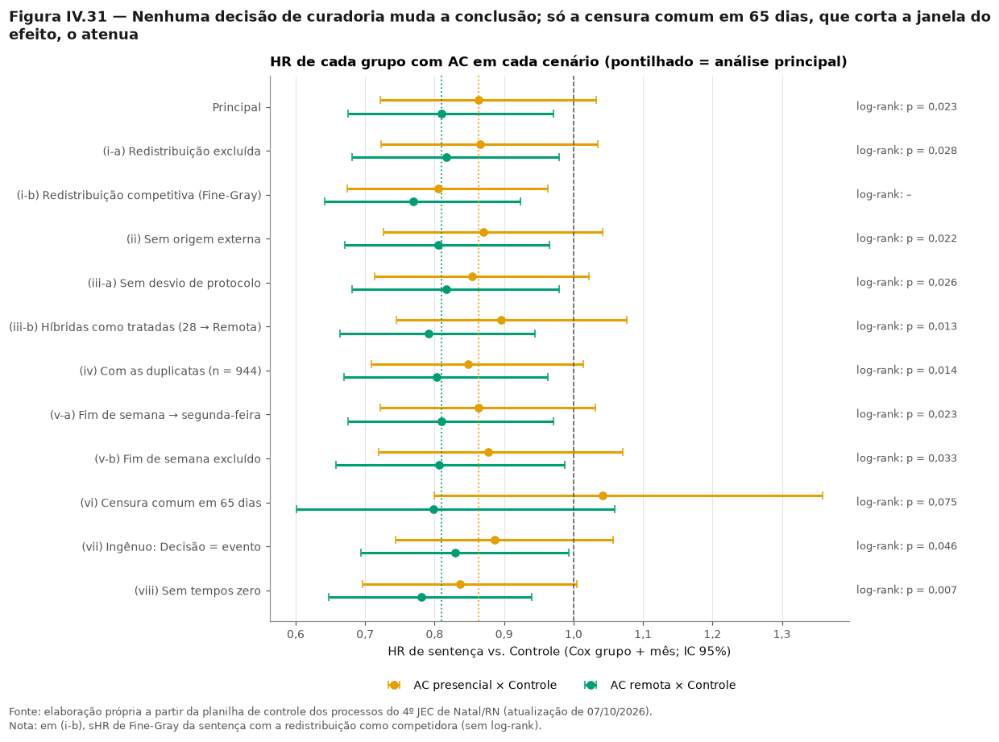

In [125]:
def cenario(df, nome, fine_gray=False):
    df = df[df['T'].notna()]
    if fine_gray:
        m = fine_gray_censura_conhecida(df, 1, X_CS)  # causa 1 aqui = sentença (K redefinido)
    else:
        m = CoxPHFitter().fit(df[['T', 'E'] + X_CS], 'T', 'E')
    t = tabela_hr(m, X_BASE, rotulo='HR')
    lr = multivariate_logrank_test(df['T'], df['grupo'].astype(str), df['E'])
    return {'Cenário': nome, 'n': len(df), 'sentenças': int(df['E'].sum()),
            'HR Presencial': t.iloc[0, 0], 'IC P inf.': t.iloc[0, 1], 'IC P sup.': t.iloc[0, 2],
            'HR Remota': t.iloc[1, 0], 'IC R inf.': t.iloc[1, 1], 'IC R sup.': t.iloc[1, 2],
            'p log-rank': lr.p_value if not fine_gray else np.nan}

sens = [cenario(sob, 'Principal')]
sens.append(cenario(sob[sob.CR != 2], '(i-a) Redistribuição excluída'))
sens.append(cenario(sob.assign(K=sob['CR']), '(i-b) Redistribuição competitiva (Fine-Gray)', fine_gray=True))
sens.append(cenario(sob[sob.origem_ext == 0], '(ii) Sem origem externa'))
sens.append(cenario(sob[~sob['desvio_protocolo'].astype(bool)], '(iii-a) Sem desvio de protocolo'))
_as = sob.copy()
_hib = (_as.grupo == 'Presencial') & (_as['hibrida'].fillna(False).astype(bool))
_as.loc[_hib, 'grupo'] = 'Remota'; _as['Presencial'] = (_as.grupo == 'Presencial').astype(int); _as['Remota'] = (_as.grupo == 'Remota').astype(int)
sens.append(cenario(_as, f'(iii-b) Híbridas como tratadas ({_hib.sum()} → Remota)'))
todas = pd.read_pickle(PROC / 'ed2_todas_linhas.pkl')
todas = todas[todas['tempo'].notna() & todas['evento'].notna()]
sens.append(cenario(preparar_sob(todas), f'(iv) Com as duplicatas (n = {len(todas)})'))
_fs = sob.copy()
_dow = _fs['dt_sentenca'].dt.dayofweek
_fs['T'] = _fs['T'] + np.where((_fs.CR > 0) & (_dow == 5), 2, 0) + np.where((_fs.CR > 0) & (_dow == 6), 1, 0)
sens.append(cenario(_fs, '(v-a) Fim de semana → segunda-feira'))
sens.append(cenario(sob[~sob['sentenca_fim_semana'].fillna(False).astype(bool)], '(v-b) Fim de semana excluído'))
_65 = sob.copy(); _65['E'] = ((_65.E == 1) & (_65['T'] <= 65)).astype(int); _65['T'] = _65['T'].clip(upper=65)
sens.append(cenario(_65, '(vi) Censura comum em 65 dias'))
sens.append(cenario(sob.assign(E=(sob.CR > 0).astype(int)), '(vii) Ingênuo: Decisão = evento'))
sens.append(cenario(sob[~sob['tempo_zero'].astype(bool)], '(viii) Sem tempos zero'))
SENS = pd.DataFrame(sens).set_index('Cenário')
sob_tabela(SENS, 'sob_sensibilidade', 'Sensibilidade do efeito do rito às decisões de curadoria (Cox grupo + mês e log-rank)',
           secao='4.9', casas=3, colunas_p=('p log-rank',), formatos={'n': 'int', 'sentenças': 'int'},
           nota='HR < 1 = sentença mais lenta que no Controle; IC 95% de Wald. No cenário (i-b), sHR de Fine-Gray e log-rank não '
                'aplicável (–). Destaque: log-rank p < 0,05.')

fig, ax = plt.subplots(figsize=(11, 7.5))
y = np.arange(len(SENS))[::-1]
for desl, g, col in [(0.15, 'Presencial', 'P'), (-0.15, 'Remota', 'R')]:
    hr = SENS[f'HR {g}']; li = SENS[f'IC {col} inf.']; ls = SENS[f'IC {col} sup.']
    ax.errorbar(hr, y + desl, xerr=[hr - li, ls - hr], fmt='o', ms=6, color=CORES_GRUPO[g], capsize=3, label=ROTULO_TERMO[g])
ax.axvline(1, color=TINTA_2, ls='--', lw=1)
ax.axvline(SENS.loc['Principal', 'HR Presencial'], color=CORES_GRUPO['Presencial'], ls=':', lw=1.2)
ax.axvline(SENS.loc['Principal', 'HR Remota'], color=CORES_GRUPO['Remota'], ls=':', lw=1.2)
for yi, pv in zip(y, SENS['p log-rank']):
    ax.annotate('log-rank: –' if pd.isna(pv) else f'log-rank: {p_txt(pv)}', (1, yi), xycoords=('axes fraction', 'data'),
                xytext=(6, 0), textcoords='offset points', va='center', fontsize=8.5, color=TINTA_2)
ax.set_yticks(y, SENS.index, fontsize=9); ax.set_ylim(-0.7, len(SENS) - 0.3)
ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
ax.set_xlabel('HR de sentença vs. Controle (Cox grupo + mês; IC 95%)')
ax.set_title('HR de cada grupo com AC em cada cenário (pontilhado = análise principal)')
legenda_abaixo(ax, ncol=2, dy=-0.09)
figura(fig, 'sob_sensibilidade', 'Nenhuma decisão de curadoria muda a conclusão; só a censura comum em 65 dias, que corta '
       'a janela do efeito, o atenua', secao='4.9',
       nota='em (i-b), sHR de Fine-Gray da sentença com a redistribuição como competidora (sem log-rank).')

**Interpretação (sensibilidade).**

- **Robustez geral.** Em 11 dos 12 cenários, os HRs ficam em faixas estreitas e o log-rank continua significativo (p de 0,007 a 0,046):
  - **0,84–0,90 para a AC presencial**, com IC contendo ou tocando 1 em todos os cenários, exceto no Fine-Gray (i-b), em que o sHR é 0,81 (0,67–0,96);
  - **0,77–0,83 para a AC remota**, com IC sempre abaixo de 1.

  Excluir as redistribuições, a origem externa, os desvios de protocolo ou os tempos zero, reincluir as duplicatas, deslocar ou excluir as sentenças de fim de semana: **nenhuma decisão de curadoria muda a conclusão**.
- **(iii-b) Híbridas "como tratadas".** Passar as 28 híbridas para o grupo Remota aproxima a presencial de 1 (HR = 0,90) e fortalece a remota (0,79; log-rank p = 0,013). A conclusão não muda.
- **(i-b) Redistribuição como competidora (Fine-Gray da sentença).** Os sHR (0,81 e 0,77) são um pouco **menores** que os HRs, porque os grupos com AC têm o dobro de redistribuições: menos processos chegam a ter sentença no 4º JEC.
- **(vii) Dados ingênuos ("Decisão" = evento, como o notebook do professor; E10).** O efeito fica atenuado (HR = 0,89 e 0,83; log-rank p = 0,046): contar redistribuições como sentenças "acelera" artificialmente os grupos que mais as têm.
- **(vi) Censura comum em 65 dias: a exceção esperada.** HR = 1,04 (0,80–1,36) na presencial e 0,80 (0,60–1,06) na remota; p = 0,075. Até 65 dias o efeito da AC ainda não apareceu (seção 4.5.2: a diferença está na janela de 30 a 90 dias e sobretudo depois de 60). Esse cenário não refuta o resultado principal; mostra **em que momento** ele surge. Para neutralizar a entrada escalonada sem perder a janela relevante, a estratégia adequada é a estratificação por mês (4.3.4 e modelo b′), que mantém o efeito (p = 0,045 e HR remota = 0,80).

---

## 4.10 Síntese da análise de sobrevivência

A tabela reúne as medidas de efeito principais. Elas respondem a perguntas complementares: a **mediana** e o **RMST** em dias (escala de tempo), o **HR** em taxa diária (escala de risco), a **razão de tempos** do AFT e a **FIA a 90 dias** por tipo de desfecho (o que acontece com os processos).

In [126]:
sint = {}
for g in ORDEM_GRUPO:
    q = quartis.loc[ROTULO_GRUPO[g], 'Mediana']
    r180 = rmst_tab.query('`τ (dias)` == 180 and Grupo == @g').iloc[0]
    linha = {'n': int((sob.grupo == g).sum()), 'Sentenças': int(sob.loc[sob.grupo == g, 'E'].sum()),
             'Mediana KM, dias (IC 95%)': q,
             'RMST 180 d, dias (IC 95%)': f"{fmt_br(r180['RMST (dias)'], 1)} ({fmt_br(r180['IC 95% inf.'], 1)}–{fmt_br(r180['IC 95% sup.'], 1)})"}
    if g == 'Controle':
        linha |= {'ΔRMST 180 d vs. Controle (IC bootstrap)': 'referência', 'HR Cox (b) (IC 95%)': 'referência',
                  f'Razão de tempos {MELHOR_AFT} (IC 95%)': 'referência'}
    else:
        d = dif_rmst.query('`τ (dias)` == 180 and Contraste == @g + " − Controle"').iloc[0]
        h = HR_B.loc[ROTULO_TERMO[g]]
        tr = TR_AFT[(TR_AFT.Modelo == MELHOR_AFT)].loc[ROTULO_TERMO[g]]
        linha |= {'ΔRMST 180 d vs. Controle (IC bootstrap)': f"{fmt_br(d['Diferença (dias)'], 1)} ({fmt_br(d['IC 95% inf. (bootstrap)'], 1)} a {fmt_br(d['IC 95% sup. (bootstrap)'], 1)})",
                  'HR Cox (b) (IC 95%)': f"{fmt_br(h['HR'], 2)} ({fmt_br(h['IC 95% inf.'], 2)}–{fmt_br(h['IC 95% sup.'], 2)})",
                  f'Razão de tempos {MELHOR_AFT} (IC 95%)': f"{fmt_br(tr['Razão de tempos'], 2)} ({fmt_br(tr['IC 95% inf.'], 2)}–{fmt_br(tr['IC 95% sup.'], 2)})"}
    for k in (1, 2, 3):
        linha[f'FIA 90 d: {CAUSAS[k]}'] = CIF_TAB.loc[(CAUSAS[k], 90), g]
    sint[ROTULO_GRUPO[g]] = linha
SINTESE_SOB = pd.DataFrame(sint)
tabela(SINTESE_SOB.rename_axis('Medida'), 'sob_sintese', 'Síntese das medidas de efeito da análise de sobrevivência',
       secao='4.10', formatos={c: 'texto' for c in SINTESE_SOB.columns},
       nota='IC 95% entre parênteses. Mediana e RMST em dias; HR < 1 e razão de tempos > 1 = sentença mais lenta que no '
            'Controle; FIA = incidência acumulada (Aalen-Johansen).')
print(f"Testes globais: log-rank p = {p_br(lr_global.p_value)}; estratificado por mês p = {p_br(LR_ESTRAT_P)}; "
      f"riscos proporcionais violados? TRV janelas p = {p_br(P_TRV_C)}")
SINTESE_SOB.to_csv(PROC / 'ed2_sintese_sobrevivencia.csv', sep=';', encoding='utf-8-sig')

Medida,"Controle (rito atual, AC opcional)",AC presencial obrigatória,AC remota obrigatória
n,313,314,311
Sentenças,262,230,216
"Mediana KM, dias (IC 95%)",81 (75–84),96 (85–106),95 (89–102)
"RMST 180 d, dias (IC 95%)","82,1 (76,0–88,0)","88,6 (82,0–95,3)","92,9 (86,9–99,4)"
ΔRMST 180 d vs. Controle (IC bootstrap),referência,"6,5 (-2,1 a 15,8)","10,7 (1,9 a 19,5)"
HR Cox (b) (IC 95%),referência,"0,87 (0,72–1,04)","0,81 (0,67–0,97)"
Razão de tempos Weibull (IC 95%),referência,"1,11 (0,93–1,34)","1,21 (1,00–1,45)"
FIA 90 d: Homologação,"4,9% (2,5%–7,3%)","6,4% (3,7%–9,2%)","10,6% (7,0%–14,1%)"
FIA 90 d: Mérito,"31,1% (25,8%–36,3%)","7,8% (4,8%–10,9%)","7,5% (4,3%–10,6%)"
FIA 90 d: Sem mérito,"23,5% (18,8%–28,2%)","32,0% (26,8%–37,2%)","27,3% (22,3%–32,4%)"


Testes globais: log-rank p = 0,023; estratificado por mês p = 0,045; riscos proporcionais violados? TRV janelas p = 0,026


**Síntese e resposta à pergunta de pesquisa 2.**

**A AC obrigatória altera o tempo até a sentença?** Sim, e no sentido de **alongá-lo**, contra a expectativa que motivou o experimento.

| Medida | Controle | AC presencial | AC remota |
|---|---|---|---|
| Mediana (dias) | 81 | 96 | 95 |
| RMST em 180 dias (dias) | 82,1 | 88,6 | 92,9 |
| HR ajustado (Cox b) | referência | 0,87 (0,72–1,04) | 0,81 (0,67–0,97) |

- O log-rank global dá p = 0,023, e o estratificado por mês, p = 0,045.
- **Remota:** o efeito é estatisticamente sólido. ΔRMST₁₈₀ = +10,7 dias (IC 1,9 a 19,5); HR = 0,81; resultado robusto em 11 de 12 cenários de sensibilidade.
- **Presencial:** a direção é a mesma (+6,5 dias; HR = 0,87), mas o IC inclui o efeito nulo. Os dados não permitem afirmar que a presencial seja mais lenta que o Controle **no tempo total**.

**Quando o atraso acontece.** O atraso não é uniforme: concentra-se entre 30 e 90 dias (HR ≈ 0,62 nos dois grupos com AC), quando as audiências obrigatórias estão em pauta. Aos 90 dias, cerca de 13 a 14 p.p. a mais de processos estão sem sentença. Depois de 90 dias as taxas se igualam, mas o atraso já acumulado não é recuperado.

**A modalidade importa?** Para o **tempo**, não: Remota × Presencial tem log-rank p = 0,52, e entre os processos com AC realizada, HR = 1,13 (p = 0,34). Para **como** o processo termina, há indícios de diferença:

- a presencial produz mais extinções sem mérito (sHR = 1,46);
- a remota produz mais acordos (sHR = 1,87);
- ambas reduzem os julgamentos de mérito à metade (sHR ≈ 0,42–0,46).

**O achado principal é de mecanismo.** A comparação do tempo total **mascara efeitos opostos**: a AC obrigatória acelera extinções e acordos, mas atrasa fortemente o julgamento de mérito. Para a política judiciária, isso desloca a pergunta de "o rito é mais rápido?" para "o rito resolve mais conflitos?". Um ganho de acordos na remota (de 7,6% para 12,9% aos 180 dias) convive com mais extinções sem resolução e com menos e mais tardias decisões de mérito.

**Limitações.**

- O seguimento é curto: a cauda além de 180 dias não é estimável, e a pauta remota se estende até 24/11/2026.
- A data da AC não foi registrada, o que impede *landmark* e covariável tempo-dependente da audiência.
- O motivo da extinção sem mérito (ausência do autor ou outro) não está codificado; a hipótese do art. 51, I, é **compatível** com os dados, mas não verificada diretamente.
- É uma única unidade judiciária (validade externa).

# PARTE V — ANÁLISE MULTIVARIADA E MODELAGEM

A Parte IV estimou os efeitos dos grupos sobre o **tempo** com modelos que respeitam a censura (Kaplan-Meier, Cox, AFT e riscos competitivos). Esta parte pergunta o que a **modelagem multivariada** acrescenta: (i) por que a regressão linear sobre o tempo, usada no notebook do professor, não serve (E26); (ii) o que modelos de **classificação** (regressão logística, logit multinomial e árvores de decisão; ARTES; BARROSO, 2023, cap. 10 e 11) dizem sobre o **acordo** e o **tipo de desfecho**; (iii) que estrutura a **análise de correspondência** revela na tabela grupo × desfecho; e (iv) qual modelo de tempo, entre os que tratam a censura, **descreve e prevê** melhor.

### Limitação que condiciona toda a Parte V: quase não há covariáveis

O projeto de pesquisa previa como variáveis de controle o **tipo de ação, o valor da causa e o número de partes** (ver `docs/r1_documentos.md`), e a literatura de duração processual acrescentaria o **advogado constituído** (ou *jus postulandi*), a **pessoa jurídica no polo passivo** e o **litigante habitual**. **Nenhuma dessas variáveis foi coletada.** A planilha só registra o que o próprio experimento produziu:

| Variável disponível | Natureza | Pode entrar como preditora? |
|---|---|---|
| `grupo` (sorteado) | basal, aleatorizada | sim: é o fator de interesse |
| mês de distribuição / ordem de chegada | basal (calendário) | sim; mas determina o seguimento (`followup`), com o qual é quase colinear |
| `origem_externa` (12 processos) | basal | sim, mas rara |
| `ac_realizada`, `hibrida`, técnica | **pós-sorteio** (ocorrem durante o processo; zero estrutural no Controle) | só no subconjunto com audiência, e como mediadores exploratórios |
| `acordo_ac`, `acordo_fora`, `acordo` | **desfechos** intermediários | só como resposta, nunca como preditora do tempo (viés de tempo imortal) |
| `tipo_desfecho` | desfecho | só como resposta |

Consequência: os modelos desta parte têm, no máximo, **três ou quatro preditores**, e todos de baixa variabilidade entre processos. Isso não é defeito do desenho: o sorteio foi feito para uma **comparação causal entre grupos** (que dispensa covariáveis para ser não enviesada), e não para **prever** a duração de um processo individual. Esperam-se, portanto, poder explicativo e preditivo baixos, e a parte é honesta quanto a isso. A seção 5.6 lista as variáveis que permitiriam uma modelagem multivariada de verdade (questão 2.9).

**Codificação comum.** O mês entra como escore ordinal (`mes_num`: jan = 1, …, ago = 8), uma tendência linear de calendário com um único parâmetro; agosto tem só 6 processos, o que desaconselha um parâmetro por mês. Grupo: Controle como referência.

In [127]:
if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')

from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, accuracy_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, cross_val_predict
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from lifelines import WeibullAFTFitter, LogNormalAFTFitter, NelsonAalenFitter
from lifelines.utils import k_fold_cross_validation, concordance_index

RNG_MUL = np.random.default_rng(SEMENTE)
mul_res = {}          # resultados guardados para a síntese (5.6)

mul = dados.copy()
mul['grupo'] = pd.Categorical(mul['grupo'].astype(str), categories=ORDEM_GRUPO)
mul['mes_num'] = mul['mes_distribuicao'].cat.codes.astype(int) + 1
mul['presencial'] = (mul['grupo'] == 'Presencial').astype(int)
mul['remota'] = (mul['grupo'] == 'Remota').astype(int)
mul['T'] = mul['tempo'].astype(float)
mul['E'] = mul['evento'].astype(int)
mul['T_pos'] = mul['tempo_pos'].astype(float)
mul['log_T'] = np.log(mul['T_pos'])
mul['followup_f'] = mul['followup'].astype(float)
mul['log_followup'] = np.log(mul['followup_f'])
mul['dia_estudo_f'] = mul['dia_estudo'].astype(float)
mul['encerrado_b'] = mul['encerrado'].astype(bool)
mul['desfecho'] = mul['tipo_desfecho'].astype(str)
mul['homolog'] = (mul['desfecho'] == 'Homologação').astype(int)
mul['hibrida_b'] = mul['hibrida'].fillna(False).astype(bool).astype(int)
mul['origem_ext'] = mul['origem_externa'].astype(bool).astype(int)

NOMES_COEF = {'Intercept': 'Intercepto', 'C(grupo)[T.Presencial]': 'Presencial vs Controle',
              'C(grupo)[T.Remota]': 'Remota vs Controle', 'mes_num': 'Mês de distribuição (+1 mês)',
              'log_followup': 'log(seguimento)', 'hibrida_b': 'Híbrida (sim)', 'remota': 'Remota vs Presencial',
              'presencial': 'Presencial vs Controle', 'origem_ext': 'Origem externa',
              'dia_estudo_f': 'Dia de distribuição'}

def mul_ic_wilson(x, n):
    li, ls = proportion_confint(x, n, method='wilson')
    return li, ls

resumo = pd.DataFrame({
    'Subconjunto': ['Todos', 'Encerrados (sentença ou redistribuição)', 'Sentenciados (evento = 1)',
                    'Com audiência realizada'],
    'n': [len(mul), int(mul['encerrado_b'].sum()), int(mul['E'].sum()),
          int(mul['ac_realizada'].fillna(False).astype(bool).sum())]})
print(f"Correlação entre mês de distribuição e log(seguimento): r = {fmt_br(np.corrcoef(mul['mes_num'], mul['log_followup'])[0, 1], 3)}")
tabela(resumo.rename(columns={'n': 'Processos (n)'}), 'mul_subconjuntos', 'Subconjuntos analíticos usados na Parte V',
       secao='5', nota='encerrados = com sentença ou redistribuição até 07/10/2026; audiência realizada só existe nos grupos '
                       'Presencial e Remota (zero estrutural no Controle).')

# ---------------------------------------------------------------- auxiliares gráficos da Parte V
# Cores de "estimadores/modelos" (entidade própria): nenhuma repete a cor de um grupo.
COR_MODELO = '#2B3A4A'          # modelo de referência / série única
COR_VIES = DESTAQUE             # estimador enviesado ou alternativa em contraste
NOMES_VAR = {'presencial': 'Presencial (1 = sim)', 'remota': 'Remota (1 = sim)', 'dia_estudo': 'Dia de distribuição',
             'origem_ext': 'Origem externa (1 = sim)', 'ac_realizada': 'AC realizada (1 = sim)',
             'hibrida': 'AC híbrida (1 = sim)'}


def mul_peq(p):
    """'< 0,001' ou '= 0,034' (para escrever 'p < 0,001' / 'p = 0,034')."""
    return '< 0,001' if p < 0.001 else '= ' + fmt_p(p)


def mul_ic(v, lo, hi, casas=3):
    return f'{fmt_br(v, casas)} [{fmt_br(lo, casas)}; {fmt_br(hi, casas)}]'


def mul_fmt_razao(v):
    """Rótulo de eixo para razões (escala log): 0,25 · 0,5 · 1 · 1,5 · 2."""
    s = fmt_br(v, 2)
    return s.rstrip('0').rstrip(',') if ',' in s else s


def mul_eixo_razao(ax, valores, eixo='y'):
    """Escala log para razões (RC, RRR, razão de tempos) com marcas legíveis em pt-BR e linha de nulidade em 1."""
    v = np.asarray([x for x in valores if np.isfinite(x) and x > 0], float)
    lo, hi = min(v.min(), 1) / 1.25, max(v.max(), 1) * 1.25
    cand = np.array([0.05, 0.1, 0.2, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6, 8, 10, 20, 50, 100])
    marcas = cand[(cand >= lo) & (cand <= hi)]
    alvo = ax.yaxis if eixo == 'y' else ax.xaxis
    (ax.set_yscale if eixo == 'y' else ax.set_xscale)('log')
    alvo.set_major_locator(mpl.ticker.FixedLocator(marcas))
    alvo.set_major_formatter(FuncFormatter(lambda x, _: mul_fmt_razao(x)))
    alvo.set_minor_locator(mpl.ticker.NullLocator())
    (ax.set_ylim if eixo == 'y' else ax.set_xlim)(lo, hi)
    (ax.axhline if eixo == 'y' else ax.axvline)(1, color=TINTA_2, lw=1, zorder=1)


def mul_forest(ax, est, li, ls, x=None, cor=COR_MODELO, textos=None, label=None, marker='o'):
    """Pontos com IC 95% (vertical), um por posição x; `textos` = rótulos seletivos ao lado do ponto."""
    est, li, ls = (np.asarray(a, float) for a in (est, li, ls))
    x = np.arange(len(est)) if x is None else np.asarray(x, float)
    cores = cor if isinstance(cor, (list, tuple)) else [cor] * len(est)
    for i in range(len(est)):
        ax.errorbar(x[i], est[i], yerr=[[est[i] - li[i]], [ls[i] - est[i]]], fmt=marker, ms=7, color=cores[i],
                    ecolor=cores[i], elinewidth=1.6, capsize=4, label=label if i == 0 else None, zorder=3)
        if textos is not None and textos[i]:
            ax.annotate(textos[i], (x[i], est[i]), xytext=(9, 0), textcoords='offset points', va='center',
                        ha='left', fontsize=8.5, color=TINTA)
    ax.grid(axis='x', visible=False)


def mul_rotular_pontos(ax, xs, ys, textos, tamanho=9, negrito=None):
    """Rótulos de pontos sem colisão: testa 8 posições ao redor de cada ponto e fica com a primeira livre."""
    fig = ax.figure
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    ocupado = []
    pts = ax.transData.transform(np.column_stack([xs, ys]))
    for (px, py) in pts:
        ocupado.append(mpl.transforms.Bbox.from_extents(px - 6, py - 6, px + 6, py + 6))
    offs = [(8, 6, 'left', 'bottom'), (8, -6, 'left', 'top'), (-8, 6, 'right', 'bottom'), (-8, -6, 'right', 'top'),
            (0, 10, 'center', 'bottom'), (0, -10, 'center', 'top'), (14, 0, 'left', 'center'), (-14, 0, 'right', 'center')]
    for k, (x, y, t) in enumerate(zip(xs, ys, textos)):
        escolhido = None
        for dx, dy, ha, va in offs:
            a = ax.annotate(t, (x, y), xytext=(dx, dy), textcoords='offset points', ha=ha, va=va, fontsize=tamanho,
                            color=TINTA, fontweight='bold' if negrito and negrito[k] else 'normal')
            bb = a.get_window_extent(rend).expanded(1.05, 1.1)
            if not any(bb.overlaps(o) for o in ocupado):
                escolhido = a
                break
            a.remove()
        if escolhido is None:   # nenhuma posição livre: usa a primeira
            dx, dy, ha, va = offs[0]
            escolhido = ax.annotate(t, (x, y), xytext=(dx, dy), textcoords='offset points', ha=ha, va=va,
                                    fontsize=tamanho, color=TINTA)
        ocupado.append(escolhido.get_window_extent(rend))


def mul_arvore(ax, modelo, colunas, classes=None, cores_classe=None, fontsize=9, precisao=2):
    """plot_tree legível: nomes de variáveis em português, vírgula decimal, nós coloridos pela entidade.

    Classificação: cor da classe majoritária (intensidade = pureza). Regressão: escala divergente DIV pelo valor do nó.
    """
    anns = plot_tree(modelo, feature_names=[NOMES_VAR.get(c, c) for c in colunas], class_names=classes,
                     filled=False, rounded=True, impurity=False, proportion=True, fontsize=fontsize, ax=ax,
                     precision=precisao)
    valores = modelo.tree_.value[:, 0, :]
    if classes is None:
        lim = np.abs(valores[:, 0]).max() or 1
    for i, a in enumerate(anns):
        txt = a.get_text()
        txt = re.sub(r'(\d)\.(\d)', r'\1,\2', txt)
        txt = (txt.replace('samples', 'processos').replace('value', 'proporções' if classes is not None else 'resíduo médio')
                  .replace('class', 'classe').replace('<=', '≤').replace('True', 'sim').replace('False', 'não'))
        a.set_text(txt)
        caixa = a.get_bbox_patch()
        if caixa is None or i >= len(valores):
            continue
        if classes is not None:
            v = valores[i] / valores[i].sum()
            k = int(np.argmax(v))
            pureza = (v[k] - 1 / len(v)) / (1 - 1 / len(v))
            caixa.set_facecolor(mpl.colors.to_rgba(cores_classe[classes[k]], 0.12 + 0.43 * pureza))
        else:
            caixa.set_facecolor(DIV(0.5 + 0.5 * valores[i, 0] / lim))
        caixa.set_edgecolor('#8c8c8c')
    return anns

Correlação entre mês de distribuição e log(seguimento): r = -0,969


Subconjunto,Processos (n)
Todos,938
Encerrados (sentença ou redistribuição),732
Sentenciados (evento = 1),708
Com audiência realizada,352


## 5.1 Regressão linear (OLS) sobre o tempo: por que não serve

O notebook do professor ajustou `duracao_proc ~ grupo` por mínimos quadrados sobre todos os processos, inclusive os ativos (E14, E26). Há duas versões "corrigidas" que alguém poderia tentar, e ambas falham por razões diferentes:

1. **OLS só com os sentenciados** (n = 708), tirando os censurados. Responde a uma pergunta condicional ("entre os que já tiveram sentença, quanto demoraram?") e é **enviesada para tempos curtos**: um processo distribuído em julho só entra na amostra se for julgado em menos de ~90 dias.
2. **OLS sobre log(tempo)**, que aproxima a regressão de um modelo log-normal (AFT) e tenta corrigir a assimetria; o problema da censura continua.

Ajustam-se as duas versões com `grupo + mês`, examinam-se R² e resíduos e, por fim, comparam-se os coeficientes com os de um **modelo log-normal AFT com censura** (a mesma escala, log T; COLOSIMO; GIOLO, 2006, eq. 4.10, p. 122), que usa todos os 938 processos. A diferença entre eles é o **viés de selecionar só os encerrados**.

### 5.1.1 Ajuste e R²

H0 (teste F global): todos os coeficientes, exceto o intercepto, são nulos. H1: ao menos um não é. Os coeficientes do modelo linear estão em dias; os do modelo em log, exponenciados, são **razões de médias geométricas** (exp(β) = 0,90 significa tempo típico 10% menor).

In [128]:
sent = mul[mul['E'] == 1].copy()
ols_lin = smf.ols('T ~ C(grupo) + mes_num', data=sent).fit()
ols_log = smf.ols('log_T ~ C(grupo) + mes_num', data=sent).fit()
ols_log_todos = smf.ols('log_T ~ C(grupo) + mes_num', data=mul).fit()   # versão do professor (censurados como completos)

def mul_tab_ols(res, exp=False):
    ic = res.conf_int()
    tab = pd.DataFrame({'coef': res.params, 'li': ic[0], 'ls': ic[1], 'p': res.pvalues})
    if exp:
        tab[['coef', 'li', 'ls']] = np.exp(tab[['coef', 'li', 'ls']])
    rot = 'exp(β) (razão de médias geométricas)' if exp else 'β (dias)'
    return pd.DataFrame({'Termo': [NOMES_COEF.get(i, i) for i in tab.index], rot: tab['coef'].to_numpy(),
                         'IC 95% inf.': tab['li'].to_numpy(), 'IC 95% sup.': tab['ls'].to_numpy(),
                         'p': tab['p'].to_numpy()}), rot

for id_, nome, res, ex in [('mul_ols_lin', 'OLS do tempo (dias) ~ grupo + mês, só sentenciados: o mês tem efeito negativo', ols_lin, False),
                           ('mul_ols_log', 'OLS de log(tempo) ~ grupo + mês, só sentenciados: razões de médias geométricas', ols_log, True)]:
    t_ols, col = mul_tab_ols(res, ex)
    c = 3 if ex else 1
    tabela(t_ols, id_, nome, secao='5.1.1', formatos={col: c, 'IC 95% inf.': c, 'IC 95% sup.': c}, destaque='p',
           nota=f'n = {int(res.nobs)}; R² = {fmt_br(res.rsquared, 3)}; R² ajustado = {fmt_br(res.rsquared_adj, 3)}; '
                f'teste F global = {fmt_br(res.fvalue, 2)} (p {mul_peq(res.f_pvalue)}). '
                'Linhas em destaque: p < 0,05. Referência do grupo: Controle.')
mul_res['ols_r2'] = ols_lin.rsquared
mul_res['olslog_r2'] = ols_log.rsquared

Termo,β (dias),IC 95% inf.,IC 95% sup.,p
Intercepto,"86,8","77,3","96,3","< 0,001"
Presencial vs Controle,"-1,7","-10,3","6,8","0,692"
Remota vs Controle,"0,8","-7,9","9,5","0,850"
Mês de distribuição (+1 mês),"-4,2","-6,1","-2,2","< 0,001"


Termo,exp(β) (razão de médias geométricas),IC 95% inf.,IC 95% sup.,p
Intercepto,"57,124","41,223","79,159","< 0,001"
Presencial vs Controle,"0,774","0,577","1,039","0,088"
Remota vs Controle,"0,888","0,659","1,197","0,435"
Mês de distribuição (+1 mês),"0,917","0,857","0,981","0,012"


**Interpretação.** Os dois modelos lineares explicam quase nada: **R² = 0,024** para o tempo em dias e **R² = 0,013** para log(tempo). O teste F é "significativo" (p < 0,001 e p = 0,029) **só por causa do mês**, e o sinal do mês é o que denuncia o problema: entre os sentenciados, cada mês a mais de distribuição "reduz" o tempo em 4,2 dias (IC 95% −6,1 a −2,2), ou 8,3% na escala log (exp(β) = 0,917). Isso não quer dizer que os processos de julho são julgados mais depressa; quer dizer que, dos processos de julho, **só os rápidos já aparecem** como sentenciados. Os efeitos de grupo não se distinguem de zero (Presencial −1,7 dia, p = 0,692; Remota +0,8 dia, p = 0,850). O R² baixo, por si só, não seria defeito, porque a pergunta é causal e o sorteio dispensa explicar a variância individual; o defeito é que a amostra condicionada ao encerramento produz coeficientes enviesados (5.1.3).

### 5.1.2 Diagnóstico dos resíduos

Os pressupostos do OLS para a inferência são resíduos com **variância constante** e, para amostras pequenas, aproximadamente **normais**. Três gráficos por modelo:

- **resíduos × valores ajustados**: deve ser uma nuvem sem forma. Como só há 3 grupos × 8 meses, os ajustados formam poucas colunas verticais (pontos com leve deslocamento horizontal para visualização);
- **QQ normal** dos resíduos: pontos sobre a reta indicam normalidade;
- **teste de Breusch-Pagan** (H0: variância dos resíduos constante, homocedasticidade; H1: variância depende dos preditores), com o gráfico dos resíduos ao quadrado contra os ajustados, que é exatamente o que o teste regride.

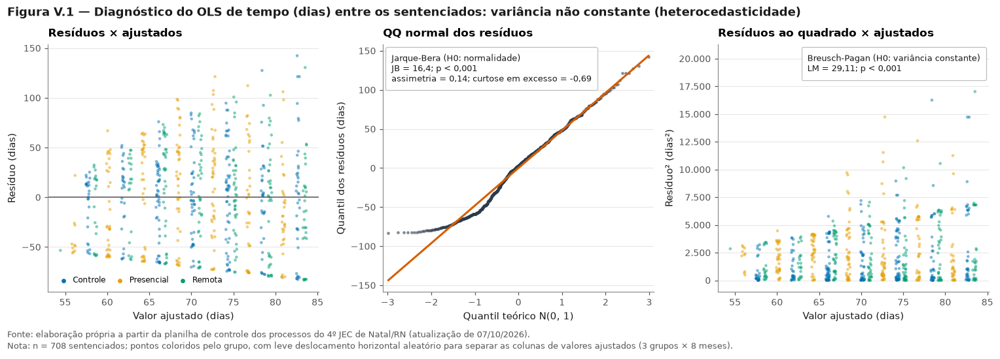

tempo (dias): Breusch-Pagan LM = 29,11 (p < 0,001); Jarque-Bera = 16,4 (p < 0,001); assimetria = 0,14; curtose excesso = -0,69


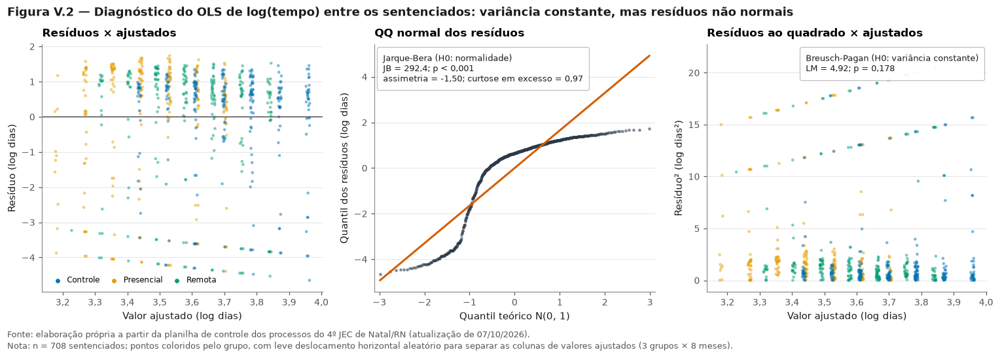

log(tempo): Breusch-Pagan LM = 4,92 (p 0,178); Jarque-Bera = 292,4 (p < 0,001); assimetria = -1,50; curtose excesso = 0,97


In [129]:
for linha, (nome, res, unid, id_) in enumerate([('tempo (dias)', ols_lin, 'dias', 'mul_ols_diag_lin'),
                                                ('log(tempo)', ols_log, 'log dias', 'mul_ols_diag_log')]):
    resid, ajust = res.resid, res.fittedvalues
    cor = sent['grupo'].map(CORES_GRUPO)
    jit = ajust + RNG_MUL.uniform(-0.3, 0.3, len(ajust)) * (ajust.std() / 10)   # mesma sequência aleatória de antes
    bp_lm, bp_p, _, _ = het_breuschpagan(resid, res.model.exog)
    jb = stats.jarque_bera(resid)
    fig, eixos = plt.subplots(1, 3, figsize=(14, 4.4))
    ax = eixos[0]
    ax.scatter(jit, resid, s=9, alpha=0.5, c=cor, lw=0)
    ax.axhline(0, color=TINTA_2, lw=1)
    ax.set(title='Resíduos × ajustados', xlabel=f'Valor ajustado ({unid})', ylabel=f'Resíduo ({unid})')
    for g in ORDEM_GRUPO:
        ax.scatter([], [], color=CORES_GRUPO[g], label=g, s=20)
    ax.legend(loc='lower left', ncol=3, fontsize=8, handletextpad=0.2, columnspacing=0.8)
    ax = eixos[1]
    sm.qqplot(resid, line='s', ax=ax, markersize=3, alpha=0.6, markerfacecolor=COR_MODELO, markeredgecolor='none')
    ax.get_lines()[1].set_color(DESTAQUE)
    ax.set(title='QQ normal dos resíduos', xlabel='Quantil teórico N(0, 1)', ylabel=f'Quantil dos resíduos ({unid})')
    anotar_teste(ax, texto_teste('Jarque-Bera (H0: normalidade)', f'JB = {fmt_br(jb.statistic, 1)}', jb.pvalue,
                                 f'assimetria = {fmt_br(stats.skew(resid), 2)}; curtose em excesso = {fmt_br(stats.kurtosis(resid), 2)}'),
                 loc='upper left')
    ax = eixos[2]
    ax.scatter(jit, resid ** 2, s=9, alpha=0.5, c=cor, lw=0)
    ax.set(title='Resíduos ao quadrado × ajustados', xlabel=f'Valor ajustado ({unid})', ylabel=f'Resíduo² ({unid}²)')
    anotar_teste(ax, texto_teste('Breusch-Pagan (H0: variância constante)', f'LM = {fmt_br(bp_lm, 2)}', bp_p),
                 loc='upper right')
    figura(fig, id_, f'Diagnóstico do OLS de {nome} entre os sentenciados: '
           + ('variância não constante (heterocedasticidade)' if bp_p < 0.05 else 'variância constante, mas resíduos não normais'),
           secao='5.1.2', nota=f'n = {int(res.nobs)} sentenciados; pontos coloridos pelo grupo, com leve deslocamento horizontal '
                               'aleatório para separar as colunas de valores ajustados (3 grupos × 8 meses).')
    print(f'{nome}: Breusch-Pagan LM = {fmt_br(bp_lm, 2)} (p {p_br(bp_p)}); '
          f'Jarque-Bera = {fmt_br(jb.statistic, 1)} (p {p_br(jb.pvalue)}); '
          f'assimetria = {fmt_br(stats.skew(resid), 2)}; curtose excesso = {fmt_br(stats.kurtosis(resid), 2)}')
    mul_res[f'bp_{linha}'] = bp_p

**Interpretação.** Os pressupostos do OLS falham, cada versão de um jeito:

- **tempo em dias**: Breusch-Pagan LM = 29,11 (p < 0,001), ou seja, a variância dos resíduos muda com o valor ajustado (heterocedasticidade). Jarque-Bera também rejeita a normalidade (p < 0,001), com curtose negativa (−0,69): a distribuição é "achatada" porque os tempos dos sentenciados estão **truncados** pelo seguimento disponível;
- **log(tempo)**: a transformação estabiliza a variância (Breusch-Pagan p = 0,178), mas cria uma cauda esquerda pesada (assimetria −1,50; Jarque-Bera = 292,4, p < 0,001), produzida pelos 39 desfechos no dia zero (0,5 dia) e pelas sentenças da primeira semana. O QQ-plot mostra essa curvatura na ponta inferior.

Com n = 708, a não normalidade pouco afeta os intervalos dos coeficientes, mas a heterocedasticidade do modelo em dias invalida os erros-padrão usuais. Nenhum desses consertos, porém (erros robustos, transformação), resolve o problema principal, que é a seleção dos encerrados.

### 5.1.3 O viés de descartar os censurados

A comparação decisiva coloca lado a lado, na mesma escala (razão de tempos, exp(β) sobre log T), três estimativas dos efeitos de grupo e de mês:

- **OLS log, todos** (como o professor, censurados tratados como tempos completos: subestima os tempos dos ativos);
- **OLS log, sentenciados** (descarta os censurados: seleciona os rápidos);
- **AFT log-normal com censura** (`LogNormalAFTFitter`, todos os 938, redistribuição tratada como censura; o modelo de referência da Parte IV).

O segundo gráfico mostra o mecanismo do viés pelo calendário: a média de log(tempo) dos sentenciados cai artificialmente com o mês de distribuição, porque os meses finais tiveram menos seguimento; a mediana de Kaplan-Meier, que usa os censurados, não tem esse artefato.

Modelo,Termo,Razão de tempos exp(β),IC 95% inf.,IC 95% sup.
"OLS log, todos (censura ignorada)",Presencial vs Controle,"0,843","0,7","1,1"
"OLS log, todos (censura ignorada)",Remota vs Controle,"1,017","0,8","1,3"
"OLS log, todos (censura ignorada)",Mês de distribuição (+1 mês),"1,028","1,0","1,1"
"OLS log, só sentenciados",Presencial vs Controle,"0,774","0,6","1,0"
"OLS log, só sentenciados",Remota vs Controle,"0,888","0,7","1,2"
"OLS log, só sentenciados",Mês de distribuição (+1 mês),"0,917","0,9","1,0"
AFT log-normal com censura (todos),Presencial vs Controle,"1,000","0,7","1,3"
AFT log-normal com censura (todos),Remota vs Controle,"1,230","0,9","1,7"
AFT log-normal com censura (todos),Mês de distribuição (+1 mês),"1,204","1,1","1,3"


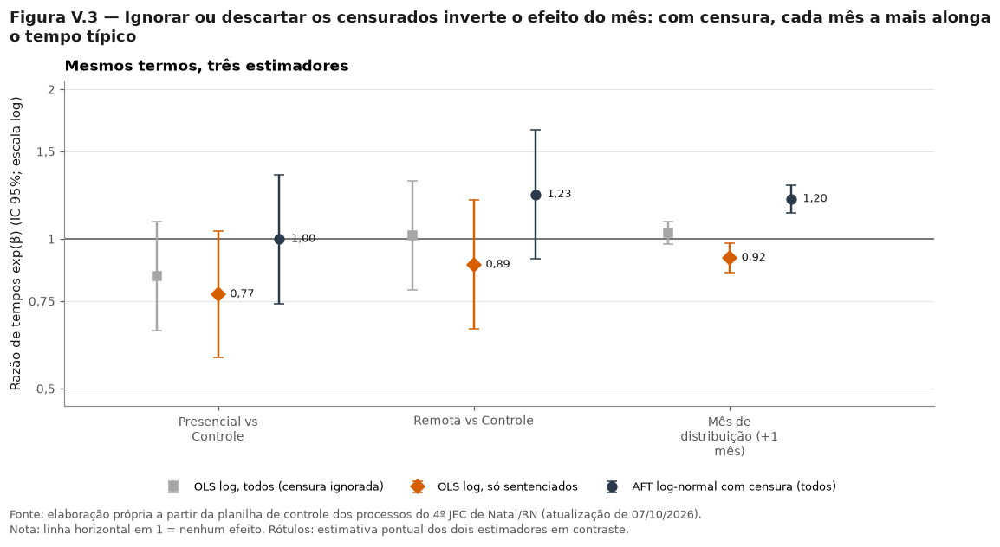

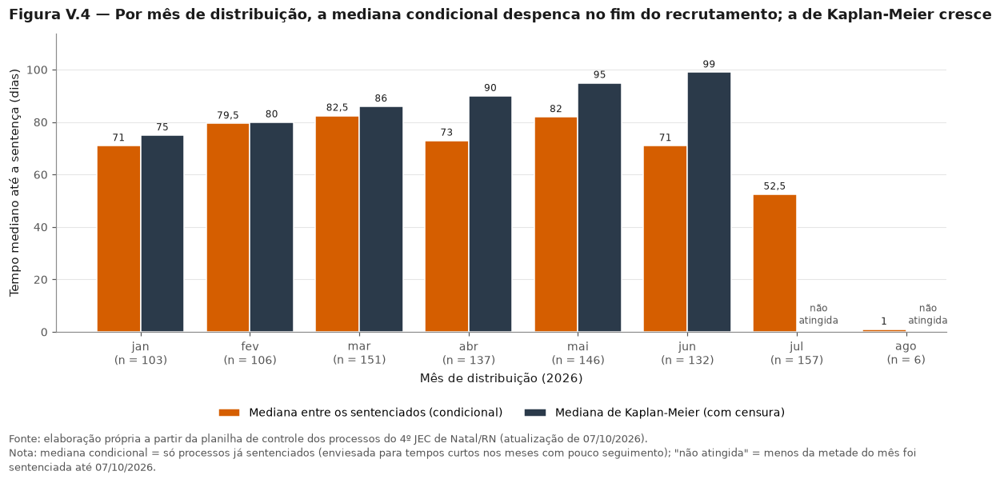

In [130]:
aft_ln = LogNormalAFTFitter().fit(mul[['T_pos', 'E', 'presencial', 'remota', 'mes_num']], 'T_pos', 'E')
termos = [('C(grupo)[T.Presencial]', 'presencial'), ('C(grupo)[T.Remota]', 'remota'), ('mes_num', 'mes_num')]
linhas = []
for rot, res in [('OLS log, todos (censura ignorada)', ols_log_todos), ('OLS log, só sentenciados', ols_log)]:
    ic = res.conf_int()
    for t_ols, t_aft in termos:
        linhas.append({'Modelo': rot, 'Termo': NOMES_COEF[t_ols], 'TR': np.exp(res.params[t_ols]),
                       'li': np.exp(ic.loc[t_ols, 0]), 'ls': np.exp(ic.loc[t_ols, 1])})
s_aft = aft_ln.summary
for t_ols, t_aft in termos:
    lin = s_aft.loc[('mu_', t_aft)]
    linhas.append({'Modelo': 'AFT log-normal com censura (todos)', 'Termo': NOMES_COEF[t_ols],
                   'TR': lin['exp(coef)'], 'li': lin['exp(coef) lower 95%'], 'ls': lin['exp(coef) upper 95%']})
comp_vies = pd.DataFrame(linhas)
tabela(comp_vies.rename(columns={'TR': 'Razão de tempos exp(β)', 'li': 'IC 95% inf.', 'ls': 'IC 95% sup.'}),
       'mul_vies_estimadores', 'Razões de tempos dos mesmos termos por três estimadores: só o AFT com censura usa os ativos',
       secao='5.1.3', casas=3,
       nota='razão de tempos > 1 = tempo típico até a sentença maior. OLS em log(tempo); AFT log-normal ajustado aos 938 processos '
            'com a redistribuição tratada como censura.')
mul_res['vies_mes'] = comp_vies.set_index(['Modelo', 'Termo'])['TR']

fig, ax = plt.subplots(figsize=(10, 5))
cores_mod = {'OLS log, todos (censura ignorada)': CINZA, 'OLS log, só sentenciados': COR_VIES,
             'AFT log-normal com censura (todos)': COR_MODELO}
termos_ord = list(dict.fromkeys(comp_vies['Termo']))
for j, (m, cor_m) in enumerate(cores_mod.items()):
    t = comp_vies[comp_vies['Modelo'] == m].set_index('Termo').reindex(termos_ord)
    mul_forest(ax, t['TR'], t['li'], t['ls'], x=np.arange(3) + (j - 1) * 0.24, cor=cor_m, label=m,
               marker=['s', 'D', 'o'][j],
               textos=[fmt_br(v, 2) for v in t['TR']] if m != 'OLS log, todos (censura ignorada)' else None)
mul_eixo_razao(ax, np.r_[comp_vies['li'], comp_vies['ls']])
ax.set_xticks(range(3), [quebra(t, 18) for t in termos_ord])
ax.set_xlim(-0.6, 2.8)
ax.set(ylabel='Razão de tempos exp(β) (IC 95%; escala log)', title='Mesmos termos, três estimadores')
legenda_abaixo(ax, ncol=3, dy=-0.2, fontsize=8.5)
figura(fig, 'mul_vies_forest', 'Ignorar ou descartar os censurados inverte o efeito do mês: com censura, cada mês a mais '
       'alonga o tempo típico', secao='5.1.3',
       nota='linha horizontal em 1 = nenhum efeito. Rótulos: estimativa pontual dos dois estimadores em contraste.')

meses = list(mul['mes_distribuicao'].cat.categories)
med_sent, med_km, n_mes = [], [], []
for m in meses:
    sub = mul[mul['mes_distribuicao'] == m]
    med_sent.append(sub.loc[sub['E'] == 1, 'T'].median())
    km = KaplanMeierFitter().fit(sub['T'], sub['E'])
    med_km.append(km.median_survival_time_)
    n_mes.append(len(sub))
fig, ax = plt.subplots(figsize=(11, 4.8))
tab_med = pd.DataFrame({'Mediana entre os sentenciados (condicional)': med_sent,
                        'Mediana de Kaplan-Meier (com censura)': [v if np.isfinite(v) else np.nan for v in med_km]},
                       index=[f'{m}\n(n = {n})' for m, n in zip(meses, n_mes)])
barras_agrupadas(ax, tab_med, cores={tab_med.columns[0]: COR_VIES, tab_med.columns[1]: COR_MODELO}, rotular=True,
                 fmt=lambda v: fmt_br(v, 1 if not float(v).is_integer() else 0),
                 ylabel='Tempo mediano até a sentença (dias)', xlabel=ROTULOS['mes_distribuicao'], legenda=False)
for xi, v in enumerate(med_km):
    if not np.isfinite(v):
        ax.annotate('não\natingida', (xi + 0.2, 0), xytext=(0, 4), textcoords='offset points', ha='center',
                    va='bottom', fontsize=8, color=TINTA_2)
legenda_abaixo(ax, ncol=2, dy=-0.22)
figura(fig, 'mul_vies_medianas_mes', 'Por mês de distribuição, a mediana condicional despenca no fim do recrutamento; '
       'a de Kaplan-Meier cresce', secao='5.1.3',
       nota='mediana condicional = só processos já sentenciados (enviesada para tempos curtos nos meses com pouco seguimento); '
            '"não atingida" = menos da metade do mês foi sentenciada até 07/10/2026.')

**Interpretação: regressão faz sentido? Depende de qual.** A tabela e o gráfico mostram o viés diretamente:

- **mês de distribuição**: o AFT log-normal com censura estima razão de tempos **1,204 por mês** (IC 95% 1,129 a 1,284): o tempo típico até a sentença **aumenta** cerca de 20% a cada mês de distribuição, o que se confirma nas medianas de Kaplan-Meier (75 dias em janeiro, 80 em fevereiro, 86 em março, 90 em abril, 95 em maio, 99 em junho, e não atingida em julho). O OLS só com sentenciados inverte o sinal (0,917), e o OLS com os censurados como tempos completos (abordagem do professor, E26) apaga o efeito (1,028; IC inclui 1). No gráfico das medianas por mês de distribuição, as medianas condicionais dos sentenciados oscilam em torno de 70-80 dias e despencam em julho (52,5) e agosto (1 dia), enquanto as de Kaplan-Meier crescem de forma regular: há **acúmulo de acervo** ao longo do experimento, um achado que só aparece quando a censura é respeitada;
- **grupos**: o OLS dos sentenciados sugere Presencial 23% mais rápido (0,774; p = 0,088) e Remota 11% mais rápido (0,888); o AFT com censura dá Presencial = Controle (1,000; IC 0,742 a 1,347) e Remota até mais lenta (1,230; IC 0,911 a 1,661), ambos sem significância. **A direção do efeito do rito muda** conforme se trata ou não a censura: quem lesse o OLS concluiria que a audiência obrigatória acelera, e essa conclusão é um artefato.

**Resposta à pergunta "a regressão faz sentido?"**: a regressão linear de mínimos quadrados sobre o tempo **não** faz sentido com 22% de censura e entrada escalonada, com ou sem os censurados (E14, E26). Regressão **com modelo adequado ao desfecho**, sim: para o tempo, modelos de sobrevivência (Cox e AFT, Parte IV, que usam a informação parcial dos ativos); para desfechos binários ou categóricos (acordo, tipo de sentença), regressão logística e multinomial (5.2). O AFT log-normal é, aliás, a "regressão linear de log T" corretamente estimada com censura (COLOSIMO; GIOLO, 2006, eq. 4.10, p. 122).

## 5.2 Regressão logística para o acordo e logit multinomial para o tipo de desfecho

O acordo é um desfecho **binário** e existe nos três grupos (no Controle, só fora de audiência). O modelo logístico é logit π(x) = β₀ + x′β, e exp(βⱼ) é a **razão de chances (RC)** (ARTES; BARROSO, 2023, eq. 10.1-10.3, p. 357-358).

**O problema do seguimento.** A variável `acordo` só está definida para os processos encerrados (nos ativos ainda não se sabe), e entre os encerrados `acordo = 1` coincide exatamente com sentença homologatória. Três definições de resposta, cada uma com sua limitação:

| Definição | Amostra | Limitação |
|---|---|---|
| (A) acordo entre os **encerrados** | 732 | condicional a ter encerrado; mês absorve a diferença de seguimento |
| (B) acordo homologado **até 60 dias** | todos os 938 (seguimento mínimo = 65 dias) | horizonte curto, poucos eventos; sem censura |
| (C) acordo homologado **até 120 dias** | os 688 com seguimento ≥ 120 dias | perde os distribuídos a partir de junho |

O seguimento (`log_followup`) é função determinística da data de distribuição: a correlação com o mês é de cerca de −0,97 (célula inicial). Não é possível pôr os dois no mesmo modelo (ver VIF em 5.2.2); o mês já faz o papel do seguimento. As definições (B) e (C) são as análises sem viés de seguimento, porque todos os incluídos foram observados durante todo o horizonte.

### 5.2.1 Modelo (A): acordo ~ grupo + mês, entre os encerrados

Testes:

- **razão de verossimilhanças (TRV)** do grupo: compara `grupo + mês` com `mês` só. H0: β_Presencial = β_Remota = 0 (os ritos não alteram a chance de acordo, dado o mês); H1: algum é ≠ 0; χ² com 2 g.l.;
- **Wald** de cada contraste (z = β/EP), com correção de Holm para os três pares (Presencial × Controle, Remota × Controle, Remota × Presencial);
- **pseudo-R²** de McFadden (1 − ℓ₁/ℓ₀) e de Nagelkerke (Cox-Snell reescalado para máximo 1).

Termo,RC,IC 95% inf.,IC 95% sup.,z (Wald),p (Wald)
Intercepto,"0,098","0,051","0,188","-6,95","< 0,001"
Presencial vs Controle,"1,354","0,737","2,489","0,98","0,329"
Remota vs Controle,"2,149","1,211","3,813","2,61","0,009"
Mês de distribuição (+1 mês),"0,965","0,849","1,098","-0,54","0,591"


Contraste,RC,IC 95% inf.,IC 95% sup.,p (Wald),p (Holm)
Presencial vs Controle,"1,354","0,737","2,489","0,329","0,329"
Remota vs Controle,"2,149","1,211","3,813","0,009","0,027"
Remota vs Presencial,"1,587","0,916","2,749","0,099","0,198"


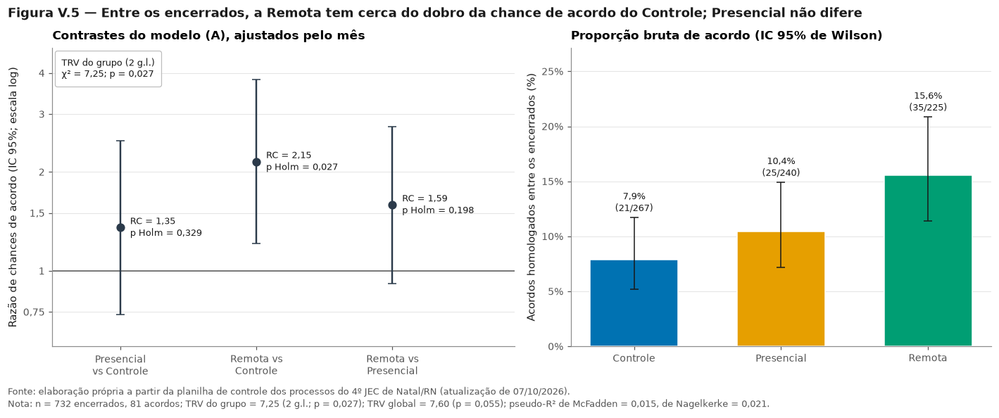

In [131]:
enc = mul[mul['encerrado_b']].copy()

def mul_logit(formula, dados_mod, formula_red=None, nome=''):
    res = smf.logit(formula, data=dados_mod).fit(disp=0)
    n = res.nobs
    cs = 1 - np.exp(2 * (res.llnull - res.llf) / n)
    nag = cs / (1 - np.exp(2 * res.llnull / n))
    saida = {'res': res, 'mcfadden': res.prsquared, 'nagelkerke': nag, 'n': int(n), 'eventos': int(res.model.endog.sum())}
    if formula_red is not None:
        red = smf.logit(formula_red, data=dados_mod).fit(disp=0)
        saida['trv'] = 2 * (res.llf - red.llf)
        saida['trv_gl'] = int(res.df_model - red.df_model)
        saida['trv_p'] = stats.chi2.sf(saida['trv'], saida['trv_gl'])
    return saida

def mul_tab_rc(res):
    ic = np.exp(res.conf_int())
    return pd.DataFrame({'Termo': [NOMES_COEF.get(i, i) for i in res.params.index],
                         'RC': np.exp(res.params).to_numpy(), 'IC 95% inf.': ic[0].to_numpy(),
                         'IC 95% sup.': ic[1].to_numpy(), 'z (Wald)': res.tvalues.to_numpy(),
                         'p (Wald)': res.pvalues.to_numpy()})


FMT_RC = {'RC': 3, 'IC 95% inf.': 3, 'IC 95% sup.': 3, 'z (Wald)': 2}

def mul_contrastes_grupo(res):
    # três contrastes de grupo, Wald, com Holm
    b, V = res.params, res.cov_params()
    P, R = 'C(grupo)[T.Presencial]', 'C(grupo)[T.Remota]'
    cont = {'Presencial vs Controle': (b[P], V.loc[P, P]), 'Remota vs Controle': (b[R], V.loc[R, R]),
            'Remota vs Presencial': (b[R] - b[P], V.loc[R, R] + V.loc[P, P] - 2 * V.loc[P, R])}
    lin = []
    for k, (est, var) in cont.items():
        ep = np.sqrt(var)
        lin.append({'Contraste': k, 'RC': np.exp(est), 'li': np.exp(est - 1.96 * ep), 'ls': np.exp(est + 1.96 * ep),
                    'p': 2 * stats.norm.sf(abs(est / ep))})
    t = pd.DataFrame(lin)
    t['p Holm'] = multipletests(t['p'], method='holm')[1]
    return t

def mul_mostra_contrastes(t):
    return pd.DataFrame({'Contraste': t['Contraste'], 'RC': t['RC'], 'IC 95% inf.': t['li'], 'IC 95% sup.': t['ls'],
                         'p (Wald)': t['p'], 'p (Holm)': t['p Holm']})


def mul_barras_prop(ax, tx, ylabel):
    """Proporção por grupo (barras verticais) com IC de Wilson e rótulo 'x,x% (s/n)' acima do IC."""
    p = tx['sum'] / tx['count']
    li, ls = mul_ic_wilson(tx['sum'], tx['count'])
    grupos = [str(g) for g in tx.index]
    barras_verticais(ax, grupos, p, cores=CORES_GRUPO, rotular=False, erro=(li, ls), ylabel=ylabel)
    for i, (s, n, pi, hi) in enumerate(zip(tx['sum'], tx['count'], p, ls)):
        ax.annotate(f'{pct_br(pi)}\n({int(s)}/{int(n)})', (i, hi), xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=8.5, color=TINTA)
    ax.set_ylim(0, max(ls) * 1.3)
    eixo_pct(ax)


modA = mul_logit('homolog ~ C(grupo) + mes_num', enc, 'homolog ~ mes_num')
resA = modA['res']
contA = mul_contrastes_grupo(resA)
nota_A = (f"n = {modA['n']} encerrados, {modA['eventos']} acordos; TRV do grupo = {fmt_br(modA['trv'], 2)} "
          f"({modA['trv_gl']} g.l.; p {mul_peq(modA['trv_p'])}); TRV global = {fmt_br(resA.llr, 2)} (p {mul_peq(resA.llr_pvalue)}); "
          f"pseudo-R² de McFadden = {fmt_br(modA['mcfadden'], 3)}, de Nagelkerke = {fmt_br(modA['nagelkerke'], 3)}.")
tabela(mul_tab_rc(resA), 'mul_logit_A', 'Modelo (A): razões de chances de acordo entre os encerrados (logit acordo ~ grupo + mês)',
       secao='5.2.1', formatos=FMT_RC, destaque='p (Wald)', nota=nota_A + ' Referência: Controle. Destaque: p < 0,05.')
tabela(mul_mostra_contrastes(contA), 'mul_logit_A_contrastes',
       'Modelo (A): os três contrastes de grupo (Wald, com correção de Holm)', secao='5.2.1',
       formatos={'RC': 3, 'IC 95% inf.': 3, 'IC 95% sup.': 3}, destaque='p (Holm)',
       nota='RC = razão de chances de acordo, ajustada pelo mês. Destaque: p de Holm < 0,05.')
mul_res['A'] = modA
mul_res['contA'] = contA

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1.1, 1]})
ax = eixos[0]
mul_forest(ax, contA['RC'], contA['li'], contA['ls'],
           textos=[f"RC = {fmt_br(r['RC'], 2)}\np Holm {mul_peq(r['p Holm'])}" for _, r in contA.iterrows()])
mul_eixo_razao(ax, np.r_[contA['li'], contA['ls']])
ax.set_xticks(range(3), [quebra(c, 12) for c in contA['Contraste']])
ax.set_xlim(-0.5, 2.9)
ax.set(ylabel='Razão de chances de acordo (IC 95%; escala log)', title='Contrastes do modelo (A), ajustados pelo mês')
anotar_teste(ax, texto_teste('TRV do grupo (2 g.l.)', f"χ² = {fmt_br(modA['trv'], 2)}", modA['trv_p']), loc='upper left')
ax = eixos[1]
tx = enc.groupby('grupo', observed=True)['homolog'].agg(['sum', 'count'])
mul_barras_prop(ax, tx, 'Acordos homologados entre os encerrados (%)')
ax.set_title('Proporção bruta de acordo (IC 95% de Wilson)')
figura(fig, 'mul_logit_A_rc', 'Entre os encerrados, a Remota tem cerca do dobro da chance de acordo do Controle; '
       'Presencial não difere', secao='5.2.1', nota=nota_A)

**Interpretação.** Entre os 732 processos encerrados (81 acordos homologados), a proporção de acordo cresce do Controle (21/267, 7,9%) para a Presencial (25/240, 10,4%) e a Remota (35/225, 15,6%). O **TRV do grupo** rejeita H0 (χ² = 7,25; 2 g.l.; p = 0,027). Nos contrastes com Holm, só **Remota × Controle** é significativo: **RC = 2,15** (IC 95% 1,21 a 3,81; p Holm = 0,027). Presencial × Controle (RC = 1,35; p Holm = 0,329) e Remota × Presencial (RC = 1,59; p Holm = 0,198) não se distinguem. O mês não se associa ao acordo (RC = 0,965 por mês; p = 0,591). O pseudo-R² é muito baixo (McFadden 0,015; Nagelkerke 0,021), como esperado num modelo só com grupo e mês: o rito altera a chance média de acordo, mas explica pouquíssimo de **qual** processo fará acordo.

**Leitura jurídica.** A audiência remota obrigatória associa-se a uma chance de acordo cerca de duas vezes maior que no rito atual. Como 64 dos 81 acordos ocorreram **fora** da audiência, o efeito não é só da sessão em si: a designação da audiência parece estimular a negociação entre as partes. Ressalva: o modelo é condicional a ter encerrado, e a Remota tem mais processos ainda ativos; a sensibilidade em horizontes fixos (5.2.5) trata desse ponto.

### 5.2.2 Multicolinearidade (VIF)

O fator de inflação da variância, VIFⱼ = 1/(1 − R²ⱼ), mede quanto a variância de β̂ⱼ é inflada pela correlação de xⱼ com os demais preditores. Referências usuais: VIF > 5 merece atenção e VIF > 10 indica colinearidade grave. Calcula-se para o modelo (A) e, para mostrar por que o seguimento não entra junto com o mês, para o modelo (A) acrescido de log(seguimento).

Preditor,VIF modelo (A),VIF (A) + log(seguimento)
Mês de distribuição (+1 mês),"1,00","17,40"
Presencial vs Controle,"1,28","1,28"
Remota vs Controle,"1,28","1,28"
log(seguimento),–,"17,42"


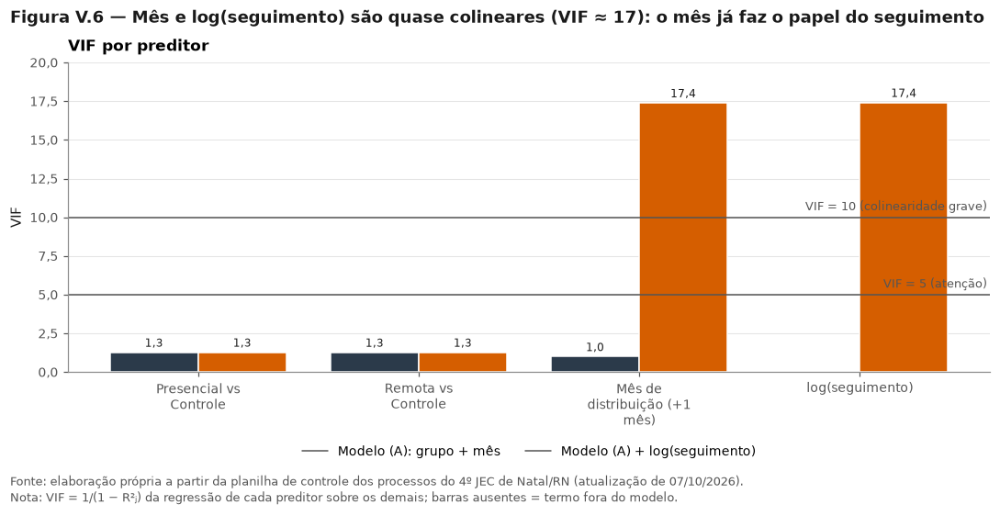

In [132]:
def mul_vif(res):
    X = pd.DataFrame(res.model.exog, columns=res.model.exog_names)
    return pd.Series({NOMES_COEF.get(c, c): variance_inflation_factor(X.values, i)
                      for i, c in enumerate(X.columns) if c != 'Intercept'})

vifA = mul_vif(resA)
resA_fu = smf.logit('homolog ~ C(grupo) + mes_num + log_followup', data=enc).fit(disp=0)
vifA_fu = mul_vif(resA_fu)
tab_vif = pd.DataFrame({'VIF modelo (A)': vifA, 'VIF (A) + log(seguimento)': vifA_fu}).rename_axis('Preditor')
tabela(tab_vif, 'mul_vif', 'Fator de inflação da variância (VIF) dos preditores do modelo (A), sem e com o seguimento',
       secao='5.2.2', casas=2, nota='VIF > 5 merece atenção; VIF > 10 indica colinearidade grave. "–": termo fora do modelo.')
fig, ax = plt.subplots(figsize=(10, 4.6))
nomes = list(vifA_fu.index)
barras_agrupadas(ax, tab_vif.reindex(nomes), cores={'VIF modelo (A)': COR_MODELO, 'VIF (A) + log(seguimento)': COR_VIES},
                 rotular=True, fmt=lambda v: fmt_br(v, 1), quebrar=16, ylabel='VIF', legenda=False)
for lim, txt in [(5, 'VIF = 5 (atenção)'), (10, 'VIF = 10 (colinearidade grave)')]:
    ax.axhline(lim, color=TINTA_2, lw=1, zorder=1)
    ax.annotate(txt, (1, lim), xycoords=('axes fraction', 'data'), xytext=(-2, 3), textcoords='offset points',
                ha='right', va='bottom', fontsize=8.5, color=TINTA_2)
ax.set_title('VIF por preditor')
legenda_abaixo(ax, ncol=2, dy=-0.2, labels=['Modelo (A): grupo + mês', 'Modelo (A) + log(seguimento)'])
figura(fig, 'mul_vif', 'Mês e log(seguimento) são quase colineares (VIF ≈ 17): o mês já faz o papel do seguimento',
       secao='5.2.2', nota='VIF = 1/(1 − R²ⱼ) da regressão de cada preditor sobre os demais; barras ausentes = termo fora do modelo.')

**Interpretação.** No modelo (A) não há colinearidade: VIF = 1,00 para o mês e 1,28 para os indicadores de grupo (a correlação entre os dois indicadores é inerente à codificação de três categorias). Ao acrescentar log(seguimento), o VIF do mês e o do seguimento saltam para **17,4**, bem acima do limite de 10: as duas variáveis carregam a mesma informação (r = −0,97), porque o seguimento é a distância entre a distribuição e a data de corte. Por isso a diferença de seguimento é controlada **pelo mês** no modelo (A) e, de modo mais limpo, pelos horizontes fixos de 5.2.5, e não pela inclusão simultânea das duas variáveis.

### 5.2.3 Calibração: teste de Hosmer-Lemeshow

Ordenam-se os processos pela probabilidade prevista π̂ e formam-se g = 10 grupos; HL = Σ (Oₖ − nₖπ̄ₖ)² / [nₖπ̄ₖ(1 − π̄ₖ)] segue χ² com g − 2 g.l. (ARTES; BARROSO, 2023, eq. 10.4, p. 358-359). H0: o modelo está calibrado (as frequências observadas de acordo coincidem com as previstas em cada grupo); H1: não está. Como só há 24 padrões de covariáveis (3 grupos × 8 meses), muitos processos têm a mesma π̂; os empates são repartidos pela ordem (rank), o que mantém os 10 grupos. O gráfico de calibração (observado × previsto, com IC de Wilson) é o gráfico do teste.

Hosmer-Lemeshow modelo (A): HL = 9,18, 8 g.l., p 0,327


Decil de π̂,Processos (n),Acordos observados (O),π̂ média,Acordos esperados (E = n·π̂)
1,74,8,"0,073","5,4"
2,73,5,"0,077","5,6"
3,73,7,"0,081","5,9"
4,73,2,"0,089","6,5"
5,73,7,"0,100","7,3"
6,73,11,"0,105","7,7"
7,73,7,"0,113","8,3"
8,73,8,"0,146","10,7"
9,73,15,"0,156","11,4"
10,74,11,"0,165","12,2"


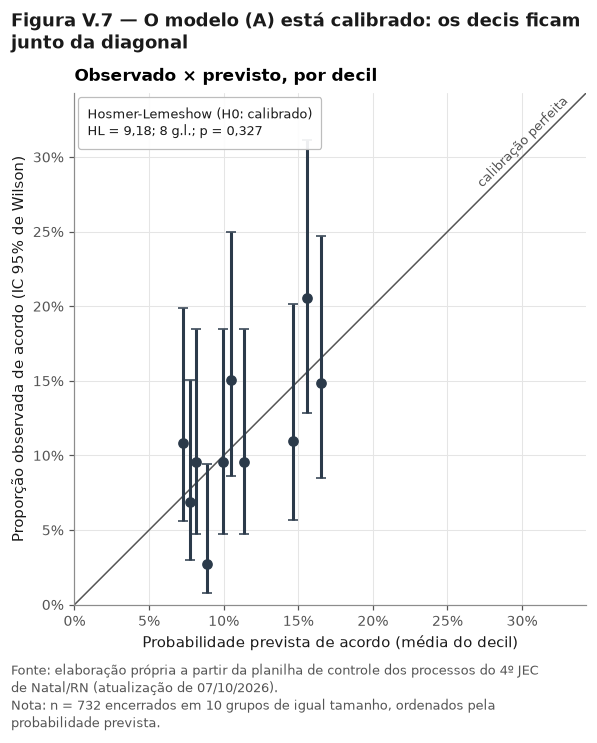

In [133]:
def hosmer_lemeshow(y, p, g=10):
    t = pd.DataFrame({'y': np.asarray(y, float), 'p': np.asarray(p, float)})
    t['grp'] = pd.qcut(t['p'].rank(method='first'), g, labels=False)
    agg = t.groupby('grp').agg(n=('y', 'size'), O=('y', 'sum'), pbar=('p', 'mean'))
    agg['E'] = agg['n'] * agg['pbar']
    hl = (((agg['O'] - agg['E']) ** 2) / (agg['E'] * (1 - agg['pbar']))).sum()
    return hl, g - 2, stats.chi2.sf(hl, g - 2), agg

def grafico_calibracao(ax, agg, titulo):
    li, ls = mul_ic_wilson(agg['O'], agg['n'])
    obs = agg['O'] / agg['n']
    ax.errorbar(agg['pbar'], obs, yerr=[obs - li, ls - obs], fmt='o', ms=6, color=COR_MODELO, capsize=3, zorder=3)
    lim = max(agg['pbar'].max(), ls.max()) * 1.1
    ax.plot([0, lim], [0, lim], color=TINTA_2, lw=1, zorder=1)
    ax.annotate('calibração perfeita', (lim * 0.97, lim * 0.97), ha='right', va='bottom', fontsize=8.5, color=TINTA_2,
                rotation=45, rotation_mode='anchor', xytext=(0, 3), textcoords='offset points')
    ax.set(xlim=(0, lim), ylim=(0, lim), xlabel='Probabilidade prevista de acordo (média do decil)',
           ylabel='Proporção observada de acordo (IC 95% de Wilson)', title=titulo)
    ax.set_aspect('equal')
    eixo_pct(ax, 'x'); eixo_pct(ax, 'y')
    ax.grid(axis='both', visible=True)

hlA, glA, pA_hl, aggA = hosmer_lemeshow(resA.model.endog, resA.predict())
mul_res['hlA'] = (hlA, pA_hl)
print(f'Hosmer-Lemeshow modelo (A): HL = {fmt_br(hlA, 2)}, {glA} g.l., p {p_br(pA_hl)}')
tab_hl = pd.DataFrame({'Decil de π̂': np.arange(1, len(aggA) + 1), 'Processos (n)': aggA['n'].to_numpy(),
                       'Acordos observados (O)': aggA['O'].to_numpy(), 'π̂ média': aggA['pbar'].to_numpy(),
                       'Acordos esperados (E = n·π̂)': aggA['E'].to_numpy()})
tabela(tab_hl, 'mul_hl', 'Teste de Hosmer-Lemeshow do modelo (A): acordos observados × esperados por decil de probabilidade',
       secao='5.2.3', formatos={'π̂ média': 3, 'Acordos esperados (E = n·π̂)': 1},
       nota=f'HL = {fmt_br(hlA, 2)}, {glA} g.l., p {mul_peq(pA_hl)} (H0: modelo calibrado).')
fig, ax = plt.subplots(figsize=(6, 5.6))
grafico_calibracao(ax, aggA, 'Observado × previsto, por decil')
anotar_teste(ax, texto_teste('Hosmer-Lemeshow (H0: calibrado)', f'HL = {fmt_br(hlA, 2)}; {glA} g.l.', pA_hl),
             loc='upper left')
figura(fig, 'mul_hl', 'O modelo (A) está calibrado: os decis ficam junto da diagonal', secao='5.2.3',
       nota=f'n = {modA["n"]} encerrados em 10 grupos de igual tamanho, ordenados pela probabilidade prevista.')

**Interpretação.** HL = 9,18 com 8 g.l. (p = 0,327): não se rejeita H0, e o modelo está **calibrado**. As probabilidades previstas vão de 7,3% a 16,5%, e as proporções observadas por decil oscilam em torno da diagonal, dentro dos IC de Wilson. Duas ressalvas: com apenas 81 eventos (5 a 8 por decil), o teste tem pouco poder; e calibração não é discriminação. Um modelo pode acertar as médias por grupo e mês, que é o que este faz, sem separar bem os processos individualmente (5.2.4).

### 5.2.4 Discriminação: ROC, AUC, Gini e KS

Calibração diz se as probabilidades são corretas *em média*; discriminação diz se o modelo **ordena** bem quem faz e quem não faz acordo.

- **AUC** (área sob a curva ROC): probabilidade de um processo com acordo ter π̂ maior que um sem acordo. Referências de Hosmer, Lemeshow e Sturdivant reproduzidas por Artes e Barroso (2023, tab. 10.3, p. 365): 0,5 sem discriminação; 0,5-0,7 pobre; 0,7-0,8 aceitável; 0,8-0,9 excelente; ≥ 0,9 excepcional. IC 95% por *bootstrap* percentil (2.000 reamostras).
- **Gini** = 2·AUC − 1 (p. 364).
- **KS**: distância máxima entre as funções de distribuição dos escores dos dois grupos (eq. 10.5, p. 365-367). O teste KS de duas amostras tem H0: os escores de quem fez e de quem não fez acordo têm a mesma distribuição.
- **Validação**: a AUC na própria amostra é otimista. Artes e Barroso recomendam separar 20-30% para validação (p. 359); aqui usam-se uma partição 70/30 estratificada e a validação cruzada estratificada em 10 partes.

AUC (amostra toda) = 0,591 (IC 95% bootstrap 0,523 a 0,660); Gini = 0,182
AUC validação 70/30 = 0,486; AUC validação cruzada 10 partes = 0,546
KS = 0,161 (p 0,042)


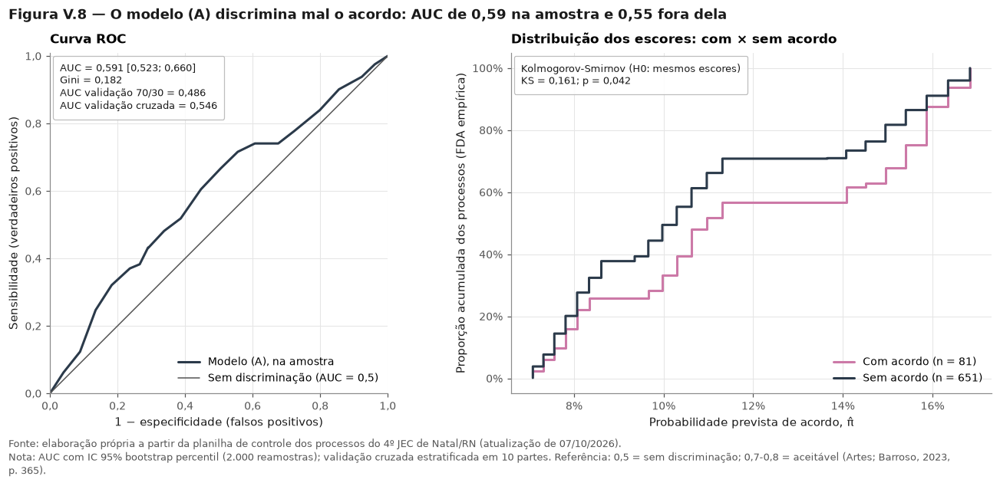

In [134]:
def auc_bootstrap(y, p, B=2000, rng=RNG_MUL):
    y, p = np.asarray(y), np.asarray(p)
    vals = []
    for _ in range(B):
        idx = rng.integers(0, len(y), len(y))
        if y[idx].min() == y[idx].max():
            continue
        vals.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(vals, [2.5, 97.5])

def ks_escores(y, p):
    y, p = np.asarray(y), np.asarray(p)
    r = stats.ks_2samp(p[y == 1], p[y == 0])
    return r.statistic, r.pvalue

def auc_validacao(formula, dados_mod, resposta, k=10, rng_seed=SEMENTE):
    y = dados_mod[resposta].values
    # 70/30 estratificado
    rng = np.random.default_rng(rng_seed)
    idx_val = np.concatenate([rng.choice(np.where(y == c)[0], int(round(0.3 * (y == c).sum())), replace=False) for c in (0, 1)])
    mask = np.zeros(len(y), bool); mask[idx_val] = True
    r = smf.logit(formula, data=dados_mod[~mask]).fit(disp=0)
    auc_7030 = roc_auc_score(y[mask], r.predict(dados_mod[mask]))
    # k-fold estratificado
    prev = np.zeros(len(y))
    for tr, te in StratifiedKFold(k, shuffle=True, random_state=rng_seed).split(np.zeros(len(y)), y):
        r = smf.logit(formula, data=dados_mod.iloc[tr]).fit(disp=0)
        prev[te] = r.predict(dados_mod.iloc[te])
    return auc_7030, roc_auc_score(y, prev)

yA, pA = resA.model.endog, resA.predict()
aucA = roc_auc_score(yA, pA)
icA = auc_bootstrap(yA, pA)
ksA, ksA_p = ks_escores(yA, pA)
auc7030A, auccvA = auc_validacao('homolog ~ C(grupo) + mes_num', enc, 'homolog')
mul_res['aucA'] = (aucA, icA, auccvA, ksA)
print(f'AUC (amostra toda) = {fmt_br(aucA, 3)} (IC 95% bootstrap {fmt_br(icA[0], 3)} a {fmt_br(icA[1], 3)}); '
      f'Gini = {fmt_br(2 * aucA - 1, 3)}')
print(f'AUC validação 70/30 = {fmt_br(auc7030A, 3)}; AUC validação cruzada 10 partes = {fmt_br(auccvA, 3)}')
print(f'KS = {fmt_br(ksA, 3)} (p {p_br(ksA_p)})')

fig, eixos = plt.subplots(1, 2, figsize=(12.5, 5))
fpr, tpr, _ = roc_curve(yA, pA)
ax = eixos[0]
ax.plot(fpr, tpr, color=COR_MODELO, lw=2, label='Modelo (A), na amostra')
ax.plot([0, 1], [0, 1], color=TINTA_2, lw=1, label='Sem discriminação (AUC = 0,5)')
ax.set(xlabel='1 − especificidade (falsos positivos)', ylabel='Sensibilidade (verdadeiros positivos)',
       title='Curva ROC', xlim=(0, 1), ylim=(0, 1.01))
ax.set_aspect('equal')
ax.grid(axis='both', visible=True)
ax.legend(loc='lower right')
anotar_teste(ax, f'AUC = {mul_ic(aucA, *icA)}\nGini = {fmt_br(2 * aucA - 1, 3)}\n'
                 f'AUC validação 70/30 = {fmt_br(auc7030A, 3)}\nAUC validação cruzada = {fmt_br(auccvA, 3)}',
             loc='upper left')
ax = eixos[1]
for c, cor, rot in [(1, CORES_DESFECHO['Homologação'], 'Com acordo'), (0, COR_MODELO, 'Sem acordo')]:
    v = np.sort(pA[yA == c])
    ax.step(v, np.arange(1, len(v) + 1) / len(v), where='post', color=cor, lw=2,
            label=f'{rot} (n = {fmt_br(len(v), 0)})')
ax.set(xlabel='Probabilidade prevista de acordo, π̂', ylabel='Proporção acumulada dos processos (FDA empírica)',
       title='Distribuição dos escores: com × sem acordo')
eixo_pct(ax, 'x'); eixo_pct(ax, 'y')
ax.grid(axis='both', visible=True)
ax.legend(loc='lower right')
anotar_teste(ax, texto_teste('Kolmogorov-Smirnov (H0: mesmos escores)', f'KS = {fmt_br(ksA, 3)}', ksA_p), loc='upper left')
figura(fig, 'mul_roc_A', f'O modelo (A) discrimina mal o acordo: AUC de {fmt_br(aucA, 2)} na amostra e '
       f'{fmt_br(auccvA, 2)} fora dela',
       secao='5.2.4', nota='AUC com IC 95% bootstrap percentil (2.000 reamostras); validação cruzada estratificada em 10 partes. '
                           'Referência: 0,5 = sem discriminação; 0,7-0,8 = aceitável (Artes; Barroso, 2023, p. 365).')

**Interpretação.** Na própria amostra, AUC = **0,591** (IC 95% *bootstrap* 0,523 a 0,660), Gini = 0,182 e KS = 0,161 (p = 0,042). Pela tabela de referência (ARTES; BARROSO, 2023, tab. 10.3, p. 365), a discriminação é **pobre** (faixa 0,5-0,7). Fora da amostra, ela cai mais: **0,546** em validação cruzada de 10 partes e **0,486** na partição 70/30. A partição única de 30% (cerca de 24 acordos) é muito instável, e a validação cruzada é a estimativa mais confiável. O KS "significativo" diz apenas que as distribuições dos escores diferem (porque a Remota tem mais acordos), não que o modelo classifica bem.

**Conclusão.** O grupo tem um efeito **populacional** detectável sobre a chance de acordo (5.2.1), mas é inútil como **classificador** de processos individuais. Isso é o que se espera de um experimento em que a única variável manipulada é o rito e não há covariáveis do caso.

### 5.2.5 Sensibilidade ao seguimento: horizontes fixos de 60 e 120 dias

Repete-se o modelo com as definições (B) e (C), em que todos os processos incluídos foram observados durante todo o horizonte, de modo que "não acordo até τ" é informação completa (não há censura antes de τ). O que importa é se a RC do grupo muda de direção ou de magnitude em relação ao modelo (A).

Definição,n,Acordos,Contraste,RC,IC 95% inf.,IC 95% sup.,p (Holm),p do TRV do grupo
(A) encerrados,732,81,Presencial vs Controle,"1,354","0,737","2,489","0,329","0,027"
(A) encerrados,732,81,Remota vs Controle,"2,149","1,211","3,813","0,027","0,027"
(A) encerrados,732,81,Remota vs Presencial,"1,587","0,916","2,749","0,198","0,027"
"(B) até 60 dias, todos",938,40,Presencial vs Controle,"1,339","0,577","3,107","0,818","0,318"
"(B) até 60 dias, todos",938,40,Remota vs Controle,"1,830","0,822","4,074","0,416","0,318"
"(B) até 60 dias, todos",938,40,Remota vs Presencial,"1,367","0,651","2,871","0,818","0,318"
"(C) até 120 dias, seguimento ≥ 120",688,61,Presencial vs Controle,"1,980","0,956","4,101","0,132","0,015"
"(C) até 120 dias, seguimento ≥ 120",688,61,Remota vs Controle,"2,703","1,333","5,481","0,018","0,015"
"(C) até 120 dias, seguimento ≥ 120",688,61,Remota vs Presencial,"1,365","0,752","2,479","0,307","0,015"


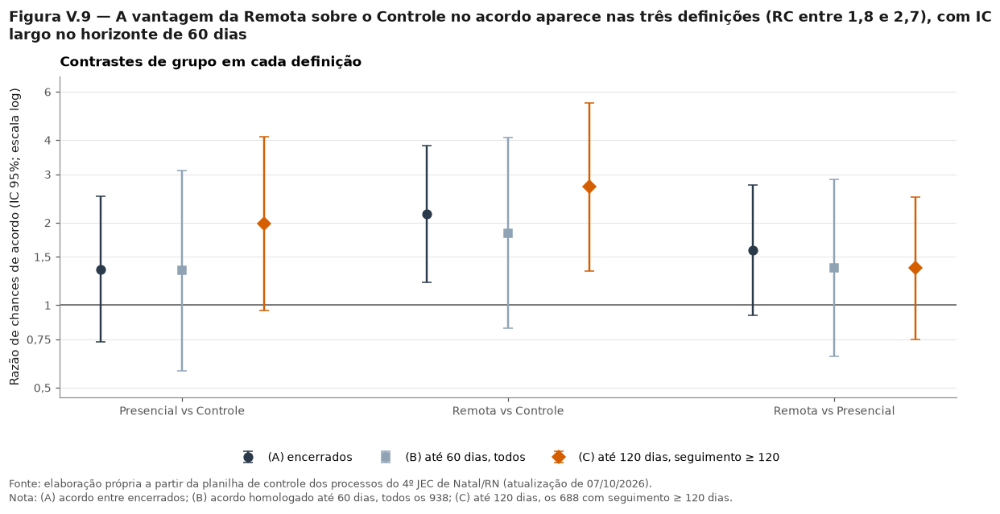

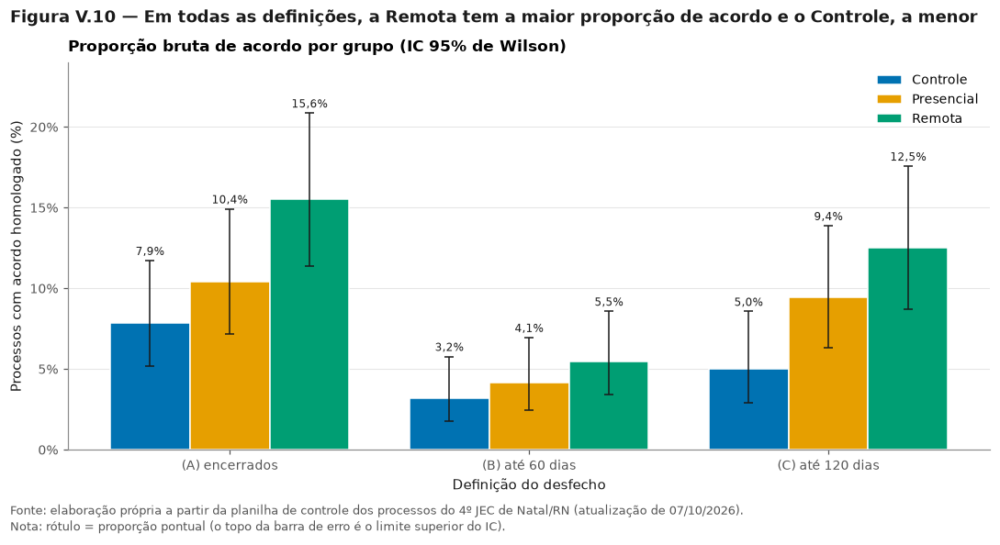

In [135]:
mul['acordo60'] = ((mul['homolog'] == 1) & (mul['T'] <= 60)).astype(int)
mul['acordo120'] = ((mul['homolog'] == 1) & (mul['T'] <= 120)).astype(int)
base120 = mul[mul['followup_f'] >= 120].copy()
modB = mul_logit('acordo60 ~ C(grupo) + mes_num', mul, 'acordo60 ~ mes_num')
modC = mul_logit('acordo120 ~ C(grupo) + mes_num', base120, 'acordo120 ~ mes_num')
mul_res['B'], mul_res['C'] = modB, modC
cont_h = []
for rot, m in [('(A) encerrados', modA), ('(B) até 60 dias, todos', modB), ('(C) até 120 dias, seguimento ≥ 120', modC)]:
    t = mul_contrastes_grupo(m['res'])
    t.insert(0, 'Definição', rot)
    t['n'], t['acordos'], t['TRV p'] = m['n'], m['eventos'], m['trv_p']
    cont_h.append(t)
cont_h = pd.concat(cont_h, ignore_index=True)
mul_res['cont_h'] = cont_h
tabela(pd.DataFrame({'Definição': cont_h['Definição'], 'n': cont_h['n'], 'Acordos': cont_h['acordos'],
                     'Contraste': cont_h['Contraste'], 'RC': cont_h['RC'], 'IC 95% inf.': cont_h['li'],
                     'IC 95% sup.': cont_h['ls'], 'p (Holm)': cont_h['p Holm'], 'p do TRV do grupo': cont_h['TRV p']}),
       'mul_logit_horizontes', 'Razões de chances de acordo por grupo nas três definições do desfecho (A, B, C)',
       secao='5.2.5', formatos={'RC': 3, 'IC 95% inf.': 3, 'IC 95% sup.': 3}, destaque='p (Holm)',
       nota='modelos logit acordo ~ grupo + mês; contrastes de Wald com Holm dentro de cada definição. Destaque: p de Holm < 0,05.')

defs = list(dict.fromkeys(cont_h['Definição']))
cores_def = dict(zip(defs, [COR_MODELO, '#8FA3B5', COR_VIES]))
fig, ax = plt.subplots(figsize=(11, 5))
for j, d in enumerate(defs):
    t = cont_h[cont_h['Definição'] == d].reset_index(drop=True)
    mul_forest(ax, t['RC'], t['li'], t['ls'], x=np.arange(3) + (j - 1) * 0.25, cor=cores_def[d], label=d,
               marker=['o', 's', 'D'][j])
mul_eixo_razao(ax, np.r_[cont_h['li'], cont_h['ls']])
ax.set_xticks(range(3), list(contA['Contraste']))
ax.set(ylabel='Razão de chances de acordo (IC 95%; escala log)', title='Contrastes de grupo em cada definição')
legenda_abaixo(ax, ncol=3, dy=-0.14)
figura(fig, 'mul_logit_horizontes_rc', 'A vantagem da Remota sobre o Controle no acordo aparece nas três definições '
       '(RC entre 1,8 e 2,7), com IC largo no horizonte de 60 dias', secao='5.2.5',
       nota='(A) acordo entre encerrados; (B) acordo homologado até 60 dias, todos os 938; (C) até 120 dias, os 688 com seguimento ≥ 120 dias.')

tab_def = {}
erros_def = {}
for rot, col, base in [('(A) encerrados', 'homolog', enc), ('(B) até 60 dias', 'acordo60', mul),
                       ('(C) até 120 dias', 'acordo120', base120)]:
    tx = base.groupby('grupo', observed=True)[col].agg(['sum', 'count'])
    tab_def[rot] = tx['sum'] / tx['count']
    erros_def[rot] = mul_ic_wilson(tx['sum'], tx['count'])
tab_def = pd.DataFrame(tab_def).T[ORDEM_GRUPO]
fig, ax = plt.subplots(figsize=(10, 4.8))
barras_agrupadas(ax, tab_def, cores=CORES_GRUPO, rotular=True, fmt=lambda v: pct_br(v, 1), quebrar=18,
                 erro={g: (np.array([erros_def[d][0][g] for d in tab_def.index]),
                           np.array([erros_def[d][1][g] for d in tab_def.index])) for g in ORDEM_GRUPO},
                 ylabel='Processos com acordo homologado (%)', xlabel='Definição do desfecho')
eixo_pct(ax)
ax.set_title('Proporção bruta de acordo por grupo (IC 95% de Wilson)')
figura(fig, 'mul_logit_horizontes_prop', 'Em todas as definições, a Remota tem a maior proporção de acordo e o Controle, a menor',
       secao='5.2.5', nota='rótulo = proporção pontual (o topo da barra de erro é o limite superior do IC).')

**Interpretação.** A direção do efeito é estável nas três definições: a Remota tem sempre a maior chance de acordo e a Presencial fica entre a Remota e o Controle.

- **(B) até 60 dias, todos os 938** (sem viés de seguimento, mas com só 40 acordos): Remota × Controle RC = 1,83 (IC 0,82 a 4,07) e TRV do grupo p = 0,318. O efeito tem a mesma direção, sem poder para ser detectado, porque a maior parte dos acordos é homologada depois de 60 dias.
- **(C) até 120 dias, seguimento ≥ 120** (688 processos, 61 acordos, sem viés de seguimento): **Remota × Controle RC = 2,70** (IC 1,33 a 5,48; p Holm = 0,018), Presencial × Controle RC = 1,98 (IC 0,96 a 4,10; p Holm = 0,132) e TRV do grupo p = 0,015.

A definição (C), que é a mais limpa, **confirma e reforça** o modelo (A). O efeito da Remota sobre o acordo não é artefato da diferença de seguimento. A análise com riscos competitivos (função de incidência acumulada da homologação, Parte IV) é o complemento natural, porque usa todos os processos sem escolher um horizonte.

### 5.2.6 Acordo **na audiência**, no subconjunto com audiência realizada

Aqui a resposta é `acordo_ac` e a amostra são os 352 processos com audiência realizada (só Presencial e Remota: no Controle o acordo em audiência é zero estrutural, E20). Preditores: modalidade (Remota × Presencial), audiência **híbrida** (uma parte remota numa pauta presencial, Res. CNJ 481) e mês. A híbrida é **pós-sorteio**: a RC é associação, não efeito causal.

**Cuidado com poucos eventos.** Há só 17 acordos em audiência. A regra prática de ~10 eventos por parâmetro (EPV) admite no máximo 1 ou 2 preditores; com 3, as estimativas por máxima verossimilhança são instáveis e os IC largos. O resultado é exploratório. TRV do modelo: H0: nenhum preditor associa-se ao acordo em audiência.

Grupo,Audiência,Acordo na AC,Sem acordo na AC,Total,% com acordo
Presencial,híbrida,1,23,24,"4,2"
Presencial,não híbrida,8,146,154,"5,2"
Remota,híbrida,0,2,2,"0,0"
Remota,não híbrida,8,164,172,"4,7"


Termo,RC,IC 95% inf.,IC 95% sup.,z (Wald),p (Wald)
Intercepto,"0,123","0,038","0,403","-3,47","< 0,001"
Remota vs Presencial,"0,841","0,309","2,291","-0,34","0,735"
Híbrida (sim),"0,689","0,084","5,682","-0,35","0,729"
Mês de distribuição (+1 mês),"0,810","0,616","1,063","-1,52","0,129"


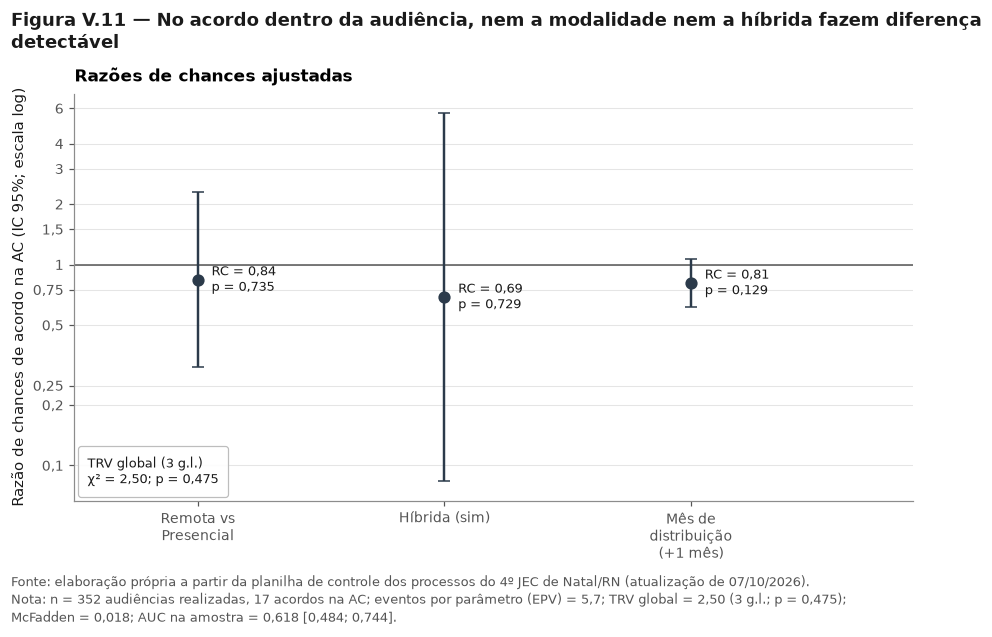

In [136]:
sub_ac = mul[mul['ac_realizada'].fillna(False).astype(bool)].copy()
sub_ac['y_ac'] = sub_ac['acordo_ac'].astype(int)
tab_ac = pd.crosstab([sub_ac['grupo'].astype(str), sub_ac['hibrida_b'].map({0: 'não híbrida', 1: 'híbrida'})],
                     sub_ac['y_ac'].map({0: 'Sem acordo na AC', 1: 'Acordo na AC'}))
tab_ac = tab_ac.rename_axis(columns=None).reset_index().rename(columns={'grupo': 'Grupo', 'hibrida_b': 'Audiência'})
tab_ac['Total'] = tab_ac['Sem acordo na AC'] + tab_ac['Acordo na AC']
tab_ac['% com acordo'] = 100 * tab_ac['Acordo na AC'] / tab_ac['Total']
tabela(tab_ac[['Grupo', 'Audiência', 'Acordo na AC', 'Sem acordo na AC', 'Total', '% com acordo']], 'mul_ac_hibrida',
       'Acordo na audiência por modalidade e audiência híbrida (processos com AC realizada)', secao='5.2.6',
       nota='só Presencial e Remota: no Controle não há audiência obrigatória (zero estrutural).')
modAC = mul_logit('y_ac ~ remota + hibrida_b + mes_num', sub_ac)
resAC = modAC['res']
epv = modAC['eventos'] / resAC.df_model
aucAC = roc_auc_score(resAC.model.endog, resAC.predict())
icAC = auc_bootstrap(resAC.model.endog, resAC.predict())
mul_res['AC'] = (modAC, aucAC, icAC)
nota_AC = (f"n = {modAC['n']} audiências realizadas, {modAC['eventos']} acordos na AC; eventos por parâmetro (EPV) = {fmt_br(epv, 1)}; "
           f"TRV global = {fmt_br(resAC.llr, 2)} ({int(resAC.df_model)} g.l.; p {mul_peq(resAC.llr_pvalue)}); "
           f"McFadden = {fmt_br(modAC['mcfadden'], 3)}; AUC na amostra = {mul_ic(aucAC, *icAC)}.")
tabela(mul_tab_rc(resAC), 'mul_logit_ac', 'Logit do acordo na audiência ~ modalidade + híbrida + mês (exploratório: 17 eventos)',
       secao='5.2.6', formatos=FMT_RC, destaque='p (Wald)', nota=nota_AC + ' Referência da modalidade: Presencial.')
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ic = np.exp(resAC.conf_int()).iloc[1:]
rc = np.exp(resAC.params).iloc[1:]
mul_forest(ax, rc, ic[0], ic[1], textos=[f'RC = {fmt_br(rc[t], 2)}\np {mul_peq(resAC.pvalues[t])}' for t in rc.index])
mul_eixo_razao(ax, np.r_[ic[0], ic[1]])
ax.set_xticks(range(len(rc)), [quebra(NOMES_COEF[t], 14) for t in rc.index])
ax.set_xlim(-0.5, len(rc) - 0.1)
ax.set(ylabel='Razão de chances de acordo na AC (IC 95%; escala log)', title='Razões de chances ajustadas')
anotar_teste(ax, texto_teste(f'TRV global ({int(resAC.df_model)} g.l.)', f'χ² = {fmt_br(resAC.llr, 2)}', resAC.llr_pvalue),
             loc='lower left')
figura(fig, 'mul_logit_ac', 'No acordo dentro da audiência, nem a modalidade nem a híbrida fazem diferença detectável',
       secao='5.2.6', nota=nota_AC)

**Interpretação.** Entre os 352 processos com audiência realizada, só **17 acordos** foram obtidos na própria audiência (4,8%). Nada se associa a eles: o TRV global é 2,50 (3 g.l.; p = 0,475), Remota × Presencial tem RC = 0,84 (IC 0,31 a 2,29), a híbrida tem RC = 0,69 (IC 0,08 a 5,68) e o mês, RC = 0,81 (p = 0,129). Com 5,7 eventos por parâmetro, o modelo está no limite da estimabilidade e os IC são enormes: o resultado é **ausência de evidência**, não evidência de ausência. A AUC de 0,618 (IC 0,484 a 0,744) inclui 0,5.

**Leitura conjunta com 5.2.1.** A modalidade da audiência **não** muda o acordo **na audiência** (Presencial e Remota têm taxas quase iguais, cerca de 5%), mas a Remota tem mais acordos **no total**. A diferença vem, portanto, dos acordos fora da audiência, homologados depois. É uma hipótese a investigar com as datas (audiência, petição de acordo): a audiência remota pode facilitar o contato entre os advogados ou a apresentação de propostas posteriores, ou a pauta da Remota pode ter sido mais demorada, dando mais tempo para negociar. Sobre a audiência híbrida, com 26 casos e 1 acordo, nada se pode concluir.

### 5.2.7 Logit multinomial para o tipo de sentença

Entre os 708 sentenciados, o tipo de sentença tem três categorias: **mérito** (referência), **homologação** e **sem mérito**. O logit multinomial (`statsmodels` `MNLogit`) estima, para cada categoria k ≠ mérito, log[P(k)/P(mérito)] = β₀ₖ + x′βₖ; exp(βₖ) é a **razão de riscos relativos (RRR)**: quanto a chance de "k em vez de mérito" se multiplica. A Parte III mostrou, na tabela, que os tratados têm mais extinções sem mérito; o modelo verifica se isso se mantém controlando o mês.

TRV do grupo (H0: β_grupo = 0 nas duas equações; 4 g.l.). O seguimento continua sendo uma ameaça: tipos de sentença mais rápidos (homologação, sem mérito por ausência) aparecem mais cedo e estão super-representados entre os distribuídos nos últimos meses; o mês ajusta parcialmente isso, e repete-se o modelo só com os processos de **seguimento ≥ 150 dias** (distribuídos até ~10/05), em que quase todos já foram sentenciados. O pressuposto de independência de alternativas irrelevantes (IIA) é plausível: as três categorias são decisões juridicamente distintas.

Equação,Termo,RRR,IC 95% inf.,IC 95% sup.,p
Homologação vs Mérito,Intercepto,"0,124","0,063","0,246","< 0,001"
Homologação vs Mérito,Presencial vs Controle,"2,014","1,069","3,793","0,030"
Homologação vs Mérito,Remota vs Controle,"3,259","1,784","5,954","< 0,001"
Homologação vs Mérito,Mês de distribuição (+1 mês),"1,012","0,883","1,160","0,862"
Sem mérito vs Mérito,Intercepto,"0,338","0,217","0,525","< 0,001"
Sem mérito vs Mérito,Presencial vs Controle,"2,373","1,613","3,491","< 0,001"
Sem mérito vs Mérito,Remota vs Controle,"2,456","1,648","3,661","< 0,001"
Sem mérito vs Mérito,Mês de distribuição (+1 mês),"1,099","1,006","1,202","0,037"


,Equação,Termo,RRR,IC 95% inf.,IC 95% sup.,p
1,Homologação vs Mérito,Presencial vs Controle,"1,933","0,930","4,017","0,077"
2,Homologação vs Mérito,Remota vs Controle,"3,204","1,583","6,485","0,001"
5,Sem mérito vs Mérito,Presencial vs Controle,"1,991","1,232","3,219","0,005"
6,Sem mérito vs Mérito,Remota vs Controle,"2,418","1,476","3,961","< 0,001"


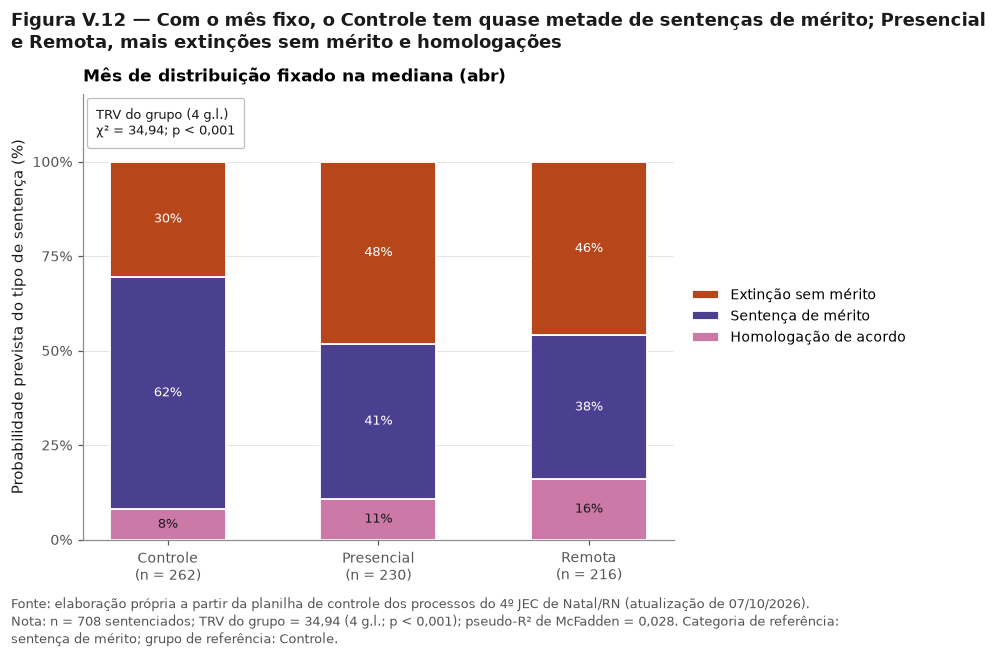

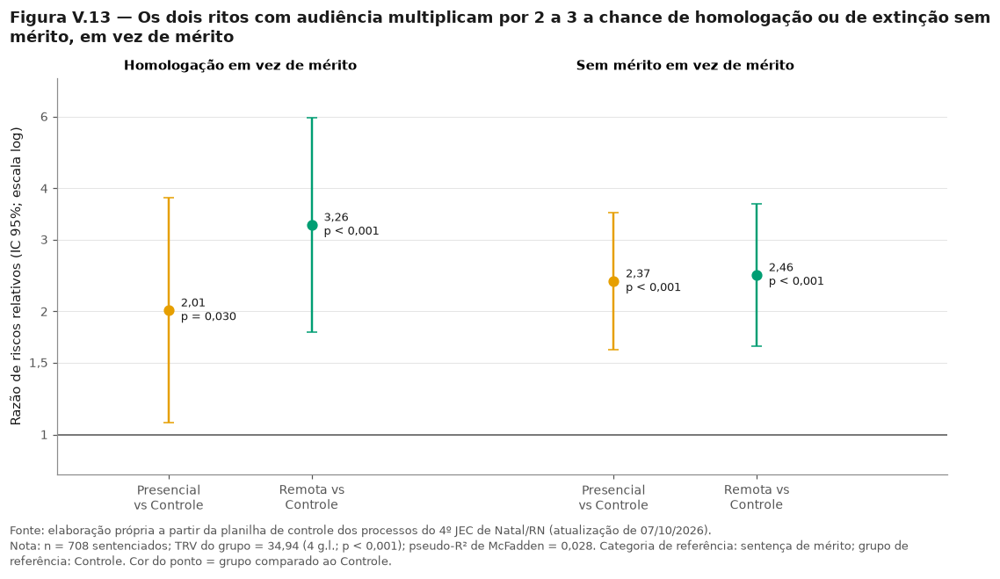

In [137]:
COD_TIPO = {'Mérito': 0, 'Homologação': 1, 'Sem mérito': 2}
ROT_TIPO = {1: 'Homologação vs Mérito', 2: 'Sem mérito vs Mérito'}
sent['y_tipo'] = sent['desfecho'].map(COD_TIPO)

def mul_mnlogit(base):
    r = smf.mnlogit('y_tipo ~ C(grupo) + mes_num', data=base).fit(disp=0, maxiter=200)
    r0 = smf.mnlogit('y_tipo ~ mes_num', data=base).fit(disp=0, maxiter=200)
    trv = 2 * (r.llf - r0.llf)
    return r, trv, stats.chi2.sf(trv, 4)

def mul_tab_rrr(r):
    ic = r.conf_int()
    eqs = list(dict.fromkeys(ic.index.get_level_values(0)))
    lin = []
    for j, col in enumerate(r.params.columns):
        for termo in r.params.index:
            k = j + 1
            lo, hi = ic.loc[(eqs[j], termo)]
            lin.append({'Equação': ROT_TIPO[k], 'Termo': NOMES_COEF.get(termo, termo),
                        'RRR': np.exp(r.params.loc[termo, col]), 'li': np.exp(lo), 'ls': np.exp(hi),
                        'p': r.pvalues.loc[termo, col]})
    return pd.DataFrame(lin)

mnl, trv_mnl, p_mnl = mul_mnlogit(sent)
sent150 = sent[sent['followup_f'] >= 150]
base150 = mul[mul['followup_f'] >= 150]
mnl150, trv150, p150 = mul_mnlogit(sent150)
rrr = mul_tab_rrr(mnl)
rrr150 = mul_tab_rrr(mnl150)
mul_res['mnl'] = (rrr, trv_mnl, p_mnl, mnl.prsquared, rrr150, p150)
nota_mnl = (f'n = {int(mnl.nobs)} sentenciados; TRV do grupo = {fmt_br(trv_mnl, 2)} (4 g.l.; p {mul_peq(p_mnl)}); '
            f'pseudo-R² de McFadden = {fmt_br(mnl.prsquared, 3)}. Categoria de referência: sentença de mérito; grupo de referência: Controle.')
mostra = lambda t: t.rename(columns={'li': 'IC 95% inf.', 'ls': 'IC 95% sup.'})[['Equação', 'Termo', 'RRR', 'IC 95% inf.', 'IC 95% sup.', 'p']]
FMT_RRR = {'RRR': 3, 'IC 95% inf.': 3, 'IC 95% sup.': 3}
tabela(mostra(rrr), 'mul_mnlogit', 'Logit multinomial do tipo de sentença ~ grupo + mês: razões de riscos relativos (RRR)',
       secao='5.2.7', formatos=FMT_RRR, destaque='p', nota=nota_mnl + ' Destaque: p < 0,05.')
nota_150 = (f'n = {len(sent150)} sentenciados de {len(base150)} distribuídos com seguimento ≥ 150 dias '
            f'({pct_br(len(sent150) / len(base150))} já sentenciados); TRV do grupo = {fmt_br(trv150, 2)} (p {mul_peq(p150)}).')
tabela(mostra(rrr150[rrr150['Termo'].str.contains('vs Controle')]), 'mul_mnlogit_150',
       'Sensibilidade: RRR dos grupos só com processos de seguimento ≥ 150 dias', secao='5.2.7', formatos=FMT_RRR,
       destaque='p', nota=nota_150 + ' Só os termos de grupo; o modelo inclui o mês.')

# (a) probabilidades previstas no mês mediano: barras 100% empilhadas por grupo
grade = pd.DataFrame({'grupo': pd.Categorical(ORDEM_GRUPO, categories=ORDEM_GRUPO), 'mes_num': np.median(sent['mes_num'])})
prev = np.asarray(mnl.predict(grade))
prev_df = pd.DataFrame(prev, index=ORDEM_GRUPO, columns=['Mérito', 'Homologação', 'Sem mérito'])
prev_df = prev_df[[k for k in ORDEM_DESFECHO if k in prev_df.columns]]
fig, ax = plt.subplots(figsize=(8.5, 5))
barras_empilhadas(ax, prev_df, cores=CORES_DESFECHO, fmt=lambda v: pct_br(v, 0), largura=0.55,
                  ylabel='Probabilidade prevista do tipo de sentença (%)', rotulos_serie=ROTULO_DESFECHO,
                  ns=[int((sent['grupo'] == g).sum()) for g in ORDEM_GRUPO])
ax.set_title(f'Mês de distribuição fixado na mediana ({MESES_PT[int(np.median(sent["mes_num"])) - 1]})')
anotar_teste(ax, texto_teste('TRV do grupo (4 g.l.)', f'χ² = {fmt_br(trv_mnl, 2)}', p_mnl), loc='upper left')
ax.set_ylim(0, 1.18)
ax.set_yticks(np.arange(0, 1.01, 0.25))
figura(fig, 'mul_mnlogit_prev', 'Com o mês fixo, o Controle tem quase metade de sentenças de mérito; Presencial e Remota, '
       'mais extinções sem mérito e homologações', secao='5.2.7', nota=nota_mnl)

# (b) RRR dos grupos nas duas equações
t = rrr[rrr['Termo'].str.contains('vs Controle')].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 5))
cores_t = [CORES_GRUPO['Presencial' if 'Presencial' in r['Termo'] else 'Remota'] for _, r in t.iterrows()]
x_pos = np.array([0, 0.45, 1.4, 1.85])[:len(t)]
mul_forest(ax, t['RRR'], t['li'], t['ls'], x=x_pos, cor=cores_t,
           textos=[f"{fmt_br(r['RRR'], 2)}\np {mul_peq(r['p'])}" for _, r in t.iterrows()])
mul_eixo_razao(ax, np.r_[t['li'], t['ls']])
ax.set_xticks(x_pos, [quebra(r['Termo'], 12) for _, r in t.iterrows()])
for xc, eq in zip([0.225, 1.625], list(dict.fromkeys(t['Equação']))):
    ax.annotate(eq.replace(' vs ', ' em vez de ').lower().capitalize(), (xc, 1), xycoords=('data', 'axes fraction'),
                xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold')
ax.set_xlim(-0.35, 2.45)
ax.set(ylabel='Razão de riscos relativos (IC 95%; escala log)')
figura(fig, 'mul_mnlogit_rrr', 'Os dois ritos com audiência multiplicam por 2 a 3 a chance de homologação ou de extinção '
       'sem mérito, em vez de mérito', secao='5.2.7', nota=nota_mnl + ' Cor do ponto = grupo comparado ao Controle.')

**Interpretação.** O tipo de sentença depende fortemente do grupo: TRV = 34,94 (4 g.l.; p < 0,001), controlado o mês. Com mérito como referência:

- **sem mérito vs. mérito**: RRR = **2,37** para a Presencial (IC 1,61 a 3,49) e **2,46** para a Remota (IC 1,65 a 3,66), ambos com p < 0,001. Nos ritos com audiência obrigatória, a chance de o processo terminar sem julgamento de mérito, em vez de com mérito, é cerca de 2,4 vezes a do rito atual;
- **homologação vs. mérito**: RRR = 2,01 para a Presencial (IC 1,07 a 3,79; p = 0,030) e **3,26** para a Remota (IC 1,78 a 5,95; p < 0,001).

Em proporções brutas, o mérito cai de 61,8% dos sentenciados no Controle (162/262) para 41,7% na Presencial (96/230) e 38,4% na Remota (83/216). Essa diferença de cerca de 20 pontos percentuais é absorvida pelas extinções sem mérito (30,2% → 47,4% e 45,4%) e, na Remota, também pelos acordos (8,0% → 16,2%). Na sensibilidade com seguimento ≥ 150 dias (90,1% já sentenciados, logo quase sem viés de seleção), os RRR praticamente não mudam (sem mérito: 1,99 e 2,42; homologação Remota: 3,20) e o TRV continua com p < 0,001. O mês aumenta um pouco a chance de sem mérito (RRR = 1,10 por mês; p = 0,037).

**Leitura jurídica.** É o achado mais robusto desta parte. A audiência obrigatória **muda a natureza da resposta jurisdicional**: menos sentenças de mérito, mais extinções e mais acordos. A hipótese do art. 51, I, da Lei 9.099/1995 (extinção pela ausência do autor à audiência) é compatível com o padrão e é examinada na árvore B (5.3.2). Do ponto de vista de política judiciária, a extinção sem mérito "resolve" o processo na vara, mas não o conflito (o autor pode repropor a ação). Comparar ritos só pelo tempo até a sentença, sem olhar o **tipo** de sentença, esconde esse custo. O pseudo-R² de McFadden (0,028) volta a mostrar que o grupo muda as proporções, mas não prevê o desfecho de um processo individual.

## 5.3 Árvores de decisão

Uma árvore de classificação (CART) particiona os dados, recursivamente, em grupos cada vez mais homogêneos quanto à resposta (ARTES; BARROSO, 2023, cap. 11, p. 377-382). Para variáveis ordinais, como o dia de distribuição, as partições são monotônicas (p. 390). O tamanho da árvore é escolhido por **poda de custo-complexidade**, C_α(A) = erro(A) + α·|folhas| (p. 395-396), com α escolhido por **validação cruzada** (5 partes estratificadas). Com tão poucos preditores, a árvore serve para (i) mostrar se há **interações** que o modelo logístico aditivo não captou e (ii) medir, fora da amostra, o poder preditivo realista. Compara-se sempre com a **regra trivial** (prever a classe mais frequente). Exige-se no mínimo 20 processos por folha, para evitar folhas espúrias.

### 5.3.1 Tipo de sentença com preditores basais

Preditores basais (anteriores ao sorteio ou o próprio sorteio): grupo (dois indicadores), dia de distribuição (0 a 214) e origem externa.

Árvore A: 7 folhas, profundidade 4, α = 0,0039
Acurácia VC = 52,0% (regra trivial "sempre mérito" = 48,2%); acurácia balanceada VC = 38,5% (trivial = 33,3%)


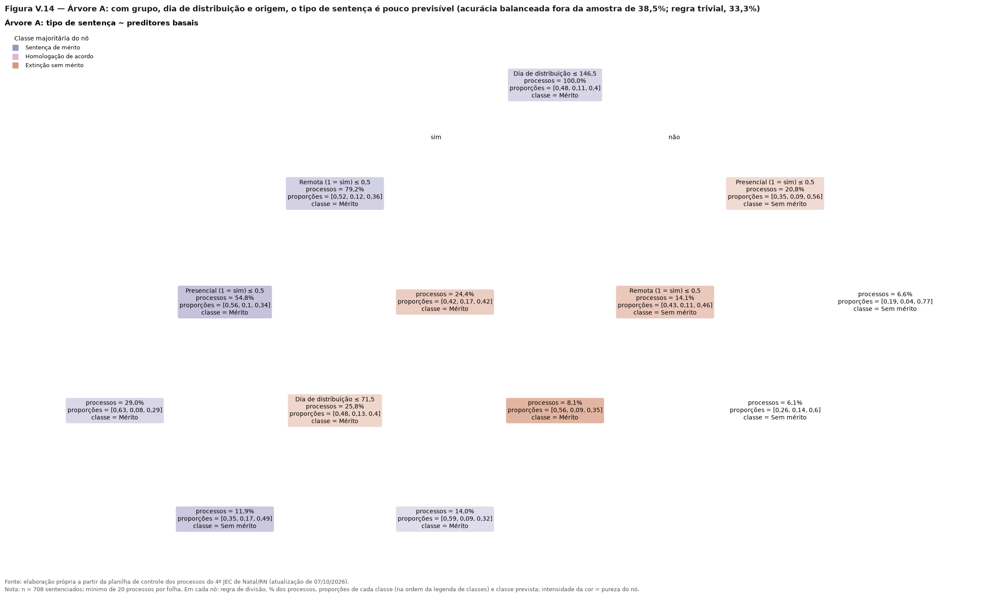

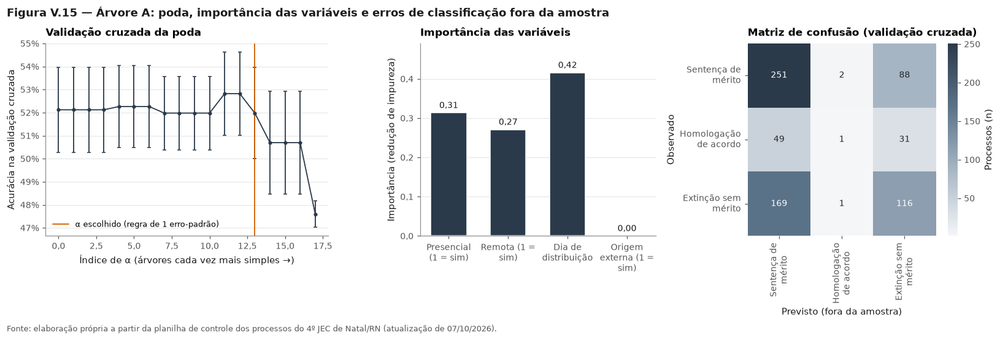

In [138]:
def arvore_cv(X, y, classificacao=True, min_folha=20, k=5, semente=SEMENTE):
    Est = DecisionTreeClassifier if classificacao else DecisionTreeRegressor
    base = Est(min_samples_leaf=min_folha, random_state=semente)
    alphas = base.cost_complexity_pruning_path(X, y).ccp_alphas
    alphas = np.unique(np.clip(alphas, 0, None))
    cv = (StratifiedKFold if classificacao else KFold)(k, shuffle=True, random_state=semente)
    score = 'accuracy' if classificacao else 'neg_mean_squared_error'
    medias, eps = [], []
    for a in alphas:
        s = cross_val_score(Est(min_samples_leaf=min_folha, ccp_alpha=a, random_state=semente), X, y, cv=cv, scoring=score)
        medias.append(s.mean()); eps.append(s.std(ddof=1) / np.sqrt(k))
    medias, eps = np.array(medias), np.array(eps)
    i_best = int(np.argmax(medias))
    # regra de 1 erro-padrão: a árvore mais simples (maior α) dentro de 1 EP da melhor
    i_1se = int(np.max(np.where(medias >= medias[i_best] - eps[i_best])[0]))
    a_sel = alphas[i_1se]
    modelo = Est(min_samples_leaf=min_folha, ccp_alpha=a_sel, random_state=semente).fit(X, y)
    prev_cv = cross_val_predict(Est(min_samples_leaf=min_folha, ccp_alpha=a_sel, random_state=semente), X, y, cv=cv)
    return {'modelo': modelo, 'alphas': alphas, 'medias': medias, 'eps': eps, 'a_sel': a_sel,
            'i_best': i_best, 'i_1se': i_1se, 'prev_cv': prev_cv, 'score': score}

def figura_arvore(r, X, y, nomes_classe, titulo, id_, secao, achado_arvore, achado_diag, metrica='Acurácia na validação cruzada',
                  nota=None):
    # (1) a árvore, sozinha e grande, com nós coloridos pela classe majoritária (cores dos desfechos)
    folhas = r['modelo'].get_n_leaves()
    fig, ax = plt.subplots(figsize=(max(9, 2.6 * folhas + 3), 2.2 * (r['modelo'].get_depth() + 1) + 1))
    if folhas > 1:
        mul_arvore(ax, r['modelo'], list(X.columns), classes=nomes_classe,
                   cores_classe={c: CORES_DESFECHO.get(c, CINZA) for c in nomes_classe}, fontsize=9)
        for c in nomes_classe:
            ax.scatter([], [], marker='s', s=90, color=CORES_DESFECHO.get(c, CINZA), alpha=0.55, label=ROTULO_DESFECHO.get(c, c))
        ax.legend(loc='upper left', title='Classe majoritária do nó', fontsize=8.5, frameon=False)
    else:
        ax.text(0.5, 0.5, 'A poda escolheu a árvore de um só nó\n(nenhuma partição melhora a previsão fora da amostra)',
                ha='center', va='center', fontsize=12); ax.axis('off')
    ax.set_title(titulo)
    figura(fig, id_, achado_arvore, secao=secao,
           nota=(nota + ' ' if nota else '') + 'Em cada nó: regra de divisão, % dos processos, proporções de cada classe '
                '(na ordem da legenda de classes) e classe prevista; intensidade da cor = pureza do nó.')
    # (2) diagnóstico: poda, importância e matriz de confusão
    fig, eixos = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={'width_ratios': [1.2, 1, 1]})
    ax = eixos[0]
    ax.errorbar(range(len(r['alphas'])), r['medias'], yerr=r['eps'], fmt='o-', ms=3, lw=1.2, color=COR_MODELO, capsize=2)
    ax.axvline(r['i_1se'], color=COR_VIES, lw=1.2, label='α escolhido (regra de 1 erro-padrão)')
    ax.set(xlabel='Índice de α (árvores cada vez mais simples →)', ylabel=metrica, title='Validação cruzada da poda')
    if r['score'] == 'accuracy':
        eixo_pct(ax)
    ax.legend(loc='lower left', fontsize=8.5)
    ax = eixos[1]
    imp = pd.Series(r['modelo'].feature_importances_, index=X.columns)
    barras_verticais(ax, [NOMES_VAR.get(c, c) for c in imp.index], imp.values, cores=COR_MODELO, quebrar=12,
                     fmt=lambda v: fmt_br(v, 2), ylabel='Importância (redução de impureza)',
                     ymax=max(imp.max() * 1.18, 0.05))
    ax.set_title('Importância das variáveis')
    ax = eixos[2]
    if nomes_classe is not None:
        cm = confusion_matrix(y, r['prev_cv'], labels=list(range(len(nomes_classe))))
        rot_c = [quebra(ROTULO_DESFECHO.get(c, c), 12) for c in nomes_classe]
        sns.heatmap(cm, annot=True, fmt='d', cmap=SEQ, cbar=True, xticklabels=rot_c, yticklabels=rot_c, ax=ax,
                    cbar_kws={'label': 'Processos (n)'}, annot_kws={'fontsize': 9})
        ax.set(xlabel='Previsto (fora da amostra)', ylabel='Observado', title='Matriz de confusão (validação cruzada)')
        ax.tick_params(axis='y', rotation=0)
    figura(fig, id_ + '_diag', achado_diag, secao=secao)
    return imp

X_base = pd.DataFrame({'presencial': sent['presencial'], 'remota': sent['remota'],
                       'dia_estudo': sent['dia_estudo_f'], 'origem_ext': sent['origem_ext']})
y_tipo = sent['y_tipo'].values
nomes_tipo = ['Mérito', 'Homologação', 'Sem mérito']
arvA = arvore_cv(X_base, y_tipo)
base_trivial = np.bincount(y_tipo).max() / len(y_tipo)
acc = accuracy_score(y_tipo, arvA['prev_cv']); bacc = balanced_accuracy_score(y_tipo, arvA['prev_cv'])
mul_res['arvA'] = (arvA['modelo'].get_n_leaves(), acc, bacc, base_trivial)
print(f"Árvore A: {arvA['modelo'].get_n_leaves()} folhas, profundidade {arvA['modelo'].get_depth()}, α = {fmt_br(arvA['a_sel'], 4)}")
print(f'Acurácia VC = {pct_br(acc)} (regra trivial "sempre mérito" = {pct_br(base_trivial)}); '
      f'acurácia balanceada VC = {pct_br(bacc)} (trivial = 33,3%)')
impA = figura_arvore(arvA, X_base, y_tipo, nomes_tipo, 'Árvore A: tipo de sentença ~ preditores basais', 'mul_arvore_A', '5.3.1',
                     f'Árvore A: com grupo, dia de distribuição e origem, o tipo de sentença é pouco previsível '
                     f'(acurácia balanceada fora da amostra de {pct_br(bacc)}; regra trivial, 33,3%)',
                     'Árvore A: poda, importância das variáveis e erros de classificação fora da amostra',
                     nota=f'n = {len(y_tipo)} sentenciados; mínimo de 20 processos por folha.')

**Interpretação.** A poda pela regra de 1 erro-padrão escolheu uma árvore de 7 folhas e profundidade 4, mas o gráfico da validação cruzada mostra que a acurácia é praticamente **plana** (cerca de 52%) em todas as complexidades. Fora da amostra, a árvore acerta **52,0%**, contra 48,2% da regra trivial "sempre mérito", e a acurácia balanceada é 38,5%, contra 33,3% do acaso. A homologação quase nunca é prevista (1 de 81 acertos), porque não domina nenhuma folha. O ganho preditivo é mínimo.

O que a árvore sugere, como **hipótese exploratória** de interação: a primeira partição é o dia de distribuição (≤ 146,5, isto é, até ~27/05); depois vem o grupo. A folha mais pura é a dos processos **Presencial distribuídos a partir do fim de maio** (6,6% da amostra), com 76,6% de sentenças sem mérito. A folha do Controle distribuído no início (até ~13/03) tem 63,4% de mérito. A importância relativa (dia 0,42; Presencial 0,31; Remota 0,27; origem externa 0) confirma que só grupo e calendário carregam informação. Essa interação grupo × período não foi testada formalmente e pode refletir mudanças na pauta da audiência presencial ao longo do experimento; com 60 processos na folha, convém não lhe dar peso confirmatório.

### 5.3.2 Tipo de sentença nos grupos tratados, com variáveis do processo (exploratória)

Nos grupos Presencial e Remota, acrescentam-se duas variáveis **pós-sorteio**: se a audiência foi realizada e se foi híbrida. A hipótese jurídica da Parte III é que a extinção sem mérito nos tratados decorre da **ausência do autor à audiência obrigatória** (art. 51, I, Lei 9.099/1995). Atenção à causalidade reversa: "audiência não realizada" pode ser causa da extinção (ausência do autor) ou consequência dela (o processo foi extinto, por desistência ou indeferimento, antes da data da audiência). A árvore mostra a **associação**, não separa esses caminhos; para isso seria preciso registrar a data e o motivo da não realização.

Árvore B (tratados, n = 446): 2 folhas; acurácia VC = 73,3% (trivial = 46,4%); acurácia balanceada VC = 57,1%


Audiência de conciliação,Homologação de acordo (%),Sentença de mérito (%),Extinção sem mérito (%)
AC não realizada,"14,8","2,2","83,1"
AC realizada,"12,5","66,5","20,9"


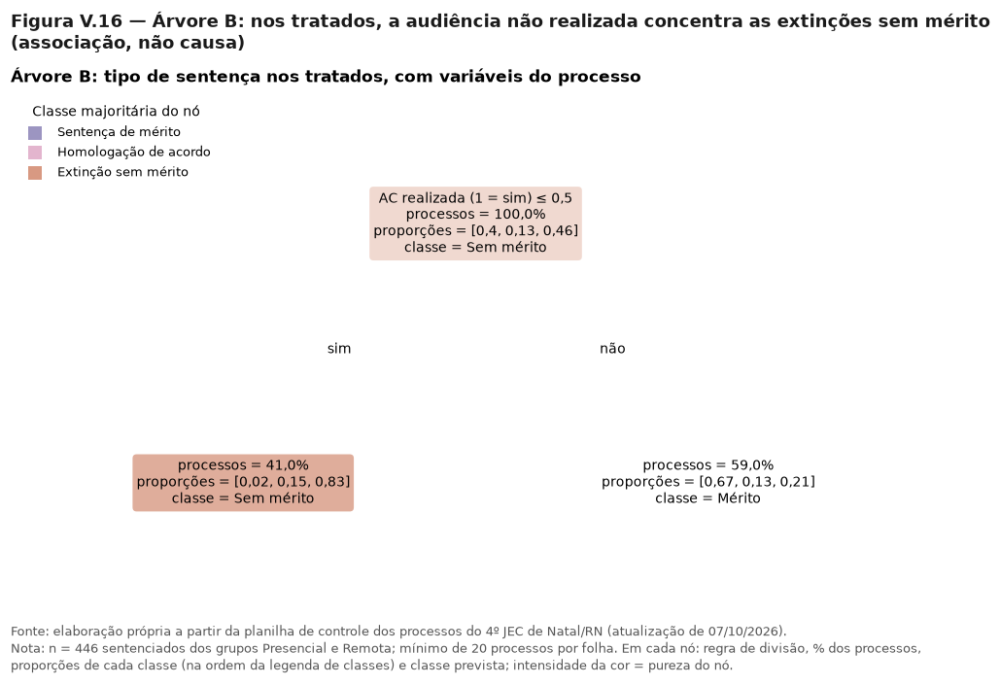

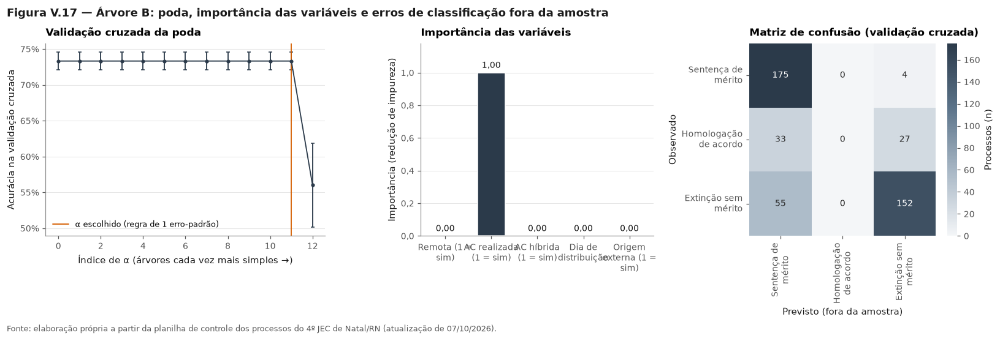

In [139]:
trat = sent[sent['grupo'] != 'Controle'].copy()
X_proc = pd.DataFrame({'remota': trat['remota'], 'ac_realizada': trat['ac_realizada'].astype(bool).astype(int),
                       'hibrida': trat['hibrida_b'], 'dia_estudo': trat['dia_estudo_f'], 'origem_ext': trat['origem_ext']})
y_trat = trat['y_tipo'].values
arvB = arvore_cv(X_proc, y_trat)
accB = accuracy_score(y_trat, arvB['prev_cv']); baccB = balanced_accuracy_score(y_trat, arvB['prev_cv'])
trivB = np.bincount(y_trat).max() / len(y_trat)
mul_res['arvB'] = (arvB['modelo'].get_n_leaves(), accB, baccB, trivB)
print(f"Árvore B (tratados, n = {len(trat)}): {arvB['modelo'].get_n_leaves()} folhas; acurácia VC = {pct_br(accB)} "
      f"(trivial = {pct_br(trivB)}); acurácia balanceada VC = {pct_br(baccB)}")
tab_acr = pd.crosstab(X_proc['ac_realizada'].map({1: 'AC realizada', 0: 'AC não realizada'}), trat['desfecho'],
                      normalize='index').reindex(columns=['Homologação', 'Mérito', 'Sem mérito'])
tab_acr = (100 * tab_acr).rename(columns=lambda c: ROTULO_DESFECHO[c] + ' (%)').rename_axis('Audiência de conciliação')
tabela(tab_acr, 'mul_tratados_acr', 'Tipo de sentença nos tratados conforme a audiência foi ou não realizada (% da linha)',
       secao='5.3.2', casas=1, nota=f'n = {len(trat)} sentenciados dos grupos Presencial e Remota.')
impB = figura_arvore(arvB, X_proc, y_trat, nomes_tipo, 'Árvore B: tipo de sentença nos tratados, com variáveis do processo',
                     'mul_arvore_B', '5.3.2',
                     'Árvore B: nos tratados, a audiência não realizada concentra as extinções sem mérito (associação, não causa)',
                     'Árvore B: poda, importância das variáveis e erros de classificação fora da amostra',
                     nota=f'n = {len(y_trat)} sentenciados dos grupos Presencial e Remota; mínimo de 20 processos por folha.')

**Interpretação.** Nos tratados, a árvore escolhida tem **uma única partição**: a audiência foi ou não realizada. Quando não foi, **83,1%** das sentenças são sem mérito (só 2,2% de mérito); quando foi, 66,5% são de mérito, 20,9% sem mérito e 12,5% homologações. A acurácia fora da amostra sobe para **73,3%** (trivial 46,4%; balanceada 57,1%), muito acima da árvore com preditores basais. Modalidade, híbrida, data e origem não acrescentam nada depois dessa partição.

**Leitura jurídica e cautela causal.** O padrão é o que se espera da extinção por **ausência do autor à audiência** (art. 51, I, Lei 9.099/1995): a audiência obrigatória cria uma oportunidade de extinção que não existe no rito atual, e isso explica boa parte do excesso de sentenças sem mérito nos tratados (5.2.7). Mas "audiência não realizada" é variável **pós-sorteio** e pode ser também **consequência** da extinção (desistência ou indeferimento antes da data marcada). A árvore não distingue os dois caminhos. Para separá-los, a planilha precisaria registrar a data designada da audiência, o motivo da não realização (ausência do autor, do réu, redesignação) e o fundamento legal da sentença sem mérito. Os 14,8% de homologações entre as audiências não realizadas são acordos apresentados por petição antes da sessão.

### 5.3.3 Acordo entre os encerrados (preditores basais)

A mesma árvore, agora para o acordo (definição A). Como os acordos são só 11% dos encerrados, a acurácia é inútil (a regra trivial "nunca há acordo" acerta 89%); a poda é feita pela acurácia, mas o desempenho é medido pela **AUC fora da amostra** das probabilidades das folhas, comparável à do logit (5.2.4).

Árvore C (acordo): poda por acurácia escolheu 1 folha(s); AUC VC de uma árvore de profundidade 3 = 0,535 (logit (A), VC: 0,546)


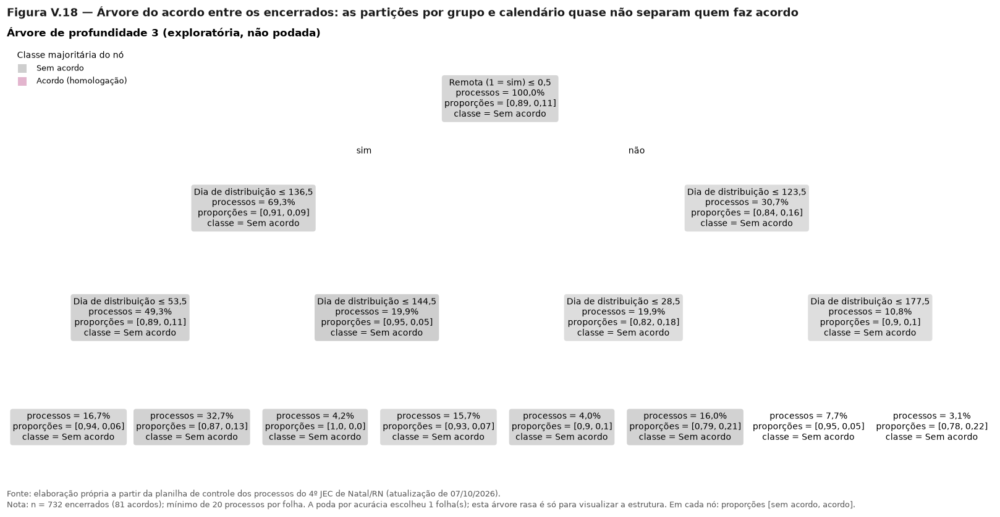

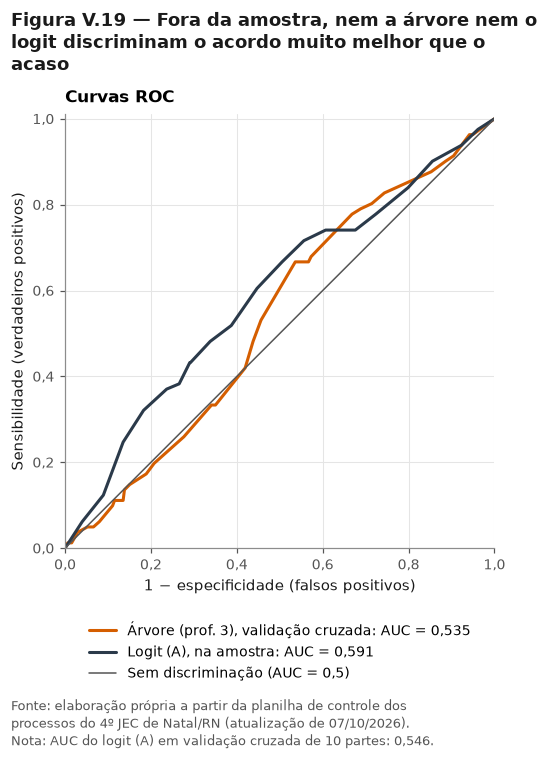

In [140]:
X_enc = pd.DataFrame({'presencial': enc['presencial'], 'remota': enc['remota'],
                      'dia_estudo': enc['dia_estudo_f'], 'origem_ext': enc['origem_ext']})
y_enc = enc['homolog'].values
arvC = arvore_cv(X_enc, y_enc)
# a árvore podada por acurácia tende a um nó; para a AUC usa-se a probabilidade de folhas de uma árvore rasa (profundidade 3)
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEMENTE)
prob_cv = cross_val_predict(DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=SEMENTE),
                            X_enc, y_enc, cv=cv5, method='predict_proba')[:, 1]
auc_arv = roc_auc_score(y_enc, prob_cv)
mul_res['arvC'] = (arvC['modelo'].get_n_leaves(), auc_arv)
print(f"Árvore C (acordo): poda por acurácia escolheu {arvC['modelo'].get_n_leaves()} folha(s); "
      f"AUC VC de uma árvore de profundidade 3 = {fmt_br(auc_arv, 3)} (logit (A), VC: {fmt_br(auccvA, 3)})")
arvC3 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, random_state=SEMENTE).fit(X_enc, y_enc)
fig, ax = plt.subplots(figsize=(15, 7))
cls_acordo = ['Sem acordo', 'Acordo']
mul_arvore(ax, arvC3, list(X_enc.columns), classes=cls_acordo,
           cores_classe={'Sem acordo': CINZA, 'Acordo': CORES_DESFECHO['Homologação']}, fontsize=9)
for c, cor in [('Sem acordo', CINZA), ('Acordo (homologação)', CORES_DESFECHO['Homologação'])]:
    ax.scatter([], [], marker='s', s=90, color=cor, alpha=0.55, label=c)
ax.legend(loc='upper left', title='Classe majoritária do nó', fontsize=8.5)
ax.set_title('Árvore de profundidade 3 (exploratória, não podada)')
figura(fig, 'mul_arvore_C', 'Árvore do acordo entre os encerrados: as partições por grupo e calendário quase não separam '
       'quem faz acordo', secao='5.3.3',
       nota=f'n = {len(y_enc)} encerrados ({int(y_enc.sum())} acordos); mínimo de 20 processos por folha. A poda por acurácia '
            f'escolheu {arvC["modelo"].get_n_leaves()} folha(s); esta árvore rasa é só para visualizar a estrutura. '
            'Em cada nó: proporções [sem acordo, acordo].')

fig, ax = plt.subplots(figsize=(6.2, 5.8))
fpr, tpr, _ = roc_curve(y_enc, prob_cv)
ax.plot(fpr, tpr, color=COR_VIES, lw=2, label=f'Árvore (prof. 3), validação cruzada: AUC = {fmt_br(auc_arv, 3)}')
fpr, tpr, _ = roc_curve(yA, pA)
ax.plot(fpr, tpr, color=COR_MODELO, lw=2, label=f'Logit (A), na amostra: AUC = {fmt_br(aucA, 3)}')
ax.plot([0, 1], [0, 1], color=TINTA_2, lw=1, label='Sem discriminação (AUC = 0,5)')
ax.set(xlabel='1 − especificidade (falsos positivos)', ylabel='Sensibilidade (verdadeiros positivos)',
       title='Curvas ROC', xlim=(0, 1), ylim=(0, 1.01))
ax.set_aspect('equal')
ax.grid(axis='both', visible=True)
legenda_abaixo(ax, ncol=1, dy=-0.14)
figura(fig, 'mul_arvore_C_roc', 'Fora da amostra, nem a árvore nem o logit discriminam o acordo muito melhor que o acaso',
       secao='5.3.3', nota=f'AUC do logit (A) em validação cruzada de 10 partes: {fmt_br(auccvA, 3)}.')

**Interpretação.** Para o acordo, a poda por validação cruzada reduz a árvore a **um único nó**: nenhuma partição por grupo, data ou origem melhora a classificação fora da amostra, o que é natural com 11% de acordos (a regra "nunca há acordo" já acerta 89%). Mesmo uma árvore rasa, avaliada pela ordenação das probabilidades, tem AUC fora da amostra de **0,535**, equivalente à do logit (0,546) e igualmente pobre. A árvore exibida, de profundidade 3, é só ilustrativa. A conclusão coincide com 5.2.4: o efeito do grupo sobre o acordo é real na média, mas não serve para prever casos.

### 5.3.4 Árvore de sobrevivência (aproximação pelos resíduos martingal)

Árvores de sobrevivência propriamente ditas (LeBlanc e Crowley, 1993) exigem o pacote `scikit-survival`, que não está instalado no ambiente do projeto. A aproximação clássica de Therneau, Grambsch e Fleming (1990) dispensa o pacote: calcula-se o **resíduo martingal de um modelo de Cox nulo**, Mᵢ = δᵢ − Ĥ₀(tᵢ), em que Ĥ₀ é o risco acumulado de Nelson-Aalen. Mᵢ > 0 indica processo sentenciado "antes do esperado" e Mᵢ < 0, processo que demora mais que o esperado (ou censurado tardio). Uma **árvore de regressão** sobre Mᵢ, com poda por validação cruzada (erro quadrático médio), encontra os subgrupos com tempos mais distintos, e as curvas de Kaplan-Meier das folhas mostram o resultado na escala natural. Os 938 processos entram (os censurados contribuem com δ = 0). O log-rank entre folhas é apresentado só como descrição: as partições foram escolhidas para maximizar a diferença, de modo que o valor-p é otimista.

Árvore podada (regra 1 EP): 1 folha(s); R² VC dos resíduos martingal ≈ -0,010
Melhor α sem a regra 1 EP: R² VC ≈ -0,010
Exibição: árvore exploratória de profundidade 2 (não sobrevive à validação cruzada).


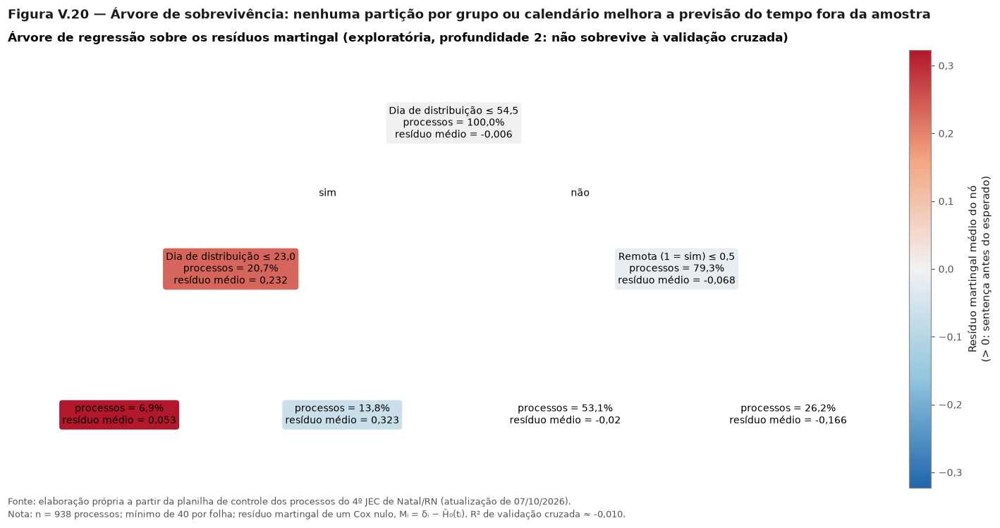

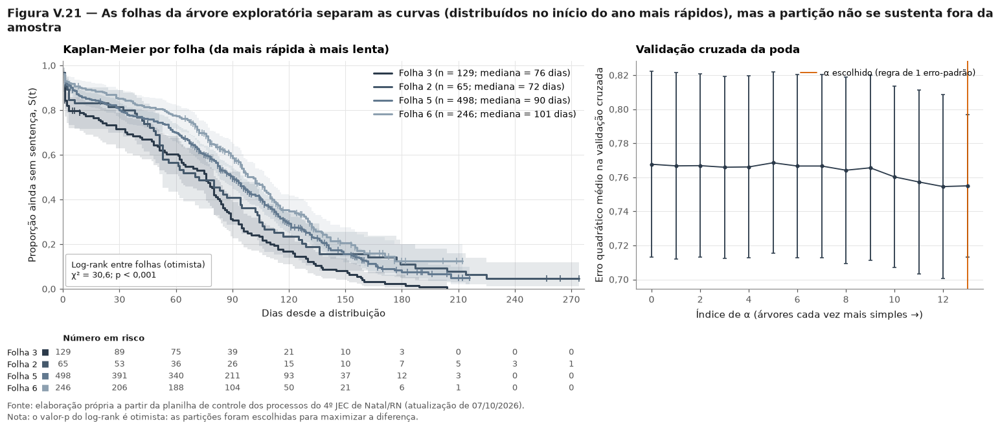

In [141]:
naf = NelsonAalenFitter().fit(mul['T'], mul['E'])
H0 = naf.cumulative_hazard_at_times(mul['T']).values
mul['martingal'] = mul['E'] - H0
X_sob = pd.DataFrame({'presencial': mul['presencial'], 'remota': mul['remota'],
                      'dia_estudo': mul['dia_estudo_f'], 'origem_ext': mul['origem_ext']})
arvS = arvore_cv(X_sob, mul['martingal'].values, classificacao=False, min_folha=40)
mS = arvS['modelo']
r2_cv = 1 - (-arvS['medias'][arvS['i_1se']]) / mul['martingal'].var(ddof=0)
r2_best = 1 - (-arvS['medias'][arvS['i_best']]) / mul['martingal'].var(ddof=0)
print(f"Árvore podada (regra 1 EP): {mS.get_n_leaves()} folha(s); R² VC dos resíduos martingal ≈ {fmt_br(r2_cv, 3)}")
print(f"Melhor α sem a regra 1 EP: R² VC ≈ {fmt_br(r2_best, 3)}")
mS_podada_folhas = mS.get_n_leaves()
if mS.get_n_leaves() == 1:
    # a poda eliminou todas as partições; para visualizar a estrutura, exibe-se uma árvore rasa NÃO validada
    mS = DecisionTreeRegressor(max_depth=2, min_samples_leaf=40, random_state=SEMENTE).fit(X_sob, mul['martingal'])
    print('Exibição: árvore exploratória de profundidade 2 (não sobrevive à validação cruzada).')
mul['folha'] = mS.apply(X_sob)
folhas = sorted(mul['folha'].unique(), key=lambda f: -mul.loc[mul['folha'] == f, 'martingal'].mean())
mul_res['arvS'] = (mS_podada_folhas, r2_cv)
rot_exploratoria = ' (exploratória, profundidade 2: não sobrevive à validação cruzada)' if mS_podada_folhas == 1 else ''
fig, ax = plt.subplots(figsize=(13, 6.2))
if mS.get_n_leaves() > 1:
    mul_arvore(ax, mS, list(X_sob.columns), classes=None, fontsize=9, precisao=3)
    sm_ = mpl.cm.ScalarMappable(cmap=DIV, norm=mpl.colors.Normalize(-np.abs(mS.tree_.value[:, 0, 0]).max(),
                                                                     np.abs(mS.tree_.value[:, 0, 0]).max()))
    cb = fig.colorbar(sm_, ax=ax, fraction=0.025, pad=0.01)
    cb.set_label('Resíduo martingal médio do nó\n(> 0: sentença antes do esperado)')
ax.set_title('Árvore de regressão sobre os resíduos martingal' + rot_exploratoria)
figura(fig, 'mul_arvore_sobrev', 'Árvore de sobrevivência: nenhuma partição por grupo ou calendário melhora a previsão '
       'do tempo fora da amostra', secao='5.3.4',
       nota=f'n = {len(mul)} processos; mínimo de 40 por folha; resíduo martingal de um Cox nulo, Mᵢ = δᵢ − Ĥ₀(tᵢ). '
            f'R² de validação cruzada ≈ {fmt_br(r2_cv, 3)}.')

fig, eixos = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1.5, 1]})
ax = eixos[0]
if len(folhas) > 1:
    cores_folha = {f'Folha {f}': SEQ(v) for f, v in zip(folhas, np.linspace(1.0, 0.45, len(folhas)))}
    mul_km = mul.assign(folha_rot=mul['folha'].map(lambda f: f'Folha {f}'))
    plot_km(ax, mul_km, tempo='T', evento='E', grupo='folha_rot', ordem=list(cores_folha), cores=cores_folha, passo=30,
            tmax=float(mul['T'].max()))
    lr = multivariate_logrank_test(mul['T'], mul['folha'], mul['E'])
    anotar_teste(ax, texto_teste('Log-rank entre folhas (otimista)', f'χ² = {fmt_br(lr.test_statistic, 1)}', lr.p_value),
                 loc='lower left')
    ax.set_title('Kaplan-Meier por folha (da mais rápida à mais lenta)')
    mul_res['arvS_lr'] = lr.p_value
ax = eixos[1]
ax.errorbar(range(len(arvS['alphas'])), -arvS['medias'], yerr=arvS['eps'], fmt='o-', ms=3, lw=1.2, color=COR_MODELO, capsize=2)
ax.axvline(arvS['i_1se'], color=COR_VIES, lw=1.2, label='α escolhido (regra de 1 erro-padrão)')
ax.set(xlabel='Índice de α (árvores cada vez mais simples →)', ylabel='Erro quadrático médio na validação cruzada',
       title='Validação cruzada da poda')
ax.legend(loc='upper right', fontsize=8.5)
figura(fig, 'mul_arvore_sobrev_km', 'As folhas da árvore exploratória separam as curvas (distribuídos no início do ano mais rápidos), '
       'mas a partição não se sustenta fora da amostra',
       secao='5.3.4', nota='o valor-p do log-rank é otimista: as partições foram escolhidas para maximizar a diferença.')

**Interpretação.** A árvore de regressão sobre os resíduos martingal **não sobrevive à validação cruzada**. O erro quadrático médio fora da amostra é praticamente o mesmo em todas as complexidades, a regra de 1 EP escolhe a raiz (sem partição) e, mesmo no melhor α, o R² fora da amostra é ≈ −0,010. Grupo, data de distribuição e origem não definem subgrupos com tempos de tramitação previsivelmente diferentes.

A árvore de profundidade 2 do gráfico é **exploratória** (não validada). A primeira partição é a data (até ~24/02: resíduo médio +0,23, ou seja, sentenças mais rápidas que o esperado, o que é coerente com o acúmulo de acervo visto em 5.1.3). Entre os distribuídos depois, separa a Remota (n = 246; resíduo −0,17, mais lenta) dos demais (n = 498; −0,02), na mesma direção da razão de tempos do AFT (1,23, não significativa). O log-rank entre folhas (30,6; p < 0,001) é otimista, porque as partições foram escolhidas para maximizar a separação, e não deve ser lido como teste. A abordagem dos resíduos martingal (Therneau, Grambsch e Fleming, 1990) substitui razoavelmente uma árvore de sobrevivência (`scikit-survival`, não instalado). O resultado negativo é informativo: não há heterogeneidade de tempo explorável com as variáveis disponíveis.

## 5.4 Análise de correspondência

A análise de correspondência (AC) decompõe a estatística χ² de uma tabela de contingência em dimensões ortogonais e representa linhas e colunas num mesmo plano: categorias próximas têm perfis parecidos, e uma categoria de linha próxima de uma de coluna indica associação positiva. A **inércia total** é χ²/n; cada dimensão explica uma fração dela. Implementação direta por decomposição em valores singulares (SVD) da matriz de resíduos padronizados S = D_r^(−1/2)(P − rcᵀ)D_c^(−1/2), sem bibliotecas externas: coordenadas principais das linhas F = D_r^(−1/2)UΣ e das colunas G = D_c^(−1/2)VΣ (mapa simétrico).

### 5.4.1 AC simples: grupo × tipo de desfecho

A tabela inclui os cinco desfechos (inclusive ativos e redistribuídos), porque a composição dos ativos também difere entre grupos. Com 3 linhas, há no máximo 2 dimensões, e o plano explica 100% da inércia. O teste χ² de independência (H0: o perfil de desfechos é o mesmo nos três grupos) é o teste associado; o mapa é o seu gráfico.

Grupo,Homologação de acordo,Sentença de mérito,Extinção sem mérito,Redistribuição (Decisão),Em tramitação (censurado)
Controle,21,162,79,5,46
Presencial,25,96,109,10,74
Remota,35,83,98,9,86


Inércia total = 0,0579 = χ²/n = 54,28/938; χ² (8 g.l.) p < 0,001
  dimensão 1: inércia 0,0548 (94,7%)
  dimensão 2: inércia 0,0031 (5,3%)


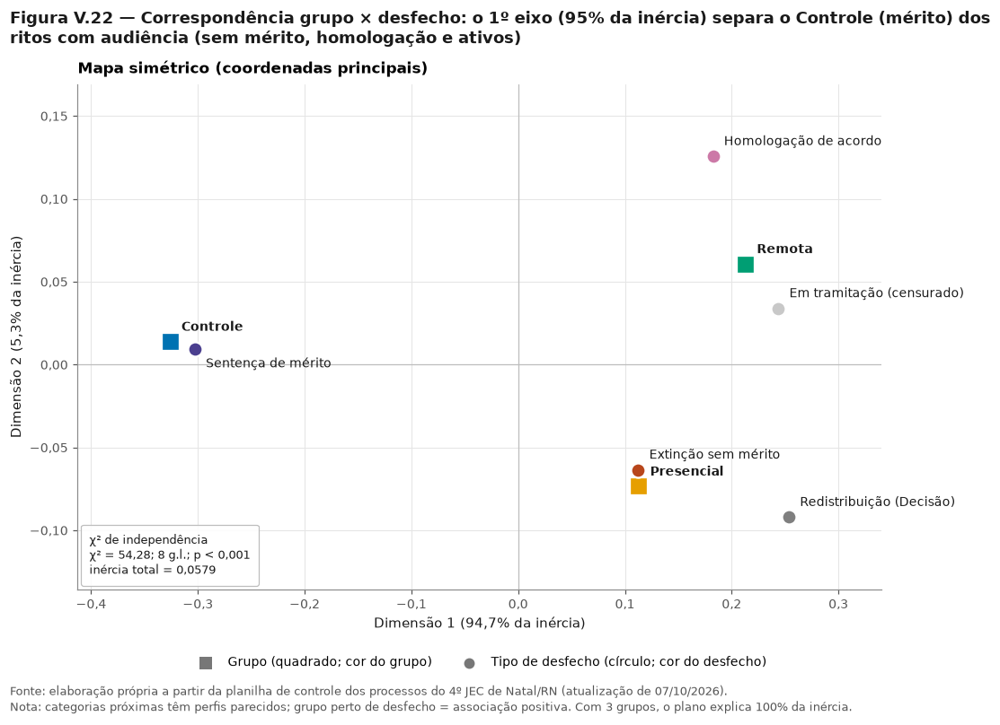

In [142]:
def analise_correspondencia(tabela):
    N = np.asarray(tabela, float)
    n = N.sum(); P = N / n
    r, c = P.sum(1), P.sum(0)
    S = (P - np.outer(r, c)) / np.sqrt(np.outer(r, c))
    U, sv, Vt = np.linalg.svd(S, full_matrices=False)
    k = int(np.sum(sv > 1e-12))
    F = (U[:, :k] * sv[:k]) / np.sqrt(r)[:, None]
    G = (Vt.T[:, :k] * sv[:k]) / np.sqrt(c)[:, None]
    inercia = sv[:k] ** 2
    return {'F': F, 'G': G, 'inercia': inercia, 'total': inercia.sum(), 'n': n, 'massa_l': r, 'massa_c': c}

tab_ca = pd.crosstab(mul['grupo'], mul['tipo_desfecho']).reindex(columns=ORDEM_DESFECHO)
ca = analise_correspondencia(tab_ca)
chi2_ca, p_ca, gl_ca, _ = stats.chi2_contingency(tab_ca)
mul_res['ca'] = (ca['inercia'] / ca['total'], chi2_ca, p_ca)
tabela(tab_ca.rename(columns=ROTULO_DESFECHO).rename_axis('Grupo').rename_axis(columns=None), 'mul_ca_tabela',
       'Tabela grupo × tipo de desfecho analisada pela correspondência (processos)', secao='5.4.1',
       nota=f'n = {int(tab_ca.values.sum())} processos (inclui ativos e redistribuídos).')
print(f"Inércia total = {fmt_br(ca['total'], 4)} = χ²/n = {fmt_br(chi2_ca, 2)}/{int(ca['n'])}; χ² ({gl_ca} g.l.) p {p_br(p_ca)}")
for i, v in enumerate(ca['inercia']):
    print(f'  dimensão {i + 1}: inércia {fmt_br(v, 4)} ({pct_br(v / ca["total"])})')

pin = ca['inercia'] / ca['total']
fig, ax = plt.subplots(figsize=(10, 6.5))
for i, g in enumerate(tab_ca.index):
    ax.scatter(ca['F'][i, 0], ca['F'][i, 1], s=170, color=CORES_GRUPO[g], marker='s', zorder=3, edgecolor='white', lw=1.5)
for j, d in enumerate(tab_ca.columns):
    ax.scatter(ca['G'][j, 0], ca['G'][j, 1], s=110, color=CORES_DESFECHO[d], marker='o', zorder=3, edgecolor='white', lw=1.5)
ax.axhline(0, color='#bdbdbd', lw=0.8, zorder=1); ax.axvline(0, color='#bdbdbd', lw=0.8, zorder=1)
ax.grid(axis='both', visible=True)
todos_x = np.r_[ca['F'][:, 0], ca['G'][:, 0]]; todos_y = np.r_[ca['F'][:, 1], ca['G'][:, 1]]
mx, my = np.ptp(todos_x) * 0.15, np.ptp(todos_y) * 0.2
ax.set_xlim(todos_x.min() - mx, todos_x.max() + mx); ax.set_ylim(todos_y.min() - my, todos_y.max() + my)
ax.set(xlabel=f'Dimensão 1 ({pct_br(pin[0])} da inércia)', ylabel=f'Dimensão 2 ({pct_br(pin[1])} da inércia)',
       title='Mapa simétrico (coordenadas principais)')
mul_rotular_pontos(ax, todos_x, todos_y, list(tab_ca.index) + [ROTULO_DESFECHO[d] for d in tab_ca.columns],
                   negrito=[True] * len(tab_ca.index) + [False] * len(tab_ca.columns))
ax.scatter([], [], marker='s', s=80, color='#777777', label='Grupo (quadrado; cor do grupo)')
ax.scatter([], [], marker='o', s=60, color='#777777', label='Tipo de desfecho (círculo; cor do desfecho)')
legenda_abaixo(ax, ncol=2, dy=-0.11)
anotar_teste(ax, texto_teste('χ² de independência', f'χ² = {fmt_br(chi2_ca, 2)}; {gl_ca} g.l.', p_ca,
                             f'inércia total = {fmt_br(ca["total"], 4)}'), loc='lower left')
figura(fig, 'mul_ca_mapa', f'Correspondência grupo × desfecho: o 1º eixo ({pct_br(pin[0], 0)} da inércia) separa o Controle (mérito) '
       'dos ritos com audiência (sem mérito, homologação e ativos)', secao='5.4.1',
       nota='categorias próximas têm perfis parecidos; grupo perto de desfecho = associação positiva. Com 3 grupos, o plano '
            'explica 100% da inércia.')

**Interpretação.** O χ² de independência rejeita H0 (χ² = 54,28; 8 g.l.; p < 0,001), mas a inércia total é pequena (0,058, o que equivale a um V de Cramér ≈ 0,17): a associação é real e moderada-fraca. A **dimensão 1 concentra 94,7%** da inércia e opõe, de um lado, **Controle e Mérito** (que praticamente coincidem no mapa) e, de outro, os dois ritos com audiência obrigatória, próximos de sem mérito, homologação, ativo e redistribuição. A **dimensão 2** (5,3%) distingue os dois tratamentos: a **Remota** fica perto de **homologação** e **ativo** (mais acordos e mais processos ainda em tramitação), e a **Presencial** fica perto de **sem mérito** e **redistribuição**. A análise de correspondência resume, num só gráfico, o que o logit multinomial quantificou: a diferença essencial é "rito atual = julgamento de mérito" contra "audiência obrigatória = desfechos alternativos", e a Remota se diferencia pelos acordos.

### 5.4.2 AC múltipla: grupo × tipo de desfecho × bimestre de distribuição

A AC múltipla (ACM) aplica a mesma decomposição à **matriz indicadora** (uma coluna por categoria de cada variável, 938 linhas). O mês entra agrupado em bimestres (jan-fev, mar-abr, mai-jun, jul-ago) para evitar categorias raras. Na ACM, as inércias brutas subestimam a qualidade da representação; usa-se a **correção de Benzécri**: para Q variáveis, só os autovalores λ > 1/Q contam, e λ* = [Q/(Q − 1)]² (λ − 1/Q)². O objetivo é ver se o eixo "desfecho" e o eixo "calendário" se misturam com o eixo "grupo", ou seja, se o mês confunde a comparação.

Dimensão,Autovalor bruto,Inércia bruta (%),Inércia corrigida de Benzécri (%)
1,"0,5242","17,5","87,2"
2,"0,3912","13,0","8,0"
3,"0,3736","12,5","3,9"
4,"0,3527","11,8","0,9"
5,"0,3298","11,0","0,0"
6,"0,3108","10,4","0,0"


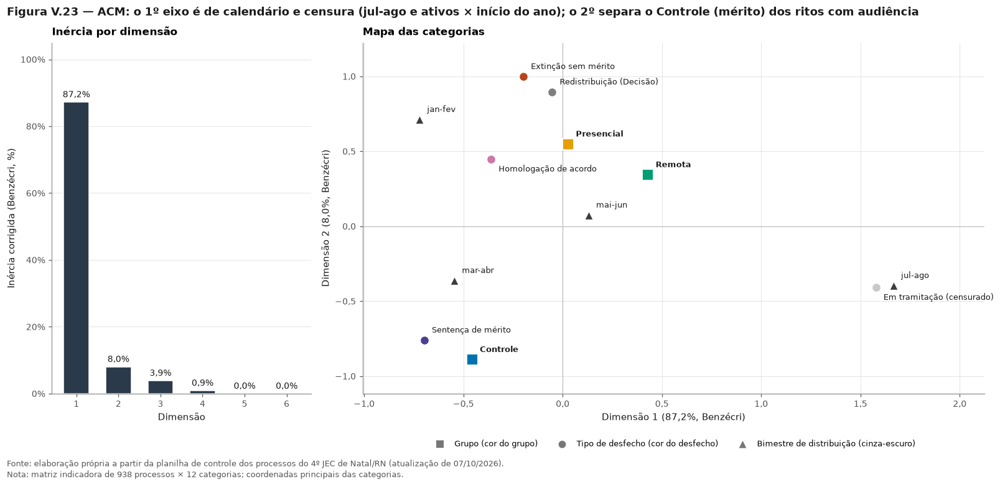

In [143]:
bimestre = pd.cut(mul['mes_num'], [0, 2, 4, 6, 8], labels=['jan-fev', 'mar-abr', 'mai-jun', 'jul-ago'])
vars_acm = pd.DataFrame({'grupo': mul['grupo'].astype(str), 'desfecho': mul['desfecho'], 'bimestre': bimestre.astype(str)})
Z = pd.get_dummies(vars_acm, prefix_sep=': ').astype(float)
acm = analise_correspondencia(Z.values)
Q = vars_acm.shape[1]
lam = acm['inercia']
lam_adj = np.where(lam > 1 / Q, (Q / (Q - 1)) ** 2 * (lam - 1 / Q) ** 2, 0)
pct_adj = lam_adj / lam_adj.sum()
mul_res['acm'] = pct_adj[:2]
tabela(pd.DataFrame({'Dimensão': np.arange(1, len(lam) + 1), 'Autovalor bruto': lam,
                     'Inércia bruta (%)': 100 * lam / lam.sum(), 'Inércia corrigida de Benzécri (%)': 100 * pct_adj}).head(6),
       'mul_acm_inercia', 'ACM grupo × desfecho × bimestre: inércia por dimensão, bruta e com a correção de Benzécri',
       secao='5.4.2', formatos={'Autovalor bruto': 4},
       nota=f'Q = {Q} variáveis; só os autovalores λ > 1/Q contam na correção λ* = [Q/(Q − 1)]²(λ − 1/Q)².')
fig, eixos = plt.subplots(1, 2, figsize=(15, 6.5), gridspec_kw={'width_ratios': [1, 2.4]})
ax = eixos[0]
barras_verticais(ax, [str(k) for k in range(1, 7)], pct_adj[:6], cores=COR_MODELO, rotular=True,
                 fmt=lambda v: pct_br(v, 1), xlabel='Dimensão', ylabel='Inércia corrigida (Benzécri, %)', ymax=1.05)
eixo_pct(ax)
ax.set_title('Inércia por dimensão')
ax = eixos[1]
marc = {'grupo': 's', 'desfecho': 'o', 'bimestre': '^'}
xs, ys, rots, negr = [], [], [], []
for j, col in enumerate(Z.columns):
    var, cat = col.split(': ', 1)
    cor = CORES_GRUPO.get(cat) if var == 'grupo' else (CORES_DESFECHO.get(cat) if var == 'desfecho' else '#3D3D3D')
    ax.scatter(acm['G'][j, 0], acm['G'][j, 1], marker=marc[var], s=150 if var == 'grupo' else 90, color=cor, zorder=3,
               edgecolor='white', lw=1.2)
    xs.append(acm['G'][j, 0]); ys.append(acm['G'][j, 1])
    rots.append(ROTULO_DESFECHO.get(cat, cat) if var == 'desfecho' else cat); negr.append(var == 'grupo')
ax.axhline(0, color='#bdbdbd', lw=0.8, zorder=1); ax.axvline(0, color='#bdbdbd', lw=0.8, zorder=1)
ax.grid(axis='both', visible=True)
mx, my = np.ptp(xs) * 0.12, np.ptp(ys) * 0.12
ax.set_xlim(min(xs) - mx, max(xs) + mx * 1.6); ax.set_ylim(min(ys) - my, max(ys) + my)
ax.set(xlabel=f'Dimensão 1 ({pct_br(pct_adj[0])}, Benzécri)', ylabel=f'Dimensão 2 ({pct_br(pct_adj[1])}, Benzécri)',
       title='Mapa das categorias')
mul_rotular_pontos(ax, xs, ys, rots, tamanho=8.5, negrito=negr)
for var, m, rot in [('grupo', 's', 'Grupo (cor do grupo)'), ('desfecho', 'o', 'Tipo de desfecho (cor do desfecho)'),
                    ('bimestre', '^', 'Bimestre de distribuição (cinza-escuro)')]:
    ax.scatter([], [], marker=m, color='#777777', s=60, label=rot)
legenda_abaixo(ax, ncol=3, dy=-0.11, fontsize=8.5)
figura(fig, 'mul_acm', 'ACM: o 1º eixo é de calendário e censura (jul-ago e ativos × início do ano); '
       'o 2º separa o Controle (mérito) dos ritos com audiência', secao='5.4.2',
       nota=f'matriz indicadora de {len(Z)} processos × {Z.shape[1]} categorias; coordenadas principais das categorias.')

**Interpretação.** Com a correção de Benzécri, a dimensão 1 explica 87,2% da inércia ajustada e a dimensão 2, 8,0%. O **eixo 1 é de calendário e censura**: opõe **jul-ago** e **Ativo** (à direita, praticamente sobrepostos) a jan-fev, mar-abr e aos desfechos encerrados. A principal estrutura da tabela tripla é trivial: quem foi distribuído por último ainda está em tramitação. O **eixo 2 é o do tratamento**: Controle e Mérito embaixo, Presencial, Remota, sem mérito, homologação e redistribuição em cima, a mesma oposição da AC simples. A Remota está deslocada para a direita no eixo 1, em direção a jul-ago e Ativo, porque **julho concentrou a Remota** (67 de 157 distribuições). Na comparação bruta, parte da diferença da Remota (mais ativos) é, portanto, efeito de calendário. É por isso que o mês entra como covariável em todos os modelos desta parte e da Parte IV.

## 5.5 Comparação preditiva dos modelos de tempo com censura

A Parte IV interpretou os coeficientes dos modelos de Cox e AFT. Aqui a pergunta é outra: **quanto esses modelos preveem** o tempo de um processo novo? Comparam-se, com validação cruzada em 10 partes (mesma partição para todos):

| Modelo | Preditores |
|---|---|
| Nulo (Kaplan-Meier marginal) | nenhum; C = 0,5 por definição |
| Cox, só mês | mês |
| Cox, grupo | grupo |
| Cox, grupo + mês | grupo, mês |
| Weibull AFT, grupo + mês | grupo, mês |
| Log-normal AFT, grupo + mês | grupo, mês |

Métricas:

- **índice de concordância de Harrell (C)** fora da amostra (`lifelines.utils.k_fold_cross_validation`, `scoring_method='concordance_index'`): proporção de pares comparáveis em que o processo com menor tempo previsto foi de fato sentenciado antes; 0,5 = acaso, 1 = ordenação perfeita;
- **escore de Brier integrado (IBS)** com pesos pela probabilidade inversa de censura (IPCW, Graf et al., 1999), implementado diretamente: BS(t) = média de Ŝ(t|x)²·1(Tᵢ ≤ t, δᵢ = 1)/Ĝ(Tᵢ⁻) + [1 − Ŝ(t|x)]²·1(Tᵢ > t)/Ĝ(t), em que Ĝ é o Kaplan-Meier da censura estimado no treino **separadamente por mês de distribuição** (a censura administrativa depende do mês: um Ĝ marginal violaria a hipótese de censura independente das covariáveis e penalizaria indevidamente os modelos que usam o mês; agosto unido a julho); IBS = média de BS(t) num intervalo. **Janela identificável:** além do seguimento mínimo (65 dias), os processos dos últimos meses não podem ser observados, e o IPCW não recupera essa massa (Ĝ = 0 nesses estratos). Por isso, calcula-se o IBS em duas janelas em que todos os avaliados foram acompanhados durante todo o intervalo (só a redistribuição censura): **[1, 64] dias com os 938** e **[1, 120] dias com os 688 de seguimento ≥ 120**. Menor é melhor; o nulo é a régua;
- **calibração de Ŝ(90)**: previsões fora da amostra agrupadas em quintis, contra o Kaplan-Meier observado em cada quintil.

Usa-se `tempo_pos` (zeros → 0,5 dia) para que Cox e AFT vejam os mesmos dados; a redistribuição é tratada como censura, como na análise principal da Parte IV.

Modelo,C na amostra,C validação cruzada (média),DP entre as 10 partes
"Cox, só mês","0,555","0,559","0,044"
"Cox, grupo","0,529","0,529","0,033"
"Cox, grupo + mês","0,564","0,566","0,044"
"Weibull AFT, grupo + mês","0,562","0,566","0,043"
"Log-normal AFT, grupo + mês","0,558","0,559","0,043"


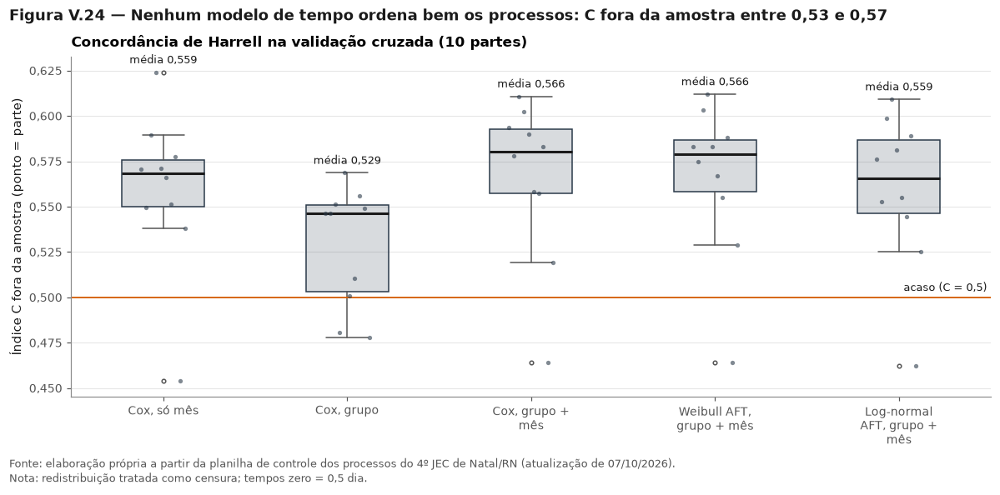

In [144]:
df_s = mul[['T_pos', 'E', 'presencial', 'remota', 'mes_num']].reset_index(drop=True)
MODELOS = {
    'Cox, só mês': (CoxPHFitter, ['mes_num']),
    'Cox, grupo': (CoxPHFitter, ['presencial', 'remota']),
    'Cox, grupo + mês': (CoxPHFitter, ['presencial', 'remota', 'mes_num']),
    'Weibull AFT, grupo + mês': (WeibullAFTFitter, ['presencial', 'remota', 'mes_num']),
    'Log-normal AFT, grupo + mês': (LogNormalAFTFitter, ['presencial', 'remota', 'mes_num']),
}
# (i) concordância por k_fold_cross_validation do lifelines
conc_cv = {}
for nome, (Fit, cols) in MODELOS.items():
    conc_cv[nome] = k_fold_cross_validation(Fit(), df_s[['T_pos', 'E'] + cols], 'T_pos', 'E', k=10,
                                            scoring_method='concordance_index', seed=SEMENTE)
# na amostra toda
conc_in = {}
for nome, (Fit, cols) in MODELOS.items():
    f = Fit().fit(df_s[['T_pos', 'E'] + cols], 'T_pos', 'E')
    conc_in[nome] = f.concordance_index_
tab_conc = pd.DataFrame({'C na amostra': conc_in, 'C validação cruzada (média)': {k: np.mean(v) for k, v in conc_cv.items()},
                         'DP entre as 10 partes': {k: np.std(v, ddof=1) for k, v in conc_cv.items()}}).rename_axis('Modelo')
tabela(tab_conc, 'mul_concordancia', 'Índice de concordância de Harrell (C) dos modelos de tempo, na amostra e fora dela',
       secao='5.5', casas=3, nota='C = 0,5: ordenação ao acaso; 1: ordenação perfeita. Validação cruzada em 10 partes, mesma partição para todos.')
mul_res['conc_cv'] = {k: np.mean(v) for k, v in conc_cv.items()}

fig, ax = plt.subplots(figsize=(11, 4.8))
bp = ax.boxplot(list(conc_cv.values()), positions=range(len(conc_cv)), widths=0.45, patch_artist=True,
                medianprops=dict(color=TINTA, lw=2), whiskerprops=dict(color=TINTA_2), capprops=dict(color=TINTA_2),
                flierprops=dict(marker='o', ms=3, mfc='none', mec=TINTA_2))
for caixa in bp['boxes']:
    caixa.set_facecolor(mpl.colors.to_rgba(COR_MODELO, 0.18)); caixa.set_edgecolor(COR_MODELO)
for k, v in enumerate(conc_cv.values()):
    ax.scatter(np.full(len(v), k) + np.linspace(-0.12, 0.12, len(v)), v, s=12, color=COR_MODELO, alpha=0.6, zorder=3, lw=0)
    ax.annotate(f'média {fmt_br(np.mean(v), 3)}', (k, max(v)), xytext=(0, 5), textcoords='offset points', ha='center',
                va='bottom', fontsize=8.5, color=TINTA)
ax.set_xticks(range(len(conc_cv)), [quebra(k, 14) for k in conc_cv])
ax.axhline(0.5, color=COR_VIES, lw=1.2)
ax.annotate('acaso (C = 0,5)', (1, 0.5), xycoords=('axes fraction', 'data'), xytext=(-3, 3), textcoords='offset points',
            ha='right', va='bottom', fontsize=8.5, color=TINTA)
ax.grid(axis='x', visible=False)
ax.set(ylabel='Índice C fora da amostra (ponto = parte)', title='Concordância de Harrell na validação cruzada (10 partes)')
figura(fig, 'mul_concordancia', 'Nenhum modelo de tempo ordena bem os processos: C fora da amostra entre '
       f'{fmt_br(min(mul_res["conc_cv"].values()), 2)} e {fmt_br(max(mul_res["conc_cv"].values()), 2)}', secao='5.5',
       nota='redistribuição tratada como censura; tempos zero = 0,5 dia.')

**Interpretação.** O índice de concordância fora da amostra é **baixo em todos os modelos**: 0,566 para o Cox com grupo + mês e para o Weibull AFT, 0,559 para o log-normal AFT e para o Cox só com mês, e **0,529 para o Cox só com grupo**. A dispersão entre partes (DP ≈ 0,04) é maior que as diferenças entre modelos, que portanto **não se distinguem**. A concordância na amostra é igual à de validação (0,564 contra 0,566), sinal de que, com tão poucos parâmetros, não há sobreajuste. A comparação mais importante é a do Cox "só mês" (0,559) com o "só grupo" (0,529): o **calendário ordena melhor** os tempos que o rito, mas nenhum dos dois chega perto do que se considera útil para previsão individual (em geral, C ≥ 0,7). Um C de 0,53 para o grupo é compatível com o efeito pequeno (e não significativo) do rito sobre o tempo encontrado na Parte IV.

Modelo,"IBS [1, 64] (938)","DP [1, 64] (938)","Ganho sobre o nulo [1, 64] (938) (%)","IBS [1, 120] (688)","DP [1, 120] (688)","Ganho sobre o nulo [1, 120] (688) (%)"
Nulo (KM),"0,1605","0,0240","0,0","0,2002","0,0148","0,0"
"Cox, só mês","0,1597","0,0236","0,5","0,1982","0,0129","1,0"
"Cox, grupo","0,1609","0,0236","-0,2","0,2002","0,0138","0,0"
"Cox, grupo + mês","0,1601","0,0232","0,3","0,1983","0,0117","1,0"
"Weibull AFT, grupo + mês","0,1681","0,0181","-4,7","0,2060","0,0078","-2,9"
"Log-normal AFT, grupo + mês","0,1817","0,0134","-13,2","0,2161","0,0070","-7,9"


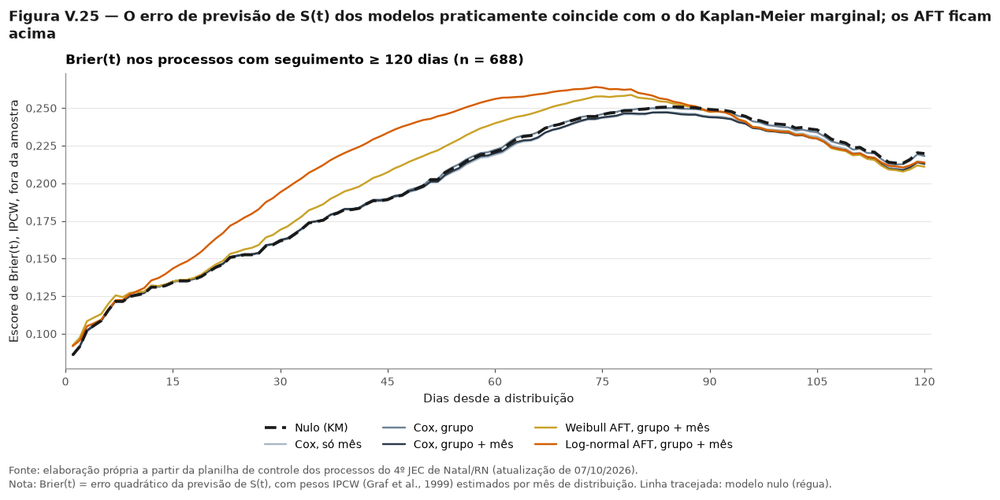

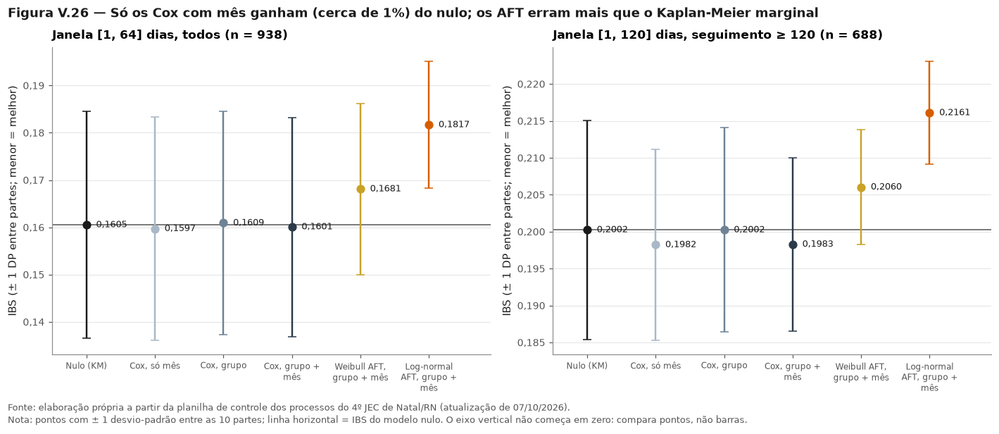

In [145]:
GRADE_T = np.arange(1, 121)
JANELAS = {'IBS [1, 64], todos': (64, None), 'IBS [1, 120], seguimento ≥ 120': (120, 120)}

def brier_ipcw(T, E, S_pred, T_tr, E_tr, est_te, est_tr, grade):
    """Brier(t) com IPCW (Graf et al., 1999), com G estimado por estrato de mês. S_pred: (n_teste × len(grade))."""
    G_t = np.zeros((len(T), len(grade)))
    G_Ti = np.zeros(len(T))
    for e in np.unique(est_te):
        kmG = KaplanMeierFitter().fit(T_tr[est_tr == e], 1 - E_tr[est_tr == e])
        i = est_te == e
        G_t[i] = kmG.survival_function_at_times(grade).values
        G_Ti[i] = kmG.survival_function_at_times(np.maximum(T[i] - 1e-6, 0)).values
    G_t, G_Ti = np.clip(G_t, 0.05, 1), np.clip(G_Ti, 0.05, 1)
    bs = np.zeros(len(grade))
    for j, t in enumerate(grade):
        evento_antes = (T <= t) & (E == 1)
        vivo = T > t
        bs[j] = np.mean(np.where(evento_antes, S_pred[:, j] ** 2 / G_Ti, 0) + np.where(vivo, (1 - S_pred[:, j]) ** 2 / G_t[:, j], 0))
    return bs

fu_s = mul['followup_f'].reset_index(drop=True).values
kf = KFold(10, shuffle=True, random_state=SEMENTE)
NOMES_PRED = ['Nulo (KM)'] + list(MODELOS)
bs_curvas = {jan: {nome: [] for nome in NOMES_PRED} for jan in JANELAS}
s90_oof = {nome: np.full(len(df_s), np.nan) for nome in ['Cox, grupo + mês', 'Log-normal AFT, grupo + mês']}
for tr, te in kf.split(df_s):
    d_tr, d_te = df_s.iloc[tr], df_s.iloc[te]
    T_te, E_te = d_te['T_pos'].values, d_te['E'].values
    est_tr, est_te = np.minimum(d_tr['mes_num'].values, 7), np.minimum(d_te['mes_num'].values, 7)   # ago unido a jul
    km = KaplanMeierFitter().fit(d_tr['T_pos'], d_tr['E'])
    previsoes = {'Nulo (KM)': np.tile(km.survival_function_at_times(GRADE_T).values, (len(te), 1))}
    for nome, (Fit, cols) in MODELOS.items():
        f = Fit().fit(d_tr[['T_pos', 'E'] + cols], 'T_pos', 'E')
        previsoes[nome] = f.predict_survival_function(d_te[cols], times=GRADE_T).values.T
        if nome in s90_oof:
            s90_oof[nome][te] = f.predict_survival_function(d_te[cols], times=[90]).values.ravel()
    for jan, (tau, fu_min) in JANELAS.items():
        m = np.ones(len(te), bool) if fu_min is None else fu_s[te] >= fu_min
        for nome, Sp in previsoes.items():
            bs_curvas[jan][nome].append(brier_ipcw(T_te[m], E_te[m], Sp[m, :tau], d_tr['T_pos'].values, d_tr['E'].values,
                                                   est_te[m], est_tr, GRADE_T[:tau]))
integra = lambda c, tau: np.trapezoid(c, GRADE_T[:tau]) / (tau - 1)
ibs, ibs_dp, bs_medio = {}, {}, {}
for jan, (tau, _) in JANELAS.items():
    bs_medio[jan] = {k: np.mean(v, axis=0) for k, v in bs_curvas[jan].items()}
    ibs[jan] = {k: integra(v, tau) for k, v in bs_medio[jan].items()}
    ibs_dp[jan] = {k: np.std([integra(c, tau) for c in v], ddof=1) for k, v in bs_curvas[jan].items()}
mul_res['ibs'] = ibs
tab_ibs = pd.DataFrame(index=NOMES_PRED).rename_axis('Modelo')
for jan, rot in zip(JANELAS, ['[1, 64] (938)', '[1, 120] (688)']):
    tab_ibs[f'IBS {rot}'] = pd.Series(ibs[jan])
    tab_ibs[f'DP {rot}'] = pd.Series(ibs_dp[jan])
    tab_ibs[f'Ganho sobre o nulo {rot} (%)'] = pd.Series({k: 100 * (1 - v / ibs[jan]['Nulo (KM)']) for k, v in ibs[jan].items()})
tabela(tab_ibs, 'mul_brier', 'Escore de Brier integrado (IBS, IPCW) fora da amostra, em duas janelas identificáveis',
       secao='5.5', casas=4, nota='menor = melhor; ganho > 0 = melhor que o Kaplan-Meier marginal (nulo). Entre colchetes, '
                                  'a janela em dias; entre parênteses, os processos avaliados. DP entre as 10 partes.')

PAL_MOD = {'Nulo (KM)': TINTA, 'Cox, só mês': '#A9B8C6', 'Cox, grupo': '#6E8396', 'Cox, grupo + mês': COR_MODELO,
           'Weibull AFT, grupo + mês': '#C9A227', 'Log-normal AFT, grupo + mês': COR_VIES}
jan2 = 'IBS [1, 120], seguimento ≥ 120'
fig, ax = plt.subplots(figsize=(11, 5))
for k, v in bs_medio[jan2].items():
    ax.plot(GRADE_T, v, label=k, color=PAL_MOD[k], lw=2.4 if k == 'Nulo (KM)' else 1.6,
            ls=(0, (4, 2)) if k == 'Nulo (KM)' else '-', zorder=4 if k == 'Nulo (KM)' else 3)
ax.set(xlabel=ROTULOS['dias'], ylabel='Escore de Brier(t), IPCW, fora da amostra',
       title='Brier(t) nos processos com seguimento ≥ 120 dias (n = 688)', xlim=(0, 121))
ax.set_xticks(np.arange(0, 121, 15))
legenda_abaixo(ax, ncol=3, dy=-0.15)
figura(fig, 'mul_brier_t', 'O erro de previsão de S(t) dos modelos praticamente coincide com o do Kaplan-Meier marginal; '
       'os AFT ficam acima', secao='5.5', nota='Brier(t) = erro quadrático da previsão de S(t), com pesos IPCW (Graf et al., 1999) '
                                            'estimados por mês de distribuição. Linha tracejada: modelo nulo (régua).')

fig, eixos = plt.subplots(1, 2, figsize=(13, 5))
titulos_jan = {'IBS [1, 64], todos': 'Janela [1, 64] dias, todos (n = 938)',
               'IBS [1, 120], seguimento ≥ 120': 'Janela [1, 120] dias, seguimento ≥ 120 (n = 688)'}
for ax, jan in zip(eixos, JANELAS):
    v = ibs[jan]
    nomes_m = list(v)
    mul_forest(ax, [v[k] for k in nomes_m], [v[k] - ibs_dp[jan][k] for k in nomes_m],
               [v[k] + ibs_dp[jan][k] for k in nomes_m], cor=[PAL_MOD[k] for k in nomes_m],
               textos=[fmt_br(v[k], 4) for k in nomes_m])
    ax.axhline(v['Nulo (KM)'], color=TINTA_2, lw=1, zorder=1)
    ax.set_xticks(range(len(v)), [quebra(k, 12) for k in nomes_m], fontsize=8)
    ax.set_xlim(-0.5, len(v) - 0.1)
    ax.set(ylabel='IBS (± 1 DP entre partes; menor = melhor)', title=titulos_jan.get(jan, jan))
figura(fig, 'mul_brier_ibs', 'Só os Cox com mês ganham (cerca de 1%) do nulo; os AFT erram mais que o Kaplan-Meier marginal',
       secao='5.5', nota='pontos com ± 1 desvio-padrão entre as 10 partes; linha horizontal = IBS do modelo nulo. '
                         'O eixo vertical não começa em zero: compara pontos, não barras.')

**Interpretação.** O escore de Brier integrado confirma e refina a leitura da concordância:

- na janela **[1, 120] dias** (688 processos com seguimento ≥ 120), o Cox com grupo + mês (0,1983) e o Cox só com mês (0,1982) melhoram o Kaplan-Meier nulo (0,2002) em apenas **1,0%**. O Cox só com grupo empata com o nulo (0,0%). Na janela **[1, 64]** (todos os 938), os ganhos são ainda menores (0,3% a 0,5%);
- os **AFT paramétricos são piores que o nulo**: Weibull −2,9% e log-normal −7,9% em [1, 120] (−4,7% e −13,2% em [1, 64]). Eles ordenam os processos tão bem quanto o Cox (mesmo C), mas suas **curvas de sobrevivência têm a forma errada**. A distribuição empírica tem muita massa de sentenças nos primeiros dias (desistências, incompetência, 39 tempos zero) e depois um bloco entre 60 e 120 dias, o que nenhuma família de dois parâmetros reproduz bem. O Cox, que deixa o risco basal livre, não sofre desse problema.

O IBS só é calculado em janelas em que todos os processos avaliados foram acompanhados durante todo o intervalo. Com um Ĝ marginal e integração até 180 dias, todos os modelos pareceriam piores que o nulo, um artefato da censura administrativa dependente do mês. Por isso se usam Ĝ por mês e janelas identificáveis.

### 5.5.1 Calibração de Ŝ(90)

Cada processo recebeu, fora da amostra, a probabilidade prevista de **continuar sem sentença aos 90 dias**. Agrupam-se as previsões em quintis (empates fazem alguns quintis coincidirem) e compara-se a média prevista com o Kaplan-Meier observado em cada quintil, com IC 95%. Calibração perfeita: pontos sobre a diagonal.

Cox, grupo + mês: amplitude das previsões Ŝ(90) = 0,319 a 0,644; erro absoluto médio de calibração = 0,024
Log-normal AFT, grupo + mês: amplitude das previsões Ŝ(90) = 0,271 a 0,641; erro absoluto médio de calibração = 0,059


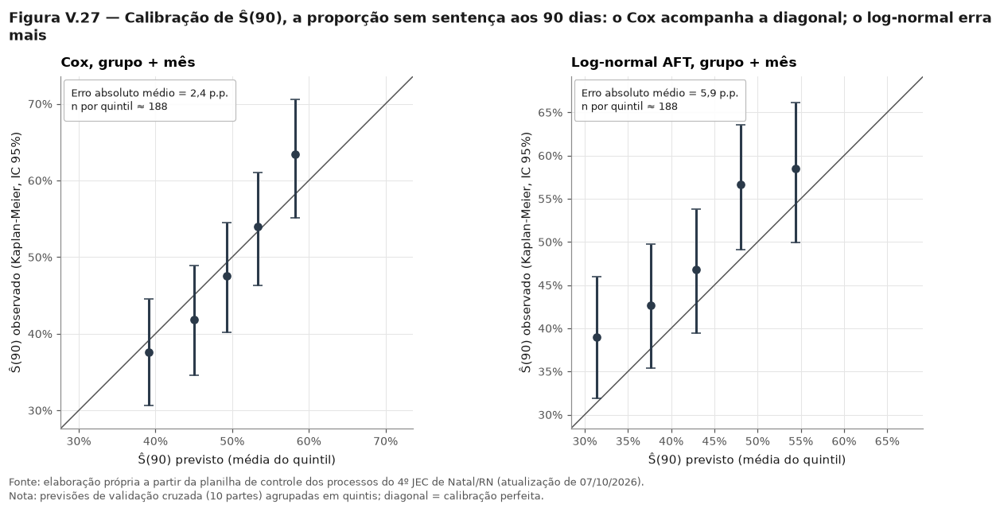

In [146]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 5))
calib = {}
for ax, (nome, s90) in zip(eixos, s90_oof.items()):
    q = pd.qcut(pd.Series(s90).rank(method='first'), 5, labels=False)
    lin = []
    for b in range(5):
        idx = np.where(q == b)[0]
        km = KaplanMeierFitter().fit(df_s['T_pos'].iloc[idx], df_s['E'].iloc[idx])
        obs = km.survival_function_at_times(90).iloc[0]
        ic = km.confidence_interval_survival_function_
        ic_at = ic[ic.index <= 90].iloc[-1]
        lin.append({'quintil': b + 1, 'previsto': s90[idx].mean(), 'observado': obs,
                    'li': ic_at.iloc[0], 'ls': ic_at.iloc[1], 'n': len(idx)})
    t = pd.DataFrame(lin)
    calib[nome] = t
    ax.errorbar(t['previsto'], t['observado'], yerr=[t['observado'] - t['li'], t['ls'] - t['observado']], fmt='o', ms=6,
                capsize=4, color=COR_MODELO, zorder=3)
    lo = min(t['li'].min(), t['previsto'].min()) - 0.03
    hi = max(t['ls'].max(), t['previsto'].max()) + 0.03
    ax.plot([lo, hi], [lo, hi], color=TINTA_2, lw=1, zorder=1)
    ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel='Ŝ(90) previsto (média do quintil)',
           ylabel='Ŝ(90) observado (Kaplan-Meier, IC 95%)', title=nome)
    ax.set_aspect('equal'); ax.grid(axis='both', visible=True)
    eixo_pct(ax, 'x'); eixo_pct(ax, 'y')
    anotar_teste(ax, f"Erro absoluto médio = {fmt_br(100 * np.mean(np.abs(t['previsto'] - t['observado'])), 1)} p.p.\n"
                     f"n por quintil ≈ {fmt_br(t['n'].mean(), 0)}", loc='upper left')
    print(f"{nome}: amplitude das previsões Ŝ(90) = {fmt_br(s90.min(), 3)} a {fmt_br(s90.max(), 3)}; "
          f"erro absoluto médio de calibração = {fmt_br(np.mean(np.abs(t['previsto'] - t['observado'])), 3)}")
mul_res['calib'] = calib
figura(fig, 'mul_calib_s90', 'Calibração de Ŝ(90), a proporção sem sentença aos 90 dias: o Cox acompanha a diagonal; '
       'o log-normal erra mais', secao='5.5.1',
       nota='previsões de validação cruzada (10 partes) agrupadas em quintis; diagonal = calibração perfeita.')

**Interpretação.** O Cox com grupo + mês é **bem calibrado** para Ŝ(90): os cinco quintis ficam sobre a diagonal, com erro absoluto médio de 0,024, e todos os IC cruzam a diagonal. O log-normal AFT **subestima sistematicamente** a probabilidade de continuar sem sentença aos 90 dias (pontos acima da diagonal; erro médio de 0,059), isto é, prevê mais sentenças até 90 dias do que ocorrem, coerente com a forma inadequada vista no Brier. As previsões do Cox variam de 0,32 a 0,64, e essa amplitude vem quase toda do mês. O modelo informa bem a **média** de cada combinação grupo × mês, mas não ordena os processos dentro dela.

**Conclusão de 5.5.** Entre os modelos que tratam a censura, o **Cox com grupo + mês** é o que melhor **descreve** os dados (concordância máxima, melhor Brier, melhor calibração) e é o modelo de referência para a estimativa dos efeitos do rito (Parte IV). O Weibull AFT é uma alternativa aceitável para comunicar razões de tempos, com pior calibração, e o log-normal deve ser evitado para previsão. O poder preditivo de **todos** é baixo (C ≈ 0,57; ganho de Brier ≈ 1%), e isso não é falha de especificação: o banco não tem covariáveis do caso, e o experimento foi desenhado para uma **comparação causal entre grupos**, que o sorteio torna válida sem precisar explicar a variabilidade individual.

## 5.6 Síntese da Parte V

A tabela reúne os modelos ajustados, a métrica de desempenho de cada um e o que dizem sobre a pergunta de pesquisa. Os números são lidos diretamente dos resultados acima.

In [147]:
cA = mul_res['contA'].set_index('Contraste')
rrr_t = mul_res['mnl'][0].set_index(['Equação', 'Termo'])
sint = pd.DataFrame([
    {'Seção': '5.1', 'Modelo': 'OLS tempo ~ grupo + mês (sentenciados)', 'Desempenho': f"R² = {fmt_br(mul_res['ols_r2'], 3)}",
     'Leitura': 'inadequado: ignora censura, resíduos não normais e heterocedásticos'},
    {'Seção': '5.2.1', 'Modelo': 'Logit acordo ~ grupo + mês (encerrados)',
     'Desempenho': f"AUC VC = {fmt_br(mul_res['aucA'][2], 3)}; McFadden = {fmt_br(mul_res['A']['mcfadden'], 3)}",
     'Leitura': f"Remota × Controle RC = {fmt_br(cA.loc['Remota vs Controle', 'RC'], 2)} (p Holm {p_br(cA.loc['Remota vs Controle', 'p Holm'])}); TRV grupo p {p_br(mul_res['A']['trv_p'])}"},
    {'Seção': '5.2.6', 'Modelo': 'Logit acordo na AC ~ modalidade + híbrida + mês',
     'Desempenho': f"AUC = {fmt_br(mul_res['AC'][1], 3)} (na amostra)",
     'Leitura': f"TRV p {p_br(mul_res['AC'][0]['res'].llr_pvalue)}; 17 eventos, exploratório"},
    {'Seção': '5.2.7', 'Modelo': 'MNLogit tipo de sentença ~ grupo + mês',
     'Desempenho': f"McFadden = {fmt_br(mul_res['mnl'][3], 3)}",
     'Leitura': f"TRV grupo p {p_br(mul_res['mnl'][2])}; sem mérito vs mérito: RRR Presencial {fmt_br(rrr_t.loc[('Sem mérito vs Mérito', 'Presencial vs Controle'), 'RRR'], 2)}, Remota {fmt_br(rrr_t.loc[('Sem mérito vs Mérito', 'Remota vs Controle'), 'RRR'], 2)}"},
    {'Seção': '5.3.1', 'Modelo': 'Árvore tipo de sentença (basais)',
     'Desempenho': f"acurácia balanceada VC = {pct_br(mul_res['arvA'][2])} (trivial 33,3%)", 'Leitura': f"{mul_res['arvA'][0]} folhas"},
    {'Seção': '5.3.2', 'Modelo': 'Árvore tipo de sentença (tratados, com AC realizada)',
     'Desempenho': f"acurácia balanceada VC = {pct_br(mul_res['arvB'][2])}", 'Leitura': f"{mul_res['arvB'][0]} folhas; AC realizada é a variável dominante (associação, não causa)"},
    {'Seção': '5.3.4', 'Modelo': 'Árvore de sobrevivência (martingal)',
     'Desempenho': f"R² VC ≈ {fmt_br(mul_res['arvS'][1], 3)}", 'Leitura': f"{mul_res['arvS'][0]} folhas"},
    {'Seção': '5.4', 'Modelo': 'AC grupo × desfecho', 'Desempenho': f"dim. 1 = {pct_br(mul_res['ca'][0][0])} da inércia",
     'Leitura': f"χ² p {p_br(mul_res['ca'][2])}"},
    {'Seção': '5.5', 'Modelo': 'Cox grupo + mês', 'Desempenho': f"C VC = {fmt_br(mul_res['conc_cv']['Cox, grupo + mês'], 3)}; IBS[1,120] = {fmt_br(mul_res['ibs']['IBS [1, 120], seguimento ≥ 120']['Cox, grupo + mês'], 4)} (nulo {fmt_br(mul_res['ibs']['IBS [1, 120], seguimento ≥ 120']['Nulo (KM)'], 4)})",
     'Leitura': 'melhor descrição do efeito de grupo com censura; previsão individual fraca'},
    {'Seção': '5.5', 'Modelo': 'Log-normal AFT grupo + mês', 'Desempenho': f"C VC = {fmt_br(mul_res['conc_cv']['Log-normal AFT, grupo + mês'], 3)}; IBS[1,120] = {fmt_br(mul_res['ibs']['IBS [1, 120], seguimento ≥ 120']['Log-normal AFT, grupo + mês'], 4)}",
     'Leitura': 'mesma ordenação que o Cox, mas forma de S(t) errada: Brier pior que o nulo e Ŝ(90) mal calibrado'},
])
tabela(sint, 'mul_sintese', 'Síntese dos modelos da Parte V: desempenho e o que dizem sobre a pergunta de pesquisa',
       secao='5.6', nota='AUC = área sob a curva ROC; VC = validação cruzada; C = índice de concordância de Harrell; '
                         'IBS = escore de Brier integrado (menor = melhor).')

Seção,Modelo,Desempenho,Leitura
5.1,OLS tempo ~ grupo + mês (sentenciados),"R² = 0,024","inadequado: ignora censura, resíduos não normais e heterocedásticos"
5.2.1,Logit acordo ~ grupo + mês (encerrados),"AUC VC = 0,546; McFadden = 0,015","Remota × Controle RC = 2,15 (p Holm 0,027); TRV grupo p 0,027"
5.2.6,Logit acordo na AC ~ modalidade + híbrida + mês,"AUC = 0,618 (na amostra)","TRV p 0,475; 17 eventos, exploratório"
5.2.7,MNLogit tipo de sentença ~ grupo + mês,"McFadden = 0,028","TRV grupo p < 0,001; sem mérito vs mérito: RRR Presencial 2,37, Remota 2,46"
5.3.1,Árvore tipo de sentença (basais),"acurácia balanceada VC = 38,5% (trivial 33,3%)",7 folhas
5.3.2,"Árvore tipo de sentença (tratados, com AC realizada)","acurácia balanceada VC = 57,1%","2 folhas; AC realizada é a variável dominante (associação, não causa)"
5.3.4,Árvore de sobrevivência (martingal),"R² VC ≈ -0,010",1 folhas
5.4,AC grupo × desfecho,"dim. 1 = 94,7% da inércia","χ² p < 0,001"
5.5,Cox grupo + mês,"C VC = 0,566; IBS[1,120] = 0,1983 (nulo 0,2002)",melhor descrição do efeito de grupo com censura; previsão individual fraca
5.5,Log-normal AFT grupo + mês,"C VC = 0,559; IBS[1,120] = 0,2161","mesma ordenação que o Cox, mas forma de S(t) errada: Brier pior que o nulo e Ŝ(90) mal calibrado"


**O que a Parte V acrescenta.**

1. **A regressão linear sobre o tempo é inadequada** (5.1). Ela inverte o efeito do mês e muda a direção do efeito do rito. Com censura, a regressão deve ser feita com Cox ou AFT; o AFT log-normal mostrou um **aumento de ~20% no tempo típico por mês de distribuição** (acúmulo de acervo), invisível nas análises que ignoram a censura.
2. **Acordo**: a audiência **remota** obrigatória associa-se a cerca do **dobro da chance de acordo** em relação ao rito atual (RC = 2,15 entre os encerrados; RC = 2,70 até 120 dias, sem viés de seguimento; p Holm ≤ 0,03). A Presencial fica entre a Remota e o Controle, sem diferença significativa. A vantagem não está no acordo **na** audiência (cerca de 5% nas duas modalidades), e sim nos acordos posteriores.
3. **Tipo de sentença**: é o efeito mais forte e robusto. Os ritos com audiência obrigatória têm cerca de 2,4 vezes a chance de sentença **sem mérito** em vez de mérito, e a Remota tem cerca de 3 vezes a de **homologação**. Nos tratados, quase toda extinção sem mérito ocorre quando a audiência **não se realizou** (83%), o que é compatível com o art. 51, I, da Lei 9.099/1995, sob a cautela de causalidade reversa.
4. **Previsão**: todos os modelos, de classificação ou de tempo, têm poder preditivo individual **baixo** (AUC ≈ 0,55 fora da amostra; C ≈ 0,57; ganho de Brier ≈ 1%), e as árvores não acham partições estáveis. Entre os modelos de tempo, o **Cox com grupo + mês** descreve e prevê melhor; os AFT paramétricos têm a forma de S(t) errada.

**Recomendações de variáveis a coletar numa replicação (questão 2.9).** A modelagem multivariada útil exige covariáveis **basais do caso**, registradas na distribuição, antes do sorteio:

| Variável | Escala | Uso esperado |
|---|---|---|
| Valor da causa (R$) | razão (contínua) | covariável no Cox/AFT; correlação com o tempo via Cox com covariável contínua ou Spearman/Kendall restritos a horizonte fixo |
| Número de autores e de réus | discreta (contagem) | covariável; complexidade do litígio |
| Tipo de ação / assunto (TPU-CNJ) | nominal | estrato no Cox; heterogeneidade do efeito do rito |
| Réu pessoa jurídica / litigante habitual (banco, telefonia, varejo) | binária ou nominal | o principal preditor conhecido de acordo em JEC; efeito aleatório por litigante |
| Advogado constituído × *jus postulandi* (cada polo) | binária | ausência do autor, acordo e extinção |
| Pedido de tutela de urgência | binária | tramitação prioritária |
| Datas intermediárias: citação, designação e realização da AC, contestação, conclusão para sentença | datas | decomposição do tempo em etapas (modelos multiestado) e covariáveis dependentes do tempo, sem viés de tempo imortal |
| Motivo da não realização da AC e fundamento da sentença sem mérito (art. 51, I; art. 485 CPC) | nominal | testar diretamente o mecanismo da extinção por ausência |
| Número de atos da serventia e do juiz | contagem | medir carga de trabalho; cuidado, porque cresce com o tempo de tramitação (é mediador e consequência, não covariável basal) |

Com variáveis quantitativas desse tipo, a correlação com a duração **não** deve ser medida por Pearson ou Spearman sobre tempos censurados. O adequado é um **Cox com a covariável contínua** (teste de Wald ou TRV; HR por unidade) ou, para associação de postos, o índice de concordância de Harrell. As covariáveis basais também aumentariam a **precisão** das estimativas dos efeitos do rito (ajuste por covariáveis prognósticas num ensaio aleatorizado) e permitiriam verificar o balanceamento do sorteio, o que hoje só é possível para o mês.

# PARTE VI — RESPOSTAS ÀS QUESTÕES DO PROFESSOR (2.2 A 2.12)

Esta parte responde, uma a uma, às questões 2.2 a 2.12 do roteiro `estudo_de_caso_n_2.md`. Cada resposta (i) resume o enunciado; (ii) argumenta com base nas evidências produzidas nas Partes I a V, às quais remete pela numeração das seções; e (iii) quando útil, traz um quadro ou uma figura próprios. Os poucos cálculos feitos aqui (fluxo dos processos, equilíbrio das variáveis basais, contraste entre medianas ingênuas e de Kaplan-Meier) são **de apoio**: não substituem nem refazem as análises das partes anteriores.

| Questão | Tema | Seção | Evidência principal |
|---|---|---|---|
| 2.2 | EO ou ECA? | 6.1 | 1.10, 1.12, 2.5.1, 3.5 |
| 2.3 | Amostras independentes de uma mesma população? | 6.2 | 2.5.1, 3.5.1, 3.5.3 |
| 2.4 | "Híbrida" e "Decisão" | 6.3 | 1.11, 1.12, 3.2.4, 3.3.4, 4.7, 4.9 |
| 2.5 | Populações e cruzamento com os 14 JECs (DataJud) | 6.4 | Parte VIII |
| 2.6 | Tratamento dos dados brutos | 6.5 | Parte I inteira |
| 2.7 | Matriz de correlações; ordem de chegada × duração | 6.6 | 2.6.4, 2.6.5, 3.5.2, 4.5 |
| 2.8 | Variáveis de confundimento | 6.7 | 3.5.3, 4.3.4, 4.9 |
| 2.9 | Outras variáveis em escala intervalar | 6.8 | 5 (limitação), 2.6.4 |
| 2.10 | Validade interna e externa; generalização | 6.9 | Partes III a V |
| 2.11 | Adequação dos TSHN do professor | 6.10 | 3.4, 3.6, Parte IV |
| 2.12 | Avaliação geral e sugestões | 6.11 | todas; Parte VII |

In [148]:
if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')
from matplotlib.patches import FancyBboxPatch
from scipy.stats import chi2_contingency

q6 = dados.copy()
q6['grupo'] = pd.Categorical(q6['grupo'].astype(str), categories=ORDEM_GRUPO)
q6['desfecho'] = q6['tipo_desfecho'].astype(str)
q6['acr'] = q6['ac_realizada'].astype(object)
n_grupo = q6['grupo'].value_counts().reindex(ORDEM_GRUPO)
todas_q6 = pd.read_pickle(PROC / 'ed2_todas_linhas.pkl')
RNG_Q6 = np.random.default_rng(SEMENTE)


def q6_csv(nome, pasta='tab'):
    """Lê um CSV exportado pelas Partes II–V (';' e vírgula decimal); None se ainda não existir."""
    caminho = RAIZ / pasta / nome
    if not caminho.exists():
        print(f'Aviso: {pasta}/{nome} não encontrado (é gerado pelas Partes II a V).')
        return None
    return pd.read_csv(caminho, sep=';', decimal=',', encoding='utf-8-sig')


def q6_chi2_perm(tab, n_perm=20000, rng=RNG_Q6):
    """χ² de independência com valor-p por permutação (tabelas com esperadas pequenas)."""
    tab = np.asarray(tab)
    chi2_obs, p_ass, gl, esp = chi2_contingency(tab, correction=False)
    linhas = np.repeat(np.arange(tab.shape[0]), tab.sum(axis=1))
    colunas = np.repeat(np.arange(tab.shape[1]), tab.sum(axis=0))
    maiores = 0
    for _ in range(n_perm):
        perm = rng.permutation(colunas)
        t = np.zeros_like(tab)
        np.add.at(t, (linhas, perm), 1)
        maiores += chi2_contingency(t, correction=False)[0] >= chi2_obs - 1e-12
    v = np.sqrt(chi2_obs / (tab.sum() * (min(tab.shape) - 1)))
    return chi2_obs, gl, p_ass, (maiores + 1) / (n_perm + 1), esp.min(), v

print(f'Base primária: {len(q6)} processos; linhas brutas: {len(todas_q6)}; '
      f'grupos: ' + ', '.join(f'{g} {n_grupo[g]}' for g in ORDEM_GRUPO))

Base primária: 938 processos; linhas brutas: 944; grupos: Controle 313, Presencial 314, Remota 311


## 6.1 Questão 2.2 — Estudo observacional (EO) ou ensaio controlado aleatorizado (ECA)?

**Enunciado.** Trata-se de um EO ou de um ECA? Qual a diferença entre eles?

**A diferença.** O critério que separa os dois desenhos é **quem atribui a exposição** e **como**. No **estudo observacional**, o pesquisador apenas registra a exposição que as unidades "escolheram" ou receberam por circunstâncias alheias a ele; a comparação entre expostos e não expostos fica sujeita a **confundimento**, porque os grupos podem diferir em fatores que também afetam o desfecho, e a inferência causal exige controlar esses fatores (por ajuste, pareamento ou estratificação), sempre com o risco de confundidores não medidos. No **experimento** (ensaio controlado aleatorizado), o pesquisador **impõe** o tratamento e o faz **por sorteio**, com um grupo de comparação **contemporâneo**; a aleatorização torna os grupos comparáveis **em expectativa** quanto a todos os fatores anteriores à alocação, medidos ou não, e é isso que autoriza ler a diferença dos desfechos como efeito causal do tratamento (MOORE; NOTZ; FLIGNER, 2023, cap. 9, citados no próprio resumo expandido).

**O caso.** O experimento do 4º JEC é um **ECA**, e não um EO, quanto ao rito: cada processo novo foi alocado pelo pesquisador, por sorteio individual, a um de três ritos (rito atual, AC presencial obrigatória ou AC remota obrigatória), e os três grupos correram em paralelo no mesmo período e na mesma unidade. A Parte III não encontrou sinal de alocação não aleatória: o teste de corridas sobre a ordem de chegada não rejeita a aleatoriedade (seção 3.5.1) e a composição por mês, embora desigual em junho e julho, não difere do acaso ao nível de 5% (seção 3.5.3). Com mais precisão, é um **ECA pragmático, de centro único, aberto (sem cegamento), com aleatorização individual e alocação 1:1:1**, cujo sorteio produziu totais **equilibrados demais** para um sorteio simples (seção 2.5.1), o que indica **sorteio com restrição** (lista balanceada, cotas ou compensação). Isso não descaracteriza a aleatorização, mas exige que o mecanismo seja documentado.

Três ressalvas impedem chamá-lo de ECA "puro" em todos os aspectos:

1. **dentro do ECA há componentes observacionais**: a realização da AC, a audiência "híbrida", o acordo e a ausência das partes ocorrem **depois** do sorteio e dependem de escolhas das partes; comparações por essas variáveis (por exemplo, "processos com AC realizada × sem AC") são observacionais (seções 3.2.3 e 4.8);
2. **a unidade judicial não foi sorteada**: o 4º JEC entrou por conveniência (os outros 13 juízes não aderiram); para a população dos 14 JECs, o estudo é um **estudo de caso único** (um conglomerado), e não um ensaio por conglomerados;
3. **o próprio projeto se classifica de forma incoerente**: o resumo expandido fala em "experimento controlado aleatorizado"; o projeto depositado usa a diretriz TREND, destinada a desenhos **não aleatorizados** ("quase experimental"), e chega a falar em "estudo observacional" (ver `docs/r1_documentos.md`, §5). Pelo critério acima, prevalece a classificação de ECA; a diretriz de relato adequada seria a CONSORT, e não a TREND.

O quadro a seguir resume a comparação; o diagrama de fluxo, no formato CONSORT, mostra o percurso dos 944 registros da planilha até os desfechos observados em 07/10/2026.

In [149]:
quadro_eo = pd.DataFrame([
    ['Quem atribui a exposição', 'a própria unidade, as circunstâncias ou terceiros; o pesquisador só observa',
     'o pesquisador, por sorteio', 'o juiz-pesquisador, por sorteio individual de cada processo novo (Chefe de Gabinete, sorteio.com.br)'],
    ['Grupo de comparação', 'expostos × não expostos, às vezes históricos', 'contemporâneo, formado pelo mesmo sorteio',
     'contemporâneo: rito atual (Controle), sorteado junto com os dois braços de AC'],
    ['Comparabilidade dos grupos', 'não garantida; depende de ajuste por confundidores medidos',
     'garantida em expectativa para todos os fatores anteriores ao sorteio', 'grupos de 313/314/311; mês e dia da semana compatíveis com o acaso (6.2)'],
    ['Inferência causal', 'só sob hipóteses fortes (sem confundidores não medidos)', 'direta para o efeito da alocação (ITT)',
     'válida para o efeito do rito dentro do 4º JEC (intenção de tratar)'],
    ['Variáveis pós-alocação', '—', 'não aleatorizadas: comparações por elas são observacionais',
     'AC realizada, híbrida, acordo e ausência das partes: observacionais'],
    ['Cegamento', 'em geral irrelevante', 'desejável (participantes, avaliadores, analistas)',
     'ausente: o juiz que sorteia também julga e analisa'],
    ['Nível da unidade de política', '—', 'várias unidades sorteadas (ensaio por conglomerados)',
     'uma unidade escolhida por conveniência (N = 1 conglomerado)'],
    ['Diretriz de relato', 'STROBE', 'CONSORT', 'CONSORT (o projeto cita TREND, própria de desenhos não aleatorizados)'],
], columns=['Característica', 'Estudo observacional (EO)', 'Ensaio controlado aleatorizado (ECA)', 'Experimento do 4º JEC'])
tabela(quadro_eo, 'q_eo_eca', 'EO × ECA: o experimento do 4º JEC é um ECA quanto ao rito, com componentes observacionais',
       secao='6.1', fonte='Elaboração própria a partir do projeto de pesquisa, do resumo expandido e das Partes I a III.')

Característica,Estudo observacional (EO),Ensaio controlado aleatorizado (ECA),Experimento do 4º JEC
Quem atribui a exposição,"a própria unidade, as circunstâncias ou terceiros; o pesquisador só observa","o pesquisador, por sorteio","o juiz-pesquisador, por sorteio individual de cada processo novo (Chefe de Gabinete, sorteio.com.br)"
Grupo de comparação,"expostos × não expostos, às vezes históricos","contemporâneo, formado pelo mesmo sorteio","contemporâneo: rito atual (Controle), sorteado junto com os dois braços de AC"
Comparabilidade dos grupos,não garantida; depende de ajuste por confundidores medidos,garantida em expectativa para todos os fatores anteriores ao sorteio,grupos de 313/314/311; mês e dia da semana compatíveis com o acaso (6.2)
Inferência causal,só sob hipóteses fortes (sem confundidores não medidos),direta para o efeito da alocação (ITT),válida para o efeito do rito dentro do 4º JEC (intenção de tratar)
Variáveis pós-alocação,—,não aleatorizadas: comparações por elas são observacionais,"AC realizada, híbrida, acordo e ausência das partes: observacionais"
Cegamento,em geral irrelevante,"desejável (participantes, avaliadores, analistas)",ausente: o juiz que sorteia também julga e analisa
Nível da unidade de política,—,várias unidades sorteadas (ensaio por conglomerados),uma unidade escolhida por conveniência (N = 1 conglomerado)
Diretriz de relato,STROBE,CONSORT,"CONSORT (o projeto cita TREND, própria de desenhos não aleatorizados)"


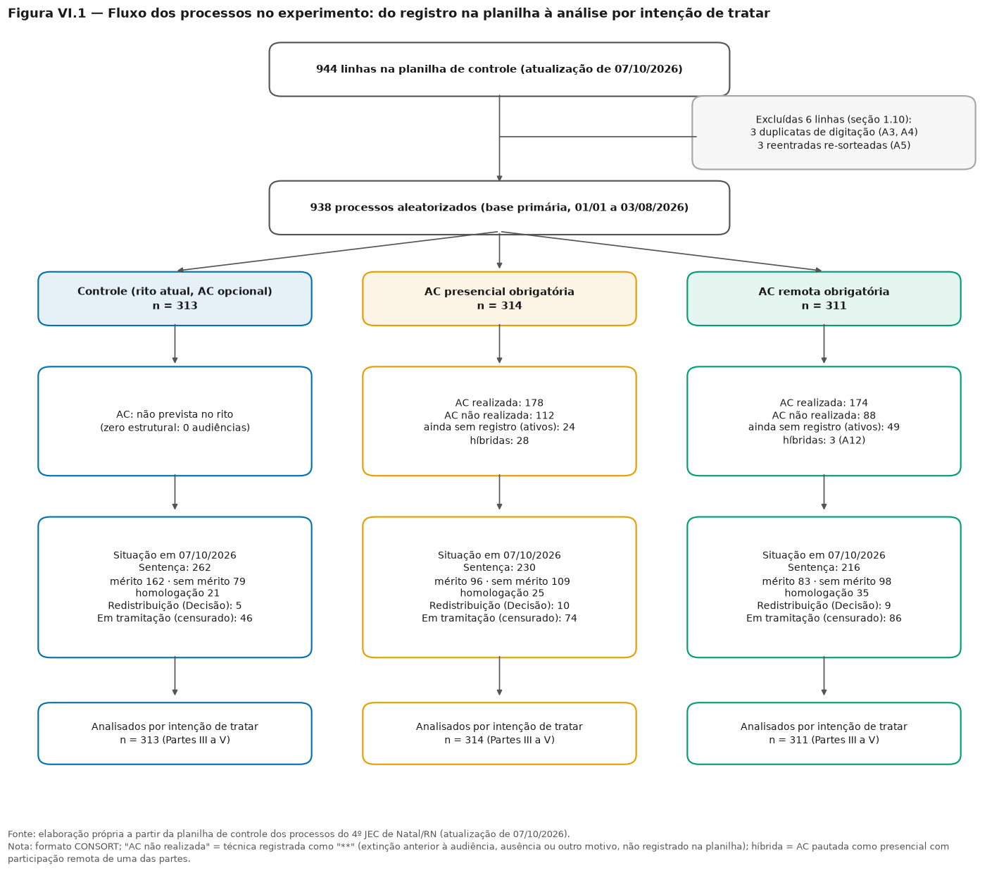

In [150]:
# ---- diagrama de fluxo (CONSORT) com as contagens da base
excl = todas_q6[~todas_q6['base_primaria'].astype(bool)]
n_a3a4 = int(excl['motivo_exclusao'].astype(str).str.startswith(('A3', 'A4')).sum())
n_a5 = int(excl['motivo_exclusao'].astype(str).str.startswith('A5').sum())

def q6_bloco_grupo(g):
    s = q6[q6['grupo'] == g]
    acr = s['acr']
    if g == 'Controle':
        linha_ac = 'AC: não prevista no rito\n(zero estrutural: 0 audiências)'
    else:
        hib = int(s['hibrida'].fillna(False).astype(bool).sum())
        linha_ac = (f'AC realizada: {int((acr == True).sum())}\n'
                    f'AC não realizada: {int((acr == False).sum())}\n'
                    f'ainda sem registro (ativos): {int(acr.isna().sum())}\n'
                    f'híbridas: {hib}' + (' (A12)' if g == 'Remota' else ''))
    cont = s['desfecho'].value_counts()
    sent = int(s['evento'].astype(int).sum())
    linha_desf = (f'Sentença: {sent}\n'
                  f'  mérito {int(cont.get("Mérito", 0))} · sem mérito {int(cont.get("Sem mérito", 0))}\n'
                  f'  homologação {int(cont.get("Homologação", 0))}\n'
                  f'Redistribuição (Decisão): {int(cont.get("Redistribuição", 0))}\n'
                  f'Em tramitação (censurado): {int(cont.get("Ativo", 0))}')
    return linha_ac, linha_desf

fig, ax = plt.subplots(figsize=(13, 10.5))
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis('off')

def caixa(x, y, w, h, texto, cor='#555555', fundo='white', peso='normal', tam=9.5):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle='round,pad=0.4,rounding_size=1.2',
                                fc=fundo, ec=cor, lw=1.4))
    ax.text(x, y, texto, ha='center', va='center', fontsize=tam, color=TINTA, fontweight=peso, linespacing=1.3)

def seta(x0, y0, x1, y1):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', color=TINTA_2, lw=1.1))

caixa(50, 95, 46, 6, f'{len(todas_q6)} linhas na planilha de controle (atualização de 07/10/2026)', peso='bold')
caixa(84, 87, 28, 8.5, f'Excluídas {len(excl)} linhas (seção 1.10):\n{n_a3a4} duplicatas de digitação (A3, A4)\n'
                         f'{n_a5} reentradas re-sorteadas (A5)', cor=CINZA, fundo='#f7f7f7', tam=9)
seta(50, 92, 50, 80.5); ax.plot([50, 70], [86.5, 86.5], color=TINTA_2, lw=1.1)
caixa(50, 77.5, 46, 6, f'{len(q6)} processos aleatorizados (base primária, 01/01 a 03/08/2026)', peso='bold')
xs = {'Controle': 17, 'Presencial': 50, 'Remota': 83}
for g, x in xs.items():
    seta(50, 74.5, x, 69.5)
    caixa(x, 66, 27, 6, f'{ROTULO_GRUPO[g]}\nn = {n_grupo[g]}', cor=CORES_GRUPO[g],
          fundo=mpl.colors.to_rgba(CORES_GRUPO[g], 0.10), peso='bold', tam=9.5)
    l_ac, l_desf = q6_bloco_grupo(g)
    seta(x, 63, x, 57.5)
    caixa(x, 50.5, 27, 13, l_ac, cor=CORES_GRUPO[g], tam=9)
    seta(x, 44, x, 39)
    caixa(x, 29.5, 27, 17, 'Situação em 07/10/2026\n' + l_desf, cor=CORES_GRUPO[g], tam=9)
    seta(x, 21, x, 15.5)
    caixa(x, 11, 27, 7, f'Analisados por intenção de tratar\nn = {n_grupo[g]} (Partes III a V)', cor=CORES_GRUPO[g], tam=9)
figura(fig, 'q_fluxo_consort', 'Fluxo dos processos no experimento: do registro na planilha à análise por intenção de tratar',
       secao='6.1', nota='formato CONSORT; "AC não realizada" = técnica registrada como "**" (extinção anterior à audiência, ausência '
                         'ou outro motivo, não registrado na planilha); '
                         'híbrida = AC pautada como presencial com participação remota de uma das partes.')

**Resposta à questão 2.2.** O diagrama de fluxo mostra o que caracteriza o estudo como **ECA**: os 938 processos da base primária foram repartidos por sorteio em três grupos praticamente iguais (313, 314 e 311), todos acompanhados até a mesma data e todos analisados no grupo sorteado (intenção de tratar), sem perdas. O diagrama mostra também onde o experimento deixa de ser experimento. A partir da segunda linha de caixas, o que acontece depende das partes, e não do sorteio: nos braços com AC, a audiência só foi realizada em 178 de 314 processos (Presencial) e 174 de 311 (Remota); 112 e 88 terminaram sem AC (a técnica ficou registrada como `**`), e 28 audiências presenciais foram híbridas. Comparar "quem teve AC" com "quem não teve" seria, portanto, um estudo observacional embutido no ensaio. Na linha dos desfechos já aparece o achado central: o Controle tem 162 sentenças de mérito e 79 extinções sem mérito; os braços com AC invertem essa proporção (96/109 e 83/98).

Em suma: **ECA** quanto ao rito, porque o pesquisador impôs a exposição por sorteio, com controle contemporâneo; **componentes observacionais** quanto a tudo o que ocorre depois do sorteio; e, quanto à pretensão de avaliar a política nos JECs de Natal, **estudo de caso de uma unidade**. A classificação do próprio projeto como "quase experimental" (TREND) ou "observacional" é imprecisa: o que falta ao experimento não é aleatorização, e sim ocultação da alocação, cegamento e mais de uma unidade.

## 6.2 Questão 2.3 — Os três grupos são amostras independentes de uma mesma população?

**Enunciado.** Decidir, justificadamente, se Controle, AC presencial e AC remota são amostras **independentes** extraídas de uma mesma população, e se isso influi na escolha dos testes.

**Resposta.** Sim, com uma precisão de linguagem e três ressalvas.

*Precisão.* Os grupos não são "amostras extraídas" de uma população por **amostragem probabilística**: são uma **partição aleatória** de um único conjunto, o fluxo de ações distribuídas ao 4º JEC entre 01/01 e 03/08/2026 (praticamente um censo da população disponível; ver 6.4). A "mesma população" é garantida pelo **sorteio**: antes da alocação, cada processo tinha a mesma chance de cair em qualquer grupo, de modo que os três grupos são, em expectativa, idênticos em tudo o que existia antes do sorteio. A base lógica da inferência é, portanto, a **aleatorização** (o que justifica testes de permutação e a interpretação dos testes clássicos como aproximações deles), e não a amostragem de uma população infinita.

*Independência.* Os grupos são **independentes entre si**: cada processo pertence a um só grupo (as reentradas re-sorteadas foram reconduzidas ao primeiro sorteio, A5, seção 1.10), e não há pareamento nem medidas repetidas da mesma unidade em grupos diferentes. A única verificação empírica possível, dado que a planilha não tem covariáveis do processo, é o equilíbrio das variáveis **basais de calendário**: o quadro e a figura abaixo testam mês e dia da semana da distribuição e a origem externa do processo.

*Ressalvas.* (i) **Dependência por agentes comuns**: o mesmo juiz, o mesmo cartório e a **mesma conciliadora em cada braço** atendem todos os processos de um grupo, o que cria correlação intragrupo (agrupamento) que os testes clássicos ignoram e que, no caso da conciliadora, não pode ser corrigida, porque ela coincide com a modalidade (6.7); (ii) **litigantes habituais** (bancos, operadoras) aparecem nos três grupos e podem induzir correlação entre processos, sem que a planilha permita identificá-los; (iii) o **sorteio restrito** (totais fixados ou compensados) cria uma dependência fraca entre as alocações, que torna os testes clássicos levemente conservadores e recomenda estratificar pelo período (seções 2.5.1 e 4.3.4).

*Influência sobre os testes.* Decisiva. Amostras independentes exigem testes para **k amostras independentes**: χ² de independência ou exato de Fisher para proporções; Kruskal-Wallis, Mann-Whitney e Dunn para posições; log-rank e Cox para tempos censurados. Os testes para amostras **dependentes** (McNemar, Wilcoxon pareado, Friedman, Q de Cochran) não se aplicam (seção 3.6.3). Além da independência, a **censura** e a natureza **nominal** de quase todas as variáveis pesam tanto quanto ela: é a censura que desloca a escolha do Kruskal-Wallis para o log-rank (6.10).

In [151]:
# ---- equilíbrio das variáveis basais (as únicas disponíveis antes do sorteio)
q6['mes7'] = q6['mes_distribuicao'].astype(str).replace({'ago': 'jul'})
ordem_mes7 = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul']
ordem_dia = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
variaveis_basais = {
    'Mês de distribuição (jul + ago)': ('mes7', ordem_mes7),
    'Dia da semana da distribuição': ('dia_semana_distribuicao', ordem_dia),
    'Origem externa (redistribuído à vara)': ('origem_ext_txt', ['Não', 'Sim']),
}
q6['origem_ext_txt'] = np.where(q6['origem_externa'].astype(bool), 'Sim', 'Não')
eq_linhas, eq_tabs = [], {}
for rotulo, (col, ordem) in variaveis_basais.items():
    tab_ = pd.crosstab(q6[col].astype(str), q6['grupo']).reindex(index=ordem, columns=ORDEM_GRUPO).fillna(0).astype(int)
    eq_tabs[rotulo] = tab_
    chi2_, gl_, p_ass_, p_perm_, esp_min_, v_ = q6_chi2_perm(tab_.to_numpy())
    eq_linhas.append({'Variável basal': rotulo, 'Categorias': len(ordem), 'χ²': chi2_, 'gl': gl_,
                      'Menor esperada': esp_min_, 'p (assintótico)': p_ass_, 'p (permutação)': p_perm_, 'V de Cramér': v_})
eq_df = pd.DataFrame(eq_linhas)
from statsmodels.stats.multitest import multipletests
eq_df['p Holm'] = multipletests(eq_df['p (permutação)'], method='holm')[1]
tabela(eq_df, 'q_equilibrio_basal', 'Equilíbrio das variáveis basais entre os grupos: nenhuma diferença além do acaso',
       secao='6.2', formatos={'gl': 'int', 'Categorias': 'int', 'Menor esperada': 1, 'χ²': 2, 'V de Cramér': 3},
       destaque='p Holm', nota='H0: distribuição da variável igual nos três grupos; p por permutação (20.000 réplicas); '
                               'Holm sobre as três variáveis. Agosto (6 processos) unido a julho.')

Variável basal,Categorias,χ²,gl,Menor esperada,p (assintótico),p (permutação),V de Cramér,p Holm
Mês de distribuição (jul + ago),7,"18,45",12,"34,2","0,103","0,102","0,099","0,306"
Dia da semana da distribuição,7,"10,44",12,"9,3","0,577","0,577","0,075","0,577"
Origem externa (redistribuído à vara),2,"3,50",2,"4,0","0,174","0,263","0,061","0,525"


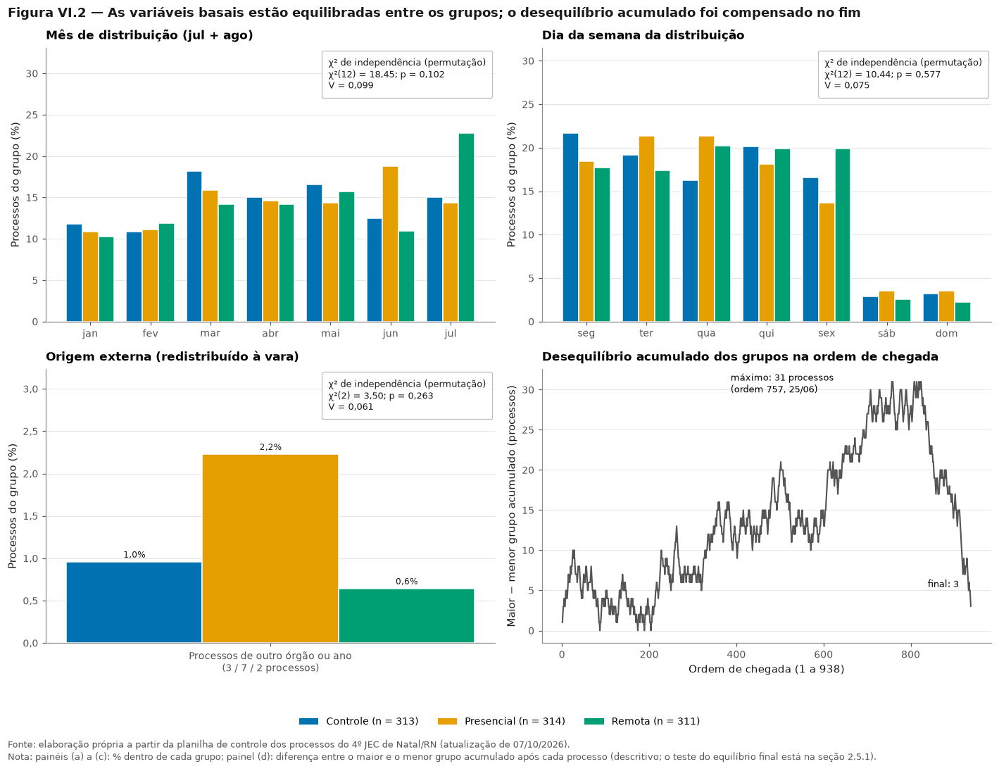

In [152]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9))
for ax, (rotulo, tab_) in zip(axs.ravel()[:3], eq_tabs.items()):
    pct = tab_.div(tab_.sum(axis=0), axis=1) * 100
    if rotulo.startswith('Origem'):          # só a categoria rara, para ser legível
        pct = pct.loc[['Sim']].rename(index={'Sim': 'Processos de outro órgão ou ano'})
        barras_agrupadas(ax, pct, cores=CORES_GRUPO, ylabel='Processos do grupo (%)', legenda=False, rotular=True,
                         fmt=lambda v: fmt_br(v, 1) + '%', quebrar=40)
        pct.index = [f'Processos de outro órgão ou ano\n(' + ' / '.join(str(int(tab_.loc['Sim', g])) for g in ORDEM_GRUPO)
                     + ' processos)']
        ax.set_xticks([0], pct.index)
    else:
        barras_agrupadas(ax, pct, cores=CORES_GRUPO, ylabel='Processos do grupo (%)', legenda=False)
    linha = eq_df.set_index('Variável basal').loc[rotulo]
    ax.set_ylim(0, pct.to_numpy().max() * 1.45)
    anotar_teste(ax, texto_teste('χ² de independência (permutação)', f'χ²({int(linha["gl"])}) = {fmt_br(linha["χ²"], 2)}',
                                 linha['p (permutação)'], f'V = {fmt_br(linha["V de Cramér"], 3)}'), loc='upper right')
    ax.set_title(rotulo)
# (d) desequilíbrio acumulado ao longo da ordem de chegada (descritivo: o sorteio restrito)
ordem = q6.sort_values('ordem_chegada')
acum = pd.get_dummies(ordem['grupo'].astype(str)).reindex(columns=ORDEM_GRUPO).cumsum()
amplitude = acum.max(axis=1) - acum.min(axis=1)
ax = axs[1, 1]
ax.plot(ordem['ordem_chegada'].astype(int).to_numpy(), amplitude.to_numpy(), color=TINTA_2, lw=1.4)
i_max = int(np.argmax(amplitude.to_numpy()))
ax.annotate(f'máximo: {int(amplitude.iloc[i_max])} processos\n(ordem {int(ordem["ordem_chegada"].iloc[i_max])}, '
            f'{ordem["dt_distribuicao"].iloc[i_max].strftime("%d/%m")})',
            (int(ordem['ordem_chegada'].iloc[i_max]), int(amplitude.iloc[i_max])), xytext=(-150, -10),
            textcoords='offset points', fontsize=8.5, arrowprops=dict(arrowstyle='-', color=TINTA_2))
ax.annotate(f'final: {int(amplitude.iloc[-1])}', (len(ordem), int(amplitude.iloc[-1])), xytext=(-40, 18),
            textcoords='offset points', fontsize=8.5, arrowprops=dict(arrowstyle='-', color=TINTA_2))
ax.set_xlabel(ROTULOS['ordem_chegada']); ax.set_ylabel('Maior − menor grupo acumulado (processos)')
ax.set_title('Desequilíbrio acumulado dos grupos na ordem de chegada')
fig.legend(handles=[mpl.patches.Patch(color=CORES_GRUPO[g], label=rotulo_grupo(g, com_n=True)) for g in ORDEM_GRUPO],
           loc='lower center', bbox_to_anchor=(0.5, -0.03), ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.04, 1, 1))
figura(fig, 'q_equilibrio_basal', 'As variáveis basais estão equilibradas entre os grupos; o desequilíbrio acumulado foi compensado no fim',
       secao='6.2', nota='painéis (a) a (c): % dentro de cada grupo; painel (d): diferença entre o maior e o menor grupo '
                         'acumulado após cada processo (descritivo; o teste do equilíbrio final está na seção 2.5.1).')

**Resposta à questão 2.3.** As três variáveis basais disponíveis não diferem entre os grupos além do acaso: mês de distribuição χ²(12) = 18,45, p (permutação) = 0,102, V = 0,099; dia da semana χ²(12) = 10,44, p = 0,577, V = 0,075; origem externa χ²(2) = 3,50, p = 0,263 (3, 7 e 2 processos). Após Holm, nenhum p fica abaixo de 0,30. É o que se espera de grupos formados por sorteio a partir de **uma mesma população** disponível. O mês, embora não significativo no global, tem os desvios localizados já vistos na seção 3.5.3 (junho com excesso de Presencial e julho com excesso de Remota), e por isso foi tratado como estrato nas Partes IV e V.

O painel (d) mostra a trajetória que denuncia o **sorteio restrito**: a diferença entre o maior e o menor grupo acumulado cresceu até 31 processos no fim de junho (ordem 757, 25/06) e caiu para 3 ao final, com a compensação concentrada em julho. Num sorteio simples, a amplitude final tem mediana em torno de 28 processos, e uma divisão tão equilibrada quanto a observada tem probabilidade de cerca de 1% (seção 2.5.1). Isso não compromete a independência entre os grupos, mas cria dependência fraca entre alocações sucessivas e uma associação entre período e grupo, o que reforça a análise estratificada por mês.

**Conclusão.** Os grupos são **amostras independentes** (partição aleatória de uma população finita, sem pareamento), comparáveis em expectativa. Isso determina testes para k amostras independentes (χ², Fisher, Kruskal-Wallis, Mann-Whitney, log-rank, Cox), e não testes pareados. As ressalvas (agrupamento por conciliadora e por juiz, litigantes repetidos, sorteio restrito) não mudam a família de testes, mas pedem cautela com valores-p limítrofes e justificam a estratificação.

## 6.3 Questão 2.4 — O que significam "híbrida" e "Decisão"?

**Enunciado.** O que significa a variável `híbrida` (Sim/Não), à luz da explicação do pesquisador (AC presencial em que uma das partes pediu para participar remotamente, deferida com base na Res. CNJ 481)? E o que significa o registro "Decisão" na coluna `sentença/decisão` (remessa do processo a outro juízo, por prevenção)?

**"Híbrida".** É uma **AC pautada como presencial** em que ao menos uma das partes participou por videoconferência, a pedido próprio, deferido pelo juiz. Estatisticamente, é uma **não adesão parcial ao tratamento sorteado** (*crossover* parcial do braço presencial em direção ao remoto), decidida pela parte **depois** do sorteio. Três consequências:

1. **não é tratamento aleatorizado**: quem pede para participar remotamente pode diferir de quem comparece (distância, trabalho, representação por advogado, interesse em acordo); a comparação "híbrida × presencial pura" é observacional e não testa a hipótese H4 do projeto ("presencial mais efetiva que a híbrida") de forma causal;
2. **na análise principal (intenção de tratar, ITT)** as híbridas permanecem no grupo sorteado (Presencial); a análise "conforme tratado", que as move para a Remota, é **sensibilidade** (seção 4.9);
3. **o "Não" tem dois sentidos**: no Controle, onde não há AC, o "Não" é um **zero estrutural** ("não se aplica"); nos braços com AC, é "audiência integralmente na modalidade pautada". Há, além disso, três "Sim" no grupo **Remota** (A12), incoerentes com a definição (uma audiência pautada como remota não pode ser "híbrida" nesse sentido), e três "Sim" na Presencial com técnica `**`, isto é, sem AC realizada (A13): ambos foram mantidos e sinalizados como desvio de protocolo (seção 1.12).

**"Decisão".** Não é sentença nem resolução do conflito: é a **remessa do processo a outro juízo** para redistribuição, porque um juízo anterior estava **prevento** (CPC, arts. 59 e 286). O processo **sai do 4º JEC** e nunca terá sentença ali. Tratar a "Decisão" como "encerramento" (o notebook do professor a conta como evento, E10) mistura um desfecho administrativo, de mediana de 1 dia, com o tempo até a sentença. Neste notebook, a redistribuição é (i) **risco competitivo** da sentença (Aalen-Johansen e Fine-Gray, seção 4.7), (ii) censura na análise causa-específica (Cox, 4.5) e (iii) excluída ou tratada como evento nas análises de sensibilidade (4.9). Como ela ocorre quase sempre **antes** da AC, é também, na prática, uma **inelegibilidade descoberta depois do sorteio**; e o processo que voltou ao 4º JEC foi **sorteado de novo** (A5), uma falha de protocolo corrigida na curadoria (o processo conserva o grupo do primeiro sorteio).

O quadro resume as duas variáveis, com as contagens da base primária e o efeito de cada tratamento sobre as conclusões.

In [153]:
hib = q6['hibrida'].fillna(False).astype(bool)
red = q6[q6['desfecho'] == 'Redistribuição']
red_t = red['tempo'].astype(float)
n_red = red['grupo'].value_counts().reindex(ORDEM_GRUPO)
quadro_hd = pd.DataFrame([
    ['Híbrida = Sim', 'AC pautada como presencial com participação remota de uma parte (pedido deferido)',
     'pós-sorteio; não adesão parcial ao rito sorteado',
     f'Presencial {int((hib & (q6.grupo == "Presencial")).sum())}; Remota {int((hib & (q6.grupo == "Remota")).sum())} (A12, incoerente); '
     f'Controle {int((hib & (q6.grupo == "Controle")).sum())}',
     'ITT: mantida no grupo sorteado; sensibilidade "conforme tratado" (4.9); acordo na AC híbrida × pura (3.3.4)',
     'não altera: HR da Remota 0,79 a 0,82 em todos os cenários (4.9); acordo 1/24 × 8/154, Fisher p = 1,000'],
    ['Híbrida = Não', 'AC realizada integralmente na modalidade pautada; no Controle, "não se aplica"',
     'zero estrutural no Controle', f'{int((~hib).sum())} registros (Controle: todos)',
     'distinguir "Não" de "não se aplica" (1.7, 1.11)', '—'],
    ['Sentença/decisão = "Decisão"', 'remessa a outro juízo por prevenção (CPC, arts. 59 e 286): o processo sai da vara',
     'saída do estudo antes da sentença; risco competitivo',
     f'{len(red)} na base primária (Controle {n_red["Controle"]}, Presencial {n_red["Presencial"]}, Remota {n_red["Remota"]}); '
     f'mediana {fmt_br(red_t.median(), 0)} dia; {int((red_t > 30).sum())} após 30 dias',
     'evento_cr = 2 (Aalen-Johansen, Fine-Gray, 4.7); censura no Cox causa-específico; exclusão e "evento" como sensibilidade (4.9)',
     'não altera: proporção igual entre grupos (3.2.4); viés do 1 − KM ≤ 3 p.p. aos 180 dias (4.7.1)'],
    ['Reentrada após "Decisão"', 'processo redistribuído que voltou e foi sorteado de novo, às vezes para outro grupo',
     'violação da unicidade da unidade experimental', '3 linhas (A5)', 'excluídas: vale o primeiro sorteio (1.10)',
     'não altera (cenário "com as duplicatas", 4.9)'],
], columns=['Registro', 'Significado', 'Natureza no desenho', 'Contagem (base primária)', 'Tratamento neste notebook',
            'Efeito sobre a conclusão'])
tabela(quadro_hd, 'q_hibrida_decisao', '"Híbrida" é não adesão parcial ao rito; "Decisão" é saída do estudo por redistribuição',
       secao='6.3', fonte='Elaboração própria; contagens da base primária (938 processos); efeitos conforme as Partes III e IV.')

Registro,Significado,Natureza no desenho,Contagem (base primária),Tratamento neste notebook,Efeito sobre a conclusão
Híbrida = Sim,AC pautada como presencial com participação remota de uma parte (pedido deferido),pós-sorteio; não adesão parcial ao rito sorteado,"Presencial 28; Remota 3 (A12, incoerente); Controle 0","ITT: mantida no grupo sorteado; sensibilidade ""conforme tratado"" (4.9); acordo na AC híbrida × pura (3.3.4)","não altera: HR da Remota 0,79 a 0,82 em todos os cenários (4.9); acordo 1/24 × 8/154, Fisher p = 1,000"
Híbrida = Não,"AC realizada integralmente na modalidade pautada; no Controle, ""não se aplica""",zero estrutural no Controle,907 registros (Controle: todos),"distinguir ""Não"" de ""não se aplica"" (1.7, 1.11)",—
"Sentença/decisão = ""Decisão""","remessa a outro juízo por prevenção (CPC, arts. 59 e 286): o processo sai da vara",saída do estudo antes da sentença; risco competitivo,"24 na base primária (Controle 5, Presencial 10, Remota 9); mediana 1 dia; 3 após 30 dias","evento_cr = 2 (Aalen-Johansen, Fine-Gray, 4.7); censura no Cox causa-específico; exclusão e ""evento"" como sensibilidade (4.9)",não altera: proporção igual entre grupos (3.2.4); viés do 1 − KM ≤ 3 p.p. aos 180 dias (4.7.1)
"Reentrada após ""Decisão""","processo redistribuído que voltou e foi sorteado de novo, às vezes para outro grupo",violação da unicidade da unidade experimental,3 linhas (A5),excluídas: vale o primeiro sorteio (1.10),"não altera (cenário ""com as duplicatas"", 4.9)"


**Resposta à questão 2.4.** As duas variáveis têm em comum o fato de registrarem algo que ocorre **depois do sorteio** e que, por isso, não pode ser tratado como tratamento ou desfecho comuns.

- **Híbrida = Sim** é não adesão parcial: 28 audiências do braço Presencial foram feitas com participação remota de uma parte. Mantidas no grupo sorteado (intenção de tratar), elas não alteram nada; movidas para a Remota ("conforme tratado"), também não (o HR da Remota fica entre 0,79 e 0,82 em todos os cenários da seção 4.9). O acordo na AC híbrida (1/24) não difere do da presencial pura (8/154; Fisher p = 1,000), mas com 9 acordos no total a comparação não tem poder e, sendo observacional, não testaria a hipótese H4 mesmo que tivesse. As 3 híbridas registradas no grupo Remota são erro de registro ou de definição e foram sinalizadas (A12).
- **"Decisão"** é saída do estudo por redistribuição a juízo prevento: 24 processos (5, 10 e 9 por grupo), com mediana de 1 dia e só 3 após 30 dias. Não é sentença: contá-la como evento (E10) faria o processo "terminar" em um dia sem que o conflito tivesse sido resolvido no 4º JEC. Como risco competitivo, ela é igualmente frequente nos três grupos (seção 3.2.4) e distorce pouco o 1 − Kaplan-Meier (no máximo cerca de 3 pontos percentuais aos 180 dias; seção 4.7.1), de modo que nenhuma conclusão depende da forma de tratá-la. Do ponto de vista do desenho, porém, é uma falha de elegibilidade: a prevenção deveria ser verificada **antes** do sorteio, e o processo que retorna não deveria ser sorteado de novo.

## 6.4 Questão 2.5 — Populações de interesse, disponível e amostrada; cruzamento com os 14 JECs

**Enunciado.** Descrever a população de interesse, a disponível e a amostrada; dizer como ampliar o cruzamento do tempo da distribuição até a sentença aos 14 JECs de Natal no mesmo período (2/1/2026 a 3/8/2026) e se há dados disponíveis no CNJ.

**As três populações.** A distinção é a de toda pesquisa por amostragem: a **população de interesse** (ou alvo) é aquela sobre a qual se quer concluir; a **disponível** (acessível) é a parte dela a que o pesquisador tem acesso; a **amostrada** é o que efetivamente entrou na base. A inferência estatística vai da amostrada à disponível; a passagem da disponível à de interesse é **extrapolação**, que depende de argumento substantivo, não de cálculo.

- **De interesse.** As ações de conhecimento do procedimento do Juizado Especial Cível (classe CNJ 436) distribuídas aos **14 JECs cíveis de Natal** no período do experimento, e, num sentido mais amplo e implícito no projeto (que pretende avaliar a política nacional de conciliação), as ações dos JECs cíveis em geral sob a alternativa "AC obrigatória × rito sem AC inaugural".
- **Disponível.** As ações distribuídas ao **4º JEC** de Natal entre 01/01 e 03/08/2026: a única unidade cujo juiz aceitou o experimento. Note-se que o período informado na questão (2/1/2026) difere do observado na planilha: o primeiro processo foi distribuído em **01/01/2026** (seção 1.13).
- **Amostrada.** Os **943** processos sorteados (944 linhas), reduzidos a **938** processos distintos na base primária (seção 1.10), observados até a atualização de **07/10/2026**: 708 com sentença, 24 redistribuídos e 206 ainda em tramitação (censurados). Em relação à disponível, é praticamente um **censo**; em relação à de interesse, é **um conglomerado escolhido por conveniência**, e não uma amostra probabilística dos 14 JECs.

**Como ampliar aos 14 JECs: o DataJud.** Há dados públicos no CNJ. A **API Pública do DataJud** expõe, para cada tribunal, os metadados e os **movimentos processuais** codificados pelas Tabelas Processuais Unificadas (TPU): data de ajuizamento, classe, órgão julgador e cada movimento com data e hora (distribuição, audiência, homologação de acordo, julgamento com ou sem resolução do mérito, redistribuição). Para o TJRN, o endpoint é `api_publica_tjrn`; o filtro natural é **classe 436**, **órgão julgador** (o 4º JEC tem o código **13285**; os demais 13 JECs de Natal têm códigos próprios) e data de ajuizamento entre 01/01 e 03/08/2026. Com isso se reconstrói, para os 14 JECs, o tempo da distribuição até o primeiro julgamento, com a mesma regra de censura usada aqui. O vínculo com a planilha é **exato**, porque o número CNJ é identificador único com dígito verificador (940 de 940 válidos, seção 1.9).

**Limites.** A API pública **não traz as partes, o valor da causa, o advogado nem o magistrado**; os movimentos dependem da qualidade do lançamento em cada vara (códigos genéricos, lançamentos em lote); e o índice é atualizado com defasagem. O DataJud permite, portanto, comparar **tempos e tipos de desfecho** entre unidades, mas não fornece as covariáveis que faltam ao experimento (6.8). A etapa de coleta está em curso: até o momento, 199 de 200 números da planilha consultados foram encontrados na API do TJRN, mas a coleta completa está limitada pela sobrecarga da API do CNJ; os números serão apresentados na **Parte VIII**. O que se pode e o que não se pode concluir com a comparação entre JECs está em 6.9.

In [154]:
quadro_pop = pd.DataFrame([
    ['De interesse (alvo)', 'ações do procedimento do JEC cível (classe 436) dos 14 JECs de Natal, 01/01 a 03/08/2026; '
     'em sentido amplo, JECs cíveis sob a política de conciliação do CNJ', 'desconhecido na planilha; estimável pelo DataJud (Parte VIII)',
     'extrapolação: exige argumento substantivo ou replicação (6.9)'],
    ['Disponível (acessível)', 'ações distribuídas ao 4º JEC de Natal, 01/01 a 03/08/2026',
     '943 sorteadas (resumo expandido); 944 linhas na planilha', 'unidade única, escolhida por conveniência'],
    ['Amostrada (analisada)', 'processos distintos da planilha, observados até 07/10/2026',
     f'{len(q6)} processos: {int(q6.evento.astype(int).sum())} sentenças, {int((q6.desfecho == "Redistribuição").sum())} redistribuições, '
     f'{int((q6.desfecho == "Ativo").sum())} censurados', 'censo da disponível; inferência por aleatorização válida para o 4º JEC'],
], columns=['População', 'Definição', 'Tamanho e fonte', 'Alcance da inferência'])
tabela(quadro_pop, 'q_populacoes', 'Populações de interesse, disponível e amostrada', secao='6.4',
       fonte='Elaboração própria a partir do projeto de pesquisa, do resumo expandido e da Parte I.')

quadro_dj = pd.DataFrame([
    ['Número CNJ', 'sim', 'sim', 'vínculo exato planilha × DataJud (validação das datas e desfechos)'],
    ['Data de distribuição / ajuizamento', 'sim', 'sim (dataAjuizamento; movimento de distribuição)', 'origem do tempo'],
    ['Data e tipo da sentença', 'sim (digitado; 18% em fim de semana, A16)', 'sim (movimentos TPU com data e hora)',
     'conferir a data da sentença e o tipo de extinção'],
    ['Redistribuição', 'sim ("Decisão")', 'sim (movimento de redistribuição)', 'risco competitivo nos 14 JECs'],
    ['Audiência de conciliação (data, realização)', 'não (só a técnica)', 'sim, quando lançada (movimentos de audiência)',
     'decompor o tempo em etapas (pauta, AC, sentença)'],
    ['Grupo do experimento, técnica, híbrida', 'sim', 'não', 'só existem na planilha'],
    ['Partes, polo passivo, litigante habitual', 'não', 'não (dados de partes fora da API pública)', 'covariável faltante (6.8)'],
    ['Valor da causa, assunto', 'não', 'assunto sim (TPU); valor da causa não', 'assunto como covariável basal'],
    ['Magistrado, advogado', 'não', 'não', 'efeito de juiz só por órgão julgador'],
], columns=['Informação', 'Planilha do experimento', 'DataJud (API pública)', 'Uso no estudo'])
tabela(quadro_dj, 'q_datajud', 'O que o DataJud acrescenta à planilha e o que continua faltando', secao='6.4',
       fonte='Elaboração própria a partir da documentação da API Pública do DataJud (CNJ) e da Parte I.')

População,Definição,Tamanho e fonte,Alcance da inferência
De interesse (alvo),"ações do procedimento do JEC cível (classe 436) dos 14 JECs de Natal, 01/01 a 03/08/2026; em sentido amplo, JECs cíveis sob a política de conciliação do CNJ",desconhecido na planilha; estimável pelo DataJud (Parte VIII),extrapolação: exige argumento substantivo ou replicação (6.9)
Disponível (acessível),"ações distribuídas ao 4º JEC de Natal, 01/01 a 03/08/2026",943 sorteadas (resumo expandido); 944 linhas na planilha,"unidade única, escolhida por conveniência"
Amostrada (analisada),"processos distintos da planilha, observados até 07/10/2026","938 processos: 708 sentenças, 24 redistribuições, 206 censurados",censo da disponível; inferência por aleatorização válida para o 4º JEC


Informação,Planilha do experimento,DataJud (API pública),Uso no estudo
Número CNJ,sim,sim,vínculo exato planilha × DataJud (validação das datas e desfechos)
Data de distribuição / ajuizamento,sim,sim (dataAjuizamento; movimento de distribuição),origem do tempo
Data e tipo da sentença,"sim (digitado; 18% em fim de semana, A16)",sim (movimentos TPU com data e hora),conferir a data da sentença e o tipo de extinção
Redistribuição,"sim (""Decisão"")",sim (movimento de redistribuição),risco competitivo nos 14 JECs
"Audiência de conciliação (data, realização)",não (só a técnica),"sim, quando lançada (movimentos de audiência)","decompor o tempo em etapas (pauta, AC, sentença)"
"Grupo do experimento, técnica, híbrida",sim,não,só existem na planilha
"Partes, polo passivo, litigante habitual",não,não (dados de partes fora da API pública),covariável faltante (6.8)
"Valor da causa, assunto",não,assunto sim (TPU); valor da causa não,assunto como covariável basal
"Magistrado, advogado",não,não,efeito de juiz só por órgão julgador


**Resposta à questão 2.5.** O quadro das populações deixa explícito o salto que a pesquisa precisa dar: da amostrada à disponível, a inferência é **interna e válida** (os 938 processos são praticamente o censo das ações distribuídas ao 4º JEC no período, e o sorteio dá base às comparações); da disponível à de interesse, não há inferência estatística, porque só uma das 14 unidades entrou, e não por sorteio.

O segundo quadro mostra que o DataJud resolve **parte** do problema. Ele traz, para todos os JECs, exatamente o que é preciso para medir o tempo da distribuição à sentença com a mesma regra de censura (datas de ajuizamento e movimentos de julgamento, homologação e redistribuição), e permite conferir, pelo número CNJ, as datas digitadas na planilha (em especial as 18,4% de sentenças em fim de semana). Não traz o que mais falta ao experimento: partes, valor da causa, advogado e magistrado. O DataJud serve, portanto, para **comparar unidades e validar a medida do desfecho**, não para recuperar as covariáveis do processo. Os resultados da coleta (199 de 200 números consultados encontrados até agora no endpoint do TJRN) e as comparações estão na **Parte VIII**.

## 6.5 Questão 2.6 — O tratamento dos dados brutos no notebook do professor foi adequado?

**Enunciado.** O tratamento das variáveis no notebook `estcaso_4jec_natal_rn.ipynb` foi adequado? Pode ser complementado? Como?

**Resposta.** **Não foi adequado**, e o problema central não é de limpeza cosmética, mas de **definição da variável-alvo**. O notebook lê corretamente a planilha e faz uma auditoria inicial útil (duplicatas, faltantes, conferência data × duração), mas não age sobre o que encontra e deixa de tratar o que determina todas as análises seguintes:

1. **a data de referência dos processos ativos é `TODAY()`** (fórmula volátil da planilha): os 209 ativos têm duração calculada até o dia em que o arquivo foi aberto, e o notebook os trata como tempos completos (E7, E14; A1). Aqui, a censura foi fixada em **07/10/2026** e o tempo recalculado a partir das datas (seção 1.4);
2. **a "Decisão" é contada como encerramento** (E10), quando é redistribuição (6.3);
3. **duplicatas e reentradas** são detectadas e mantidas (E3): duas linhas vazias criariam falsos censurados e três reentradas foram re-sorteadas, uma delas para outro grupo (A3–A5, seção 1.10);
4. **o marcador `**` e as ausências estruturais** são tratados como categoria ou como "Não" (E4, E5): no Controle, "acordo na AC = Não" e "técnica = `**`" significam "não se aplica" (seção 1.7);
5. **as quatro colunas de duração são a mesma variável** (E6, A17), o que contamina a matriz de correlações (6.6);
6. a linha sem fórmulas (A2), as grafias variantes (A6), os números CNJ com espaço, hífen ou órgão truncado (A7, A8), os processos vindos de outro órgão (A9) e os desvios de protocolo da híbrida (A12, A13) não são tratados.

**Como complementar.** O tratamento feito na Parte I responde a cada item com uma regra explícita, registrada no **log de tratamentos** (seção 1.15) e no **dicionário de variáveis** (seção 1.16), sem imputar nenhuma data ou duração; o quadro abaixo emparelha cada problema com a solução. Faltam, e só podem vir de fora da planilha: (i) a **validação das datas de sentença** (18,4% caem em sábado ou domingo, A16; seção 2.5.4) contra os movimentos do PJe/DataJud; (ii) o **motivo da extinção sem mérito** (ausência do autor, desistência, indeferimento), que explicaria o principal achado do experimento (6.7); (iii) a **data da AC** e as demais datas intermediárias; e (iv) as **covariáveis previstas no projeto** e não coletadas (tipo de ação, valor da causa, número de partes).

In [155]:
quadro_trat = pd.DataFrame([
    ['E7, E14 / A1', 'duração dos ativos até TODAY(); censurados tratados como tempos completos',
     'tempo recalculado das datas; censura fixa em 07/10/2026; par (tempo, evento)', '1.4, 1.13'],
    ['E10 / Decisão', '"Decisão" contada como encerramento', 'tipo "Redistribuição"; evento = 0, evento_cr = 2, causa = 4', '1.11.2, 1.12.1'],
    ['E3 / A3–A5', 'duplicatas detectadas e mantidas', '6 linhas excluídas; 1 processo = 1 unidade, grupo do 1º sorteio', '1.10'],
    ['E2 / A2', 'linha sem fórmulas e STATUS vazio', 'mantida como ativo censurado (data de distribuição válida)', '1.13'],
    ['E4, E5', '"**" e NA como categorias ou como "Não"', 'NA estrutural × NA de registro; ac_realizada; tabela de padrões de ausência', '1.7'],
    ['E6 / A17', 'quatro colunas de duração idênticas tratadas como variáveis distintas', 'descartadas; uma só variável-tempo', '1.4'],
    ['A6', 'grafia variante do tipo de sentença (11 casos)', 'recodificada para a forma canônica', '1.11'],
    ['A7, A8', 'CNJ com espaço, hífen ou órgão truncado', 'normalizado; dígito verificador (mod 97) confere em 100%', '1.9'],
    ['A9', 'processos de outro órgão ou ano (redistribuídos à vara)', 'mantidos; flag origem_externa; sensibilidade', '1.9.1, 4.9'],
    ['E11 / A12, A13', 'híbrida ignorada; híbridas incoerentes', 'flags de desvio de protocolo; ITT e "conforme tratado"', '1.12, 4.9'],
    ['A15', 'desfechos no dia zero descartados no ajuste (x > 0)', 'mantidos; 0,5 dia só nos modelos paramétricos', '1.13, 2.2.5'],
    ['A16', 'não examinado', 'flag sentenca_fim_semana; sensibilidade; validar no DataJud', '2.5.4, 4.9'],
    ['—', 'sem dicionário nem registro das decisões', 'log de tratamentos e dicionário exportados', '1.15, 1.16'],
], columns=['Código', 'No notebook do professor', 'Tratamento neste notebook', 'Seção'])
tabela(quadro_trat, 'q_tratamento', 'Tratamento dos dados brutos: o que o notebook do professor deixou de fazer e como foi feito aqui',
       secao='6.5', fonte='Elaboração própria; códigos E1–E30 de docs/r2_notebook_professor.md e A1–A20 de docs/r3_auditoria_dados.md.')

Código,No notebook do professor,Tratamento neste notebook,Seção
"E7, E14 / A1",duração dos ativos até TODAY(); censurados tratados como tempos completos,"tempo recalculado das datas; censura fixa em 07/10/2026; par (tempo, evento)","1.4, 1.13"
E10 / Decisão,"""Decisão"" contada como encerramento","tipo ""Redistribuição""; evento = 0, evento_cr = 2, causa = 4","1.11.2, 1.12.1"
E3 / A3–A5,duplicatas detectadas e mantidas,"6 linhas excluídas; 1 processo = 1 unidade, grupo do 1º sorteio",1.10
E2 / A2,linha sem fórmulas e STATUS vazio,mantida como ativo censurado (data de distribuição válida),1.13
"E4, E5","""**"" e NA como categorias ou como ""Não""",NA estrutural × NA de registro; ac_realizada; tabela de padrões de ausência,1.7
E6 / A17,quatro colunas de duração idênticas tratadas como variáveis distintas,descartadas; uma só variável-tempo,1.4
A6,grafia variante do tipo de sentença (11 casos),recodificada para a forma canônica,1.11
"A7, A8","CNJ com espaço, hífen ou órgão truncado",normalizado; dígito verificador (mod 97) confere em 100%,1.9
A9,processos de outro órgão ou ano (redistribuídos à vara),mantidos; flag origem_externa; sensibilidade,"1.9.1, 4.9"
"E11 / A12, A13",híbrida ignorada; híbridas incoerentes,"flags de desvio de protocolo; ITT e ""conforme tratado""","1.12, 4.9"


**Resposta à questão 2.6.** O quadro mostra que os problemas do notebook do professor não são independentes: quase todos convergem para a **variável-alvo**. A duração dos ativos calculada até `TODAY()`, a "Decisão" contada como encerramento, as duplicatas que criariam falsos censurados e as colunas redundantes de duração afetam diretamente o par (tempo, evento), do qual dependem todas as análises posteriores. Os demais itens (grafias, CNJ, `**`, híbridas) afetam as variáveis de classificação.

O tratamento adequado não exigiu imputar nada: bastou (i) fixar a data de corte, (ii) recalcular o tempo pelas datas, (iii) definir o evento e o tipo de desfecho com base no significado jurídico de cada registro, (iv) aplicar uma regra única às duplicatas (um processo, uma unidade, o grupo do primeiro sorteio) e (v) registrar cada decisão. O tratamento pode e deve ser complementado com fontes externas: as datas e os motivos de extinção, que a planilha não tem, estão nos movimentos do PJe e, em parte, no DataJud (6.4).

## 6.6 Questão 2.7 — A matriz de correlações é adequada? Ordem de chegada × duração

**Enunciado.** A matriz de correlações inicial do notebook do professor é adequada? Com a informação de que o sorteio seguiu rigorosamente a ordem de chegada dos processos, é possível investigar a correlação entre essa ordem e `duracao_proc`?

**A matriz não é adequada**, por três razões, cada uma suficiente:

1. **é tautológica**: as quatro colunas correlacionadas (`DURAÇÃO-SENT2`, `-SORT`, `-PROC`, `-TECN`) são **a mesma fórmula** da planilha, apenas filtrada para as tabelas dinâmicas; as três primeiras coincidem em 943 de 943 linhas e a quarta nas 428 em que existe. O r = 1 em todas as células (e o R² = 1 das dispersões) é identidade aritmética, não achado (E6, E16; seção 2.6.4);
2. **não há outra variável quantitativa** na planilha: as demais (grupo, híbrida, acordo, técnica, tipo de sentença) são **nominais**, para as quais a medida de associação adequada é o V de Cramér (ou o φ), e entre uma nominal e o tempo, a razão de correlação η ou, melhor, um modelo de sobrevivência. A seção 2.6.4 substitui a matriz do professor por uma **matriz de associação** com essas medidas;
3. **ignora a censura**: um quarto dos tempos é limite inferior (processos ainda ativos), e qualquer correlação calculada sobre eles mistura duração com tempo de seguimento.

**A ordem de chegada pode ser investigada, mas não pela correlação bruta.** A ordem é uma variável **ordinal** (equivalente à data de distribuição), o que admite Spearman ou Kendall, nunca Pearson sobre códigos. O obstáculo é estrutural: como todos os processos foram observados até a mesma data (07/10/2026), **quanto mais tarde o processo chegou, menor o seguimento máximo possível** (correlação de −1 entre ordem e seguimento). Um processo de julho só aparece como "sentenciado" se for rápido; um de janeiro pode aparecer com 200 dias. Isso produz uma correlação **negativa artificial** entre ordem e tempo, mesmo que não haja nenhuma relação real. A Parte III mediu esse artefato por simulação (tempos gerados independentemente da ordem e censurados pelo seguimento real de cada processo; seção 3.5.2): a figura abaixo compara o ρ observado com o intervalo que a censura sozinha produziria. Na **janela comum** de 65 dias (o seguimento mínimo, observado sem censura para todos), o sinal se **inverte**.

A forma correta de responder à pergunta substantiva ("o tempo até a sentença mudou ao longo do experimento?") é incluir o mês ou a ordem como **covariável num modelo de sobrevivência**. O Cox da seção 4.5 mostra razões de risco decrescentes com o mês (junho 0,70; julho-agosto 0,58, contra janeiro), e o AFT log-normal da seção 5.1.3 estima que o tempo típico até a sentença **aumentou cerca de 20% a cada mês** de distribuição: um **acúmulo de acervo** ao longo do experimento que a correlação bruta apresentava com o sinal trocado. A ordem de chegada serviu, ainda, para testar a aleatoriedade do sorteio (teste de corridas, seção 3.5.1).

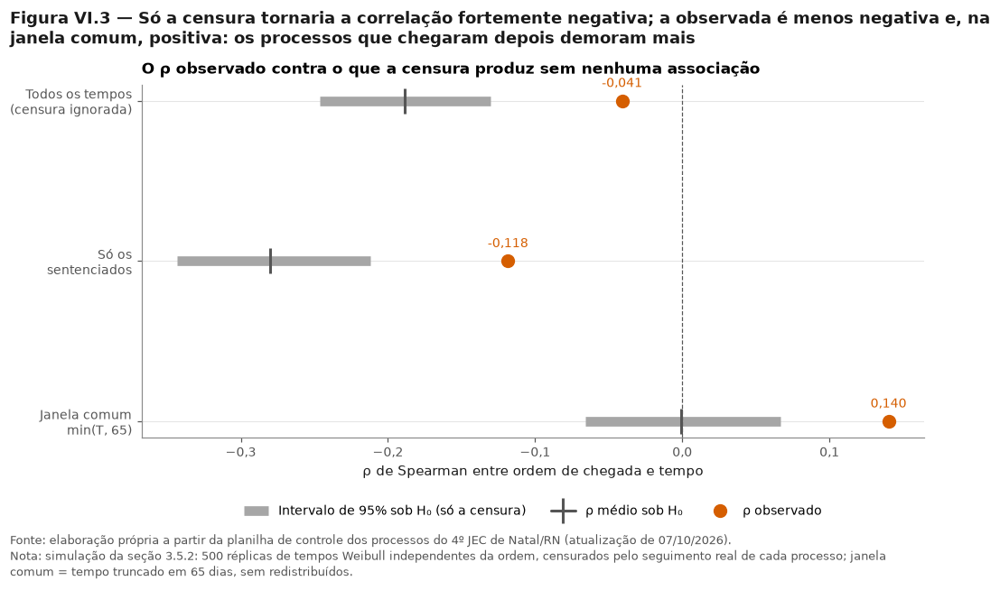

In [156]:
sim_ordem = q6_csv('tst_ordem_simulacao.csv')
if sim_ordem is not None:
    rot_v = {'todos (censura ignorada)': 'Todos os tempos\n(censura ignorada)', 'só encerrados': 'Só os\nsentenciados',
             'min(T, 65)': 'Janela comum\nmin(T, 65)'}
    fig, ax = plt.subplots(figsize=(9.5, 5))
    for i, lin in sim_ordem.reset_index(drop=True).iterrows():
        ax.plot([lin['Percentil 2,5'], lin['Percentil 97,5']], [i, i], color=CINZA, lw=7, solid_capstyle='butt',
                label='Intervalo de 95% sob H₀ (só a censura)' if i == 0 else None)
        ax.plot(lin['ρ médio sob H₀'], i, marker='|', ms=18, color=TINTA_2, mew=2, label='ρ médio sob H₀' if i == 0 else None)
        ax.plot(lin['ρ observado'], i, 'o', ms=9, color=DESTAQUE, label='ρ observado' if i == 0 else None)
        ax.annotate(fmt_br(lin['ρ observado'], 3), (lin['ρ observado'], i), xytext=(0, 10), textcoords='offset points',
                    ha='center', fontsize=9, color=DESTAQUE)
    ax.axvline(0, color=TINTA_2, lw=0.8, ls='--')
    ax.set_yticks(range(len(sim_ordem)), [rot_v.get(v, v) for v in sim_ordem['Versão']])
    ax.invert_yaxis()
    ax.set_xlabel('ρ de Spearman entre ordem de chegada e tempo')
    ax.set_title('O ρ observado contra o que a censura produz sem nenhuma associação')
    legenda_abaixo(ax, ncol=3)
    figura(fig, 'q_ordem_artefato', 'Só a censura tornaria a correlação fortemente negativa; a observada é menos negativa '
           'e, na janela comum, positiva: os processos que chegaram depois demoram mais', secao='6.6',
           nota='simulação da seção 3.5.2: 500 réplicas de tempos Weibull independentes da ordem, censurados pelo seguimento '
                'real de cada processo; janela comum = tempo truncado em 65 dias, sem redistribuídos.')

**Resposta à questão 2.7.** A figura resolve a aparente contradição entre "há correlação" e "não há correlação" na ordem de chegada. Se os tempos fossem **independentes** da ordem, a censura sozinha produziria um ρ de Spearman em torno de −0,19 quando se usam todos os tempos (intervalo de 95%: −0,25 a −0,13) e de −0,28 quando se usam só os sentenciados (−0,34 a −0,21). Os valores observados (−0,041 e −0,118) são **menos negativos** do que isso e caem **fora** dos intervalos de nulidade. Na janela comum de 65 dias, a única versão do tempo sem censura para todos, o artefato desaparece (ρ médio sob H₀ ≈ 0) e o ρ observado é **positivo** (0,140), acima do intervalo de nulidade (−0,066 a 0,067).

A leitura correta é, portanto, oposta à que a correlação bruta sugere: os processos que chegaram depois **demoraram mais** para ser sentenciados, e o sinal negativo dos dados brutos é produzido pela censura. Isso coincide com os modelos que respeitam a censura (Cox com mês: HR de 0,70 em junho e de 0,58 em julho-agosto contra janeiro; AFT log-normal: cerca de 20% mais tempo por mês de distribuição) e indica **acúmulo de acervo** ao longo do experimento.

Quanto à matriz do professor, a resposta é inequívoca: correlacionar quatro cópias da mesma coluna produz r = 1 por identidade e nada informa. A matriz adequada é de **associação** (V de Cramér entre nominais, η entre nominal e tempo), e a relação de qualquer variável com o tempo deve ser medida num modelo de sobrevivência.

## 6.7 Questão 2.8 — Variáveis de confundimento

**Enunciado.** Refletir sobre possíveis variáveis de confundimento, apresentá-las em quadro com os seus efeitos possíveis e dizer se foram ou não controladas pelo desenho.

**Conceito.** Um **confundidor** é uma variável associada ao mesmo tempo à exposição e ao desfecho, sem estar no caminho causal entre eles; se não for controlado, a diferença observada entre os grupos mistura o efeito do tratamento com o efeito dele. É preciso distingui-lo do **mediador** (a variável pela qual o tratamento age, como a fila da pauta da AC ou a ausência do autor à audiência) e do **modificador de efeito** (a variável que muda o tamanho do efeito, como o perfil da unidade).

**O que o sorteio controla e o que não controla.** A aleatorização individual controla, **em expectativa**, todos os fatores **do processo** anteriores ao sorteio: tipo de ação, valor da causa, número de partes, litigante habitual, presença de advogado. Esse é o grande mérito do desenho, e é por isso que a falta dessas variáveis na planilha não enviesa a comparação entre grupos (embora impeça verificar o equilíbrio e reduza a precisão). O sorteio **não controla** três famílias de fatores:

- os que estão **amarrados ao braço** pelo próprio protocolo: a conciliadora (CEJUSC na presencial, gabinete na remota) é **a mesma para todos os processos de cada braço**, de modo que o "efeito da modalidade" e o "efeito da conciliadora" são indissociáveis (a hipótese H5 do projeto é inestimável);
- os que **agem sobre todos os grupos** de forma possivelmente diferencial e não são cegos: o juiz-pesquisador que sorteia, julga e analisa; a reatividade da equipe (Hawthorne); a contaminação entre grupos (mesmo cartório e mesma equipe);
- os que **variam no tempo** e se combinam com a composição dos grupos: o mês de distribuição (junho com excesso de Presencial e julho de Remota, resíduos ajustados 2,95 e 3,10; seção 3.5.3), que também determina o seguimento e coincide com um acúmulo de acervo (6.6). Este foi **controlado na análise**, por estratificação (log-rank estratificado, Cox com estrato por mês; seções 4.3.4 e 4.5), e a conclusão se manteve.

O quadro a seguir organiza os candidatos, com o efeito provável, a direção do viés e o que o desenho ou a análise fez a respeito.

In [157]:
quadro_conf = pd.DataFrame([
    ['Conciliadora (CEJUSC × gabinete)', 'condutora diferente em cada braço; habilidade e estilo próprios',
     'acordo e tempo do braço refletem a pessoa, não só a modalidade', 'indeterminada (Presencial × Remota)',
     'não: confundida por desenho', 'rodízio das conciliadoras entre modalidades; várias conciliadoras por braço'],
    ['Juiz-pesquisador não cego', 'quem sorteia também pauta, julga e analisa',
     'ritmo de sentença diferente por grupo, consciente ou não', 'indeterminada; os resultados contrariam H1, o que atenua a suspeita',
     'não', 'análise cega ao grupo; desfecho extraído do PJe/DataJud por terceiro'],
    ['Reatividade (Hawthorne)', 'equipe sabe que é observada', 'aceleração geral ou do braço "de interesse"', 'tende a reduzir tempos em todos os grupos',
     'não', 'comparar o 4º JEC antes (2025) e durante (2026) com os outros 13 JECs (6.9)'],
    ['Contaminação entre grupos', 'mesmo cartório, mesma equipe e mesmas práticas nos três ritos',
     'práticas da AC vazam para o Controle', 'para zero (subestima diferenças)', 'não', 'ensaio por conglomerados (unidades sorteadas)'],
    ['Mês de distribuição / acúmulo de acervo', 'composição dos grupos varia por mês; tempo cresce ~20% por mês',
     'grupo com mais entradas tardias parece mais lento', 'contra a Remota (mais casos em julho)',
     'parcialmente (sorteio restrito)', 'estratificação por mês (feita: 4.3.4, 4.5); blocos por mês na replicação'],
    ['Tipo de ação, valor da causa, nº de partes', 'complexidade e chance de acordo variam com o caso',
     'tempo e acordo', 'nenhuma em expectativa', 'sim, em expectativa (sorteio)', 'coletar para verificar o equilíbrio e ganhar precisão'],
    ['Litigante habitual, advogado constituído', 'réus repetidos e assistência técnica', 'acordo, ausência, tempo', 'nenhuma em expectativa',
     'sim, em expectativa; dependência entre processos', 'coletar; erros-padrão por agrupamento'],
    ['Audiência híbrida (adesão)', 'pedido da parte após o sorteio', 'acordo e tempo da AC', 'pequena (28 casos)',
     'sim pela análise ITT', 'ITT principal; "conforme tratado" como sensibilidade (feita: 4.9)'],
    ['Ausência do autor à AC (art. 51, I, Lei 9.099/95)', 'mediador: a AC obrigatória cria a ocasião da extinção',
     'mais extinções sem mérito nos braços com AC', 'é parte do efeito do rito (não é viés)', 'não se aplica (mediador)',
     'registrar comparecimento e motivo da extinção'],
    ['Fila da pauta da AC', 'mediador: a AC acrescenta uma etapa ao rito', 'sentenças de mérito mais tardias', 'é parte do efeito do rito',
     'não se aplica (mediador)', 'registrar data da AC; decompor o tempo em etapas'],
    ['Técnica de conciliação', 'sorteada por audiência', 'acordo na AC', 'nenhuma (sorteio uniforme, p = 0,566)',
     'sim (sorteio)', '—'],
    ['Data da sentença registrada', '18,4% em fim de semana; possível data de lançamento', 'erro de medida do tempo',
     'não diferencial (sem efeito na conclusão, 4.9)', 'não', 'conferir no PJe/DataJud (Parte VIII)'],
    ['Redistribuição por prevenção', 'saída do estudo antes da sentença', 'remove casos do risco', 'nenhuma (igual entre grupos, p = 0,393)',
     'sim, na análise (risco competitivo)', 'triagem de prevenção antes do sorteio'],
], columns=['Variável', 'Mecanismo', 'Efeito provável', 'Direção do viés', 'Controlada pelo desenho?', 'Como controlar'])
tabela(quadro_conf, 'q_confundidores', 'Variáveis de confundimento, mediadores e ameaças: efeito provável e controle pelo desenho',
       secao='6.7', fonte='Elaboração própria a partir do projeto de pesquisa, do texto antagonista (ODT) e das Partes II a IV.')

Variável,Mecanismo,Efeito provável,Direção do viés,Controlada pelo desenho?,Como controlar
Conciliadora (CEJUSC × gabinete),condutora diferente em cada braço; habilidade e estilo próprios,"acordo e tempo do braço refletem a pessoa, não só a modalidade",indeterminada (Presencial × Remota),não: confundida por desenho,rodízio das conciliadoras entre modalidades; várias conciliadoras por braço
Juiz-pesquisador não cego,"quem sorteia também pauta, julga e analisa","ritmo de sentença diferente por grupo, consciente ou não","indeterminada; os resultados contrariam H1, o que atenua a suspeita",não,análise cega ao grupo; desfecho extraído do PJe/DataJud por terceiro
Reatividade (Hawthorne),equipe sabe que é observada,"aceleração geral ou do braço ""de interesse""",tende a reduzir tempos em todos os grupos,não,comparar o 4º JEC antes (2025) e durante (2026) com os outros 13 JECs (6.9)
Contaminação entre grupos,"mesmo cartório, mesma equipe e mesmas práticas nos três ritos",práticas da AC vazam para o Controle,para zero (subestima diferenças),não,ensaio por conglomerados (unidades sorteadas)
Mês de distribuição / acúmulo de acervo,composição dos grupos varia por mês; tempo cresce ~20% por mês,grupo com mais entradas tardias parece mais lento,contra a Remota (mais casos em julho),parcialmente (sorteio restrito),"estratificação por mês (feita: 4.3.4, 4.5); blocos por mês na replicação"
"Tipo de ação, valor da causa, nº de partes",complexidade e chance de acordo variam com o caso,tempo e acordo,nenhuma em expectativa,"sim, em expectativa (sorteio)",coletar para verificar o equilíbrio e ganhar precisão
"Litigante habitual, advogado constituído",réus repetidos e assistência técnica,"acordo, ausência, tempo",nenhuma em expectativa,"sim, em expectativa; dependência entre processos",coletar; erros-padrão por agrupamento
Audiência híbrida (adesão),pedido da parte após o sorteio,acordo e tempo da AC,pequena (28 casos),sim pela análise ITT,"ITT principal; ""conforme tratado"" como sensibilidade (feita: 4.9)"
"Ausência do autor à AC (art. 51, I, Lei 9.099/95)",mediador: a AC obrigatória cria a ocasião da extinção,mais extinções sem mérito nos braços com AC,é parte do efeito do rito (não é viés),não se aplica (mediador),registrar comparecimento e motivo da extinção
Fila da pauta da AC,mediador: a AC acrescenta uma etapa ao rito,sentenças de mérito mais tardias,é parte do efeito do rito,não se aplica (mediador),registrar data da AC; decompor o tempo em etapas


**Resposta à questão 2.8.** O quadro separa três situações que costumam ser confundidas sob o nome de "confundimento":

1. **confundidores neutralizados pelo sorteio** (tipo de ação, valor, partes, litigante habitual, advogado): não enviesam a comparação entre grupos, embora a sua ausência na planilha impeça verificar o equilíbrio e reduza a precisão;
2. **confundidores que o sorteio não alcança** porque estão amarrados ao braço ou agem sobre todos os grupos sem cegamento (conciliadora, juiz-pesquisador, reatividade, contaminação): não foram controlados pelo desenho e só podem ser controlados numa replicação (rodízio, cegamento, várias unidades). A conciliadora é o mais grave: torna a comparação Presencial × Remota uma comparação entre **duas pessoas** tanto quanto entre duas modalidades. A contaminação, ao contrário, tende a **reduzir** as diferenças, o que torna mais robustos os efeitos encontrados contra o Controle;
3. **mediadores** (fila da pauta, ausência do autor à AC): não são viés, são o **caminho** pelo qual o rito age, e explicam o resultado. Os dados são compatíveis com o mecanismo da ausência: as extinções sem mérito ocorridas **após 30 dias** de tramitação, período em que a AC costuma ocorrer, somam 26 no Controle, 45 na Presencial e 48 na Remota, enquanto as extinções da primeira semana não mostram excesso consistente (39, 48 e 34). A planilha, porém, não registra o motivo da extinção, e a confirmação depende do PJe.

O mês de distribuição é o único confundidor de calendário **controlado na análise**: o log-rank estratificado por mês (p = 0,045) e o Cox com estrato por mês (HR da Remota 0,80; IC 0,67–0,96) mantêm a conclusão.

## 6.8 Questão 2.9 — Outras variáveis quantitativas em escala intervalar

**Enunciado.** Seria possível extrair outra variável quantitativa intervalar (discreta ou contínua), como o número de autores e réus ou o número de atos da serventia e do juiz, com datas e durações, para correlacionar com `duracao_proc`? Que correlação e que teste usar?

**Sim, e elas fariam falta.** Nenhuma variável quantitativa além do tempo existe na planilha (a Parte V é limitada por isso). Do PJe e, em parte, do DataJud podem ser extraídas variáveis de dois tipos, que precisam ser separadas porque respondem a perguntas diferentes:

- **basais (anteriores ao sorteio)**: número de autores e de réus, valor da causa, número de pedidos, presença de pessoa jurídica no polo passivo; servem como **covariáveis** (verificar o equilíbrio do sorteio e ganhar precisão nos modelos);
- **de processo (posteriores ao sorteio)**: número de atos da serventia e do juiz, número de petições, número de remarcações da AC, dias até a citação, dias até a AC, dias da AC à conclusão e da conclusão à sentença; são **mediadores** e componentes do próprio tempo. O número de atos, em particular, cresce **mecanicamente** com a duração (processo mais longo acumula mais atos): uma correlação alta entre eles nada diz sobre causa e, se usado como preditor da duração, produz viés de tempo imortal. Para esse tipo de variável, a medida útil é a **taxa** (atos por 30 dias) ou a **decomposição do tempo em etapas**.

Rigorosamente, contagens e valores monetários estão em **escala de razão** (zero absoluto), que contém as propriedades da intervalar; o que importa para a escolha da medida é que são **quantitativas**, em geral **assimétricas** e, nas contagens, com **muitos empates**.

**Que correlação e que teste.** Para duas variáveis quantitativas **sem censura**:

- **Pearson** (r) mede associação **linear** e, para inferência, supõe normalidade bivariada ou n grande; teste de H₀: ρ = 0 por t = r√(n − 2)/√(1 − r²), com n − 2 graus de liberdade. É pouco indicado aqui: tempos e contagens são assimétricos e a relação raramente é linear;
- **Spearman** (ρ_s) mede associação **monotônica** sobre os postos; teste pela mesma aproximação t ou, em amostras pequenas, pela distribuição exata ou por permutação (SIEGEL; CASTELLAN, 2006);
- **Kendall** (τ_b) é preferível com **muitos empates** (contagens pequenas, como número de réus) e tem interpretação direta (diferença entre as probabilidades de pares concordantes e discordantes); teste por aproximação normal ou permutação.

**Com censura**, nenhuma dessas correlações vale para o tempo (6.6). A medida adequada é a **razão de riscos por unidade da covariável** num modelo de Cox (testes de Wald, razão de verossimilhanças ou escore; COLOSIMO; GIOLO, 2006, cap. 5), a **razão de tempos** num AFT, ou o **índice de concordância C de Harrell**, que generaliza o τ de Kendall a dados censurados. A forma funcional da covariável contínua se verifica pelos **resíduos martingal** (seção 4.5.4).

In [158]:
quadro_vars = pd.DataFrame([
    ['Número de autores; número de réus', 'razão (contagem discreta)', 'PJe (não está na API pública)', 'basal',
     'Kendall τ_b (empates); com censura: Cox (HR por parte a mais)', 'equilíbrio entre grupos; covariável'],
    ['Valor da causa (R$)', 'razão (contínua, assimétrica)', 'PJe', 'basal', 'Spearman; com censura: Cox com log(valor)',
     'transformar em log; teto de 40 salários mínimos nos JECs'],
    ['Pessoa jurídica / litigante habitual no polo passivo', 'nominal (não quantitativa)', 'PJe', 'basal',
     'V de Cramér; Cox com indicadora', 'agrupamento por réu'],
    ['Dias da distribuição até a citação', 'razão (contínua)', 'PJe; DataJud (movimentos)', 'pós-sorteio (etapa)',
     'decomposição do tempo; Cox por etapa', 'censura em cada etapa'],
    ['Dias da distribuição até a AC (pauta)', 'razão (contínua)', 'PJe; DataJud', 'pós-sorteio (mediador)',
     'decomposição do tempo; covariável dependente do tempo', 'só existe nos braços com AC'],
    ['Dias da AC (ou da contestação) até a sentença', 'razão (contínua)', 'PJe; DataJud', 'pós-sorteio (etapa)',
     'KM/Cox a partir da AC', 'origem do relógio na AC'],
    ['Número de atos da serventia e do juiz', 'razão (contagem)', 'PJe; DataJud (movimentos)', 'pós-sorteio',
     'taxa por 30 dias × grupo (Mann-Whitney/Poisson com offset)', 'cresce mecanicamente com a duração'],
    ['Número de remarcações da AC', 'razão (contagem)', 'PJe', 'pós-sorteio', 'Kendall τ_b; Poisson/binomial negativa',
     'mede atrito do rito'],
], columns=['Variável', 'Escala', 'Fonte', 'Momento', 'Medida e teste adequados', 'Cuidado'])
tabela(quadro_vars, 'q_vars_quantitativas', 'Variáveis quantitativas que poderiam ser extraídas e a medida de associação adequada a cada uma',
       secao='6.8', fonte='Elaboração própria; SIEGEL; CASTELLAN (2006); COLOSIMO; GIOLO (2006).')

Variável,Escala,Fonte,Momento,Medida e teste adequados,Cuidado
Número de autores; número de réus,razão (contagem discreta),PJe (não está na API pública),basal,Kendall τ_b (empates); com censura: Cox (HR por parte a mais),equilíbrio entre grupos; covariável
Valor da causa (R$),"razão (contínua, assimétrica)",PJe,basal,Spearman; com censura: Cox com log(valor),transformar em log; teto de 40 salários mínimos nos JECs
Pessoa jurídica / litigante habitual no polo passivo,nominal (não quantitativa),PJe,basal,V de Cramér; Cox com indicadora,agrupamento por réu
Dias da distribuição até a citação,razão (contínua),PJe; DataJud (movimentos),pós-sorteio (etapa),decomposição do tempo; Cox por etapa,censura em cada etapa
Dias da distribuição até a AC (pauta),razão (contínua),PJe; DataJud,pós-sorteio (mediador),decomposição do tempo; covariável dependente do tempo,só existe nos braços com AC
Dias da AC (ou da contestação) até a sentença,razão (contínua),PJe; DataJud,pós-sorteio (etapa),KM/Cox a partir da AC,origem do relógio na AC
Número de atos da serventia e do juiz,razão (contagem),PJe; DataJud (movimentos),pós-sorteio,taxa por 30 dias × grupo (Mann-Whitney/Poisson com offset),cresce mecanicamente com a duração
Número de remarcações da AC,razão (contagem),PJe,pós-sorteio,Kendall τ_b; Poisson/binomial negativa,mede atrito do rito


**Resposta à questão 2.9.** O quadro mostra que a resposta depende de duas perguntas prévias: **quando** a variável é medida (antes ou depois do sorteio) e **se o tempo está censurado**. Variáveis basais (número de partes, valor da causa) são covariáveis legítimas e ajudariam a verificar o sorteio e a ganhar precisão; variáveis de processo (número de atos, remarcações, dias até a AC) são componentes ou mediadores do tempo, e uma correlação delas com a duração é em boa parte mecânica.

Quanto à medida: a correlação de **Pearson** só é apropriada para relação linear com distribuição aproximadamente normal, o que contagens e tempos raramente satisfazem; **Spearman** (relações monotônicas) e **Kendall τ_b** (com muitos empates, típico de contagens pequenas como o número de réus) são as escolhas naturais para dados completos, com teste t para ρ = 0 ou por permutação. Com 24,5% dos tempos censurados, porém, nenhuma correlação simples é válida (6.6): a covariável quantitativa entra num **modelo de Cox** (razão de riscos por unidade, testes de Wald, escore ou razão de verossimilhanças) ou num AFT (razão de tempos), e o C de Harrell faz o papel de um τ de Kendall para dados censurados.

## 6.9 Questão 2.10 — Validade interna e externa; generalização aos 14 JECs

**Enunciado.** Considerando a validade interna e a externa, seria possível generalizar os resultados para toda a população dos 14 JECs de Natal no mesmo período?

**Validade interna: razoável para o efeito do rito no 4º JEC.** A validade interna pergunta se a diferença observada entre os grupos pode ser atribuída ao tratamento. Aqui, os pontos fortes são reais: alocação por sorteio individual, grupos contemporâneos e de mesmo tamanho, equilíbrio das variáveis basais disponíveis (6.2), análise por intenção de tratar, e tratamento correto da censura e dos riscos competitivos (Parte IV). As conclusões principais resistiram a doze cenários de sensibilidade (seção 4.9). As ameaças que permanecem são as do quadro de 6.7: a conciliadora confundida com a modalidade (o que compromete só a comparação Presencial × Remota, não a comparação de cada braço com o Controle), o juiz-pesquisador não cego, a reatividade e a contaminação; e o seguimento curto (mínimo de 65 dias), que deixa um quarto dos processos sem desfecho.

**Validade externa: não há base estatística para generalizar aos 14 JECs.** A validade externa pergunta se o efeito estimado vale para outras unidades, pessoas e momentos. O estudo tem **uma só unidade**, escolhida por conveniência: no nível em que a política seria adotada (a serventia), N = 1. Há aqui uma distinção importante. Como a distribuição entre os 14 JECs é aleatória e alternada pelo PJe (CPC, art. 285), os **processos** que chegam ao 4º JEC são, em expectativa, parecidos com os que chegam aos demais; o que **não** é representativo é a **unidade**: o juiz (que é o pesquisador), as duas conciliadoras, o cartório, a pauta e a cultura conciliatória. Se o efeito da AC obrigatória depende dessas características (e é plausível que dependa: o acordo depende da conciliadora; o tempo, da pauta e do gabinete), o efeito do 4º JEC não se transporta automaticamente aos demais. A premissa de que os 14 JECs são "conglomerados homogêneos" é uma **hipótese não testada**, e mesmo uma homogeneidade de perfil das ações não garantiria homogeneidade de efeito. A generalização possível é **analítica** (o mecanismo encontrado, como a extinção por ausência do autor à AC obrigatória, deve operar em outras unidades), não estatística.

**O que se pode fazer com os dados disponíveis (recorte adotado).** O DataJud (6.4; Parte VIII) permite duas comparações **observacionais** no nível da unidade, que medem o **efeito do experimento sobre o 4º JEC**, e não o efeito do rito (que só o sorteio interno identifica):

1. **4º JEC antes × durante**: processos distribuídos em 2025 (antes do experimento) × 2026 (durante), com o mesmo tratamento da censura;
2. **4º JEC × os outros 13 JECs de Natal**, no mesmo período: um desenho de **diferenças em diferenças** (antes/durante × 4º JEC/demais) que separa a mudança do 4º JEC da tendência comum da capital, e que é a melhor forma disponível de avaliar a reatividade e o acúmulo de acervo observado (6.6).

**Outra comarca ou outro estado** ficam como **trabalhos futuros**: ali a validade externa exige **replicar o experimento** (sortear os ritos em outras unidades), e não comparar tempos observacionalmente, porque unidades diferentes diferem em tudo o que o sorteio interno controlava.

In [159]:
quadro_val = pd.DataFrame([
    ['Alocação por sorteio individual e controle contemporâneo', 'interna', 'favorece', 'efeito causal do rito no 4º JEC (ITT)'],
    ['Censura e riscos competitivos tratados (Parte IV)', 'interna / estatística', 'favorece', 'estimativas não enviesadas pelo seguimento'],
    ['Conciliadora confundida com a modalidade', 'interna', 'ameaça', 'Presencial × Remota não separa modalidade de pessoa'],
    ['Juiz-pesquisador não cego; reatividade (Hawthorne)', 'interna / constructo', 'ameaça', 'possível ritmo diferencial; não verificável'],
    ['Contaminação entre grupos', 'interna', 'ameaça', 'tende a subestimar diferenças'],
    ['Seguimento curto (65 a 279 dias) e 24,5% sem desfecho', 'estatística', 'ameaça (tratada)', 'cauda da distribuição não estimável; usar RMST'],
    ['Unidade única, escolhida por conveniência (N = 1)', 'externa', 'ameaça grave', 'sem inferência estatística para os 14 JECs'],
    ['Distribuição aleatória entre os 14 JECs (art. 285 do CPC)', 'externa', 'favorece parcialmente', 'perfil dos processos semelhante em expectativa'],
    ['Efeito dependente de juiz, conciliadoras, pauta e cultura', 'externa', 'ameaça', 'efeito pode não se transportar a outra unidade'],
    ['Período de 7 meses de 2026', 'externa (tempo)', 'ameaça', 'sazonalidade e acúmulo de acervo específicos'],
], columns=['Aspecto', 'Tipo de validade', 'Efeito', 'Consequência'])
tabela(quadro_val, 'q_validade', 'Validade interna razoável no 4º JEC; validade externa sem base estatística para os 14 JECs',
       secao='6.9', fonte='Elaboração própria a partir das Partes II a V e do texto antagonista (ODT).')

quadro_cmp = pd.DataFrame([
    ['Sorteio interno (este notebook)', 'efeito do rito sobre o tempo e o acordo no 4º JEC', 'KM, log-rank, Cox, RMST, riscos competitivos',
     'planilha (938)', 'feito (Partes III a V)'],
    ['4º JEC antes (2025) × durante (2026)', 'o experimento mudou o tempo da unidade?', 'KM/Cox por período (série interrompida)',
     'DataJud', 'recorte adotado (Parte VIII)'],
    ['4º JEC × outros 13 JECs de Natal, antes e durante', 'efeito do experimento além da tendência da capital',
     'diferenças em diferenças com Cox estratificado por juizado', 'DataJud', 'recorte adotado (Parte VIII)'],
    ['Outra comarca ou estado', 'o efeito do rito se transporta?', 'replicação do ECA (multicêntrico, por conglomerados)',
     'nova coleta primária', 'trabalho futuro'],
], columns=['Comparação', 'Pergunta', 'Método', 'Dados', 'Situação'])
tabela(quadro_cmp, 'q_comparacoes', 'Comparações possíveis: só o sorteio interno identifica o efeito do rito',
       secao='6.9', fonte='Elaboração própria.')

Aspecto,Tipo de validade,Efeito,Consequência
Alocação por sorteio individual e controle contemporâneo,interna,favorece,efeito causal do rito no 4º JEC (ITT)
Censura e riscos competitivos tratados (Parte IV),interna / estatística,favorece,estimativas não enviesadas pelo seguimento
Conciliadora confundida com a modalidade,interna,ameaça,Presencial × Remota não separa modalidade de pessoa
Juiz-pesquisador não cego; reatividade (Hawthorne),interna / constructo,ameaça,possível ritmo diferencial; não verificável
Contaminação entre grupos,interna,ameaça,tende a subestimar diferenças
"Seguimento curto (65 a 279 dias) e 24,5% sem desfecho",estatística,ameaça (tratada),cauda da distribuição não estimável; usar RMST
"Unidade única, escolhida por conveniência (N = 1)",externa,ameaça grave,sem inferência estatística para os 14 JECs
Distribuição aleatória entre os 14 JECs (art. 285 do CPC),externa,favorece parcialmente,perfil dos processos semelhante em expectativa
"Efeito dependente de juiz, conciliadoras, pauta e cultura",externa,ameaça,efeito pode não se transportar a outra unidade
Período de 7 meses de 2026,externa (tempo),ameaça,sazonalidade e acúmulo de acervo específicos


Comparação,Pergunta,Método,Dados,Situação
Sorteio interno (este notebook),efeito do rito sobre o tempo e o acordo no 4º JEC,"KM, log-rank, Cox, RMST, riscos competitivos",planilha (938),feito (Partes III a V)
4º JEC antes (2025) × durante (2026),o experimento mudou o tempo da unidade?,KM/Cox por período (série interrompida),DataJud,recorte adotado (Parte VIII)
"4º JEC × outros 13 JECs de Natal, antes e durante",efeito do experimento além da tendência da capital,diferenças em diferenças com Cox estratificado por juizado,DataJud,recorte adotado (Parte VIII)
Outra comarca ou estado,o efeito do rito se transporta?,"replicação do ECA (multicêntrico, por conglomerados)",nova coleta primária,trabalho futuro


**Resposta à questão 2.10.** **Não é possível generalizar estatisticamente** os resultados aos 14 JECs de Natal. O primeiro quadro mostra a assimetria: os pontos que favorecem a validade **interna** são fortes (sorteio, controle contemporâneo, tratamento da censura, robustez em doze cenários de sensibilidade), enquanto a validade **externa** repousa numa única unidade escolhida por conveniência. A distribuição aleatória entre os JECs pelo PJe torna o perfil das **ações** do 4º JEC semelhante, em expectativa, ao das demais unidades; não torna semelhantes o juiz, as conciliadoras, a pauta e o cartório, que são justamente os fatores pelos quais a AC obrigatória age.

O segundo quadro organiza o que se pode fazer. Só o sorteio interno identifica o **efeito do rito**. As duas comparações com o DataJud adotadas como recorte (4º JEC antes × durante e 4º JEC × os outros 13 JECs) respondem a outra pergunta, o **efeito do experimento sobre a unidade**, úteis para avaliar a reatividade e o acúmulo de acervo e para situar os tempos do 4º JEC na capital. A validade externa propriamente dita, para outras comarcas ou estados, exige **replicação** do experimento, não comparação observacional.

## 6.10 Questão 2.11 — Os testes de significância do notebook do professor foram adequados?

**Enunciado.** Todos os testes de significância contra a hipótese nula (TSHN) do notebook foram adequados? Que outros testes poderiam ser aplicados (BECKER, 2015; BARBETTA; REIS; BORNIA, 2020; SIEGEL; CASTELLAN, 2006)?

**Resposta.** **Não.** Um teste é adequado quando (i) a hipótese nula responde a uma pergunta substantiva, (ii) os pressupostos valem para os dados e (iii) o resultado vem acompanhado de tamanho de efeito, intervalo de confiança e controle de multiplicidade. O notebook do professor falha no primeiro critério em quatro testes (tautológicos ou sem sentido), no segundo em quase todos (sobretudo pela **censura**) e no terceiro em todos (E27). O quadro a seguir avalia cada teste; a Parte III reproduziu os testes problemáticos na base primária (seção 3.6.1) e a Parte IV aplicou os métodos adequados a dados censurados.

O caso exemplar é o **Kruskal-Wallis** da duração por grupo (H = 1,48; p = 0,478 nas 943 linhas; p = 0,559 na base primária). Ele trata os 206 processos ainda ativos como se tivessem terminado no dia do corte, e os ativos estão concentrados nos braços com AC (14,7% no Controle, 23,6% na Presencial, 27,7% na Remota). O teste "não vê diferença" porque **trunca justamente a cauda longa dos grupos tratados**. A figura abaixo mostra como a mediana de cada grupo depende do tratamento da censura: as medianas ingênuas são praticamente iguais, e as de Kaplan-Meier revelam que os braços com AC levam cerca de duas semanas a mais até a sentença, diferença confirmada pelo log-rank (seção 4.3.1). O único teste que o professor anunciou como "imprescindível", o Kaplan-Meier com log-rank, **nunca rodou**, por um erro de importação silenciado (E1).

**Outros testes aplicáveis**, segundo as referências indicadas:

- **para proporções e tabelas** (BARBETTA; REIS; BORNIA, 2020; SIEGEL; CASTELLAN, 2006): exato de Fisher e Fisher-Freeman-Halton (acordo na AC, com 17 eventos); qui-quadrado de **aderência** (equilíbrio do sorteio dos grupos e das técnicas, seções 2.5.1 e 2.5.3); binomial exato contra a taxa histórica de 13,3% (2.5.2); **Cochran-Mantel-Haenszel** para o acordo estratificado por mês (3.6.4); intervalos de Wilson e de Newcombe;
- **não paramétricos de posição e de forma** (SIEGEL; CASTELLAN, 2006): teste da mediana de Mood; Dunn com Holm após o Kruskal-Wallis; Kolmogorov-Smirnov para duas amostras; Jonckheere-Terpstra para tendência ordenada ao longo dos meses; **teste de sequências (corridas)** para a aleatoriedade do sorteio (3.5.1); Spearman e Kendall para a ordem de chegada (3.5.2);
- **para tempos censurados**: log-rank e a família ponderada (Wilcoxon-Gehan, Tarone-Ware, Peto-Prentice, Fleming-Harrington), log-rank estratificado, testes em pontos fixos do tempo, diferença de RMST, teste de Grambsch-Therneau para riscos proporcionais e teste tipo Gray para as funções de incidência acumulada (Parte IV);
- **inferência e decisão** (BECKER, 2015): intervalos de confiança como forma principal de relato, correção de **Holm** e controle da **FDR** (seção 3.7), **análise de poder** e **testes de equivalência** (TOST), indispensáveis para sustentar a alegação de "não há diferença" que o resumo expandido faz sem teste algum;
- **não se aplicam**: McNemar, Wilcoxon pareado, Friedman e Q de Cochran, porque os grupos são independentes (6.2).

In [160]:
quadro_tshn = pd.DataFrame([
    ['Kruskal-Wallis duração × grupo (+ MW post-hoc)', 'H = 1,48; p = 0,478', 'não', 'censurados como completos; "Decisão" como sentença; sem correção (E14, E17)',
     'KM + log-rank; Cox; RMST', 'log-rank χ² = 7,52; p = 0,023; HR Remota 0,81 (0,67–0,97)', '3.4.6; 4.3; 4.5'],
    ['Mann-Whitney Encerrado × Ativo', 'p = 3,2 × 10⁻²⁴', 'não', 'tautológico: ativos têm, por construção, seguimento ≥ 65 dias (E18)',
     'remover', '—', '3.6.1'],
    ['χ² grupo × status', 'p = 0,00015', 'não', 'estar ativo depende do mês de entrada e do seguimento (E19)',
     'situação em horizonte comum (65º dia); KM', 'χ²(8) = 59,19; p < 0,001; V = 0,178', '3.2.5'],
    ['χ² grupo × acordo na AC', 'p = 0,0074', 'não', 'zero estrutural no Controle; esperadas ≈ 5 (E20)',
     'Fisher Presencial × Remota entre AC realizadas', '5,1% × 4,6%; p = 1,000; OR 1,11 (0,37–3,38)', '3.3.1'],
    ['χ² tipo de sentença × grupo', 'p = 2,0 × 10⁻⁶', 'em parte', 'ideia correta, mas inclui "Decisão"; sem resíduos, V nem pares (E21)',
     'χ² sem Decisão, resíduos ajustados, V, Fisher par a par com Holm', 'χ²(4) = 34,34; V = 0,156; sem mérito OR 2,09 e 1,92', '3.2'],
    ['Matriz de Spearman das 4 durações', 'r = 1', 'não', 'quatro cópias da mesma variável (E6, E16)', 'matriz de associação (V, η)', '—', '2.6.4'],
    ['Shapiro-Wilk e D\'Agostino (subamostra de 500)', 'p = 2,6 × 10⁻⁸ / 0,213', 'não', 'subamostra arbitrária; variável censurada; a posteriori (E22)',
     'normalidade por grupo dos sentenciados; diagnóstico de modelos', '17 de 20 testes rejeitam H₀', '2.3'],
    ['z de proporção (p₀ = 0,5) de encerrados', 'z = 17,1', 'não', 'H₀ sem sentido substantivo; depende da data de corte (E23)', 'remover', '—', '3.6.1'],
    ['Mann-Whitney com × sem acordo na AC', 'p = 0,456', 'não', '"sem acordo" inclui o Controle e os ativos (E24)',
     'restringir às AC realizadas; riscos competitivos', 'Md 63 × 104 dias; Cliff d = −0,61 (condicional)', '3.4.6; 4.7'],
    ['Ajuste MLE de distribuições', 'Weibull melhor AIC', 'não', 'censura ignorada; loc livre; zeros descartados (E25)',
     'ajuste com censura; gama generalizada e exponencial por partes', 'risco não monótono; exponencial por partes', '2.4'],
    ['OLS duração ~ grupo; Logit evento ~ grupo', 'p = 0,588; p < 0,001', 'não', 'censura; o evento depende do seguimento (E26)',
     'Cox/AFT; logit em horizonte fixo', 'razão de tempos Weibull Remota 1,21 (1,00–1,45)', '4.5; 4.6; 5.1; 5.2'],
    ['Kaplan-Meier + log-rank', 'não executado', 'adequado, mas não rodou', 'erro de importação silenciado (E1)',
     'corrigir a importação', 'medianas 81 / 96 / 95 dias', '4.2; 4.3'],
], columns=['Teste do professor', 'Resultado original', 'Adequado?', 'Por quê (código)', 'Alternativa', 'Resultado com a alternativa', 'Seção'])
tabela(quadro_tshn, 'q_testes_professor', 'Avaliação dos testes do notebook do professor: o que muda com o teste adequado',
       secao='6.10', fonte='Elaboração própria; resultados originais do notebook do professor (docs/r2_notebook_professor.md) e das Partes II a V.')

Teste do professor,Resultado original,Adequado?,Por quê (código),Alternativa,Resultado com a alternativa,Seção
Kruskal-Wallis duração × grupo (+ MW post-hoc),"H = 1,48; p = 0,478",não,"censurados como completos; ""Decisão"" como sentença; sem correção (E14, E17)",KM + log-rank; Cox; RMST,"log-rank χ² = 7,52; p = 0,023; HR Remota 0,81 (0,67–0,97)",3.4.6; 4.3; 4.5
Mann-Whitney Encerrado × Ativo,"p = 3,2 × 10⁻²⁴",não,"tautológico: ativos têm, por construção, seguimento ≥ 65 dias (E18)",remover,—,3.6.1
χ² grupo × status,"p = 0,00015",não,estar ativo depende do mês de entrada e do seguimento (E19),situação em horizonte comum (65º dia); KM,"χ²(8) = 59,19; p < 0,001; V = 0,178",3.2.5
χ² grupo × acordo na AC,"p = 0,0074",não,zero estrutural no Controle; esperadas ≈ 5 (E20),Fisher Presencial × Remota entre AC realizadas,"5,1% × 4,6%; p = 1,000; OR 1,11 (0,37–3,38)",3.3.1
χ² tipo de sentença × grupo,"p = 2,0 × 10⁻⁶",em parte,"ideia correta, mas inclui ""Decisão""; sem resíduos, V nem pares (E21)","χ² sem Decisão, resíduos ajustados, V, Fisher par a par com Holm","χ²(4) = 34,34; V = 0,156; sem mérito OR 2,09 e 1,92",3.2
Matriz de Spearman das 4 durações,r = 1,não,"quatro cópias da mesma variável (E6, E16)","matriz de associação (V, η)",—,2.6.4
Shapiro-Wilk e D'Agostino (subamostra de 500),"p = 2,6 × 10⁻⁸ / 0,213",não,subamostra arbitrária; variável censurada; a posteriori (E22),normalidade por grupo dos sentenciados; diagnóstico de modelos,17 de 20 testes rejeitam H₀,2.3
"z de proporção (p₀ = 0,5) de encerrados","z = 17,1",não,H₀ sem sentido substantivo; depende da data de corte (E23),remover,—,3.6.1
Mann-Whitney com × sem acordo na AC,"p = 0,456",não,"""sem acordo"" inclui o Controle e os ativos (E24)",restringir às AC realizadas; riscos competitivos,"Md 63 × 104 dias; Cliff d = −0,61 (condicional)",3.4.6; 4.7
Ajuste MLE de distribuições,Weibull melhor AIC,não,censura ignorada; loc livre; zeros descartados (E25),ajuste com censura; gama generalizada e exponencial por partes,risco não monótono; exponencial por partes,2.4


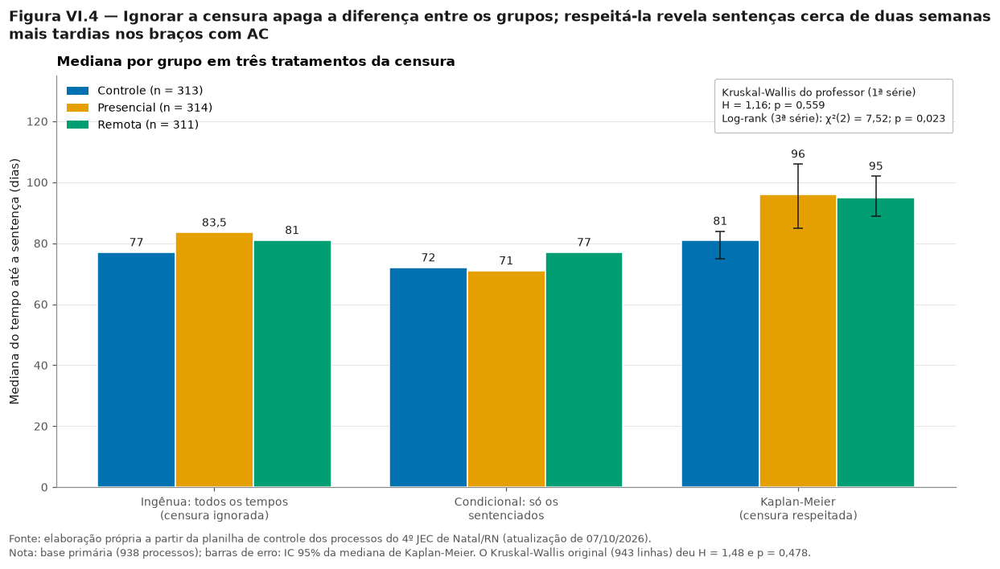

In [161]:
# ---- contraste de apoio: a mediana por grupo depende do tratamento da censura
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test
from lifelines.utils import median_survival_times
med = pd.DataFrame(index=ORDEM_GRUPO, dtype=float)
med_ic = {}
for g in ORDEM_GRUPO:
    s = q6[q6['grupo'] == g]
    med.loc[g, 'Ingênua: todos os tempos\n(censura ignorada)'] = s['tempo'].astype(float).median()
    med.loc[g, 'Condicional: só os\nsentenciados'] = s.loc[s['evento'].astype(int) == 1, 'tempo'].astype(float).median()
    kmf = KaplanMeierFitter().fit(s['tempo'].astype(float), s['evento'].astype(int))
    med.loc[g, 'Kaplan-Meier\n(censura respeitada)'] = kmf.median_survival_time_
    med_ic[g] = median_survival_times(kmf.confidence_interval_).to_numpy().ravel()
kw = stats.kruskal(*[q6.loc[q6['grupo'] == g, 'tempo'].astype(float) for g in ORDEM_GRUPO])
lr = multivariate_logrank_test(q6['tempo'].astype(float), q6['grupo'].astype(str), q6['evento'].astype(int))
tab_med = med.T
fig, ax = plt.subplots(figsize=(11, 5.6))
barras_agrupadas(ax, tab_med, cores=CORES_GRUPO, rotular=False, ylabel='Mediana do tempo até a sentença (dias)', legenda=False,
                 quebrar=40)
w_ = 0.8 / 3
for j, g in enumerate(ORDEM_GRUPO):
    for i in range(3):
        xi, vi = i + (j - 1) * w_, tab_med.iloc[i][g]
        topo_ = vi
        if i == 2:
            ax.errorbar(xi, vi, yerr=[[vi - med_ic[g][0]], [med_ic[g][1] - vi]], fmt='none', ecolor=TINTA, elinewidth=1, capsize=4)
            topo_ = med_ic[g][1]
        ax.annotate(fmt_br(vi, 0 if float(vi).is_integer() else 1), (xi, topo_), xytext=(0, 3), textcoords='offset points',
                    ha='center', va='bottom', fontsize=9, color=TINTA)
ax.set_ylim(0, 135)
ax.legend(handles=[mpl.patches.Patch(color=CORES_GRUPO[g], label=rotulo_grupo(g, com_n=True)) for g in ORDEM_GRUPO],
          loc='upper left', frameon=False)
anotar_teste(ax, texto_teste('Kruskal-Wallis do professor (1ª série)', f'H = {fmt_br(kw.statistic, 2)}', kw.pvalue,
                             extra=f'Log-rank (3ª série): χ²(2) = {fmt_br(lr.test_statistic, 2)}; p = {fmt_p(lr.p_value)}'),
             loc='upper right')
ax.set_title('Mediana por grupo em três tratamentos da censura')
figura(fig, 'q_censura_conclusao', 'Ignorar a censura apaga a diferença entre os grupos; respeitá-la revela sentenças '
       'cerca de duas semanas mais tardias nos braços com AC', secao='6.10',
       nota=f'base primária ({len(q6)} processos); barras de erro: IC 95% da mediana de Kaplan-Meier. O Kruskal-Wallis '
            'original (943 linhas) deu H = 1,48 e p = 0,478.')

**Resposta à questão 2.11.** Dos doze procedimentos do quadro, só um era adequado em si, o Kaplan-Meier com log-rank, e foi justamente o que não rodou (E1). O χ² do tipo de sentença tinha a ideia certa, mas precisou ser refeito. Os demais eram tautológicos (Mann-Whitney Encerrado × Ativo, matriz de r = 1), sem sentido substantivo (z com p₀ = 0,5) ou inválidos sob censura (Kruskal-Wallis, OLS, ajuste MLE, χ² de status).

A figura mostra por que isso importa. Com a censura ignorada, as medianas são 77, 83,5 e 81 dias e o Kruskal-Wallis não vê diferença (H = 1,16; p = 0,559 na base primária; p = 0,478 nas 943 linhas do professor). Restrito aos sentenciados, o quadro fica ainda mais "igual" (72, 71 e 77 dias). Com a censura respeitada, as medianas de Kaplan-Meier são 81, 96 e 95 dias, com intervalos de confiança que mal se tocam entre o Controle e os braços com AC, e o log-rank rejeita a igualdade (χ²(2) = 7,52; p = 0,023). O efeito existia; o teste escolhido é que o tornava invisível, porque os processos ainda ativos, mais longos e concentrados nos braços com AC, entravam como se tivessem terminado no dia do corte.

A lição para o TSHN é dupla: o teste deve corresponder à **estrutura dos dados** (censura, zeros estruturais, independência) e à **pergunta** (uma comparação de tempos censurados não é uma comparação de posições), e deve ser relatado com tamanho de efeito, intervalo e controle de multiplicidade. A alegação de "não diferença" do resumo expandido exigiria, ainda, um teste de equivalência e uma análise de poder (7.4.3).

## 6.11 Questão 2.12 — Avaliação geral da pesquisa e sugestões de validade

**Enunciado.** Concluir com uma avaliação geral da pesquisa empírica com levantamento de dados primários fidedignos, em especial do delineamento da coleta, com sugestões para conferir maior validade interna e externa a uma eventual replicação.

**Avaliação.** A pesquisa tem um mérito raro na pesquisa empírica em Direito no Brasil: é um **experimento de verdade**, com sorteio individual, controle contemporâneo e dados primários coletados diariamente na própria unidade, sobre uma questão de política judiciária relevante (a obrigatoriedade da AC inaugural nos JECs). Os dados são, no essencial, **fidedignos**: o dígito verificador do número CNJ confere em 100% dos casos, nenhuma sentença precede a distribuição, e a coerência entre acordo e tipo de sentença é perfeita (seção 1.14). Os problemas não estão na honestidade do registro, mas no **delineamento da coleta**, que foi pensado para tabelas dinâmicas de acompanhamento e não para análise estatística:

- a **variável-alvo foi mal definida** na própria planilha (duração dos ativos até `TODAY()`, "Decisão" como sentença), o que levou as médias divulgadas (78,46 e 75,2 dias) a misturar processos encerrados com processos ainda em curso (seção 2.1.2);
- **faltam as covariáveis** que o próprio projeto previa (tipo de ação, valor da causa, número de partes) e as **datas intermediárias** (AC, contestação, conclusão), que permitiriam decompor o tempo;
- **falta o motivo da extinção** sem mérito, justamente o desfecho que mais diferencia os grupos;
- o **mecanismo do sorteio** não foi documentado (o equilíbrio final é improvável num sorteio simples), as **reentradas foram re-sorteadas** e a **conciliadora coincide com a modalidade**;
- **não houve plano de análise**: o projeto previa apenas estatística descritiva, e o resumo expandido concluiu "não haver discrepância significativa" com base numa amplitude de 2,45 dias, sem teste, sem intervalo e sem considerar a censura.

**O que os dados, bem analisados, mostram.** Ao contrário da conclusão divulgada, a AC obrigatória **alongou** o tempo até a sentença (mediana de Kaplan-Meier 81 dias no Controle, 96 na Presencial e 95 na Remota), sobretudo porque **trocou sentenças de mérito por extinções sem mérito** e tornou as sentenças de mérito mais tardias, sem aumentar o acordo **na audiência** (5,1% × 4,6%). A Parte VII sintetiza esses achados com as estimativas e os intervalos.

O quadro abaixo avalia o delineamento item a item, no espírito da lista CONSORT, com a sugestão correspondente; as recomendações para a replicação estão consolidadas na seção 7.4.

In [162]:
quadro_aval = pd.DataFrame([
    ['Pergunta e hipóteses', 'parcial', 'hipóteses unilaterais no projeto; nenhum teste previsto; desfecho primário ambíguo',
     'pré-registrar desfecho primário (tempo até a sentença, com censura) e secundários (acordo, tipo de extinção)'],
    ['Geração da sequência de alocação', 'parcial', 'sorteio individual; equilíbrio final improvável (P ≈ 1%) → mecanismo restrito não documentado',
     'lista gerada por terceiro, em blocos permutados estratificados por mês, com semente registrada'],
    ['Ocultação da alocação', 'inadequado', 'sorteio feito no gabinete do juiz-pesquisador, processo a processo', 'central de aleatorização externa ao juízo'],
    ['Unicidade da unidade experimental', 'inadequado', 'reentradas re-sorteadas (A5)', 'regra: reentrada herda o grupo original'],
    ['Elegibilidade', 'parcial', 'redistribuições por prevenção sorteadas (24) e processos de outro órgão (12)', 'triagem de prevenção antes do sorteio'],
    ['Adesão ao tratamento', 'parcial', 'híbridas (28) e AC não realizadas sem motivo registrado', 'registrar comparecimento, formato e motivo da não realização'],
    ['Cegamento', 'inadequado', 'juiz sorteia, julga e analisa', 'análise cega ao grupo; desfecho extraído do PJe por terceiro'],
    ['Condutor da intervenção', 'inadequado', 'uma conciliadora por modalidade', 'rodízio ou várias conciliadoras por braço'],
    ['Medida do desfecho', 'parcial', 'datas digitadas; 18,4% de sentenças em fim de semana; TODAY() nos ativos', 'extrair datas dos movimentos do PJe/DataJud'],
    ['Covariáveis basais', 'inadequado', 'só a data de distribuição', 'tipo de ação, valor, nº de partes, litigante habitual, advogado'],
    ['Seguimento', 'parcial', '65 a 279 dias; 24,5% sem desfecho', 'seguimento mínimo comum (por exemplo, 180 dias) e análise de sobrevivência'],
    ['Tamanho da amostra e poder', 'inadequado', 'sem cálculo; poder ≈ 0,6 para o efeito observado (7.4)', 'cálculo de poder prévio para o desfecho primário'],
    ['Análise e relato', 'inadequado', 'amplitude de médias sem teste; sem IC', 'plano de análise ITT pré-registrado; relato CONSORT'],
    ['Fidedignidade do registro', 'adequado', 'CNJ 100% válido; 0 incoerências entre acordo e sentença; 0 datas invertidas', 'manter; acrescentar dicionário de dados'],
], columns=['Item do delineamento', 'Avaliação', 'Evidência', 'Sugestão para a replicação'])
cores_aval = {'adequado': '#E8F1E4', 'parcial': '#FFF4D6', 'inadequado': '#F9E1DC'}
tabela(quadro_aval, 'q_avaliacao', 'Avaliação do delineamento da coleta: registro fidedigno, mas desenho e plano de análise frágeis',
       secao='6.11', destaque=quadro_aval['Avaliação'].eq('inadequado').to_numpy(),
       nota='linhas destacadas: itens avaliados como inadequados.',
       fonte='Elaboração própria a partir das Partes I a V; itens inspirados na lista CONSORT.')

Item do delineamento,Avaliação,Evidência,Sugestão para a replicação
Pergunta e hipóteses,parcial,hipóteses unilaterais no projeto; nenhum teste previsto; desfecho primário ambíguo,"pré-registrar desfecho primário (tempo até a sentença, com censura) e secundários (acordo, tipo de extinção)"
Geração da sequência de alocação,parcial,sorteio individual; equilíbrio final improvável (P ≈ 1%) → mecanismo restrito não documentado,"lista gerada por terceiro, em blocos permutados estratificados por mês, com semente registrada"
Ocultação da alocação,inadequado,"sorteio feito no gabinete do juiz-pesquisador, processo a processo",central de aleatorização externa ao juízo
Unicidade da unidade experimental,inadequado,reentradas re-sorteadas (A5),regra: reentrada herda o grupo original
Elegibilidade,parcial,redistribuições por prevenção sorteadas (24) e processos de outro órgão (12),triagem de prevenção antes do sorteio
Adesão ao tratamento,parcial,híbridas (28) e AC não realizadas sem motivo registrado,"registrar comparecimento, formato e motivo da não realização"
Cegamento,inadequado,"juiz sorteia, julga e analisa",análise cega ao grupo; desfecho extraído do PJe por terceiro
Condutor da intervenção,inadequado,uma conciliadora por modalidade,rodízio ou várias conciliadoras por braço
Medida do desfecho,parcial,"datas digitadas; 18,4% de sentenças em fim de semana; TODAY() nos ativos",extrair datas dos movimentos do PJe/DataJud
Covariáveis basais,inadequado,só a data de distribuição,"tipo de ação, valor, nº de partes, litigante habitual, advogado"


**Resposta à questão 2.12.** O quadro de avaliação tem um padrão claro: o item **fidedignidade do registro** é o único avaliado como adequado sem ressalvas, e os itens inadequados concentram-se no **desenho da alocação** (ocultação, unicidade da unidade), na **execução** (cegamento, condutor da intervenção), nas **covariáveis** e no **plano de análise**. É o perfil de uma pesquisa feita com cuidado e boa-fé por quem conhece o processo, mas sem protocolo estatístico prévio: os dados primários são confiáveis naquilo que registram; o problema é o que **não** registram e como foram **analisados**.

A avaliação geral é, por isso, positiva quanto ao potencial e crítica quanto à execução. O experimento respondeu, com validade interna razoável, a uma pergunta relevante de política judiciária, e a resposta (a AC obrigatória alongou o tempo até a sentença e aumentou a extinção sem mérito, sem aumentar o acordo na audiência) é mais informativa do que a conclusão divulgada. Para conferir maior validade a uma replicação, as prioridades são: **interna**, ocultação e documentação do sorteio, rodízio das conciliadoras, cegamento da extração e registro do motivo da extinção; **externa**, várias unidades judiciais sorteadas; **estatística**, pré-registro do desfecho primário e cálculo de poder. O detalhamento está na seção 7.4.

# PARTE VII — SÍNTESE E CONCLUSÕES

Esta parte reúne os achados do notebook numa síntese executiva (7.1), com uma tabela-resumo das estimativas e dos intervalos de confiança e um gráfico dos efeitos (7.2); responde à pergunta de pesquisa (7.3); consolida as limitações e as recomendações para uma replicação, com um cálculo de poder (7.4); e lista as referências (7.6). Os números vêm das tabelas exportadas pelas Partes III a V; a seção de cada estimativa está indicada.

## 7.1 Síntese executiva

1. **Os números divulgados não medem a duração.** As médias de 78,46 dias (planilha) e de 75,2 dias (resumo expandido) misturam 708 sentenças com os tempos parciais de 206 processos ainda em tramitação e contam 24 redistribuições como desfecho; foram reconstituídas exatamente e nenhuma estima uma quantidade interpretável (seção 2.1.2). A duração mediana correta, pelo Kaplan-Meier, é de 89 dias para o conjunto (seção 4.2).
2. **A AC obrigatória alongou o tempo até a sentença.** Medianas de Kaplan-Meier de 81 dias no Controle, 96 na AC presencial e 95 na AC remota; log-rank p = 0,023. Ajustado pelo mês e pela origem, o Cox estima HR de 0,87 (0,72–1,04) para a Presencial e de 0,81 (0,67–0,97) para a Remota (sentença **mais lenta**); o tempo médio restrito a 180 dias é 10,7 dias maior na Remota (IC 1,9–19,5). A diferença concentra-se entre 30 e 90 dias, o intervalo em que a AC ocorre (seções 4.3 a 4.6).
3. **O mecanismo é a troca do tipo de desfecho.** Entre os sentenciados, a extinção sem mérito passa de 30,2% no Controle para 47,4% na Presencial e 45,4% na Remota (OR 2,09 e 1,92), e a sentença de mérito cai de 61,8% para 41,7% e 38,4%; as sentenças de mérito, quando ocorrem, chegam mais tarde (medianas condicionais de 83, 112,5 e 106 dias). O padrão é compatível com a extinção por ausência do autor à audiência obrigatória (art. 51, I, da Lei 9.099/1995), mas a planilha não registra o motivo da extinção (seções 3.2, 4.7).
4. **A audiência não aumentou o acordo na audiência.** O acordo na AC foi de 5,1% na Presencial e de 4,6% na Remota (Fisher p = 1,000), muito abaixo do índice histórico de 13,3% da unidade. O acordo em qualquer momento é maior na Remota que no Controle (OR ≈ 2,2 entre os encerrados; 2,7 até 120 dias), mas esse contraste não sobrevive à correção de Holm sobre a família completa de testes da Parte III, e a maior parte dos acordos da Remota ocorreu **fora** da audiência (seções 3.3, 5.2).
5. **Modalidade, técnica e híbrida não fizeram diferença detectável.** Presencial × Remota não difere no tempo (log-rank par a par p = 0,519) nem no acordo; as seis técnicas foram sorteadas de modo compatível com o uniforme (p = 0,566; os "53,85%" do resumo não se reproduzem) e não diferem no tempo; a AC híbrida não difere da presencial pura (seções 2.5.3, 3.3.4, 4.8).
6. **O desenho é um ECA válido internamente, mas de unidade única.** O sorteio passou nos testes possíveis (corridas, equilíbrio por mês), com indício de restrição não documentada; a conciliadora está confundida com a modalidade, o juiz-pesquisador não é cego e não há covariáveis do processo. A generalização aos 14 JECs não tem base estatística (seções 6.1 a 6.9).

In [163]:
if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')
import re
from scipy.stats import norm


def s7_csv(nome, pasta='tab', **kw):
    caminho = RAIZ / pasta / nome
    if not caminho.exists():
        print(f'Aviso: {pasta}/{nome} não encontrado (é gerado pelas Partes III a V).')
        return None
    opcoes = dict(sep=';', decimal=',', encoding='utf-8-sig')
    opcoes.update(kw)
    return pd.read_csv(caminho, **opcoes)


def s7_num(texto):
    """'0,87 (0,72–1,04)' → [0.87, 0.72, 1.04]."""
    return [float(x.replace(',', '.')) for x in re.findall(r'-?\d+(?:,\d+)?', str(texto))]


sint_sob = s7_csv('ed2_sintese_sobrevivencia.csv', pasta='dat/processado', index_col=0, decimal='.')
reg3 = s7_csv('ed2_parte3_testes.csv', pasta='dat/processado')
pares_tipo = s7_csv('tst_tipobin_pares.csv')
pares_120 = s7_csv('tst_acordo_horizonte_pares.csv')
tempo_tipo = s7_csv('tst_tempo_por_tipo.csv')
acordo_ac = s7_csv('tst_acordo_ac.csv')
logit_a = s7_csv('mul_logit_A_contrastes.csv')


def s7_holm(trecho):
    """p bruto e p Holm global do registro de testes da Parte III (pelo nome do teste)."""
    if reg3 is None:
        return np.nan, np.nan
    lin = reg3[reg3['Teste'].str.contains(trecho, regex=False)]
    return (float(lin['p'].iloc[0]), float(lin['p Holm global'].iloc[0])) if len(lin) else (np.nan, np.nan)


def s7_par(tipo, comp):
    lin = pares_tipo[(pares_tipo['Tipo'] == tipo) & (pares_tipo['Comparação'] == comp)].iloc[0]
    return lin


def s7_pct_xn(xn):
    x, n = (int(v) for v in str(xn).split('/'))
    return f'{pct_br(x / n, 1)} ({x}/{n})'

col_s = list(sint_sob.columns) if sint_sob is not None else []
linhas = []
if sint_sob is not None:
    for rot, chave, leitura, sec in [
        ('Tempo até a sentença', 'Mediana KM, dias (IC 95%)', 'maior = mais lento', '4.2.3'),
        ('Tempo até a sentença', 'RMST 180 d, dias (IC 95%)', 'dias sem sentença nos primeiros 180 d', '4.3.6'),
        ('Tempo até a sentença', 'ΔRMST 180 d vs. Controle (IC bootstrap)', '> 0 = mais lento que o Controle', '4.3.6'),
        ('Tempo até a sentença', 'HR Cox (b) (IC 95%)', '< 1 = sentença mais lenta; ajustado por mês e origem', '4.5.1'),
        ('Tempo até a sentença', 'Razão de tempos Weibull (IC 95%)', '> 1 = mais lento', '4.6'),
        ('Incidência acumulada aos 90 dias', 'FIA 90 d: Mérito', 'riscos competitivos (Aalen-Johansen)', '4.7.2'),
        ('Incidência acumulada aos 90 dias', 'FIA 90 d: Sem mérito', 'riscos competitivos (Aalen-Johansen)', '4.7.2'),
        ('Incidência acumulada aos 90 dias', 'FIA 90 d: Homologação', 'riscos competitivos (Aalen-Johansen)', '4.7.2'),
    ]:
        v = sint_sob.loc[chave]
        linhas.append([rot, chave.replace(' (IC 95%)', '').replace(' (IC bootstrap)', ''), v.iloc[0], v.iloc[1], v.iloc[2], leitura, sec])
if pares_tipo is not None:
    for tipo, rot in [('Sentença de mérito', 'Sentença de mérito'), ('Extinção sem mérito', 'Extinção sem mérito'),
                      ('Homologação de acordo', 'Homologação de acordo')]:
        lp, lr_ = s7_par(tipo, 'Presencial × Controle'), s7_par(tipo, 'Remota × Controle')
        celula = lambda l: (f'{s7_pct_xn(l["x/n (1º)"])}; OR {fmt_br(l["OR"], 2)} ({fmt_br(l["OR IC inf"], 2)}–'
                            f'{fmt_br(l["OR IC sup"], 2)}); p Holm {fmt_p(l["p Holm"])}')
        linhas.append(['Tipo de sentença (% dos sentenciados)', rot, s7_pct_xn(lp['x/n (2º)']), celula(lp), celula(lr_),
                       'OR contra o Controle; Fisher, Holm em 9 pares', '3.2.3'])
if tempo_tipo is not None:
    tm = tempo_tipo[tempo_tipo['Tipo'] == 'Sentença de mérito'].iloc[0]
    linhas.append(['Tempo condicional (sentenciados)', 'Mediana até a sentença de mérito (dias)',
                   fmt_br(tm['Mediana Controle (dias)'], 1), fmt_br(tm['Mediana Presencial (dias)'], 1), fmt_br(tm['Mediana Remota (dias)'], 1),
                   f'condicional; Kruskal-Wallis p Holm {fmt_p(tm["p Holm"])}', '3.4.5'])
if acordo_ac is not None:
    p_ac, ph_ac = s7_holm('Fisher acordo na AC: Presencial × Remota')
    a = acordo_ac.set_index('Grupo')
    cel = lambda g: f'{pct_br(a.loc[g, "Acordo na AC"] / (a.loc[g, "Acordo na AC"] + a.loc[g, "Sem acordo"]), 1)} ' \
                    f'({int(a.loc[g, "Acordo na AC"])}/{int(a.loc[g, "Acordo na AC"] + a.loc[g, "Sem acordo"])})'
    linhas.append(['Acordo', 'Acordo na AC (% das AC realizadas)', 'não se aplica (sem AC)', cel('Presencial'), cel('Remota'),
                   f'Presencial × Remota: Fisher p = {fmt_p(p_ac)}', '3.3.1'])
if pares_120 is not None:
    p_r, ph_r = s7_holm('Fisher acordo até 120 d: Remota × Controle')
    sub = pares_120[pares_120['Horizonte (dias)'] == 120].set_index('Comparação')
    cel = lambda c: f'{sub.loc[c, "1º"]}; OR {fmt_br(sub.loc[c, "OR"], 2)} ({sub.loc[c, "OR IC"].replace(" a ", "–")})'
    linhas.append(['Acordo', 'Acordo em qualquer momento até 120 dias', str(sub.loc['Presencial × Controle', '2º']),
                   cel('Presencial × Controle'), cel('Remota × Controle'),
                   f'Remota × Controle: p = {fmt_p(p_r)}; p Holm global (55 testes) = {fmt_p(ph_r)}', '3.3.2'])
if logit_a is not None:
    la = logit_a.set_index('Contraste')
    cel = lambda c: f'RC {fmt_br(la.loc[c, "RC"], 2)} ({fmt_br(la.loc[c, "IC 95% inf."], 2)}–{fmt_br(la.loc[c, "IC 95% sup."], 2)}); ' \
                    f'p Holm {fmt_p(la.loc[c, "p (Holm)"])}'
    linhas.append(['Acordo', 'Acordo entre os encerrados (logit ajustado pelo mês)', 'referência', cel('Presencial vs Controle'),
                   cel('Remota vs Controle'), 'Holm nos 3 contrastes do modelo', '5.2.1'])
resumo7 = pd.DataFrame(linhas, columns=['Dimensão', 'Estimativa', 'Controle (rito atual)', 'AC presencial', 'AC remota', 'Leitura', 'Seção'])
resumo7 = resumo7.set_index(['Dimensão', 'Estimativa'])
tabela(resumo7, 'sin_resumo', 'Síntese das estimativas: a AC obrigatória atrasa a sentença e troca mérito por extinção sem mérito, '
       'sem aumentar o acordo na audiência', secao='7.1', indice=True,
       nota='IC 95% entre parênteses; HR e razão de tempos contra o Controle; OR = razão de chances contra o Controle; '
            'FIA = função de incidência acumulada.', fonte='Elaboração própria a partir das tabelas exportadas pelas Partes III a V.')

**Leitura da tabela-resumo.** As estimativas formam um quadro coerente, em três camadas:

- **tempo**: todas as medidas que respeitam a censura apontam na mesma direção. Mediana de Kaplan-Meier de 81 dias no Controle contra 96 e 95 nos braços com AC; RMST em 180 dias de 82,1 contra 88,6 e 92,9 dias (ΔRMST da Remota 10,7 dias, IC 1,9 a 19,5); HR do Cox ajustado de 0,87 (0,72–1,04) e 0,81 (0,67–0,97); razão de tempos do Weibull de 1,11 e 1,21. O efeito é nítido para a Remota e na mesma direção, mas não significativo isoladamente, para a Presencial;
- **tipo de desfecho**: a incidência acumulada de sentença de mérito aos 90 dias cai de 31,1% no Controle para 7,8% e 7,5%, enquanto a de extinção sem mérito sobe de 23,5% para 32,0% e 27,3%. Entre os sentenciados, a extinção sem mérito passa de 30,2% para 47,4% e 45,4% (OR 2,09 e 1,92, ambos significativos após Holm), e as sentenças de mérito, quando ocorrem, chegam mais tarde (medianas condicionais de 83, 112,5 e 106 dias). É essa troca que explica o atraso global;
- **acordo**: o acordo **na audiência** é baixo e igual nas duas modalidades (5,1% e 4,6%; Fisher p = 1,000). O acordo em qualquer momento é maior na Remota: homologações 16,2% contra 8,0% dos sentenciados (OR 2,22; p Holm 0,033 na família de 9 pares), RC 2,15 no logit ajustado pelo mês (p Holm 0,027) e OR 2,70 até 120 dias. Na família completa dos 55 testes da Parte III, porém, o p de Holm global desse último contraste é 0,267: trata-se de um sinal **sugestivo**, não de um resultado robusto, e concentrado em acordos feitos fora da audiência.

## 7.2 Os efeitos num só gráfico

O gráfico de floresta resume, em escala logarítmica, os efeitos de cada braço com AC contra o Controle: à esquerda, os dois modelos de tempo (a razão de riscos do Cox, em que valores **abaixo** de 1 indicam sentença mais lenta, e a razão de tempos do Weibull, em que valores **acima** de 1 indicam processo mais longo); à direita, as razões de chances dos tipos de sentença e do acordo. A linha vertical marca a ausência de efeito; um intervalo que não a cruza é significativo a 5% antes da correção de multiplicidade.

C:\Users\MPGO\AppData\Local\Temp\ipykernel_10172\3358668381.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0.05, 1, 1))


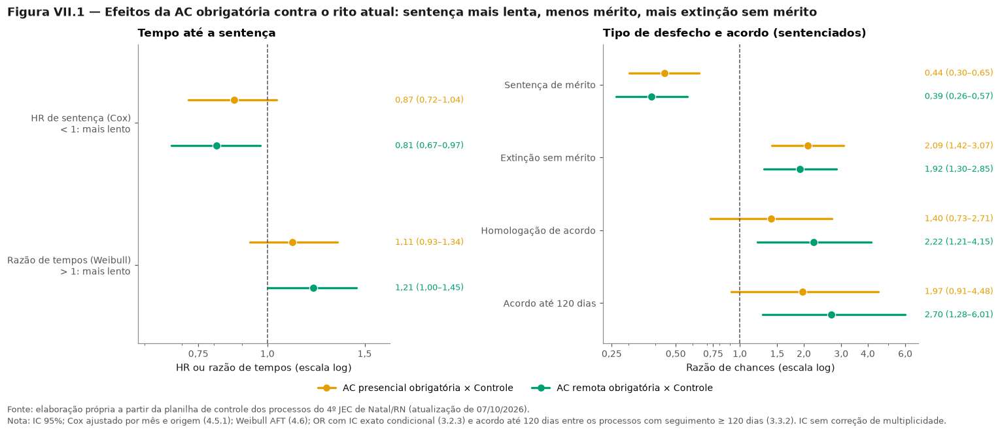

In [164]:
if sint_sob is not None and pares_tipo is not None and pares_120 is not None:
    efeitos_t = []
    for chave, nome in [('HR Cox (b) (IC 95%)', 'HR de sentença (Cox)\n< 1: mais lento'),
                        ('Razão de tempos Weibull (IC 95%)', 'Razão de tempos (Weibull)\n> 1: mais lento')]:
        for g, col in zip(['Presencial', 'Remota'], col_s[1:]):
            est, lo, hi = s7_num(sint_sob.loc[chave, col])[:3]
            efeitos_t.append((nome, g, est, lo, hi))
    efeitos_o = []
    for tipo, nome in [('Sentença de mérito', 'Sentença de mérito'), ('Extinção sem mérito', 'Extinção sem mérito'),
                       ('Homologação de acordo', 'Homologação de acordo')]:
        for g in ['Presencial', 'Remota']:
            l = s7_par(tipo, f'{g} × Controle')
            efeitos_o.append((nome, g, l['OR'], l['OR IC inf'], l['OR IC sup']))
    sub120 = pares_120[pares_120['Horizonte (dias)'] == 120].set_index('Comparação')
    for g in ['Presencial', 'Remota']:
        lo, hi = s7_num(sub120.loc[f'{g} × Controle', 'OR IC'])
        efeitos_o.append(('Acordo até 120 dias', g, sub120.loc[f'{g} × Controle', 'OR'], lo, hi))

    fig, axs = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={'width_ratios': [1, 1.25], 'wspace': 0.75})
    for ax, efeitos, titulo, xlab in [(axs[0], efeitos_t, 'Tempo até a sentença', 'HR ou razão de tempos (escala log)'),
                                      (axs[1], efeitos_o, 'Tipo de desfecho e acordo (sentenciados)', 'Razão de chances (escala log)')]:
        nomes = list(dict.fromkeys(e[0] for e in efeitos))
        ypos = {}
        for i, nome in enumerate(nomes):
            for j, g in enumerate(['Presencial', 'Remota']):
                ypos[(nome, g)] = i * 1.0 + (j - 0.5) * 0.32
        for nome, g, est, lo, hi in efeitos:
            y = ypos[(nome, g)]
            ax.plot([lo, hi], [y, y], color=CORES_GRUPO[g], lw=2.2)
            ax.plot(est, y, 'o', color=CORES_GRUPO[g], ms=8, mec='white', mew=0.8)
            ax.text(1.02, y, f'{fmt_br(est, 2)} ({fmt_br(lo, 2)}–{fmt_br(hi, 2)})', transform=ax.get_yaxis_transform(),
                    va='center', ha='left', fontsize=8.5, color=CORES_GRUPO[g])
        ax.axvline(1, color=TINTA_2, lw=1, ls='--')
        ax.set_xscale('log')
        ax.set_yticks(range(len(nomes)), nomes)
        ax.set_xlabel(xlab)
        ax.set_title(titulo)
        lo_all = min(e[3] for e in efeitos); hi_all = max(e[4] for e in efeitos)
        ax.set_xlim(lo_all / 1.15, hi_all * 1.15)
        ax.set_ylim(len(nomes) - 0.45, -0.55)
        ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: fmt_br(v, 2 if v < 1 else 1)))
        ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
        ticks = [t for t in [0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 6] if lo_all / 1.15 <= t <= hi_all * 1.15]
        ax.set_xticks(ticks)
        ax.grid(axis='y', visible=False)
    fig.legend(handles=[mpl.lines.Line2D([], [], color=CORES_GRUPO[g], marker='o', lw=2.2, label=f'{ROTULO_GRUPO[g]} × Controle')
                        for g in ['Presencial', 'Remota']], loc='lower center', ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.04))
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    figura(fig, 'sin_forest', 'Efeitos da AC obrigatória contra o rito atual: sentença mais lenta, menos mérito, mais extinção sem mérito',
           secao='7.2', nota='IC 95%; Cox ajustado por mês e origem (4.5.1); Weibull AFT (4.6); OR com IC exato condicional '
                             '(3.2.3) e acordo até 120 dias entre os processos com seguimento ≥ 120 dias (3.3.2). IC sem correção de multiplicidade.')

**Leitura do gráfico.** No painel do tempo, os dois braços com AC ficam do lado "mais lento" da linha de nulidade nos dois modelos; só o intervalo da Remota a exclui (HR 0,81; razão de tempos 1,21, com limite inferior em 1,00). No painel dos desfechos, os efeitos mais fortes e consistentes são os da **troca de tipo de sentença**: as razões de chances de mérito (0,44 e 0,39) e de extinção sem mérito (2,09 e 1,92) excluem 1 com folga nos dois braços, e as duas modalidades praticamente se sobrepõem. Os intervalos do acordo (homologação e acordo até 120 dias) são largos e só excluem 1 para a Remota, o que reflete o pequeno número de acordos (81 homologações no total) e reforça a leitura de que o efeito sobre o acordo é incerto. A semelhança entre Presencial e Remota em todos os desfechos sugere que o que importa é a **obrigatoriedade** da audiência, e não a sua modalidade, com a ressalva de que a modalidade está confundida com a conciliadora.

## 7.3 Resposta à pergunta de pesquisa

**A audiência de conciliação obrigatória, presencial ou remota, reduz o tempo de tramitação no 4º JEC de Natal em relação ao rito atual? Aumenta os acordos?**

**Não, nas duas perguntas.** Com os dados até 07/10/2026 e uma análise que respeita a censura, a AC obrigatória **aumentou** o tempo até a sentença em cerca de duas semanas na mediana (81 dias no rito atual contra 95 e 96 dias nos braços com AC), com evidência mais forte para a modalidade remota (HR ajustado 0,81; IC 0,67–0,97; ΔRMST de 10,7 dias em 180). A hipótese H1 do projeto ("a audiência obrigatória reduz o tempo médio de tramitação") é, portanto, **contrariada** pelos dados, e não apenas não confirmada. A conclusão do resumo expandido, de que não haveria "discrepância significativa" entre os ritos, decorre de médias que ignoram a censura e não resiste à análise correta (6.10).

Quanto ao acordo (H2), a AC obrigatória **não aumentou o acordo na audiência**, que ficou em torno de 5% das audiências realizadas em ambas as modalidades, e o excesso de acordos da Remota em relação ao Controle é **sugestivo, mas não robusto** à correção de multiplicidade e ocorre sobretudo fora da audiência. Quanto à modalidade (H3), presencial e remota **não diferem** em tempo nem em acordo, mas a comparação está confundida com a conciliadora. As hipóteses H4 (híbrida) e H5 (CEJUSC × vara) **não são testáveis** neste desenho (6.3, 6.7).

O achado juridicamente mais relevante é o **mecanismo**: a AC obrigatória funcionou menos como espaço de autocomposição e mais como **ocasião de extinção sem mérito** (de 30% para cerca de 46% das sentenças), compatível com o art. 51, I, da Lei 9.099/1995, enquanto as sentenças de mérito chegaram mais tarde. Do ponto de vista da política judiciária, o resultado sugere que, nesta unidade e neste período, a obrigatoriedade da AC acrescentou uma etapa ao rito sem produzir o ganho de conciliação que a justificaria. Esse resultado vale **para o 4º JEC**; a sua extensão aos demais JECs depende da comparação observacional da Parte VIII e, para a validade externa propriamente dita, de replicação.

**Confirmação pelo DataJud (Parte VIII).** A conferência processo a processo com a API pública do CNJ vinculou 926 dos 938 processos e reproduziu a planilha com alta fidedignidade (tipo de desfecho: κ = 0,971; datas de sentença iguais em cerca de 98%); as sentenças em fim de semana são reais. Estendendo o seguimento até 06/11/2026, 81 dos 206 processos censurados foram sentenciados, e os efeitos **aumentaram**: HR da AC remota de 0,81 para 0,76 (IC 95% 0,64–0,90; p = 0,002) e ΔRMST180 de 10,7 para 14,0 dias (IC 5,0–22,1). A análise principal era, portanto, conservadora. O grupo Controle de 2026 se comportou como o 4º JEC de 2025 (RMST180 80,4 × 79,7 dias), o que não indica mudança da unidade por efeito do próprio experimento; e a média "anterior" de 106,8 dias citada no projeto não se reproduz no DataJud (93,0 dias para os sentenciados nos 12 meses anteriores). A comparação com os outros 13 JECs de Natal ficou parcial por indisponibilidade da API.

## 7.4 Limitações e recomendações para a replicação

### 7.4.1 Limitações deste estudo

- **Unidade única e escolhida por conveniência**: sem inferência estatística para os 14 JECs (6.9).
- **Conciliadora confundida com a modalidade**: Presencial × Remota não separa a modalidade da pessoa (6.7).
- **Juiz-pesquisador não cego e reatividade da equipe**: não verificáveis com a planilha.
- **Seguimento curto e escalonado** (65 a 279 dias; 24,5% sem desfecho): a cauda da distribuição não é estimável; por isso se usaram a mediana de Kaplan-Meier e o RMST até 180 dias.
- **Ausência de covariáveis do processo** e de datas intermediárias: impede verificar o equilíbrio, decompor o tempo e explicar o mecanismo (Parte V).
- **Motivo da extinção sem mérito não registrado**: a leitura pelo art. 51, I, é plausível, mas não demonstrada.
- **Data da sentença possivelmente de lançamento** (18,4% em fins de semana): sem efeito nas conclusões (4.9), mas a validar no DataJud.
- **Riscos não proporcionais**: o efeito do rito concentra-se entre 30 e 90 dias (4.5.2), de modo que um único HR resume mal o efeito; o RMST e as curvas são a leitura preferível.
- **Mecanismo do sorteio não documentado**: o equilíbrio final é improvável num sorteio simples (P ≈ 1%), o que indica restrição; a análise estratificada por mês mitiga, mas não substitui a documentação.

### 7.4.2 Recomendações

O quadro consolida as recomendações para uma replicação, cada uma ligada ao problema que resolve e ao tipo de validade que fortalece. O cálculo de poder que o segue mostra que o próprio experimento, com o efeito observado, tinha poder modesto.

In [165]:
quadro_rec = pd.DataFrame([
    ['Hipóteses e análise definidas depois dos dados', 'pré-registro do protocolo (desfecho primário, secundários, plano de análise ITT, regras de exclusão)',
     'registro público antes do 1º sorteio; relato CONSORT', 'interna; credibilidade'],
    ['Desfecho primário ambíguo; médias com censura', 'desfecho primário = tempo até a sentença, com censura; estimandos: mediana de KM, RMST(τ), HR',
     'τ e data de corte fixados no protocolo', 'interna; estatística'],
    ['Poder não calculado', 'cálculo de poder para o desfecho primário', 'eventos necessários pela fórmula de Schoenfeld (7.4.3)', 'estatística'],
    ['Sorteio sem documentação; equilíbrio improvável', 'lista de aleatorização em blocos permutados, estratificada por mês, gerada por terceiro',
     'semente registrada; ocultação (central externa ao juízo)', 'interna'],
    ['Reentradas re-sorteadas; prevenção sorteada', 'regras de elegibilidade e de reentrada', 'triagem de prevenção antes do sorteio; reentrada herda o grupo', 'interna'],
    ['Conciliadora confundida com a modalidade', 'rodízio das conciliadoras entre modalidades (ou várias por braço)',
     'escala de rodízio sorteada por semana', 'interna; constructo'],
    ['Juiz-pesquisador não cego', 'cegamento da extração e da análise', 'desfecho extraído do PJe/DataJud por terceiro; análise com grupos codificados', 'interna'],
    ['Sem covariáveis nem datas intermediárias', 'coleta das covariáveis basais e das datas de citação, AC, contestação e conclusão',
     'extração automática do PJe/DataJud pelo número CNJ', 'interna; precisão'],
    ['Motivo da extinção e comparecimento não registrados', 'registrar comparecimento de cada parte, formato real da AC e motivo da extinção',
     'campos fechados na planilha (lista de validação)', 'constructo; mecanismo'],
    ['Seguimento curto e escalonado', 'seguimento mínimo comum para todos', 'por exemplo, 180 dias após o último sorteio', 'estatística'],
    ['Mês como confundidor de calendário', 'estratificação por mês no sorteio e na análise', 'blocos por mês; Cox estratificado', 'interna'],
    ['Unidade única (N = 1)', 'ensaio multicêntrico por conglomerados ou escalonado (stepped-wedge) entre JECs',
     'adesão das unidades via TJRN/NUPEMEC; sorteio das unidades e do momento de entrada', 'externa'],
    ['Efeito do experimento sobre a unidade desconhecido', 'comparação com o período anterior e com os outros JECs',
     'diferenças em diferenças com o DataJud (Parte VIII)', 'interna (reatividade); externa'],
], columns=['Problema encontrado', 'Recomendação', 'Como implementar', 'Validade fortalecida'])
tabela(quadro_rec, 'sin_recomendacoes', 'Recomendações para a replicação do experimento', secao='7.4',
       fonte='Elaboração própria a partir das Partes I a VI.')

Problema encontrado,Recomendação,Como implementar,Validade fortalecida
Hipóteses e análise definidas depois dos dados,"pré-registro do protocolo (desfecho primário, secundários, plano de análise ITT, regras de exclusão)",registro público antes do 1º sorteio; relato CONSORT,interna; credibilidade
Desfecho primário ambíguo; médias com censura,"desfecho primário = tempo até a sentença, com censura; estimandos: mediana de KM, RMST(τ), HR",τ e data de corte fixados no protocolo,interna; estatística
Poder não calculado,cálculo de poder para o desfecho primário,eventos necessários pela fórmula de Schoenfeld (7.4.3),estatística
Sorteio sem documentação; equilíbrio improvável,"lista de aleatorização em blocos permutados, estratificada por mês, gerada por terceiro",semente registrada; ocultação (central externa ao juízo),interna
Reentradas re-sorteadas; prevenção sorteada,regras de elegibilidade e de reentrada,triagem de prevenção antes do sorteio; reentrada herda o grupo,interna
Conciliadora confundida com a modalidade,rodízio das conciliadoras entre modalidades (ou várias por braço),escala de rodízio sorteada por semana,interna; constructo
Juiz-pesquisador não cego,cegamento da extração e da análise,desfecho extraído do PJe/DataJud por terceiro; análise com grupos codificados,interna
Sem covariáveis nem datas intermediárias,"coleta das covariáveis basais e das datas de citação, AC, contestação e conclusão",extração automática do PJe/DataJud pelo número CNJ,interna; precisão
Motivo da extinção e comparecimento não registrados,"registrar comparecimento de cada parte, formato real da AC e motivo da extinção",campos fechados na planilha (lista de validação),constructo; mecanismo
Seguimento curto e escalonado,seguimento mínimo comum para todos,"por exemplo, 180 dias após o último sorteio",estatística


### 7.4.3 Cálculo de poder: quantos eventos seriam necessários?

Para comparar dois braços 1:1 com um modelo de riscos proporcionais, o número de **eventos** (sentenças) necessário para detectar uma razão de riscos HR, com nível α bilateral e poder 1 − β, é dado pela fórmula de Schoenfeld (1983): d = 4(z₁₋α/₂ + z₁₋β)² / (ln HR)². Inversamente, com d eventos, o poder para um HR verdadeiro é Φ(√(d/4)·|ln HR| − z₁₋α/₂). Para o acordo na AC, uma proporção baixa (cerca de 5%), o tamanho por grupo para detectar a diferença entre p₁ e p₂ usa a transformação arco-seno, h = 2·arcsen√p₂ − 2·arcsen√p₁, com n = 2[(z₁₋α/₂ + z₁₋β)/h]² processos com AC realizada por braço. Os cálculos usam α = 5% e poder de 80%; com a correção de Holm para duas comparações contra o Controle, o α efetivo da primeira comparação cai para 2,5%, o que aumenta as exigências em cerca de 20%.

Desfecho,Efeito a detectar,Necessário (α = 5%),"Necessário (α = 2,5%, Holm)",Disponível no estudo,Poder com o disponível
"Tempo até a sentença (Cox, 1:1)","HR = 0,90",2.828,3.425,478,"20,9%"
"Tempo até a sentença (Cox, 1:1)","HR = 0,85",1.189,1.439,478,"42,7%"
"Tempo até a sentença (Cox, 1:1)","HR = 0,80",631,764,478,"68,4%"
"Tempo até a sentença (Cox, 1:1)","HR = 0,75",379,459,478,"88,2%"
"Tempo até a sentença (Cox, 1:1)","HR observado Presencial = 0,87",1.619,1.960,492,"33,9%"
"Tempo até a sentença (Cox, 1:1)","HR observado Remota = 0,81",707,856,478,"63,4%"
Acordo na AC (proporções),"4,8% → 10,0%",391,474,174,"46,4%"
Acordo na AC (proporções),"4,8% → 13,3%",170,206,174,"80,8%"
Acordo na AC (proporções),"4,8% → 20,0%",67,81,174,"99,5%"


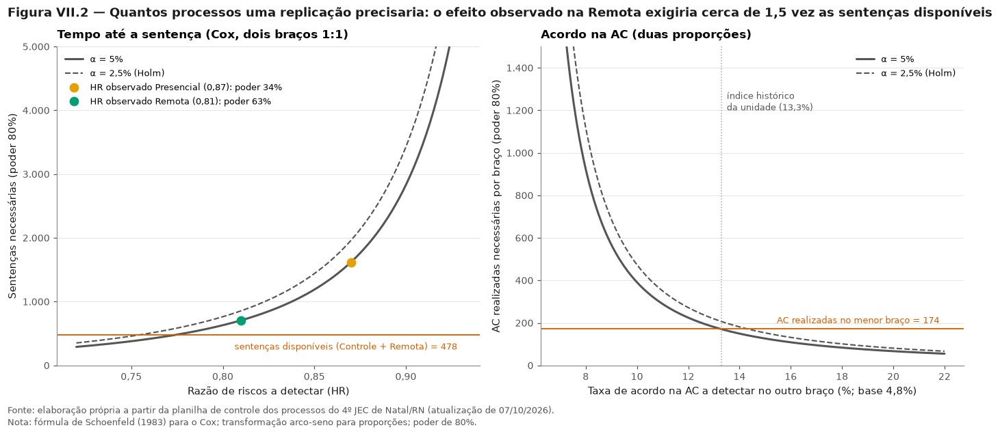

In [166]:
za, zb = norm.ppf(0.975), norm.ppf(0.80)
eventos_nec = lambda hr, a=0.05, pw=0.80: 4 * (norm.ppf(1 - a / 2) + norm.ppf(pw)) ** 2 / np.log(hr) ** 2
poder_cox = lambda d, hr, a=0.05: norm.cdf(np.sqrt(d / 4) * abs(np.log(hr)) - norm.ppf(1 - a / 2))
h_arc = lambda p1, p2: abs(2 * np.arcsin(np.sqrt(p2)) - 2 * np.arcsin(np.sqrt(p1)))
n_prop = lambda p1, p2, a=0.05, pw=0.80: 2 * ((norm.ppf(1 - a / 2) + norm.ppf(pw)) / h_arc(p1, p2)) ** 2
poder_prop = lambda n, p1, p2, a=0.05: norm.cdf(np.sqrt(n / 2) * h_arc(p1, p2) - norm.ppf(1 - a / 2))

ev = dados.groupby('grupo', observed=True)['evento'].apply(lambda s: int(s.astype(int).sum())).reindex(ORDEM_GRUPO)
d_pc, d_rc = int(ev['Controle'] + ev['Presencial']), int(ev['Controle'] + ev['Remota'])
acr = dados[dados['ac_realizada'].fillna(False).astype(bool)]
n_ac = acr.groupby('grupo', observed=True).size().reindex(['Presencial', 'Remota'])
k_ac = acr.groupby('grupo', observed=True)['acordo_ac'].apply(lambda s: int(s.fillna(False).astype(bool).sum())).reindex(['Presencial', 'Remota'])
p_base = k_ac.sum() / n_ac.sum()
hr_obs = {}
if sint_sob is not None:
    for g, col in zip(['Presencial', 'Remota'], col_s[1:]):
        hr_obs[g] = s7_num(sint_sob.loc['HR Cox (b) (IC 95%)', col])[0]

linhas_p = []
for hr in [0.90, 0.85, 0.80, 0.75]:
    linhas_p.append(['Tempo até a sentença (Cox, 1:1)', f'HR = {fmt_br(hr, 2)}', eventos_nec(hr), eventos_nec(hr, a=0.025),
                     d_rc, poder_cox(d_rc, hr)])
for g, d in [('Presencial', d_pc), ('Remota', d_rc)]:
    if g in hr_obs:
        linhas_p.append(['Tempo até a sentença (Cox, 1:1)', f'HR observado {g} = {fmt_br(hr_obs[g], 2)}', eventos_nec(hr_obs[g]),
                         eventos_nec(hr_obs[g], a=0.025), d, poder_cox(d, hr_obs[g])])
n_disp = int(n_ac.min())
for p2 in [0.10, 0.133, 0.20]:
    linhas_p.append(['Acordo na AC (proporções)', f'{pct_br(p_base, 1)} → {pct_br(p2, 1)}', n_prop(p_base, p2), n_prop(p_base, p2, a=0.025),
                     n_disp, poder_prop(n_disp, p_base, p2)])
poder_df = pd.DataFrame(linhas_p, columns=['Desfecho', 'Efeito a detectar', 'Necessário (α = 5%)', 'Necessário (α = 2,5%, Holm)',
                                           'Disponível no estudo', 'Poder com o disponível'])
tabela(poder_df, 'sin_poder', 'Poder do experimento: cerca de 60% para o efeito observado sobre o tempo; no acordo na AC, só diferenças grandes eram detectáveis',
       secao='7.4.3', formatos={'Necessário (α = 5%)': 0, 'Necessário (α = 2,5%, Holm)': 0, 'Disponível no estudo': 'int',
                                 'Poder com o disponível': 'pct'},
       nota=f'tempo: número de sentenças nos dois braços comparados (Controle + Remota = {d_rc}; Controle + Presencial = {d_pc}); '
            f'acordo: AC realizadas por braço (menor braço = {n_disp}); taxa-base de acordo na AC = {pct_br(p_base, 1)} '
            f'({int(k_ac.sum())}/{int(n_ac.sum())}); 13,3% = índice histórico da unidade. Poder com α = 5%.',
       fonte='Elaboração própria; fórmula de Schoenfeld (1983) e aproximação arco-seno para proporções.')

fig, axs = plt.subplots(1, 2, figsize=(13, 5.2))
hrs = np.linspace(0.72, 0.93, 200)
ax = axs[0]
ax.plot(hrs, eventos_nec(hrs), color=TINTA_2, lw=2, label='α = 5%')
ax.plot(hrs, eventos_nec(hrs, a=0.025), color=TINTA_2, lw=1.4, ls='--', label='α = 2,5% (Holm)')
ax.axhline(d_rc, color=DESTAQUE, lw=1.2)
ax.annotate(f'sentenças disponíveis (Controle + Remota) = {d_rc}', (0.928, d_rc), xytext=(0, -14), textcoords='offset points',
            fontsize=8.5, color=DESTAQUE, ha='right')
for g in hr_obs:
    ax.plot(hr_obs[g], eventos_nec(hr_obs[g]), 'o', color=CORES_GRUPO[g], ms=8,
            label=f'HR observado {g} ({fmt_br(hr_obs[g], 2)}): poder {pct_br(poder_cox(d_rc if g == "Remota" else d_pc, hr_obs[g]), 0)}')
ax.set_ylim(0, 5000)
ax.set_xlabel('Razão de riscos a detectar (HR)'); ax.set_ylabel('Sentenças necessárias (poder 80%)')
ax.set_title('Tempo até a sentença (Cox, dois braços 1:1)')
ax.legend(loc='upper left', fontsize=8.5)
ax = axs[1]
p2s = np.linspace(0.07, 0.22, 200)
ax.plot(p2s * 100, n_prop(p_base, p2s), color=TINTA_2, lw=2, label='α = 5%')
ax.plot(p2s * 100, n_prop(p_base, p2s, a=0.025), color=TINTA_2, lw=1.4, ls='--', label='α = 2,5% (Holm)')
ax.axhline(n_disp, color=DESTAQUE, lw=1.2)
ax.annotate(f'AC realizadas no menor braço = {n_disp}', (21.8, n_disp), xytext=(0, 5), textcoords='offset points',
            fontsize=8.5, color=DESTAQUE, ha='right')
ax.axvline(13.3, color=CINZA, lw=1, ls=':')
ax.annotate('índice histórico\nda unidade (13,3%)', (13.3, 1200), xytext=(5, 0), textcoords='offset points', fontsize=8.5, color=TINTA_2)
ax.set_ylim(0, 1500)
ax.set_xlabel(f'Taxa de acordo na AC a detectar no outro braço (%; base {pct_br(p_base, 1)})')
ax.set_ylabel('AC realizadas necessárias por braço (poder 80%)')
ax.set_title('Acordo na AC (duas proporções)')
ax.legend(loc='upper right', fontsize=8.5)
figura(fig, 'sin_poder', 'Quantos processos uma replicação precisaria: o efeito observado na Remota exigiria cerca de 1,5 vez as sentenças disponíveis',
       secao='7.4.3', nota='fórmula de Schoenfeld (1983) para o Cox; transformação arco-seno para proporções; poder de 80%.')

**Leitura do cálculo de poder.** Com 478 sentenças nos braços Controle e Remota, o experimento tinha 63% de poder para detectar o HR efetivamente observado (0,81) e 34% para o da Presencial (0,87, com 492 sentenças); detectar o HR da Remota com 80% de poder exigiria 707 sentenças (856 com a correção de Holm), cerca de 1,5 vez as disponíveis, e o da Presencial, 1.619. Isso tem duas consequências. Primeiro, o resultado significativo da Remota não é artefato de excesso de poder: é um efeito de tamanho moderado, detectado com poder apenas razoável. Segundo, a ausência de significância da Presencial **não** autoriza concluir que ela não atrasa a sentença: o experimento simplesmente não tinha poder para efeitos desse tamanho.

No acordo na AC, com 174 audiências realizadas no menor braço e taxa-base de 4,8%, só diferenças grandes eram detectáveis: o poder seria de 46% para chegar a 10% de acordos e de 81% para atingir o índice histórico da unidade (13,3%). Uma replicação que pretenda comparar técnicas ou modalidades quanto ao acordo na audiência precisa, portanto, de algumas centenas de audiências por braço, e deve definir no protocolo qual diferença é relevante para a política judiciária.

## 7.5 Considerações finais

O experimento do 4º JEC de Natal é uma contribuição valiosa justamente porque é um experimento: o sorteio permitiu responder a uma pergunta causal que estudos observacionais sobre a conciliação raramente conseguem responder. A resposta, porém, é a oposta da que os autores anunciaram: a obrigatoriedade da AC inaugural **não acelerou** os processos e **não aumentou** a conciliação na audiência; alongou o tempo até a sentença e transformou parte das sentenças de mérito em extinções sem mérito. A divergência não vem dos dados, que são fidedignos, mas da **análise**: médias calculadas sobre processos ainda em curso, sem tratamento da censura, sem teste e sem intervalo. O exercício mostra, assim, o valor da ciência de dados aplicada ao Direito: os mesmos registros, tratados com os métodos adequados (curadoria explícita, análise de sobrevivência, riscos competitivos e controle de multiplicidade), mudam a conclusão sobre uma política judiciária.

A replicação deve preservar o que o experimento fez bem (sorteio individual, controle contemporâneo, registro diário) e corrigir o que limitou a sua validade: pré-registro, aleatorização documentada e estratificada, rodízio das conciliadoras, cegamento da extração, coleta das covariáveis e do motivo da extinção, seguimento comum e, sobretudo, várias unidades judiciais.

## 7.6 Referências

AALEN, O. O.; JOHANSEN, S. An empirical transition matrix for non-homogeneous Markov chains based on censored observations. **Scandinavian Journal of Statistics**, v. 5, n. 3, p. 141-150, 1978.

ALENCAR, P. G. M. de. **Impacto da audiência de conciliação no tempo de tramitação dos processos do 4º JEC de Natal/RN**: efeitos do art. 334 do CPC e das mudanças impostas pela pandemia da Covid-19. Projeto de pesquisa (Mestrado Profissional em Direito e Políticas Públicas) — Universidade Federal de Goiás, Goiânia, 2026.

ALENCAR, P. G. M. de; NEVES, C. B. das. Eficácia da conciliação obrigatória na tramitação processual: um experimento no 4º Juizado Especial Cível de Natal (2026). In: ENCONTRO DE ADMINISTRAÇÃO DA JUSTIÇA (ENAJUS), Goiânia, 2026. **Resumo expandido**.

ARTES, R.; BARROSO, L. P. **Métodos multivariados de análise estatística**. São Paulo: Blucher, 2023.

AUSTIN, P. C.; LEE, D. S.; FINE, J. P. Introduction to the analysis of survival data in the presence of competing risks. **Circulation**, v. 133, n. 6, p. 601-609, 2016.

BARBETTA, P. A.; REIS, M. M.; BORNIA, A. C. **Estatística para cursos de engenharia e informática**. São Paulo: Atlas, 2020.

BECKER, J. L. **Estatística básica**: transformando dados em informação. Porto Alegre: Bookman, 2015.

BENJAMINI, Y.; HOCHBERG, Y. Controlling the false discovery rate: a practical and powerful approach to multiple testing. **Journal of the Royal Statistical Society: Series B**, v. 57, n. 1, p. 289-300, 1995.

BRASIL. Conselho Nacional de Justiça. **API Pública do DataJud**: documentação. Brasília: CNJ, [2023]. Disponível em: https://datajud-wiki.cnj.jus.br/api-publica/. Acesso em: 12 nov. 2026.

BRASIL. Conselho Nacional de Justiça. **Justiça em Números 2026**: ano-base 2025. Brasília: CNJ, 2026. Disponível em: https://www.cnj.jus.br/pesquisas-judiciarias/justica-em-numeros/. Acesso em: 12 nov. 2026.

BRASIL. Conselho Nacional de Justiça. Resolução nº 125, de 29 de novembro de 2010. Dispõe sobre a Política Judiciária Nacional de tratamento adequado dos conflitos de interesses no âmbito do Poder Judiciário. Brasília: CNJ, 2010.

BRASIL. Lei nº 9.099, de 26 de setembro de 1995. Dispõe sobre os Juizados Especiais Cíveis e Criminais. **Diário Oficial da União**, Brasília, 27 set. 1995.

BRASIL. Lei nº 13.105, de 16 de março de 2015. Código de Processo Civil. **Diário Oficial da União**, Brasília, 17 mar. 2015.

BRASIL. Lei nº 13.994, de 24 de abril de 2020. Altera a Lei nº 9.099, de 26 de setembro de 1995, para possibilitar a conciliação não presencial no âmbito dos Juizados Especiais Cíveis. **Diário Oficial da União**, Brasília, 27 abr. 2020.

BROOKMEYER, R.; CROWLEY, J. A confidence interval for the median survival time. **Biometrics**, v. 38, n. 1, p. 29-41, 1982.

COLOSIMO, E. A.; GIOLO, S. R. **Análise de sobrevivência aplicada**. São Paulo: Blucher, 2006. (Projeto Fisher.)

COX, D. R. Regression models and life-tables. **Journal of the Royal Statistical Society: Series B**, v. 34, n. 2, p. 187-220, 1972.

DAVIDSON-PILON, C. lifelines: survival analysis in Python. **Journal of Open Source Software**, v. 4, n. 40, p. 1317, 2019.

EFRON, B. The efficiency of Cox's likelihood function for censored data. **Journal of the American Statistical Association**, v. 72, n. 359, p. 557-565, 1977.

FINE, J. P.; GRAY, R. J. A proportional hazards model for the subdistribution of a competing risk. **Journal of the American Statistical Association**, v. 94, n. 446, p. 496-509, 1999.

FLEMING, T. R.; HARRINGTON, D. P. **Counting processes and survival analysis**. New York: Wiley, 1991.

GESKUS, R. B. Cause-specific cumulative incidence estimation and the Fine and Gray model under both left truncation and right censoring. **Biometrics**, v. 67, n. 1, p. 39-49, 2011.

GRAMBSCH, P. M.; THERNEAU, T. M. Proportional hazards tests and diagnostics based on weighted residuals. **Biometrika**, v. 81, n. 3, p. 515-526, 1994.

GRAY, R. J. A class of K-sample tests for comparing the cumulative incidence of a competing risk. **The Annals of Statistics**, v. 16, n. 3, p. 1141-1154, 1988.

HOLM, S. A simple sequentially rejective multiple test procedure. **Scandinavian Journal of Statistics**, v. 6, n. 2, p. 65-70, 1979.

HOSMER, D. W.; LEMESHOW, S.; STURDIVANT, R. X. **Applied logistic regression**. 3. ed. Hoboken: Wiley, 2013.

INSTITUTO DE PESQUISA ECONÔMICA APLICADA (IPEA). **Diagnóstico sobre os Juizados Especiais Cíveis**: relatório de pesquisa. Brasília: Ipea; CNJ, 2013.

KAPLAN, E. L.; MEIER, P. Nonparametric estimation from incomplete observations. **Journal of the American Statistical Association**, v. 53, n. 282, p. 457-481, 1958.

MOORE, D. S.; NOTZ, W. I.; FLIGNER, M. A. **A estatística básica e sua prática**. Rio de Janeiro: LTC, 2023.

MORETTIN, P. A.; SINGER, J. M. **Estatística e ciência de dados**. Versão preliminar. São Paulo: IME-USP, abr. 2021.

PUTTER, H.; FIOCCO, M.; GESKUS, R. B. Tutorial in biostatistics: competing risks and multi-state models. **Statistics in Medicine**, v. 26, n. 11, p. 2389-2430, 2007.

ROYSTON, P.; PARMAR, M. K. B. Restricted mean survival time: an alternative to the hazard ratio for the design and analysis of randomized trials with a time-to-event outcome. **BMC Medical Research Methodology**, v. 13, art. 152, 2013.

SCHOENFELD, D. A. Sample-size formula for the proportional-hazards regression model. **Biometrics**, v. 39, n. 2, p. 499-503, 1983.

SCHULZ, K. F.; ALTMAN, D. G.; MOHER, D. CONSORT 2010 Statement: updated guidelines for reporting parallel group randomised trials. **BMJ**, v. 340, c332, 2010.

SEABOLD, S.; PERKTOLD, J. statsmodels: econometric and statistical modeling with Python. In: PYTHON IN SCIENCE CONFERENCE, 9., 2010, Austin. **Proceedings** [...]. Austin: SciPy, 2010. p. 92-96.

SIEGEL, S.; CASTELLAN JR., N. J. **Estatística não-paramétrica para ciências do comportamento**. 2. ed. Porto Alegre: Artmed, 2006.

THERNEAU, T. M.; GRAMBSCH, P. M. **Modeling survival data**: extending the Cox model. New York: Springer, 2000.

# PARTE VIII — DATAJUD: VALIDAÇÃO EXTERNA, SEGUIMENTO ESTENDIDO E OS JUIZADOS CÍVEIS DE NATAL

A planilha do experimento é a fonte primária deste notebook, mas é **alimentada à mão** pela própria unidade e termina em 07/10/2026. Esta parte confronta a planilha com uma fonte **independente e pública**, a API Pública do **DataJud** (CNJ), que reproduz os metadados e os **movimentos processuais** de cada processo do TJRN, codificados pelas Tabelas Processuais Unificadas (TPU, Resolução CNJ nº 46/2007). Responde a quatro perguntas, na ordem em que dependem umas das outras:

| Seção | Pergunta | Papel no estudo |
|---|---|---|
| 8.1–8.2 | De onde vêm os dados e como os movimentos viram variáveis? | coleta reprodutível e regras explícitas |
| 8.3 (VIII-A) | A planilha confere com o DataJud, processo a processo? | **validação da medida** (datas, desfechos, audiência, redistribuição; sentenças em fim de semana) |
| 8.4 (VIII-B) | O que acontece com os 206 censurados depois de 07/10/2026? | **sensibilidade**: seguimento estendido; não substitui a análise principal (Parte IV) |
| 8.5 (VIII-C) | As variáveis do estudo podem ser reconstruídas **só** pelos movimentos? | condição para usar o DataJud na população |
| 8.6 (VIII-D) | O experimento mudou a unidade? O 4º JEC é típico entre os 14 JECs cíveis de Natal? | comparação **observacional** (questões 2.5 e 2.10; os "106,8 dias") |

O que fica fora de escopo, por decisão de desenho: outra comarca, outro estado, controle sintético e estudo de evento completo (questão 2.10, seção 6.9). Toda comparação entre unidades desta parte é **observacional**: mede o efeito do experimento **sobre a unidade**, nunca o efeito do rito, que só o sorteio interno identifica.

## 8.1 Fonte, coleta e reprodutibilidade

**A API.** O endpoint `api_publica_tjrn` aceita consultas Elasticsearch; cada documento é um processo em um grau (JE = juizado; TR = turma recursal; G1/G2 = justiça comum), com `numeroProcesso`, `dataAjuizamento`, `classe`, `orgaoJulgador`, `assuntos`, `dataHoraUltimaAtualizacao` e a lista de `movimentos` (código TPU, data e hora, órgão que lançou e complementos tabelados, como o tipo e a situação de uma audiência). A chave é a pública, divulgada pelo CNJ. A API **não** traz partes, advogados, valor da causa nem o teor das decisões (seção 6.4).

**A coleta foi feita fora do notebook**, por scripts em `datajud_sondagem/`, porque a API estava sobrecarregada (respostas HTTP 429, `es_rejected_execution_exception`, falhas de *shard* e quedas de conexão): cada consulta é repetida com espera crescente e **só é aceita se nenhum shard falhar**; a coleta é retomável e grava um cache local comprimido (`.jsonl.gz`). O notebook lê **apenas o cache**: não acessa a rede e é reprodutível.

| Script | O que faz | Saída |
|---|---|---|
| `api.py` | cliente com tentativas (aceita só respostas sem falha de shard) | — |
| `coleta_amostra.py` | busca os 938 números da planilha, em lotes de 25 (`terms` em `numeroProcesso`) | `amostra_vinculada.jsonl.gz`, `amostra_estado.json` |
| `coleta_natal.py` | população dos 14 JECs cíveis de Natal, por juizado e janela de ajuizamento (01/01 a 03/08 de 2025 e de 2026; resto de 2025; o 4º JEC também em 2024), páginas de 500 com `search_after` | `natal/*.jsonl.gz`, `natal/estado.json` |
| `tpu.py`, `preparar_tpu.py` | nome, item-pai e glossário de cada código de movimento na TPU oficial (SGT/CNJ) | `tpu_movimentos.json` |

A célula abaixo lê os caches e mostra o que foi coletado.

In [167]:
import gzip
import json
import os
from collections import Counter, defaultdict
from sklearn.metrics import cohen_kappa_score
from lifelines.utils import restricted_mean_survival_time

if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')

DJ_PASTA = RAIZ / 'datajud_sondagem'
DJ_NATAL = Path(os.environ.get('DJ_NATAL_TESTE', DJ_PASTA / 'natal'))   # variável só para testes do código
FONTE_DJ = ('Fonte: elaboração própria a partir da API Pública do DataJud (CNJ), endpoint do TJRN (coleta em nov./2026), '
            'e da planilha de controle do 4º JEC de Natal/RN (atualização de 07/10/2026).')
FONTE_DJ_POP = ('Fonte: elaboração própria a partir da API Pública do DataJud (CNJ), endpoint do TJRN, '
                'Juizados Especiais Cíveis de Natal (coleta em nov./2026).')
COD_4JEC, COD_CEJUSC = '13285', '82567'   # 4º JEC; CEJUSC dos Juizados de Natal (pode lançar audiência/homologação)
DJ_LOTE = 25
JECS_NATAL = {'13282': '1º', '13283': '2º', '5153': '3º', '13285': '4º', '13286': '5º', '83097': '6º', '13288': '7º',
              '13289': '8º', '13290': '9º', '13291': '10º', '13292': '11º', '13293': '12º', '13284': '13º', '77266': '14º'}
COR_4JEC, COR_OUTROS = TINTA, CINZA


def dj_ler(arq):
    with gzip.open(arq, 'rt', encoding='utf-8') as f:
        return [json.loads(linha) for linha in f]


def dj_data_arquivo(arq):
    return pd.Timestamp.fromtimestamp(arq.stat().st_mtime).normalize()   # hora local


# ---- amostra (os números da planilha)
dj_regs = list({x['_id']: x for x in dj_ler(DJ_PASTA / 'amostra_vinculada.jsonl.gz')}.values())  # sem repetições de retomada
dj_lotes_feitos = set(json.loads((DJ_PASTA / 'amostra_estado.json').read_text())['lotes_feitos'])
dj_numeros = sorted({re.sub(r'\D', '', p) for p in dados['processo'].astype(str)})   # a mesma ordem do coletor
dj_lotes = [dj_numeros[i:i + DJ_LOTE] for i in range(0, len(dj_numeros), DJ_LOTE)]
dj_consultados = {n for k in dj_lotes_feitos for n in dj_lotes[k]}
DJ_AMOSTRA_COMPLETA = len(dj_lotes_feitos) == len(dj_lotes)
DJ_DATA_COLETA = dj_data_arquivo(DJ_PASTA / 'amostra_vinculada.jsonl.gz')

# ---- população dos JECs de Natal
dj_pop_arqs = sorted(DJ_NATAL.glob('*.jsonl.gz')) if DJ_NATAL.exists() else []
dj_pop_estado = json.loads((DJ_NATAL / 'estado.json').read_text(encoding='utf-8')) if (DJ_NATAL / 'estado.json').exists() else {}
dj_pop_regs = {}
# só fatias concluídas: uma fatia interrompida é um subconjunto não aleatório (a paginação segue o @timestamp)
dj_pop_parciais = [a.name for a in dj_pop_arqs if not dj_pop_estado.get(a.name.removesuffix('.jsonl.gz'), {}).get('fim')]
for _arq in dj_pop_arqs:
    if _arq.name in dj_pop_parciais:
        continue
    for _x in dj_ler(_arq):
        dj_pop_regs[_x['_id']] = _x
DJ_FATIAS_TOTAL = 14 * 3 + 1
dj_fatias_feitas = sum(1 for k, v in dj_pop_estado.items() if v.get('fim') and not k[-6:].isdigit())
_fatias_nucleo = [f'{c}_janela{a}' for c in JECS_NATAL for a in (2025, 2026)]
DJ_POP_FALTAM = [k for k in _fatias_nucleo if not dj_pop_estado.get(k, {}).get('fim')]
_feita = lambda k: bool(dj_pop_estado.get(k, {}).get('fim'))
DJ_POP_OK = len(dj_pop_regs) > 0 and not DJ_POP_FALTAM          # os 14 juizados, janelas de 2025 e 2026
DJ_POP4_OK = _feita(f'{COD_4JEC}_janela2025') and _feita(f'{COD_4JEC}_janela2026')   # 4º JEC antes × durante
DJ_4JEC_2024_2025 = DJ_POP4_OK and _feita(f'{COD_4JEC}_resto2025') and _feita(f'{COD_4JEC}_ano2024')
DJ_RESTO2025 = DJ_POP_OK and all(_feita(f'{c}_resto2025') for c in JECS_NATAL)
if DJ_POP_FALTAM:
    print(f'População incompleta: faltam {len(DJ_POP_FALTAM)} de {len(_fatias_nucleo)} fatias (juizado × janela de 2025 e 2026); '
          'as comparações com os outros juizados (8.6.1, 8.6.3, 8.6.4 e 8.6.6) ficam pendentes até a coleta terminar '
          '(coleta_natal.py retoma de onde parou).')
print('4º JEC antes × durante disponível:', DJ_POP4_OK, '| 4º JEC 2024–2025 completo:', DJ_4JEC_2024_2025,
      '| resto de 2025 dos 14:', DJ_RESTO2025)

# ---- TPU (cache local; sem rede)
DJ_TPU = json.loads((DJ_PASTA / 'tpu_movimentos.json').read_text(encoding='utf-8'))

_atual = pd.to_datetime(pd.Series([x.get('dataHoraUltimaAtualizacao') for x in dj_regs]).str[:19])
quadro_coleta = pd.DataFrame([
    ['Amostra (números da planilha)', f'{len(dj_lotes_feitos)} de {len(dj_lotes)} lotes de {DJ_LOTE}',
     len(dj_consultados), len({x["numeroProcesso"] for x in dj_regs}), len(dj_regs),
     _atual.max().strftime('%d/%m/%Y') if len(_atual) else '–'],
    ['População: 14 JECs cíveis de Natal', f'{dj_fatias_feitas} de {DJ_FATIAS_TOTAL} fatias (juizado × janela)',
     np.nan, len({x["numeroProcesso"] for x in dj_pop_regs.values()}), len(dj_pop_regs),
     pd.to_datetime(pd.Series([x.get('dataHoraUltimaAtualizacao') for x in dj_pop_regs.values()]).str[:19]).max().strftime('%d/%m/%Y')
     if dj_pop_regs else '–'],
], columns=['Coleta', 'Progresso', 'Números consultados', 'Números encontrados', 'Registros (processo × grau)',
            'Última atualização no índice'])
tabela(quadro_coleta, 'dj_coleta', 'O que foi coletado no DataJud (cache local lido pelo notebook)', secao='8.1',
       fonte=FONTE_DJ, formatos={'Números consultados': 'int'},
       nota='Um mesmo número pode ter mais de um registro (um por grau: juizado, turma recursal, justiça comum). '
            f'Códigos de movimento no cache da TPU: {len(DJ_TPU)}. '
            + (f'Fatias interrompidas, ainda não usadas: {", ".join(a.removesuffix(".jsonl.gz") for a in dj_pop_parciais)}.' if dj_pop_parciais else ''))
print('Amostra completa:', DJ_AMOSTRA_COMPLETA, '| população disponível:', DJ_POP_OK)

População incompleta: faltam 26 de 28 fatias (juizado × janela de 2025 e 2026); as comparações com os outros juizados (8.6.1, 8.6.3, 8.6.4 e 8.6.6) ficam pendentes até a coleta terminar (coleta_natal.py retoma de onde parou).
4º JEC antes × durante disponível: True | 4º JEC 2024–2025 completo: True | resto de 2025 dos 14: False


Coleta,Progresso,Números consultados,Números encontrados,Registros (processo × grau),Última atualização no índice
Amostra (números da planilha),38 de 38 lotes de 25,938,930,1.066,09/11/2026
População: 14 JECs cíveis de Natal,4 de 43 fatias (juizado × janela),–,3.757,3.757,09/11/2026


Amostra completa: True | população disponível: False


## 8.2 Dos movimentos às variáveis: as regras TPU

Cada variável do estudo é reconstruída por uma **regra explícita** sobre os códigos de movimento. A classificação usa a **hierarquia oficial da TPU** (o item-pai de cada código, consultado no SGT/CNJ e guardado em `tpu_movimentos.json`), e não os nomes digitados: um movimento é **julgamento** se descende de *193 Julgamento*; **com resolução do mérito** se descende de *385*; **sem resolução do mérito** se descende de *218*. As exceções foram tiradas dos dados (seção 8.3):

| Variável | Regra no DataJud | Códigos (exemplos) |
|---|---|---|
| Unidade e entrada | órgão do 1º movimento; entrada = 1º movimento lançado na unidade | 26 Distribuição; 36 Redistribuição |
| Sentença (data e tipo) | **1º julgamento** lançado na unidade (ou no CEJUSC) depois da entrada e antes da saída | — |
| · Homologação | homologação de transação ou de acordo | 466; **14099** (o 4º JEC usa o código de "acordo em cumprimento de sentença" também na fase de conhecimento) |
| · Mérito | demais descendentes de 385 | 219 Procedência, 220 Improcedência, 221 Procedência em parte, 11406–11409 |
| · Sem mérito | descendentes de 218 | 11376 Ausência do autor à audiência, 11377 Inadmissibilidade do procedimento, 454 Indeferimento da inicial, 463 Desistência, 11378 Incompetência territorial |
| · não contam como sentença | embargos de declaração e atos da execução | 198, 200, 871, 15408 (ED); 196 Extinção da execução |
| Saída da unidade (redistribuição) | 1ª decisão de declínio na unidade **ou** redistribuição lançada já no órgão de destino | 941 Incompetência; 12255 Redistribuição por prevenção; 36 |
| AC realizada | audiência de **conciliação** com situação "realizada" | 12740 *de Conciliação*; 970 com complemento tipo = conciliação |
| Acordo homologado depois da sentença | homologação posterior ao 1º julgamento (regra R2, abaixo) | 466, 14099 |

**Duas regras para o desfecho.** A **R1** toma o **primeiro** julgamento (a definição usada na Parte IV: tempo até a sentença). A **R2** acrescenta uma convenção que a seção 8.3 mostrou ser a da planilha: quando um **acordo é homologado depois da sentença** (por exemplo, na fase de cumprimento ou durante o recurso), a planilha registra a **homologação** como desfecho, com a data dela.

**Datas.** O campo `dataHora` vem com o sufixo "Z" (UTC), mas a hora do movimento de distribuição coincide, ao segundo, com a de `dataAjuizamento`, que é hora local; a distribuição das horas dos julgamentos (pico das 9h às 11h e das 14h às 16h) também é a de um expediente local. A hora é tratada, portanto, como **hora local**, sem conversão (nenhum julgamento cai entre 0h e 3h, de modo que a escolha não altera nenhuma data).

In [168]:
def dj_cadeia(c):
    """Código e seus itens-pai na TPU (ex.: 219 → 385 → 193 → 1)."""
    out, c = [], int(c)
    while c and c not in out and len(out) < 12:
        out.append(c)
        c = (DJ_TPU.get(str(c)) or {}).get('pai')
    return out


def dj_nome(c):
    return (DJ_TPU.get(str(int(c))) or {}).get('nome') or ''


DJ_HOMOLOG = {466, 14099}
DJ_DECLINIO = {941, 12255}


def dj_tipo_julgamento(c):
    """'Homologação' | 'Mérito' | 'Sem mérito' | None, pela hierarquia oficial da TPU."""
    c = int(c)
    nome = dj_nome(c).lower()
    if 'embargos de declara' in nome:                         # decisão sobre ED não é a sentença
        return None
    if c in DJ_HOMOLOG:
        return 'Homologação'
    if 'execução' in nome or 'cumprimento' in nome:          # atos da fase de execução
        return None
    ch = dj_cadeia(c)
    if 193 not in ch:
        return None
    if 385 in ch:
        return 'Homologação' if 'homologa' in nome else 'Mérito'
    if 218 in ch:
        return 'Sem mérito'
    return None


def dj_dt(s):
    return pd.Timestamp(str(s)[:19])          # hora local (ver texto)


def dj_oj(m):
    return str((m.get('orgaoJulgador') or {}).get('codigo') or '')


def dj_compl(m):
    return {c.get('descricao'): c.get('nome') for c in (m.get('complementosTabelados') or [])}


def dj_derivar(reg, unidade=None, desde=None):
    """Variáveis do estudo a partir dos movimentos de um registro, em relação a `unidade` (padrão: órgão do 1º movimento).
    `desde`: só considera a entrada na unidade a partir dessa data (processos que já tinham passado pela unidade)."""
    movs = sorted(reg.get('movimentos') or [], key=lambda m: m['dataHora'])
    unidade = unidade or next((dj_oj(m) for m in movs if dj_oj(m)), '')
    na_unidade = lambda m: dj_oj(m) in (unidade, COD_CEJUSC, '')
    entrada = next((dj_dt(m['dataHora']) for m in movs if dj_oj(m) == unidade
                    and (desde is None or dj_dt(m['dataHora']) >= desde)), pd.NaT)
    r = {'unidade': unidade, 'entrada': entrada, 'n_mov': len(movs),
         'classe': (reg.get('classe') or {}).get('codigo'),
         'ajuizamento': pd.to_datetime(str(reg.get('dataAjuizamento'))[:8], format='%Y%m%d', errors='coerce'),
         'evolucao_classe': any(int(m['codigo']) == 14739 for m in movs),
         'ult_mov': dj_dt(movs[-1]['dataHora']) if movs else pd.NaT,
         'atualizacao': dj_dt(reg.get('dataHoraUltimaAtualizacao')) if reg.get('dataHoraUltimaAtualizacao') else pd.NaT}
    if pd.isna(entrada):
        return r
    julg, saidas, concil = [], [], []
    for m in movs:
        c, t = int(m['codigo']), dj_dt(m['dataHora'])
        if t < entrada:
            continue
        k = dj_tipo_julgamento(c)
        if k and na_unidade(m):
            julg.append((t, k, c))
        if t > entrada and ((c in DJ_DECLINIO and dj_oj(m) == unidade) or (c == 36 and not na_unidade(m))):
            saidas.append(t)
        cp = dj_compl(m)
        if c == 12740 or (c == 970 and (cp.get('tipo_de_audiencia') or '').lower().startswith('concilia')):
            concil.append((t, cp.get('situacao_da_audiencia')))
    saida = min(saidas) if saidas else pd.NaT
    validos = [j for j in julg if pd.isna(saida) or j[0] < saida]
    s1 = validos[0] if validos else (pd.NaT, None, None)
    hom_pos = [j for j in validos[1:] if j[1] == 'Homologação' and j[0] > s1[0]]
    realizadas = [t for t, s in concil if s == 'realizada']
    r.update({'sent_dt': s1[0], 'sent_tipo': s1[1], 'sent_cod': s1[2],
              'homolog_pos_dt': hom_pos[0][0] if hom_pos else pd.NaT,
              'homolog_dt': next((j[0] for j in validos if j[1] == 'Homologação'), pd.NaT),
              'saida_dt': saida,
              'ac_designada': any(s in ('designada', 'redesignada') for _, s in concil),
              'ac_realizada_dt': realizadas[0] if realizadas else pd.NaT,
              'n_julgamentos': len(julg)})
    return r


def dj_desfecho_em(r, corte, regra='R1'):
    """(tipo, data) do desfecho até `corte`: sentença (R1 = 1º julgamento; R2 = acordo homologado depois prevalece),
    redistribuição (saída da unidade) ou 'Ativo'."""
    corte = pd.Timestamp(corte)
    tipo, data = r.get('sent_tipo'), r.get('sent_dt')
    if regra == 'R2' and pd.notna(r.get('homolog_pos_dt')) and r['homolog_pos_dt'].normalize() <= corte:
        tipo, data = 'Homologação', r['homolog_pos_dt']
    if pd.notna(data) and data.normalize() <= corte:
        return tipo, data.normalize()
    if pd.notna(r.get('saida_dt')) and r['saida_dt'].normalize() <= corte:
        return 'Redistribuição', r['saida_dt'].normalize()
    return 'Ativo', pd.NaT


# conferência: classificação dos códigos de julgamento presentes na amostra
_cods = Counter(int(m['codigo']) for x in dj_regs if x.get('grau') == 'JE' for m in x.get('movimentos') or [])
quadro_regras = pd.DataFrame([{'Código': c, 'Movimento (TPU)': dj_nome(c), 'Hierarquia TPU': ' › '.join(map(str, dj_cadeia(c))),
                               'Classificação': dj_tipo_julgamento(c) or 'não conta como sentença', 'Ocorrências': n}
                              for c, n in _cods.items() if 193 in dj_cadeia(c) or c in DJ_HOMOLOG]).sort_values(
    ['Classificação', 'Ocorrências'], ascending=[True, False]).reset_index(drop=True)
tabela(quadro_regras, 'dj_regras', 'Movimentos de julgamento encontrados na amostra e a classificação atribuída pela regra',
       secao='8.2', fonte=FONTE_DJ, formatos={'Código': 'texto'},
       nota='Hierarquia: código › item-pai › ... › 1 (Magistrado). 193 = Julgamento; 385 = com resolução do mérito; '
            '218 = sem resolução do mérito. Registros de juizado (grau JE).')

Código,Movimento (TPU),Hierarquia TPU,Classificação,Ocorrências
466,Homologação de Transação,466 › 385 › 193 › 1,Homologação,70
14099,Homologação de Acordo em Execução ou em Cumprimento de Sentença,14099 › 385 › 193 › 1,Homologação,17
221,Procedência em Parte,221 › 385 › 193 › 1,Mérito,254
220,Improcedência,220 › 385 › 193 › 1,Mérito,132
219,Procedência,219 › 385 › 193 › 1,Mérito,47
11407,Improcedência do pedido e procedência do pedido contraposto,11407 › 385 › 193 › 1,Mérito,3
11406,Procedência em parte do pedido e improcedência do pedido contraposto,11406 › 385 › 193 › 1,Mérito,2
11409,Improcedência do pedido e improcedência do pedido contraposto,11409 › 385 › 193 › 1,Mérito,1
11408,Improcedência do pedido e procedência em parte do pedido contraposto,11408 › 385 › 193 › 1,Mérito,1
11403,Procedência do pedido e improcedência do pedido contraposto,11403 › 385 › 193 › 1,Mérito,1


## 8.3 VIII-A — Vínculo e validação da planilha

### 8.3.1 Vínculo pelo número CNJ

O número CNJ é um identificador único com dígito verificador (seção 1.9), e o vínculo planilha × DataJud é **exato**: não há casamento aproximado por nome ou data. Um mesmo número pode, porém, aparecer em **mais de um registro**, porque o DataJud guarda um documento por grau: o processo no juizado (JE), o recurso inominado na **Turma Recursal** (TR) e, para os processos que vieram de outro órgão, o registro na justiça comum (G1). O cumprimento de sentença **não** gera registro novo: a classe do mesmo registro evolui de 436 para 156 (movimento 14739). Para não contar o mesmo processo duas vezes, cada número tem **um registro principal**: o de juizado com algum movimento lançado no 4º JEC (cód. 13285); os demais são classificados, não somados.

**Teste.** H₀: a taxa de vínculo não depende do grupo sorteado. Como quase todos os números são encontrados, as frequências esperadas de "não vinculado" são minúsculas e o qui-quadrado assintótico não vale; usa-se o **teste de permutação** da estatística qui-quadrado (10.000 permutações do rótulo de grupo).

Grupo,Consultados,Encontrados,Vinculados,Vínculo (%)
Controle,313,308,307,"98,1%"
Presencial,314,313,311,"99,0%"
Remota,311,309,308,"99,0%"
Total,938,930,926,"98,7%"


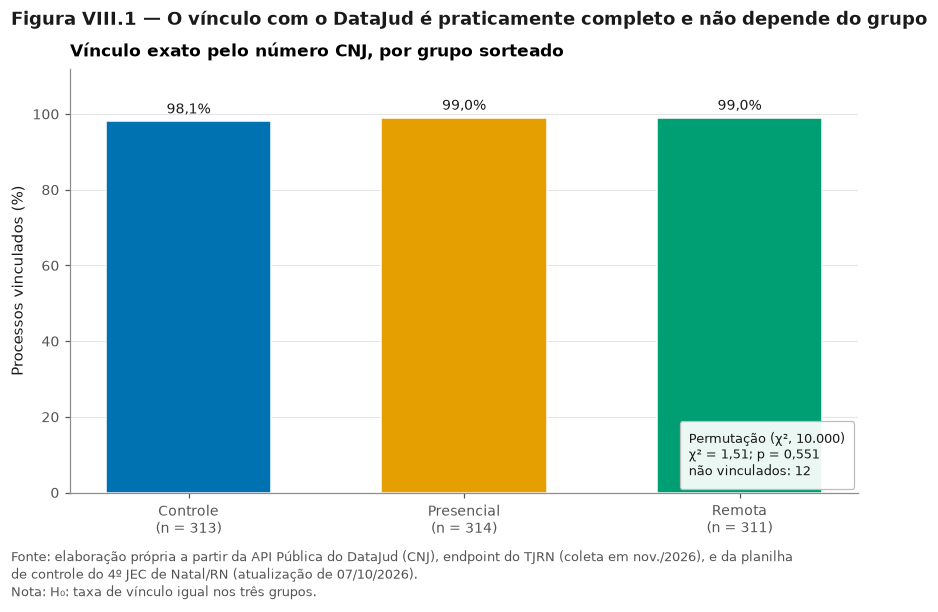

Tipo de registro,Registros,Números
"Juizado, com passagem pelo 4º JEC",926,926
Turma Recursal (recurso inominado),134,134
Outro órgão (sem passagem pelo 4º JEC),6,6


Processo,Grupo,Desfecho (planilha),Distribuição,Origem externa,Registros,Registros encontrados (grau e órgão)
0808292-43.2025.8.20.5300,Controle,Sem mérito,06/01/2026,Sim,1,G1 4709
0800198-87.2026.8.20.5004,Controle,Sem mérito,10/01/2026,Não,0,—
0803118-34.2026.8.20.5004,Remota,Mérito,02/03/2026,Não,0,—
0807174-13.2026.8.20.5004,Controle,Mérito,27/04/2026,Não,0,—
0807739-74.2026.8.20.5004,Presencial,Ativo,05/05/2026,Não,0,—
0808165-86.2026.8.20.5004,Remota,Redistribuição,11/05/2026,Não,1,G1 4726
0803458-60.2026.8.20.5300,Presencial,Redistribuição,12/05/2026,Sim,1,G1 4709
0808692-38.2026.8.20.5004,Controle,Mérito,18/05/2026,Não,0,—
0809595-73.2026.8.20.5004,Controle,Mérito,29/05/2026,Não,0,—
0812434-71.2026.8.20.5004,Remota,Redistribuição,09/07/2026,Não,0,—


In [169]:
dj_por_num = defaultdict(list)
for x in dj_regs:
    dj_por_num[x['numeroProcesso']].append(x)


def dj_passou_4jec(x):
    return any(dj_oj(m) == COD_4JEC for m in x.get('movimentos') or [])


def dj_tipo_registro(x):
    if x.get('grau') == 'TR':
        return 'Turma Recursal (recurso inominado)'
    if x.get('grau') == 'JE' and dj_passou_4jec(x):
        return 'Juizado, com passagem pelo 4º JEC'
    return 'Outro órgão (sem passagem pelo 4º JEC)'


dj = dados.copy()
dj['numero'] = dj['processo'].astype(str).str.replace(r'\D', '', regex=True)
dj['consultado'] = dj['numero'].isin(dj_consultados)
dj['n_registros'] = dj['numero'].map(lambda n: len(dj_por_num.get(n, [])))
dj['encontrado'] = dj['n_registros'] > 0
_principal = {}
for n, lst in dj_por_num.items():
    cand = [x for x in lst if dj_tipo_registro(x).startswith('Juizado')]
    if cand:
        _principal[n] = max(cand, key=lambda x: len(x.get('movimentos') or []))
dj['vinculado'] = dj['numero'].isin(_principal)
dj['n_principais'] = dj['numero'].map(lambda n: sum(dj_tipo_registro(x).startswith('Juizado') for x in dj_por_num.get(n, [])))
dj['tem_recurso'] = dj['numero'].map(lambda n: any(x.get('grau') == 'TR' for x in dj_por_num.get(n, [])))
dj_c = dj[dj['consultado']].copy()

# variáveis derivadas do registro principal
_der = pd.DataFrame([dj_derivar(_principal[n], COD_4JEC, desde=d0 - pd.Timedelta(days=30))
                     for n, d0 in zip(dj_c.loc[dj_c.vinculado, 'numero'], dj_c.loc[dj_c.vinculado, 'dt_distribuicao'])],
                    index=dj_c.index[dj_c.vinculado])
dj_c = dj_c.join(_der.add_prefix('dj_'))

# tabela de vínculo por grupo
vinc = (dj_c.groupby('grupo', observed=True)
        .agg(Consultados=('numero', 'size'), Encontrados=('encontrado', 'sum'), Vinculados=('vinculado', 'sum'))
        .reindex(ORDEM_GRUPO))
vinc.loc['Total'] = vinc.sum()
vinc['Vínculo (%)'] = vinc['Vinculados'] / vinc['Consultados']
tabela(vinc.rename_axis('Grupo'), 'dj_vinculo', 'Quase todos os processos da planilha são encontrados no DataJud, com a mesma taxa nos três grupos',
       secao='8.3.1', fonte=FONTE_DJ, formatos={'Vínculo (%)': 'pct'},
       nota='Encontrado = algum registro com o número; vinculado = registro de juizado com movimento no 4º JEC (registro principal).'
            + ('' if DJ_AMOSTRA_COMPLETA else f' Coleta parcial: {len(dj_lotes_feitos)} de {len(dj_lotes)} lotes.'))


def dj_perm_chi2(x, g, B=10000, rng=None):
    """Teste de permutação da estatística qui-quadrado de independência (x binária × g categórica)."""
    rng = rng or np.random.default_rng(SEMENTE)
    x, g = np.asarray(x).astype(int), np.asarray(g)
    cats = np.unique(g)
    def chi(gg):
        tab = np.array([[np.sum((gg == c) & (x == v)) for v in (0, 1)] for c in cats], float)
        esp = tab.sum(1, keepdims=True) * tab.sum(0, keepdims=True) / tab.sum()
        with np.errstate(divide='ignore', invalid='ignore'):
            return np.nansum(np.where(esp > 0, (tab - esp) ** 2 / esp, 0))
    obs = chi(g)
    perm = np.array([chi(rng.permutation(g)) for _ in range(B)])
    return obs, (1 + np.sum(perm >= obs - 1e-12)) / (B + 1)


chi_v, p_v = dj_perm_chi2(dj_c['vinculado'], dj_c['grupo'].astype(str))
fig, ax = plt.subplots(figsize=(8, 4.8))
vv = vinc.loc[ORDEM_GRUPO]
barras_verticais(ax, ORDEM_GRUPO, 100 * vv['Vínculo (%)'], cores=CORES_GRUPO, ns=vv['Consultados'],
                 fmt=lambda v: pct_br(v / 100), ylabel='Processos vinculados (%)', ymax=112)
ax.set_title('Vínculo exato pelo número CNJ, por grupo sorteado')
anotar_teste(ax, texto_teste('Permutação (χ², 10.000)', f'χ² = {fmt_br(chi_v, 2)}', p_v,
                             f'não vinculados: {fmt_int((~dj_c.vinculado).sum())}'), loc='lower right')
figura(fig, 'dj_vinculo', 'O vínculo com o DataJud é praticamente completo e não depende do grupo', secao='8.3.1', fonte=FONTE_DJ,
       nota='H₀: taxa de vínculo igual nos três grupos.')

# composição dos registros
comp = Counter(dj_tipo_registro(x) for n in dj_c['numero'] for x in dj_por_num.get(n, []))
comp_tab = pd.DataFrame({'Registros': pd.Series(comp)}).rename_axis('Tipo de registro')
comp_tab['Números'] = [sum(any(dj_tipo_registro(x) == t for x in dj_por_num.get(n, [])) for n in dj_c['numero'])
                       for t in comp_tab.index]
tabela(comp_tab.sort_values('Registros', ascending=False), 'dj_registros',
       'Um número, vários registros: o recurso na Turma Recursal e a origem em outro órgão são o mesmo processo em outra instância',
       secao='8.3.1', fonte=FONTE_DJ,
       nota=f'Números com mais de um registro principal (duplicidade no índice): {fmt_int((dj_c.n_principais > 1).sum())}. '
            f'Números com recurso inominado (registro TR): {fmt_int(dj_c.tem_recurso.sum())}.')
nv = dj_c[~dj_c['vinculado']]
tabela(nv[['processo', 'grupo', 'tipo_desfecho', 'dt_distribuicao', 'origem_externa', 'n_registros']].assign(
    registros=nv['numero'].map(lambda n: '; '.join(sorted({f"{x.get('grau')} {x['orgaoJulgador'].get('codigo')}" for x in dj_por_num.get(n, [])})) or '—'))
    .rename(columns={'processo': 'Processo', 'grupo': 'Grupo', 'tipo_desfecho': 'Desfecho (planilha)', 'dt_distribuicao': 'Distribuição',
                     'origem_externa': 'Origem externa', 'n_registros': 'Registros', 'registros': 'Registros encontrados (grau e órgão)'})
    .reset_index(drop=True),
    'dj_nao_vinculados', 'Processos da planilha sem registro de juizado com passagem pelo 4º JEC', secao='8.3.1', fonte=FONTE_DJ,
    formatos={'Registros': 'int'})

**Leitura.** Dos 938 números da planilha, **930 (99,1%)** foram encontrados na API e **926 (98,7%)** têm o registro principal (juizado, com passagem pelo 4º JEC). A taxa é praticamente igual nos três grupos (98,1%, 99,0% e 99,0%; teste de permutação sem evidência de diferença), de modo que o vínculo **não introduz viés diferencial** nas comparações das seções seguintes. Os 12 não vinculados são de dois tipos: (i) **oito números não encontrados** em nenhum grau (seis já encerrados na planilha e dois ativos): o índice público não é exaustivo (há processos sob sigilo e registros não enviados pelo tribunal); (ii) **quatro números encontrados só em outro órgão** (justiça comum, G1), dois deles de **origem externa** (numeração 5300, vindos de outro órgão), cuja passagem pelo 4º JEC não aparece no registro daquele número.

O "mesmo número em outra instância" é frequente e foi tratado sem duplicar: 134 processos (14%) têm também um registro na **Turma Recursal** (recurso inominado). Nenhum número tem mais de um registro de juizado no 4º JEC, e o cumprimento de sentença aparece no **mesmo** registro, por evolução de classe (436 → 156), e não como processo novo.

### 8.3.2 Concordância processo a processo

Para cada processo vinculado comparam-se cinco informações da planilha com a reconstrução pelas regras de 8.2, **na mesma data de corte (07/10/2026)**:

1. **data de distribuição**: `dt_distribuicao` × 1º movimento no 4º JEC (e × `dataAjuizamento`);
2. **data da sentença**: `dt_sentenca` × data do julgamento (R1 e R2), entre os que têm sentença nas duas fontes;
3. **tipo de desfecho** em 07/10/2026 (Homologação, Mérito, Sem mérito, Redistribuição, Ativo);
4. **AC realizada** (`ac_realizada`) × audiência de conciliação "realizada" até 07/10/2026;
5. **redistribuição** (saída da unidade) até 07/10/2026.

**Medidas.** Para as datas, a diferença em dias (DataJud − planilha) e o percentual de coincidência exata. Para as categorias, a **concordância observada** e o **kappa de Cohen**, κ = (p_o − p_e)/(1 − p_e), que desconta a concordância esperada por acaso; IC 95% por *bootstrap* (2.000 reamostras de processos). Leitura usual de κ: > 0,80 quase perfeita; 0,61–0,80 substancial (LANDIS; KOCH, 1977).

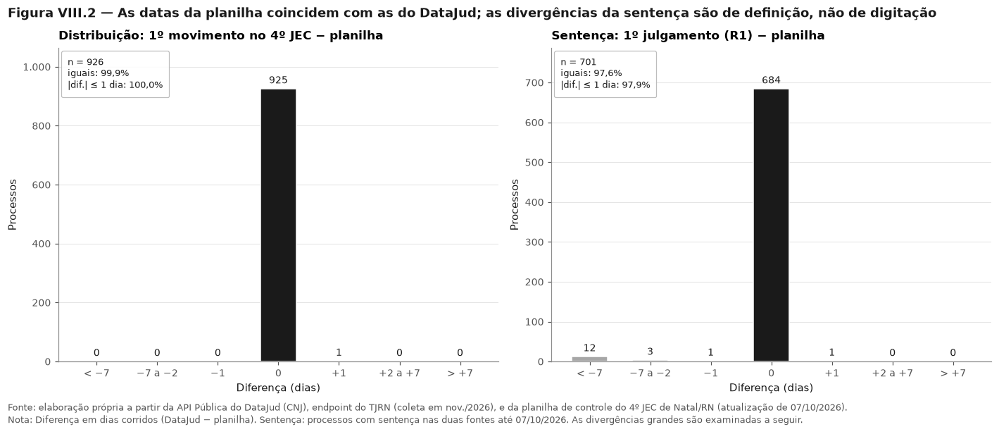

Comparação,n,Iguais,|dif.| ≤ 1 dia,Mediana da dif. (dias)
Distribuição × 1º movimento no 4º JEC,926,"99,9%","100,0%",0
Distribuição × dataAjuizamento,926,"96,4%","97,2%",0
Sentença × julgamento (R1),701,"97,6%","97,9%",0
Sentença × julgamento (R2),701,"99,1%","99,3%",0


In [170]:
CORTE_PLANILHA = DATA_CORTE
v = dj_c[dj_c['vinculado']].copy()
for regra in ('R1', 'R2'):
    _res = [dj_desfecho_em({k[3:]: r[k] for k in r.index if k.startswith('dj_')}, CORTE_PLANILHA, regra) for _, r in v.iterrows()]
    v[f'dj_desf_{regra}'] = [a for a, _ in _res]
    v[f'dj_data_{regra}'] = pd.to_datetime([b for _, b in _res])
v['tipo_pl'] = v['tipo_desfecho'].astype(str)
v['dif_dist'] = (v['dj_entrada'].dt.normalize() - v['dt_distribuicao']).dt.days
v['dif_ajuiz'] = (v['dj_ajuizamento'] - v['dt_distribuicao']).dt.days
_sent_pl = v['tipo_pl'].isin(['Homologação', 'Mérito', 'Sem mérito'])
for regra in ('R1', 'R2'):
    v[f'dif_sent_{regra}'] = np.where(_sent_pl & v[f'dj_desf_{regra}'].isin(['Homologação', 'Mérito', 'Sem mérito']),
                                      (v[f'dj_data_{regra}'] - v['dt_sentenca']).dt.days, np.nan)
v['ac_dj'] = v['dj_ac_realizada_dt'].notna() & (v['dj_ac_realizada_dt'].dt.normalize() <= CORTE_PLANILHA)
v['red_pl'] = v['tipo_pl'] == 'Redistribuição'
v['red_dj'] = v['dj_desf_R1'] == 'Redistribuição'

FAIXAS_DIF = ['< −7', '−7 a −2', '−1', '0', '+1', '+2 a +7', '> +7']


def dj_faixa(d):
    d = pd.Series(d).dropna()
    cat = pd.cut(d, [-1e9, -8, -2, -1, 0, 1, 7, 1e9], right=True, labels=FAIXAS_DIF)
    return cat.value_counts().reindex(FAIXAS_DIF, fill_value=0)


rng_k = np.random.default_rng(SEMENTE + 81)


def dj_kappa(a, b, B=2000):
    a, b = np.asarray(a, dtype=str), np.asarray(b, dtype=str)
    k = cohen_kappa_score(a, b)
    idx = [rng_k.integers(0, len(a), len(a)) for _ in range(B)]
    bs = np.array([cohen_kappa_score(a[i], b[i]) if len(set(a[i]) | set(b[i])) > 1 else np.nan for i in idx])
    return k, np.nanpercentile(bs, 2.5), np.nanpercentile(bs, 97.5), np.mean(a == b)


# ---- datas: distribuição e sentença
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, (col, tit, n_) in zip(axs, [('dif_dist', 'Distribuição: 1º movimento no 4º JEC − planilha', None),
                                     ('dif_sent_R1', 'Sentença: 1º julgamento (R1) − planilha', None)]):
    fx = dj_faixa(v[col])
    cores = [TINTA if f == '0' else CINZA for f in FAIXAS_DIF]
    barras_verticais(ax, FAIXAS_DIF, fx.values, cores=cores, ylabel='Processos', xlabel='Diferença (dias)')
    ax.set_title(tit)
    d = v[col].dropna()
    anotar_teste(ax, texto_teste(f'n = {fmt_int(len(d))}', f'iguais: {pct_br((d == 0).mean())}',
                                 extra=f'|dif.| ≤ 1 dia: {pct_br((d.abs() <= 1).mean())}'), loc='upper left')
figura(fig, 'dj_datas', 'As datas da planilha coincidem com as do DataJud; as divergências da sentença são de definição, não de digitação',
       secao='8.3.2', fonte=FONTE_DJ, nota='Diferença em dias corridos (DataJud − planilha). Sentença: processos com sentença '
       'nas duas fontes até 07/10/2026. As divergências grandes são examinadas a seguir.')

datas_tab = pd.DataFrame([
    {'Comparação': 'Distribuição × 1º movimento no 4º JEC', 'n': v['dif_dist'].notna().sum(), 'Iguais': (v['dif_dist'] == 0).mean(),
     '|dif.| ≤ 1 dia': (v['dif_dist'].abs() <= 1).mean(), 'Mediana da dif. (dias)': v['dif_dist'].median()},
    {'Comparação': 'Distribuição × dataAjuizamento', 'n': v['dif_ajuiz'].notna().sum(), 'Iguais': (v['dif_ajuiz'] == 0).mean(),
     '|dif.| ≤ 1 dia': (v['dif_ajuiz'].abs() <= 1).mean(), 'Mediana da dif. (dias)': v['dif_ajuiz'].median()},
] + [{'Comparação': f'Sentença × julgamento ({regra})', 'n': v[f'dif_sent_{regra}'].notna().sum(),
      'Iguais': (v[f'dif_sent_{regra}'].dropna() == 0).mean(), '|dif.| ≤ 1 dia': (v[f'dif_sent_{regra}'].dropna().abs() <= 1).mean(),
      'Mediana da dif. (dias)': v[f'dif_sent_{regra}'].median()} for regra in ('R1', 'R2')])
tabela(datas_tab, 'dj_datas', 'Concordância das datas: planilha × DataJud', secao='8.3.2', fonte=FONTE_DJ,
       formatos={'Iguais': 'pct', '|dif.| ≤ 1 dia': 'pct', 'Mediana da dif. (dias)': 0, 'n': 'int'},
       nota='R1 = 1º julgamento; R2 = acordo homologado depois da sentença prevalece (8.2).')

**Leitura.** A **data de distribuição** da planilha é, em 99,9% dos casos, o dia do 1º movimento no 4º JEC; a diferença para `dataAjuizamento` (96,4% iguais) aparece só nos processos que chegaram de outro órgão ou foram redistribuídos para o 4º JEC: a planilha mede, corretamente, a entrada **na unidade**, que é o tempo zero adequado ao experimento. A **data da sentença** coincide em **97,6%** dos casos com o 1º julgamento (R1) e em **99,1%** com a regra R2. A diferença entre as duas regras não é erro de digitação: quando um acordo é homologado **depois** da sentença de mérito (no cumprimento de sentença ou na pendência do recurso), a planilha registra a homologação, com a data dela. Isso tem uma consequência para a Parte IV: nesses poucos processos (11), o "tempo até a sentença" da planilha é, na verdade, o tempo até o **acordo posterior**, maior que o tempo até a primeira sentença. O efeito sobre os resultados é desprezível (a seção 8.5 refaz as análises pela R1), mas a definição do evento deve ser explicitada.

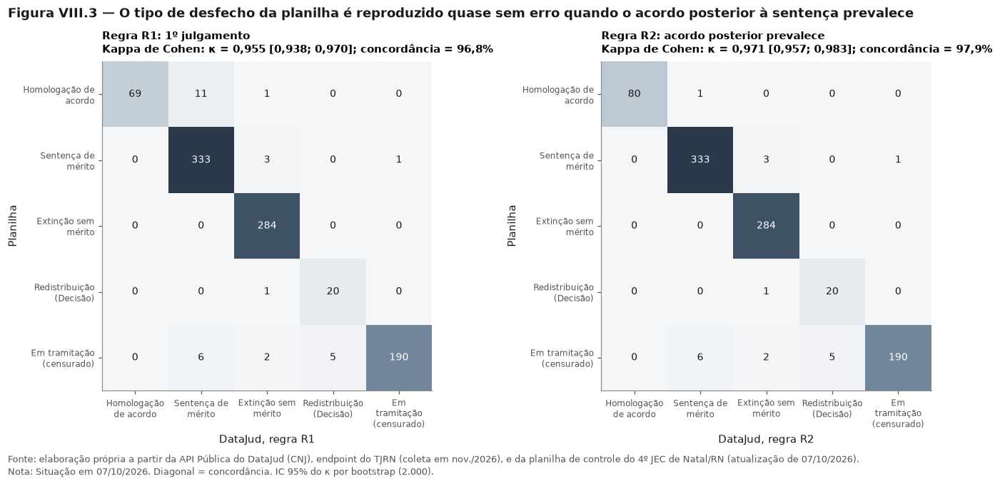

processo,grupo,Planilha,Data (planilha),DataJud R1,Data R1,DataJud R2,Data R2,Código do 1º julgamento
0812353-25.2026.8.20.5004,Remota,Ativo,–,Redistribuição,04/08/2026,Redistribuição,04/08/2026,–
0821262-90.2025.8.20.5004,Presencial,Ativo,–,Redistribuição,24/07/2026,Redistribuição,24/07/2026,–
0812022-43.2026.8.20.5004,Controle,Ativo,–,Redistribuição,02/10/2026,Redistribuição,02/10/2026,–
0804094-41.2026.8.20.5004,Remota,Ativo,–,Redistribuição,11/09/2026,Redistribuição,11/09/2026,–
0812008-59.2026.8.20.5004,Presencial,Ativo,–,Sem mérito,06/07/2026,Sem mérito,06/07/2026,459 Ausência de pressupostos processuais
0810834-15.2026.8.20.5004,Remota,Ativo,–,Mérito,03/10/2026,Mérito,03/10/2026,221 Procedência em Parte
0806960-22.2026.8.20.5004,Controle,Ativo,–,Redistribuição,04/08/2026,Redistribuição,04/08/2026,–
0807126-54.2026.8.20.5004,Remota,Ativo,–,Mérito,28/08/2026,Mérito,28/08/2026,220 Improcedência
0813453-15.2026.8.20.5004,Controle,Ativo,–,Mérito,03/10/2026,Mérito,03/10/2026,221 Procedência em Parte
0808315-67.2026.8.20.5004,Remota,Ativo,–,Sem mérito,13/05/2026,Sem mérito,13/05/2026,"460 Perempção, litispendência ou coisa julgada"


In [171]:
# ---- tipo de desfecho: matriz de confusão (R1 e R2)
ORD5 = ORDEM_DESFECHO
fig, axs = plt.subplots(1, 2, figsize=(13, 5.6))
kap_desf = {}
for ax, regra in zip(axs, ('R1', 'R2')):
    m = pd.crosstab(v['tipo_pl'], v[f'dj_desf_{regra}']).reindex(index=ORD5, columns=ORD5, fill_value=0)
    ax.imshow(m.values, cmap=SEQ, vmin=0, vmax=max(1, m.values.max()))
    for i in range(5):
        for j in range(5):
            val = m.values[i, j]
            ax.text(j, i, fmt_int(val), ha='center', va='center', fontsize=9,
                    color='white' if val > 0.55 * m.values.max() else TINTA)
    ax.set_xticks(range(5), [quebra(ROTULO_DESFECHO[c], 12) for c in ORD5], fontsize=8)
    ax.set_yticks(range(5), [quebra(ROTULO_DESFECHO[c], 14) for c in ORD5], fontsize=8)
    ax.set_xlabel(f'DataJud, regra {regra}')
    ax.set_ylabel('Planilha')
    ax.grid(False)
    k, lo, hi, po = dj_kappa(v['tipo_pl'], v[f'dj_desf_{regra}'])
    kap_desf[regra] = (k, lo, hi, po)
    ax.set_title(f'Regra {regra}: ' + ('1º julgamento' if regra == 'R1' else 'acordo posterior prevalece')
                 + f'\nKappa de Cohen: κ = {fmt_br(k, 3)} [{fmt_br(lo, 3)}; {fmt_br(hi, 3)}]; concordância = {pct_br(po)}', fontsize=10)
figura(fig, 'dj_desfecho_confusao', 'O tipo de desfecho da planilha é reproduzido quase sem erro quando o acordo posterior à sentença prevalece',
       secao='8.3.2', fonte=FONTE_DJ, nota='Situação em 07/10/2026. Diagonal = concordância. IC 95% do κ por bootstrap (2.000).')

div = v[v['tipo_pl'] != v['dj_desf_R2']]
tabela(div[['processo', 'grupo', 'tipo_pl', 'dt_sentenca', 'dj_desf_R1', 'dj_data_R1', 'dj_desf_R2', 'dj_data_R2', 'dj_sent_cod']]
       .rename(columns={'tipo_pl': 'Planilha', 'dt_sentenca': 'Data (planilha)', 'dj_desf_R1': 'DataJud R1', 'dj_data_R1': 'Data R1',
                        'dj_desf_R2': 'DataJud R2', 'dj_data_R2': 'Data R2', 'dj_sent_cod': 'Código do 1º julgamento'})
       .assign(**{'Código do 1º julgamento': lambda d: d['Código do 1º julgamento'].map(lambda c: '–' if pd.isna(c) else f'{int(c)} {dj_nome(c)}')})
       .sort_values('Planilha').reset_index(drop=True),
       'dj_divergencias', 'Processos em que a planilha e o DataJud (R2) discordam quanto ao desfecho em 07/10/2026', secao='8.3.2',
       fonte=FONTE_DJ, formatos={'Código do 1º julgamento': 'texto'})

**Leitura.** O tipo de desfecho concorda em **96,8%** dos processos pela R1 (κ = 0,955) e em **97,9%** pela R2 (κ = 0,971 [0,957; 0,983]): concordância **quase perfeita**. A matriz da R1 mostra onde estão as diferenças: 11 "Homologações" da planilha são, no DataJud, sentenças de mérito seguidas de acordo homologado (a convenção descrita acima); com a R2, resta uma.

As divergências que sobram (tabela acima) são de três naturezas:

1. **Atraso de alimentação da planilha**: 13 processos marcados como "Ativo" em 07/10 já tinham sentença ou saída no DataJud, várias com data muito próxima do corte (quatro sentenças de 03/10/2026, um sábado; outras de maio a agosto; saídas de julho a outubro). A planilha, alimentada à mão, estava alguns dias atrasada; o efeito é censurar como ativos processos já encerrados (corrigido na extensão de 8.4).
2. **Mérito na planilha × extinção sem mérito no DataJud** (três casos: abandono da causa, ausência de pressupostos, inadmissibilidade do rito): diferença de classificação jurídica do mesmo ato, ou lançamento do código TPU errado.
3. Casos isolados: um "Mérito" sem nenhum julgamento lançado no DataJud; uma "Redistribuição" que, no DataJud, é extinção por inadmissibilidade do procedimento seguida de envio a outro órgão; e uma homologação lançada pela Turma Recursal (fora da unidade).

Nenhuma dessas divergências se concentra num grupo: elas não ameaçam a comparação entre os ritos.

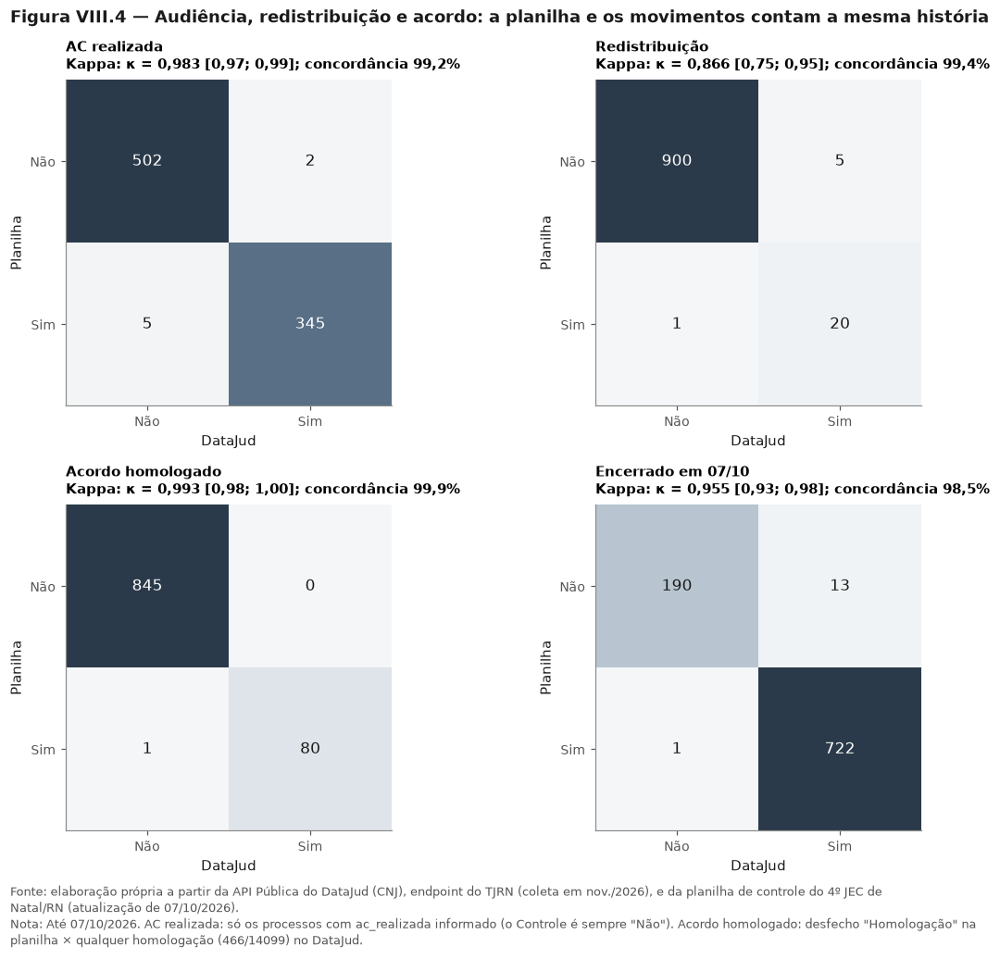

Variável,n,Concordância,κ,IC 95% inf.,IC 95% sup.,Só na planilha,Só no DataJud
Tipo de desfecho (R2),926,"97,9%","0,971","0,957","0,983",–,–
Tipo de desfecho (R1),926,"96,8%","0,955","0,938","0,970",–,–
AC realizada,854,"99,2%","0,983","0,969","0,993",5,2
Redistribuição,926,"99,4%","0,866","0,746","0,953",1,5
Acordo homologado,926,"99,9%","0,993","0,978","1,000",1,0
Encerrado em 07/10,926,"98,5%","0,955","0,930","0,977",1,13


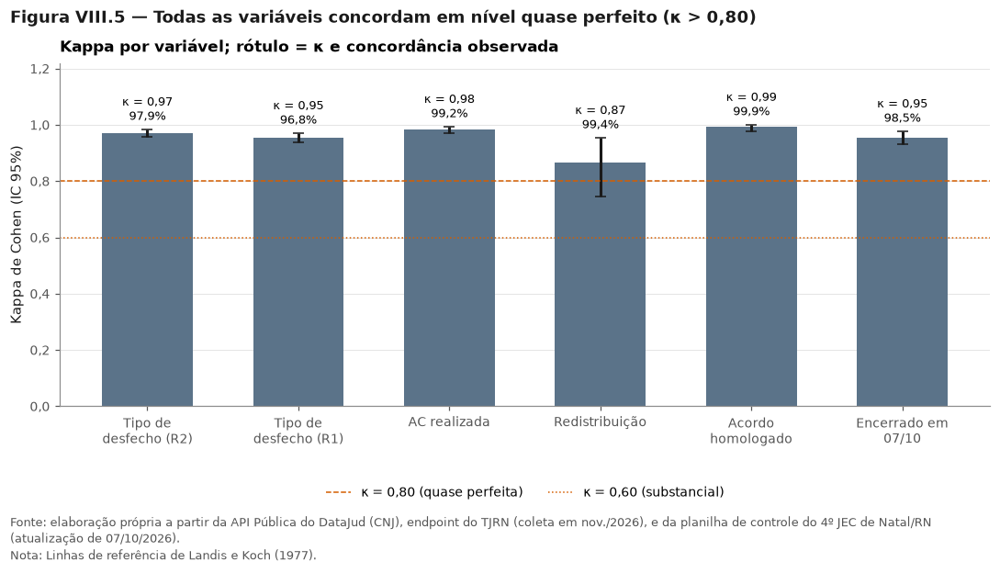

In [172]:
# ---- AC realizada, redistribuição e acordo: concordância e kappa
v_ac = v[v['ac_realizada'].notna()].copy()
v['acordo_dj'] = v['dj_homolog_dt'].notna() & (v['dj_homolog_dt'].dt.normalize() <= CORTE_PLANILHA)
comparacoes = {
    'AC realizada': (v_ac['ac_realizada'].astype(bool), v_ac['ac_dj']),
    'Redistribuição': (v['red_pl'], v['red_dj']),
    'Acordo homologado': (v['tipo_pl'] == 'Homologação', v['acordo_dj']),
    'Encerrado em 07/10': (v['tipo_pl'] != 'Ativo', v['dj_desf_R2'] != 'Ativo'),
}
fig, axs = plt.subplots(2, 2, figsize=(11, 8.5))
linhas_k = []
for ax, (nome, (a, b)) in zip(axs.flat, comparacoes.items()):
    a, b = pd.Series(a).astype(bool).values, pd.Series(b).astype(bool).values
    m = pd.crosstab(pd.Categorical(a, [False, True]), pd.Categorical(b, [False, True]), dropna=False).values
    ax.imshow(m, cmap=SEQ, vmin=0, vmax=max(1, m.max()))
    for i in range(2):
        for j in range(2):
            ax.text(j, i, fmt_int(m[i, j]), ha='center', va='center', fontsize=11,
                    color='white' if m[i, j] > 0.55 * m.max() else TINTA)
    ax.set_xticks([0, 1], ['Não', 'Sim'])
    ax.set_yticks([0, 1], ['Não', 'Sim'])
    ax.set_xlabel('DataJud')
    ax.set_ylabel('Planilha')
    ax.grid(False)
    k, lo, hi, po = dj_kappa(a, b)
    ax.set_title(f'{nome}\nKappa: κ = {fmt_br(k, 3)} [{fmt_br(lo, 2)}; {fmt_br(hi, 2)}]; concordância {pct_br(po)}', fontsize=10)
    linhas_k.append({'Variável': nome, 'n': len(a), 'Concordância': po, 'κ': k, 'IC 95% inf.': lo, 'IC 95% sup.': hi,
                     'Só na planilha': int(m[1, 0]), 'Só no DataJud': int(m[0, 1])})
figura(fig, 'dj_binarias', 'Audiência, redistribuição e acordo: a planilha e os movimentos contam a mesma história', secao='8.3.2',
       fonte=FONTE_DJ, nota='Até 07/10/2026. AC realizada: só os processos com ac_realizada informado (o Controle é sempre "Não"). '
       'Acordo homologado: desfecho "Homologação" na planilha × qualquer homologação (466/14099) no DataJud.')
for regra in ('R1', 'R2'):
    k, lo, hi, po = kap_desf[regra]
    linhas_k.insert(0, {'Variável': f'Tipo de desfecho ({regra})', 'n': len(v), 'Concordância': po, 'κ': k, 'IC 95% inf.': lo,
                        'IC 95% sup.': hi, 'Só na planilha': np.nan, 'Só no DataJud': np.nan})
kap_tab = pd.DataFrame(linhas_k)
tabela(kap_tab, 'dj_concordancia', 'Resumo da concordância planilha × DataJud (kappa de Cohen, IC 95% bootstrap)', secao='8.3.2',
       fonte=FONTE_DJ, formatos={'Concordância': 'pct', 'κ': 3, 'IC 95% inf.': 3, 'IC 95% sup.': 3, 'n': 'int',
                                 'Só na planilha': 'int', 'Só no DataJud': 'int'})

fig, ax = plt.subplots(figsize=(10, 5))
xk = np.arange(len(kap_tab))
ax.bar(xk, kap_tab['κ'], color='#5B7389', width=0.6)
ax.errorbar(xk, kap_tab['κ'], yerr=[kap_tab['κ'] - kap_tab['IC 95% inf.'], kap_tab['IC 95% sup.'] - kap_tab['κ']], fmt='none',
            ecolor=TINTA, capsize=4)
for xi, (k, po, hi_) in enumerate(zip(kap_tab['κ'], kap_tab['Concordância'], kap_tab['IC 95% sup.'])):
    ax.annotate(f'κ = {fmt_br(k, 2)}\n{pct_br(po)}', (xi, hi_ + 0.02), ha='center', va='bottom', fontsize=8.5)
ax.axhline(0.8, color=DESTAQUE, ls='--', lw=1, label='κ = 0,80 (quase perfeita)')
ax.axhline(0.6, color=DESTAQUE, ls=':', lw=1, label='κ = 0,60 (substancial)')
legenda_abaixo(ax, ncol=2, dy=-0.2)
ax.set_xticks(xk, [quebra(t, 14) for t in kap_tab['Variável']])
ax.set_ylim(0, 1.22)
ax.set_ylabel('Kappa de Cohen (IC 95%)')
ax.set_title('Kappa por variável; rótulo = κ e concordância observada')
ax.grid(axis='x', visible=False)
figura(fig, 'dj_kappa', ('Todas as variáveis concordam em nível quase perfeito (κ > 0,80)' if (kap_tab['κ'] > 0.8).all()
                        else 'Todas as variáveis concordam além do acaso; a maioria em nível quase perfeito'), secao='8.3.2',
       fonte=FONTE_DJ, nota='Linhas de referência de Landis e Koch (1977).')

**Leitura.** Todas as variáveis concordam em nível **quase perfeito** (κ > 0,80), inclusive as que só a planilha distinguia: a **AC realizada** (κ = 0,983; 345 audiências realizadas nas duas fontes, cinco só na planilha e duas só no DataJud) e o **acordo homologado** (κ = 0,993). A **redistribuição** tem o κ mais baixo (0,866), por ser rara (21 casos): cinco saídas registradas no DataJud não constavam da planilha em 07/10, de novo pelo atraso de alimentação. A variável "encerrado em 07/10" resume o padrão: só **uma** discordância no sentido "encerrado na planilha, ativo no DataJud" e **13** no sentido oposto, isto é, a planilha **subestima** levemente os encerramentos perto do corte, mas não inventa nenhum.

**Conclusão de VIII-A.** A planilha é uma medida **válida** das variáveis do experimento. O principal problema que ela tem não é de digitação, e sim de **definição** (o acordo posterior à sentença substitui a sentença) e de **defasagem** perto da data de corte. As duas coisas são pequenas e não diferenciais entre os grupos.

### 8.3.3 As sentenças em fim de semana

A auditoria (A16; seção 2.5.4) encontrou **135 sentenças datadas em sábado ou domingo** na planilha (18,4% das sentenças), o que levantou a suspeita de digitação errada. O DataJud permite separar duas hipóteses: (a) a data da planilha está errada (o ato é de um dia útil); (b) o ato foi mesmo **registrado** no fim de semana. O movimento de julgamento no PJe é gerado quando o magistrado **assina eletronicamente** a sentença, e é essa data e hora que o DataJud reproduz; a publicação no Diário (movimentos 1061/92) é posterior e cai em dia útil. Se as datas de fim de semana da planilha coincidem com as do movimento, a planilha registrou a data da **assinatura**, e o fim de semana é real.

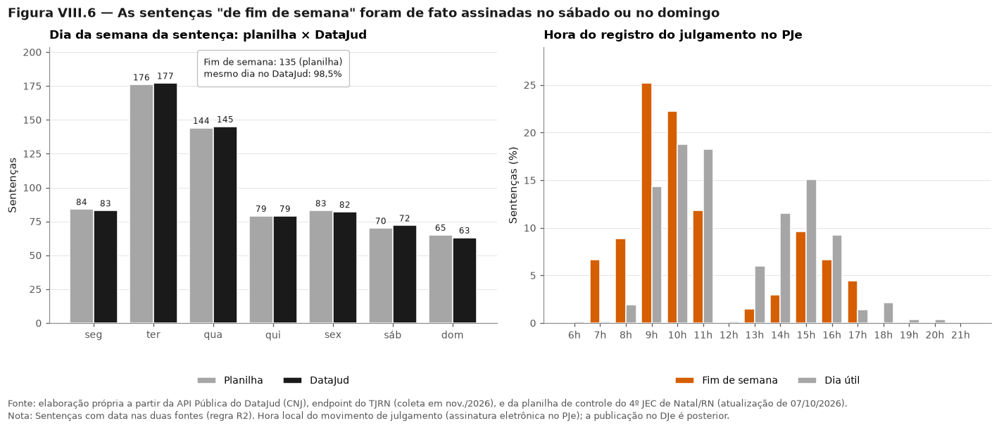

In [173]:
DIAS_PT = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
fs = v[_sent_pl & v['dif_sent_R2'].notna()].copy()
fs['dia_pl'] = fs['dt_sentenca'].dt.dayofweek
fs['dia_dj'] = fs['dj_data_R2'].dt.dayofweek
_dt_julg = np.where(fs['dif_sent_R1'] == fs['dif_sent_R2'], fs['dj_sent_dt'], fs['dj_homolog_pos_dt'])
fs['hora_dj'] = pd.to_datetime(_dt_julg).hour
fs['fds_pl'] = fs['dia_pl'] >= 5
fds = fs[fs['fds_pl']]
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
tab_d = pd.DataFrame({'Planilha': fs['dia_pl'].value_counts().reindex(range(7), fill_value=0).values,
                      'DataJud': fs['dia_dj'].value_counts().reindex(range(7), fill_value=0).values}, index=DIAS_PT)
barras_agrupadas(axs[0], tab_d, cores={'Planilha': CINZA, 'DataJud': TINTA}, ylabel='Sentenças', rotular=True)
axs[0].set_title('Dia da semana da sentença: planilha × DataJud')
anotar_teste(axs[0], texto_teste(f'Fim de semana: {fmt_int(fds.shape[0])} (planilha)',
                                 f'mesmo dia no DataJud: {pct_br((fds["dif_sent_R2"] == 0).mean())}'), loc='upper center')
legenda_abaixo(axs[0], ncol=2)
hrs = fds['hora_dj'].value_counts().reindex(range(6, 22), fill_value=0)
hru = fs.loc[~fs['fds_pl'], 'hora_dj'].value_counts().reindex(range(6, 22), fill_value=0)
tab_h = pd.DataFrame({'Fim de semana': hrs.values / max(1, hrs.sum()), 'Dia útil': hru.values / max(1, hru.sum())},
                     index=[f'{h}h' for h in range(6, 22)])
barras_agrupadas(axs[1], 100 * tab_h, cores={'Fim de semana': DESTAQUE, 'Dia útil': CINZA}, ylabel='Sentenças (%)')
axs[1].set_title('Hora do registro do julgamento no PJe')
legenda_abaixo(axs[1], ncol=2)
figura(fig, 'dj_fim_semana', 'As sentenças "de fim de semana" foram de fato assinadas no sábado ou no domingo',
       secao='8.3.3', fonte=FONTE_DJ, nota='Sentenças com data nas duas fontes (regra R2). Hora local do movimento de julgamento '
       '(assinatura eletrônica no PJe); a publicação no DJe é posterior.')

**Leitura.** A suspeita da auditoria (A16) **não se confirma**. As **135 sentenças** datadas em sábado ou domingo na planilha estão no DataJud **no mesmo dia** em 98,5% dos casos, e a distribuição dos dias da semana é praticamente idêntica nas duas fontes (72 sábados e 63 domingos no DataJud). O movimento de julgamento é gerado quando o magistrado **assina eletronicamente** a sentença no PJe; a publicação no Diário vem depois, em dia útil. A hora do registro ajuda a ler o padrão: as sentenças de fim de semana concentram-se **de manhã** (7h às 11h), enquanto as de dia útil se dividem entre manhã e tarde, o perfil de quem despacha remotamente fora do expediente. As datas de fim de semana são, portanto, as datas **reais da assinatura**, e não erro de lançamento. O que a planilha registra é a data em que a sentença passou a existir nos autos; a "data de lançamento" e a "data de assinatura" coincidem no PJe.

Para o estudo, isso fecha a questão da seção 2.5.4 e da sensibilidade da seção 4.9: **nenhuma correção** das datas de fim de semana é necessária. Para a gestão, o dado é relevante por si: quase um quinto das sentenças do período foi assinado em fins de semana.

## 8.4 VIII-B — Seguimento estendido dos censurados

Em 07/10/2026, 206 processos estavam sem sentença (censurados) e 24 haviam saído da unidade. O DataJud foi consultado em novembro de 2026: os processos que receberam sentença depois de 07/10 passam a ter o **evento observado**, e os demais ficam censurados numa data posterior. Isso **reduz a censura** sem mudar o desenho, e permite verificar se as conclusões da Parte IV dependiam do seguimento curto (mínimo de 65 dias).

### 8.4.1 Até quando o DataJud é confiável?

O índice do DataJud é alimentado pelos tribunais **com defasagem**: um movimento lançado hoje no PJe pode levar dias para aparecer na API. Usar como corte a data da coleta trataria como "sem sentença" processos cuja sentença ainda não chegou ao índice, e enviesaria a extensão para baixo. Também não se usa a última atualização de cada registro como corte individual: os registros atualizados recentemente são justamente os que tiveram movimento (por exemplo, uma sentença), e a censura passaria a depender do desfecho (censura informativa). Adota-se, portanto, um **corte único**: o último dia em que o volume diário de movimentos ainda está no nível habitual, definido pela regra abaixo e conferido no gráfico.

**Regra.** Para cada dia útil depois de 07/10/2026, compara-se o número de movimentos dos processos da amostra com a mediana dos dias úteis das quatro semanas anteriores a 07/10; o corte é o último dia útil antes do primeiro dia em que o volume cai abaixo de **50%** desse nível e não se recupera.

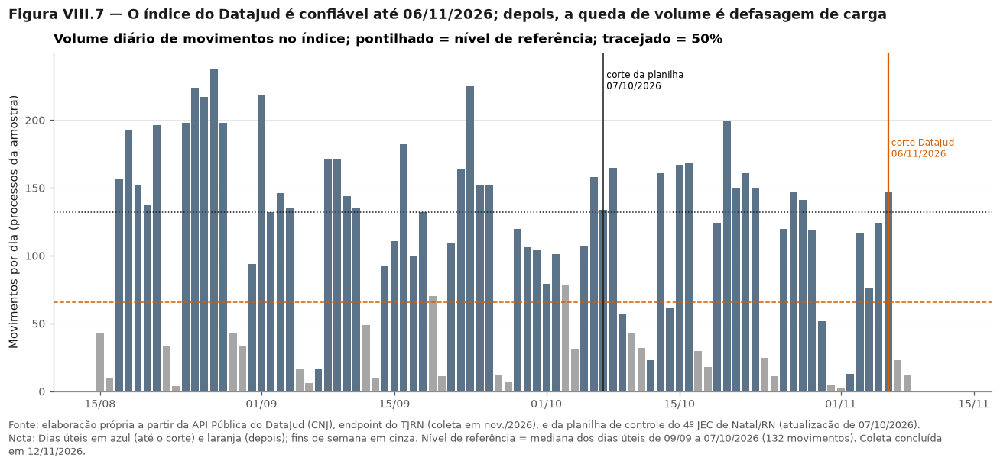

Corte confiável do DataJud (amostra): 2026-11-06 | 1º dia da queda: 2026-11-09 00:00:00


In [174]:
def dj_volume_diario(regs_iter, desde, ate):
    cont = Counter()
    for x in regs_iter:
        for m in x.get('movimentos') or []:
            d = str(m['dataHora'])[:10]
            if desde <= d <= ate:
                cont[d] += 1
    s = pd.Series(cont, dtype=float)
    s.index = pd.to_datetime(s.index)
    return s.reindex(pd.date_range(desde, ate), fill_value=0)


def dj_corte_confiavel(vol, ref_ini, ref_fim, limiar=0.5):
    uteis = vol[vol.index.dayofweek < 5]
    nivel = uteis[(uteis.index >= ref_ini) & (uteis.index <= ref_fim)].median()
    depois = uteis[uteis.index > ref_fim]
    baixo = depois < limiar * nivel
    # primeiro dia útil a partir do qual o volume fica abaixo do limiar até o fim da série
    queda = None
    for d in depois.index:
        if baixo.loc[d:].all():
            queda = d
            break
    corte = (depois.index[depois.index < queda].max() if queda is not None and (depois.index < queda).any()
             else depois.index.max())
    return corte, nivel, queda


_ate = DJ_DATA_COLETA.strftime('%Y-%m-%d')
vol_am = dj_volume_diario([_principal[n] for n in v['numero']], '2026-08-15', _ate)
DJ_CORTE, nivel_am, queda_am = dj_corte_confiavel(vol_am, DATA_CORTE - pd.Timedelta(days=28), DATA_CORTE)

fig, ax = plt.subplots(figsize=(12, 4.8))
cores_v = [CINZA if d.dayofweek >= 5 else ('#5B7389' if d <= DJ_CORTE else DESTAQUE) for d in vol_am.index]
ax.bar(vol_am.index, vol_am.values, color=cores_v, width=0.8)
ax.axhline(nivel_am, color=TINTA, ls=':', lw=1)
ax.axhline(0.5 * nivel_am, color=DESTAQUE, ls='--', lw=1)
ax.axvline(DATA_CORTE, color=TINTA, lw=1)
ax.axvline(DJ_CORTE, color=DESTAQUE, lw=1.5)
ax.text(DATA_CORTE, ax.get_ylim()[1] * 0.95, ' corte da planilha\n 07/10/2026', fontsize=8, va='top')
ax.text(DJ_CORTE, ax.get_ylim()[1] * 0.75, f' corte DataJud\n {DJ_CORTE:%d/%m/%Y}', fontsize=8, va='top', color=DESTAQUE)
ax.set_ylabel('Movimentos por dia (processos da amostra)')
ax.set_title('Volume diário de movimentos no índice; pontilhado = nível de referência; tracejado = 50%')
eixo_meses(ax, formato='dia')
figura(fig, 'dj_corte', f'O índice do DataJud é confiável até {DJ_CORTE:%d/%m/%Y}; depois, a queda de volume é defasagem de carga',
       secao='8.4.1', fonte=FONTE_DJ, nota=f'Dias úteis em azul (até o corte) e laranja (depois); fins de semana em cinza. Nível de '
       f'referência = mediana dos dias úteis de 09/09 a 07/10/2026 ({fmt_br(nivel_am, 0)} movimentos). Coleta concluída em {DJ_DATA_COLETA:%d/%m/%Y}.')
print('Corte confiável do DataJud (amostra):', DJ_CORTE.date(), '| 1º dia da queda:', queda_am)

**Leitura.** O volume diário de movimentos dos processos da amostra oscila, nos dias úteis, em torno do nível de referência até a primeira semana de novembro e cai a **zero a partir de 09/11/2026**, embora a coleta tenha terminado em 12/11. Essa queda abrupta não é a de um acervo que se encerra (que seria gradual): é a **defasagem de carga** do índice, cuja última atualização é de 09/11. O corte confiável adotado é **06/11/2026** (sexta-feira), o último dia útil com volume no nível habitual, um mês depois do corte da planilha.

### 8.4.2 Os censurados que receberam sentença depois de 07/10/2026

**Regra da extensão.** Os 708 processos com sentença e os 24 redistribuídos mantêm o tempo e o evento da planilha (a análise principal). Para os 206 censurados: se o DataJud registra o 1º julgamento (R1) até o corte confiável, o evento passa a 1 com o tempo até essa data; se registra a saída da unidade, o processo fica censurado na data da saída; caso contrário, fica censurado no corte do DataJud (ou em 07/10/2026, se o processo não foi vinculado ou não foi consultado). Nenhuma data da planilha é alterada.

Grupo,ainda sem sentença,não vinculado / não consultado,saída da unidade,sentença antes de 07/10 (omitida na planilha),sentença depois de 07/10,Censurados em 07/10
Controle,15,1,2,3,25,46
Presencial,35,2,1,2,34,74
Remota,59,0,2,3,22,86
Total,109,3,5,8,81,206


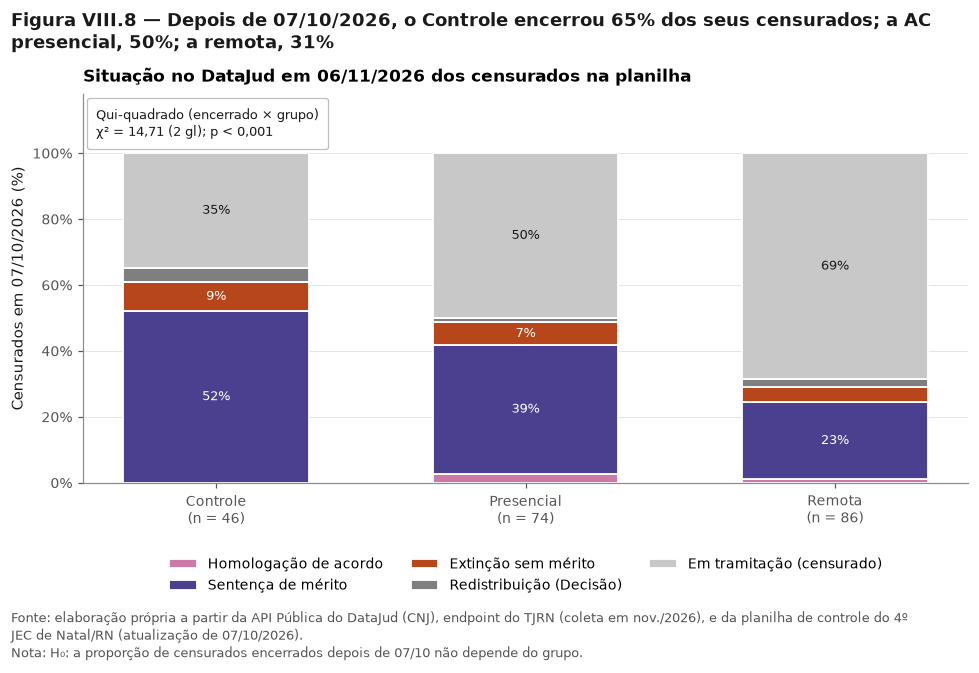

In [175]:
ext = dj[['processo', 'numero', 'grupo', 'dt_distribuicao', 'tempo', 'evento', 'evento_cr', 'tipo_desfecho', 'mes_distribuicao',
          'origem_externa']].copy()
ext = ext.join(v[['dj_sent_dt', 'dj_sent_tipo', 'dj_saida_dt']], how='left')
ext['T_ext'] = ext['tempo'].astype(float)
ext['E_ext'] = ext['evento'].astype(int)
ext['tipo_ext'] = ext['tipo_desfecho'].astype(str)
cens = ext['evento_cr'].astype(int) == 0
_vinc = ext.index.isin(v.index)
_sd = ext['dj_sent_dt'].dt.normalize()
_xd = ext['dj_saida_dt'].dt.normalize()
com_sent = cens & _sd.notna() & (_sd <= DJ_CORTE) & (_xd.isna() | (_sd < _xd))
com_saida = cens & ~com_sent & _xd.notna() & (_xd <= DJ_CORTE)
sem_nada = cens & ~com_sent & ~com_saida & _vinc
ext.loc[com_sent, 'T_ext'] = (_sd[com_sent] - ext.loc[com_sent, 'dt_distribuicao']).dt.days
ext.loc[com_sent, 'E_ext'] = 1
ext.loc[com_sent, 'tipo_ext'] = ext.loc[com_sent, 'dj_sent_tipo']
ext.loc[com_saida, 'T_ext'] = (_xd[com_saida] - ext.loc[com_saida, 'dt_distribuicao']).dt.days
ext.loc[com_saida, 'tipo_ext'] = 'Redistribuição'
ext.loc[sem_nada, 'T_ext'] = (DJ_CORTE - ext.loc[sem_nada, 'dt_distribuicao']).dt.days
ext['sit_ext'] = np.select([~cens, com_sent & (_sd <= DATA_CORTE), com_sent, com_saida, sem_nada],
                           ['sem alteração', 'sentença antes de 07/10 (omitida na planilha)', 'sentença depois de 07/10',
                            'saída da unidade', 'ainda sem sentença'], 'não vinculado / não consultado')

cens_tab = (ext[cens].groupby(['grupo', 'sit_ext'], observed=True).size().unstack(fill_value=0).reindex(ORDEM_GRUPO))
cens_tab['Censurados em 07/10'] = cens_tab.sum(axis=1)
cens_tab.loc['Total'] = cens_tab.sum()
tabela(cens_tab.rename_axis('Grupo'), 'dj_censurados', 'O que aconteceu, no DataJud, com os processos censurados em 07/10/2026',
       secao='8.4.2', fonte=FONTE_DJ, nota=f'Corte do DataJud: {DJ_CORTE:%d/%m/%Y}.')

tipos_ext = ext[cens].assign(cat=np.where(com_sent[cens], ext.loc[cens, 'tipo_ext'],
                                          np.where(com_saida[cens], 'Redistribuição', 'Ativo')))
tab_pc = pd.crosstab(tipos_ext['grupo'], tipos_ext['cat']).reindex(index=ORDEM_GRUPO, columns=ORDEM_DESFECHO, fill_value=0)
fig, ax = plt.subplots(figsize=(9, 5.2))
barras_empilhadas(ax, tab_pc.div(tab_pc.sum(axis=1), axis=0), cores=CORES_DESFECHO, ns=tab_pc.sum(axis=1).values,
                  rotulos_serie=ROTULO_DESFECHO)
eixo_pct(ax)
ax.set_ylabel('Censurados em 07/10/2026 (%)')
ax.set_title(f'Situação no DataJud em {DJ_CORTE:%d/%m/%Y} dos censurados na planilha')
_tc = pd.crosstab(tipos_ext['grupo'], tipos_ext['cat'] != 'Ativo').reindex(ORDEM_GRUPO)
chi_c, p_c, gl_c, _ = stats.chi2_contingency(_tc.values)
anotar_teste(ax, texto_teste('Qui-quadrado (encerrado × grupo)', f'χ² = {fmt_br(chi_c, 2)} ({gl_c} gl)', p_c), loc='upper left')
ax.set_ylim(0, 1.18)
legenda_abaixo(ax, ncol=3)
_enc = 1 - tab_pc['Ativo'] / tab_pc.sum(axis=1)
figura(fig, 'dj_censurados', f"Depois de 07/10/2026, o Controle encerrou {pct_br(_enc['Controle'], 0)} dos seus censurados; "
       f"a AC presencial, {pct_br(_enc['Presencial'], 0)}; a remota, {pct_br(_enc['Remota'], 0)}",
       secao='8.4.2', fonte=FONTE_DJ, nota='H₀: a proporção de censurados encerrados depois de 07/10 não depende do grupo.')

**Leitura.** Dos 206 processos censurados em 07/10/2026, o DataJud registra até 06/11/2026: **81 sentenças posteriores a 07/10**, **8 sentenças anteriores a 07/10 que a planilha não registrou** (o atraso de alimentação de 8.3), 5 saídas da unidade e 109 processos ainda sem sentença; 3 não puderam ser seguidos (sem vínculo). A extensão **não é neutra entre os grupos**: o Controle encerrou cerca de dois terços dos seus censurados nesse mês, a AC presencial metade e a AC remota menos de um terço (χ² = 14,7; 2 gl; p < 0,001). Os processos com AC obrigatória que estavam pendentes em outubro continuavam, em sua maioria, pendentes um mês depois, o que é coerente com o atraso causado pela espera da audiência (Parte IV). A censura de 07/10 não escondia, portanto, uma "recuperação" dos grupos com AC; ao contrário, escondia parte da vantagem do Controle.

### 8.4.3 Kaplan-Meier, log-rank, Cox e RMST com o seguimento estendido

Refazem-se, com o seguimento estendido, as quatro análises centrais da Parte IV, com a **mesma especificação**: Kaplan-Meier por grupo; log-rank de 3 grupos (H₀: S_Controle = S_Presencial = S_Remota); Cox (b) com grupo + mês de distribuição (julho e agosto juntos) + origem externa (Efron); e diferenças de RMST até 180 dias com IC por *bootstrap* estratificado por grupo (2.000 reamostras). As mesmas funções são aplicadas à base original, para que a comparação seja entre estimativas calculadas do mesmo modo (elas reproduzem os números da Parte IV).

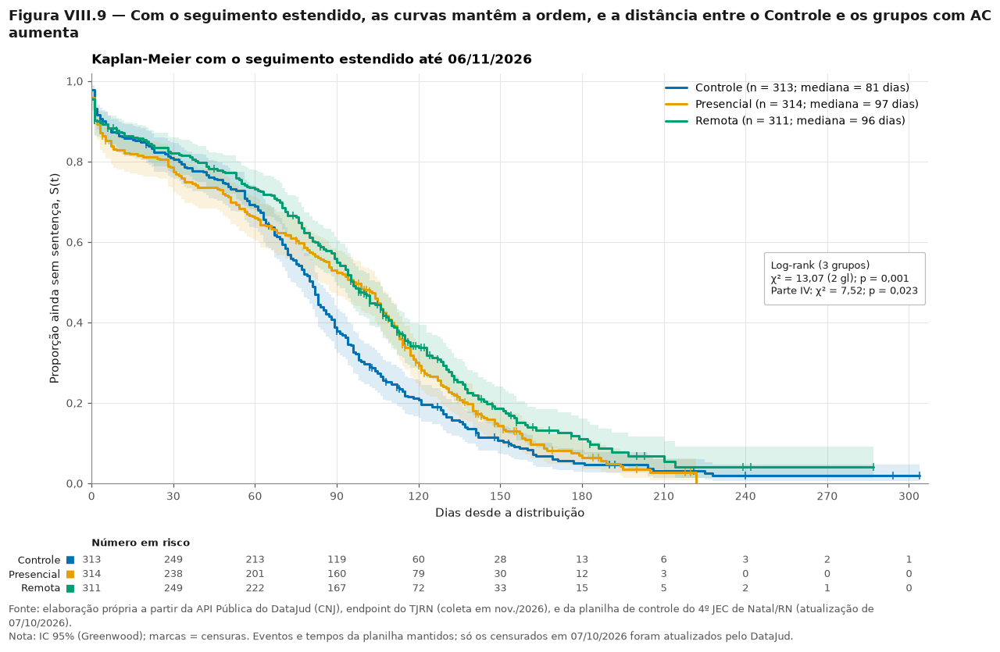

In [176]:
DJ_MESES = ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul-ago']
DJ_COLS_MES = ['mes_fev', 'mes_mar', 'mes_abr', 'mes_mai', 'mes_jun', 'mes_julago']
DJ_X = ['Presencial', 'Remota'] + DJ_COLS_MES + ['origem_ext']


def dj_base_sob(df, T, E):
    s = pd.DataFrame({'T': df[T].astype(float).values, 'E': df[E].astype(int).values, 'grupo': df['grupo'].astype(str).values})
    s['Presencial'] = (s['grupo'] == 'Presencial').astype(int)
    s['Remota'] = (s['grupo'] == 'Remota').astype(int)
    mes = df['mes_distribuicao'].astype(str).replace({'jul': 'jul-ago', 'ago': 'jul-ago'}).values
    for c, m in zip(DJ_COLS_MES, DJ_MESES[1:]):
        s[c] = (mes == m).astype(int)
    s['origem_ext'] = df['origem_externa'].astype(int).values
    return s


def dj_km_grade(T, E, H):
    """S(t) de Kaplan-Meier nos dias inteiros t = 0..H (S[t] = P(T > t))."""
    T = np.asarray(T, dtype=int); E = np.asarray(E, dtype=int)
    n_sai = np.bincount(np.minimum(T, H + 1), minlength=H + 2)[:H + 1]
    risco = len(T) - np.concatenate([[0], np.cumsum(n_sai)[:-1]])
    d = np.bincount(np.minimum(T[E == 1], H + 1), minlength=H + 2)[:H + 1]
    with np.errstate(divide='ignore', invalid='ignore'):
        haz = np.where(risco > 0, d / risco, 0.0)
    return np.cumprod(1 - haz)


def dj_rmst(T, E, tau):
    return dj_km_grade(T, E, tau)[:tau].sum()


def dj_analise_sob(s, rotulo, B=2000, tau=180, semente=SEMENTE + 82):
    """Medianas, log-rank, Cox (b) e ΔRMST(tau) com bootstrap — a especificação da Parte IV."""
    out = {'rotulo': rotulo}
    for g in ORDEM_GRUPO:
        sg = s[s.grupo == g]
        out[f'mediana_{g}'] = KaplanMeierFitter().fit(sg['T'], sg['E']).median_survival_time_
        out[f'eventos_{g}'] = int(sg['E'].sum())
    lr = multivariate_logrank_test(s['T'], s['grupo'], s['E'])
    out['lr_chi2'], out['lr_p'] = lr.test_statistic, lr.p_value
    xs = [c for c in DJ_X if s[c].nunique() > 1]          # covariável constante no subconjunto sai do modelo
    out['X'] = xs
    cox = CoxPHFitter().fit(s[['T', 'E'] + xs], 'T', 'E')
    out['cox'] = cox
    for g in ('Presencial', 'Remota'):
        out[f'HR_{g}'] = np.exp(cox.params_[g])
        lo, hi = np.exp(cox.confidence_intervals_.loc[g].values)
        out[f'HR_{g}_ic'] = (lo, hi)
        out[f'HR_{g}_p'] = cox.summary.loc[g, 'p']
    rng = np.random.default_rng(semente)
    idx = {g: np.where(s.grupo.values == g)[0] for g in ORDEM_GRUPO}
    T_, E_ = s['T'].values.astype(int), s['E'].values.astype(int)
    est = {g: dj_rmst(T_[idx[g]], E_[idx[g]], tau) for g in ORDEM_GRUPO}
    bs = {g: np.array([dj_rmst(T_[ii], E_[ii], tau) for ii in (rng.choice(idx[g], len(idx[g])) for _ in range(B))])
          for g in ORDEM_GRUPO}
    for g in ORDEM_GRUPO:
        out[f'RMST_{g}'] = est[g]
    for g in ('Presencial', 'Remota'):
        dist = bs[g] - bs['Controle']
        dd = est[g] - est['Controle']
        out[f'dRMST_{g}'] = dd
        out[f'dRMST_{g}_ic'] = (np.percentile(dist, 2.5), np.percentile(dist, 97.5))
        out[f'dRMST_{g}_p'] = 2 * stats.norm.sf(abs(dd / dist.std(ddof=1)))
    out['n_eventos'] = int(s['E'].sum())
    out['n_censurados'] = int((s['E'] == 0).sum())
    return out


sob_base = dj_base_sob(ext, 'tempo', 'evento')
sob_ext = dj_base_sob(ext, 'T_ext', 'E_ext')
res_base = dj_analise_sob(sob_base, 'Parte IV (planilha, corte 07/10/2026)')
res_ext = dj_analise_sob(sob_ext, f'Estendido (DataJud, corte {DJ_CORTE:%d/%m/%Y})')

fig, ax = plt.subplots(figsize=(11, 6.6))
plot_km(ax, sob_ext, tempo='T', evento='E', grupo='grupo', passo=30)
ax.set_title(f'Kaplan-Meier com o seguimento estendido até {DJ_CORTE:%d/%m/%Y}')
anotar_teste(ax, texto_teste('Log-rank (3 grupos)', f'χ² = {fmt_br(res_ext["lr_chi2"], 2)} (2 gl)', res_ext['lr_p'],
                             f'Parte IV: χ² = {fmt_br(res_base["lr_chi2"], 2)}; p = {fmt_p(res_base["lr_p"])}'), loc='center right')
figura(fig, 'dj_km_estendido', 'Com o seguimento estendido, as curvas mantêm a ordem, e a distância entre o Controle e os grupos com AC aumenta',
       secao='8.4.3', fonte=FONTE_DJ, nota='IC 95% (Greenwood); marcas = censuras. Eventos e tempos da planilha mantidos; '
       'só os censurados em 07/10/2026 foram atualizados pelo DataJud.')

Medida,"Parte IV (planilha, corte 07/10/2026)","Estendido (DataJud, corte 06/11/2026)"
Sentenças,708,797
Censurados,230,141
Mediana Controle (dias),81,81
Mediana Presencial (dias),96,97
Mediana Remota (dias),95,96
HR Presencial (IC 95%),"0,87 (0,72–1,04); p = 0,117","0,85 (0,72–1,01); p = 0,059"
HR Remota (IC 95%),"0,81 (0,67–0,97); p = 0,022","0,76 (0,64–0,90); p = 0,002"
ΔRMST180 Presencial (dias),"6,5 (-1,9 a 15,6); p = 0,141","6,9 (-1,0 a 15,5); p = 0,098"
ΔRMST180 Remota (dias),"10,7 (1,8 a 19,4); p = 0,018","14,0 (5,0 a 22,1); p = 0,001"
Log-rank (3 grupos),"χ² = 7,52; p = 0,023","χ² = 13,07; p = 0,001"


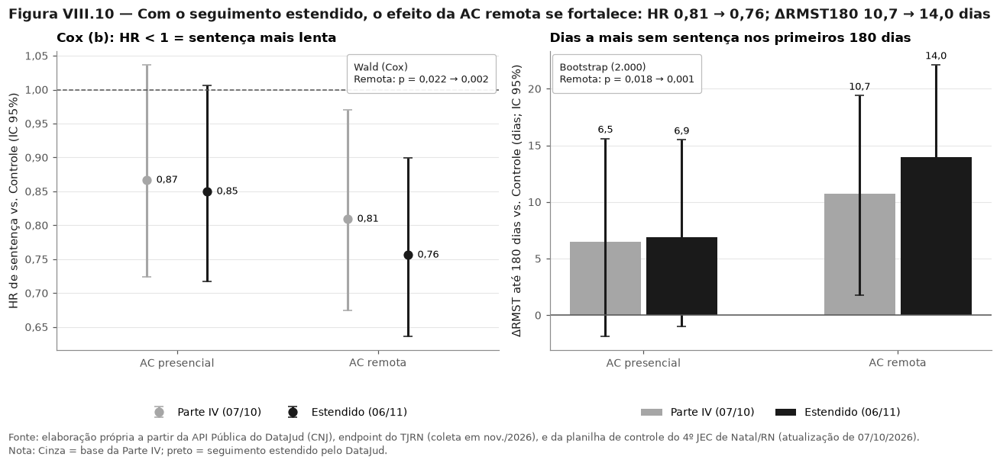

In [177]:
def dj_linha_res(r):
    lin = {'Análise': r['rotulo'], 'Sentenças': r['n_eventos'], 'Censurados': r['n_censurados']}
    for g in ORDEM_GRUPO:
        lin[f'Mediana {g} (dias)'] = r[f'mediana_{g}']
    for g in ('Presencial', 'Remota'):
        lo, hi = r[f'HR_{g}_ic']
        lin[f'HR {g} (IC 95%)'] = f"{fmt_br(r[f'HR_{g}'], 2)} ({fmt_br(lo, 2)}–{fmt_br(hi, 2)}); p = {fmt_p(r[f'HR_{g}_p'])}"
    for g in ('Presencial', 'Remota'):
        lo, hi = r[f'dRMST_{g}_ic']
        lin[f'ΔRMST180 {g} (dias)'] = f"{fmt_br(r[f'dRMST_{g}'], 1)} ({fmt_br(lo, 1)} a {fmt_br(hi, 1)}); p = {fmt_p(r[f'dRMST_{g}_p'])}"
    lin['Log-rank (3 grupos)'] = f"χ² = {fmt_br(r['lr_chi2'], 2)}; p = {fmt_p(r['lr_p'])}"
    return lin


comp_ext = pd.DataFrame([dj_linha_res(res_base), dj_linha_res(res_ext)]).set_index('Análise').T
tabela(comp_ext.rename_axis('Medida'), 'dj_comparacao_estendido',
       'Parte IV × seguimento estendido: medianas, Cox (b) e ΔRMST(180) por grupo (Controle = referência)', secao='8.4.3',
       fonte=FONTE_DJ, nota='Cox (b): grupo + mês de distribuição + origem externa (Efron). ΔRMST: IC percentil bootstrap estratificado '
       '(2.000); p pela aproximação normal. Valores divulgados na Parte IV: medianas 81/96/95 dias; HR 0,87 e 0,81; ΔRMST180 6,5 e 10,7 dias.')

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
pos = np.arange(2)
for j, (r, cor_r, nome) in enumerate([(res_base, CINZA, 'Parte IV (07/10)'), (res_ext, TINTA, f'Estendido ({DJ_CORTE:%d/%m})')]):
    hr = [r[f'HR_{g}'] for g in ('Presencial', 'Remota')]
    lo = [r[f'HR_{g}_ic'][0] for g in ('Presencial', 'Remota')]
    hi = [r[f'HR_{g}_ic'][1] for g in ('Presencial', 'Remota')]
    xx = pos + (j - 0.5) * 0.3
    axs[0].errorbar(xx, hr, yerr=[np.subtract(hr, lo), np.subtract(hi, hr)], fmt='o', color=cor_r, capsize=4, label=nome, ms=7)
    for xi, h in zip(xx, hr):
        axs[0].annotate(fmt_br(h, 2), (xi, h), xytext=(8, 0), textcoords='offset points', va='center', fontsize=8.5)
    dr = [r[f'dRMST_{g}'] for g in ('Presencial', 'Remota')]
    dlo = [r[f'dRMST_{g}_ic'][0] for g in ('Presencial', 'Remota')]
    dhi = [r[f'dRMST_{g}_ic'][1] for g in ('Presencial', 'Remota')]
    axs[1].bar(xx, dr, width=0.28, color=cor_r, label=nome)
    axs[1].errorbar(xx, dr, yerr=[np.subtract(dr, dlo), np.subtract(dhi, dr)], fmt='none', ecolor=TINTA, capsize=4)
    for xi, d, h_ in zip(xx, dr, dhi):
        axs[1].annotate(fmt_br(d, 1), (xi, h_), xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8.5)
axs[0].axhline(1, color=TINTA_2, lw=1, ls='--')
axs[0].set_xticks(pos, ['AC presencial', 'AC remota'])
axs[0].set_xlim(-0.6, 1.6)
axs[0].set_ylabel('HR de sentença vs. Controle (IC 95%)')
axs[0].set_title('Cox (b): HR < 1 = sentença mais lenta')
axs[1].axhline(0, color=TINTA_2, lw=1)
axs[1].set_xticks(pos, ['AC presencial', 'AC remota'])
axs[1].set_ylabel('ΔRMST até 180 dias vs. Controle (dias; IC 95%)')
axs[1].set_title('Dias a mais sem sentença nos primeiros 180 dias')
for ax in axs:
    ax.grid(axis='x', visible=False)
    legenda_abaixo(ax, ncol=2)
anotar_teste(axs[0], texto_teste('Wald (Cox)', extra=f"Remota: p = {fmt_p(res_base['HR_Remota_p'])} → {fmt_p(res_ext['HR_Remota_p'])}"),
             loc='upper right')
anotar_teste(axs[1], texto_teste('Bootstrap (2.000)', extra=f"Remota: p = {fmt_p(res_base['dRMST_Remota_p'])} → {fmt_p(res_ext['dRMST_Remota_p'])}"),
             loc='upper left')
figura(fig, 'dj_efeitos_estendido', f"Com o seguimento estendido, o efeito da AC remota se fortalece: HR {fmt_br(res_base['HR_Remota'], 2)} → "
       f"{fmt_br(res_ext['HR_Remota'], 2)}; ΔRMST180 {fmt_br(res_base['dRMST_Remota'], 1)} → {fmt_br(res_ext['dRMST_Remota'], 1)} dias", secao='8.4.3',
       fonte=FONTE_DJ, nota='Cinza = base da Parte IV; preto = seguimento estendido pelo DataJud.')

**Leitura.** As funções desta seção reproduzem exatamente os números da Parte IV na base original (medianas de 81, 96 e 95 dias; HR 0,87 e 0,81; ΔRMST180 de 6,5 e 10,7 dias), o que garante que a comparação mede só o efeito do seguimento. Com o seguimento estendido até 06/11/2026, o número de sentenças passa de 708 para **797** e o de censurados cai de 230 para 141:

- as **medianas** quase não mudam (81, 97 e 96 dias): a mediana já era bem estimada em 07/10;
- o **log-rank** passa de χ² = 7,5 (p = 0,023) para **χ² = 13,1 (p = 0,001)**;
- o **HR da AC remota** passa de 0,81 (0,67–0,97) para **0,76 (0,64–0,90; p = 0,002)**, e o da presencial de 0,87 para 0,85 (0,72–1,01; p = 0,059);
- o **ΔRMST180 da AC remota** sobe de 10,7 para **14,0 dias (5,0 a 22,1)**; o da presencial fica em 6,9 dias (−1,0 a 15,5).

**Conclusão de VIII-B.** O seguimento curto **não** produzia o efeito; ao contrário, a análise principal era **conservadora**: com mais um mês de observação, a desvantagem de tempo da AC obrigatória, sobretudo da remota, aumenta e fica mais precisa, e a direção e a ordem dos grupos não mudam. A análise estendida é uma **sensibilidade**: usa uma fonte diferente para os censurados e um corte diferente, e por isso não substitui a análise principal, mas reforça a sua conclusão.

## 8.5 VIII-C — As regras TPU reproduzem as variáveis da pesquisa?

A seção 8.3 validou a planilha **variável por variável**. A pergunta agora é outra: se o estudo tivesse sido feito **só com o DataJud**, sem a planilha, as variáveis de análise (tempo, evento, tipo de desfecho, AC) e os **resultados** seriam os mesmos? Essa é a condição para aplicar as mesmas regras à população dos JECs de Natal (8.6), onde não há planilha.

**Construção.** Para os processos vinculados: tempo zero = 1º movimento no 4º JEC; evento = 1º julgamento (R1) até 07/10/2026 e antes da saída da unidade; censura na saída ou em 07/10/2026; grupo = o do sorteio (que só a planilha tem). **Critério pré-fixado** para "reproduz bem": κ ≥ 0,80 para o evento e para o tipo de desfecho; pelo menos 90% dos tempos com diferença ≤ 1 dia entre os processos com evento nas duas fontes; e HR e ΔRMST do DataJud dentro do IC 95% da planilha.

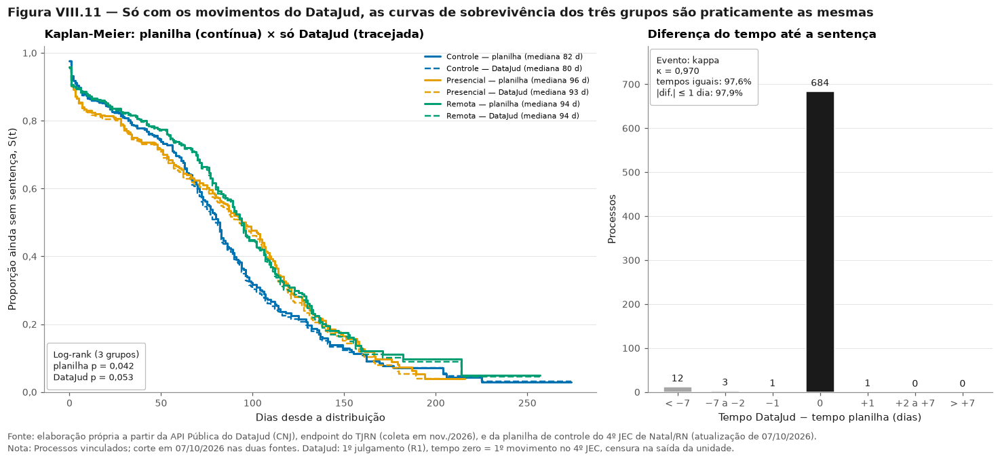

Critério,Valor,Limiar,Atende
κ do evento (sentença até 07/10),"0,970","≥ 0,80",Sim
κ do tipo de desfecho (R1),"0,955","≥ 0,80",Sim
Tempos com |dif.| ≤ 1 dia,"97,9%",≥ 90%,Sim
HR Presencial (DataJud) no IC da planilha,"0,90 vs. 0,88 (0,74–1,06)",dentro do IC,Sim
HR Remota (DataJud) no IC da planilha,"0,82 vs. 0,82 (0,68–0,98)",dentro do IC,Sim
ΔRMST180 Presencial (DataJud) no IC da planilha,"4,4 vs. 5,4 (-3,0 a 14,8)",dentro do IC,Sim
ΔRMST180 Remota (DataJud) no IC da planilha,"9,6 vs. 9,8 (1,5 a 18,4)",dentro do IC,Sim


Regras TPU reproduzem a planilha: True


In [178]:
vc = v.copy()
_s = vc['dj_sent_dt'].dt.normalize()
_x = vc['dj_saida_dt'].dt.normalize()
ev_dj = _s.notna() & (_s <= DATA_CORTE)
sai_dj = ~ev_dj & _x.notna() & (_x <= DATA_CORTE)
t0 = vc['dj_entrada'].dt.normalize()
vc['T_dj'] = np.where(ev_dj, (_s - t0).dt.days, np.where(sai_dj, (_x - t0).dt.days, (DATA_CORTE - t0).dt.days)).astype(float)
vc['E_dj'] = ev_dj.astype(int)
vc['dT'] = np.where((vc['E_dj'] == 1) & (vc['evento'].astype(int) == 1), vc['T_dj'] - vc['tempo'].astype(float), np.nan)

k_ev = dj_kappa(vc['evento'].astype(int), vc['E_dj'])
k_tp = kap_desf['R1']
dT = vc['dT'].dropna()
s_pl = dj_base_sob(vc, 'tempo', 'evento')
s_dj = dj_base_sob(vc, 'T_dj', 'E_dj')
r_pl = dj_analise_sob(s_pl, 'Planilha (vinculados)')
r_dj = dj_analise_sob(s_dj, 'Só DataJud (regras TPU)')

fig, axs = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axs[0]
for g in ORDEM_GRUPO:
    for s_, ls, rot in [(s_pl, '-', 'planilha'), (s_dj, '--', 'DataJud')]:
        sg = s_[s_.grupo == g]
        km = KaplanMeierFitter().fit(sg['T'], sg['E'])
        sf = km.survival_function_.iloc[:, 0]
        ax.step(sf.index, sf.values, where='post', color=CORES_GRUPO[g], ls=ls, lw=2 if ls == '-' else 1.6,
                label=f'{g} — {rot} (mediana {fmt_br(km.median_survival_time_, 0)} d)')
ax.set_xlabel(ROTULOS['dias'])
ax.set_ylabel(ROTULOS['S'])
ax.set_ylim(0, 1.02)
ax.set_title('Kaplan-Meier: planilha (contínua) × só DataJud (tracejada)')
ax.legend(fontsize=7.5, loc='upper right')
anotar_teste(ax, texto_teste('Log-rank (3 grupos)', f'planilha p = {fmt_p(r_pl["lr_p"])}', extra=f'DataJud p = {fmt_p(r_dj["lr_p"])}'),
             loc='lower left')
fx = dj_faixa(dT)
barras_verticais(axs[1], FAIXAS_DIF, fx.values, cores=[TINTA if f == '0' else CINZA for f in FAIXAS_DIF],
                 ylabel='Processos', xlabel='Tempo DataJud − tempo planilha (dias)')
axs[1].set_title('Diferença do tempo até a sentença')
anotar_teste(axs[1], texto_teste('Evento: kappa', f'κ = {fmt_br(k_ev[0], 3)}', efeito=f'tempos iguais: {pct_br((dT == 0).mean())}',
                                 extra=f'|dif.| ≤ 1 dia: {pct_br((dT.abs() <= 1).mean())}'), loc='upper left')
figura(fig, 'dj_regras_km', 'Só com os movimentos do DataJud, as curvas de sobrevivência dos três grupos são praticamente as mesmas',
       secao='8.5', fonte=FONTE_DJ, nota='Processos vinculados; corte em 07/10/2026 nas duas fontes. DataJud: 1º julgamento (R1), '
       'tempo zero = 1º movimento no 4º JEC, censura na saída da unidade.')

crit = pd.DataFrame([
    {'Critério': 'κ do evento (sentença até 07/10)', 'Valor': fmt_br(k_ev[0], 3), 'Limiar': '≥ 0,80', 'Atende': k_ev[0] >= 0.8},
    {'Critério': 'κ do tipo de desfecho (R1)', 'Valor': fmt_br(k_tp[0], 3), 'Limiar': '≥ 0,80', 'Atende': k_tp[0] >= 0.8},
    {'Critério': 'Tempos com |dif.| ≤ 1 dia', 'Valor': pct_br((dT.abs() <= 1).mean()), 'Limiar': '≥ 90%',
     'Atende': (dT.abs() <= 1).mean() >= 0.9},
] + [{'Critério': f'HR {g} (DataJud) no IC da planilha', 'Valor': f"{fmt_br(r_dj[f'HR_{g}'], 2)} vs. {fmt_br(r_pl[f'HR_{g}'], 2)} "
      f"({fmt_br(r_pl[f'HR_{g}_ic'][0], 2)}–{fmt_br(r_pl[f'HR_{g}_ic'][1], 2)})", 'Limiar': 'dentro do IC',
      'Atende': r_pl[f'HR_{g}_ic'][0] <= r_dj[f'HR_{g}'] <= r_pl[f'HR_{g}_ic'][1]} for g in ('Presencial', 'Remota')]
  + [{'Critério': f'ΔRMST180 {g} (DataJud) no IC da planilha', 'Valor': f"{fmt_br(r_dj[f'dRMST_{g}'], 1)} vs. {fmt_br(r_pl[f'dRMST_{g}'], 1)} "
      f"({fmt_br(r_pl[f'dRMST_{g}_ic'][0], 1)} a {fmt_br(r_pl[f'dRMST_{g}_ic'][1], 1)})", 'Limiar': 'dentro do IC',
      'Atende': r_pl[f'dRMST_{g}_ic'][0] <= r_dj[f'dRMST_{g}'] <= r_pl[f'dRMST_{g}_ic'][1]} for g in ('Presencial', 'Remota')])
DJ_REGRAS_OK = bool(crit['Atende'].all())
tabela(crit, 'dj_criterios', 'Critérios pré-fixados para aplicar as regras TPU à população', secao='8.5', fonte=FONTE_DJ,
       destaque=~crit['Atende'], nota=f'Linhas em destaque = critério não atendido. Decisão: '
       f'{"aplicar as regras à população (8.6)" if DJ_REGRAS_OK else "aplicar com ressalvas"}.')
print('Regras TPU reproduzem a planilha:', DJ_REGRAS_OK)

**Leitura.** Construídas **só com os movimentos** (sem nenhuma informação da planilha além do grupo sorteado), as variáveis reproduzem as da pesquisa: o evento concorda com κ = 0,970, o tipo de desfecho com κ = 0,955, e 97,9% dos tempos diferem em no máximo 1 dia (a maioria das diferenças grandes são os acordos posteriores à sentença, em que a planilha é que se afasta da primeira sentença). As curvas de Kaplan-Meier das duas fontes praticamente se sobrepõem em cada grupo, e os efeitos estimados ficam dentro do IC da planilha nos mesmos processos (HR da AC remota 0,82 nas duas fontes; ΔRMST180 de 9,6 × 9,8 dias). **Todos os critérios pré-fixados foram atendidos**: as regras TPU podem ser aplicadas à população dos JECs de Natal, onde não há planilha, com a garantia de que medem o mesmo que a pesquisa mediu.

## 8.6 VIII-D — O 4º JEC entre os Juizados Cíveis de Natal

### 8.6.1 A população e o desenho

**População.** Processos de **classe 436** (Procedimento do Juizado Especial Cível), ou de classe 156 (Cumprimento de sentença) com o movimento 14739 de evolução de classe (o mesmo processo, já na fase de cumprimento), cujo **1º movimento** foi lançado em um dos 14 JECs cíveis de Natal, ajuizados de 01/01 a 03/08 de **2025** (antes) e de **2026** (durante o experimento), mesma janela do calendário. A unidade de cada processo é o juizado do 1º movimento (a distribuição); quem saiu depois continua contado na unidade de origem, censurado na saída, como na Parte IV. As regras de 8.2 são as mesmas para todas as unidades.

**Desfechos com horizonte fixo, por coorte mensal.** Comparar tempos de unidades ou anos com seguimentos diferentes mistura o efeito com o tempo de observação (o artefato da entrada escalonada; seção 2.5). Por isso, cada processo é acompanhado **só nos primeiros 90 dias**, e cada coorte mensal de ajuizamento tem o mesmo horizonte:

- **P90**: proporção sentenciada até 90 dias, 1 − Ŝ(90) de Kaplan-Meier (saída da unidade = censura);
- **RMST90**: dias, em média, sem sentença nos primeiros 90 dias;
- **% sem mérito até 90 dias** e **% homologação até 90 dias**: proporções simples.

**Diferenças em diferenças (DiD).** Para cada unidade *u*, Δ_u = Y_u,2026 − Y_u,2025; o DiD do 4º JEC é Δ_4º − média de Δ dos outros 13. Com 14 unidades, a inferência não pode tratar processos como independentes (os processos de uma unidade compartilham juiz, cartório e pauta); usa-se a **inferência por permutação entre unidades** (placebo): o mesmo DiD é calculado fingindo que cada um dos outros 13 juizados foi o "tratado", e o p-valor é a posição do 4º JEC entre os 14 (o menor p possível é 1/14 ≈ 0,071). O DiD supõe **tendências paralelas** antes de 2026, verificadas no gráfico mensal de 2025.

**Leitura.** É uma comparação **observacional** do efeito do **experimento sobre a unidade** (os três braços somados, mais o que mudou na rotina por causa dele: pauta de audiências, reatividade, o juiz-pesquisador), e não do efeito do rito.

In [179]:
DJ_JAN_AGO = {2025: (pd.Timestamp('2025-01-01'), pd.Timestamp('2025-08-03')),
              2026: (pd.Timestamp('2026-01-01'), pd.Timestamp('2026-08-03'))}
H_DJ = 90
pop = pd.DataFrame()
if DJ_POP4_OK:
    _linhas = []
    for x in dj_pop_regs.values():
        if x.get('grau') != 'JE':
            continue
        movs = sorted(x.get('movimentos') or [], key=lambda m: m['dataHora'])
        if not movs:
            continue
        un = next((dj_oj(m) for m in movs if dj_oj(m)), '')
        if un not in JECS_NATAL:
            continue
        cl = (x.get('classe') or {}).get('codigo')
        evo = any(int(m['codigo']) == 14739 for m in movs)
        if not (cl == 436 or (cl == 156 and evo)):
            continue
        r = dj_derivar(x, un)
        r['numero'] = x['numeroProcesso']
        _linhas.append(r)
    pop = pd.DataFrame(_linhas).drop_duplicates('numero')
    pop['jec'] = pop['unidade'].map(JECS_NATAL)
    pop['quarto'] = pop['unidade'] == COD_4JEC
    pop['ano'] = pop['ajuizamento'].dt.year
    pop['coorte'] = pop['ajuizamento'].dt.to_period('M')
    pop['janela'] = [(a in DJ_JAN_AGO) and (DJ_JAN_AGO[a][0] <= d <= DJ_JAN_AGO[a][1]) for a, d in zip(pop['ano'], pop['ajuizamento'])]
    print(f'População: {len(pop):,} processos; por ano de ajuizamento:', pop['ano'].value_counts().sort_index().to_dict())
else:
    print('Coleta da população dos JECs de Natal ainda não disponível no cache (datajud_sondagem/natal/).')
    DJ_CORTE_POP = DJ_CORTE

População: 3,714 processos; por ano de ajuizamento: {2024: 1366, 2025: 1432, 2026: 916}


In [180]:
if DJ_POP4_OK:
    vol_pop = dj_volume_diario(dj_pop_regs.values(), '2026-08-15', max(x.get('dataHoraUltimaAtualizacao', '')[:10] for x in dj_pop_regs.values()))
    DJ_CORTE_POP, nivel_pop, queda_pop = dj_corte_confiavel(vol_pop, DATA_CORTE - pd.Timedelta(days=28), DATA_CORTE)
    t0p = pop['entrada'].dt.normalize()
    _s = pop['sent_dt'].dt.normalize()
    _x = pop['saida_dt'].dt.normalize()
    evp = _s.notna() & (_s <= DJ_CORTE_POP)
    saip = ~evp & _x.notna() & (_x <= DJ_CORTE_POP)
    pop['T'] = np.where(evp, (_s - t0p).dt.days, np.where(saip, (_x - t0p).dt.days, (DJ_CORTE_POP - t0p).dt.days)).astype(float)
    pop['E'] = evp.astype(int)
    pop['tipo'] = np.where(evp, pop['sent_tipo'], np.where(saip, 'Redistribuição', 'Ativo'))
    pop = pop[pop['T'] >= 0].copy()
    pop['sm90'] = (pop['tipo'] == 'Sem mérito') & (pop['T'] <= H_DJ)
    pop['hom90'] = (pop['tipo'] == 'Homologação') & (pop['T'] <= H_DJ)

    # cobertura da amostra
    p4 = pop[pop['quarto'] & pop['janela'] & (pop['ano'] == 2026)]
    na_pop = dj['numero'].isin(p4['numero'])
    def _motivo(n):
        x = _principal.get(n)
        if x is None:
            return 'sem registro de juizado no DataJud'
        movs = sorted(x.get('movimentos') or [], key=lambda m: m['dataHora'])
        cl = (x.get('classe') or {}).get('codigo')
        if not (cl == 436 or (cl == 156 and any(int(m['codigo']) == 14739 for m in movs))):
            return f'outra classe ({cl} {(x.get("classe") or {}).get("nome") or ""})'.strip()
        if movs and dj_oj(movs[0]) != COD_4JEC:
            return '1º movimento em outro órgão (chegou por redistribuição)'
        if not ('20260101' <= str(x.get('dataAjuizamento'))[:8] <= '20260803'):
            return 'ajuizado fora de 01/01 a 03/08/2026'
        return 'outro'
    mot = dj.loc[~na_pop, 'numero'].map(_motivo).value_counts()
    cob = pd.DataFrame([['População DataJud: 4º JEC, 2026 (01/01 a 03/08)', len(p4)],
                        ['   dos quais estão na planilha', int(p4['numero'].isin(dj['numero']).sum())],
                        ['   não estão na planilha', int((~p4['numero'].isin(dj['numero'])).sum())],
                        ['Planilha (938 processos)', len(dj)],
                        ['   dos quais estão na população DataJud', int(na_pop.sum())]]
                       + [[f'   fora da população: {k}', int(v)] for k, v in mot.items()], columns=['Conjunto', 'Processos'])
    tabela(cob, 'dj_cobertura', 'A definição de população recupera quase todos os processos do experimento', secao='8.6.1', fonte=FONTE_DJ,
           nota='População = classe 436 (ou 156 com evolução de classe), 1º movimento no juizado, ajuizamento na janela. '
                'Motivos de exclusão avaliados no registro principal do processo (8.3.1).')

if DJ_POP_OK:
    npop = pop[pop['janela']].groupby(['jec', 'ano']).size().unstack().reindex([JECS_NATAL[c] for c in JECS_NATAL])
    fig, ax = plt.subplots(figsize=(12, 4.8))
    barras_agrupadas(ax, npop.rename(columns=str), cores={'2025': CINZA, '2026': TINTA}, ylabel='Processos ajuizados (01/01 a 03/08)')
    ax.set_xticks(range(len(npop)), [f'{j} JEC' for j in npop.index], fontsize=8.5)
    ax.set_title('Processos da população por juizado e ano (mesma janela do calendário)')
    legenda_abaixo(ax, ncol=2)
    _o = npop[2026].values; _e = np.full_like(_o, _o.mean(), dtype=float)
    chi_n, p_n = stats.chisquare(_o, _e)
    anotar_teste(ax, texto_teste('Qui-quadrado de aderência (2026)', f'χ² = {fmt_br(chi_n, 2)} (13 gl)', p_n,
                                 'H₀: distribuição igual entre os 14'), loc='lower right')
    figura(fig, 'dj_pop_n', 'A distribuição por sorteio divide os processos quase igualmente entre os 14 JECs', secao='8.6.1',
           fonte=FONTE_DJ_POP, nota=f'Classe 436 (ou 156 com evolução de classe); unidade = juizado do 1º movimento. Corte do índice: {DJ_CORTE_POP:%d/%m/%Y}.')

Conjunto,Processos
"População DataJud: 4º JEC, 2026 (01/01 a 03/08)",883
dos quais estão na planilha,882
não estão na planilha,1
Planilha (938 processos),938
dos quais estão na população DataJud,882
fora da população: 1º movimento em outro órgão (chegou por redistribuição),36
fora da população: sem registro de juizado no DataJud,12
fora da população: outra classe (94 Despejo por Falta de Pagamento Cumulado Com Cobrança),2
fora da população: outra classe (37 Embargos de Terceiro Cível),2
fora da população: ajuizado fora de 01/01 a 03/08/2026,1


**Leitura.** A definição de população é validada pelo próprio experimento: dos 883 processos que o DataJud atribui ao 4º JEC entre 01/01 e 03/08/2026 (classe 436, 1º movimento na unidade), **882 estão na planilha**, isto é, o sorteio do pesquisador cobriu praticamente toda a entrada de ações de conhecimento da unidade. No sentido inverso, 882 dos 938 processos da planilha estão na população; os 56 restantes não são falhas da regra, e sim processos que ela exclui por desenho: 36 chegaram ao 4º JEC por redistribuição (o 1º movimento é de outro órgão), 12 não têm registro de juizado com passagem pelo 4º JEC no índice (8.3.1), 7 têm outra classe (despejo, embargos de terceiro, execução de título, procedimento comum ou da Fazenda Pública), que a planilha incluiu e a população de classe 436 não inclui, e 1 foi ajuizado antes de 2026.

**Situação da coleta: a comparação com os outros 13 JECs ficou parcial.** A API do CNJ esteve sobrecarregada durante toda a coleta (HTTP 429, `es_rejected_execution_exception`, erros de gateway): a certa altura, rendia cerca de 100 processos em duas horas. Foram coletados, processo a processo, **todos** os processos do **4º JEC** ajuizados em 2024, 2025 e de 01/01 a 03/08/2026; dos **outros 13 JECs**, nenhuma janela pôde ser concluída. Por isso, as análises com tempos e horizonte fixo entre unidades (8.6.3 tendências, 8.6.4 DiD com 90 dias, 8.6.6 tipicidade) **não foram executadas nesta versão**. O código está pronto: `coleta_natal.py` retoma do cache (`natal/estado.json`) e o notebook passa a executá-las sozinho quando as janelas estiverem completas (só usa fatias concluídas e não acessa a rede). Em substituição, a seção 8.6.2 compara os 14 juizados por **consultas agregadas**, que a API respondeu.

### 8.6.2 Os 14 JECs por consultas agregadas (plano B)

Como a API rejeitava as consultas que devolvem documentos (a fase *fetch* do Elasticsearch), os outros 13 juizados foram consultados por **agregações** (`size: 0`), que só devolvem contagens e passaram na primeira tentativa (scripts `contagens_mensais.py` e `contagens_desfecho.py`; caches `natal_contagens_*.json`). As agregações dão duas informações por juizado:

1. o **volume mensal de ajuizamentos** (classe 436/156), de 01/2025 a 03/08/2026;
2. para as janelas de 01/01 a 03/08 de 2025 e de 2026, quantos processos têm, **na data da coleta**, algum movimento de **sentença**, de **mérito**, **sem mérito** e de **homologação**, pelos mesmos códigos TPU de 8.2.

**O que muda em relação ao desenho de 8.6.1.** Não há tempos: a medida é a proporção de processos com cada tipo de movimento **até a coleta** (novembro de 2026), e não até 90 dias. Os processos de 2025 tiveram mais tempo de observação que os de 2026, mas essa diferença é **a mesma para todos os juizados** (mesmas janelas de ajuizamento, mesma data de coleta), e por isso se cancela na diferença em diferenças. As categorias não são exclusivas (um processo pode ter extinção sem mérito e, depois, um acordo homologado), e a unidade é o órgão **atual** do registro (quem foi redistribuído conta no destino). A inferência é a mesma de 8.6.1: **permutação entre unidades** (placebo), com p mínimo de 1/14.

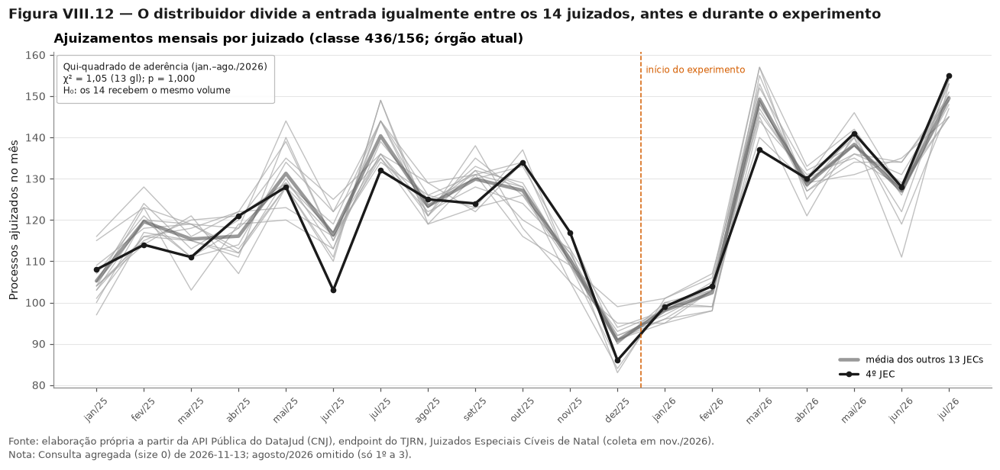

Movimento (até a coleta),4º JEC 2025,4º JEC 2026,Outros 2025,Outros 2026,DiD (p.p.),Posição |DiD| (1 = maior),p (permutação)
Sentença,"99,5","88,3","98,3","91,9","-4,9",3,"0,214"
Mérito,"61,1","47,6","68,2","66,4","-11,8",1,"0,071"
Sem mérito,"36,3","33,4","25,6","19,8","2,9",5,"0,357"
Homologação,"13,4","9,5","13,1","9,9","-0,7",8,"0,571"


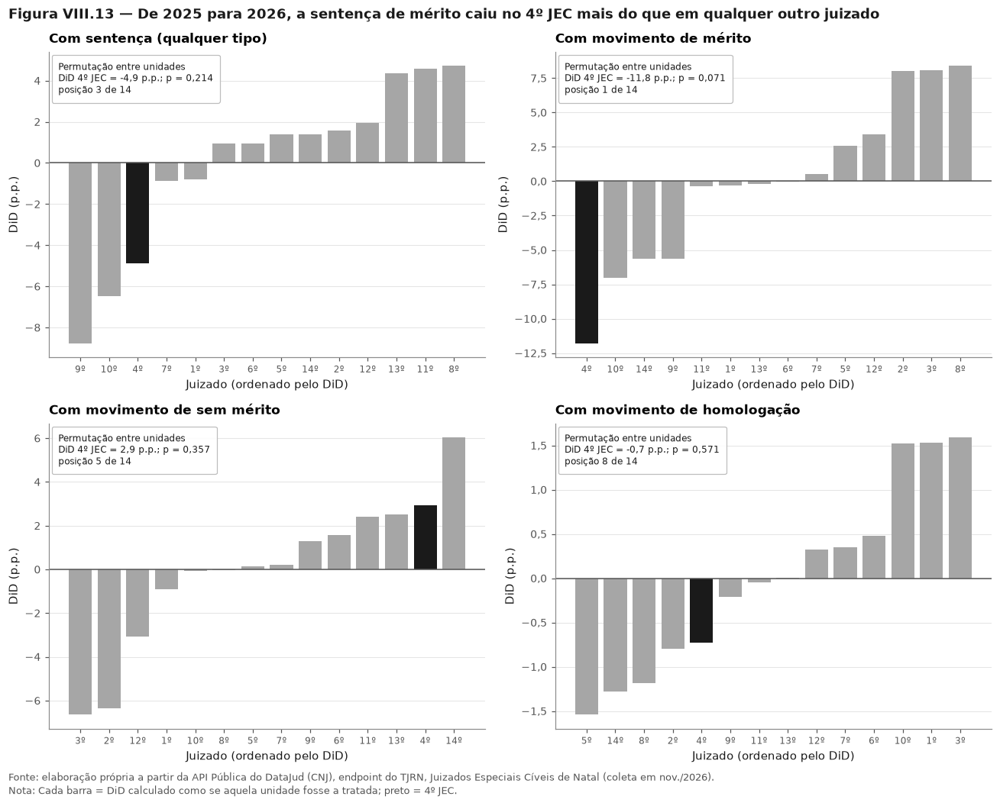

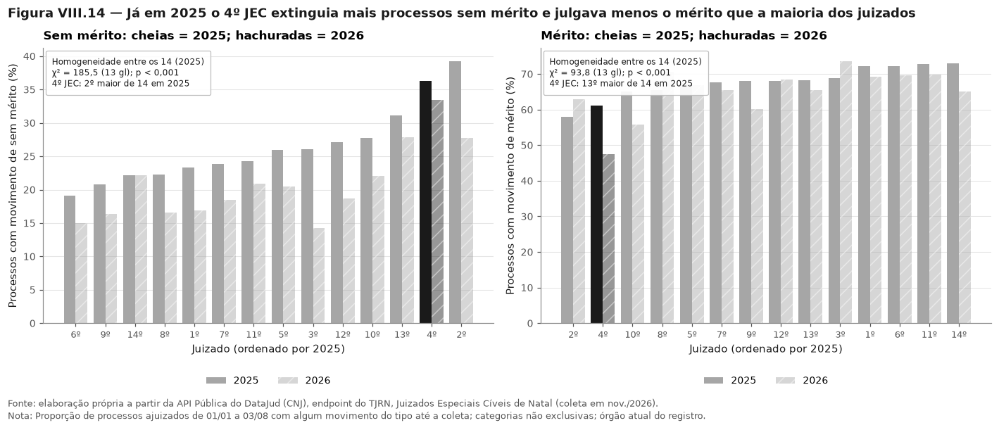

Juizado,n 2025,n 2026,Sentença 2025,Sentença 2026,Mérito 2025,Mérito 2026,Sem mérito 2025,Sem mérito 2026,Homologação 2025,Homologação 2026
1º,862,896,"98,5","91,1","72,2","69,2","23,3","16,9","13,0","11,2"
2º,841,909,"99,4","94,2","58,0","62,8","39,2","27,7","12,2","8,3"
3º,864,905,"99,0","93,1","68,8","73,6","26,0","14,3","12,4","10,6"
4º,821,898,"99,5","88,3","61,1","47,6","36,3","33,4","13,4","9,5"
5º,844,889,"98,0","92,6","67,2","66,9","25,9","20,5","12,6","7,9"
6º,846,893,"97,5","91,7","72,2","69,5","19,1","15,0","13,0","10,2"
7º,838,910,"97,7","90,2","67,7","65,5","23,9","18,5","12,1","9,1"
8º,849,909,"94,9","92,6","65,5","70,6","22,3","16,6","14,3","9,9"
9º,887,907,"97,3","82,5","68,0","60,1","20,7","16,3","11,4","7,9"
10º,852,895,"99,1","86,4","65,0","55,9","27,7","22,0","12,8","10,9"


In [181]:
DJ_AGG_VOL = DJ_PASTA / 'natal_contagens_mensais.json'
DJ_AGG_DESF = DJ_PASTA / 'natal_contagens_desfecho.json'
DJ_AGG_OK = DJ_AGG_VOL.exists() and DJ_AGG_DESF.exists()
if DJ_AGG_OK:
    agv = json.loads(DJ_AGG_VOL.read_text(encoding='utf-8'))
    agd = json.loads(DJ_AGG_DESF.read_text(encoding='utf-8'))
    # ---- volume mensal
    vol = pd.DataFrame({JECS_NATAL[o]: pd.Series(m) for o, m in agv['orgaos'].items()}).fillna(0).sort_index()
    vol = vol.loc[[k for k in vol.index if '202501' <= k <= '202607']]
    fig, ax = plt.subplots(figsize=(12, 5))
    xs = np.arange(len(vol))
    for j in vol.columns:
        if j != '4º':
            ax.plot(xs, vol[j], color=COR_OUTROS, lw=0.9, alpha=0.7)
    ax.plot(xs, vol.drop(columns='4º').mean(axis=1), color=TINTA_2, lw=3, alpha=0.6, label='média dos outros 13 JECs')
    ax.plot(xs, vol['4º'], color=COR_4JEC, lw=2.2, marker='o', ms=4, label='4º JEC')
    ax.axvline(11.5, color=DESTAQUE, ls='--', lw=1)
    ax.text(11.6, ax.get_ylim()[1] * 0.98, 'início do experimento', color=DESTAQUE, fontsize=8, va='top')
    ax.set_xticks(xs, [f"{MESES_PT[int(k[4:]) - 1]}/{k[2:4]}" for k in vol.index], rotation=45, fontsize=8)
    ax.set_ylabel('Processos ajuizados no mês')
    ax.set_title('Ajuizamentos mensais por juizado (classe 436/156; órgão atual)')
    ax.legend(loc='lower right', fontsize=8)
    j26 = pd.Series({JECS_NATAL[o]: d['2026']['n'] for o, d in agd['orgaos'].items()})
    chi_v2, p_v2 = stats.chisquare(j26.values)
    anotar_teste(ax, texto_teste('Qui-quadrado de aderência (jan.–ago./2026)', f'χ² = {fmt_br(chi_v2, 2)} (13 gl)', p_v2,
                                 'H₀: os 14 recebem o mesmo volume'), loc='upper left', tamanho=8)
    figura(fig, 'dj_agg_volume', 'O distribuidor divide a entrada igualmente entre os 14 juizados, antes e durante o experimento',
           secao='8.6.2', fonte=FONTE_DJ_POP, nota=f'Consulta agregada (size 0) de {agv["coletado_em"][:10]}; agosto/2026 omitido (só 1º a 3).')

    # ---- desfechos por juizado e ano
    linhas = []
    for o, d in agd['orgaos'].items():
        for a in ('2025', '2026'):
            r = d[a]
            linhas.append({'jec': JECS_NATAL[o], 'ano': int(a), 'n': r['n'], 'Sentença': r['sentenca'] / r['n'],
                           'Mérito': r.get('merito', 0) / r['n'], 'Sem mérito': r.get('sem_merito', 0) / r['n'],
                           'Homologação': r.get('homologacao', 0) / r['n']})
    agt = pd.DataFrame(linhas)
    DESF_AGG = ['Sentença', 'Mérito', 'Sem mérito', 'Homologação']
    wa = agt.pivot(index='jec', columns='ano', values=DESF_AGG)
    did_agg, rows = {}, []
    for y in DESF_AGG:
        delta = wa[(y, 2026)] - wa[(y, 2025)]
        did = pd.Series({u: delta[u] - delta.drop(u).mean() for u in delta.index})
        did_agg[y] = did
        obs = did['4º']
        rows.append({'Movimento (até a coleta)': y, '4º JEC 2025': 100 * wa.loc['4º', (y, 2025)], '4º JEC 2026': 100 * wa.loc['4º', (y, 2026)],
                     'Outros 2025': 100 * wa[(y, 2025)].drop('4º').mean(), 'Outros 2026': 100 * wa[(y, 2026)].drop('4º').mean(),
                     'DiD (p.p.)': 100 * obs, 'Posição |DiD| (1 = maior)': int((did.abs() >= abs(obs) - 1e-12).sum()),
                     'p (permutação)': float(np.mean(did.abs() >= abs(obs) - 1e-12))})
    did_agg_tab = pd.DataFrame(rows)
    tabela(did_agg_tab, 'dj_agg_did', 'Diferenças em diferenças por consultas agregadas: 4º JEC × outros 13 JECs, 2025 × 2026',
           secao='8.6.2', fonte=FONTE_DJ_POP, destaque='p (permutação)', casas=1,
           nota='Percentual de processos ajuizados de 01/01 a 03/08 de cada ano com algum movimento do tipo até a coleta (nov./2026). '
                '"Outros" = média simples das 13 unidades. p = proporção das 14 unidades com |DiD placebo| ≥ |DiD do 4º JEC|.')
    fig, axs = plt.subplots(2, 2, figsize=(12, 9))
    for ax, y in zip(axs.flat, DESF_AGG):
        s_ = (100 * did_agg[y]).sort_values()
        ax.bar(range(len(s_)), s_.values, color=[COR_4JEC if u == '4º' else COR_OUTROS for u in s_.index])
        ax.axhline(0, color=TINTA_2, lw=1)
        ax.set_xticks(range(len(s_)), list(s_.index), fontsize=8)
        ax.set_xlabel('Juizado (ordenado pelo DiD)')
        ax.set_ylabel('DiD (p.p.)')
        ax.set_title(f'Com movimento de {y.lower()}' if y != 'Sentença' else 'Com sentença (qualquer tipo)')
        ax.grid(axis='x', visible=False)
        lin = did_agg_tab[did_agg_tab['Movimento (até a coleta)'] == y].iloc[0]
        anotar_teste(ax, texto_teste('Permutação entre unidades', f"DiD 4º JEC = {fmt_br(lin['DiD (p.p.)'], 1)} p.p.", lin['p (permutação)'],
                                     f"posição {lin['Posição |DiD| (1 = maior)']} de 14"), loc='upper left', tamanho=8)
    figura(fig, 'dj_agg_did', ('De 2025 para 2026, a sentença de mérito caiu no 4º JEC mais do que em qualquer outro juizado'
                               if did_agg_tab.set_index('Movimento (até a coleta)').loc['Mérito', 'Posição |DiD| (1 = maior)'] == 1
                               else 'Diferenças em diferenças entre os 14 juizados (placebo por permutação)'),
           secao='8.6.2', fonte=FONTE_DJ_POP, nota='Cada barra = DiD calculado como se aquela unidade fosse a tratada; preto = 4º JEC.')

    # ---- tipicidade em 2025 (antes do experimento)
    fig, axs = plt.subplots(1, 2, figsize=(13, 5))
    for ax, y in zip(axs, ['Sem mérito', 'Mérito']):
        s25 = wa[(y, 2025)].sort_values()
        xs = np.arange(len(s25))
        cor = [COR_4JEC if u == '4º' else COR_OUTROS for u in s25.index]
        ax.bar(xs - 0.2, 100 * s25.values, width=0.4, color=cor, label='2025')
        ax.bar(xs + 0.2, 100 * wa.loc[s25.index, (y, 2026)].values, width=0.4, color=cor, alpha=0.45, hatch='//',
               edgecolor='white', label='2026')
        ax.set_xticks(xs, list(s25.index), fontsize=8.5)
        ax.set_xlabel('Juizado (ordenado por 2025)')
        ax.set_ylabel(f'Processos com movimento de {y.lower()} (%)')
        ax.set_title(f'{y}: cheias = 2025; hachuradas = 2026')
        ax.grid(axis='x', visible=False)
        ct = np.array([[agd['orgaos'][o]['2025'][{'Sem mérito': 'sem_merito', 'Mérito': 'merito'}[y]],
                        agd['orgaos'][o]['2025']['n'] - agd['orgaos'][o]['2025'][{'Sem mérito': 'sem_merito', 'Mérito': 'merito'}[y]]]
                       for o in agd['orgaos']])
        chi_t, p_t, gl_t, _ = stats.chi2_contingency(ct)
        pos = int((s25 > s25['4º']).sum()) + 1
        anotar_teste(ax, texto_teste('Homogeneidade entre os 14 (2025)', f'χ² = {fmt_br(chi_t, 1)} ({gl_t} gl)', p_t,
                                     f'4º JEC: {pos}º maior de 14 em 2025'), loc='upper left', tamanho=8)
        legenda_abaixo(ax, ncol=2)
    figura(fig, 'dj_agg_tipicidade', 'Já em 2025 o 4º JEC extinguia mais processos sem mérito e julgava menos o mérito que a maioria dos juizados',
           secao='8.6.2', fonte=FONTE_DJ_POP, nota='Proporção de processos ajuizados de 01/01 a 03/08 com algum movimento do tipo até a coleta; '
           'categorias não exclusivas; órgão atual do registro.')
    tabela((agt.assign(**{c: 100 * agt[c] for c in DESF_AGG}).pivot(index='jec', columns='ano', values=['n'] + DESF_AGG)
            .pipe(lambda t: t.set_axis([f'{a} {b}' for a, b in t.columns], axis=1))
            .loc[[JECS_NATAL[c] for c in JECS_NATAL]].rename_axis('Juizado')),
           'dj_agg_juizados', 'Volume e percentual de processos com cada tipo de movimento, por juizado e ano (consultas agregadas)',
           secao='8.6.2', fonte=FONTE_DJ_POP, casas=1, formatos={'n 2025': 'int', 'n 2026': 'int'},
           destaque=lambda df: df.index == '4º', nota='Percentuais até a coleta (nov./2026); janelas de 01/01 a 03/08.')
else:
    print('Consultas agregadas ainda não disponíveis (contagens_mensais.py, contagens_desfecho.py).')

**Leitura.**

- **Volume.** O distribuidor reparte a entrada de modo praticamente idêntico entre os 14 juizados, mês a mês, em 2025 e em 2026 (χ² de aderência = 1,05 com 13 gl em 2026; p ≈ 1). O 4º JEC não recebeu menos processos durante o experimento: a pauta extra de audiências não foi compensada por redução da distribuição.
- **O 4º JEC não era um juizado típico antes do experimento.** Em 2025, ele já era o **2º com mais extinções sem mérito** (36,3% dos processos com esse movimento, contra 25,6% na média dos outros 13) e o **2º com menos julgamentos de mérito** (61,1% contra 68,2%); a heterogeneidade entre as 14 unidades é grande (χ² = 185,5 e 93,8; 13 gl; p < 0,001). O perfil "muita extinção, pouco mérito" é, portanto, um traço da unidade (juiz, cartório, prática de extinguir pela ausência do autor e pela inadmissibilidade do rito), e não uma criação do experimento. Isso responde em parte à questão 2.10: o 4º JEC é uma unidade **atípica** dentro de Natal, o que reforça que os efeitos estimados aqui não se transportam automaticamente às demais.
- **Diferenças em diferenças.** De 2025 para 2026, a proporção de processos com **sentença de mérito** caiu 13,5 pontos no 4º JEC (61,1% → 47,6%) e só 1,8 ponto, em média, nos outros 13: o DiD de **−11,8 p.p.** é o **maior em valor absoluto entre as 14 unidades** (p de permutação = 1/14 = 0,071, o menor possível com 14 unidades). A proporção com alguma sentença caiu 4,9 p.p. a mais que nos outros (3ª maior queda; p = 0,21), a de extinção sem mérito subiu 2,9 p.p. relativamente (p = 0,36) e a de homologação não mudou (p = 0,57).

A queda do mérito é coerente com o que o sorteio mostrou dentro da unidade (Partes III e IV): nos grupos com AC obrigatória, o julgamento de mérito passa a esperar a audiência, e parte dos processos termina antes, por acordo ou extinção. Como medida, porém, ela mistura duas coisas: menos processos **chegaram** ao mérito **até a coleta** (atraso) e, possivelmente, menos chegarão (mudança de composição); com dados agregados, sem tempos, não é possível separá-las. É uma comparação **observacional**, no nível da unidade, com N = 14, e o p de 0,071 está no limite do que a permutação permite detectar: indica que a mudança do 4º JEC foi a maior da capital, não que ela seja estatisticamente certa.

### 8.6.3 Tendências mensais e o pressuposto das tendências paralelas

O gráfico mostra o P90 de cada coorte mensal: o 4º JEC em preto e os outros 13 em cinza (a linha cinza grossa é a média deles). A linha vertical marca o início do experimento. **Teste das tendências paralelas (2025):** regressão do P90 mensal de cada unidade no mês, com interação mês × 4º JEC; H₀: a inclinação do 4º JEC em 2025 é igual à dos demais.

In [182]:
def dj_resumo(sub, h=H_DJ):
    T, E = sub['T'].values, sub['E'].values
    S = dj_km_grade(T, E, h)
    return pd.Series({'n': len(sub), 'P90': 1 - S[h], 'RMST90': S[:h].sum(), 'SM90': sub['sm90'].mean(), 'HOM90': sub['hom90'].mean()})


if DJ_POP_OK:
    ult_coorte = (DJ_CORTE_POP - pd.Timedelta(days=H_DJ)).to_period('M')
    mens = (pop[(pop['coorte'] >= pd.Period('2025-01', 'M')) & (pop['coorte'] <= min(ult_coorte, pd.Period('2026-07', 'M')))]
            .groupby(['jec', 'coorte']).apply(dj_resumo).reset_index())
    mens['quarto'] = mens['jec'] == '4º'
    mens['t'] = (mens['coorte'] - pd.Period('2025-01', 'M')).apply(lambda d: d.n)
    T_GRADE = np.arange(int(mens['t'].max()) + 1)
    fig, axs = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
    for ax, (col, ylab) in zip(axs, [('P90', 'Sentenciados até 90 dias (%)'), ('SM90', 'Sem mérito até 90 dias (%)')]):
        for j, sub in mens.groupby('jec'):
            if j == '4º':
                continue
            ss = sub.set_index('t')[col].reindex(T_GRADE)          # meses sem coleta ficam em branco
            ax.plot(T_GRADE, 100 * ss.values, color=COR_OUTROS, lw=0.8, alpha=0.6)
        med = mens[~mens['quarto']].groupby('t')[col].mean().reindex(T_GRADE)
        ax.plot(T_GRADE, 100 * med.values, color=TINTA_2, lw=3, alpha=0.6, label='média dos outros 13 JECs')
        q = mens[mens['quarto']].set_index('t')[col].reindex(T_GRADE)
        ax.plot(T_GRADE, 100 * q.values, color=COR_4JEC, lw=2.2, marker='o', ms=4, label='4º JEC')
        ax.axvline(11.5, color=DESTAQUE, ls='--', lw=1)
        ax.text(11.6, ax.get_ylim()[1] * 0.97, 'início do experimento', color=DESTAQUE, fontsize=8, va='top')
        ax.set_ylabel(ylab)
        ax.legend(loc='lower left', fontsize=8)
    pre = mens[mens['coorte'].dt.year == 2025].copy()
    pre['quarto_i'] = pre['quarto'].astype(int)
    m_pt = smf.wls('P90 ~ t * quarto_i', data=pre, weights=pre['n']).fit(cov_type='HC1')
    anotar_teste(axs[0], texto_teste('Tendências paralelas (2025, WLS)', f"Δ inclinação = {fmt_br(100 * m_pt.params['t:quarto_i'], 2)} p.p./mês",
                                     m_pt.pvalues['t:quarto_i']), loc='lower right')
    rot = [f"{MESES_PT[(k) % 12]}/{25 + k // 12}" for k in range(int(mens['t'].max()) + 1)]
    axs[1].set_xticks(range(len(rot)), rot, rotation=45, fontsize=8)
    axs[0].set_title('Proporção sentenciada até 90 dias, por coorte mensal de ajuizamento')
    axs[1].set_title('Proporção extinta sem mérito até 90 dias')
    figura(fig, 'dj_tendencias', 'Antes de 2026, o 4º JEC seguia a tendência dos outros juizados; em 2026, afastou-se dela',
           secao='8.6.3', fonte=FONTE_DJ_POP, nota=f'Coortes com 90 dias completos até o corte do índice ({DJ_CORTE_POP:%d/%m/%Y}). '
           'Teste: regressão ponderada pelo n da coorte, erros HC1; H₀: mesma inclinação em 2025.')

*Não executada nesta versão: exige os processos (com datas de movimento) das janelas dos outros 13 JECs, que a API não permitiu coletar (ver 8.6.1). O volume mensal por juizado, que a API respondeu por agregação, está em 8.6.2 e não mostra mudança na entrada do 4º JEC em 2026.*

### 8.6.4 Diferenças em diferenças e permutação entre unidades

In [183]:
DJ_DESF = {'P90': ('Sentenciados até 90 dias', 'p.p.', 100), 'RMST90': ('RMST até 90 dias', 'dias', 1),
           'SM90': ('Sem mérito até 90 dias', 'p.p.', 100), 'HOM90': ('Homologação até 90 dias', 'p.p.', 100)}
if DJ_POP_OK:
    jan = pop[pop['janela']]
    up = jan.groupby(['jec', 'ano']).apply(dj_resumo).reset_index()
    wide = up.pivot(index='jec', columns='ano', values=list(DJ_DESF))
    did_rows, did_all = [], {}
    for y in DJ_DESF:
        delta = wide[(y, 2026)] - wide[(y, 2025)]
        did = {u: delta[u] - delta.drop(u).mean() for u in delta.index}
        did_all[y] = pd.Series(did)
        obs = did['4º']
        p_perm = np.mean([abs(d) >= abs(obs) - 1e-12 for d in did.values()])
        rank = int((pd.Series(did).abs() >= abs(obs) - 1e-12).sum())
        nome, un, esc = DJ_DESF[y]
        did_rows.append({'Desfecho': nome, '4º JEC 2025': wide.loc['4º', (y, 2025)] * esc, '4º JEC 2026': wide.loc['4º', (y, 2026)] * esc,
                         'Outros 2025': wide[(y, 2025)].drop('4º').mean() * esc, 'Outros 2026': wide[(y, 2026)].drop('4º').mean() * esc,
                         f'DiD': obs * esc, 'Unidade': un, 'Posição |DiD| (1 = maior)': rank, 'p (permutação)': p_perm})
    did_tab = pd.DataFrame(did_rows)
    tabela(did_tab, 'dj_did', 'Diferenças em diferenças: 4º JEC × outros 13 JECs, 2025 × 2026 (01/01 a 03/08)', secao='8.6.4',
           fonte=FONTE_DJ_POP, destaque='p (permutação)', formatos={'4º JEC 2025': 1, '4º JEC 2026': 1, 'Outros 2025': 1, 'Outros 2026': 1,
                                                                     'DiD': 1, 'Unidade': 'texto'},
           nota='Proporções em %; DiD em pontos percentuais (p.p.) ou dias. "Outros" = média simples das 13 unidades. '
                'p = proporção das 14 unidades com |DiD placebo| ≥ |DiD do 4º JEC| (mínimo 1/14 = 0,071).')

    fig, axs = plt.subplots(2, 2, figsize=(12, 9))
    for ax, y in zip(axs.flat, DJ_DESF):
        nome, un, esc = DJ_DESF[y]
        s_ = (did_all[y] * esc).sort_values()
        cores = [COR_4JEC if u == '4º' else COR_OUTROS for u in s_.index]
        ax.bar(range(len(s_)), s_.values, color=cores)
        ax.axhline(0, color=TINTA_2, lw=1)
        ax.set_xticks(range(len(s_)), [f'{u}' for u in s_.index], fontsize=8)
        ax.set_xlabel('Juizado (ordenado pelo DiD)')
        ax.set_ylabel(f'DiD ({un})')
        ax.set_title(nome)
        ax.grid(axis='x', visible=False)
        lin = did_tab[did_tab['Desfecho'] == nome].iloc[0]
        anotar_teste(ax, texto_teste('Permutação entre unidades', f"DiD 4º JEC = {fmt_br(lin['DiD'], 1)} {un}", lin['p (permutação)'],
                                     f"posição {lin['Posição |DiD| (1 = maior)']} de 14"), loc='upper left', tamanho=8)
    figura(fig, 'dj_did', 'Entre os 14 juizados, o 4º JEC é o que mais mudou de 2025 para 2026?', secao='8.6.4', fonte=FONTE_DJ_POP,
           nota='Cada barra = DiD calculado como se aquela unidade fosse a tratada (placebo); preto = 4º JEC.')

*Não executada nesta versão (ver 8.6.1): o DiD com horizonte fixo de 90 dias exige os tempos dos processos dos outros 13 JECs. O DiD possível com os dados agregados está em 8.6.2.*

### 8.6.5 O experimento mudou a unidade? O grupo Controle de 2026 e o 4º JEC de 2025

Se o rito atual de 2026 (grupo Controle) fosse igual ao do 4º JEC de 2025, as duas curvas coincidiriam. Uma diferença indicaria que **a unidade mudou durante o experimento** (pauta ocupada pelas audiências obrigatórias, reatividade do cartório e do juiz), e que o Controle **não** representa o "rito atual" fora do experimento. Para comparar o mesmo com o mesmo, as quatro curvas do 4º JEC usam as **regras TPU** (o tempo de 2026 vem da seção 8.5, só DataJud) e todas são truncadas em 180 dias. O painel da direita mostra os outros 13 JECs nos mesmos dois anos: é o contrafactual de tendência da capital.

**Testes.** Log-rank 4º JEC 2025 × Controle 2026 (H₀: mesma curva até 180 dias) e, à direita, outros 13 JECs 2025 × 2026.

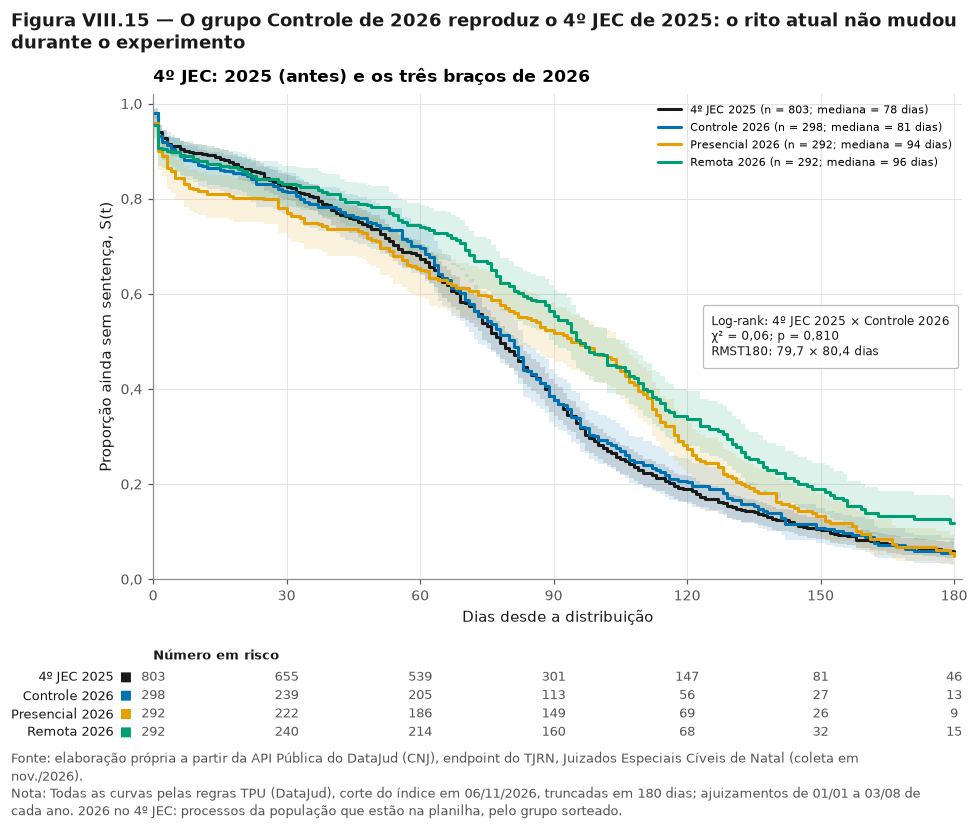

Série,n,RMST180 (dias),Sentenciados até 90 dias
4º JEC 2025,803,"79,7","62,3%"
Controle 2026,298,"80,4","62,4%"
Presencial 2026,292,"85,2","48,3%"
Remota 2026,292,"95,0","44,8%"


In [184]:
if DJ_POP4_OK:
    TRUNC = 180

    def dj_trunc(T, E, tau=TRUNC):
        T = np.asarray(T, float); E = np.asarray(E, int)
        return np.minimum(T, tau), np.where(T > tau, 0, E)

    _grp = dict(zip(dj['numero'], dj['grupo'].astype(str)))
    q25 = pop[pop['quarto'] & pop['janela'] & (pop['ano'] == 2025)]
    q26 = pop[pop['quarto'] & pop['janela'] & (pop['ano'] == 2026)].copy()
    q26['grupo'] = q26['numero'].map(_grp)
    q26s = q26[q26['grupo'].notna()]
    comp4 = pd.concat([pd.DataFrame({'T': q25['T'], 'E': q25['E'], 'serie': '4º JEC 2025'}),
                       pd.DataFrame({'T': q26s['T'], 'E': q26s['E'], 'serie': q26s['grupo'] + ' 2026'})], ignore_index=True)
    comp4['T'], comp4['E'] = dj_trunc(comp4['T'], comp4['E'])
    cores4 = {'4º JEC 2025': TINTA, 'Controle 2026': CORES_GRUPO['Controle'], 'Presencial 2026': CORES_GRUPO['Presencial'],
              'Remota 2026': CORES_GRUPO['Remota'], 'Outros 13 JECs 2025': TINTA, 'Outros 13 JECs 2026': CINZA}
    dois = DJ_POP_OK
    fig, axs = plt.subplots(1, 2 if dois else 1, figsize=(14, 6.4) if dois else (9, 6.4))
    axs = np.atleast_1d(axs)
    ORD4 = [k for k in ['4º JEC 2025', 'Controle 2026', 'Presencial 2026', 'Remota 2026'] if (comp4.serie == k).any()]
    plot_km(axs[0], comp4, tempo='T', evento='E', grupo='serie', ordem=ORD4,
            cores=cores4, passo=30, tmax=TRUNC, ic=True, censuras=False)
    a_ = comp4[comp4.serie.isin(['4º JEC 2025', 'Controle 2026'])]
    lr4 = logrank_test(a_.loc[a_.serie == '4º JEC 2025', 'T'], a_.loc[a_.serie == 'Controle 2026', 'T'],
                       a_.loc[a_.serie == '4º JEC 2025', 'E'], a_.loc[a_.serie == 'Controle 2026', 'E'])
    rm = {s_: dj_rmst(g_['T'].values.astype(int), g_['E'].values, TRUNC) for s_, g_ in comp4.groupby('serie')}
    anotar_teste(axs[0], texto_teste('Log-rank: 4º JEC 2025 × Controle 2026', f'χ² = {fmt_br(lr4.test_statistic, 2)}', lr4.p_value,
                                     f"RMST180: {fmt_br(rm['4º JEC 2025'], 1)} × {fmt_br(rm['Controle 2026'], 1)} dias"), loc='center right', tamanho=8)
    axs[0].set_title('4º JEC: 2025 (antes) e os três braços de 2026')
    tab_ad = pd.DataFrame([{'Série': k, 'n': int((comp4.serie == k).sum()), 'RMST180 (dias)': rm[k],
                            'Sentenciados até 90 dias': 1 - dj_km_grade(comp4.loc[comp4.serie == k, 'T'].values.astype(int),
                                                                         comp4.loc[comp4.serie == k, 'E'].values, 90)[90]}
                           for k in ORD4])
    if dois:
        o25 = pop[~pop['quarto'] & pop['janela'] & (pop['ano'] == 2025)]
        o26 = pop[~pop['quarto'] & pop['janela'] & (pop['ano'] == 2026)]
        compo = pd.concat([pd.DataFrame({'T': o25['T'], 'E': o25['E'], 'serie': 'Outros 13 JECs 2025'}),
                           pd.DataFrame({'T': o26['T'], 'E': o26['E'], 'serie': 'Outros 13 JECs 2026'})], ignore_index=True)
        compo['T'], compo['E'] = dj_trunc(compo['T'], compo['E'])
        plot_km(axs[1], compo, tempo='T', evento='E', grupo='serie', ordem=['Outros 13 JECs 2025', 'Outros 13 JECs 2026'], cores=cores4,
                passo=30, tmax=TRUNC, ic=True, censuras=False)
        lro = logrank_test(compo.loc[compo.serie.str.endswith('2025'), 'T'], compo.loc[compo.serie.str.endswith('2026'), 'T'],
                           compo.loc[compo.serie.str.endswith('2025'), 'E'], compo.loc[compo.serie.str.endswith('2026'), 'E'])
        rmo = {s_: dj_rmst(g_['T'].values.astype(int), g_['E'].values, TRUNC) for s_, g_ in compo.groupby('serie')}
        anotar_teste(axs[1], texto_teste('Log-rank: 2025 × 2026', f'χ² = {fmt_br(lro.test_statistic, 2)}', lro.p_value,
                                         f"RMST180: {fmt_br(rmo['Outros 13 JECs 2025'], 1)} × {fmt_br(rmo['Outros 13 JECs 2026'], 1)} dias"),
                     loc='center right', tamanho=8)
        axs[1].set_title('Outros 13 JECs cíveis de Natal: 2025 e 2026')
        tab_ad = pd.concat([tab_ad, pd.DataFrame([{'Série': k, 'n': int((compo.serie == k).sum()), 'RMST180 (dias)': rmo[k],
                                                   'Sentenciados até 90 dias': 1 - dj_km_grade(compo.loc[compo.serie == k, 'T'].values.astype(int),
                                                                                               compo.loc[compo.serie == k, 'E'].values, 90)[90]}
                                                  for k in ['Outros 13 JECs 2025', 'Outros 13 JECs 2026']])], ignore_index=True)
    for ax in axs:
        ax.legend(loc='upper right', fontsize=7.5)
    figura(fig, 'dj_antes_durante', ('O grupo Controle de 2026 reproduz o 4º JEC de 2025: o rito atual não mudou durante o experimento'
                                  if lr4.p_value >= 0.05 else 'O grupo Controle de 2026 difere do 4º JEC de 2025: a unidade mudou durante o experimento'),
       secao='8.6.5', fonte=FONTE_DJ_POP,
           nota=f'Todas as curvas pelas regras TPU (DataJud), corte do índice em {DJ_CORTE_POP:%d/%m/%Y}, truncadas em 180 dias; '
                'ajuizamentos de 01/01 a 03/08 de cada ano. 2026 no 4º JEC: processos da população que estão na planilha, pelo grupo sorteado.')
    tabela(tab_ad, 'dj_antes_durante', 'Antes × durante: RMST até 180 dias e proporção sentenciada até 90 dias (regras TPU)',
           secao='8.6.5', fonte=FONTE_DJ_POP, formatos={'Sentenciados até 90 dias': 'pct', 'RMST180 (dias)': 1, 'n': 'int'})

**Leitura.** Medido pelas mesmas regras, com o mesmo corte e o mesmo horizonte, o **grupo Controle de 2026 é indistinguível do 4º JEC de 2025**: medianas de 81 e 78 dias, RMST até 180 dias de 80,4 e 79,7 dias, 62,4% e 62,3% sentenciados até 90 dias (log-rank χ² = 0,06; p = 0,81). Já os dois braços com AC obrigatória ficam abaixo do patamar histórico da unidade: 48,3% (presencial) e 44,8% (remota) sentenciados até 90 dias, e RMST180 de 85,2 e 95,0 dias.

Três consequências:

1. **O Controle representa de fato o "rito atual"**. Uma ameaça discutida na seção 6.9 era que o experimento, ao ocupar a pauta com audiências obrigatórias e mobilizar cartório e juiz, mudasse a unidade inteira, e que o Controle de 2026 deixasse de representar o rito anterior (contaminação, efeito Hawthorne sobre o juiz-pesquisador). Os dados não mostram isso: o Controle de 2026 tramitou no mesmo ritmo do 4º JEC de 2025.
2. **O atraso dos grupos com AC é um efeito do rito sobre um patamar estável**, e não a combinação de um Controle "acelerado" com grupos tratados normais.
3. **A unidade como um todo ficou mais lenta em 2026**, porque dois terços dos processos foram sorteados para a AC obrigatória: é o custo de escala da política, que uma adoção geral transferiria a toda a unidade. É também o que o DiD agregado de 8.6.2 capta (queda do mérito no 4º JEC maior que em qualquer outro juizado).

**Limites.** É uma comparação antes × depois numa única unidade. Os dados agregados de 8.6.2 indicam que, nos outros 13 JECs, a proporção sentenciada também caiu de 2025 para 2026 (menos tempo de observação para os processos de 2026), mas sem os tempos dos outros juizados não é possível excluir, com horizonte fixo, uma mudança comum à capital. E é observacional: a semelhança Controle 2026 × 4º JEC 2025 é evidência a favor da validade do grupo de comparação, não uma prova.

### 8.6.6 O 4º JEC é típico entre os 14? (questão 2.10)

Em 2025, antes do experimento, as 14 unidades recebiam processos sorteados pelo mesmo distribuidor; diferenças entre elas refletem juiz, cartório e pauta. O gráfico ordena os juizados pelo P90 de 2025 e mostra o de 2026 ao lado. **Teste:** qui-quadrado de homogeneidade da proporção sentenciada até 90 dias entre as 14 unidades em 2025 (todas as coortes de 2025 têm os 90 dias completos, de modo que a proporção simples não sofre censura, a não ser pela saída da unidade).

In [185]:
if DJ_POP_OK:
    p90 = wide['P90'].sort_values(2025)
    fig, ax = plt.subplots(figsize=(12, 5.2))
    xs = np.arange(len(p90))
    ax.bar(xs - 0.2, 100 * p90[2025], width=0.4, color=[COR_4JEC if u == '4º' else COR_OUTROS for u in p90.index], label='2025')
    ax.bar(xs + 0.2, 100 * p90[2026], width=0.4, color=[COR_4JEC if u == '4º' else COR_OUTROS for u in p90.index], alpha=0.45,
           hatch='//', edgecolor='white', label='2026')
    ax.set_xticks(xs, [f'{u} JEC' for u in p90.index], fontsize=8.5)
    ax.set_ylabel('Sentenciados até 90 dias (%)')
    ax.set_title('P90 por juizado: barras cheias = 2025; hachuradas = 2026; preto = 4º JEC')
    ax.grid(axis='x', visible=False)
    j25 = jan[jan['ano'] == 2025]
    ct = pd.crosstab(j25['jec'], (j25['E'] == 1) & (j25['T'] <= H_DJ))
    chi_h, p_h, gl_h, _ = stats.chi2_contingency(ct.values)
    pos4 = int((p90[2025] > p90.loc['4º', 2025]).sum()) + 1
    anotar_teste(ax, texto_teste('Qui-quadrado de homogeneidade (2025)', f'χ² = {fmt_br(chi_h, 1)} ({gl_h} gl)', p_h,
                                 f'4º JEC: {pos4}º maior P90 de 14 em 2025'), loc='upper left')
    legenda_abaixo(ax, ncol=2)
    figura(fig, 'dj_tipicidade', 'O 4º JEC entre os 14 Juizados Cíveis de Natal, antes e durante o experimento', secao='8.6.6',
           fonte=FONTE_DJ_POP, nota='P90 = 1 − Ŝ(90) de Kaplan-Meier (saída = censura). Ajuizamentos de 01/01 a 03/08 de cada ano.')
    tip = (up.assign(**{c: up[c] * DJ_DESF[c][2] for c in DJ_DESF})
           .pivot(index='jec', columns='ano', values=['n'] + list(DJ_DESF)))
    tip.columns = [f'{a} {b}' for a, b in tip.columns]
    tabela(tip.loc[p90.index].rename_axis('Juizado'), 'dj_tipicidade', 'Desfechos com horizonte de 90 dias por juizado, 2025 e 2026',
           secao='8.6.6', fonte=FONTE_DJ_POP, casas=1, formatos={'n 2025': 'int', 'n 2026': 'int'},
           destaque=lambda df: df.index == '4º', nota='P90, SM90 e HOM90 em %; RMST90 em dias.')

*Não executada nesta versão (ver 8.6.1): a tipicidade com horizonte fixo exige os tempos dos outros 13 JECs. A comparação possível, pelo perfil de desfechos em 2025, está em 8.6.2: o 4º JEC já era, antes do experimento, o 2º juizado com mais extinções sem mérito e menos julgamentos de mérito.*

### 8.6.7 Os "106,8 dias" do período anterior

O projeto do experimento cita, como duração média do 4º JEC antes da intervenção, **106,8 dias** (painel GPS-Jus, consulta de 17/12/2025), e a comparação do pesquisador opõe esse número à média de ~75 dias dos sentenciados de 2026. O GPS-Jus mede a duração média **dos processos que receberam sentença em um período**, olhando para trás (do ajuizamento à sentença). A célula reproduz essa medida com o DataJud: 4º JEC, processos com o 1º julgamento entre 17/12/2024 e 17/12/2025 (12 meses), média de dias desde a entrada; e a **mesma medida** para os sentenciados de 2026 até 07/10/2026. Essa média "dos sentenciados" depende de quanto tempo a janela olha para trás: numa janela que começa com o experimento, só entram processos novos, e a média cai por construção (seção 2.5, artefato da entrada escalonada). Por isso a comparação justa é a de horizonte fixo (8.6.4–8.6.5).

Medida,Média (dias),Mediana (dias),n
"GPS-Jus (citado no projeto, 17/12/2025)","106,8",–,–
DataJud: sentenciados de 17/12/2024 a 17/12/2025,"93,0","82,0",1.390
DataJud: sentenciados de 01/01 a 07/10/2026,"93,5","86,0",948
Planilha: sentenciados até 07/10/2026 (média ingênua),"71,0","73,5",708


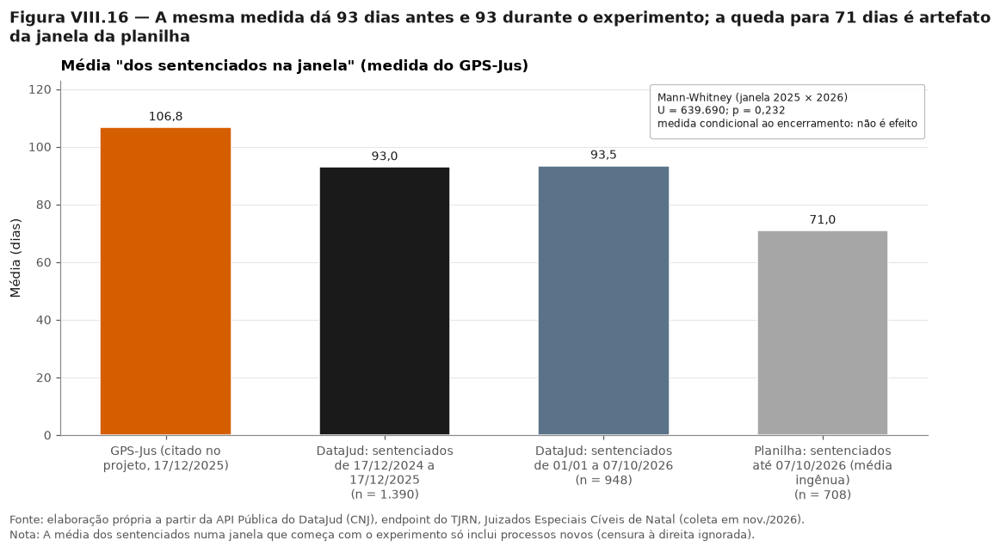

In [186]:
if DJ_POP4_OK:
    tem_2024 = DJ_4JEC_2024_2025
    q4 = pop[pop['quarto'] & (pop['E'] == 1)].copy()
    q4['dt_s'] = q4['entrada'].dt.normalize() + pd.to_timedelta(q4['T'], unit='D')
    jan1 = q4[(q4['dt_s'] > '2024-12-17') & (q4['dt_s'] <= '2025-12-17')]
    if not tem_2024:
        jan1 = jan1[jan1['ano'] >= 2025]          # 2024 incompleto não entra (subconjunto não aleatório)
    jan2 = q4[(q4['dt_s'] >= '2026-01-01') & (q4['dt_s'] <= DATA_CORTE)]
    sent_pl = dados[dados['evento'].astype(int) == 1]['tempo'].astype(float)
    g106 = pd.DataFrame([
        ['GPS-Jus (citado no projeto, 17/12/2025)', 106.8, np.nan, np.nan],
        ['DataJud: sentenciados de 17/12/2024 a 17/12/2025' + ('' if tem_2024 else ' (só ajuizados em 2025: limite inferior)'),
         jan1['T'].mean(), jan1['T'].median(), len(jan1)],
        ['DataJud: sentenciados de 01/01 a 07/10/2026', jan2['T'].mean(), jan2['T'].median(), len(jan2)],
        ['Planilha: sentenciados até 07/10/2026 (média ingênua)', sent_pl.mean(), sent_pl.median(), len(sent_pl)],
    ], columns=['Medida', 'Média (dias)', 'Mediana (dias)', 'n'])
    tabela(g106, 'dj_106', 'A "média anterior" de 106,8 dias e a mesma medida calculada no DataJud', secao='8.6.7', fonte=FONTE_DJ_POP,
           casas=1, formatos={'n': 'int'},
           nota='Média dos dias da entrada no 4º JEC ao 1º julgamento, entre os sentenciados na janela. '
                + ('Inclui ajuizamentos de 2024 e 2025; processos ajuizados antes de 2024 e sentenciados na 1ª janela não foram coletados.'
                   if tem_2024 else 'ATENÇÃO: a coleta de 2024 do 4º JEC não terminou (API sobrecarregada); a 1ª janela inclui só os ajuizados em 2025, '
                   'e a sua média é um limite inferior da medida do GPS-Jus.'))
    fig, ax = plt.subplots(figsize=(10, 5))
    _cats = [quebra(t, 22) + (f'\n(n = {fmt_int(n)})' if pd.notna(n) else '') for t, n in zip(g106['Medida'], g106['n'])]
    barras_verticais(ax, _cats, g106['Média (dias)'], cores=[DESTAQUE, TINTA, '#5B7389', CINZA], ylabel='Média (dias)', quebrar=40)
    ax.set_title('Média "dos sentenciados na janela" (medida do GPS-Jus)')
    u_ = stats.mannwhitneyu(jan1['T'], jan2['T'])
    anotar_teste(ax, texto_teste('Mann-Whitney (janela 2025 × 2026)', f'U = {fmt_br(u_.statistic, 0)}', u_.pvalue,
                                 'medida condicional ao encerramento: não é efeito'), loc='upper right', tamanho=8)
    figura(fig, 'dj_106', f"A mesma medida dá {fmt_br(jan1['T'].mean(), 0)} dias antes e {fmt_br(jan2['T'].mean(), 0)} durante o experimento; "
       f"a queda para {fmt_br(sent_pl.mean(), 0)} dias é artefato da janela da planilha",
           secao='8.6.7', fonte=FONTE_DJ_POP, nota='A média dos sentenciados numa janela que começa com o experimento só inclui '
           'processos novos (censura à direita ignorada).')

**Leitura.** A medida do GPS-Jus (duração média dos processos sentenciados nos 12 meses anteriores, do ajuizamento à sentença) foi recalculada com todos os processos do 4º JEC ajuizados a partir de 2024: **93,0 dias** (mediana de 82) para os sentenciados entre 17/12/2024 e 17/12/2025. Fica abaixo dos 106,8 dias citados no projeto, o que é esperado: os processos ajuizados **antes de 2024** e sentenciados naquela janela (os mais antigos e demorados) não foram coletados, e o painel do CNJ pode usar outra definição de evento (baixa, e não a 1ª sentença). Os 93 dias são, portanto, um limite inferior da medida citada.

O ponto central é a comparação feita pelo pesquisador (106,8 → ~75 dias). A **mesma medida**, calculada no DataJud para todos os processos do 4º JEC sentenciados de 01/01 a 07/10/2026, dá **93,5 dias**, praticamente igual à de 2025 (Mann-Whitney p = 0,23), e não os 71 dias da média ingênua da planilha. A diferença vem da janela: a planilha só contém processos distribuídos a partir de 01/01/2026, de modo que até 07/10 nenhum deles podia ter mais de 279 dias, e os ainda pendentes (os mais demorados) ficam fora da média. A "queda" é, portanto, **um artefato da janela de observação** (seção 2.5; E14, E30), e não uma aceleração da unidade; a comparação correta é a de horizonte fixo (8.6.5), que mostra o Controle de 2026 igual ao 4º JEC de 2025 e os grupos com AC mais lentos.

## 8.7 Síntese da Parte VIII

| Pergunta | Resposta | Seção |
|---|---|---|
| A planilha confere com o DataJud? | Sim. Vínculo de 98,7% (igual nos grupos); datas de distribuição e sentença coincidem em 99,9% e 97,6–99,1%; tipo de desfecho κ = 0,971, AC realizada κ = 0,983, acordo κ = 0,993. Divergências: acordo homologado depois da sentença registrado como desfecho (11) e atraso de alimentação perto de 07/10 (13 processos "ativos" já encerrados) | 8.3 |
| As 135 sentenças em fim de semana são erro? | Não: 98,5% estão no mesmo dia no DataJud; são assinaturas eletrônicas feitas no sábado ou no domingo, quase sempre de manhã | 8.3.3 |
| O seguimento curto distorcia o resultado? | Não; era conservador. Até 06/11/2026, 81 censurados foram sentenciados (mais 8 já sentenciados antes de 07/10); o Controle encerrou mais dos seus pendentes. HR da AC remota 0,81 → 0,76; ΔRMST180 10,7 → 14,0 dias; log-rank p = 0,023 → 0,001 | 8.4 |
| O estudo pode ser refeito só com movimentos? | Sim: κ = 0,97 para o evento, 97,9% dos tempos com diferença ≤ 1 dia, mesmos HR e ΔRMST; critérios pré-fixados atendidos | 8.5 |
| O experimento mudou a unidade? | O Controle não: Controle 2026 = 4º JEC 2025 (RMST180 80,4 × 79,7 dias; p = 0,81). A unidade como um todo, sim: os braços com AC ficaram mais lentos e, entre os 14 JECs, a queda da sentença de mérito de 2025 para 2026 foi a maior no 4º JEC (DiD −11,8 p.p.; permutação p = 0,071, o mínimo possível) | 8.6.2, 8.6.5 |
| O 4º JEC é típico entre os 14? | Não: já em 2025 era o 2º com mais extinções sem mérito (36% × 26%) e menos mérito (61% × 68%). Distribuição de entrada igual entre os 14 | 8.6.2 |
| Comparação com horizonte fixo × outros 13 JECs | Parcial: a API não permitiu coletar os processos dos outros 13 JECs; código retomável a partir do cache | 8.6.1, 8.6.3, 8.6.4, 8.6.6 |
| Os 106,8 dias | Limite inferior de 93 dias no DataJud (sem os ajuizados antes de 2024); a mesma medida em 2026 dá 93,5 dias: a queda para ~75 é artefato da janela da planilha | 8.6.7 |

**Em síntese**, o DataJud **valida** a planilha, **confirma e reforça** o achado principal (a AC obrigatória, sobretudo a remota, atrasa a sentença; com mais seguimento, o efeito cresce) e **afasta** duas ameaças levantadas nas Partes I e VI: as datas de fim de semana não são erro, e o grupo Controle não foi alterado pelo experimento. Mostra também que o 4º JEC é uma unidade atípica em Natal, o que limita a validade externa (questão 2.10). As comparações entre anos e entre unidades são observacionais (e a comparação com os outros 13 JECs ficou parcial por indisponibilidade da API); nenhuma delas muda o estatuto da análise principal, que continua sendo a comparação entre grupos sorteados (Parte IV).

---

# APÊNDICE — CATÁLOGO DE FIGURAS E TABELAS

O apêndice reúne (A.1) um **painel-resumo** do estudo, com seis gráficos que condensam os achados principais, cada um com o seu achado no título; e (A.2) o **catálogo** de todas as figuras e tabelas do notebook, com número, título, seção e arquivo. As tabelas são exportadas também numa pasta de trabalho única, `tab/ed2_tabelas.xlsx` (uma aba por tabela), e o catálogo em `tab/catalogo.csv`.

## A.1 Painel-resumo

O painel é estático e deve ser lido junto com as partes em que cada resultado é demonstrado:

- **(a)** e **(f)**: o sorteio produziu grupos de tamanho quase igual, mas a entrada foi escalonada e a composição mensal variou (por isso o mês é covariável nas Partes IV e V);
- **(b)**: a composição dos desfechos por grupo (Parte III, seção 3.2);
- **(c)**: a curva de Kaplan-Meier, a forma correta de comparar o tempo com censura (Parte IV);
- **(d)**: a proporção de processos encerrados por homologação de acordo até a data de corte, com IC 95% de Wilson (Parte III, seção 3.3);
- **(e)**: o tempo até a sentença de mérito entre os que a tiveram — estatística **condicional**, enviesada para tempos curtos, mostrada só como descrição.

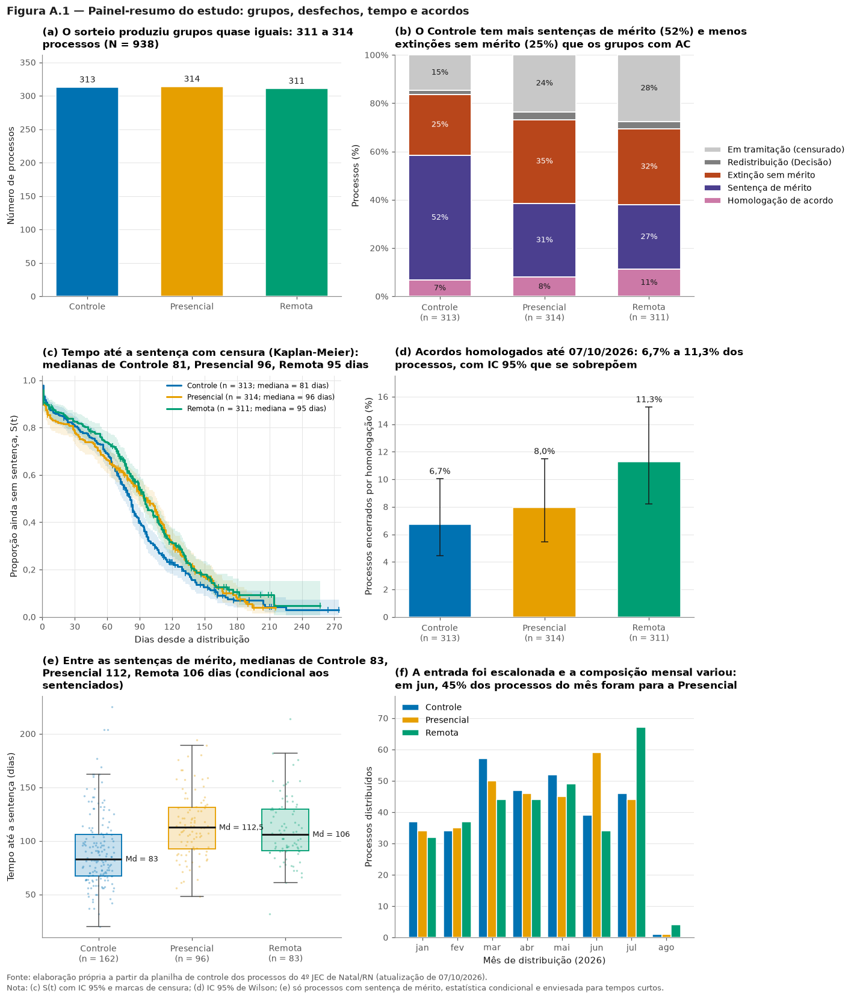

In [187]:
if 'dados' not in globals():
    dados = pd.read_pickle(PROC / 'ed2_tidy.pkl')
from statsmodels.stats.proportion import proportion_confint

ap = dados.copy()
ap['grupo'] = ap['grupo'].cat.set_categories(ORDEM_GRUPO)
n_g = ap['grupo'].value_counts().reindex(ORDEM_GRUPO)
mix = pd.crosstab(ap['grupo'], ap['tipo_desfecho'], normalize='index').reindex(index=ORDEM_GRUPO, columns=ORDEM_DESFECHO).fillna(0)
homol = ap.groupby('grupo', observed=False)['causa'].apply(lambda s: int(s.eq(1).sum())).reindex(ORDEM_GRUPO)
ic_h = np.array([proportion_confint(homol[g], n_g[g], method='wilson') for g in ORDEM_GRUPO])
p_h = homol / n_g
merito = ap[ap['tipo_desfecho'].eq('Mérito')]
md_merito = merito.groupby('grupo', observed=False)['tempo'].median().reindex(ORDEM_GRUPO).astype(float)
mes = pd.crosstab(ap['mes_distribuicao'], ap['grupo']).reindex(columns=ORDEM_GRUPO)

fig, ax = plt.subplots(3, 2, figsize=(13, 14.5))
ax = ax.ravel()

# (a) tamanho dos grupos
barras_verticais(ax[0], ORDEM_GRUPO, n_g.to_numpy(), ylabel=ROTULOS['n'], fmt=fmt_int)
ax[0].set_title(quebra(f'(a) O sorteio produziu grupos quase iguais: {fmt_br(n_g.min(), 0)} a {fmt_br(n_g.max(), 0)} '
                       f'processos (N = {fmt_br(n_g.sum(), 0)})', 60))

# (b) composição dos desfechos
barras_empilhadas(ax[1], mix, ns=n_g.to_numpy(), rotulos_serie=ROTULO_DESFECHO, rotulo_min=0.05)
ax[1].set_title(quebra(f'(b) O Controle tem mais sentenças de mérito ({pct_br(mix.loc["Controle", "Mérito"], 0)}) e menos '
                       f'extinções sem mérito ({pct_br(mix.loc["Controle", "Sem mérito"], 0)}) que os grupos com AC', 60))

# (c) Kaplan-Meier
kms_painel = plot_km(ax[2], ap, tabela_risco=False, passo=30)
ax[2].legend(loc='upper right', fontsize=8)
_med = {g: kms_painel[g].median_survival_time_ for g in ORDEM_GRUPO}
ax[2].set_title(quebra('(c) Tempo até a sentença com censura (Kaplan-Meier): medianas de '
                       + ', '.join(f'{g} {fmt_br(_med[g], 0)}' for g in ORDEM_GRUPO) + ' dias', 60))

# (d) homologações de acordo com IC
barras_verticais(ax[3], ORDEM_GRUPO, 100 * p_h.to_numpy(), erro=(100 * ic_h[:, 0], 100 * ic_h[:, 1]),
                 fmt=lambda v: fmt_br(v, 1) + '%', ylabel='Processos encerrados por homologação (%)', ns=n_g.to_numpy())
_sobrepostos = ic_h[:, 0].max() <= ic_h[:, 1].min()
ax[3].set_title(quebra(f'(d) Acordos homologados até 07/10/2026: {fmt_br(100 * p_h.min(), 1)}% a '
                       f'{fmt_br(100 * p_h.max(), 1)}% dos processos'
                       + (', com IC 95% que se sobrepõem' if _sobrepostos else ''), 60))

# (e) tempo até o mérito (condicional)
boxplot_grupos(ax[4], merito, 'tempo', ylabel=ROTULOS['tempo_sentenca'], tam_ponto=5)
ax[4].set_title(quebra('(e) Entre as sentenças de mérito, medianas de ' +
                       ', '.join(f'{g} {fmt_br(md_merito[g], 0)}' for g in ORDEM_GRUPO) +
                       ' dias (condicional aos sentenciados)', 60))

# (f) entradas por mês
mes.index = [str(m) for m in mes.index]
barras_agrupadas(ax[5], mes, ylabel='Processos distribuídos', xlabel=ROTULOS['mes_distribuicao'])
_pico = mes.div(mes.sum(axis=1), axis=0)[mes.sum(axis=1) >= 30]     # meses com poucos processos não definem o achado
_mx = _pico.stack().idxmax()
ax[5].set_title(quebra(f'(f) A entrada foi escalonada e a composição mensal variou: em {_mx[0]}, '
                       f'{pct_br(_pico.loc[_mx], 0)} dos processos do mês foram para a {_mx[1]}', 60))
fig.subplots_adjust(hspace=0.55, wspace=0.45)
figura(fig, 'apx_painel', 'Painel-resumo do estudo: grupos, desfechos, tempo e acordos', secao='99',
       nota='(c) S(t) com IC 95% e marcas de censura; (d) IC 95% de Wilson; (e) só processos com sentença de mérito, '
            'estatística condicional e enviesada para tempos curtos.')

## A.2 Catálogo de figuras e tabelas

O catálogo lista, na ordem de aparição, todas as figuras e tabelas numeradas pela camada de visualização (seção 1.2). Cada figura está em `fig/<id>.png` (e `.svg`); cada tabela, em `tab/<id>.csv` e numa aba da pasta de trabalho `tab/ed2_tabelas.xlsx`.

In [188]:
_ordem_parte = {p: i for i, p in enumerate(['I', 'II', 'III', 'IV', 'V', 'VI', 'VII', 'VIII', 'A'])}


def _chave_catalogo(r):
    parte, num = r['Número'].rsplit('.', 1)
    return (0 if r['Tipo'] == 'Figura' else 1, _ordem_parte.get(parte, 99), int(num))


catalogo = pd.DataFrame(sorted(CATALOGO.values(), key=_chave_catalogo))
catalogo['Número'] = catalogo['Tipo'] + ' ' + catalogo['Número']
catalogo_exp = catalogo[['Tipo', 'Número', 'Título', 'Seção', 'Arquivo', 'id']]
catalogo_exp.to_csv(TAB / 'catalogo.csv', sep=';', encoding='utf-8-sig', index=False)
resumo_cat = catalogo.assign(Parte=catalogo['Número'].str.split(' ').str[1].str.rsplit('.', n=1).str[0]) \
    .pivot_table(index='Parte', columns='Tipo', values='id', aggfunc='count', fill_value=0) \
    .reindex([p for p in _ordem_parte if p in set(catalogo['Número'].str.split(' ').str[1].str.rsplit('.', n=1).str[0])])
print(f"{(catalogo['Tipo'] == 'Figura').sum()} figuras e {(catalogo['Tipo'] == 'Tabela').sum()} tabelas catalogadas.")
tabela(resumo_cat.rename_axis('Parte'), 'apx_contagem', 'Número de figuras e tabelas por parte do notebook', secao='99',
       exportar=False)
tabela(catalogo[catalogo['Tipo'] == 'Figura'][['Número', 'Título', 'Seção', 'Arquivo']], 'apx_catalogo_figuras',
       'Catálogo de figuras', secao='99', exportar=False, formatos={'Seção': 'texto'})
tabela(catalogo[catalogo['Tipo'] == 'Tabela'][['Número', 'Título', 'Seção', 'Arquivo']], 'apx_catalogo_tabelas',
       'Catálogo de tabelas', secao='99', exportar=False, formatos={'Seção': 'texto'})

139 figuras e 180 tabelas catalogadas.


Parte,Figura,Tabela
I,2,34
II,32,30
III,24,33
IV,31,33
V,27,19
VI,4,12
VII,2,3
VIII,16,16
A,1,0


Número,Título,Seção,Arquivo
Figura I.1,Paletas do notebook: cada cor identifica uma única entidade,1.2.1,fig/cur_paletas.png
Figura I.2,"As ausências formam blocos por etapa: ""**"" marca o que não se aplica e NaN o que ainda não ocorreu",1.7.1,fig/cur_mapa_ausencias.png
Figura II.1,"As ""médias"" divulgadas dependem da data de corte: medem quanto se observou, não a duração",2.1.2,fig/exp_medias_corte.png
Figura II.2,Entradas por mês e grupo: os grupos não entram no mesmo ritmo ao longo do ano,2.1.3,fig/exp_entradas_mes.png
Figura II.3,"Quanto mais tardia a entrada, maior a fração ainda censurada em 07/10/2026",2.1.3,fig/exp_situacao_mes.png
Figura II.4,Trajetórias individuais: a data de corte interrompe os processos de entrada tardia,2.1.4,fig/exp_trajetorias.png
Figura II.5,Variáveis do desenho: grupos de tamanho quase igual; entradas desiguais no calendário,2.2.1,fig/exp_freq_desenho.png
Figura II.6,Pareto do desfecho e da técnica: o mérito lidera os desfechos; as técnicas ficam perto de 1/6 cada,2.2.1,fig/exp_pareto.png
Figura II.7,Variáveis binárias: o denominador muda de variável para variável (938 processos),2.2.1,fig/exp_binarias.png
Figura II.8,O tempo até a sentença é bimodal e a censura ocupa a cauda direita,2.2.3,fig/exp_tempo_graficos.png


Número,Título,Seção,Arquivo
Tabela I.1,Distância perceptual mínima entre as cores de cada paleta (ΔE OKLab × 100),1.2.1,tab/cur_cvd_resumo.csv
Tabela I.2,Abas da planilha e o papel de cada uma: só a aba Processos tem dados por processo,1.3.1,tab/cur_abas.csv
Tabela I.3,"As cinco primeiras linhas da aba Processos, como lidas (dados brutos, sem tratamento)",1.3.2,tab/cur_bruto_amostra.csv
Tabela I.4,Colunas calculadas por fórmula (J a O): a duração dos ativos depende de TODAY(),1.4,tab/cur_formulas.csv
Tabela I.5,"Data em que TODAY() foi avaliado, reconstituída dos valores em cache",1.4,tab/cur_data_today.csv
Tabela I.6,"As colunas de duração repetem DURAÇÃO-PROC (mesma variável, E6)",1.4,tab/cur_duracoes_iguais.csv
Tabela I.7,"Perfil das colunas como lidas pelo pandas: dtype, tipos presentes e ausências",1.5,tab/cur_perfil_bruto.csv
Tabela I.8,Tipologia estatística das colunas da planilha e decisão de tratamento,1.6,tab/cur_tipologia.csv
Tabela I.9,Três formas de ausência por coluna digitada (linhas da planilha),1.7,tab/cur_ausencias.csv
Tabela I.10,"Padrões de ausência em cinco colunas, por status e grupo sorteado: as lacunas acompanham a etapa do processo",1.7.1,tab/cur_padroes_ausencia.csv


### A.2.1 Exportação das tabelas numa pasta de trabalho

Cada tabela exportada vira uma aba de `tab/ed2_tabelas.xlsx`, com o número da tabela no nome da aba (o Excel limita o nome a 31 caracteres) e o título na primeira linha. A primeira aba é o próprio catálogo.

In [189]:
import re as _re
_numero_de = {r['id']: r['Número'] for r in CATALOGO.values() if r['Tipo'] == 'Tabela'}
_titulo_de = {r['id']: r['Título'] for r in CATALOGO.values() if r['Tipo'] == 'Tabela'}
_usadas = set()
_abas = []
with pd.ExcelWriter(TAB / 'ed2_tabelas.xlsx', engine='openpyxl') as _xl:
    catalogo_exp.to_excel(_xl, sheet_name='Catálogo', index=False)
    for _id, _df in sorted(TABELAS_EXPORT.items(), key=lambda kv: _chave_catalogo({'Tipo': 'Tabela', 'Número': _numero_de.get(kv[0], 'Z.0')})
                           if kv[0] in _numero_de else (2, 0, 0)):
        _nome = _re.sub(r'[\[\]:*?/\\]', '-', f"T{_numero_de.get(_id, '')} {_id}")[:31]
        _base, _k = _nome, 2
        while _nome.lower() in _usadas:
            _nome = f'{_base[:28]}~{_k}'; _k += 1
        _usadas.add(_nome.lower())
        _titulo = pd.DataFrame([[f"Tabela {_numero_de.get(_id, '?')} — {_titulo_de.get(_id, _id)}"]])
        _titulo.to_excel(_xl, sheet_name=_nome, index=False, header=False)
        _df.to_excel(_xl, sheet_name=_nome, index=False, startrow=2)
        _abas.append(_nome)
print(f'{len(_abas)} tabelas exportadas para {TAB / "ed2_tabelas.xlsx"} (+ aba Catálogo); catálogo em {TAB / "catalogo.csv"}')

178 tabelas exportadas para C:\Users\MPGO\AulaCleuler\EstudodeCaso2\tab\ed2_tabelas.xlsx (+ aba Catálogo); catálogo em C:\Users\MPGO\AulaCleuler\EstudodeCaso2\tab\catalogo.csv
